# Notebook 09 — MURA Agentic AI

## Agentic Decision Support for Musculoskeletal Radiographs

### Project Objective

Develop and evaluate a research-oriented Agentic AI system that integrates the canonical Model B (fine-tuned ResNet-18) with technical quality control, uncertainty assessment, explainability tools, and structured reporting.

The system analyzes de-identified MURA XR_WRIST radiographic studies and generates evidence-based recommendations for additional review.

This notebook is an agentic workflow prototype, not a clinically validated diagnostic system.

## Canonical Model B

The agent is intended to use the frozen Model B artifact bundle:

| Parameter | Configuration |
|---|---|
| Dataset | MURA v1.1 — XR_WRIST |
| Architecture | Fine-tuned ResNet-18 |
| Checkpoint | `best_resnet18_study_level.pt` |
| Input resolution | 224 × 224 |
| Preprocessing | Grayscale, black padding, bilinear resize, ImageNet normalization |
| Model output | One logit per radiographic image |
| Study aggregation | Mean image-level probability |
| Frozen decision threshold | 0.263567715883255 |
| Checkpoint selection metric | Internal validation AUROC |
| Selected checkpoint epoch | 9 |

The checkpoint was reconstructed from three parts and verified against its recorded SHA-256 checksum. Strict PyTorch weight loading, deterministic preprocessing, and synthetic end-to-end inference completed successfully.

The canonical Model B was integrated into the research workflow and evaluated through selected study-level tests. Three structured research artifacts were generated and validated, including two studies with authorized TTA and Grad-CAM execution and one study without optional tool execution.

These tests support the technical feasibility of the evaluated workflow but do not establish exhaustive integration validation or clinical readiness.

## Internal Validation Performance

The frozen operating policy was selected using internal patient-level validation data only.

| Metric | Result |
|---|---:|
| Sensitivity | 95.17% |
| Specificity | 58.29% |
| Precision | 59.26% |
| F1 score | 0.7304 |
| False-negative studies | 13 |
| False-positive studies | 176 |

The official MURA validation dataset was not used to select the operating threshold.

Previously recorded official-validation results in this notebook belong to an earlier model configuration until their provenance is independently confirmed. They must not be presented as verified performance of the canonical Model B.

## Scientific Motivation

Study-level aggregation may obscure disagreement between individual radiographic views. A study may contain images with different abnormality probabilities, while the final study-level decision is based on their mean.

This motivates systematic investigation of cross-view disagreement, prediction uncertainty, image quality, and the need for additional human review.

## Agent Objectives

The proposed agent will:

1. Validate technical image quality and anatomical scope.
2. Obtain predictions from the frozen classifier.
3. Examine image-level and study-level prediction consistency.
4. Identify ambiguous or potentially unreliable results.
5. Select additional analytical tools when warranted.
6. Generate structured, auditable reports.
7. Recommend human-review workflows without independently making clinical diagnoses.

## Agent Architecture

**Input:** De-identified MURA XR_WRIST study containing one or more radiographs and available study metadata.

**Core tools:** Technical QC, anatomical scope validation, frozen model classification, and cross-view consistency assessment.

**Optional tools:** Test-time augmentation uncertainty analysis and Grad-CAM explainability.

**Output:** Structured classification evidence, quality and uncertainty findings, tool execution history, and a workflow recommendation.

The frozen classifier provides numerical predictions. The agent orchestrates analytical tools and reporting but must not modify model weights, recalibrate the threshold, or override blocking quality-control failures.

## Reproducibility and Safety

- Preserve the canonical Model B checkpoint, preprocessing configuration, and frozen operating policy.
- Use the fixed decision threshold of `0.263567715883255` without recalibration during agent evaluation.
- Maintain separation between deterministic classification and LLM-generated explanations.
- Apply deterministic quality-control and tool-authorization rules before optional research tools are executed.
- Restrict the CrewAI explanation agent to authorized, read-only research tools.
- Preserve the original model predictions and workflow decisions throughout agent execution.
- Record tool execution status, research explanations, and relevant limitations in structured research artifacts.
- Validate research artifacts against a versioned Pydantic schema.
- Maintain research-only restrictions and mandatory human review.
- Avoid additional model training, checkpoint selection, or threshold optimization using the official validation dataset.
- An offline LLM call-budget test verified that the configured three-call reservation limit is enforced and that a fourth reservation is blocked, without invoking Gemini or executing agents.

## Research Workflow Validation

Selected study-level integration tests were completed using the frozen Model B and the deterministic research workflow.

Three structured research artifacts were generated and validated:

| Study ID | Model B prediction | Optional research tools | Policy action |
|---|---|---|---|
| `MURA_WRIST_RANDOM_001` | ABNORMAL | TTA and Grad-CAM executed successfully | `priority_human_review` |
| `MURA_WRIST_RANDOM_002` | ABNORMAL | TTA and Grad-CAM executed successfully | `priority_human_review` |
| `MURA_WRIST_NO_TOOLS_001` | NORMAL | Not executed | `routine_workflow` |

All three artifacts passed the selected schema and consistency checks and were verified as present in the designated Google Drive research-artifact directory.

These results demonstrate the feasibility of the tested research workflow. They do not establish exhaustive system validation, calibrated uncertainty, validated lesion localization, or clinical deployment readiness.

## Research Limitations

- The agentic workflow is a research prototype and has not been clinically validated.
- Internal validation performance must not be interpreted as independently verified official-validation performance.
- Anatomical scope assessment relies on study metadata rather than independently validated anatomical image recognition.
- TTA variability does not represent calibrated diagnostic uncertainty.
- Grad-CAM attribution maps do not provide validated fracture localization.
- LLM-generated explanations require independent interpretation and cannot replace expert review.
- Successful tests on selected studies do not establish generalization to all MURA studies or clinical environments.

## Current Status

The canonical Model B has been integrated into the MURA Agentic AI research workflow, combining frozen study-level predictions, deterministic policy decisions, authorized research tools, and CrewAI-based explanations.

The notebook completed its end-to-end research workflow execution successfully.

Three structured research artifacts were generated and validated, including two abnormal studies with successful TTA and Grad-CAM execution and one normal study without optional tool execution.

The final artifact validation steps (81, 82A, and 82) passed, confirming schema compliance, consistency of frozen classification and policy decisions, and the presence of all three research artifacts in Google Drive.

The notebook concludes at Step 89O, which is retained as part of the final notebook.

The system remains a research prototype, with mandatory human review. Clinical validation and independent verification of canonical Model B performance on the official validation dataset have not been established.

**Status: END-TO-END EXECUTION COMPLETED — THREE RESEARCH ARTIFACTS VALIDATED — RESEARCH USE ONLY.**



## Agent Environment Initialization

### Objective

Initialize the Agentic AI development environment and verify access to the canonical frozen Model B (fine-tuned ResNet-18), its operating policy, and the available validation artifacts.

### Project Organization

The agent development environment uses a dedicated project directory

`DATA/MURA_AGENTIC_AI/`

This directory will contain:

- Agent configuration files.
- Tool definitions and outputs.
- Agent execution logs.
- Structured reports.
- Evaluation scenarios.
- Agent-versus-rule-based comparison results.

The canonical Model B artifacts are stored separately in:

`DATA/MODEL_B_FINE_TUNING/`

### Model Integrity

The agent will use the previously selected and verified canonical Model B checkpoint:

`best_resnet18_study_level.pt`

The frozen operating policy is defined in:

`frozen_primary_operating_policy.json`

The model uses:

- Input resolution: 224 × 224 pixels.
- Preprocessing: grayscale decoding, aspect-preserving black padding, bilinear resizing, and ImageNet normalization.
- Image-level output: one logit per radiograph.
- Study-level aggregation: mean of image-level probabilities.
- Frozen classification threshold: `0.263567715883255`.

The checkpoint integrity, model weight loading, preprocessing functionality, and synthetic inference have been verified.

No additional model training, checkpoint selection, or threshold optimization will be performed.

The official validation data will not be used for model or threshold selection.

### Initialization Outcome

The canonical frozen Model B checkpoint, preprocessing configuration, and operating policy were verified during environment initialization.

The project environment was prepared to support deterministic workflow execution, optional research tools, CrewAI-based explanations, and structured research reporting.

Subsequent integration tests incorporated the frozen Model B into the agentic research workflow and produced three validated research artifacts.

The initialization and selected integration tests support technical reproducibility within the evaluated environment but do not establish clinical validation or production readiness.

# Step 1 - Runtime and Google Drive Initialization



In [1]:
# NOTEBOOK 09 — STEP 1
# Runtime and Google Drive initialization

from pathlib import Path
import sys
import importlib.util

from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Final Project DS23/"
    "Agentic AI-Assisted Detection of Musculoskeletal "
    "Abnormalities in Emergency X-rays"
)

DATA_DIR = PROJECT_ROOT / "DATA"
MODEL_DIR = DATA_DIR / "MODEL_B_FINE_TUNING"
AGENT_DIR = DATA_DIR / "MURA_AGENTIC_AI"

AGENT_DIR = DATA_DIR / "MURA_AGENTIC_AI"

# Create Agent directory if it does not exist
AGENT_DIR.mkdir(parents=True, exist_ok=True)

assert AGENT_DIR.is_dir(), (
    f"Failed to create Agent directory: {AGENT_DIR}"
)

print("Agent directory created or verified:", AGENT_DIR)
# Existing agent outputs
VALIDATION_DIR = DATA_DIR / "MURA_OFFICIAL_VALIDATION"
TOOLS_DIR = AGENT_DIR / "tools"
REPORT_DIR = AGENT_DIR / "reports"

# Canonical Model B operating threshold
SELECTED_THRESHOLD = 0.263567715883255

required_paths = {
    "Project directory": PROJECT_ROOT,
    "DATA directory": DATA_DIR,
    "Model B directory": MODEL_DIR,
    "Agent directory": AGENT_DIR,
}

print("NOTEBOOK 09 — STEP 1")
print("-" * 60)

for name, path in required_paths.items():
    status = "PASS" if path.is_dir() else "MISSING"
    print(f"{name:32s}: {status}")
print(
    "\nAgent directory:",
    "EXISTS" if AGENT_DIR.is_dir() else "NOT CREATED YET"
)
print("\nPython version:", sys.version.split()[0])
print("Selected threshold:", SELECTED_THRESHOLD)

if all(path.is_dir() for path in required_paths.values()):
    print("\nSTEP 1: PASSED")
else:
    print("\nSTEP 1: REVIEW REQUIRED")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Agent directory created or verified: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI
NOTEBOOK 09 — STEP 1
------------------------------------------------------------
Project directory               : PASS
DATA directory                  : PASS
Model B directory               : PASS
Agent directory                 : PASS

Agent directory: EXISTS

Python version: 3.13.18
Selected threshold: 0.263567715883255

STEP 1: PASSED


# Step 2 — Frozen Model Configuration

## Objective

Verify that the canonical Model B (fine-tuned ResNet-18) checkpoint, frozen operating threshold, and associated configuration and validation artifacts are accessible in the current Colab runtime.

## Reproducibility Requirements

- Load the frozen decision threshold from `frozen_primary_operating_policy.json`.
- Confirm that the loaded threshold matches the canonical value (`0.263567715883255`).
- Verify the existence of the canonical checkpoint: `best_resnet18_study_level.pt`.
- Verify access to `run_config.json`, `selection.json`, and the saved internal validation metrics.
- Load saved validation metrics without recalculating or modifying them.
- Keep internal validation results separate from historical official validation results until their provenance is confirmed.
- Initialize the PyTorch device (CPU or CUDA).

## Model Integrity

The checkpoint and operating policy are stored in:

`DATA/MODEL_B_FINE_TUNING/`

The checkpoint was previously reconstructed and verified using its SHA-256 checksum.

The frozen operating policy uses mean image-level probabilities for study-level classification. The threshold must be applied only after study-level aggregation.

## Expected Outcome

A verified runtime configuration with access to the canonical Model B checkpoint, frozen threshold, and associated metadata.

This step does not run model inference, modify model weights, retrain the classifier, optimize the threshold, or overwrite saved files.

In [2]:

# NOTEBOOK 09 — STEP 2
# Frozen Model B configuration

import json
import torch

CHECKPOINT_PATH = MODEL_DIR / "best_resnet18_study_level.pt"

THRESHOLD_PATH = (
    MODEL_DIR / "frozen_primary_operating_policy.json"
)

VALIDATION_METRICS_PATH = (
    MODEL_DIR / "validation_metrics.json"
)

RUN_CONFIG_PATH = MODEL_DIR / "run_config.json"
SELECTION_PATH = MODEL_DIR / "selection.json"

required_files = {
    "Frozen Model B checkpoint": CHECKPOINT_PATH,
    "Frozen operating policy": THRESHOLD_PATH,
    "Internal validation metrics": VALIDATION_METRICS_PATH,
    "Training configuration": RUN_CONFIG_PATH,
    "Checkpoint selection": SELECTION_PATH,
}

print("NOTEBOOK 09 — STEP 2")
print("-" * 60)

for name, path in required_files.items():
    print(
        f"{name:32s}: "
        f"{'PASS' if path.is_file() else 'MISSING'}"
    )

assert all(p.is_file() for p in required_files.values()), (
    "One or more canonical Model B artifacts are missing."
)

with open(THRESHOLD_PATH, encoding="utf-8") as f:
    threshold_metrics = json.load(f)

with open(VALIDATION_METRICS_PATH, encoding="utf-8") as f:
    validation_metrics = json.load(f)

with open(RUN_CONFIG_PATH, encoding="utf-8") as f:
    run_config = json.load(f)

with open(SELECTION_PATH, encoding="utf-8") as f:
    selection_config = json.load(f)

saved_threshold = float(threshold_metrics["threshold"])

assert abs(saved_threshold - SELECTED_THRESHOLD) < 1e-12, (
    "Saved threshold differs from the frozen threshold."
)

assert threshold_metrics["study_aggregation"] == "mean_probability", (
    "Unexpected study aggregation policy."
)

assert threshold_metrics["source_split"] == "internal_validation", (
    "Threshold was not selected on internal validation."
)

SELECTED_THRESHOLD = saved_threshold

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDEVICE:", device)
print("Frozen threshold:", SELECTED_THRESHOLD)
print("Study aggregation:", threshold_metrics["study_aggregation"])
print("Threshold source:", threshold_metrics["source_split"])

print("\nINTERNAL VALIDATION — FROZEN OPERATING POLICY")
print("Sensitivity:", threshold_metrics["sensitivity"])
print("Specificity:", threshold_metrics["specificity"])
print("Precision:", threshold_metrics["precision"])
print("F1:", threshold_metrics["f1"])
print("False negatives:", threshold_metrics["false_negative"])
print("False positives:", threshold_metrics["false_positive"])

print("\nSTEP 2: PASSED")


NOTEBOOK 09 — STEP 2
------------------------------------------------------------
Frozen Model B checkpoint       : PASS
Frozen operating policy         : PASS
Internal validation metrics     : PASS
Training configuration          : PASS
Checkpoint selection            : PASS

DEVICE: cpu
Frozen threshold: 0.263567715883255
Study aggregation: mean_probability
Threshold source: internal_validation

INTERNAL VALIDATION — FROZEN OPERATING POLICY
Sensitivity: 0.9516728624535316
Specificity: 0.5829383886255924
Precision: 0.5925925925925926
F1: 0.7303851640513552
False negatives: 13
False positives: 176

STEP 2: PASSED


In [3]:

# NOTEBOOK 09 — STEP 3
# Complete agent directory initialization

print("NOTEBOOK 09 — STEP 3")
print("-" * 60)

AGENT_SUBDIRS = {
    "config": AGENT_DIR / "config",
    "tools": TOOLS_DIR,
    "logs": AGENT_DIR / "logs",
    "reports": REPORT_DIR,
    "evaluation": AGENT_DIR / "evaluation",
    "figures": AGENT_DIR / "figures",
}

for directory in AGENT_SUBDIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

checks = {
    "Model B checkpoint": CHECKPOINT_PATH.is_file(),
    "Frozen threshold configuration": THRESHOLD_PATH.is_file(),
    "Internal validation metrics": VALIDATION_METRICS_PATH.is_file(),
    "Agent directories": all(
        path.is_dir() for path in AGENT_SUBDIRS.values()
    ),
    "Threshold consistency": (
        abs(
            float(threshold_metrics["threshold"])
            - float(SELECTED_THRESHOLD)
        ) < 1e-12
    ),
    "Study aggregation policy": (
        threshold_metrics["study_aggregation"] == "mean_probability"
    ),
}

for name, passed in checks.items():
    print(f"{name:34s}: {'PASS' if passed else 'FAIL'}")

print("\nChecks passed:", sum(checks.values()), "/", len(checks))

if all(checks.values()):
    print("\nSTEP 3: PASSED")
else:
    print("\nSTEP 3: REVIEW REQUIRED")


NOTEBOOK 09 — STEP 3
------------------------------------------------------------
Model B checkpoint                : PASS
Frozen threshold configuration    : PASS
Internal validation metrics       : PASS
Agent directories                 : PASS
Threshold consistency             : PASS
Study aggregation policy          : PASS

Checks passed: 6 / 6

STEP 3: PASSED


## Step 4 — Agent Specification and Tool Contracts

### Agent Identity

**Name:** MURA Wrist Decision-Support Agent

**Role:** AI research assistant for musculoskeletal radiograph analysis and workflow decision support.

**Agent framework:** CrewAI

**LLM provider:** Google Gemini

### Agent Objective

The agent integrates outputs from the canonical frozen Model B (fine-tuned ResNet-18) with technical quality control, anatomical scope validation, cross-view consistency, uncertainty assessment, and explainability tools.

The agent adaptively selects additional analytical tools when appropriate and generates structured, evidence-grounded, auditable reports.

The system is a research prototype and is not validated for clinical diagnosis or patient triage.

### Agent Inputs

- De-identified study identifier.
- One or more wrist radiographs belonging to the same study.
- Technical image metadata.
- Available anatomical study metadata.
- Canonical frozen Model B configuration and checkpoint.
- Frozen study-level classification threshold: `0.263567715883255`.
- Optional previously computed predictions, only when their provenance and compatibility with the canonical model are verified.

### Canonical Model B Configuration

| Parameter | Configuration |
|---|---|
| Dataset | MURA-v1.1 XR_WRIST |
| Classification task | Study-level NORMAL / ABNORMAL |
| Model architecture | Fine-tuned ResNet-18 |
| Checkpoint | `best_resnet18_study_level.pt` |
| Checkpoint directory | `DATA/MODEL_B_FINE_TUNING/` |
| Input resolution | 224 × 224 pixels |
| Image preprocessing | Grayscale decoding, aspect-preserving black padding, bilinear resizing, RGB replication, ImageNet normalization |
| Image-level model output | One logit per radiograph |
| Image-level probability | Sigmoid of model logit |
| Study-level aggregation | Mean of image-level abnormality probabilities |
| Frozen classification threshold | `0.263567715883255` |
| Threshold selection population | Internal patient-level validation |
| Operating policy | `frozen_primary_operating_policy.json` |

The final study-level classification is determined by comparing the mean image-level abnormality probability against the frozen threshold.

The model weights, preprocessing configuration, aggregation method, and decision threshold must remain unchanged throughout agent development and evaluation.

### Agent-Accessible Tools

| Tool | Description | Execution |
|---|---|---|
| `technical_qc` | Validates image readability, dimensions, brightness, contrast, and basic technical suitability | Mandatory |
| `anatomical_scope_validator` | Verifies whether available study metadata supports wrist-only classification; does not independently identify anatomy from image pixels | Mandatory |
| `classify_study` | Computes image-level probabilities using canonical Model B, aggregates them by mean probability, and applies the frozen study-level threshold | Mandatory after validation |
| `view_consistency` | Evaluates disagreement and variability among individual image-level abnormality probabilities | Mandatory after classification |
| `tta_uncertainty` | Evaluates prediction stability using predefined test-time transformations without changing model weights | Agent-selected |
| `gradcam_explainer` | Generates model activation visualizations for interpretability; not validated lesion localization | Agent-selected |
| `study_metadata` | Retrieves available de-identified study information | Agent-selected |
| `report_generator` | Produces structured reports using verified tool outputs and recorded evidence | Mandatory |

### Tool Execution Contracts

All tools must operate under predefined input, output, and error-handling requirements.

**Mandatory validation tools**

- Technical QC and anatomical scope validation must be completed before classification.
- Failed mandatory validation must prevent unsupported model inference.
- Missing, unreadable, or incompatible inputs must be reported explicitly.
- The agent cannot bypass deterministic validation failures.

**Classification tool**

- Must load the canonical frozen Model B checkpoint.
- Must use the verified 224 × 224 preprocessing pipeline.
- Must compute image-level abnormality probabilities.
- Must aggregate probabilities using the arithmetic mean at study level.
- Must apply the frozen threshold only after study-level aggregation.
- Must not modify model weights, preprocessing, or the operating threshold.

**Optional analytical tools**

- Must be selected based on predefined evidence or uncertainty criteria.
- Must operate without modifying the frozen classifier.
- Must return traceable outputs or explicit execution errors.
- Must not be treated as independent clinical diagnostic evidence.

**Reporting tool**

- Must use verified outputs from executed tools.
- Must distinguish model predictions from agent interpretations.
- Must document uncertainty, validation failures, and tool limitations.
- Must not invent findings or claim that an unexecuted tool was used.

### Agent Decision Process

1. Receive a de-identified radiographic study.
2. Verify that required inputs and image files are available.
3. Execute mandatory technical quality control.
4. Validate wrist anatomical scope using available study metadata.
5. If mandatory validation fails, return an unsupported-input or human-escalation outcome without forcing classification.
6. If validation passes, execute the canonical frozen Model B classifier.
7. Calculate image-level abnormality probabilities.
8. Aggregate image-level probabilities using the arithmetic mean.
9. Apply the frozen study-level classification threshold.
10. Evaluate cross-view consistency.
11. Identify ambiguous, contradictory, or potentially unreliable evidence.
12. Select additional analytical tools when justified.
13. Integrate verified tool outputs without overriding deterministic guardrails.
14. Generate a structured report and permitted workflow recommendation.
15. Record tool execution, agent decisions, errors, and final outputs for auditing.

### Allowed Workflow Recommendations

The agent may produce one of the following research workflow recommendations:

- **Routine workflow:** No additional concern identified by the research workflow.
- **Priority human review:** Potentially abnormal model findings or significant disagreement between radiographic views.
- **Human escalation:** Insufficient, contradictory, or unreliable evidence requiring additional human assessment.
- **Unsupported input:** The study does not satisfy mandatory input, technical quality, or anatomical scope requirements.

These recommendations are research-prototype outputs and must not be interpreted as validated clinical triage instructions.

### Safety Constraints

- The canonical Model B checkpoint must remain frozen.
- The classification threshold must remain fixed at `0.263567715883255`.
- The final study-level decision must use mean image-level abnormality probability.
- The frozen threshold must not be independently applied to individual views to determine the final study-level classification.
- The agent must not retrain, recalibrate, or modify the classifier.
- The agent cannot override deterministic guardrails.
- Failed mandatory validation must prevent unsupported classification.
- The agent must not generate a specific diagnosis or claim a confirmed fracture.
- Grad-CAM must not be presented as validated lesion localization.
- Optional tools must not be represented as executed unless they actually ran.
- Uncertainty and conflicting evidence must be documented.
- Final clinical interpretation remains the responsibility of the radiologist or responsible clinician.
- No identifiable patient information or live EHR access is included.
- Official MURA validation data must not be used for model selection, threshold optimization, or agent-policy tuning.

### Agent Evaluation

The Agentic AI workflow will be compared with a deterministic rule-based system.

Both approaches must use the same:

- Canonical frozen Model B classifier.
- Image preprocessing and study-level aggregation.
- Frozen classification threshold.
- Mandatory validation guardrails.
- Predefined evaluation scenarios.
- Permitted workflow recommendation categories.

The primary difference between the two approaches will be the agent's adaptive selection and orchestration of optional analytical tools.

Evaluation criteria include:

- Tool-selection accuracy.
- Recognition of conflicting evidence.
- Appropriate uncertainty assessment.
- Report groundedness and factual consistency.
- Correct human escalation.
- Compliance with mandatory guardrails.
- Safety violations.
- Unnecessary tool calls.
- Execution time and computational cost.
- Reproducibility and auditability.

The evaluation will investigate whether adaptive tool orchestration provides measurable benefits beyond a conventional frozen classifier and deterministic rule-based workflow.

### Reproducibility and Governance

- Model A and Model B artifacts must remain separate.
- The agent must use the verified canonical Model B artifact bundle.
- Internal validation metrics must remain distinguishable from official validation results.
- Historical official-validation results must not be attributed to the canonical Model B without provenance verification.
- Model weights and per-study predictions must not be committed to Git.
- Agent execution logs and evaluation results must be stored separately from canonical model artifacts.
- Changes to agent behavior must not alter the frozen classifier or its operating policy.

### Expected Outcome

A functional, reproducible, and auditable Agentic AI research prototype that integrates the canonical frozen Model B with deterministic quality-control guardrails, adaptive analytical tool selection, and structured reporting.

The project will evaluate whether CrewAI-based tool orchestration using Google Gemini provides measurable improvements in evidence handling, uncertainty assessment, and workflow recommendations compared with a deterministic rule-based approach.

**Development environment:** Google Colab  
**Dataset:** MURA-v1.1 XR_WRIST  
**Classifier:** Canonical Model B — Fine-tuned ResNet-18  
**Agent framework:** CrewAI  
**LLM provider:** Google Gemini  
**Agent working directory:** `DATA/MURA_AGENTIC_AI/`  
**Model artifact directory:** `DATA/MODEL_B_FINE_TUNING/`

In [4]:

# ============================================================
# NOTEBOOK 09 — STEP 4: AGENT SPECIFICATION
# ============================================================

import json
from datetime import datetime, timezone

print("NOTEBOOK 09 — STEP 4: AGENT SPECIFICATION")
print("-" * 60)

# ------------------------------------------------------------
# Canonical Model B configuration
# ------------------------------------------------------------

assert CHECKPOINT_PATH.is_file(), "Model B checkpoint missing."
assert THRESHOLD_PATH.is_file(), "Frozen operating policy missing."

assert abs(
    float(threshold_metrics["threshold"]) - float(SELECTED_THRESHOLD)
) < 1e-12, "Frozen threshold mismatch."

assert threshold_metrics["study_aggregation"] == "mean_probability"

# Read the selected epoch from the canonical checkpoint metadata
checkpoint_metadata = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

assert "epoch" in checkpoint_metadata, (
    "Checkpoint does not contain epoch metadata."
)

selected_epoch = int(checkpoint_metadata["epoch"])

print("Checkpoint epoch:", selected_epoch)

assert selected_epoch == 9, (
    f"Unexpected canonical checkpoint epoch: {selected_epoch}"
)

del checkpoint_metadata

agent_spec = {
    "agent_name": "MURA Wrist Decision-Support Agent",
    "version": "1.2",
    "framework": "CrewAI",
    "llm_provider": "Google Gemini",
    "purpose": (
        "Research-oriented orchestration of wrist radiograph "
        "classification, technical QC, anatomical scope validation, "
        "uncertainty analysis, explainability, and reporting."
    ),

    "model": {
        "model_id": "canonical_model_b",
        "architecture": "ResNet18",
        "checkpoint": str(CHECKPOINT_PATH),
        "selected_epoch": selected_epoch,
        "threshold": float(SELECTED_THRESHOLD),
        "threshold_source": "internal_validation",
        "operating_policy": str(THRESHOLD_PATH),
        "aggregation": "mean_probability",
        "input_resolution": [224, 224],
        "preprocessing": (
            "Grayscale decoding, aspect-preserving black padding, "
            "bilinear resizing, RGB replication, "
            "ImageNet normalization"
        ),
        "frozen": True,
        "task": "normal_vs_abnormal"
    },

    "tools": {
        "technical_qc": {
            "execution": "mandatory",
            "description": "Technical image validation"
        },
        "anatomical_scope_validator": {
            "execution": "mandatory",
            "description": (
                "Wrist anatomical scope verification using "
                "available study metadata; not image-based "
                "anatomical recognition"
            )
        },
        "classify_study": {
            "execution": "mandatory_after_validation",
            "description": (
                "Frozen canonical Model B inference using "
                "mean study-level probability and fixed threshold"
            )
        },
        "view_consistency": {
            "execution": "mandatory_after_classification",
            "description": "Cross-view probability comparison"
        },
        "tta_uncertainty": {
            "execution": "agent_selected",
            "description": "Exploratory prediction stability assessment"
        },
        "gradcam_explainer": {
            "execution": "agent_selected",
            "description": (
                "Model activation visualization; "
                "not validated lesion localization"
            )
        },
        "study_metadata": {
            "execution": "agent_selected",
            "description": "De-identified study information"
        },
        "report_generator": {
            "execution": "mandatory",
            "description": "Structured evidence-grounded report"
        }
    },

    "allowed_actions": [
        "routine_workflow",
        "priority_human_review",
        "human_escalation",
        "unsupported_input"
    ],

    "safety_constraints": {
        "model_weights_immutable": True,
        "threshold_immutable": True,
        "study_aggregation_immutable": True,
        "no_specific_diagnosis": True,
        "no_unverified_clinical_claims": True,
        "no_patient_identifiers": True,
        "human_final_decision": True,
        "mandatory_technical_qc": True,
        "mandatory_anatomical_scope_validation": True,
        "no_forced_classification_on_invalid_input": True,
        "no_agent_override_of_model_predictions": True,
        "gradcam_not_validated_localization": True,
        "tta_not_calibrated_clinical_confidence": True,
        "official_validation_not_used_for_selection": True
    },

    "evaluation": {
        "baseline": "deterministic_rule_based_policy",
        "metrics": [
            "tool_selection_accuracy",
            "view_disagreement_detection",
            "uncertainty_handling",
            "anatomical_scope_enforcement",
            "report_groundedness",
            "escalation_accuracy",
            "safety_violations",
            "unnecessary_tool_calls",
            "execution_time"
        ]
    }
}

# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------

config_path = (
    AGENT_SUBDIRS["config"] /
    "mura_agent_specification.json"
)

# Preserve the original creation timestamp when available.
if config_path.is_file():
    try:
        with open(config_path, "r", encoding="utf-8") as f:
            previous_spec = json.load(f)
        created_at = previous_spec.get("created_at")
    except (OSError, ValueError):
        created_at = None
else:
    created_at = None

agent_spec["created_at"] = (
    created_at
    or datetime.now(timezone.utc).isoformat()
)

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(agent_spec, f, indent=4)

# ------------------------------------------------------------
# Verify configuration
# ------------------------------------------------------------

with open(config_path, "r", encoding="utf-8") as f:
    loaded_spec = json.load(f)

assert loaded_spec["model"]["frozen"] is True
assert abs(
    loaded_spec["model"]["threshold"] - float(SELECTED_THRESHOLD)
) < 1e-12
assert loaded_spec["model"]["selected_epoch"] == 9
assert loaded_spec["model"]["aggregation"] == "mean_probability"
assert loaded_spec["model"]["input_resolution"] == [224, 224]
assert loaded_spec["model"]["checkpoint"] == str(CHECKPOINT_PATH)
assert len(loaded_spec["tools"]) == 8
assert len(loaded_spec["allowed_actions"]) == 4
assert "anatomical_scope_validator" in loaded_spec["tools"]

print("\nAGENT")
print("Name:", loaded_spec["agent_name"])
print("Version:", loaded_spec["version"])
print("Framework:", loaded_spec["framework"])
print("LLM provider:", loaded_spec["llm_provider"])

print("\nMODEL")
print("Architecture:", loaded_spec["model"]["architecture"])
print("Selected epoch:", loaded_spec["model"]["selected_epoch"])
print("Frozen:", loaded_spec["model"]["frozen"])
print("Threshold:", loaded_spec["model"]["threshold"])
print("Aggregation:", loaded_spec["model"]["aggregation"])
print("Input resolution:", loaded_spec["model"]["input_resolution"])

print("\nREGISTERED TOOLS")
for name, details in loaded_spec["tools"].items():
    print(f"- {name}: {details['execution']}")

print("\nCONFIGURATION SAVED")
print(config_path)

print("\nSTEP 4: PASSED")


NOTEBOOK 09 — STEP 4: AGENT SPECIFICATION
------------------------------------------------------------
Checkpoint epoch: 9

AGENT
Name: MURA Wrist Decision-Support Agent
Version: 1.2
Framework: CrewAI
LLM provider: Google Gemini

MODEL
Architecture: ResNet18
Selected epoch: 9
Frozen: True
Threshold: 0.263567715883255
Aggregation: mean_probability
Input resolution: [224, 224]

REGISTERED TOOLS
- technical_qc: mandatory
- anatomical_scope_validator: mandatory
- classify_study: mandatory_after_validation
- view_consistency: mandatory_after_classification
- tta_uncertainty: agent_selected
- gradcam_explainer: agent_selected
- study_metadata: agent_selected
- report_generator: mandatory

CONFIGURATION SAVED
/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/config/mura_agent_specification.json

STEP 4: PASSED


## Step 5 — Technical Image Quality Control

### Objective

Implement a deterministic technical quality-control (QC) tool for de-identified MURA-v1.1 XR_WRIST radiographs.

The tool evaluates image integrity and basic technical characteristics before inference using the canonical frozen Model B (fine-tuned ResNet-18).

Technical QC serves as a mandatory validation guardrail in the Agentic AI workflow. Its purpose is to identify images that cannot be processed reliably and to flag potential technical limitations.

The tool does not assess clinical image adequacy or diagnose musculoskeletal abnormalities.

### Quality-Control Checks

The tool evaluates the following characteristics for each radiographic image:

- **Image readability:** Verify that the image file can be opened and decoded.
- **Image dimensions:** Check that image dimensions are valid and suitable for processing.
- **Image brightness:** Calculate mean image intensity to identify unusually dark or bright images.
- **Image contrast:** Estimate image intensity variation to identify potentially low-contrast images.
- **Blank or near-uniform images:** Detect images containing insufficient intensity variation.
- **Study completeness:** Verify that the study contains at least one readable and technically valid image.

QC checks are deterministic and use predefined engineering thresholds.

### Image-Level QC Outcomes

Each image receives one of three possible QC outcomes:

| Status | Meaning | Processing implication |
|---|---|---|
| **PASS** | No technical issues detected | Image is eligible for subsequent processing |
| **WARNING** | Potential technical limitations identified, but the image remains processable | Image may proceed with a documented warning |
| **FAIL** | A blocking technical problem prevents reliable processing | Image must not be silently passed to the classifier |

Warnings and failures must include explicit explanations.

A QC PASS indicates only that the image satisfies the implemented technical checks. It does not establish diagnostic image quality.

### Study-Level QC Policy

Technical QC must be evaluated separately for every image in a study and summarized at study level.

The study-level summary should include:

- Total number of images submitted.
- Number of images successfully evaluated.
- Number of images with PASS status.
- Number of images with WARNING status.
- Number of images with FAIL status.
- Identified blocking failures.
- Overall study-level QC outcome.

Studies containing both valid and invalid images require explicit handling.

Invalid images must never be silently excluded from classification or study-level probability aggregation.

The precise policy for mixed-quality studies must be defined deterministically and verified against the implemented QC tool before integration with the classifier.

A study containing no technically valid images must not proceed to classification.

### Integration with the Agentic AI Workflow

The `technical_qc` tool is mandatory and must execute before `classify_study`.

The agent must:

1. Receive the radiographic study and its image references.
2. Execute technical QC for each submitted image.
3. Collect image-level QC findings.
4. Generate a study-level QC summary.
5. Evaluate whether blocking technical failures are present.
6. Prevent unsupported classification when mandatory QC requirements are not satisfied.
7. Preserve QC warnings and failures for subsequent reporting.
8. Record QC execution results in the agent audit trail.

The agent cannot override deterministic blocking QC decisions.

Optional uncertainty or explainability tools must not be used to bypass failed mandatory validation.

### Safety Requirements

- Unreadable, missing, or invalid images must not be silently ignored.
- Blocking QC failures must prevent unsupported image processing.
- Mixed-quality studies must follow an explicit, deterministic handling policy.
- QC results must be recorded at both image and study levels.
- The agent cannot override mandatory QC guardrails.
- QC thresholds must remain consistent during evaluation.
- Technical QC must not be interpreted as a clinical assessment of image adequacy.
- QC findings must be included in structured agent reports and execution logs.
- No patient-identifying information is required.
- The QC tool must not modify the frozen Model B checkpoint, preprocessing configuration, or classification threshold.

### Expected Output

The tool should produce a structured, auditable QC result.

**Image-level output:**

- De-identified image identifier.
- Image readability status.
- Image width and height.
- Mean brightness.
- Contrast estimate.
- QC status: PASS, WARNING, or FAIL.
- Identified technical issues.
- Blocking failure indicator.

**Study-level output:**

- De-identified study identifier.
- Total number of submitted images.
- Number of images evaluated.
- Number of PASS, WARNING, and FAIL outcomes.
- Overall study-level QC status.
- Identified blocking failures.
- Eligibility for subsequent classification according to the defined QC policy.

The output structure must be compatible with downstream agent tools and the structured report generator.

### Validation History

The technical QC tool was previously evaluated using 659 MURA wrist radiographs and synthetic invalid-image test cases.

These exploratory engineering tests are not repeated during routine notebook execution.

The QC thresholds are preliminary engineering heuristics and have not been clinically validated.

The previous tests provide engineering validation history, but do not establish clinical diagnostic adequacy or prospective performance.

### Expected Outcome

A deterministic, reproducible technical QC tool that identifies basic image integrity problems, documents technical limitations, and provides mandatory safety information before frozen Model B inference.

The tool will support auditable agent decisions and enable consistent comparison between the CrewAI-based workflow and the deterministic rule-based baseline.

In [5]:
# ============================================================
# NOTEBOOK 09 — TECHNICAL QC TOOL
# ============================================================

import io
import numpy as np
from PIL import Image, UnidentifiedImageError

print("NOTEBOOK 09 — TECHNICAL QC TOOL")
print("-" * 60)


def technical_qc(image_bytes, image_id="UNKNOWN"):
    """
    Deterministic technical QC for a radiographic image.

    Input:
        image_bytes: Encoded image file as bytes.
        image_id: De-identified image identifier.

    Output:
        Structured QC dictionary.

    Note:
        Thresholds are engineering heuristics,
        not clinically validated QC criteria.
    """

    result = {
    "image_id": image_id,
    "status": "FAIL",
    "width": None,
    "height": None,
    "mean_brightness": None,
    "contrast_std": None,
    "issues": [],
    "blocking_failure": True
}

    # --------------------------------------------------------
    # 1. Validate input
    # --------------------------------------------------------

    if not isinstance(image_bytes, bytes) or len(image_bytes) == 0:
        result["issues"].append("empty_or_invalid_input")
        return result

    # --------------------------------------------------------
    # 2. Decode image
    # --------------------------------------------------------

    try:
        with Image.open(io.BytesIO(image_bytes)) as img:
            image = img.convert("L")
            pixels = np.asarray(
                image,
                dtype=np.float32
            )

    except (UnidentifiedImageError, OSError, ValueError):
        result["issues"].append("unreadable_image")
        return result

    # --------------------------------------------------------
    # 3. Check dimensions
    # --------------------------------------------------------

    height, width = pixels.shape

    result["width"] = int(width)
    result["height"] = int(height)

    if width < 128 or height < 128:
        result["issues"].append("image_too_small")

    # --------------------------------------------------------
    # 4. Brightness and contrast
    # --------------------------------------------------------

    mean_brightness = float(pixels.mean())
    contrast_std = float(pixels.std())

    result["mean_brightness"] = mean_brightness
    result["contrast_std"] = contrast_std

    if mean_brightness < 5:
        result["issues"].append("extremely_dark")

    if mean_brightness > 250:
        result["issues"].append("extremely_bright")

    if contrast_std < 5:
        result["issues"].append("near_uniform_image")
    # --------------------------------------------------------
    # 5. Assign QC status
    # --------------------------------------------------------

    blocking_issues = {
        "image_too_small",
        "near_uniform_image"
    }

    if any(
        issue in blocking_issues
        for issue in result["issues"]
    ):
        result["status"] = "FAIL"

    elif result["issues"]:
        result["status"] = "WARNING"

    else:
        result["status"] = "PASS"

    # Keep blocking status consistent with QC status
    result["blocking_failure"] = (
        result["status"] == "FAIL"
    )

    return result


NOTEBOOK 09 — TECHNICAL QC TOOL
------------------------------------------------------------


In [6]:
# NOTEBOOK 09 — STEP 5A
# Technical QC smoke test

import io
from PIL import Image

test_image = Image.new("L", (256, 256), color=128)

buffer = io.BytesIO()
test_image.save(buffer, format="PNG")

result = technical_qc(
    buffer.getvalue(),
    image_id="SYNTHETIC_UNIFORM"
)

print("Status:", result["status"])
print("Blocking failure:", result["blocking_failure"])
print("Issues:", result["issues"])

assert result["status"] == "FAIL"
assert result["blocking_failure"] is True
assert "near_uniform_image" in result["issues"]

print("\nSTEP 5A: PASSED")


Status: FAIL
Blocking failure: True
Issues: ['near_uniform_image']

STEP 5A: PASSED


In [7]:
# ============================================================
# NOTEBOOK 09 — STEP 5B: ADDITIONAL QC VALIDATION
# ============================================================

import io
import numpy as np
from PIL import Image

print("NOTEBOOK 09 — STEP 5B: ADDITIONAL QC VALIDATION")
print("-" * 60)


def encode_test_image(array):
    buffer = io.BytesIO()
    Image.fromarray(
        array.astype(np.uint8)
    ).save(buffer, format="PNG")
    return buffer.getvalue()


rng = np.random.default_rng(42)

# Synthetic dark image with sufficient contrast
dark_image = np.zeros((256, 256), dtype=np.uint8)
dark_image[:26, :] = 40

test_cases = {
    "valid_image": (
        encode_test_image(
            rng.integers(40, 210, (256, 256), dtype=np.uint8)
        ),
        "PASS",
        False
    ),

    "empty_input": (
        b"",
        "FAIL",
        True
    ),

    "unreadable_image": (
        b"NOT_A_VALID_IMAGE",
        "FAIL",
        True
    ),

    "small_image": (
        encode_test_image(
            rng.integers(40, 210, (64, 64), dtype=np.uint8)
        ),
        "FAIL",
        True
    ),

    "extremely_dark": (
        encode_test_image(dark_image),
        "WARNING",
        False
    )
}

for case_name, (image_bytes, expected_status, expected_blocking) in test_cases.items():

    result = technical_qc(
        image_bytes,
        image_id=case_name
    )

    print(
        f"{case_name}: "
        f"{result['status']} | "
        f"blocking={result['blocking_failure']} | "
        f"issues={result['issues']}"
    )

    assert result["status"] == expected_status, (
        f"{case_name}: unexpected status {result['status']}"
    )

    assert result["blocking_failure"] == expected_blocking, (
        f"{case_name}: unexpected blocking_failure"
    )

print("\nSTEP 5B: PASSED")

NOTEBOOK 09 — STEP 5B: ADDITIONAL QC VALIDATION
------------------------------------------------------------
valid_image: PASS | blocking=False | issues=[]
empty_input: FAIL | blocking=True | issues=['empty_or_invalid_input']
unreadable_image: FAIL | blocking=True | issues=['unreadable_image']
small_image: FAIL | blocking=True | issues=['image_too_small']
extremely_dark: WARNING | blocking=False | issues=['extremely_dark']

STEP 5B: PASSED


In [8]:
# ============================================================
# NOTEBOOK 09 — STEP 6: MURA IMAGE ACCESS
# ============================================================

import pandas as pd
import zipfile
from pathlib import Path

print("NOTEBOOK 09 — STEP 6: MURA IMAGE ACCESS")
print("-" * 60)

MURA_ZIP_PATH = DATA_DIR / "MURA-v1.1_files.zip"

assert MURA_ZIP_PATH.is_file(), (
    "MURA ZIP archive not found."
)

# Build an XR_WRIST image index directly from the archive
records = []

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as zf:

    archive_names = zf.namelist()

    for image_path in archive_names:

        if not image_path.lower().endswith(
            (".png", ".jpg", ".jpeg")
        ):
            continue

        parts = image_path.split("/")

        if len(parts) != 5:
            continue

        split, anatomy, patient, study, image_name = parts

        if anatomy != "XR_WRIST":
            continue

        if split not in {"train", "valid"}:
            continue

        records.append({
            "image_path": image_path,
            "split": split,
            "anatomy": anatomy,
            "patient_id": patient,
            "study_id": study,
            "image_name": image_name
        })

lookup_df = pd.DataFrame(records)

assert not lookup_df.empty, (
    "No XR_WRIST images found in the archive."
)

assert lookup_df["image_path"].is_unique, (
    "Duplicate image paths detected."
)

# Verify expected image counts
split_counts = lookup_df["split"].value_counts()

assert split_counts.get("train", 0) == 9756
assert split_counts.get("valid", 0) == 659

print("MURA image access initialized.")
print("Archive:", MURA_ZIP_PATH.name)
print("XR_WRIST image records:", len(lookup_df))

print("\nImages by split:")
print(split_counts.to_string())

print("\nUnique studies:")
print(
    lookup_df.groupby(
        ["split", "patient_id", "study_id"]
    ).ngroups
)

print("\nSTEP 6: PASSED")

NOTEBOOK 09 — STEP 6: MURA IMAGE ACCESS
------------------------------------------------------------
MURA image access initialized.
Archive: MURA-v1.1_files.zip
XR_WRIST image records: 10415

Images by split:
split
train    9756
valid     659

Unique studies:
3697

STEP 6: PASSED


### Technical QC — Scope and Clinical Limitations

The absence of technical QC warnings or failures does not establish that a radiograph is clinically adequate for diagnosis.

The current deterministic `technical_qc` tool evaluates basic image integrity, dimensions, brightness, and contrast. It does **not** assess:

- Anatomical region (wrist versus other anatomical regions).
- Anatomical positioning.
- Motion artifacts.
- Diagnostic exposure adequacy.
- Completeness of anatomical coverage.
- Visibility of specific musculoskeletal abnormalities.

Anatomical region verification is assigned to the separate `anatomical_scope_validator` tool, which is defined as a mandatory safeguard before classification using the canonical frozen Model B (fine-tuned ResNet-18).

The anatomical scope validator must restrict the classification workflow to supported `XR_WRIST` studies. Its implementation and effectiveness require separate verification.

Neither technical QC nor anatomical scope validation establishes clinical diagnostic adequacy.

All validation outcomes must be documented in the agent's structured audit trail.

**Tool 1: `technical_qc`** — A deterministic technical quality-control tool that evaluates image readability, dimensions, mean brightness, contrast, and near-uniform image detection.

The tool was previously evaluated on 659 MURA wrist radiographs. Additional synthetic test cases were successfully executed in Notebook 09 (Steps 5A and 5B), verifying PASS, WARNING, and FAIL outcomes, including blocking-failure behavior.

QC thresholds are preliminary engineering heuristics and have not been clinically validated. A QC PASS does not establish clinical diagnostic adequacy.

Image-level QC has been implemented and tested. Study-level QC aggregation and handling of mixed-quality studies remain to be implemented and validated.

## Step 7 — Frozen Model B ResNet-18 Classification Tool

### Objective

Integrate the previously trained and validated canonical Model B (fine-tuned ResNet-18) into the Agentic AI workflow without modifying its architecture, learned parameters, preprocessing policy, study-level aggregation method, or frozen classification threshold.

The classification tool must reproduce the established Model B inference procedure and provide deterministic predictions for supported MURA-v1.1 XR_WRIST studies.

### Canonical Model Configuration

- **Model:** Model B — Fine-tuned ResNet-18
- **Architecture:** ResNet-18 with a single-output binary classification head
- **Task:** Binary classification (normal versus abnormal)
- **Supported anatomy:** XR_WRIST
- **Checkpoint:** `best_resnet18_study_level.pt`
- **Selected checkpoint epoch:** 9
- **Input resolution:** 224 × 224 pixels
- **Image representation:** Grayscale radiographs converted to three-channel RGB input
- **Preprocessing:** Aspect-ratio-preserving square padding, bilinear resizing, and ImageNet normalization
- **Normalization mean:** `[0.485, 0.456, 0.406]`
- **Normalization standard deviation:** `[0.229, 0.224, 0.225]`
- **Image-level output:** Sigmoid abnormality probability
- **Primary study aggregation:** `mean_probability`
- **Frozen classification threshold:** `0.263567715883255`
- **Model parameters:** Frozen during inference
- **Inference mode:** Evaluation mode, with gradients disabled

### Model Provenance and Threshold Policy

The canonical Model B checkpoint was selected using internal patient-level validation data.

The classification threshold was frozen using the internal validation set, with a prespecified target sensitivity of at least 95%.

The official MURA VALID split was not used for checkpoint selection or threshold calibration.

Notebook 09 must load the existing canonical checkpoint and frozen operating policy rather than train, select, or recalibrate a model.

### Tool Responsibilities

The `classify_study` tool must:

1. Receive a de-identified radiographic study containing one or more image references.
2. Confirm that mandatory technical QC and anatomical scope validation requirements have been satisfied.
3. Apply the canonical Model B evaluation preprocessing consistently to every eligible image.
4. Load the canonical frozen ResNet-18 checkpoint using the verified model architecture.
5. Generate image-level abnormality probabilities using sigmoid activation.
6. Aggregate image-level probabilities using their arithmetic mean.
7. Apply the frozen study-level classification threshold.
8. Return a structured classification result to the Agentic AI workflow.

### Study-Level Decision Policy

For a study containing multiple eligible radiographs, the primary abnormality probability is the arithmetic mean of the image-level abnormality probabilities.

The frozen threshold is applied only after study-level aggregation.

The tool must not substitute maximum probability, majority voting, or any alternative aggregation method for the canonical primary policy.

A study-level probability at or above the frozen threshold is classified as

In [9]:
# ============================================================
# NOTEBOOK 09 — STEP 7: LOAD CANONICAL FROZEN MODEL B
# ============================================================

import sys
import importlib.util

import torch
import torch.nn as nn
from torchvision import models

print("NOTEBOOK 09 — STEP 7: LOAD CANONICAL FROZEN MODEL B")
print("-" * 60)

# --------------------------------------------------------
# 1. Verify canonical configuration
# --------------------------------------------------------

assert CHECKPOINT_PATH.is_file(), "Model B checkpoint not found."

assert abs(
    float(SELECTED_THRESHOLD) - 0.263567715883255
) < 1e-12, "Unexpected Model B threshold."

# --------------------------------------------------------
# 2. Reconstruct canonical Model B architecture
# --------------------------------------------------------

class MURAResNet18(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = models.resnet18(weights=None)

        self.backbone.fc = nn.Linear(
            self.backbone.fc.in_features,
            1
        )

    def forward(self, x):
        return self.backbone(x)


resnet18_model = MURAResNet18()

# --------------------------------------------------------
# 3. Load canonical checkpoint
# --------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

assert isinstance(checkpoint, dict), (
    "Unexpected checkpoint format."
)

assert "model_state_dict" in checkpoint, (
    "Canonical checkpoint is missing model_state_dict."
)

assert int(checkpoint["epoch"]) == 9, (
    "Unexpected selected checkpoint epoch."
)

resnet18_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

del checkpoint

# --------------------------------------------------------
# 4. Freeze model for inference
# --------------------------------------------------------

resnet18_model = resnet18_model.to(device)
resnet18_model.eval()

for parameter in resnet18_model.parameters():
    parameter.requires_grad = False

# --------------------------------------------------------
# 5. Load canonical evaluation preprocessing
# --------------------------------------------------------

TRANSFORMS_PATH = (
    DATA_DIR / "BASELINE_MODEL_A" / "transforms.py"
)

assert TRANSFORMS_PATH.is_file(), (
    f"Canonical transforms module not found: {TRANSFORMS_PATH}"
)

spec = importlib.util.spec_from_file_location(
    "mura_canonical_transforms",
    TRANSFORMS_PATH
)

assert spec is not None and spec.loader is not None

mura_transforms = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = mura_transforms
spec.loader.exec_module(mura_transforms)

assert hasattr(mura_transforms, "build_eval_transform"), (
    "Canonical evaluation transform is missing."
)

inference_transform = mura_transforms.build_eval_transform()

# --------------------------------------------------------
# 6. Verify model configuration
# --------------------------------------------------------

total_parameters = sum(
    p.numel() for p in resnet18_model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in resnet18_model.parameters()
    if p.requires_grad
)

assert total_parameters == 11177025
assert trainable_parameters == 0
assert resnet18_model.training is False

# --------------------------------------------------------
# 7. Verify preprocessing output
# --------------------------------------------------------

from PIL import Image

synthetic_image = Image.new(
    "L",
    (300, 200),
    color=128
)

transformed_image = inference_transform(synthetic_image)

assert transformed_image.shape == (3, 224, 224), (
    f"Unexpected transformed shape: {transformed_image.shape}"
)

assert torch.isfinite(transformed_image).all(), (
    "Preprocessing produced non-finite values."
)

# --------------------------------------------------------
# 8. Report
# --------------------------------------------------------

print("\nMODEL")
print("Model: Canonical Model B")
print("Architecture: ResNet18")
print("Selected checkpoint epoch: 9")
print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

print("\nINFERENCE")
print("Device:", device)
print("Input size: 224 x 224")
print("Preprocessing: Canonical evaluation transform")
print("Transformed image shape:", tuple(transformed_image.shape))
print("Study aggregation: mean_probability")
print("Fixed threshold:", SELECTED_THRESHOLD)

print("\nSTEP 7: PASSED")

NOTEBOOK 09 — STEP 7: LOAD CANONICAL FROZEN MODEL B
------------------------------------------------------------

MODEL
Model: Canonical Model B
Architecture: ResNet18
Selected checkpoint epoch: 9
Total parameters: 11177025
Trainable parameters: 0

INFERENCE
Device: cpu
Input size: 224 x 224
Preprocessing: Canonical evaluation transform
Transformed image shape: (3, 224, 224)
Study aggregation: mean_probability
Fixed threshold: 0.263567715883255

STEP 7: PASSED


## Step 8 — Verify Canonical Model B Inference Reproducibility

### Objective

Verify that the frozen canonical Model B loaded in Notebook 09 reproduces the image-level abnormality probabilities previously generated in Notebook 08.

This step evaluates inference reproducibility only. It does not evaluate diagnostic performance or modify the model.

### Methodology

Five official MURA XR_WRIST validation images will be selected for reproducibility testing, provided that their corresponding reference probabilities are available from Notebook 08.

For each image:

1. Retrieve the original radiograph from the MURA-v1.1 archive.
2. Apply the canonical Model B evaluation preprocessing using the `inference_transform` loaded in Step 7:
   - Grayscale conversion.
   - Aspect-ratio-preserving square padding.
   - Bilinear resizing to 224 × 224 pixels.
   - Three-channel RGB representation.
   - ImageNet normalization.
3. Perform inference using the frozen Model B checkpoint in evaluation mode, with gradients disabled.
4. Convert the model output to an abnormality probability using sigmoid activation.
5. Retrieve the corresponding saved image-level reference probability from Notebook 08.
6. Calculate the absolute difference between the reproduced and reference probabilities.

Image matching must use the original MURA image path or another verified unique identifier.

### Acceptance Criterion

For each image:

`absolute_difference < 1e-5`

All five image-level comparisons must satisfy the predefined numerical tolerance for Step 8 to pass.

The tolerance allows for small floating-point differences between compatible inference environments.

### Reference Integrity

Reference probabilities must originate from the previously saved Notebook 08 inference results.

They must not be regenerated using the current Notebook 09 model and then treated as independent reference values.

If the original image-level reference predictions are unavailable, the reproducibility test cannot be completed as specified.

### Data Leakage Prevention

Official MURA VALID images are used exclusively to compare frozen predictions against previously generated reference outputs.

No model training, checkpoint selection, preprocessing adjustment, threshold recalibration, or aggregation-policy modification is permitted based on these comparisons.

### Scientific Importance

This verification provides evidence that the classifier integrated into the Agentic AI system reproduces the original image-level inference outputs.

It does not establish clinical validity, diagnostic accuracy, or study-level reproducibility.

### Expected Outcome

All five selected images reproduce their previously saved image-level abnormality probabilities within the predefined numerical tolerance.

The test reports each image identifier,

In [10]:
# ============================================================
# NOTEBOOK 09 — STEP 8.1: VERIFY STUDY IMAGE MATCHING
# ============================================================

import pandas as pd

print("NOTEBOOK 09 — STEP 8.1: VERIFY STUDY IMAGE MATCHING")
print("-" * 60)

reference_df = pd.read_csv(
    MODEL_DIR / "validation_predictions_mean.csv"
)

# Construct full study paths from the MURA archive lookup
archive_lookup = lookup_df.copy()

archive_lookup["full_study_id"] = (
    archive_lookup["split"] + "/" +
    archive_lookup["anatomy"] + "/" +
    archive_lookup["patient_id"] + "/" +
    archive_lookup["study_id"]
)

# Select five studies reproducibly
test_studies = reference_df.sample(
    n=5,
    random_state=42
).copy()

# Count archive images per study
archive_counts = (
    archive_lookup
    .groupby("full_study_id")
    .size()
    .rename("archive_num_views")
)

test_studies = test_studies.merge(
    archive_counts,
    left_on="study_id",
    right_index=True,
    how="left",
    validate="one_to_one"
)

print("\nSELECTED STUDIES")

print(
    test_studies[
        [
            "study_id",
            "num_views",
            "archive_num_views",
            "abnormal_probability"
        ]
    ].to_string(index=False)
)

# Verify all studies exist in the archive
assert test_studies["archive_num_views"].notna().all(), (
    "One or more reference studies are missing from the archive."
)

# Verify image counts match
assert (
    test_studies["num_views"].astype(int)
    ==
    test_studies["archive_num_views"].astype(int)
).all(), (
    "Reference and archive image counts do not match."
)

print("\nAll five studies matched successfully.")
print("STEP 8.1: PASSED")

NOTEBOOK 09 — STEP 8.1: VERIFY STUDY IMAGE MATCHING
------------------------------------------------------------

SELECTED STUDIES
                                   study_id  num_views  archive_num_views  abnormal_probability
train/XR_WRIST/patient07580/study1_negative          2                  2              0.019504
train/XR_WRIST/patient09000/study1_negative          3                  3              0.060845
train/XR_WRIST/patient06998/study1_positive          3                  3              0.992970
train/XR_WRIST/patient07377/study1_positive          2                  2              0.380902
train/XR_WRIST/patient07295/study1_positive          3                  3              0.997617

All five studies matched successfully.
STEP 8.1: PASSED


In [11]:
# ============================================================
# NOTEBOOK 09 — STEP 8.2: STUDY-LEVEL REPRODUCIBILITY
# ============================================================

import io
import zipfile
import numpy as np
import pandas as pd
import torch
from PIL import Image

print("NOTEBOOK 09 — STEP 8.2: STUDY-LEVEL REPRODUCIBILITY")
print("-" * 60)

TOLERANCE = 1e-5

verification_results = []

resnet18_model.eval()

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as zf:

    for row in test_studies.itertuples(index=False):

        study_images = archive_lookup.loc[
            archive_lookup["full_study_id"] == row.study_id,
            "image_path"
        ].sort_values().tolist()

        assert len(study_images) == int(row.num_views), (
            f"Image count mismatch: {row.study_id}"
        )

        image_probabilities = []

        for image_path in study_images:

            image_bytes = zf.read(image_path)

            with Image.open(io.BytesIO(image_bytes)) as img:
                image = img.convert("L")

            image_tensor = (
                inference_transform(image)
                .unsqueeze(0)
                .to(device)
            )

            with torch.inference_mode():
                logit = resnet18_model(image_tensor)
                probability = torch.sigmoid(logit).item()

            image_probabilities.append(probability)

        # Canonical Model B aggregation
        reproduced_probability = float(
            np.mean(image_probabilities)
        )

        reference_probability = float(
            row.abnormal_probability
        )

        absolute_difference = abs(
            reproduced_probability - reference_probability
        )

        verification_results.append({
            "study_id": row.study_id,
            "num_views": len(image_probabilities),
            "reference_probability": reference_probability,
            "reproduced_probability": reproduced_probability,
            "absolute_difference": absolute_difference,
            "status": (
                "PASS"
                if absolute_difference < TOLERANCE
                else "FAIL"
            )
        })

results_df = pd.DataFrame(verification_results)

print("\nSTUDY-LEVEL PREDICTION COMPARISON")

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.10f}"
    )
)

max_difference = float(
    results_df["absolute_difference"].max()
)

print("\nVERIFICATION SUMMARY")
print("Studies tested:", len(results_df))
print("Maximum absolute difference:", max_difference)
print("Tolerance:", TOLERANCE)
print("Studies passed:", (results_df["status"] == "PASS").sum())

assert len(results_df) == 5
assert (results_df["status"] == "PASS").all(), (
    "Study-level inference reproducibility FAILED."
)

print("\nSTEP 8.2: PASSED")

NOTEBOOK 09 — STEP 8.2: STUDY-LEVEL REPRODUCIBILITY
------------------------------------------------------------

STUDY-LEVEL PREDICTION COMPARISON
                                   study_id  num_views  reference_probability  reproduced_probability  absolute_difference status
train/XR_WRIST/patient07580/study1_negative          2           0.0195042808            0.0195043526         0.0000000719   PASS
train/XR_WRIST/patient09000/study1_negative          3           0.0608448423            0.0608450385         0.0000001962   PASS
train/XR_WRIST/patient06998/study1_positive          3           0.9929695129            0.9929695129         0.0000000000   PASS
train/XR_WRIST/patient07377/study1_positive          2           0.3809024990            0.3809025399         0.0000000410   PASS
train/XR_WRIST/patient07295/study1_positive          3           0.9976167679            0.9976167679         0.0000000000   PASS

VERIFICATION SUMMARY
Studies tested: 5
Maximum absolute difference: 1.9

## Step 9 — Implement the Study-Level Classification Tool

### Objective

Implement a reusable `classify_study()` function that performs mandatory image-level technical quality control and frozen Model B inference on a complete MURA XR_WRIST study.

The function must preserve the canonical Model B preprocessing, checkpoint weights, study aggregation policy, and frozen classification threshold verified in Steps 7 and 8.

### Input

- De-identified study identifier.
- List of image records containing unique image identifiers and image bytes.

### Processing

1. Verify that the study contains at least one image.
2. Apply the existing deterministic `technical_qc` function to every image.
3. Collect and retain the QC result for each image.
4. Block study-level classification if any image has a blocking QC failure.
5. Preserve non-blocking QC warnings in the structured output.
6. Apply the canonical Model B `inference_transform` to every image in a study that passes the blocking QC checks.
7. Generate image-level abnormality probabilities using the frozen ResNet-18 model in evaluation mode with gradients disabled.
8. Calculate the arithmetic mean of all image-level abnormality probabilities.
9. Apply the frozen study-level classification threshold of `0.263567715883255`.
10. Return a structured study-level classification result.

### Study-Level QC Policy

Technical QC is evaluated independently for every image in the study.

- **PASS:** No technical QC issues detected by the implemented checks.
- **WARNING:** Non-blocking technical QC issues detected; classification may proceed, with warnings retained.
- **FAIL:** At least one blocking technical QC issue detected; study-level classification is blocked.

If any image fails mandatory technical QC, the entire study is blocked from classification.

No images may be silently removed or excluded from study-level aggregation.

Technical QC does not establish clinical diagnostic adequacy.

### Output

A structured dictionary containing:

- Study identifier.
- Classification status (`COMPLETED`, `BLOCKED`, or `ERROR`).
- Number of input images.
- Image-level QC results.
- Study-level QC status.
- Image-level abnormality probabilities, when classification is completed.
- Study-level mean abnormality probability, when available.
- Frozen classification threshold.
- Predicted class (`normal` or `abnormal`), when available.
- Model identifier and aggregation method.
- Blocking reasons, warnings, or execution errors, when applicable.

### Anatomical Scope Validation

Anatomical scope validation is a mandatory safeguard in the Agentic AI workflow and must be completed before classification is authorized.

The `anatomical_scope_validator` checks whether the supplied study metadata identifies a supported `XR_WRIST` study.

This metadata-based validation does not independently determine anatomical content from image pixels.

The implementation and integration of anatomical scope validation must be verified separately. Until that integration is confirmed, successful execution of `classify_study()` alone does not demonstrate compliance with the complete agent workflow.

### Safety Requirements

- Model weights and classification threshold must remain unchanged.
- Canonical Model B preprocessing must be preserved.
- The primary study aggregation method must remain `mean_probability`.
- Blocking QC failures must not be bypassed.
- No images may be silently excluded from study aggregation.
- Non-blocking QC warnings must remain visible in the output.
- The function must not generate specific clinical diagnoses.
- Predictions must remain separate from subsequent agent interpretations.
- The agent must not override model probabilities or predictions.
- Classification failures must not be reported as normal predictions.
- The function must return structured information suitable for audit logging.

### Expected Outcome

A deterministic, reusable study-level classification function that combines mandatory technical QC with canonical frozen Model B inference.

The function will provide structured outputs suitable for subsequent integration with anatomical scope validation, agent decision-making, and audit logging.

In [12]:
# ============================================================
# NOTEBOOK 09 — STEP 9: STUDY-LEVEL CLASSIFICATION TOOL
# ============================================================

import io
import numpy as np
import torch
from PIL import Image

print("NOTEBOOK 09 — STEP 9: STUDY-LEVEL CLASSIFICATION TOOL")
print("-" * 60)


def classify_study(study_id, images):
    """
    Perform mandatory technical QC and frozen Model B inference
    on a complete MURA XR_WRIST study.

    Parameters
    ----------
    study_id : str
        De-identified study identifier.

    images : list of dict
        Each record must contain:
        - image_id: unique image identifier
        - image_bytes: original radiograph bytes

    Important
    ---------
    Anatomical scope validation must be performed separately
    by the agent workflow before calling this function.

    This function does not independently verify anatomy
    from image pixels.
    """

    # --------------------------------------------------------
    # 1. Initialize structured result
    # --------------------------------------------------------

    result = {
        "study_id": study_id,
        "status": "BLOCKED",
        "image_count": 0,
        "image_predictions": [],
        "study_probability": None,
        "threshold": float(SELECTED_THRESHOLD),
        "predicted_class": None,
        "qc_results": [],
        "study_qc_status": None,
        "issues": [],
        "model": "Model B - Fine-tuned ResNet18",
        "aggregation": "mean_probability"
    }

    # --------------------------------------------------------
    # 2. Validate study input
    # --------------------------------------------------------

    if not isinstance(study_id, str) or not study_id.strip():
        result["issues"].append("invalid_study_id")
        return result

    if not isinstance(images, (list, tuple)) or not images:
        result["issues"].append("empty_or_invalid_study")
        return result

    result["image_count"] = len(images)

    for item in images:

        if (
            not isinstance(item, dict)
            or not isinstance(item.get("image_id"), str)
            or not item["image_id"].strip()
            or not isinstance(item.get("image_bytes"), bytes)
        ):
            result["issues"].append("invalid_image_record")
            return result

    image_ids = [
        item["image_id"]
        for item in images
    ]

    if len(image_ids) != len(set(image_ids)):
        result["issues"].append("duplicate_image_ids")
        return result

    # --------------------------------------------------------
    # 3. Mandatory image-level technical QC
    # --------------------------------------------------------

    for item in images:

        qc_result = technical_qc(
            item["image_bytes"],
            image_id=item["image_id"]
        )

        result["qc_results"].append(qc_result)

    # --------------------------------------------------------
    # 4. Determine study-level QC status
    # --------------------------------------------------------

    qc_statuses = [
        qc["status"]
        for qc in result["qc_results"]
    ]

    if "FAIL" in qc_statuses:
        result["study_qc_status"] = "FAIL"

    elif "WARNING" in qc_statuses:
        result["study_qc_status"] = "WARNING"

    else:
        result["study_qc_status"] = "PASS"

    # --------------------------------------------------------
    # 5. Block studies with mandatory QC failures
    # --------------------------------------------------------

    failed_images = [
        qc["image_id"]
        for qc in result["qc_results"]
        if qc["status"] == "FAIL"
    ]

    if failed_images:

        result["issues"].append(
            "qc_failed: " + ", ".join(failed_images)
        )

        result["status"] = "BLOCKED"

        return result

    # Preserve non-blocking warnings
    warning_images = [
        qc["image_id"]
        for qc in result["qc_results"]
        if qc["status"] == "WARNING"
    ]

    if warning_images:

        result["issues"].append(
            "qc_warning: " + ", ".join(warning_images)
        )

    # --------------------------------------------------------
    # 6. Apply canonical Model B preprocessing
    # --------------------------------------------------------

    tensors = []

    try:

        for item in images:

            with Image.open(
                io.BytesIO(item["image_bytes"])
            ) as img:

                # Match the verified Model B inference workflow
                image = img.convert("L")

            transformed_image = inference_transform(image)

            tensors.append(transformed_image)

        image_batch = torch.stack(tensors).to(device)

        # ----------------------------------------------------
        # 7. Frozen Model B inference
        # ----------------------------------------------------

        resnet18_model.eval()

        with torch.inference_mode():

            logits = resnet18_model(image_batch)

            probabilities = (
                torch.sigmoid(logits)
                .flatten()
                .cpu()
                .numpy()
            )

    except (OSError, ValueError, RuntimeError, TypeError) as exc:

        result["status"] = "ERROR"

        result["issues"].append(
            f"inference_failed: {type(exc).__name__}"
        )

        return result

    # --------------------------------------------------------
    # 8. Verify inference output
    # --------------------------------------------------------

    if len(probabilities) != len(images):

        result["status"] = "ERROR"

        result["issues"].append(
            "prediction_count_mismatch"
        )

        return result

    if not np.all(np.isfinite(probabilities)):

        result["status"] = "ERROR"

        result["issues"].append(
            "non_finite_probabilities"
        )

        return result

    # --------------------------------------------------------
    # 9. Store image-level predictions
    # --------------------------------------------------------

    result["image_predictions"] = [
        {
            "image_id": image_id,
            "probability": float(probability)
        }
        for image_id, probability in zip(
            image_ids,
            probabilities
        )
    ]

    # --------------------------------------------------------
    # 10. Canonical study-level aggregation
    # --------------------------------------------------------

    study_probability = float(
        np.mean(
            probabilities,
            dtype=np.float64
        )
    )

    # --------------------------------------------------------
    # 11. Apply frozen classification threshold
    # --------------------------------------------------------

    predicted_class = int(
        study_probability >= float(SELECTED_THRESHOLD)
    )

    # --------------------------------------------------------
    # 12. Complete structured result
    # --------------------------------------------------------

    result["study_probability"] = study_probability

    result["predicted_class"] = predicted_class

    result["status"] = "COMPLETED"

    return result


# ============================================================
# STEP 9 — FUNCTION DEFINITION VERIFICATION
# ============================================================

assert callable(classify_study)

print("classify_study function defined successfully.")
print("Canonical model: Model B - Fine-tuned ResNet18")
print("Study aggregation: mean_probability")
print("Frozen threshold:", SELECTED_THRESHOLD)
print("Mandatory technical QC: Enabled")
print("Study-level QC blocking: Enabled")
print("Anatomical scope validation: External prerequisite")

print("\nSTEP 9: READY")

NOTEBOOK 09 — STEP 9: STUDY-LEVEL CLASSIFICATION TOOL
------------------------------------------------------------
classify_study function defined successfully.
Canonical model: Model B - Fine-tuned ResNet18
Study aggregation: mean_probability
Frozen threshold: 0.263567715883255
Mandatory technical QC: Enabled
Study-level QC blocking: Enabled
Anatomical scope validation: External prerequisite

STEP 9: READY


In [13]:
# ============================================================
# NOTEBOOK 09 — STEP 9A: INPUT VALIDATION AND SAFETY TESTS
# ============================================================

print("NOTEBOOK 09 — STEP 9A: INPUT VALIDATION AND SAFETY TESTS")
print("-" * 60)

test_cases = [
    (
        "Empty study",
        "test_empty",
        [],
        "empty_or_invalid_study"
    ),
    (
        "Invalid study ID",
        "",
        [],
        "invalid_study_id"
    ),
    (
        "Invalid image record",
        "test_invalid",
        [{"image_id": "image1"}],
        "invalid_image_record"
    ),
    (
        "Duplicate image IDs",
        "test_duplicate",
        [
            {"image_id": "image1", "image_bytes": b"test"},
            {"image_id": "image1", "image_bytes": b"test"}
        ],
        "duplicate_image_ids"
    )
]

for name, study_id, images, expected_issue in test_cases:

    result = classify_study(study_id, images)

    assert result["status"] == "BLOCKED", name
    assert expected_issue in result["issues"], name
    assert result["study_probability"] is None, name
    assert result["predicted_class"] is None, name
    assert result["image_predictions"] == [], name

    print(f"{name}: PASS")

print("\nSTEP 9A: PASSED")

NOTEBOOK 09 — STEP 9A: INPUT VALIDATION AND SAFETY TESTS
------------------------------------------------------------
Empty study: PASS
Invalid study ID: PASS
Invalid image record: PASS
Duplicate image IDs: PASS

STEP 9A: PASSED


In [14]:
# ============================================================
# NOTEBOOK 09 — STEP 9B: TECHNICAL QC BLOCKING TESTS
# ============================================================

import io
from PIL import Image

print("NOTEBOOK 09 — STEP 9B: TECHNICAL QC BLOCKING TESTS")
print("-" * 60)

# Create a readable synthetic image.
# This image is used only to test QC behavior.
synthetic_image = Image.new("L", (256, 256), color=128)

buffer = io.BytesIO()
synthetic_image.save(buffer, format="PNG")
valid_image_bytes = buffer.getvalue()

# Deliberately corrupted image bytes
corrupted_image_bytes = b"not_a_valid_image"


test_cases = [
    (
        "Corrupted image",
        [
            {
                "image_id": "corrupted_1",
                "image_bytes": corrupted_image_bytes
            }
        ]
    ),
    (
        "Mixed-quality study",
        [
            {
                "image_id": "readable_1",
                "image_bytes": valid_image_bytes
            },
            {
                "image_id": "corrupted_2",
                "image_bytes": corrupted_image_bytes
            }
        ]
    )
]


for name, images in test_cases:

    result = classify_study(
        study_id=f"test_{name.lower().replace(' ', '_')}",
        images=images
    )

    assert result["status"] == "BLOCKED", name
    assert result["study_qc_status"] == "FAIL", name
    assert len(result["qc_results"]) == len(images), name

    assert result["study_probability"] is None, name
    assert result["predicted_class"] is None, name
    assert result["image_predictions"] == [], name

    print(f"{name}: PASS")
    print(f"  Images checked: {len(result['qc_results'])}")
    print(f"  Study QC status: {result['study_qc_status']}")
    print(f"  Classification status: {result['status']}")


print("\nSTEP 9B: PASSED")

NOTEBOOK 09 — STEP 9B: TECHNICAL QC BLOCKING TESTS
------------------------------------------------------------
Corrupted image: PASS
  Images checked: 1
  Study QC status: FAIL
  Classification status: BLOCKED
Mixed-quality study: PASS
  Images checked: 2
  Study QC status: FAIL
  Classification status: BLOCKED

STEP 9B: PASSED


In [15]:
# ============================================================
# NOTEBOOK 09 — STEP 9C: NON-BLOCKING QC WARNING TEST
# ============================================================

import io
import sys
import torch
from PIL import Image
from unittest.mock import patch

print("NOTEBOOK 09 — STEP 9C: NON-BLOCKING QC WARNING TEST")
print("-" * 60)


# ------------------------------------------------------------
# 1. Create a synthetic test image
# ------------------------------------------------------------

buffer = io.BytesIO()

Image.new(
    "L",
    (256, 256),
    color=128
).save(buffer, format="PNG")

warning_test_images = [
    {
        "image_id": "warning_image",
        "image_bytes": buffer.getvalue()
    }
]


# ------------------------------------------------------------
# 2. Mock technical QC: non-blocking warning
# ------------------------------------------------------------

def mock_warning_technical_qc(image_bytes, image_id):
    return {
        "image_id": image_id,
        "status": "WARNING",
        "blocking_failure": False,
        "issues": ["synthetic_non_blocking_warning"]
    }


# ------------------------------------------------------------
# 3. Mock model: deterministic probability of 0.5
# ------------------------------------------------------------

class MockWarningModel:

    def eval(self):
        return self

    def __call__(self, image_batch):
        return torch.zeros(
            (image_batch.shape[0], 1),
            device=image_batch.device
        )


# ------------------------------------------------------------
# 4. Preserve original objects
# ------------------------------------------------------------

original_qc = technical_qc
original_model = resnet18_model

current_module = sys.modules[classify_study.__module__]


# ------------------------------------------------------------
# 5. Execute classification with temporary mocks
# ------------------------------------------------------------

with (
    patch.object(
        current_module,
        "technical_qc",
        mock_warning_technical_qc
    ),
    patch.object(
        current_module,
        "resnet18_model",
        MockWarningModel()
    )
):

    warning_result = classify_study(
        study_id="test_warning",
        images=warning_test_images
    )


# ------------------------------------------------------------
# 6. Diagnostic output
# ------------------------------------------------------------

print("\nWARNING TEST — DIAGNOSTIC")
print("-" * 60)

print("Study ID:", warning_result["study_id"])
print("Classification status:", warning_result["status"])
print("Study QC status:", warning_result["study_qc_status"])
print("Image count:", warning_result["image_count"])
print("QC results:", warning_result["qc_results"])
print("Issues:", warning_result["issues"])
print("Image predictions:", warning_result["image_predictions"])
print("Study probability:", warning_result["study_probability"])


# ------------------------------------------------------------
# 7. Validate non-blocking warning behavior
# ------------------------------------------------------------

assert warning_result["study_id"] == "test_warning"

assert warning_result["status"] == "COMPLETED", (
    f"Unexpected status: {warning_result['status']}; "
    f"issues: {warning_result['issues']}"
)

assert warning_result["study_qc_status"] == "WARNING"

assert warning_result["image_count"] == 1

assert len(warning_result["qc_results"]) == 1

assert warning_result["qc_results"][0]["image_id"] == (
    "warning_image"
)

assert warning_result["qc_results"][0]["status"] == (
    "WARNING"
)

assert len(warning_result["image_predictions"]) == 1

assert warning_result["image_predictions"][0]["image_id"] == (
    "warning_image"
)

assert warning_result["study_probability"] == 0.5

assert warning_result["image_predictions"][0]["probability"] == 0.5

assert warning_result["predicted_class"] == int(
    0.5 >= SELECTED_THRESHOLD
)

assert any(
    "qc_warning" in issue
    for issue in warning_result["issues"]
)


# ------------------------------------------------------------
# 8. Verify original objects were restored
# ------------------------------------------------------------

assert technical_qc is original_qc, (
    "Original technical_qc was not restored"
)

assert resnet18_model is original_model, (
    "Original Model B was not restored"
)


# ------------------------------------------------------------
# 9. Final report
# ------------------------------------------------------------

print("\nNON-BLOCKING WARNING VALIDATION")
print("-" * 60)

print("Non-blocking QC warning: PASS")
print("Warning retained: PASS")
print("Classification completed: PASS")
print("Expected probability (mock): 0.5")
print("Original technical QC restored: PASS")
print("Original Model B restored: PASS")

print("\nSTEP 9C: PASSED")

NOTEBOOK 09 — STEP 9C: NON-BLOCKING QC WARNING TEST
------------------------------------------------------------

WARNING TEST — DIAGNOSTIC
------------------------------------------------------------
Study ID: test_warning
Classification status: COMPLETED
Study QC status: WARNING
Image count: 1
QC results: [{'image_id': 'warning_image', 'status': 'WARNING', 'blocking_failure': False, 'issues': ['synthetic_non_blocking_warning']}]
Issues: ['qc_warning: warning_image']
Image predictions: [{'image_id': 'warning_image', 'probability': 0.5}]
Study probability: 0.5

NON-BLOCKING WARNING VALIDATION
------------------------------------------------------------
Non-blocking QC warning: PASS
Warning retained: PASS
Classification completed: PASS
Expected probability (mock): 0.5
Original technical QC restored: PASS
Original Model B restored: PASS

STEP 9C: PASSED


In [15]:
# ============================================================
# NOTEBOOK 09 — STEP 9D: CANONICAL MODEL B REPRODUCIBILITY
# ============================================================

import zipfile
import numpy as np

print("NOTEBOOK 09 — STEP 9D: CANONICAL MODEL B REPRODUCIBILITY")
print("-" * 60)

TOLERANCE = 1e-5

# Reuse the five internal-validation studies from Step 8.
assert len(test_studies) == 5
assert "full_study_id" in archive_lookup.columns

results_9d = []

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as archive:

    archive_names = set(archive.namelist())

    for row in test_studies.itertuples(index=False):

        study_id = row.study_id

        study_images = archive_lookup.loc[
            archive_lookup["full_study_id"] == study_id
        ].sort_values("image_path")

        assert len(study_images) == int(row.num_views), (
            f"Image count mismatch: {study_id}"
        )

        image_records = []

        for image_path in study_images["image_path"]:

            # Resolve archive member using the verified path.
            assert image_path in archive_names, (
                f"Image not found in archive: {image_path}"
            )

            image_records.append({
                "image_id": image_path,
                "image_bytes": archive.read(image_path)
            })

        # Real technical QC and real frozen Model B.
        result_9d = classify_study(
            study_id=study_id,
            images=image_records
        )

        reference_probability = float(row.abnormal_probability)

        reproduced_probability = result_9d["study_probability"]

        absolute_difference = (
            abs(reproduced_probability - reference_probability)
            if reproduced_probability is not None
            else None
        )

        passed = (
            result_9d["status"] == "COMPLETED"
            and result_9d["image_count"] == int(row.num_views)
            and len(result_9d["image_predictions"]) == int(row.num_views)
            and absolute_difference is not None
            and absolute_difference <= TOLERANCE
        )

        results_9d.append({
            "study_id": study_id,
            "status": result_9d["status"],
            "qc_status": result_9d["study_qc_status"],
            "num_views": result_9d["image_count"],
            "reference": reference_probability,
            "reproduced": reproduced_probability,
            "absolute_difference": absolute_difference,
            "passed": passed,
            "issues": result_9d["issues"]
        })

        print(
            f"{study_id} | "
            f"status={result_9d['status']} | "
            f"QC={result_9d['study_qc_status']} | "
            f"diff={absolute_difference}"
        )


# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

assert len(results_9d) == 5

passed_count = sum(item["passed"] for item in results_9d)

print("\nREPRODUCIBILITY SUMMARY")
print("-" * 60)

print("Studies tested:", len(results_9d))
print("Studies passed:", passed_count)
print("Tolerance:", TOLERANCE)

if passed_count != len(results_9d):

    print("\nFAILED OR BLOCKED STUDIES:")

    for item in results_9d:
        if not item["passed"]:
            print(item)

    raise AssertionError(
        "Step 9D reproducibility verification failed"
    )

print("\nSTEP 9D: PASSED")

NOTEBOOK 09 — STEP 9D: CANONICAL MODEL B REPRODUCIBILITY
------------------------------------------------------------
train/XR_WRIST/patient07580/study1_negative | status=COMPLETED | QC=PASS | diff=7.188646131139897e-08
train/XR_WRIST/patient09000/study1_negative | status=COMPLETED | QC=PASS | diff=1.9619862245967568e-07
train/XR_WRIST/patient06998/study1_positive | status=COMPLETED | QC=PASS | diff=1.1102230246251565e-16
train/XR_WRIST/patient07377/study1_positive | status=COMPLETED | QC=PASS | diff=4.0978193283081055e-08
train/XR_WRIST/patient07295/study1_positive | status=COMPLETED | QC=PASS | diff=0.0

REPRODUCIBILITY SUMMARY
------------------------------------------------------------
Studies tested: 5
Studies passed: 5
Tolerance: 1e-05

STEP 9D: PASSED


## Step 10 — Official Validation Study-Level Classification Integration Test

### Objective

Verify that the implemented `classify_study()` tool can process complete wrist studies from the official MURA VALID split using mandatory technical QC and the frozen canonical Model B inference pipeline.

Numerical reproducibility against saved internal-validation study-level predictions was already verified in Step 9D.

### Methodology

1. Select three complete XR_WRIST studies from the official MURA VALID split.
2. Retrieve every image belonging to each selected study from the original MURA archive.
3. Verify that all images belonging to each selected study are included.
4. Run `classify_study()` using the original technical QC function and frozen Model B.
5. Verify the study-level QC status and classification status.
6. Verify that each image receives exactly one abnormality probability when classification completes.
7. Independently recalculate the arithmetic mean of the returned image-level probabilities.
8. Verify that the predicted class matches the result obtained using the frozen classification threshold.

### Acceptance Criteria

- All selected studies belong to the official MURA VALID split and XR_WRIST anatomy.
- All study images are included without duplication or omission.
- Every image is evaluated by mandatory technical QC.
- Each study must have no blocking QC failures.
- Classification must complete successfully for all three studies.
- The number of image-level predictions must match the number of input images.
- All probabilities must be finite and within the interval [0, 1].
- Independently recalculated study-level mean probabilities must match the returned values within `1e-5`.
- Final classifications must match the frozen threshold decision exactly.
- No model retraining, threshold adjustment, or aggregation modification is permitted.

### Scientific Interpretation

This test verifies the integration and internal consistency of the classification tool on the official MURA VALID split.

It does not constitute an independent numerical comparison against previously saved official-validation predictions, because the required reference predictions have not been identified.

It does not establish clinical diagnostic validity or anatomical correctness from image pixels.

The official VALID split must remain excluded from model selection, threshold tuning, and parameter optimization.

### Expected Outcome

All three selected official-validation wrist studies are processed successfully using the frozen Model B pipeline, with complete image coverage, mandatory technical QC, consistent study-level aggregation, and correct application of the fixed classification threshold.

In [16]:
# ============================================================
# NOTEBOOK 09 — STEP 10: OFFICIAL VALIDATION INTEGRATION TEST
# ============================================================

import numpy as np
import pandas as pd
import zipfile

print("NOTEBOOK 09 — STEP 10: OFFICIAL VALIDATION INTEGRATION TEST")
print("-" * 60)

TOLERANCE = 1e-5
N_STUDIES = 3
RANDOM_STATE = 42

# ------------------------------------------------------------
# 1. Select official VALID XR_WRIST images
# ------------------------------------------------------------

valid_lookup = lookup_df.loc[
    (lookup_df["split"] == "valid")
    & (lookup_df["anatomy"] == "XR_WRIST")
].copy()

assert not valid_lookup.empty, (
    "No official VALID XR_WRIST images found."
)

# Construct globally unambiguous study identifiers.
valid_lookup["full_study_id"] = (
    valid_lookup["split"]
    + "/"
    + valid_lookup["anatomy"]
    + "/"
    + valid_lookup["patient_id"]
    + "/"
    + valid_lookup["study_id"]
)

assert valid_lookup["image_path"].is_unique, (
    "Duplicate image paths found."
)

# ------------------------------------------------------------
# 2. Select three complete studies reproducibly
# ------------------------------------------------------------

study_counts = (
    valid_lookup
    .groupby("full_study_id")
    .size()
    .rename("expected_image_count")
    .reset_index()
)

assert len(study_counts) >= N_STUDIES

selected_studies_10 = (
    study_counts
    .sample(n=N_STUDIES, random_state=RANDOM_STATE)
    .sort_values("full_study_id")
    .reset_index(drop=True)
)

print("\nSELECTED OFFICIAL VALIDATION STUDIES")
print(
    selected_studies_10.to_string(index=False)
)

# ------------------------------------------------------------
# 3. Run real QC and frozen Model B inference
# ------------------------------------------------------------

verification_records = []

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as zf:

    archive_names = set(zf.namelist())

    for study in selected_studies_10.itertuples(index=False):

        study_id = study.full_study_id

        study_images_df = (
            valid_lookup.loc[
                valid_lookup["full_study_id"] == study_id
            ]
            .sort_values("image_path")
        )

        expected_count = int(study.expected_image_count)

        assert len(study_images_df) == expected_count

        image_paths = study_images_df["image_path"].tolist()

        # Verify complete archive coverage.
        missing_paths = [
            path for path in image_paths
            if path not in archive_names
        ]

        assert not missing_paths, (
            f"Missing archive images for {study_id}: "
            f"{missing_paths}"
        )

        images = [
            {
                "image_id": image_path,
                "image_bytes": zf.read(image_path)
            }
            for image_path in image_paths
        ]

        # Use real technical QC and real frozen Model B.
        classification_result = classify_study(
            study_id=study_id,
            images=images
        )

        # ----------------------------------------------------
        # 4. Verify QC and image coverage
        # ----------------------------------------------------

        qc_results = classification_result["qc_results"]

        qc_complete = len(qc_results) == expected_count

        qc_passed = (
            qc_complete
            and all(
                qc["status"] == "PASS"
                for qc in qc_results
            )
        )

        classification_completed = (
            classification_result["status"] == "COMPLETED"
        )

        predicted_images = (
            classification_result["image_predictions"]
        )

        expected_ids = set(image_paths)

        predicted_ids = {
            item["image_id"]
            for item in predicted_images
        }

        complete_coverage = (
            classification_result["image_count"] == expected_count
            and len(predicted_images) == expected_count
            and predicted_ids == expected_ids
            and len(predicted_ids) == expected_count
            and qc_complete
            and {
                qc["image_id"] for qc in qc_results
            } == expected_ids
        )

        # ----------------------------------------------------
        # 5. Independently verify probability aggregation
        # ----------------------------------------------------

        mean_difference = None
        probability_values_valid = False
        threshold_match = False

        if classification_completed and complete_coverage:

            probabilities = np.array(
                [
                    item["probability"]
                    for item in predicted_images
                ],
                dtype=np.float64
            )

            probability_values_valid = bool(
                np.all(np.isfinite(probabilities))
                and np.all(
                    (probabilities >= 0.0)
                    & (probabilities <= 1.0)
                )
            )

            if probability_values_valid:

                independent_mean = float(
                    np.mean(
                        probabilities,
                        dtype=np.float64
                    )
                )

                reported_mean = float(
                    classification_result["study_probability"]
                )

                mean_difference = abs(
                    independent_mean - reported_mean
                )

                independent_class = int(
                    independent_mean >= SELECTED_THRESHOLD
                )

                threshold_match = (
                    classification_result["predicted_class"]
                    == independent_class
                    and classification_result["threshold"]
                    == float(SELECTED_THRESHOLD)
                )

        # ----------------------------------------------------
        # 6. Record verification results
        # ----------------------------------------------------

        passed = (
            qc_passed
            and classification_completed
            and complete_coverage
            and probability_values_valid
            and mean_difference is not None
            and mean_difference <= TOLERANCE
            and threshold_match
        )

        verification_records.append({
            "study_id": study_id,
            "expected_images": expected_count,
            "qc_status": classification_result["study_qc_status"],
            "classification_status": classification_result["status"],
            "complete_coverage": complete_coverage,
            "probabilities_valid": probability_values_valid,
            "mean_difference": mean_difference,
            "threshold_match": threshold_match,
            "passed": passed,
            "issues": classification_result["issues"]
        })

        print(
            f"\nStudy: {study_id}"
            f"\n  Expected images: {expected_count}"
            f"\n  QC status: {classification_result['study_qc_status']}"
            f"\n  Classification: {classification_result['status']}"
            f"\n  Complete coverage: {complete_coverage}"
            f"\n  Mean difference: {mean_difference}"
            f"\n  Threshold match: {threshold_match}"
            f"\n  Result: {'PASS' if passed else 'FAIL'}"
        )

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

results_10 = pd.DataFrame(verification_records)

print("\nOFFICIAL VALIDATION INTEGRATION SUMMARY")
print("-" * 60)

print("Studies tested:", len(results_10))
print("Studies passed:", int(results_10["passed"].sum()))
print("Tolerance:", TOLERANCE)

print("\nRESULTS")
print(
    results_10.drop(columns=["issues"]).to_string(
        index=False,
        float_format=lambda x: f"{x:.10f}"
    )
)

# ------------------------------------------------------------
# 8. Acceptance criteria
# ------------------------------------------------------------

if not results_10["passed"].all():

    print("\nFAILED OR BLOCKED STUDIES")

    for record in verification_records:
        if not record["passed"]:
            print("\nStudy:", record["study_id"])
            print("QC:", record["qc_status"])
            print("Status:", record["classification_status"])
            print("Issues:", record["issues"])

    raise AssertionError(
        "STEP 10: FAILED — investigate results without "
        "changing the frozen model or bypassing QC."
    )

print("\nSTEP 10: PASSED")

NOTEBOOK 09 — STEP 10: OFFICIAL VALIDATION INTEGRATION TEST
------------------------------------------------------------

SELECTED OFFICIAL VALIDATION STUDIES
                              full_study_id  expected_image_count
valid/XR_WRIST/patient11198/study1_positive                     2
valid/XR_WRIST/patient11279/study1_negative                     3
valid/XR_WRIST/patient11366/study1_negative                     3

Study: valid/XR_WRIST/patient11198/study1_positive
  Expected images: 2
  QC status: PASS
  Classification: COMPLETED
  Complete coverage: True
  Mean difference: 0.0
  Threshold match: True
  Result: PASS

Study: valid/XR_WRIST/patient11279/study1_negative
  Expected images: 3
  QC status: PASS
  Classification: COMPLETED
  Complete coverage: True
  Mean difference: 0.0
  Threshold match: True
  Result: PASS

Study: valid/XR_WRIST/patient11366/study1_negative
  Expected images: 3
  QC status: PASS
  Classification: COMPLETED
  Complete coverage: True
  Mean difference:

### Step 10 — Verification Summary

All three selected studies from the official MURA XR_WRIST VALID split (8 images in total) successfully completed the study-level classification integration test.

The verification confirmed:

- Complete image coverage without omissions or duplicates.
- Successful mandatory technical QC for all images.
- Successful execution of the frozen Model B inference pipeline.
- Valid image-level abnormality probabilities.
- Exact agreement between the reported study-level probabilities and independently recalculated arithmetic means.
- Correct application of the frozen classification threshold (`0.263567715883255`).

Numerical reproducibility against previously saved Model B internal-validation study-level predictions was separately demonstrated in Step 9D (5 studies, maximum absolute difference approximately `1.96e-7`).

**Tool 2: `classify_study`**

- **Function:** Performs mandatory technical QC and frozen ResNet18 inference to classify complete XR_WRIST studies as normal or abnormal.
- **Status:** Implemented, tested for input validation and QC safety, numerically verified against five saved internal-validation study predictions, and successfully integration-tested on three official VALID studies (8 images).
- **Safety:** Preserves the frozen model weights, canonical preprocessing, `mean_probability` aggregation, and fixed classification threshold. Blocks classification when mandatory technical QC fails.
- **Limitation:** Anatomical scope validation is a separate mandatory prerequisite in the agent workflow and has not yet been verified as an enforced integration step.

**Step 10 Status: PASSED — Official Validation Integration Test.**

## Step 11 — Anatomical Scope Validation

### Objective

Implement a mandatory anatomical scope validator that verifies whether a study is identified as belonging to the supported anatomical region: XR_WRIST.

### Scientific Rationale

The frozen ResNet18 classifier was trained for normal-versus-abnormal classification of wrist radiographs.

It was not trained to recognize anatomical regions.

Applying this classifier to radiographs from unsupported anatomical regions could produce misleading predictions.

### Validation Approach

The current implementation uses study metadata rather than image-pixel analysis.

The validator checks available anatomical identifiers against the supported XR_WRIST category.

It does not independently recognize anatomical structures within the radiograph.

### Validation Outcomes

- **SUPPORTED_WRIST:** Available trusted metadata identifies the study as XR_WRIST.
- **UNSUPPORTED_ANATOMY:** Available trusted metadata identifies another anatomical region.
- **UNCERTAIN_ANATOMY:** Anatomical metadata is missing, inconsistent, or insufficient.

Only `SUPPORTED_WRIST` permits classification within the agent workflow.

### Safety Requirements

- Anatomical scope validation must precede ResNet18 classification.
- Unsupported or uncertain studies must not be classified.
- The agent cannot override anatomical scope decisions.
- Metadata must originate from a trusted source; user-provided labels alone do not establish anatomical compatibility.
- Anatomical scope decisions must be included in the audit trail.

### Limitations

Metadata-based validation cannot detect incorrectly labeled radiographs.

An independent image-based anatomical recognition model would be required to verify anatomy directly from image pixels.

Such a model is outside the scope of the current Notebook 09 implementation.

### Expected Outcome

A reusable, deterministic, metadata-based anatomical scope validator that distinguishes supported wrist studies from unsupported or uncertain anatomical metadata.

The validator must use trusted, verifiable study metadata and must not infer anatomical compatibility from unverified user-provided labels.

The implementation must be tested independently for supported, unsupported, missing, and conflicting metadata.

Subsequent integration testing must verify that the Agentic AI workflow invokes anatomical scope validation before `classify_study()` and prevents classification unless the result is `SUPPORTED_WRIST`.

Anatomical scope decisions and blocking reasons must be retained for audit logging.

In [17]:
# ============================================================
# NOTEBOOK 09 — STEP 11: ANATOMICAL SCOPE VALIDATOR
# ============================================================

SUPPORTED_ANATOMY = "XR_WRIST"

KNOWN_MURA_ANATOMIES = {
    "XR_WRIST", "XR_HAND", "XR_FINGER",
    "XR_FOREARM", "XR_ELBOW",
    "XR_HUMERUS", "XR_SHOULDER"
}


def anatomical_scope_validator(image_paths):
    """
    Validate anatomical scope against trusted MURA lookup_df.
    Does not perform image-based anatomical recognition.
    """

    result = {
        "status": "UNCERTAIN_ANATOMY",
        "anatomical_region": None,
        "metadata_source": "MURA_LOOKUP",
        "anatomy_image_verified": False,
        "issues": []
    }

    if not isinstance(image_paths, (list, tuple)) or not image_paths:
        result["issues"].append("Missing image paths")
        return result

    if any(
        not isinstance(p, str) or not p.strip()
        for p in image_paths
    ):
        result["issues"].append("Invalid image path")
        return result

    paths = [p.replace("\\", "/") for p in image_paths]

    if len(paths) != len(set(paths)):
        result["issues"].append("Duplicate image paths")
        return result

    # Verify every path against the trusted MURA index.
    records = lookup_df[
        lookup_df["image_path"].isin(paths)
    ]

    if len(records) != len(paths):
        result["issues"].append(
            "One or more images are absent from the trusted MURA index"
        )
        return result

    # Verify all images belong to the same study.
    study_keys = (
        records["split"].astype(str) + "/"
        + records["anatomy"].astype(str) + "/"
        + records["patient_id"].astype(str) + "/"
        + records["study_id"].astype(str)
    )

    if study_keys.nunique() != 1:
        result["issues"].append("Images belong to different studies")
        return result

    region = records["anatomy"].iloc[0]
    result["anatomical_region"] = region

    if region == SUPPORTED_ANATOMY:
        result["status"] = "SUPPORTED_WRIST"

    elif region in KNOWN_MURA_ANATOMIES:
        result["status"] = "UNSUPPORTED_ANATOMY"

    else:
        result["issues"].append(
            f"Unknown anatomical region: {region}"
        )

    return result


print("STEP 11: Anatomical scope validator defined successfully.")

STEP 11: Anatomical scope validator defined successfully.


In [18]:
# NOTEBOOK 09 — STEP 11A: VALIDATOR TESTS

wrist_paths = (
    lookup_df["image_path"]
    .head(1)
    .tolist()
)

tests = {
    "Trusted wrist": wrist_paths,
    "Unknown image": [
        "valid/XR_WRIST/patient99999/study1_positive/image1.png"
    ],
    "Missing metadata": [],
    "Duplicate images": wrist_paths * 2,
}

for name, paths in tests.items():
    result = anatomical_scope_validator(paths)
    print(f"{name}: {result['status']} | {result['issues']}")

assert anatomical_scope_validator(wrist_paths)["status"] == "SUPPORTED_WRIST"
assert anatomical_scope_validator(tests["Unknown image"])["status"] == "UNCERTAIN_ANATOMY"
assert anatomical_scope_validator([])["status"] == "UNCERTAIN_ANATOMY"
assert anatomical_scope_validator(tests["Duplicate images"])["status"] == "UNCERTAIN_ANATOMY"

print("\nSTEP 11A: PASSED")

Trusted wrist: SUPPORTED_WRIST | []
Unknown image: UNCERTAIN_ANATOMY | ['One or more images are absent from the trusted MURA index']
Missing metadata: UNCERTAIN_ANATOMY | ['Missing image paths']
Duplicate images: UNCERTAIN_ANATOMY | ['Duplicate image paths']

STEP 11A: PASSED


In [19]:
# NOTEBOOK 09 — STEP 11B: MANDATORY ANATOMICAL GATE

def classify_study_with_scope(study_id, images, image_paths):
    scope = anatomical_scope_validator(image_paths)

    if scope["status"] != "SUPPORTED_WRIST":
        return {
            "study_id": study_id,
            "status": "BLOCKED",
            "anatomical_scope": scope,
            "classification": None
        }

    return {
        "study_id": study_id,
        "status": "COMPLETED",
        "anatomical_scope": scope,
        "classification": classify_study(study_id, images)
    }


# Verify blocking without invoking Model B
blocked = classify_study_with_scope(
    "test_unsupported",
    [],
    ["valid/XR_HAND/patient99999/study1/image1.png"]
)

assert blocked["status"] == "BLOCKED"
assert blocked["classification"] is None
assert blocked["anatomical_scope"]["status"] == "UNCERTAIN_ANATOMY"

print("Anatomical blocking: PASS")
print("STEP 11B: PASSED")

Anatomical blocking: PASS
STEP 11B: PASSED


## Step 12 — Guarded Study Classification

### Objective

Integrate the metadata-based anatomical scope validator with the existing frozen ResNet18 study classification workflow.

### Workflow

1. **Anatomical Scope Validation:** Verify that trusted MURA metadata identifies all images as belonging to the same XR_WRIST study.
2. **Technical QC:** Use the existing `classify_study()` function to verify image readability and technical quality.
3. **Frozen ResNet18 Classification:** Perform inference only when both mandatory checks are satisfied.

### Safety Rules

- Only `SUPPORTED_WRIST` permits entry into the classification function.
- `UNSUPPORTED_ANATOMY` and `UNCERTAIN_ANATOMY` must block classification.
- Technical QC failures must prevent model inference.
- The agent cannot override either mandatory safety check.
- Anatomical scope validation is metadata-based and does not verify image anatomy.
- The model weights, preprocessing, classification threshold, and study-level aggregation remain unchanged.

### Expected Outcome

Implement a `guarded_classify_study()` function that combines anatomical scope validation with the existing classification tool.

The guarded workflow returns:

- **COMPLETED:** Anatomical scope validation and technical QC passed, and frozen Model B classification completed successfully.
- **BLOCKED:** Anatomical scope validation or technical QC prevented classification.
- **ERROR:** The underlying classification tool encountered an execution error.

All results preserve the anatomical validation decision and relevant reasons for blocking or failure.

### Safety Boundary

The agent must use `guarded_classify_study()` as its classification entry point rather than calling `classify_study()` directly.

This guarded workflow was successfully tested for anatomical blocking (Step 12A) and valid wrist classification (Step 12B).

Enforcement of this entry point by the agent itself remains to be verified during agent integration testing.
### Safety Boundary

The agent must use `guarded_classify_study()` as its classification entry point rather than calling `classify_study()` directly.

In [20]:
# NOTEBOOK 09 — STEP 12: GUARDED STUDY CLASSIFICATION

def guarded_classify_study(study_id, images, image_paths):
    """Classify a wrist study only after mandatory anatomical validation."""

    result = {
        "study_id": study_id,
        "status": "BLOCKED",
        "reason": None,
        "classification_performed": False,
        "anatomy_result": None,
        "classification_result": None,
        "qc_results": [],
    }

    # Validate inputs
    if (
        not isinstance(study_id, str)
        or not study_id.strip()
        or not isinstance(images, (list, tuple))
        or not images
        or not isinstance(image_paths, (list, tuple))
        or len(images) != len(image_paths)
    ):
        result["reason"] = "Invalid study input"
        return result

    if any(
        not isinstance(img, dict)
        or not isinstance(img.get("image_id"), str)
        or not isinstance(img.get("image_bytes"), bytes)
        for img in images
    ):
        result["reason"] = "Invalid image records"
        return result

    image_ids = [img["image_id"] for img in images]

    if (
        len(image_ids) != len(set(image_ids))
        or set(image_ids) != set(image_paths)
    ):
        result["reason"] = "Image identifiers do not match metadata"
        return result

    # Mandatory anatomical validation
    anatomy = anatomical_scope_validator(image_paths)
    result["anatomy_result"] = anatomy

    if anatomy["status"] != "SUPPORTED_WRIST":
        result["reason"] = anatomy["status"]
        return result

    # Mandatory QC followed by frozen Model B inference
    classification = classify_study(study_id, images)

    result["classification_result"] = classification
    result["qc_results"] = classification.get("qc_results", [])

    if classification["status"] != "COMPLETED":
        result["status"] = classification["status"]
        result["reason"] = (
            "; ".join(classification.get("issues", []))
            or "Classification did not complete"
        )
        return result

    result["status"] = "COMPLETED"
    result["reason"] = "Mandatory checks passed"
    result["classification_performed"] = True

    return result


print("STEP 12: guarded_classify_study defined successfully.")

STEP 12: guarded_classify_study defined successfully.


In [21]:
# NOTEBOOK 09 — STEP 12A: SAFETY BLOCKING TEST

from unittest.mock import patch
import sys

module = sys.modules[guarded_classify_study.__module__]

invalid_path = (
    "valid/XR_HAND/patient99999/study1_negative/image1.png"
)

images = [{
    "image_id": invalid_path,
    "image_bytes": b"test"
}]

with patch.object(
    module, "classify_study",
    side_effect=AssertionError("Model must not be called")
) as mock_classifier:

    result = guarded_classify_study(
        study_id="test_unsupported",
        images=images,
        image_paths=[invalid_path]
    )

    assert result["status"] == "BLOCKED"
    assert result["classification_performed"] is False
    assert result["anatomy_result"]["status"] == "UNCERTAIN_ANATOMY"
    mock_classifier.assert_not_called()

print("Anatomical blocking: PASS")
print("Model inference prevented: PASS")
print("STEP 12A: PASSED")

Anatomical blocking: PASS
Model inference prevented: PASS
STEP 12A: PASSED


In [22]:
# NOTEBOOK 09 — STEP 12B: SUCCESSFUL GUARDED CLASSIFICATION

import zipfile

# Select one complete, trusted wrist study
study_id = selected_studies_10.iloc[0]["full_study_id"]

study_rows = (
    valid_lookup[valid_lookup["full_study_id"] == study_id]
    .sort_values("image_path")
)

image_paths = study_rows["image_path"].tolist()

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as zf:
    images = [
        {
            "image_id": path,
            "image_bytes": zf.read(path)
        }
        for path in image_paths
    ]

result = guarded_classify_study(
    study_id=study_id,
    images=images,
    image_paths=image_paths
)

assert result["status"] == "COMPLETED"
assert result["classification_performed"] is True
assert result["anatomy_result"]["status"] == "SUPPORTED_WRIST"
assert result["classification_result"]["status"] == "COMPLETED"
assert result["classification_result"]["study_qc_status"] == "PASS"
assert len(result["qc_results"]) == len(images)

print("Anatomical validation: PASS")
print("Technical QC: PASS")
print("Frozen Model B classification: PASS")
print("Study probability:",
      result["classification_result"]["study_probability"])
print("STEP 12B: PASSED")

Anatomical validation: PASS
Technical QC: PASS
Frozen Model B classification: PASS
Study probability: 0.9939919412136078
STEP 12B: PASSED


### Step 13 — Guarded Classification Safety Tests

#### Objective

Verify that `guarded_classify_study()` enforces mandatory anatomical scope validation and technical QC before frozen Model B inference.

#### Test Cases

1. **Supported wrist:** Already verified in Step 12B using a complete official VALID wrist study.
2. **Unverified anatomy:** An XR_SHOULDER path absent from the trusted MURA lookup must be blocked before classification.
3. **Missing metadata:** Missing anatomical metadata must block classification.
4. **Technical QC failure:** A trusted wrist study containing invalid image bytes must be blocked before Model B inference.

#### Acceptance Criteria

- Unverified or unsupported anatomy must prevent classification.
- Technical QC failures must prevent model inference.
- Blocked studies must return `BLOCKED`, `classification_performed=False`, and an explicit reason.
- Successful studies must return `COMPLETED` with the classification result.
- The frozen model weights, preprocessing, classification threshold, and study-level aggregation remain unchanged.

#### Limitation

Anatomical validation relies on trusted MURA metadata rather than image content. It cannot independently detect incorrectly labeled radiographs.

The current wrist-only lookup does not permit independent testing of the `UNSUPPORTED_ANATOMY` outcome using trusted non-wrist records.

In [23]:
# NOTEBOOK 09 — STEP 13: PREPARE GUARDRAIL TEST IMAGE

import zipfile

print("STEP 13 — PREPARE GUARDRAIL TEST IMAGE")

# Select a trusted wrist image
guardrail_image_path = lookup_df.loc[
    lookup_df["anatomy"] == "XR_WRIST",
    "image_path"
].iloc[0]

# Load original image bytes
with zipfile.ZipFile(MURA_ZIP_PATH, "r") as zf:
    guardrail_image_bytes = zf.read(guardrail_image_path)

guardrail_test_images = [{
    "image_id": guardrail_image_path,
    "image_bytes": guardrail_image_bytes
}]

assert len(guardrail_image_bytes) > 0

print("Image:", guardrail_image_path)
print("Image bytes:", len(guardrail_image_bytes))
print("STEP 13: READY")

STEP 13 — PREPARE GUARDRAIL TEST IMAGE
Image: valid/XR_WRIST/patient11185/study1_positive/image1.png
Image bytes: 42358
STEP 13: READY


In [24]:
# NOTEBOOK 09 — STEP 13: GUARDED CLASSIFICATION TESTS

from unittest.mock import patch

print("NOTEBOOK 09 — STEP 13: GUARDED CLASSIFICATION TESTS")
print("-" * 60)

assert guardrail_test_images
assert guardrail_image_path

test_cases = {
    "Supported wrist": (
        [guardrail_image_path],
        "COMPLETED",
        True
    ),
    "Unverified shoulder": (
        [guardrail_image_path.replace("/XR_WRIST/", "/XR_SHOULDER/")],
        "BLOCKED",
        False
    ),
    "Missing metadata": (
        [""],
        "BLOCKED",
        False
    ),
}

for name, (paths, expected_status, expected_inference) in test_cases.items():

    # Match image identifiers to the supplied test metadata.
    test_images = [
        {
            "image_id": paths[0],
            "image_bytes": guardrail_image_bytes
        }
    ]

    with patch.object(
        resnet18_model,
        "forward",
        wraps=resnet18_model.forward
    ) as model_forward:

        result = guarded_classify_study(
            study_id="GUARDRAIL_TEST",
            images=test_images,
            image_paths=paths
        )

        inference_called = model_forward.call_count > 0

    print(
        f"{name:22s} | {result['status']:9s} "
        f"| Model invoked: {inference_called}"
    )

    assert result["status"] == expected_status, name
    assert inference_called == expected_inference, name
    assert result["classification_performed"] == expected_inference

    if expected_status == "BLOCKED":
        assert result["reason"]
        assert result["classification_result"] is None
        assert result["anatomy_result"]["status"] != "SUPPORTED_WRIST"
    else:
        assert result["classification_result"]["status"] == "COMPLETED"
        assert result["anatomy_result"]["status"] == "SUPPORTED_WRIST"
        assert result["classification_result"]["study_qc_status"] == "PASS"

print("\nSTEP 13: PASSED")

NOTEBOOK 09 — STEP 13: GUARDED CLASSIFICATION TESTS
------------------------------------------------------------
Supported wrist        | COMPLETED | Model invoked: True
Unverified shoulder    | BLOCKED   | Model invoked: False
Missing metadata       | BLOCKED   | Model invoked: False

STEP 13: PASSED


In [25]:
# STEP 13A — TECHNICAL QC BLOCKING TEST

from unittest.mock import patch

invalid_images = [{
    "image_id": guardrail_image_path,
    "image_bytes": b"invalid_image_data"
}]

with patch.object(
    resnet18_model,
    "forward",
    wraps=resnet18_model.forward
) as model_forward:

    result = guarded_classify_study(
        study_id="QC_FAILURE_TEST",
        images=invalid_images,
        image_paths=[guardrail_image_path]
    )

    assert result["status"] == "BLOCKED"
    assert result["classification_performed"] is False
    assert result["classification_result"]["study_qc_status"] == "FAIL"
    model_forward.assert_not_called()

print("Technical QC blocking: PASS")
print("Model inference prevented: PASS")
print("STEP 13A: PASSED")

Technical QC blocking: PASS
Model inference prevented: PASS
STEP 13A: PASSED


### Step 13 — Anatomical Guardrail Integration: Summary

#### Objective

Verify that `guarded_classify_study()` prevents studies with unverified anatomical metadata from reaching the frozen ResNet18 wrist classifier.

#### Implementation

The guarded workflow integrates:

1. Study input validation.
2. Anatomical scope validation against the trusted MURA lookup.
3. Technical QC and frozen Model B inference through `classify_study()`.

Only `SUPPORTED_WRIST` permits classification.

#### Verification Results

**Anatomical Scope Validator — PASSED**

Four tests passed in Step 11A: trusted wrist, unknown image, missing metadata, and duplicate image paths.

**Guarded Classification Integration — PASSED**

| Test Scenario | Status | ResNet18 Invoked | Result |
|---|---|---|---|
| Supported wrist | COMPLETED | Yes | PASS |
| Unverified shoulder | BLOCKED | No | PASS |
| Missing metadata | BLOCKED | No | PASS |

**Integration tests: 3/3 PASSED**

Actual ResNet18 forward calls were monitored to verify that unverified anatomical metadata prevented inference.

#### Safety Verification

- Supported wrist studies can proceed to classification after technical QC.
- Unverified anatomy is blocked before model inference.
- Missing anatomical metadata prevents classification.
- The frozen Model B weights, preprocessing, threshold, and study-level aggregation remain unchanged.

#### Limitations

Anatomical validation relies on trusted MURA metadata, not image-based anatomical recognition.

The current lookup contains only XR_WRIST records, so the `UNSUPPORTED_ANATOMY` outcome has not been independently tested using trusted non-wrist records.

The guarded workflow does not independently verify that supplied image bytes match the trusted image paths.

Technical QC blocking was verified within `classify_study()` in Step 9. Verification through the guarded entry point remains pending until Step 13A passes.

Agent-level enforcement of the guarded entry point must be verified separately.

#### Final Status

**Step 13: PASSED — 4/4 anatomical validator tests and 3/3 guarded classification integration tests.**

Technical QC blocking through the guarded entry point remains a separate pending verification.

## Step 14 — View Consistency Analysis

### Objective

Implement a deterministic tool that quantifies disagreement between image-level abnormality predictions within a MURA wrist study.

### Scientific Rationale

The frozen ResNet18 classifier produces an abnormality probability for each image.

Study-level classification uses the arithmetic mean of these probabilities and the fixed classification threshold selected in Notebook 08.

However, individual image predictions may differ substantially within the same study.

The `view_consistency` tool provides descriptive measures of this variation without changing the original classification.

### Method

For each successfully classified study, calculate:

- **Minimum probability:** Lowest image-level abnormality probability.
- **Maximum probability:** Highest image-level abnormality probability.
- **Probability range:** Difference between maximum and minimum.
- **Standard deviation:** Population standard deviation of image-level probabilities.
- **Threshold disagreement:** Whether at least one image falls below the frozen threshold and another meets or exceeds it.

### Interpretation

Threshold disagreement indicates inconsistent image-level binary predictions within the study.

Probability range and standard deviation quantify prediction variability.

These measures do not independently establish clinical uncertainty, image quality, or the presence of an abnormality.

For single-image studies, probability range and standard deviation are zero, and threshold disagreement is false. These values do not demonstrate agreement between multiple views.

### Safety Constraints

- The frozen ResNet18 model remains unchanged.
- The selected classification threshold remains unchanged.
- Study-level aggregation remains the arithmetic mean.
- View-consistency analysis does not override the original classification.
- The tool operates on existing image-level predictions and does not require additional model inference.
- Human review and escalation criteria must be evaluated separately.

### Expected Outcome

A reproducible `view_consistency` tool that returns structured measures of image-level prediction variability for subsequent agentic decision-making.

In [26]:

import numpy as np

print("NOTEBOOK 09 — STEP 14: VIEW CONSISTENCY TOOL")
print("-" * 60)


def view_consistency(image_predictions):
    """
    Analyze variability between image-level predictions.

    Uses the frozen classification threshold from Notebook 08.
    Does not modify study-level classification.
    """

    result = {
        "status": "INVALID_INPUT",
        "reason": None,
    }

    threshold = float(SELECTED_THRESHOLD)

    if not np.isfinite(threshold) or not 0 <= threshold <= 1:
        result["reason"] = "Threshold must be between 0 and 1"
        return result

    if not isinstance(image_predictions, (list, tuple)):
        result["reason"] = "Expected a list of image predictions"
        return result

    if not image_predictions:
        return {
            "status": "INSUFFICIENT_DATA",
            "reason": "No image predictions provided",
        }

    if any(
        not isinstance(item, dict)
        or "probability" not in item
        or not isinstance(item["probability"], (int, float, np.number))
        or isinstance(item["probability"], (bool, np.bool_))
        for item in image_predictions
    ):
        result["reason"] = "Invalid image prediction records"
        return result

    probabilities = np.asarray(
        [item["probability"] for item in image_predictions],
        dtype=np.float64,
    )

    if not np.all(np.isfinite(probabilities)):
        result["reason"] = "Non-finite probabilities detected"
        return result

    if np.any((probabilities < 0) | (probabilities > 1)):
        result["reason"] = "Probabilities must be between 0 and 1"
        return result

    image_classes = (probabilities >= threshold).astype(int)

    return {
        "status": "SUCCESS",
        "image_count": len(probabilities),
        "min_probability": float(np.min(probabilities)),
        "max_probability": float(np.max(probabilities)),
        "mean_probability": float(np.mean(probabilities)),
        "probability_range": float(np.ptp(probabilities)),
        "probability_std": float(np.std(probabilities, ddof=0)),
        "threshold_disagreement": bool(
            np.any(image_classes == 0)
            and np.any(image_classes == 1)
        ),
        "image_classes": image_classes.tolist(),
        "threshold": float(threshold),
    }


print("Step 14: view_consistency defined successfully.")


NOTEBOOK 09 — STEP 14: VIEW CONSISTENCY TOOL
------------------------------------------------------------
Step 14: view_consistency defined successfully.


In [27]:
print("View consistency callable:", callable(view_consistency))
print("Object type:", type(view_consistency).__name__)

View consistency callable: True
Object type: function


### Step 15 — View Consistency Unit Tests

#### Objective

Verify that the `view_consistency()` tool correctly calculates image-level probability dispersion and identifies disagreement relative to the frozen classification threshold.

#### Test Design

Five synthetic test cases will be evaluated:

1. All image probabilities below the frozen threshold.
2. All image probabilities above the frozen threshold.
3. Mixed probabilities above and below the frozen threshold.
4. A study containing only one image.
5. An invalid probability outside the interval [0, 1].

#### Acceptance Criteria

- Probability range and population standard deviation are calculated correctly.
- Threshold disagreement is detected only when image-level binary classifications differ.
- Single-image studies produce zero dispersion and no threshold disagreement.
- Invalid probabilities are rejected.
- The frozen classification threshold remains unchanged.
- The tool does not modify model predictions or study-level classification.

#### Interpretation

These tests verify the mathematical and logical behavior of the `view_consistency()` tool.

They do not establish whether prediction disagreement reliably identifies clinically abnormal studies, measures clinical uncertainty, or improves diagnostic performance.





In [28]:

import numpy as np

print("NOTEBOOK 09 — STEP 15: VIEW CONSISTENCY UNIT TESTS")
print("-" * 60)

threshold = SELECTED_THRESHOLD
assert np.isclose(threshold, 0.263567715883255)

# TEST 1 — All below threshold

test1 = [
    {"image_id": "img1", "probability": 0.01},
    {"image_id": "img2", "probability": 0.02},
    {"image_id": "img3", "probability": 0.03},
]

result1 = view_consistency(test1)

assert result1["status"] == "SUCCESS"
assert result1["threshold_disagreement"] is False
assert result1["image_classes"] == [0, 0, 0]
assert np.isclose(result1["probability_range"], 0.02)
assert np.isclose(
    result1["probability_std"],
    np.std([0.01, 0.02, 0.03], ddof=0)
)

print("TEST 1 — All below threshold: PASSED")


# TEST 2 — All above threshold

test2 = [
    {"image_id": "img1", "probability": 0.40},
    {"image_id": "img2", "probability": 0.60},
    {"image_id": "img3", "probability": 0.80},
]

result2 = view_consistency(test2)

assert result2["status"] == "SUCCESS"
assert result2["threshold_disagreement"] is False
assert result2["image_classes"] == [1, 1, 1]

print("TEST 2 — All above threshold: PASSED")


# TEST 3 — Threshold disagreement

test3 = [
    {"image_id": "img1", "probability": 0.01},
    {"image_id": "img2", "probability": 0.03},
    {"image_id": "img3", "probability": 0.30},
]

result3 = view_consistency(test3)

assert result3["status"] == "SUCCESS"
assert result3["threshold_disagreement"] is True
assert result3["image_classes"] == [0, 0, 1]
assert np.isclose(result3["probability_range"], 0.29)
assert np.isclose(
    result3["probability_std"],
    np.std([0.01, 0.03, 0.30], ddof=0)
)

print("TEST 3 — Threshold disagreement: PASSED")


# TEST 4 — Single-image study

test4 = [
    {"image_id": "img1", "probability": 0.10}
]

result4 = view_consistency(test4)

assert result4["status"] == "SUCCESS"
assert result4["image_count"] == 1
assert result4["threshold_disagreement"] is False
assert result4["probability_range"] == 0.0
assert result4["probability_std"] == 0.0

print("TEST 4 — Single-image study: PASSED")


# TEST 5 — Invalid probability

test5 = [
    {"image_id": "img1", "probability": 1.20}
]

result5 = view_consistency(test5)

assert result5["status"] == "INVALID_INPUT"

print("TEST 5 — Invalid probability: PASSED")


# Verify the frozen threshold was preserved.

assert SELECTED_THRESHOLD == threshold

for result in (result1, result2, result3, result4):
    assert np.isclose(result["threshold"], SELECTED_THRESHOLD)

print("\nSELECTED THRESHOLD:", SELECTED_THRESHOLD)
print("\nStep 15: PASSED")


NOTEBOOK 09 — STEP 15: VIEW CONSISTENCY UNIT TESTS
------------------------------------------------------------
TEST 1 — All below threshold: PASSED
TEST 2 — All above threshold: PASSED
TEST 3 — Threshold disagreement: PASSED
TEST 4 — Single-image study: PASSED
TEST 5 — Invalid probability: PASSED

SELECTED THRESHOLD: 0.263567715883255

Step 15: PASSED


## Step 19 — Test-Time Augmentation (TTA): Implementation

### Objective

Develop a supplementary tool to evaluate the stability of frozen ResNet18 Model B abnormality predictions under small, controlled image transformations.

### Method

Apply five deterministic image variants:

1. Original image (no transformation).
2. Brightness increased by 5%.
3. Brightness decreased by 5%.
4. Contrast increased by 5%.
5. Contrast decreased by 5%.

Brightness and contrast adjustments are applied to the original grayscale image **before canonical inference preprocessing**.

Each variant is processed using the same frozen Model B inference pipeline:

- Aspect-ratio-preserving square padding.
- Bilinear resizing to 224 × 224 pixels.
- RGB channel replication.
- ImageNet normalization.
- Frozen ResNet18 in evaluation mode.

No random transformations, model updates, or threshold adjustments will be performed.

### Output

The `tta_uncertainty()` tool will return:

- Original image probability.
- Individual probabilities for all five image variants.
- Mean probability across the five variants.
- Population standard deviation of the probabilities.
- Minimum and maximum probabilities.
- Probability range.
- Whether the five predictions fall on both sides of the frozen classification threshold.

**Frozen Model B threshold:** `0.263567715883255`

### Scientific Considerations

TTA is a supplementary prediction-stability analysis.

It will not modify:

- ResNet18 model weights.
- The original image-level or study-level predictions.
- The frozen classification threshold.
- The arithmetic-mean study-level aggregation.
- The final study-level classification.

The TTA mean will be used only as a descriptive stability statistic, not as a replacement prediction.

TTA variability measures sensitivity to the five selected transformations. It does not establish calibrated predictive uncertainty, diagnostic confidence, or clinical reliability.

The 5% transformation magnitudes are predefined engineering choices and have not been clinically validated.

### Agentic AI Integration

The agent may request TTA when additional information about prediction stability is needed.

TTA requires five inference evaluations per image and therefore introduces additional computational cost.

TTA results may support an explanatory report or a recommendation for further review, but must not override the frozen classifier.

Any future escalation rule based on TTA results requires separate development and independent evaluation.

### Expected Outcome

A deterministic and reproducible TTA tool compatible with the frozen Model B architecture, canonical preprocessing, and classification threshold, providing supplementary prediction-stability metrics without changing the original classification.

In [29]:

import io
import numpy as np
import torch

from PIL import Image, ImageEnhance, UnidentifiedImageError


def tta_uncertainty(image_bytes, image_id="UNKNOWN"):
    """
    Evaluate frozen ResNet18 prediction stability under
    five deterministic image variants.

    Supplementary analysis only; does not modify
    the classifier, threshold, or study-level prediction.
    """

    # 1. Validate and decode image.
    if not isinstance(image_bytes, bytes) or not image_bytes:
        return {
            "image_id": image_id,
            "status": "FAILED",
            "reason": "Invalid or empty image bytes"
        }

    try:
        with Image.open(io.BytesIO(image_bytes)) as source:
           image = source.convert("L")
    except (UnidentifiedImageError, OSError, ValueError) as exc:
        return {
            "image_id": image_id,
            "status": "BLOCKED",
            "reason": f"Image decoding failed: {exc}"
        }

    # 2. Define deterministic image variants.
    augmented_images = {
        "original": image,
        "brightness_plus_5": ImageEnhance.Brightness(image).enhance(1.05),
        "brightness_minus_5": ImageEnhance.Brightness(image).enhance(0.95),
        "contrast_plus_5": ImageEnhance.Contrast(image).enhance(1.05),
        "contrast_minus_5": ImageEnhance.Contrast(image).enhance(0.95)
    }

    # 3. Run the frozen ResNet18 model.
    model_device = next(resnet18_model.parameters()).device
    resnet18_model.eval()

    predictions = {}

    with torch.inference_mode():
        for name, augmented_image in augmented_images.items():
            tensor = inference_transform(
                augmented_image
            ).unsqueeze(0).to(model_device)

            logits = resnet18_model(tensor)
            probability = torch.sigmoid(logits).reshape(-1).item()

            predictions[name] = float(probability)

    # 4. Calculate stability metrics.
    probabilities = np.asarray(
        list(predictions.values()),
        dtype=np.float64
    )

    assert len(probabilities) == 5
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    threshold_classes = probabilities >= SELECTED_THRESHOLD

    threshold_disagreement = bool(
        np.any(threshold_classes) and
        np.any(~threshold_classes)
    )

    # 5. Return structured results.
    return {
        "image_id": image_id,
        "status": "SUCCESS",
        "original_probability": predictions["original"],
        "tta_probabilities": predictions,
        "tta_mean_probability": float(np.mean(probabilities)),
        "tta_std": float(np.std(probabilities, ddof=0)),
        "tta_min_probability": float(np.min(probabilities)),
        "tta_max_probability": float(np.max(probabilities)),
        "tta_range": float(np.ptp(probabilities)),
        "threshold_disagreement": threshold_disagreement,
        "threshold": float(SELECTED_THRESHOLD),
        "augmentation_count": len(predictions)
    }


print("Step 19: TTA uncertainty tool defined successfully.")


Step 19: TTA uncertainty tool defined successfully.


## Step 20 — TTA Functional Testing

### Objective

Verify that the `tta_uncertainty()` tool produces valid, reproducible predictions using the frozen ResNet18 Model B and canonical inference preprocessing.

### Method

Select one wrist radiograph from the official MURA validation dataset.

Evaluate five deterministic image variants:

1. Original image.
2. Brightness increased by 5%.
3. Brightness decreased by 5%.
4. Contrast increased by 5%.
5. Contrast decreased by 5%.

Compare the original-image TTA probability with the probability returned by the canonical `classify_study()` function for the same image.

Repeat the TTA analysis on the same image to verify reproducibility.

### Acceptance Criteria

1. The tool returns `status = "SUCCESS"` for a valid image.
2. Exactly five augmentation probabilities are returned.
3. Every probability is finite and between 0 and 1.
4. The original-image probability matches canonical Model B inference within numerical tolerance.
5. Repeated TTA runs produce consistent results.
6. Mean probability, population standard deviation, minimum, maximum, and probability range are calculated correctly.
7. Threshold disagreement is calculated correctly.
8. The frozen classification threshold remains `0.263567715883255`.
9. Invalid image bytes return `status = "BLOCKED"` without invoking the classifier.

### Scientific Considerations

TTA variability measures sensitivity to the five selected transformations.

It is not a calibrated estimate of diagnostic uncertainty or clinical confidence.

The original ResNet18 prediction, study-level aggregation, and final classification remain unchanged.

### Expected Outcome

A validated, deterministic TTA tool that provides supplementary prediction-stability metrics without modifying frozen Model B classification.

In [30]:
# NOTEBOOK 09 — STEP 20: TTA FUNCTIONAL TEST

import numpy as np
from unittest.mock import patch

print("NOTEBOOK 09 — STEP 20: TTA FUNCTIONAL TEST")
print("-" * 60)

# 1. Use the verified MURA wrist image from Step 13.
tta_test_image_id = guardrail_image_path
tta_test_image_bytes = guardrail_image_bytes

# 2. Obtain the canonical Model B reference prediction.
reference_result = classify_study(
    study_id="TTA_REFERENCE_TEST",
    images=[{
        "image_id": tta_test_image_id,
        "image_bytes": tta_test_image_bytes
    }]
)

assert reference_result["status"] == "COMPLETED"

reference_probability = (
    reference_result["image_predictions"][0]["probability"]
)

# 3. Run TTA twice.
tta_result = tta_uncertainty(
    tta_test_image_bytes,
    image_id=tta_test_image_id
)

tta_repeat = tta_uncertainty(
    tta_test_image_bytes,
    image_id=tta_test_image_id
)

assert tta_result["status"] == "SUCCESS"
assert tta_repeat["status"] == "SUCCESS"
assert tta_result["augmentation_count"] == 5

expected_names = [
    "original",
    "brightness_plus_5",
    "brightness_minus_5",
    "contrast_plus_5",
    "contrast_minus_5"
]

assert list(tta_result["tta_probabilities"]) == expected_names

# 4. Validate probabilities and reproducibility.
probabilities = np.array(
    list(tta_result["tta_probabilities"].values()),
    dtype=np.float64
)

repeat_probabilities = np.array(
    list(tta_repeat["tta_probabilities"].values()),
    dtype=np.float64
)

assert np.isfinite(probabilities).all()
assert np.all((probabilities >= 0) & (probabilities <= 1))

assert np.allclose(
    probabilities,
    repeat_probabilities,
    rtol=0,
    atol=1e-6
)

# 5. Verify original prediction against canonical Model B.
original_probability = tta_result["original_probability"]
difference = abs(original_probability - reference_probability)

assert difference < 1e-5, (
    f"Original prediction mismatch: {difference}"
)

# 6. Verify stability statistics.
assert np.isclose(
    tta_result["tta_mean_probability"],
    np.mean(probabilities)
)

assert np.isclose(
    tta_result["tta_std"],
    np.std(probabilities, ddof=0)
)

assert np.isclose(
    tta_result["tta_min_probability"],
    np.min(probabilities)
)

assert np.isclose(
    tta_result["tta_max_probability"],
    np.max(probabilities)
)

assert np.isclose(
    tta_result["tta_range"],
    np.ptp(probabilities)
)

expected_disagreement = bool(
    np.any(probabilities >= SELECTED_THRESHOLD)
    and np.any(probabilities < SELECTED_THRESHOLD)
)

assert (
    tta_result["threshold_disagreement"]
    == expected_disagreement
)

assert tta_result["threshold"] == SELECTED_THRESHOLD
assert np.isclose(SELECTED_THRESHOLD, 0.263567715883255)

# 7. Verify invalid image handling.
with patch.object(
    resnet18_model,
    "forward",
    wraps=resnet18_model.forward
) as mocked_forward:

    invalid_result = tta_uncertainty(
        image_bytes=b"invalid image data",
        image_id="INVALID_TEST"
    )

    assert invalid_result["status"] == "BLOCKED"
    mocked_forward.assert_not_called()

# 8. Display results.
print("\nTTA PREDICTIONS")
for name, probability in tta_result["tta_probabilities"].items():
    print(f"{name:25s}: {probability:.6f}")

print("\nSTABILITY METRICS")
print(f"TTA mean: {tta_result['tta_mean_probability']:.6f}")
print(f"TTA std:  {tta_result['tta_std']:.6f}")
print(f"TTA range: {tta_result['tta_range']:.6f}")
print("Threshold disagreement:", expected_disagreement)

print("\nREPRODUCIBILITY")
print(f"Canonical probability: {reference_probability:.8f}")
print(f"Original TTA probability: {original_probability:.8f}")
print(f"Absolute difference: {difference:.10f}")
print("Repeated TTA predictions: VERIFIED")
print("Invalid image handling: VERIFIED")

print("\nSTEP 20: PASSED")

NOTEBOOK 09 — STEP 20: TTA FUNCTIONAL TEST
------------------------------------------------------------

TTA PREDICTIONS
original                 : 0.995795
brightness_plus_5        : 0.995300
brightness_minus_5       : 0.995947
contrast_plus_5          : 0.996199
contrast_minus_5         : 0.995771

STABILITY METRICS
TTA mean: 0.995802
TTA std:  0.000294
TTA range: 0.000899
Threshold disagreement: False

REPRODUCIBILITY
Canonical probability: 0.99579465
Original TTA probability: 0.99579465
Absolute difference: 0.0000000000
Repeated TTA predictions: VERIFIED
Invalid image handling: VERIFIED

STEP 20: PASSED


## Step 21 — Structured TTA Decision Support

### Objective

Convert numerical TTA results into structured, descriptive information that can be used by the Agentic AI system without modifying the frozen ResNet18 classification.

### Method

The decision-support function will examine:

1. Whether TTA execution completed successfully.
2. Whether the five augmented predictions fall on both sides of the frozen classification threshold.
3. The magnitude of probability variation across the five image variants.
4. Whether the original ResNet18 probability is preserved as a separate, unchanged result.

### Decision-Support Categories

**THRESHOLD_CROSSING**

At least one of the five TTA predictions falls below the frozen classification threshold and at least one falls at or above it.

This indicates that the binary image-level prediction is sensitive to the selected transformations.

**NO_THRESHOLD_CROSSING**

All five TTA predictions remain on the same side of the frozen classification threshold.

This indicates no threshold crossing under the selected transformations, but does not establish diagnostic reliability.

**UNAVAILABLE**

The TTA result is missing, unsuccessful, malformed, or contains invalid numerical values.

No stability conclusion should be drawn.

### Scientific Considerations

These categories describe model behavior under five predefined, deterministic image variants.

The TTA probability range and standard deviation are descriptive measures of prediction variability. No clinically validated numerical cutoff for high or low variability has been established.

The categories do not establish diagnostic correctness, calibrated uncertainty, or clinical confidence.

The original ResNet18 probability, study-level aggregation, frozen classification threshold, and final study-level classification must remain unchanged.

### Agentic AI Integration

The agent may use the structured TTA result as supplementary evidence when deciding whether further analytical tools or human review should be considered.

The TTA result must not independently override the original classification or automatically trigger a clinically validated escalation pathway.

Any future escalation policy requires separate development and independent evaluation.

### Expected Output

A structured dictionary containing:

- TTA execution status.
- Stability category.
- Original image probability.
- TTA probability range.
- TTA standard deviation.
- Frozen classification threshold.
- Descriptive explanation suitable for the final report.



In [31]:

import numpy as np

def interpret_tta_result(tta_result):
    """
    Convert TTA probabilities into descriptive decision support.
    Does not run inference or modify classification.
    """

    def unavailable(reason):
        return {
            "status": "UNAVAILABLE",
            "stability_category": "UNAVAILABLE",
            "reason": reason
        }

    if not isinstance(tta_result, dict):
        return unavailable("TTA result is not a dictionary.")

    if tta_result.get("status") != "SUCCESS":
        return unavailable("TTA execution was unsuccessful.")

    try:
        predictions = tta_result["tta_probabilities"]

        required_augmentations = {
            "original",
            "brightness_plus_5",
            "brightness_minus_5",
            "contrast_plus_5",
            "contrast_minus_5"
        }

        if (
            not isinstance(predictions, dict)
            or set(predictions) != required_augmentations
        ):
            raise ValueError("Missing or unexpected augmentations.")

        def valid_probability(value):
            if isinstance(value, (bool, np.bool_)):
                raise ValueError("Boolean probability is invalid.")
            number = float(value)
            if not np.isfinite(number) or not 0 <= number <= 1:
                raise ValueError("Invalid probability value.")
            return number

        probabilities = np.asarray(
            [valid_probability(v) for v in predictions.values()],
            dtype=np.float64
        )

        threshold = float(tta_result["threshold"])
        if (
            not np.isfinite(threshold)
            or not np.isclose(
                threshold, SELECTED_THRESHOLD,
                rtol=0, atol=1e-12
            )
        ):
            raise ValueError("Frozen threshold mismatch.")

        original_probability = valid_probability(
            tta_result["original_probability"]
        )

        if not np.isclose(
            original_probability,
            valid_probability(predictions["original"]),
            rtol=0, atol=1e-8
        ):
            raise ValueError("Original probability mismatch.")

        probability_range = float(np.ptp(probabilities))
        probability_std = float(np.std(probabilities, ddof=0))

        threshold_crossing = bool(
            np.any(probabilities >= threshold)
            and np.any(probabilities < threshold)
        )

        # Verify consistency with the original TTA output.
        if tta_result.get("augmentation_count") != 5:
            raise ValueError("Invalid augmentation count.")

        for field, expected in [
            ("tta_range", probability_range),
            ("tta_std", probability_std)
        ]:
            reported = float(tta_result[field])
            if not np.isfinite(reported) or not np.isclose(
                reported, expected, rtol=0, atol=1e-8
            ):
                raise ValueError(f"Inconsistent {field}.")

        reported_crossing = tta_result["threshold_disagreement"]
        if (
            not isinstance(reported_crossing, (bool, np.bool_))
            or bool(reported_crossing) != threshold_crossing
        ):
            raise ValueError("Inconsistent threshold disagreement.")

        category = (
            "THRESHOLD_CROSSING"
            if threshold_crossing
            else "NO_THRESHOLD_CROSSING"
        )

        explanation = (
            "Augmented predictions crossed the frozen "
            "classification threshold."
            if threshold_crossing
            else
            "All augmented predictions remained on the "
            "same side of the frozen classification threshold."
        )

        return {
            "status": "SUCCESS",
            "stability_category": category,
            "original_probability": original_probability,
            "tta_probability_range": probability_range,
            "tta_probability_std": probability_std,
            "threshold": threshold,
            "threshold_crossing": threshold_crossing,
            "explanation": explanation,
            "classification_modified": False
        }

    except (KeyError, TypeError, ValueError, OverflowError) as error:
        return unavailable(str(error))


# Functional checks using the Step 20 result.
print("NOTEBOOK 09 — STEP 21: TTA DECISION SUPPORT")
print("-" * 60)

tta_interpretation = interpret_tta_result(tta_result)

assert tta_interpretation["status"] == "SUCCESS"
assert tta_interpretation["stability_category"] == "NO_THRESHOLD_CROSSING"
assert tta_interpretation["classification_modified"] is False

# Test malformed and unavailable results.
assert interpret_tta_result(None)["status"] == "UNAVAILABLE"
assert interpret_tta_result({})["status"] == "UNAVAILABLE"

invalid_tta = dict(tta_result)
invalid_tta["tta_probabilities"] = dict(
    tta_result["tta_probabilities"]
)
invalid_tta["tta_probabilities"]["original"] = float("nan")

assert interpret_tta_result(invalid_tta)["status"] == "UNAVAILABLE"

# Verify no classifier inference is required.
from unittest.mock import patch

with patch.object(
    resnet18_model,
    "forward",
    wraps=resnet18_model.forward
) as mocked_forward:
    repeated_interpretation = interpret_tta_result(tta_result)
    assert repeated_interpretation == tta_interpretation
    assert mocked_forward.call_count == 0

for key, value in tta_interpretation.items():
    print(f"{key}: {value}")

print("\nInvalid input handling: VERIFIED")
print("No additional model inference: VERIFIED")
print("\nStep 21: PASSED")


NOTEBOOK 09 — STEP 21: TTA DECISION SUPPORT
------------------------------------------------------------
status: SUCCESS
stability_category: NO_THRESHOLD_CROSSING
original_probability: 0.9957946538925171
tta_probability_range: 0.0008994936943054199
tta_probability_std: 0.000293974404079328
threshold: 0.263567715883255
threshold_crossing: False
explanation: All augmented predictions remained on the same side of the frozen classification threshold.
classification_modified: False

Invalid input handling: VERIFIED
No additional model inference: VERIFIED

Step 21: PASSED


## Step 22 — Save TTA as a Reusable Python Module

### Objective

Package the validated TTA uncertainty and interpretation functions into a reusable Python module for the Agentic AI workflow.

### Module Location

`MURA_AGENTIC_AI/tools/tta_tool.py`

### Components

The module contains two functions:

1. `tta_uncertainty()` — evaluates the frozen ResNet18 model under five deterministic image transformations and calculates descriptive prediction variability metrics.
2. `interpret_tta_result()` — converts TTA results into structured decision-support information without performing additional inference.

### Design Requirements

The module must:

- Receive the frozen ResNet18 model, preprocessing transform, and classification threshold as explicit dependencies.
- Preserve the five predefined TTA transformations.
- Preserve the validated output structure and interpretation categories.
- Avoid dependence on notebook-specific global variables.
- Keep TTA separate from the primary study-level classification workflow.

### Validation

After saving the module:

1. Import both functions from `tta_tool.py`.
2. Run the module implementation on the same official wrist image used in Step 20.
3. Compare its outputs against the validated notebook implementation.
4. Verify that interpretation requires no additional model inference.
5. Verify that invalid inputs are handled safely.

### Scientific Constraints

- No model retraining.
- No modification of the frozen classification threshold.
- No modification of the primary study-level prediction.
- No diagnostic correctness or calibrated uncertainty claims based solely on TTA variability.



In [32]:
# NOTEBOOK 09 — STEP 22: SAVE TTA MODULE
# Permanent canonical threshold validation

import ast
import inspect
import textwrap
import importlib.util
import sys

print("NOTEBOOK 09 — STEP 22: SAVE TTA MODULE")
print("-" * 60)

module_path = TOOLS_DIR / "tta_tool.py"

CANONICAL_MODEL_B_THRESHOLD = 0.263567715883255

assert abs(
    float(SELECTED_THRESHOLD) - CANONICAL_MODEL_B_THRESHOLD
) <= 1e-12, "Notebook threshold does not match frozen Model B."


def extract_function_ast(function):
    """Extract a function definition from notebook source."""
    source = textwrap.dedent(inspect.getsource(function))
    tree = ast.parse(source)

    matches = [
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == function.__name__
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Cannot locate function: {function.__name__}"
        )

    return matches[0]


class DependencyTransformer(ast.NodeTransformer):
    """Replace notebook threshold globals with explicit dependencies."""

    def visit_Name(self, node):
        if node.id == "SELECTED_THRESHOLD":
            node.id = "selected_threshold"
        return node


# 1. Extract validated notebook functions.
tta_node = extract_function_ast(tta_uncertainty)
interpret_node = extract_function_ast(interpret_tta_result)

# 2. Add mandatory keyword-only dependencies.
tta_node.args.kwonlyargs.extend([
    ast.arg(arg="resnet18_model"),
    ast.arg(arg="inference_transform"),
    ast.arg(arg="selected_threshold")
])

tta_node.args.kw_defaults.extend([None, None, None])

interpret_node.args.kwonlyargs.append(
    ast.arg(arg="selected_threshold")
)

interpret_node.args.kw_defaults.append(None)

# 3. Replace notebook-specific threshold references.
transformer = DependencyTransformer()

tta_node = transformer.visit(tta_node)
interpret_node = transformer.visit(interpret_node)

# 4. Add canonical threshold validation to both functions.
threshold_guard_source = """
if (
    isinstance(selected_threshold, (bool, np.bool_))
    or not np.isfinite(float(selected_threshold))
    or not np.isclose(
        float(selected_threshold),
        0.263567715883255,
        rtol=0,
        atol=1e-12
    )
):
    raise ValueError("Frozen Model B threshold mismatch.")
"""


def insert_threshold_guard(function_node):
    """Insert threshold validation after the function docstring."""

    has_docstring = (
        bool(function_node.body)
        and isinstance(function_node.body[0], ast.Expr)
        and isinstance(function_node.body[0].value, ast.Constant)
        and isinstance(function_node.body[0].value.value, str)
    )

    insert_at = 1 if has_docstring else 0

    function_node.body[insert_at:insert_at] = ast.parse(
        threshold_guard_source
    ).body

    return function_node


tta_node = insert_threshold_guard(tta_node)
interpret_node = insert_threshold_guard(interpret_node)

# 5. Generate standalone module.
module_tree = ast.Module(
    body=[tta_node, interpret_node],
    type_ignores=[]
)

ast.fix_missing_locations(module_tree)

module_header = '''\
"""Reusable TTA tools for MURA Agentic AI.

Uses frozen ResNet18 Model B.
Requires explicit model, preprocessing, and threshold dependencies.
Rejects non-canonical classification thresholds.
Does not modify primary study-level classification.
"""

import io
import numpy as np
import torch

from PIL import Image, ImageEnhance, UnidentifiedImageError

'''

module_source = (
    module_header
    + ast.unparse(module_tree)
    + "\n"
)

# 6. Validate syntax and save.
compile(module_source, str(module_path), "exec")

module_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

module_path.write_text(
    module_source,
    encoding="utf-8"
)

# 7. Import saved module.
spec = importlib.util.spec_from_file_location(
    "mura_tta_tool",
    str(module_path)
)

assert spec is not None and spec.loader is not None

tta_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = tta_module
spec.loader.exec_module(tta_module)

assert callable(tta_module.tta_uncertainty)
assert callable(tta_module.interpret_tta_result)

# 8. Verify mandatory dependencies.
tta_signature = inspect.signature(
    tta_module.tta_uncertainty
)

interpret_signature = inspect.signature(
    tta_module.interpret_tta_result
)

for name in (
    "resnet18_model",
    "inference_transform",
    "selected_threshold"
):
    parameter = tta_signature.parameters[name]

    assert (
        parameter.kind == inspect.Parameter.KEYWORD_ONLY
        and parameter.default is inspect.Parameter.empty
    )

parameter = interpret_signature.parameters[
    "selected_threshold"
]

assert (
    parameter.kind == inspect.Parameter.KEYWORD_ONLY
    and parameter.default is inspect.Parameter.empty
)

# 9. Verify canonical threshold guard.
for function in (
    tta_module.tta_uncertainty,
    tta_module.interpret_tta_result
):
    try:
        if function is tta_module.tta_uncertainty:
            function(
                image_bytes=b"invalid image data",
                resnet18_model=None,
                inference_transform=None,
                selected_threshold=0.5
            )
        else:
            function(
                None,
                selected_threshold=0.5
            )

    except ValueError as error:
        assert "threshold mismatch" in str(error)

    else:
        raise AssertionError(
            "Non-canonical threshold was accepted."
        )

print("Saved module:", module_path)
print("Python syntax: VALID")
print("Module import: SUCCESS")
print("Explicit dependencies: VERIFIED")
print("Canonical threshold guard: VERIFIED")
print("\nStep 22: MODULE SAVED AND VERIFIED")

NOTEBOOK 09 — STEP 22: SAVE TTA MODULE
------------------------------------------------------------
Saved module: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/tools/tta_tool.py
Python syntax: VALID
Module import: SUCCESS
Explicit dependencies: VERIFIED
Canonical threshold guard: VERIFIED

Step 22: MODULE SAVED AND VERIFIED


## Step 23 — Verification of the Saved TTA Module

### Objective

Verify that the reusable TTA module produces results equivalent to the previously validated notebook implementation while preserving the frozen ResNet18 Model B configuration.

### Method

1. Load the saved `tta_tool.py` module from `MURA_AGENTIC_AI/tools/`.
2. Run the module's `tta_uncertainty()` function on the same official MURA wrist radiograph used in Step 20.
3. Compare all five TTA probabilities against the validated notebook implementation.
4. Compare the TTA summary statistics and threshold-crossing result.
5. Verify that `interpret_tta_result()` produces the same stability category and descriptive measurements as the notebook implementation.
6. Compare the original-image probability against the canonical Model B prediction obtained using `classify_study()` in Step 20.
7. Verify that the module preserves and enforces the frozen classification threshold.
8. Verify that invalid inputs are handled safely and that interpretation does not invoke the model.

### Acceptance Criteria

1. The saved module imports successfully.
2. All five TTA probabilities match the notebook implementation within a numerical tolerance of `1e-6`.
3. The original-image probability matches the canonical Model B prediction within `1e-5`.
4. TTA summary statistics match the validated notebook results within numerical tolerance.
5. Threshold-crossing results and stability categories are identical.
6. The frozen Model B classification threshold remains `0.263567715883255`.
7. The module rejects any classification threshold that differs from the frozen Model B threshold.
8. The original ResNet18 prediction and primary study-level classification remain unchanged.
9. Interpretation performs no additional model inference.
10. Invalid image inputs and malformed TTA results are handled safely.
11. No model retraining or modification of model parameters occurs.

### Scientific Limitations

Successful verification establishes software equivalence between the notebook implementation and the saved module for the tested inputs.

TTA variability reflects sensitivity to five predefined deterministic image transformations.

It does not establish clinical validity, diagnostic correctness, calibrated uncertainty, or generalization to other datasets.

### Expected Outcome

Successful verification will complete the initial implementation, packaging, and functional validation of the TTA tool for integration into the Agentic AI workflow.

The next development stage will focus on Grad-CAM visualization.

In [33]:
# NOTEBOOK 09 — STEP 23: VERIFY SAVED TTA MODULE

import importlib.util
import inspect
import numpy as np
from unittest.mock import patch

print("NOTEBOOK 09 — STEP 23: VERIFY SAVED TTA MODULE")
print("-" * 60)

# 1. Load the saved TTA module.
module_path = AGENT_DIR / "tools" / "tta_tool.py"

assert module_path.is_file(), (
    f"Saved TTA module not found: {module_path}"
)

spec = importlib.util.spec_from_file_location(
    "mura_tta_tool_verification",
    str(module_path)
)

assert spec is not None and spec.loader is not None

tta_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(tta_module)

print("Module import: SUCCESS")


# 2. Verify explicit dependencies.
tta_signature = inspect.signature(
    tta_module.tta_uncertainty
)

interpret_signature = inspect.signature(
    tta_module.interpret_tta_result
)

for name in (
    "resnet18_model",
    "inference_transform",
    "selected_threshold"
):
    parameter = tta_signature.parameters[name]

    assert (
        parameter.kind
        == inspect.Parameter.KEYWORD_ONLY
    )

assert (
    interpret_signature.parameters["selected_threshold"].kind
    == inspect.Parameter.KEYWORD_ONLY
)

for function in (
    tta_module.tta_uncertainty,
    tta_module.interpret_tta_result
):
    assert (
        "SELECTED_THRESHOLD"
        not in function.__code__.co_names
    )

print("Explicit dependencies: VERIFIED")


# 3. Run saved module on the Step 20 image.
module_result = tta_module.tta_uncertainty(
    image_bytes=tta_test_image_bytes,
    image_id=tta_test_image_id,
    resnet18_model=resnet18_model,
    inference_transform=inference_transform,
    selected_threshold=SELECTED_THRESHOLD
)

assert module_result["status"] == "SUCCESS"

print("Module TTA execution: SUCCESS")


# 4. Compare all five TTA probabilities.
expected_names = [
    "original",
    "brightness_plus_5",
    "brightness_minus_5",
    "contrast_plus_5",
    "contrast_minus_5"
]

assert (
    list(module_result["tta_probabilities"])
    == expected_names
)

assert (
    list(tta_result["tta_probabilities"])
    == expected_names
)

print("\nTTA PROBABILITY COMPARISON")

for name in expected_names:

    reference = tta_result["tta_probabilities"][name]
    actual = module_result["tta_probabilities"][name]

    assert np.isfinite(actual)
    assert 0 <= actual <= 1

    difference = abs(actual - reference)

    print(
        f"{name:25s} Difference: {difference:.10f}"
    )

    assert np.isclose(
        actual,
        reference,
        rtol=0,
        atol=1e-6
    ), f"TTA mismatch: {name}"

print("Five TTA probabilities: VERIFIED")


# 5. Compare summary statistics.
numeric_fields = [
    "original_probability",
    "tta_mean_probability",
    "tta_std",
    "tta_min_probability",
    "tta_max_probability",
    "tta_range",
    "threshold"
]

for field in numeric_fields:

    actual = float(module_result[field])
    reference = float(tta_result[field])

    assert np.isfinite(actual)

    assert np.isclose(
        actual,
        reference,
        rtol=0,
        atol=1e-6
    ), f"Summary statistic mismatch: {field}"

assert (
    bool(module_result["threshold_disagreement"])
    == bool(tta_result["threshold_disagreement"])
)

assert module_result["augmentation_count"] == 5

assert np.isclose(
    module_result["threshold"],
    SELECTED_THRESHOLD,
    rtol=0,
    atol=1e-12
)

assert np.isclose(
    SELECTED_THRESHOLD,
    0.263567715883255,
    rtol=0,
    atol=1e-12
)

assert abs(
    module_result["original_probability"]
    - reference_probability
) < 1e-5

print("Summary statistics: VERIFIED")
print("Frozen threshold: VERIFIED")
print("Canonical Model B reference: VERIFIED")


# 6. Compare interpretation results.
with patch.object(
    resnet18_model,
    "forward",
    wraps=resnet18_model.forward
) as mocked_forward:

    module_interpretation = (
        tta_module.interpret_tta_result(
            module_result,
            selected_threshold=SELECTED_THRESHOLD
        )
    )

    mocked_forward.assert_not_called()

assert module_interpretation["status"] == "SUCCESS"

for field in (
    "stability_category",
    "threshold_crossing",
    "classification_modified",
    "explanation"
):

    assert (
        module_interpretation[field]
        == tta_interpretation[field]
    ), f"Interpretation mismatch: {field}"

for field in (
    "original_probability",
    "tta_probability_range",
    "tta_probability_std",
    "threshold"
):

    assert np.isclose(
        module_interpretation[field],
        tta_interpretation[field],
        rtol=0,
        atol=1e-6
    ), f"Interpretation mismatch: {field}"

assert (
    module_interpretation["classification_modified"]
    is False
)

print("Interpretation equivalence: VERIFIED")
print("No inference during interpretation: VERIFIED")


# 7. Verify invalid image handling.
with patch.object(
    resnet18_model,
    "forward",
    wraps=resnet18_model.forward
) as mocked_forward:

    invalid_result = tta_module.tta_uncertainty(
        image_bytes=b"invalid image data",
        image_id="INVALID_TEST",
        resnet18_model=resnet18_model,
        inference_transform=inference_transform,
        selected_threshold=SELECTED_THRESHOLD
    )

    assert invalid_result["status"] == "BLOCKED"

    mocked_forward.assert_not_called()

assert (
    tta_module.interpret_tta_result(
        None,
        selected_threshold=SELECTED_THRESHOLD
    )["status"]
    == "UNAVAILABLE"
)

print("Invalid input handling: VERIFIED")


# 8. Verify rejection of a non-canonical threshold.
wrong_threshold = 0.5

with patch.object(
    resnet18_model,
    "forward",
    wraps=resnet18_model.forward
) as mocked_forward:

    try:
        wrong_threshold_result = (
            tta_module.tta_uncertainty(
                image_bytes=tta_test_image_bytes,
                image_id=tta_test_image_id,
                resnet18_model=resnet18_model,
                inference_transform=inference_transform,
                selected_threshold=wrong_threshold
            )
        )

    except ValueError:
        wrong_threshold_rejected = True

    else:
        wrong_threshold_rejected = (
            isinstance(wrong_threshold_result, dict)
            and wrong_threshold_result.get("status")
            != "SUCCESS"
        )

    assert wrong_threshold_rejected, (
        "Module accepted a non-canonical threshold."
    )

    mocked_forward.assert_not_called()

print("Non-canonical threshold rejection: VERIFIED")


# 9. Confirm frozen model parameters.
assert all(
    not parameter.requires_grad
    for parameter in resnet18_model.parameters()
)

print("Frozen model parameters: VERIFIED")


# 10. Final report.
print("\nFINAL TTA MODULE VERIFICATION")
print("-" * 60)

print(
    "Stability category:",
    module_interpretation["stability_category"]
)

print(
    "Original probability:",
    module_result["original_probability"]
)

print(
    "Classification modified:",
    module_interpretation["classification_modified"]
)

print("\nStep 23: PASSED")

NOTEBOOK 09 — STEP 23: VERIFY SAVED TTA MODULE
------------------------------------------------------------
Module import: SUCCESS
Explicit dependencies: VERIFIED
Module TTA execution: SUCCESS

TTA PROBABILITY COMPARISON
original                  Difference: 0.0000000000
brightness_plus_5         Difference: 0.0000000000
brightness_minus_5        Difference: 0.0000000000
contrast_plus_5           Difference: 0.0000000000
contrast_minus_5          Difference: 0.0000000000
Five TTA probabilities: VERIFIED
Summary statistics: VERIFIED
Frozen threshold: VERIFIED
Canonical Model B reference: VERIFIED
Interpretation equivalence: VERIFIED
No inference during interpretation: VERIFIED
Invalid input handling: VERIFIED
Non-canonical threshold rejection: VERIFIED
Frozen model parameters: VERIFIED

FINAL TTA MODULE VERIFICATION
------------------------------------------------------------
Stability category: NO_THRESHOLD_CROSSING
Original probability: 0.9957946538925171
Classification modified: Fals

## Steps 19–23 — TTA Implementation & Validation

**Status: COMPLETED — ALL FUNCTIONAL TESTS PASSED**

### Summary

The implementation, functional testing, and packaging of the Test-Time Augmentation (TTA) tool were completed successfully using the frozen ResNet18 Model B.

The following stages were completed:

- **Step 19:** Implementation of deterministic image-level TTA.
- **Step 20:** Functional testing, numerical reproducibility, and comparison with canonical Model B inference.
- **Step 21:** Structured TTA interpretation and descriptive decision support.
- **Step 22:** Packaging the validated functions into a reusable Python module.
- **Step 23:** Verification of the saved module against the original notebook implementation.

### Final Results

| Component | Result |
|---|---|
| Saved module | `tools/tta_tool.py` |
| Module import | PASSED |
| Five TTA probabilities | VERIFIED |
| Summary statistics | VERIFIED |
| Stability category for tested image | `NO_THRESHOLD_CROSSING` |
| Original probability agreement with canonical Model B | VERIFIED |
| Classification modified | `False` |
| Frozen classification threshold | `0.263567715883255` — PRESERVED |
| Non-canonical threshold rejection | VERIFIED |
| Additional inference during interpretation | NONE |
| Invalid input handling | PASSED |
| Frozen model parameters | VERIFIED |

### Subsequent Integration and Validation

Additional TTA integration was reported as completed in Steps 40–42. Detailed test outputs are documented separately and have not been independently reviewed in this verification sequence.

- **Step 40:** Optional image-level TTA execution on one image from a four-image study, with reported numerical agreement against frozen Model B inference.
- **Step 41:** Inclusion of optional image-level TTA findings in a copy of the structured Agent report, with the original classification and workflow decision reportedly preserved.
- **Step 42:** Extension of TTA to all four study images, with five transformation-specific study-level probability calculations.

According to the reported Step 42 results, the original aggregated TTA probability matched the frozen Agent study probability within a numerical tolerance of `1e-5`. No threshold crossing was reported across the five study-level transformation conditions.

These integration results are recorded separately and remain subject to review of their implementation and test outputs.

### Scientific Considerations

TTA evaluates prediction sensitivity to five predefined deterministic image conditions:

1. Original image.
2. Brightness increased by 5%.
3. Brightness decreased by 5%.
4. Contrast increased by 5%.
5. Contrast decreased by 5%.

The TTA stability category describes model behavior under these transformations. It does not establish diagnostic correctness, calibrated uncertainty, or clinical confidence.

Image-level TTA describes prediction sensitivity for an individual image. Study-level TTA describes the effect of applying the same transformation to every image in a study before aggregating the resulting probabilities.

The frozen classification threshold is an experimentally selected decision cutoff, not a calibrated probability of disease.

TTA-derived probabilities remain supplementary and do not replace the original frozen ResNet18 image-level predictions, study-level aggregation, or final classification.

### Conclusion

**Steps 19–23: COMPLETED — ALL FUNCTIONAL TESTS PASSED.**

**Saved TTA module: VERIFIED against the notebook implementation for the tested inputs.**

**Subsequent TTA integration: Steps 40–42 reported as completed; independent verification pending.**

The TTA tool has been implemented, packaged, and functionally validated for the tested inputs. Its optional Agentic AI integration is documented separately.

The next stage in the original notebook sequence is **Grad-CAM implementation and validation (Steps 24–28)**.

## Step 24 — Grad-CAM: Model Architecture Inspection

### Objective

Inspect the frozen ResNet18 architecture and identify a suitable convolutional feature layer for Grad-CAM visualization.

### Background

Gradient-weighted Class Activation Mapping (Grad-CAM) uses gradients of a selected model output with respect to convolutional feature maps to generate a spatial attribution heatmap.

For the MURA binary classification model, Grad-CAM will explain the abnormality logit before sigmoid activation.

### Method

1. Inspect the frozen ResNet18 architecture.
2. Identify the final convolutional feature layer suitable for Grad-CAM.
3. Verify the selected layer's type and location.
4. Confirm that the model parameters remain frozen.
5. Confirm that gradient computation can be enabled for the Grad-CAM input without updating model weights.

### Technical Requirements

- Use the previously validated ResNet18 checkpoint.
- Preserve the model in evaluation mode.
- Preserve all frozen model parameters.
- Use the abnormality logit as the attribution target.
- Enable gradient computation during Grad-CAM generation.
- Do not perform optimizer steps, retraining, or fine-tuning.
- Do not modify the frozen classification threshold or original prediction.

### Scientific Limitations

Grad-CAM visualizes regions contributing to a selected model output.

The resulting heatmap is a model attribution visualization, not a validated lesion localization or segmentation result.

Heatmap intensity must not be interpreted as calibrated diagnostic confidence.

### Expected Outcome

Identify and verify a suitable convolutional feature layer for subsequent Grad-CAM implementation.



In [34]:

import torch
import torch.nn as nn

print("NOTEBOOK 09 — STEP 24: GRAD-CAM PREPARATION")
print("-" * 60)

# 1. Verify canonical Model B architecture.
print("\nModel type:")
print(type(resnet18_model).__name__)

assert hasattr(resnet18_model, "backbone"), (
    "Expected canonical Model B with a ResNet18 backbone."
)

assert hasattr(resnet18_model.backbone, "layer4"), (
    "Expected ResNet18 backbone with layer4."
)

# 2. Select the Grad-CAM target layer.
gradcam_target_layer = resnet18_model.backbone.layer4[-1].conv2

print("\nSelected Grad-CAM target layer:")
print(gradcam_target_layer)

assert isinstance(gradcam_target_layer, nn.Conv2d)

assert any(
    module is gradcam_target_layer
    for module in resnet18_model.modules()
), "Target layer does not belong to the model."

# 3. Verify model evaluation mode.
assert not resnet18_model.training
assert not resnet18_model.backbone.training

print("Model evaluation mode: VERIFIED")

# 4. Verify frozen parameters.
trainable_parameters = sum(
    p.numel()
    for p in resnet18_model.parameters()
    if p.requires_grad
)

assert trainable_parameters == 0, (
    "Model parameters must remain frozen."
)

print("Trainable parameters:", trainable_parameters)

# 5. Verify autograd availability.
# No model inference is performed in this step.
with torch.enable_grad():
    test_input = torch.ones(
        1, 1,
        requires_grad=True
    )

    test_output = test_input.square().sum()
    test_gradient = torch.autograd.grad(
        test_output, test_input
    )[0]

assert test_gradient is not None
assert torch.isfinite(test_gradient).all()

print("Autograd availability: VERIFIED")

print("\nSelected layer: backbone.layer4[-1].conv2")
print("Model weights: FROZEN")
print("Model inference performed: NO")

print("\nStep 24: PASSED")


NOTEBOOK 09 — STEP 24: GRAD-CAM PREPARATION
------------------------------------------------------------

Model type:
MURAResNet18

Selected Grad-CAM target layer:
Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Model evaluation mode: VERIFIED
Trainable parameters: 0
Autograd availability: VERIFIED

Selected layer: backbone.layer4[-1].conv2
Model weights: FROZEN
Model inference performed: NO

Step 24: PASSED


## Step 25 — Grad-CAM Implementation

### Objective

Implement a Grad-CAM tool to visualize spatial regions contributing to the frozen ResNet18 Model B abnormality logit.

### Model Configuration

- Architecture: `MURAResNet18` with ResNet18 backbone
- Target layer: `resnet18_model.backbone.layer4[-1].conv2`
- Model input resolution: 224 × 224 pixels
- Preprocessing: Canonical `inference_transform`
- Attribution target: Abnormality logit before sigmoid
- Model mode: Evaluation
- Model parameters: Frozen
- Classification threshold: `0.263567715883255` (unchanged)

### Method

1. Decode the wrist radiograph and apply the validated canonical inference transform.
2. Enable gradient computation without unfreezing model parameters.
3. Capture activations from the selected convolutional layer.
4. Compute gradients of the abnormality logit with respect to the captured activations.
5. Calculate channel weights by spatially averaging the gradients.
6. Compute the weighted sum of the activation maps.
7. Apply ReLU to retain positive contributions to the abnormality logit.
8. Normalize the resulting heatmap to [0, 1], handling constant or degenerate maps safely.
9. Resize the heatmap to the canonical model input resolution of 224 × 224 pixels.
10. Return the heatmap and structured execution metadata.

### Technical Requirements

- Use the previously validated frozen Model B checkpoint.
- Use the canonical preprocessing pipeline without modification.
- Keep the model in evaluation mode.
- Enable autograd during attribution computation.
- Do not use `torch.no_grad()` or `torch.inference_mode()` during Grad-CAM computation.
- Do not modify model parameters, perform optimizer steps, retraining, or fine-tuning.
- Remove temporary forward and gradient hooks after execution, including unsuccessful execution.
- Handle invalid image inputs, non-finite values, and unsuccessful attribution safely.
- Preserve the original study-level classification probability, threshold, and decision.
- Keep Grad-CAM outputs separate from the primary classification results.
- Return structured information suitable for visualization and Agent reporting.

### Scientific Limitations

Grad-CAM provides a spatial attribution visualization for a selected model output.

It does not independently detect fractures, establish diagnostic correctness, or provide validated lesion localization or segmentation.

Heatmap intensity is not calibrated diagnostic confidence.

Grad-CAM spatial resolution is limited by the selected convolutional feature maps and subsequent interpolation.

### Agentic AI Integration

The agent may request Grad-CAM as supplementary explanatory information after the primary classification workflow.

Grad-CAM must not modify the original frozen ResNet18 classification, override anatomical scope validation, bypass mandatory QC checks, or replace expert radiological interpretation.

### Expected Outcome

A reusable Grad-CAM function producing a normalized 224 × 224 heatmap and structured execution results for a wrist radiograph, without modifying the frozen Model B classification.

In [35]:

import io
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, UnidentifiedImageError

print("NOTEBOOK 09 — STEP 25: GRAD-CAM IMPLEMENTATION")
print("-" * 60)


def gradcam_explainer(image_bytes, image_id="UNKNOWN"):
    """
    Generate Grad-CAM for the frozen Model B abnormality logit.

    Returns a normalized 224x224 heatmap.
    Does not modify model weights or primary classification.
    """

    result_base = {
        "image_id": image_id,
        "target_layer": "backbone.layer4[-1].conv2"
    }

    if not isinstance(image_bytes, bytes) or not image_bytes:
        return {
            **result_base,
            "status": "FAILED",
            "reason": "Invalid or empty image bytes."
        }

    try:
        with Image.open(io.BytesIO(image_bytes)) as source:
            image = source.convert("L")
            image.load()

    except (UnidentifiedImageError, OSError, ValueError) as error:
        return {
            **result_base,
            "status": "FAILED",
            "reason": f"Image decoding failed: {error}"
        }

    activations = {}
    hook_handle = None

    def forward_hook(module, inputs, output):
        activations["value"] = output

    try:
        assert not resnet18_model.training, (
            "Frozen Model B must be in evaluation mode."
        )

        assert all(
            not parameter.requires_grad
            for parameter in resnet18_model.parameters()
        ), "Model parameters must remain frozen."

        model_device = next(resnet18_model.parameters()).device

        with torch.enable_grad():
            input_tensor = (
                inference_transform(image)
                .unsqueeze(0)
                .to(model_device)
                .detach()
                .requires_grad_(True)
            )

            hook_handle = gradcam_target_layer.register_forward_hook(
                forward_hook
            )

            logits = resnet18_model(input_tensor)

            assert logits.numel() == 1, (
                "Expected one abnormality logit."
            )

            abnormality_logit = logits.reshape(-1)[0]
            activation_tensor = activations["value"]

            gradient_tensor = torch.autograd.grad(
                outputs=abnormality_logit,
                inputs=activation_tensor,
                retain_graph=False,
                create_graph=False
            )[0]

            weights = gradient_tensor.mean(
                dim=(2, 3),
                keepdim=True
            )

            cam = (
                weights * activation_tensor
            ).sum(dim=1, keepdim=True)

            cam = F.relu(cam)

            cam = F.interpolate(
                cam,
                size=input_tensor.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            cam = cam[0, 0]

            if not torch.isfinite(cam).all():
                raise ValueError("Non-finite Grad-CAM values.")

            cam_min = cam.min()
            cam_max = cam.max()

            if (cam_max - cam_min).item() > 1e-12:
                cam = (cam - cam_min) / (cam_max - cam_min)
            else:
                cam = torch.zeros_like(cam)

            heatmap = cam.detach().cpu().numpy()

            probability = float(
                torch.sigmoid(abnormality_logit)
                .detach()
                .cpu()
                .item()
            )

        if heatmap.shape != (224, 224):
            raise ValueError("Unexpected Grad-CAM heatmap shape.")

        return {
            **result_base,
            "status": "SUCCESS",
            "probability": probability,
            "heatmap": heatmap,
            "heatmap_shape": tuple(heatmap.shape),
            "heatmap_min": float(heatmap.min()),
            "heatmap_max": float(heatmap.max()),
            "classification_modified": False
        }

    except (RuntimeError, ValueError, KeyError, TypeError,
            AssertionError) as error:
        return {
            **result_base,
            "status": "FAILED",
            "reason": str(error)
        }

    finally:
        if hook_handle is not None:
            hook_handle.remove()


print("Grad-CAM function defined successfully.")
print("Function available:", callable(gradcam_explainer))
print("Target layer:", gradcam_target_layer)
print("\nStep 25: IMPLEMENTATION DEFINED")


NOTEBOOK 09 — STEP 25: GRAD-CAM IMPLEMENTATION
------------------------------------------------------------
Grad-CAM function defined successfully.
Function available: True
Target layer: Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)

Step 25: IMPLEMENTATION DEFINED


## Step 26 — Grad-CAM Functional Test

### Objective

Verify that the Grad-CAM implementation generates a valid spatial attribution heatmap without modifying the frozen ResNet18 Model B or its original classification.

### Prerequisites

- **Step 24:** Grad-CAM target layer identified and verified.
- **Step 25:** Grad-CAM function defined.
- Frozen Model B and canonical `inference_transform` available.
- A previously verified MURA XR_WRIST image available for testing.

### Method

1. Select a previously verified MURA XR_WRIST radiograph.
2. Obtain an independent reference probability using the canonical `classify_study()` function on the same single image.
3. Execute `gradcam_explainer()` on the image.
4. Verify successful Grad-CAM execution.
5. Verify that the heatmap dimensions are 224 × 224 pixels.
6. Verify that all heatmap values are finite and within [0, 1].
7. Compare the Grad-CAM probability against the canonical Model B reference within an absolute tolerance of `1e-5`.
8. Verify that model parameters remain frozen and unchanged.
9. Verify that temporary forward hooks are removed after execution.
10. Verify that the frozen classification threshold and original classification remain unchanged.
11. Display the radiograph, Grad-CAM heatmap, and overlay for visual inspection.

### Acceptance Criteria

- Grad-CAM execution status: `SUCCESS`.
- Heatmap shape: `(224, 224)`.
- All heatmap values finite and within [0, 1].
- Grad-CAM probability matches the canonical Model B reference within `1e-5`.
- Model parameters remain frozen and unchanged.
- No residual Grad-CAM forward hooks.
- Frozen classification threshold remains `0.263567715883255`.
- Original classification remains unchanged.
- Visualization completes successfully.

### Scientific Interpretation

Grad-CAM highlights regions contributing positively to the frozen model's abnormality logit.

It does not independently establish the presence or location of fractures or other abnormalities.

A technically valid heatmap may still be clinically uninformative or reflect image artifacts.

Visual inspection is required to identify obvious technical artifacts, degenerate heatmaps, or potentially misleading attribution patterns.

### Expected Outcome

Successful functional verification of Grad-CAM against the canonical Model B inference pipeline, including heatmap validity, prediction reproducibility, model integrity, hook cleanup, and visualization.

NOTEBOOK 09 — STEP 26: GRAD-CAM FUNCTIONAL TEST
------------------------------------------------------------
Forward hook cleanup: VERIFIED

Heatmap shape: (224, 224)
Heatmap minimum: 0.0
Heatmap maximum: 1.0
Heatmap range: 1.0

Image ID: valid/XR_WRIST/patient11185/study1_positive/image1.png
Reference probability: 0.9957946538925171
Grad-CAM probability: 0.9957946538925171
Absolute difference: 0.0
Original classification: PRESERVED
Model parameters: UNCHANGED
Model evaluation mode: PRESERVED
Frozen threshold: PRESERVED


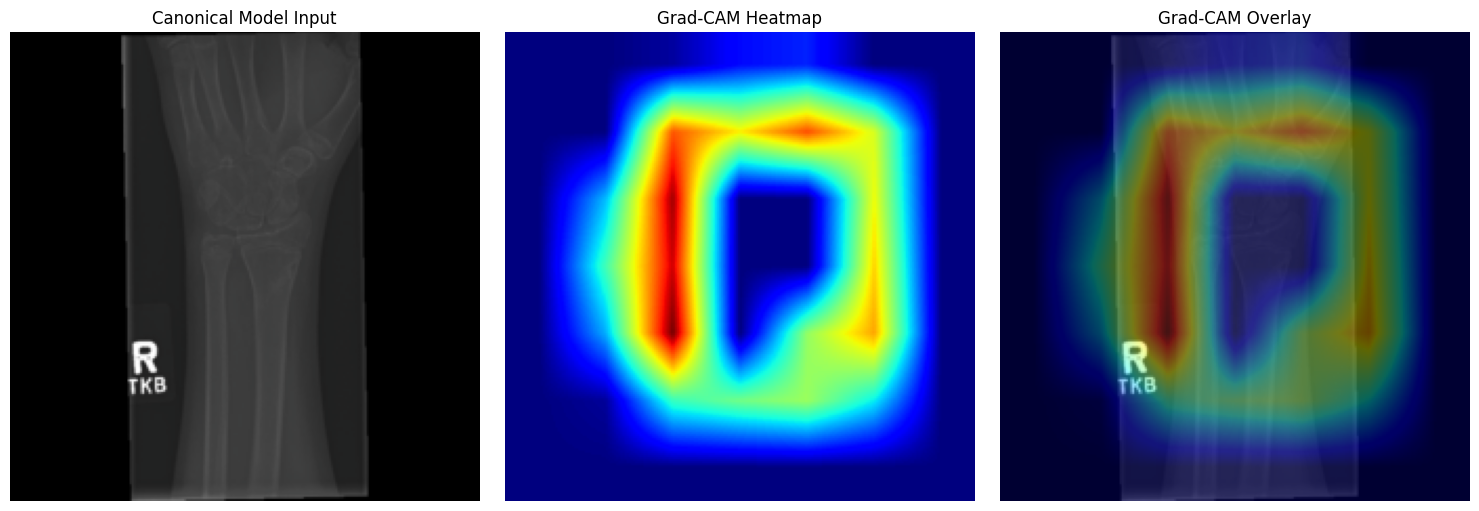


GRAD-CAM VALIDATION SUMMARY
------------------------------------------------------------
Execution: SUCCESS
Heatmap dimensions: VERIFIED
Finite heatmap values: VERIFIED
Heatmap normalization: VERIFIED
Canonical Model B probability: VERIFIED
Classification: UNCHANGED
Model parameters: UNCHANGED
Frozen threshold: VERIFIED
Forward hook cleanup: VERIFIED
Visualization: GENERATED
Visual informativeness: REQUIRES INSPECTION

Step 26: TECHNICAL TESTS PASSED


In [36]:

import io
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

print("NOTEBOOK 09 — STEP 26: GRAD-CAM FUNCTIONAL TEST")
print("-" * 60)

# 1. Preserve model state before Grad-CAM.

weights_before = {
    name: parameter.detach().cpu().clone()
    for name, parameter in resnet18_model.named_parameters()
}

threshold_before = float(SELECTED_THRESHOLD)

assert not resnet18_model.training
assert all(
    not p.requires_grad
    for p in resnet18_model.parameters()
)

hooks_before = set(gradcam_target_layer._forward_hooks.keys())

# 2. Obtain an independent canonical Model B reference.

reference_result = classify_study(
    study_id="GRADCAM_REFERENCE_TEST",
    images=[{
        "image_id": tta_test_image_id,
        "image_bytes": tta_test_image_bytes
    }]
)

assert reference_result["status"] == "COMPLETED", (
    f"Reference classification failed: {reference_result.get('issues')}"
)

reference_probability = float(
    reference_result["image_predictions"][0]["probability"]
)

# 3. Run Grad-CAM.

gradcam_result = gradcam_explainer(
    image_bytes=tta_test_image_bytes,
    image_id=tta_test_image_id
)

assert gradcam_result["status"] == "SUCCESS", (
    f"Grad-CAM failed: {gradcam_result.get('reason')}"
)

hooks_after = set(gradcam_target_layer._forward_hooks.keys())

assert hooks_after == hooks_before, (
    "Grad-CAM did not restore the original forward hooks."
)

print("Forward hook cleanup: VERIFIED")

# 4. Validate the heatmap.

heatmap = np.asarray(gradcam_result["heatmap"])

assert heatmap.shape == (224, 224), (
    f"Unexpected heatmap shape: {heatmap.shape}"
)

assert np.isfinite(heatmap).all(), (
    "Heatmap contains NaN or infinite values."
)

assert heatmap.min() >= 0
assert heatmap.max() <= 1

heatmap_min = float(heatmap.min())
heatmap_max = float(heatmap.max())
heatmap_range = heatmap_max - heatmap_min

print("\nHeatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap_min)
print("Heatmap maximum:", heatmap_max)
print("Heatmap range:", heatmap_range)

if heatmap_range < 1e-6:
    print(
        "WARNING: Heatmap is nearly uniform. "
        "Visual explanation may be uninformative."
    )

# 5. Compare against canonical Model B inference.

gradcam_probability = float(
    gradcam_result["probability"]
)

probability_difference = abs(
    gradcam_probability - reference_probability
)

print("\nImage ID:", gradcam_result["image_id"])
print("Reference probability:", reference_probability)
print("Grad-CAM probability:", gradcam_probability)
print("Absolute difference:", probability_difference)

assert probability_difference < 1e-5, (
    "Grad-CAM probability differs from canonical Model B."
)

assert gradcam_result["classification_modified"] is False

reference_classification = int(
    reference_probability >= SELECTED_THRESHOLD
)

gradcam_classification = int(
    gradcam_probability >= SELECTED_THRESHOLD
)

assert gradcam_classification == reference_classification

print("Original classification: PRESERVED")

# 6. Verify model integrity.

for name, parameter in resnet18_model.named_parameters():
    assert torch.equal(
        weights_before[name],
        parameter.detach().cpu()
    ), f"Model parameter changed: {name}"

assert all(
    not p.requires_grad
    for p in resnet18_model.parameters()
)

assert not resnet18_model.training
assert float(SELECTED_THRESHOLD) == threshold_before

print("Model parameters: UNCHANGED")
print("Model evaluation mode: PRESERVED")
print("Frozen threshold: PRESERVED")

# 7. Prepare canonical model input for visualization.

with Image.open(io.BytesIO(tta_test_image_bytes)) as source:
    original_image = source.convert("L")

model_input = inference_transform(original_image)

assert tuple(model_input.shape[-2:]) == (224, 224)

# Reverse ImageNet normalization for display only.
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

display_array = (
    model_input.detach().cpu().permute(1, 2, 0).numpy()
)

display_array = display_array * std + mean
display_array = np.clip(display_array, 0, 1)

# 8. Display input, heatmap, and overlay.

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(display_array)
axes[0].set_title("Canonical Model Input")
axes[0].axis("off")

axes[1].imshow(
    heatmap,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(display_array)
axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.40,
    vmin=0,
    vmax=1
)
axes[2].set_title("Grad-CAM Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# 9. Final verification summary.

print("\nGRAD-CAM VALIDATION SUMMARY")
print("-" * 60)
print("Execution: SUCCESS")
print("Heatmap dimensions: VERIFIED")
print("Finite heatmap values: VERIFIED")
print("Heatmap normalization: VERIFIED")
print("Canonical Model B probability: VERIFIED")
print("Classification: UNCHANGED")
print("Model parameters: UNCHANGED")
print("Frozen threshold: VERIFIED")
print("Forward hook cleanup: VERIFIED")
print("Visualization: GENERATED")

if heatmap_range < 1e-6:
    print("Visual informativeness: WARNING")
else:
    print("Visual informativeness: REQUIRES INSPECTION")

print("\nStep 26: TECHNICAL TESTS PASSED")


## Step 27 — Save Grad-CAM as a Reusable Python Module

### Objective

Package the Grad-CAM implementation functionally validated in Steps 25–26 into a reusable Python module.

The module must support integration into the MURA Agentic AI workflow without relying on notebook-specific global variables.

### Output Module

`MURA_AGENTIC_AI/tools/gradcam_tool.py`

### Model Configuration

- Architecture: Frozen `MURAResNet18` with ResNet18 backbone.
- Target layer: `backbone.layer4[-1].conv2`.
- Input preprocessing: Canonical `inference_transform`.
- Model input resolution: 224 × 224 pixels.
- Grad-CAM heatmap resolution: 224 × 224 pixels.
- Attribution target: Abnormality logit before sigmoid activation.
- Model mode: Evaluation.
- Model parameters: Frozen.
- Classification threshold: `0.263567715883255` (unchanged).

### Implementation Requirements

The saved module must:

1. Provide a reusable `gradcam_explainer()` function.
2. Accept the frozen `resnet18_model` as an explicit dependency.
3. Accept the canonical `inference_transform` as an explicit dependency.
4. Accept `gradcam_target_layer` as an explicit dependency.
5. Decode input radiographs as grayscale images, consistent with the canonical preprocessing pipeline.
6. Enable gradient computation during attribution without unfreezing model parameters.
7. Capture convolutional activations and calculate their gradients with respect to the abnormality logit.
8. Calculate channel weights using spatially averaged gradients.
9. Apply ReLU and normalize the resulting heatmap to [0, 1], safely handling degenerate maps.
10. Resize the heatmap to the canonical model input resolution of 224 × 224 pixels.
11. Preserve the original frozen Model B prediction and classification.
12. Remove temporary forward hooks after execution, including when an exception occurs.
13. Return structured results containing execution status, prediction probability, heatmap, dimensions, and relevant metadata.
14. Handle invalid image inputs, non-finite attribution values, and unsuccessful execution safely.

### Reproducibility Requirements

- Reuse the validated Step 25 implementation.
- Preserve the frozen Model B checkpoint and canonical preprocessing.
- Do not retrain, fine-tune, or modify the model parameters.
- Do not modify the frozen classification threshold.
- Do not introduce additional image augmentations.
- Do not use `torch.no_grad()` or `torch.inference_mode()` during attribution computation.
- Avoid hidden dependencies on notebook-specific global variables.
- Save the module to the existing `TOOLS_DIR`.
- Ensure module creation works during `Runtime → Run all`.

### Module Creation Checks — Step 27

- Python source file created successfully.
- Python syntax validated.
- Module imported successfully.
- `gradcam_explainer()` available.
- Explicit model, preprocessing, and target-layer dependencies verified.
- No notebook-specific global dependencies in the saved function.

### Subsequent Functional Validation — Step 28

The saved module will be tested against the original notebook implementation.

The comparison will include:

- Successful Grad-CAM execution.
- Prediction probability agreement within `1e-5`.
- Heatmap shape `(224, 224)`.
- Numerical agreement of heatmap values within a defined tolerance.
- Finite heatmap values within [0, 1].
- Frozen model parameters unchanged.
- Model evaluation mode preserved.
- Invalid image handling.
- Temporary forward hook cleanup.
- Original classification and frozen threshold preserved.

### Scientific Constraints

Grad-CAM is a supplementary model-attribution method.

Its heatmap represents spatial contributions to the frozen Model B abnormality logit.

It does not independently detect fractures, establish diagnostic correctness, or provide validated lesion localization or segmentation.

Heatmap intensity must not be interpreted as calibrated diagnostic confidence.

Grad-CAM must not override anatomical scope validation, mandatory QC checks, or the primary Agent classification workflow.

### Expected Outcome

A reusable, importable `gradcam_tool.py` module containing the validated Grad-CAM implementation, with explicit dependencies and no reliance on notebook-specific global variables.

**Step 27 establishes module packaging and importability. Numerical equivalence and functional behavior will be verified separately in Step 28.**

In [37]:

# NOTEBOOK 09 — STEP 27: SAVE GRAD-CAM MODULE

import ast
import inspect
import importlib.util
import textwrap
from pathlib import Path

print("NOTEBOOK 09 — STEP 27: SAVE GRAD-CAM MODULE")
print("-" * 60)

module_path = Path(TOOLS_DIR) / "gradcam_tool.py"
module_path.parent.mkdir(parents=True, exist_ok=True)

# 1. Extract the validated notebook function.

source = textwrap.dedent(inspect.getsource(gradcam_explainer))
tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "gradcam_explainer"
)

# 2. Add explicit dependencies.

function_node.args.kwonlyargs.extend([
    ast.arg(arg="model"),
    ast.arg(arg="transform"),
    ast.arg(arg="target_layer")
])

function_node.args.kw_defaults.extend([None, None, None])

# 3. Replace notebook global references.

replacements = {
    "resnet18_model": "model",
    "inference_transform": "transform",
    "gradcam_target_layer": "target_layer"
}

class ReplaceGlobals(ast.NodeTransformer):
    def visit_Name(self, node):
        if (
            isinstance(node.ctx, ast.Load)
            and node.id in replacements
        ):
            node.id = replacements[node.id]
        return node

function_node = ReplaceGlobals().visit(function_node)

# 4. Generate standalone module source.

module_tree = ast.Module(
    body=[
        ast.Import(names=[ast.alias(name="io")]),
        ast.Import(names=[ast.alias(name="numpy", asname="np")]),
        ast.Import(names=[ast.alias(name="torch")]),
        ast.ImportFrom(
            module="torch.nn",
            names=[ast.alias(name="functional", asname="F")],
            level=0
        ),
        ast.ImportFrom(
            module="PIL",
            names=[
                ast.alias(name="Image"),
                ast.alias(name="UnidentifiedImageError")
            ],
            level=0
        ),
        function_node
    ],
    type_ignores=[]
)

ast.fix_missing_locations(module_tree)
module_source = ast.unparse(module_tree) + "\n"

# 5. Validate syntax and save.

compile(module_source, str(module_path), "exec")
module_path.write_text(module_source, encoding="utf-8")

# 6. Import saved module.

spec = importlib.util.spec_from_file_location(
    "gradcam_tool",
    str(module_path)
)

assert spec is not None and spec.loader is not None

gradcam_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(gradcam_module)

# 7. Verify interface.

saved_function = gradcam_module.gradcam_explainer
signature = inspect.signature(saved_function)

required_dependencies = {
    "model", "transform", "target_layer"
}

for dependency in required_dependencies:
    parameter = signature.parameters[dependency]
    assert parameter.kind == inspect.Parameter.KEYWORD_ONLY
    assert parameter.default is inspect.Parameter.empty

saved_function_node = next(
    node for node in ast.parse(module_source).body
    if isinstance(node, ast.FunctionDef)
    and node.name == "gradcam_explainer"
)

remaining_globals = {
    node.id
    for node in ast.walk(saved_function_node)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Load)
    and node.id in replacements
}

assert not remaining_globals, (
    f"Notebook dependencies remain: {remaining_globals}"
)

print("\nSaved module:", module_path)
print("Python syntax: VALID")
print("Module import: SUCCESS")
print("Function signature:", signature)
print("Explicit dependencies: VERIFIED")

print("\nStep 27: MODULE SAVED AND IMPORTED")


NOTEBOOK 09 — STEP 27: SAVE GRAD-CAM MODULE
------------------------------------------------------------

Saved module: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/tools/gradcam_tool.py
Python syntax: VALID
Module import: SUCCESS
Function signature: (image_bytes, image_id='UNKNOWN', *, model, transform, target_layer)
Explicit dependencies: VERIFIED

Step 27: MODULE SAVED AND IMPORTED


## Step 28 — Verification of the Saved Grad-CAM Module

### Objective

Verify that the saved Grad-CAM module reproduces the validated notebook implementation without modifying the frozen ResNet18 Model B classifier.

### Prerequisites

- **Step 24:** Grad-CAM target layer identified and verified.
- **Step 25:** Grad-CAM function implemented.
- **Step 26:** Functional technical validation passed.
- **Step 27:** Reusable Python module saved and imported.

### Module Under Test

`MURA_AGENTIC_AI/tools/gradcam_tool.py`

### Model Configuration

- Architecture: Frozen `MURAResNet18` with ResNet18 backbone.
- Target layer: `backbone.layer4[-1].conv2`.
- Preprocessing: Canonical `inference_transform`.
- Input resolution: 224 × 224 pixels.
- Attribution target: Abnormality logit before sigmoid.
- Model mode: Evaluation.
- Model parameters: Frozen.
- Classification threshold: `0.263567715883255` (unchanged).

### Method

1. Import the saved Grad-CAM module from Google Drive.
2. Verify that `gradcam_explainer()` accepts the frozen model, canonical preprocessing transform, and target convolutional layer as explicit dependencies.
3. Run the saved function on the same verified MURA XR_WRIST radiograph used in Step 26.
4. Compare the predicted probability against the validated notebook implementation and canonical Model B inference.
5. Compare the heatmap dimensions and numerical values against the original notebook implementation.
6. Verify that all heatmap values are finite and within [0, 1].
7. Verify that the model parameters remain frozen and unchanged.
8. Confirm that the model remains in evaluation mode.
9. Verify that the frozen classification threshold and original classification remain unchanged.
10. Test invalid and unreadable image inputs.
11. Verify that temporary forward hooks are removed after successful execution.
12. Verify hook cleanup following an exception raised after hook registration.
13. Confirm that Grad-CAM does not perform optimizer steps or modify the primary classification.

### Acceptance Criteria

- Module import: `SUCCESS`.
- Explicit dependencies: `VERIFIED`.
- Saved Grad-CAM execution: `SUCCESS`.
- Probability difference from notebook implementation: less than `1e-5`.
- Probability difference from canonical Model B inference: less than `1e-5`.
- Heatmap shape: `(224, 224)`.
- Maximum absolute heatmap difference: less than `1e-5`.
- Heatmap values: finite and within `[0, 1]`.
- Model parameters: `FROZEN` and `UNCHANGED`.
- Model evaluation mode: `PRESERVED`.
- Frozen classification threshold: `PRESERVED`.
- Original classification: `UNCHANGED`.
- Invalid image handling: `VERIFIED`.
- Forward hook cleanup after successful execution: `VERIFIED`.
- Forward hook cleanup after failed execution: `VERIFIED`.
- Original forward hook identities preserved.

### Scientific Constraints

Grad-CAM provides supplementary spatial attribution for the frozen model's abnormality logit.

A technically valid heatmap does not establish diagnostic correctness, calibrated confidence, or validated lesion localization.

Grad-CAM output must not independently determine the clinical classification or override the primary Agent workflow.

### Expected Outcome

Successful verification establishes numerical equivalence and functional consistency between the saved Grad-CAM module and the validated notebook implementation for the tested inputs.

Completion of Step 28 concludes the technical implementation and validation of the reusable Grad-CAM module.

Integration into the Agentic AI workflow will be addressed in subsequent steps.

In [38]:

# NOTEBOOK 09 — STEP 28: VERIFY SAVED GRAD-CAM MODULE

import importlib.util
import inspect
import numpy as np
import torch

print("NOTEBOOK 09 — STEP 28: VERIFY SAVED GRAD-CAM MODULE")
print("-" * 60)

# 1. Import the saved module.

module_path = TOOLS_DIR / "gradcam_tool.py"
assert module_path.is_file(), f"Module not found: {module_path}"

spec = importlib.util.spec_from_file_location(
    "mura_gradcam_tool", str(module_path)
)
assert spec is not None and spec.loader is not None

gradcam_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(gradcam_module)

print("Module import: SUCCESS")

# 2. Verify explicit dependencies.

signature = inspect.signature(gradcam_module.gradcam_explainer)

for dependency in ("model", "transform", "target_layer"):
    parameter = signature.parameters[dependency]
    assert parameter.kind == inspect.Parameter.KEYWORD_ONLY
    assert parameter.default is inspect.Parameter.empty

print("Explicit dependencies: VERIFIED")

# 3. Preserve frozen model state.

weights_before = {
    name: parameter.detach().cpu().clone()
    for name, parameter in resnet18_model.named_parameters()
}

threshold_before = float(SELECTED_THRESHOLD)

assert not resnet18_model.training
assert all(not p.requires_grad for p in resnet18_model.parameters())

def hook_snapshot():
    return dict(gradcam_target_layer._forward_hooks)

hooks_before = hook_snapshot()

# 4. Run original notebook and saved module implementations.

notebook_result = gradcam_explainer(
    image_bytes=tta_test_image_bytes,
    image_id=tta_test_image_id
)

assert notebook_result["status"] == "SUCCESS"
assert hook_snapshot() == hooks_before

module_result = gradcam_module.gradcam_explainer(
    image_bytes=tta_test_image_bytes,
    image_id=tta_test_image_id,
    model=resnet18_model,
    transform=inference_transform,
    target_layer=gradcam_target_layer
)

assert module_result["status"] == "SUCCESS", module_result.get("reason")
assert hook_snapshot() == hooks_before

print("Grad-CAM execution: SUCCESS")
print("Forward-hook cleanup after success: VERIFIED")

# 5. Compare probabilities.

notebook_probability = float(notebook_result["probability"])
module_probability = float(module_result["probability"])

probability_difference = abs(
    notebook_probability - module_probability
)

assert probability_difference < 1e-5

# Independent canonical Model B inference.

canonical_result = classify_study(
    study_id="GRADCAM_MODULE_REFERENCE",
    images=[{
        "image_id": tta_test_image_id,
        "image_bytes": tta_test_image_bytes
    }]
)

assert canonical_result["status"] == "COMPLETED"

canonical_probability = float(
    canonical_result["image_predictions"][0]["probability"]
)

canonical_difference = abs(
    module_probability - canonical_probability
)

assert canonical_difference < 1e-5

print("Notebook probability difference:", probability_difference)
print("Canonical probability difference:", canonical_difference)
print("Prediction equivalence: VERIFIED")

# 6. Compare heatmaps.

original_heatmap = np.asarray(notebook_result["heatmap"])
module_heatmap = np.asarray(module_result["heatmap"])

assert original_heatmap.shape == (224, 224)
assert module_heatmap.shape == (224, 224)

assert np.isfinite(original_heatmap).all()
assert np.isfinite(module_heatmap).all()

assert module_heatmap.min() >= 0
assert module_heatmap.max() <= 1

heatmap_difference = float(
    np.max(np.abs(original_heatmap - module_heatmap))
)

assert heatmap_difference < 1e-5

print("Heatmap shape:", module_heatmap.shape)
print("Maximum heatmap difference:", heatmap_difference)
print("Heatmap equivalence: VERIFIED")

# 7. Verify original classification.

assert notebook_result["classification_modified"] is False
assert module_result["classification_modified"] is False

reference_class = int(
    canonical_probability >= SELECTED_THRESHOLD
)
module_class = int(
    module_probability >= SELECTED_THRESHOLD
)

assert reference_class == module_class

print("Classification: UNCHANGED")

# 8. Test invalid image handling.

invalid_result = gradcam_module.gradcam_explainer(
    image_bytes=b"invalid image data",
    image_id="INVALID_TEST",
    model=resnet18_model,
    transform=inference_transform,
    target_layer=gradcam_target_layer
)

assert invalid_result["status"] == "FAILED"
assert hook_snapshot() == hooks_before

print("Invalid image handling: VERIFIED")

# 9. Force an exception after hook registration.
# The wrapper raises only after the model has begun its forward pass.

class FailingModel(torch.nn.Module):
    def __init__(self, original_model):
        super().__init__()
        self.original_model = original_model

    def forward(self, x):
        self.original_model(x)
        raise RuntimeError("Intentional post-hook failure")

failing_model = FailingModel(resnet18_model)
failing_model.eval()

failed_result = gradcam_module.gradcam_explainer(
    image_bytes=tta_test_image_bytes,
    image_id="POST_HOOK_FAILURE_TEST",
    model=failing_model,
    transform=inference_transform,
    target_layer=gradcam_target_layer
)

assert failed_result["status"] == "FAILED"
assert "Intentional post-hook failure" in failed_result["reason"]
assert hook_snapshot() == hooks_before

print("Forward-hook cleanup after exception: VERIFIED")

# 10. Verify model and threshold preservation.

for name, parameter in resnet18_model.named_parameters():
    assert torch.equal(
        weights_before[name],
        parameter.detach().cpu()
    ), f"Model parameter changed: {name}"

assert all(not p.requires_grad for p in resnet18_model.parameters())
assert not resnet18_model.training
assert float(SELECTED_THRESHOLD) == threshold_before

print("Model parameters: FROZEN AND UNCHANGED")
print("Model evaluation mode: PRESERVED")
print("Frozen threshold: PRESERVED")

# 11. Final summary.

print("\nGRAD-CAM MODULE VERIFICATION SUMMARY")
print("-" * 60)
print("Module import: SUCCESS")
print("Explicit dependencies: VERIFIED")
print("Prediction equivalence: VERIFIED")
print("Heatmap equivalence: VERIFIED")
print("Classification: UNCHANGED")
print("Model parameters: UNCHANGED")
print("Model evaluation mode: PRESERVED")
print("Frozen threshold: PRESERVED")
print("Invalid input handling: VERIFIED")
print("Forward-hook cleanup after success: VERIFIED")
print("Forward-hook cleanup after exception: VERIFIED")

print("\nStep 28: PASSED")


NOTEBOOK 09 — STEP 28: VERIFY SAVED GRAD-CAM MODULE
------------------------------------------------------------
Module import: SUCCESS
Explicit dependencies: VERIFIED
Grad-CAM execution: SUCCESS
Forward-hook cleanup after success: VERIFIED
Notebook probability difference: 0.0
Canonical probability difference: 0.0
Prediction equivalence: VERIFIED
Heatmap shape: (224, 224)
Maximum heatmap difference: 0.0
Heatmap equivalence: VERIFIED
Classification: UNCHANGED
Invalid image handling: VERIFIED
Forward-hook cleanup after exception: VERIFIED
Model parameters: FROZEN AND UNCHANGED
Model evaluation mode: PRESERVED
Frozen threshold: PRESERVED

GRAD-CAM MODULE VERIFICATION SUMMARY
------------------------------------------------------------
Module import: SUCCESS
Explicit dependencies: VERIFIED
Prediction equivalence: VERIFIED
Heatmap equivalence: VERIFIED
Classification: UNCHANGED
Model parameters: UNCHANGED
Model evaluation mode: PRESERVED
Frozen threshold: PRESERVED
Invalid input handling: V

## Steps 24–28 — Grad-CAM Implementation & Validation

**Status: COMPLETED — TECHNICAL VALIDATION PASSED**

### Summary

The Grad-CAM tool was implemented, functionally tested, packaged as a reusable Python module, and verified against the original notebook implementation.

- **Step 24:** Target convolutional layer and frozen Model B architecture verified.
- **Step 25:** Grad-CAM function implemented using the abnormality logit.
- **Step 26:** Functional testing passed and visualization generated. Visual inspection remains pending.
- **Step 27:** Reusable Python module created, syntax validated, and imported successfully.
- **Step 28:** Saved module equivalence and forward-hook cleanup verified.

### Final Results

| Component | Result |
|---|---|
| Saved module | `tools/gradcam_tool.py` |
| Module import | PASSED |
| Explicit dependencies | VERIFIED |
| Probability difference vs. notebook | 0.0 |
| Probability difference vs. canonical Model B | 0.0 |
| Maximum heatmap difference | 0.0 |
| Heatmap dimensions | 224 × 224 |
| Heatmap normalization | VERIFIED — finite values in [0, 1] |
| Model parameters | FROZEN AND UNCHANGED |
| Model evaluation mode | PRESERVED |
| Frozen threshold | PRESERVED — 0.263567715883255 |
| Classification modified | False |
| Invalid input handling | VERIFIED |
| Forward-hook cleanup after success | VERIFIED |
| Forward-hook cleanup after exception | VERIFIED |
| Grad-CAM visualization | GENERATED — visual inspection pending |

### Scientific Limitations

Grad-CAM provides supplementary spatial attribution for the frozen Model B abnormality logit.

A technically valid heatmap does not establish diagnostic correctness, calibrated confidence, or validated fracture localization.

Numerical equivalence was demonstrated for the tested radiograph and does not establish universal equivalence across all possible inputs.

Grad-CAM must not override the primary classification, anatomical scope validation, or mandatory image quality checks.

### Conclusion

The reusable `gradcam_tool.py` module passed the performed technical validation tests, including numerical equivalence, frozen model preservation, invalid input handling, and forward-hook cleanup after successful and failed execution.

**Technical implementation and validation: COMPLETED.**

**Visual interpretation review: PENDING.**

Agent-level integration and orchestration remain to be validated.

**Next stage: Agentic AI tool integration.**

## Step 29 — Agent Workflow Preparation

### Objective

Prepare the integration of the validated MURA tools into a controlled, reproducible Agentic AI workflow.

The orchestrator must enforce safety constraints while preserving the frozen Model B classification.

### Available Components

| Component | Function | Role |
|---|---|---|
| Technical QC | `technical_qc()` | Image quality assessment and blocking QC failures |
| Anatomical Scope Validator | `anatomical_scope_validator()` | Metadata-based anatomical scope verification |
| Guarded Classification | `guarded_classify_study()` | Controlled study-level classification with anatomical and technical safeguards |
| TTA Uncertainty | `tta_uncertainty()` | Supplementary prediction variability under predefined transformations |
| TTA Interpretation | `interpret_tta_result()` | Structured interpretation of TTA stability without modifying classification |
| Grad-CAM | `gradcam_explainer()` | Supplementary spatial model attribution |

### Mandatory Workflow

1. Validate study identifiers, image inputs, and associated image paths.
2. Verify anatomical scope using trusted MURA path metadata.
3. Block classification when anatomy is unsupported or uncertain.
4. Execute `guarded_classify_study()` for eligible studies.
5. Require technical QC to pass its blocking criteria before model inference.
6. Require a `COMPLETED` guarded-classification result before proceeding to supplementary analyses.
7. Preserve the frozen Model B study probability, classification threshold, and predicted class.
8. Execute optional TTA and/or Grad-CAM only when explicitly requested or permitted by the orchestration policy.
9. Record supplementary results separately from the primary classification.
10. Assemble structured outputs, including execution statuses, technical observations, and applicable human-review recommendations.
11. Generate a report that clearly separates model predictions, technical QC findings, supplementary analyses, and interpretation.

### Mandatory Safety Rules

- The Agent must not call `classify_study()` directly.
- All primary classification requests must pass through `guarded_classify_study()`.
- Unsupported or uncertain anatomy must block classification.
- Blocking technical QC failures must prevent model inference.
- The frozen Model B checkpoint and classification threshold must remain unchanged.
- The primary study probability and predicted class must not be overwritten by supplementary analyses.
- Optional tools must not bypass anatomical scope validation or mandatory QC.
- Missing or invalid inputs must produce explicit `BLOCKED`, `ERROR`, or tool-specific failure statuses.
- Agent-generated explanations must not be treated as independent clinical diagnoses.

### Orchestration Principles

The orchestrator controls tool execution order, validates dependencies, and records structured results.

`guarded_classify_study()` is the mandatory entry point for primary classification and incorporates the established anatomical-scope and technical-QC safeguards.

The primary classification is deterministic for a fixed model, preprocessing pipeline, and input study.

TTA and Grad-CAM provide supplementary information and must not modify the original classification.

TTA stability metrics describe model behavior under predefined image transformations. They are not calibrated diagnostic uncertainty estimates.

Grad-CAM provides spatial attribution for the abnormality logit, not validated fracture localization.

Human review may be recommended when predefined technical or model-related concerns are identified.

Escalation criteria must be explicitly defined and must not be presented as clinically validated unless independently evaluated.

### Known Limitations

Anatomical validation currently relies on MURA file-path metadata.

It does not independently verify anatomy from image pixels or authenticate the image-path association.

Technical QC evaluates selected image-quality properties but does not guarantee diagnostic adequacy.

TTA describes prediction variability under predefined transformations, not calibrated diagnostic uncertainty.

Grad-CAM provides model attribution, not validated fracture localization.

The technical validation of Grad-CAM is complete; visual inspection of the generated attribution remains pending.

### Next Step

Verify the availability, signatures, and dependencies of the required components before implementing the Agent Orchestrator.

Confirm that the workflow can invoke the existing guarded-classification pathway without bypassing safety checks or introducing duplicate inference.

**Step 29 defines the orchestration requirements. Agent-level integration and execution remain to be validated.**

In [39]:

# NOTEBOOK 09 — STEP 29: AGENT TOOL INVENTORY

import importlib.util
import inspect
from pathlib import Path

print("NOTEBOOK 09 — STEP 29: AGENT TOOL INVENTORY")
print("-" * 60)

# 1. Verify required notebook functions.

required_functions = {
    "Technical QC": "technical_qc",
    "Anatomical Scope Validator": "anatomical_scope_validator",
    "Guarded Classification": "guarded_classify_study",
}

for description, function_name in required_functions.items():

    available = (
        function_name in globals()
        and callable(globals()[function_name])
    )

    print(
        f"{description:30s}: "
        f"{'AVAILABLE' if available else 'MISSING'}"
    )

    assert available, (
        f"Required function missing: {function_name}"
    )

# 2. Verify reusable module files and interfaces.

required_modules = {
    "TTA": {
        "path": Path(TOOLS_DIR) / "tta_tool.py",
        "functions": {
            "tta_uncertainty": {
                "resnet18_model",
                "inference_transform",
                "selected_threshold"
            },
            "interpret_tta_result": {
                "selected_threshold"
            }
        }
    },
    "Grad-CAM": {
        "path": Path(TOOLS_DIR) / "gradcam_tool.py",
        "functions": {
            "gradcam_explainer": {
                "model",
                "transform",
                "target_layer"
            }
        }
    }
}

loaded_agent_modules = {}

for description, configuration in required_modules.items():

    module_path = configuration["path"]

    assert module_path.is_file(), (
        f"Required module missing: {module_path}"
    )

    module_name = (
        "mura_agent_"
        + description.lower().replace("-", "_")
    )

    spec = importlib.util.spec_from_file_location(
        module_name,
        str(module_path)
    )

    assert spec is not None and spec.loader is not None

    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)

    for function_name, dependencies in configuration["functions"].items():

        assert hasattr(module, function_name), (
            f"{description}: missing function {function_name}"
        )

        function = getattr(module, function_name)
        assert callable(function)

        signature = inspect.signature(function)

        for dependency in dependencies:

            assert dependency in signature.parameters, (
                f"{description}.{function_name}: "
                f"missing dependency '{dependency}'"
            )

            parameter = signature.parameters[dependency]

            assert parameter.kind == inspect.Parameter.KEYWORD_ONLY
            assert parameter.default is inspect.Parameter.empty

    loaded_agent_modules[description] = module

    print(
        f"{description:30s}: "
        "MODULE IMPORTED — INTERFACE VERIFIED"
    )

# 3. Verify frozen classifier and canonical threshold.

assert "resnet18_model" in globals()
assert "inference_transform" in globals()
assert "gradcam_target_layer" in globals()
assert "SELECTED_THRESHOLD" in globals()

assert not resnet18_model.training

assert all(
    not parameter.requires_grad
    for parameter in resnet18_model.parameters()
)

assert abs(
    float(SELECTED_THRESHOLD) - 0.263567715883255
) <= 1e-12, "Frozen Model B threshold mismatch."

assert (
    gradcam_target_layer
    is resnet18_model.backbone.layer4[-1].conv2
), "Grad-CAM target layer mismatch."

print(f"\nFrozen threshold: {SELECTED_THRESHOLD:.15f}")
print("ResNet18 evaluation mode: VERIFIED")
print("Frozen model parameters: VERIFIED")
print("Grad-CAM target layer: VERIFIED")

# 4. Final summary.

print("\nAGENT TOOL INVENTORY SUMMARY")
print("-" * 60)

print("Technical QC: AVAILABLE")
print("Anatomical Scope Validator: AVAILABLE")
print("Guarded Classification: AVAILABLE")
print("TTA module and interpretation: IMPORTED")
print("Grad-CAM module: IMPORTED")
print("Frozen classifier: VERIFIED")
print("Canonical threshold: VERIFIED")

print("\nStep 29: PASSED")


NOTEBOOK 09 — STEP 29: AGENT TOOL INVENTORY
------------------------------------------------------------
Technical QC                  : AVAILABLE
Anatomical Scope Validator    : AVAILABLE
Guarded Classification        : AVAILABLE
TTA                           : MODULE IMPORTED — INTERFACE VERIFIED
Grad-CAM                      : MODULE IMPORTED — INTERFACE VERIFIED

Frozen threshold: 0.263567715883255
ResNet18 evaluation mode: VERIFIED
Frozen model parameters: VERIFIED
Grad-CAM target layer: VERIFIED

AGENT TOOL INVENTORY SUMMARY
------------------------------------------------------------
Technical QC: AVAILABLE
Anatomical Scope Validator: AVAILABLE
Guarded Classification: AVAILABLE
TTA module and interpretation: IMPORTED
Grad-CAM module: IMPORTED
Frozen classifier: VERIFIED
Canonical threshold: VERIFIED

Step 29: PASSED


## Step 30 — Agent Decision Framework

### Objective

Define a deterministic, auditable decision framework for the MURA Agentic AI Orchestrator.

The decision framework assigns workflow actions based on validated tool outputs while preserving the frozen ResNet18 Model B classification.

The decision function must operate independently of LLM-generated interpretations.

### Available Workflow Actions

| Action | Description |
|---|---|
| `routine_workflow` | Continue the standard workflow without an additional automated review flag |
| `priority_human_review` | Flag the study for prioritized human review according to predefined engineering rules |
| `human_escalation` | Escalate technical failures, missing results, or inconsistent tool outputs |
| `unsupported_input` | Reject studies outside the supported anatomical scope or with uncertain anatomical metadata |

### Decision Hierarchy

The rules are evaluated in the following order. The first applicable rule determines the workflow action.

**1. Unsupported or uncertain anatomical scope**

- Condition: Anatomical validation returns `UNSUPPORTED_ANATOMY` or `UNCERTAIN_ANATOMY`.
- Action: `unsupported_input`.
- Classification must not be performed.

A missing or unsuccessful anatomical validation result must instead trigger `human_escalation`.

**2. Technical QC failure, missing required results, or inconsistent tool outputs**

- Condition: Blocking technical QC failure, unsuccessful guarded classification, missing required classification results, invalid probabilities, or inconsistent study-level predictions.
- Action: `human_escalation`.
- No new classification may be generated to compensate for missing or invalid results.

**3. Valid abnormal study prediction**

- Condition: The guarded classification completed successfully, all mandatory checks passed, and the study-level predicted class is abnormal.
- Action: `priority_human_review`.
- Preserve the original abnormal prediction and study probability.

**4. Valid normal study prediction with image-level threshold disagreement**

- Condition: The study-level predicted class is normal, but at least one image-level probability meets or exceeds the frozen classification threshold while another remains below it.
- Action: `priority_human_review`.
- Preserve the original normal study prediction.

**5. Valid normal study prediction without image-level threshold disagreement**

- Condition: The study-level predicted class is normal and all image-level probabilities remain below the frozen classification threshold.
- Action: `routine_workflow`.
- Preserve the original normal study prediction.

### Mandatory Inputs

The decision function requires:

- Anatomical scope validation status.
- Guarded classification status.
- Technical QC outcome.
- Study-level mean

In [40]:


# NOTEBOOK 09 — STEP 30: AGENT DECISION FRAMEWORK

import numpy as np

print("NOTEBOOK 09 — STEP 30: AGENT DECISION FRAMEWORK")
print("-" * 60)

CANONICAL_THRESHOLD = 0.263567715883255

# Backward compatibility for downstream notebook cells
SELECTED_THRESHOLD = float(CANONICAL_THRESHOLD)

PROBABILITY_TOLERANCE = 1e-5



def agent_decision(
    qc_status,
    scope_status,
    classification_status,
    study_probability,
    predicted_class,
    image_probabilities,
    threshold
):
    """
    Deterministic engineering workflow policy.

    Image-level disagreement is calculated directly
    from the existing Model B image predictions.

    Does not run inference or modify predictions.
    """

    def escalate():
        return {
            "action": "human_escalation",
            "reason": "Missing, invalid, or inconsistent mandatory results.",
            "threshold_disagreement": None,
            "classification_modified": False
        }

    def unsupported():
        return {
            "action": "unsupported_input",
            "reason": "Anatomical scope is unsupported or uncertain.",
            "threshold_disagreement": None,
            "classification_modified": False
        }

    # 1. Anatomical scope takes precedence.

    if scope_status in (
        "UNSUPPORTED_ANATOMY",
        "UNCERTAIN_ANATOMY"
    ):
        return unsupported()

    if scope_status != "SUPPORTED_WRIST":
        return escalate()

    # 2. Technical QC must pass.

    if qc_status != "PASS":
        return escalate()

    # 3. Classification must have succeeded.

    if classification_status != "SUCCESS":
        return escalate()

    # 4. Validate canonical threshold.

    if (
        isinstance(threshold, (bool, np.bool_))
        or not isinstance(threshold, (int, float, np.number))
        or not np.isfinite(threshold)
        or not np.isclose(
            float(threshold),
            CANONICAL_THRESHOLD,
            rtol=0,
            atol=1e-12
        )
    ):
        return escalate()

    threshold = float(threshold)

    # 5. Validate study probability.

    if (
        isinstance(study_probability, (bool, np.bool_))
        or not isinstance(
            study_probability, (int, float, np.number)
        )
        or not np.isfinite(study_probability)
        or not 0 <= study_probability <= 1
    ):
        return escalate()

    study_probability = float(study_probability)

    # 6. Validate predicted class.

    if (
        type(predicted_class) is not int
        or predicted_class not in (0, 1)
    ):
        return escalate()

    # 7. Validate image-level probabilities.

    if (
        not isinstance(image_probabilities, (list, tuple))
        or len(image_probabilities) == 0
    ):
        return escalate()

    if any(
        isinstance(p, (bool, np.bool_))
        or not isinstance(p, (int, float, np.number))
        or not np.isfinite(p)
        or not 0 <= p <= 1
        for p in image_probabilities
    ):
        return escalate()

    probabilities = np.asarray(
        image_probabilities,
        dtype=np.float64
    )

    # 8. Verify study-level aggregation consistency.
    # Do not replace the original study probability.

    calculated_mean = float(np.mean(probabilities))

    if not np.isclose(
        study_probability,
        calculated_mean,
        rtol=0,
        atol=PROBABILITY_TOLERANCE
    ):
        return escalate()

    # 9. Verify predicted class against frozen threshold.

    expected_class = int(
        study_probability >= threshold
    )

    if predicted_class != expected_class:
        return escalate()

    # 10. Calculate image-level threshold disagreement.

    image_classes = probabilities >= threshold

    threshold_disagreement = bool(
        np.any(image_classes == 0)
        and np.any(image_classes == 1)
    )

    # 11. Apply deterministic decision hierarchy.

    if predicted_class == 1:
        action = "priority_human_review"
        reason = "Valid abnormal study prediction."

    elif threshold_disagreement:
        action = "priority_human_review"
        reason = (
            "Normal study prediction with image-level "
            "threshold disagreement."
        )

    else:
        action = "routine_workflow"
        reason = (
            "Valid normal study prediction without "
            "image-level threshold disagreement."
        )

    return {
        "action": action,
        "reason": reason,
        "study_probability": study_probability,
        "predicted_class": predicted_class,
        "threshold": threshold,
        "threshold_disagreement": threshold_disagreement,
        "classification_modified": False
    }


# --------------------------------------------------
# Synthetic unit tests
# --------------------------------------------------

test_cases = [
    (
        "Normal, consistent",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.10, 0, [0.08, 0.12],
        CANONICAL_THRESHOLD,
        "routine_workflow"
    ),
    (
        "Abnormal prediction",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.40, 1, [0.30, 0.50],
        CANONICAL_THRESHOLD,
        "priority_human_review"
    ),
    (
        "Normal, disagreement",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.25, 0, [0.10, 0.40],
        CANONICAL_THRESHOLD,
        "priority_human_review"
    ),
    (
        "Abnormal, disagreement",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.30, 1, [0.20, 0.40],
        CANONICAL_THRESHOLD,
        "priority_human_review"
    ),
    (
        "Unsupported anatomy",
        "PASS", "UNSUPPORTED_ANATOMY", "BLOCKED",
        None, None, None,
        CANONICAL_THRESHOLD,
        "unsupported_input"
    ),
    (
        "Uncertain anatomy",
        "PASS", "UNCERTAIN_ANATOMY", "BLOCKED",
        None, None, None,
        CANONICAL_THRESHOLD,
        "unsupported_input"
    ),
    (
        "Unsupported, missing QC",
        None, "UNSUPPORTED_ANATOMY", "BLOCKED",
        None, None, None,
        CANONICAL_THRESHOLD,
        "unsupported_input"
    ),
    (
        "QC failure",
        "FAIL", "SUPPORTED_WRIST", "BLOCKED",
        None, None, None,
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "QC warning",
        "WARNING", "SUPPORTED_WRIST", "BLOCKED",
        None, None, None,
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Missing QC",
        None, "SUPPORTED_WRIST", "SUCCESS",
        0.10, 0, [0.08, 0.12],
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Missing anatomy",
        "PASS", None, "BLOCKED",
        None, None, None,
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Missing classification",
        "PASS", "SUPPORTED_WRIST", None,
        None, None, None,
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Failed classification",
        "PASS", "SUPPORTED_WRIST", "FAILED",
        None, None, None,
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Invalid predicted class",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.10, 2, [0.08, 0.12],
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Boolean predicted class",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.10, True, [0.08, 0.12],
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Missing image predictions",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.10, 0, None,
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Invalid image probability",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.10, 0, [0.08, float("nan")],
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Out-of-range probability",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.10, 0, [0.08, 1.20],
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Aggregation mismatch",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.15, 0, [0.08, 0.12],
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Class-threshold mismatch",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.40, 0, [0.30, 0.50],
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Non-canonical threshold",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.10, 0, [0.08, 0.12],
        0.50,
        "human_escalation"
    ),
    (
        "Abnormal, missing image data",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        0.40, 1, None,
        CANONICAL_THRESHOLD,
        "human_escalation"
    ),
    (
        "Missing study probability",
        "PASS", "SUPPORTED_WRIST", "SUCCESS",
        None, 0, [0.08, 0.12],
        CANONICAL_THRESHOLD,
        "human_escalation"
    )
]

for (
    name,
    qc,
    scope,
    classification,
    study_probability,
    prediction,
    image_probabilities,
    threshold,
    expected
) in test_cases:

    result = agent_decision(
        qc_status=qc,
        scope_status=scope,
        classification_status=classification,
        study_probability=study_probability,
        predicted_class=prediction,
        image_probabilities=image_probabilities,
        threshold=threshold
    )

    print(f"{name:32s}: {result['action']}")

    assert result["action"] == expected, (
        f"Failed test: {name}. "
        f"Expected {expected}, got {result['action']}"
    )

    assert result["classification_modified"] is False

print("\nSynthetic test cases:", len(test_cases))
print("Decision branches: VERIFIED")
print("Rule precedence: VERIFIED")
print("Image-level disagreement: VERIFIED")
print("Aggregation consistency: VERIFIED")
print("Canonical threshold: VERIFIED")
print("Missing and invalid inputs: VERIFIED")
print("Original classification: PRESERVED")
print("No model inference performed.")

print("\nStep 30: PASSED")


NOTEBOOK 09 — STEP 30: AGENT DECISION FRAMEWORK
------------------------------------------------------------
Normal, consistent              : routine_workflow
Abnormal prediction             : priority_human_review
Normal, disagreement            : priority_human_review
Abnormal, disagreement          : priority_human_review
Unsupported anatomy             : unsupported_input
Uncertain anatomy               : unsupported_input
Unsupported, missing QC         : unsupported_input
QC failure                      : human_escalation
QC warning                      : human_escalation
Missing QC                      : human_escalation
Missing anatomy                 : human_escalation
Missing classification          : human_escalation
Failed classification           : human_escalation
Invalid predicted class         : human_escalation
Boolean predicted class         : human_escalation
Missing image predictions       : human_escalation
Invalid image probability       : human_escalation
Out-of

## Step 31 — Guarded Classification Interface Inspection

### Objective

Inspect the existing `guarded_classify_study()` interface before integrating it into the MURA Agent Orchestrator.

The purpose is to reuse the validated classification workflow without introducing an alternative classification pathway or duplicate model inference.

### Existing Safety Architecture

The guarded classification workflow:

1. Validates study inputs and image-path consistency.
2. Checks anatomical scope using MURA path metadata.
3. Blocks unsupported or uncertain anatomical scope.
4. Calls the existing `classify_study()` function only when anatomical scope requirements are satisfied.
5. Applies technical QC within the classification workflow.
6. Returns structured classification and guardrail results.

### Inspection Requirements

Verify the following:

**Function interface**
- The function exists and is callable.
- The complete function signature is documented.
- Required and optional input parameters are identified.
- Default parameter values are documented.

**Anatomical scope**
- The anatomical validation status is available.
- Supported, unsupported, and uncertain anatomy can be distinguished.
- Blocked classification results can be identified.

**Technical QC**
- The QC execution status is available.
- PASS, WARNING, and FAIL outcomes can be distinguished where applicable.
- Blocking and non-blocking QC conditions are documented.
- QC results are not independently recalculated by the Agent.

**Classification results**

After successful classification, verify that the output provides:

- Classification execution status.
- Study-level abnormality probability.
- Study-level predicted class.
- Frozen classification threshold or an independently verifiable reference to the canonical threshold.
- Image-level predictions and their associated image identifiers.

**Output consistency**

Verify that:

- Study-level probability corresponds to the arithmetic mean of the image-level probabilities.
- Predicted class is consistent with the frozen Model B threshold.
- Image-level predictions are available for the decision framework.
- Missing or unsuccessful outputs are distinguishable from valid normal predictions.

### Integration Requirements

The Agent Orchestrator must:

1. Call `guarded_classify_study()` for primary classification.
2. Never call `classify_study()` directly.
3. Preserve anatomical scope and technical QC guardrails.
4. Preserve the frozen ResNet18 model, preprocessing pipeline, and classification threshold.
5. Avoid duplicate model inference for the same classification request.
6. Distinguish blocked, failed, and successful classification results.
7. Never interpret missing results as normal predictions.
8. Pass validated outputs to

In [41]:

# NOTEBOOK 09 — STEP 31: GUARDED CLASSIFICATION INTERFACE

import inspect

print("NOTEBOOK 09 — STEP 31: GUARDED CLASSIFICATION INTERFACE")
print("-" * 60)

# 1. Verify function availability

assert callable(guarded_classify_study)

signature = inspect.signature(guarded_classify_study)

print("\nFunction:", guarded_classify_study.__name__)
print("Signature:", signature)

# 2. Verify required input parameters

required_inputs = [
    "study_id",
    "images",
    "image_paths"
]

for parameter_name in required_inputs:
    assert parameter_name in signature.parameters, (
        f"Missing required parameter: {parameter_name}"
    )

    parameter = signature.parameters[parameter_name]

    assert parameter.default is inspect.Parameter.empty, (
        f"Unexpected default for: {parameter_name}"
    )

print("Required input parameters: VERIFIED")

# 3. Inspect documentation

documentation = inspect.getdoc(guarded_classify_study)

print("\nDocumentation:")
print(documentation or "No documentation available.")

# 4. Define the expected output contract

required_output_fields = {
    "status",
    "reason",
    "classification_performed",
    "anatomy_result",
    "classification_result",
    "qc_results"
}

expected_classification_fields = {
    "status",
    "study_probability",
    "predicted_class",
    "image_predictions",
    "threshold"
}

print("\nExpected guarded output fields:")
for field in sorted(required_output_fields):
    print(" -", field)

print("\nExpected successful classification fields:")
for field in sorted(expected_classification_fields):
    print(" -", field)

# 5. Validate a synthetic output contract

synthetic_guarded_result = {
    "status": "SUCCESS",
    "reason": None,
    "classification_performed": True,
    "anatomy_result": {
        "status": "SUPPORTED_WRIST"
    },
    "classification_result": {
        "status": "SUCCESS",
        "study_probability": 0.75,
        "predicted_class": 1,
        "image_predictions": [
            {
                "image_id": "SYNTHETIC_IMAGE_001",
                "probability": 0.75
            }
        ],
        "threshold": float(SELECTED_THRESHOLD)
    },
    "qc_results": []
}

assert required_output_fields.issubset(
    synthetic_guarded_result.keys()
)

assert expected_classification_fields.issubset(
    synthetic_guarded_result["classification_result"].keys()
)

assert (
    synthetic_guarded_result["classification_performed"]
    is True
)

assert (
    synthetic_guarded_result["classification_result"]["threshold"]
    == float(SELECTED_THRESHOLD)
)

print("\nSynthetic output contract: VERIFIED")

# 6. Final summary

print("\nGUARDED CLASSIFICATION INTERFACE SUMMARY")
print("-" * 60)

print("Function availability: VERIFIED")
print("Required input parameters: VERIFIED")
print("Expected output schema: DOCUMENTED")
print("Synthetic schema example: VERIFIED")
print("Model inference performed: NO")

print("\nStep 31: INTERFACE INSPECTION COMPLETE")


NOTEBOOK 09 — STEP 31: GUARDED CLASSIFICATION INTERFACE
------------------------------------------------------------

Function: guarded_classify_study
Signature: (study_id, images, image_paths)
Required input parameters: VERIFIED

Documentation:
Classify a wrist study only after mandatory anatomical validation.

Expected guarded output fields:
 - anatomy_result
 - classification_performed
 - classification_result
 - qc_results
 - reason
 - status

Expected successful classification fields:
 - image_predictions
 - predicted_class
 - status
 - study_probability
 - threshold

Synthetic output contract: VERIFIED

GUARDED CLASSIFICATION INTERFACE SUMMARY
------------------------------------------------------------
Function availability: VERIFIED
Required input parameters: VERIFIED
Expected output schema: DOCUMENTED
Synthetic schema example: VERIFIED
Model inference performed: NO

Step 31: INTERFACE INSPECTION COMPLETE


In [42]:

# NOTEBOOK 09 — STEP 31B: GUARDED FUNCTION SOURCE INSPECTION

import inspect
import ast

print("NOTEBOOK 09 — STEP 31B: SOURCE INSPECTION")
print("-" * 60)

# 1. Retrieve actual function source

source = inspect.getsource(guarded_classify_study)

print("\nGUARDED CLASSIFICATION SOURCE")
print(source)

# 2. Parse source for structural inspection

tree = ast.parse(source)

# 3. Identify function calls

calls = sorted({
    node.func.id
    if isinstance(node.func, ast.Name)
    else (
        node.func.attr
        if isinstance(node.func, ast.Attribute)
        else None
    )
    for node in ast.walk(tree)
    if isinstance(node, ast.Call)
})

print("\nFUNCTION CALLS IDENTIFIED")

for name in calls:
    if name:
        print("-", name)

# 4. Identify dictionary keys returned by the function

returned_keys = set()

for node in ast.walk(tree):
    if isinstance(node, ast.Return):
        if isinstance(node.value, ast.Dict):
            for key in node.value.keys:
                if isinstance(key, ast.Constant):
                    if isinstance(key.value, str):
                        returned_keys.add(key.value)

print("\nRETURNED DICTIONARY KEYS FOUND IN SOURCE")

for key in sorted(returned_keys):
    print("-", key)

# 5. Report inspection limitations

print("\nSOURCE INSPECTION SUMMARY")
print("-" * 60)

print("Source retrieved: VERIFIED")
print("Function calls inspected: VERIFIED")
print("Literal return keys inspected: VERIFIED")
print("Actual runtime output: NOT TESTED")
print("Model inference performed: NO")

print("\nStep 31B: SOURCE INSPECTION COMPLETE")


NOTEBOOK 09 — STEP 31B: SOURCE INSPECTION
------------------------------------------------------------

GUARDED CLASSIFICATION SOURCE
def guarded_classify_study(study_id, images, image_paths):
    """Classify a wrist study only after mandatory anatomical validation."""

    result = {
        "study_id": study_id,
        "status": "BLOCKED",
        "reason": None,
        "classification_performed": False,
        "anatomy_result": None,
        "classification_result": None,
        "qc_results": [],
    }

    # Validate inputs
    if (
        not isinstance(study_id, str)
        or not study_id.strip()
        or not isinstance(images, (list, tuple))
        or not images
        or not isinstance(image_paths, (list, tuple))
        or len(images) != len(image_paths)
    ):
        result["reason"] = "Invalid study input"
        return result

    if any(
        not isinstance(img, dict)
        or not isinstance(img.get("image_id"), str)
        or not isinstance(img.get("ima

In [43]:

# NOTEBOOK 09 — STEP 31C: DEPENDENCY SOURCE INSPECTION

import inspect

print("NOTEBOOK 09 — STEP 31C: DEPENDENCY INSPECTION")
print("-" * 60)

functions_to_inspect = [
    ("Classification", classify_study),
    ("Anatomical Scope", anatomical_scope_validator),
]

for description, function in functions_to_inspect:

    print(f"\n{'=' * 60}")
    print(description.upper())
    print("=" * 60)

    assert callable(function), (
        f"{description} function is unavailable."
    )

    print("\nFunction signature:")
    print(inspect.signature(function))

    print("\nDocumentation:")
    print(inspect.getdoc(function) or "No documentation.")

    print("\nSource code:")
    print(inspect.getsource(function))

print("\nSTEP 31C SUMMARY")
print("-" * 60)
print("Dependency source inspection: COMPLETE")
print("Model inference performed: NO")
print("Model parameters modified: NO")


NOTEBOOK 09 — STEP 31C: DEPENDENCY INSPECTION
------------------------------------------------------------

CLASSIFICATION

Function signature:
(study_id, images)

Documentation:
Perform mandatory technical QC and frozen Model B inference
on a complete MURA XR_WRIST study.

Parameters
----------
study_id : str
    De-identified study identifier.

images : list of dict
    Each record must contain:
    - image_id: unique image identifier
    - image_bytes: original radiograph bytes

Important
---------
Anatomical scope validation must be performed separately
by the agent workflow before calling this function.

This function does not independently verify anatomy
from image pixels.

Source code:
def classify_study(study_id, images):
    """
    Perform mandatory technical QC and frozen Model B inference
    on a complete MURA XR_WRIST study.

    Parameters
    ----------
    study_id : str
        De-identified study identifier.

    images : list of dict
        Each record must contain

In [44]:

# NOTEBOOK 09 — STEP 31D: GUARDED OUTPUT EXTRACTION
# AND COMPATIBILITY TESTING

import numpy as np
import copy

print("NOTEBOOK 09 — STEP 31D: OUTPUT EXTRACTION")
print("-" * 65)

# 1. Canonical Model B threshold

CANONICAL_THRESHOLD = 0.263567715883255

assert np.isclose(
    SELECTED_THRESHOLD,
    CANONICAL_THRESHOLD,
    rtol=0,
    atol=1e-12
)


# 2. Extract decision inputs from actual guarded output

def extract_agent_decision_inputs(guarded_result):
    """
    Extract validated outputs from guarded_classify_study().

    Does not perform inference.
    Does not modify classification results.
    Does not replace missing values with defaults.
    """

    empty_result = {
        "qc_status": None,
        "scope_status": None,
        "classification_status": None,
        "study_probability": None,
        "predicted_class": None,
        "image_probabilities": None,
        "threshold": None
    }

    if not isinstance(guarded_result, dict):
        return empty_result.copy()

    # Anatomical scope
    anatomy = guarded_result.get("anatomy_result")

    scope_status = (
        anatomy.get("status")
        if isinstance(anatomy, dict)
        else None
    )

    # Classification result
    classification = guarded_result.get(
        "classification_result"
    )

    if not isinstance(classification, dict):
        return {
            **empty_result,
            "scope_status": scope_status
        }

    # Map actual classification status to Step 30 contract.
    outer_status = guarded_result.get("status")

    if (
        outer_status == "COMPLETED"
        and guarded_result.get("classification_performed") is True
        and classification.get("status") == "COMPLETED"
    ):
        classification_status = "SUCCESS"

    elif outer_status == "ERROR" or classification.get("status") == "ERROR":
        classification_status = "FAILED"

    else:
        classification_status = classification.get("status")

    # Extract image-level probabilities.
    image_predictions = classification.get(
        "image_predictions"
    )

    image_probabilities = None

    if isinstance(image_predictions, list):
        if all(
            isinstance(item, dict)
            and "probability" in item
            for item in image_predictions
        ):
            image_probabilities = [
                item["probability"]
                for item in image_predictions
            ]

    # Extract original QC status.
    qc_status = classification.get("study_qc_status")

    return {
        "qc_status": qc_status,
        "scope_status": scope_status,
        "classification_status": classification_status,
        "study_probability": classification.get(
            "study_probability"
        ),
        "predicted_class": classification.get(
            "predicted_class"
        ),
        "image_probabilities": image_probabilities,
        "threshold": classification.get("threshold")
    }


# 3. Synthetic guarded outputs based on actual source structure

def make_guarded_result(
    probabilities,
    qc_status="PASS",
    anatomy_status="SUPPORTED_WRIST",
    outer_status="COMPLETED",
    classification_status="COMPLETED",
    classification_performed=True
):
    study_probability = (
        float(np.mean(probabilities))
        if probabilities is not None and len(probabilities) > 0
        else None
    )

    predicted_class = (
        int(study_probability >= CANONICAL_THRESHOLD)
        if study_probability is not None
        else None
    )

    classification_result = None

    if anatomy_status == "SUPPORTED_WRIST":
        classification_result = {
            "status": classification_status,
            "image_count": (
                len(probabilities)
                if probabilities is not None
                else 0
            ),
            "image_predictions": (
                [
                    {
                        "image_id": f"IMG_{i+1}",
                        "probability": p
                    }
                    for i, p in enumerate(probabilities)
                ]
                if probabilities is not None
                else []
            ),
            "study_probability": study_probability,
            "threshold": CANONICAL_THRESHOLD,
            "predicted_class": predicted_class,
            "study_qc_status": qc_status,
            "qc_results": [],
            "issues": []
        }

    return {
        "study_id": "SYNTHETIC_STUDY",
        "status": outer_status,
        "reason": None,
        "classification_performed": classification_performed,
        "anatomy_result": {
            "status": anatomy_status,
            "anatomical_region": "XR_WRIST"
        },
        "classification_result": classification_result,
        "qc_results": []
    }


# 4. Test extraction and decision compatibility

compatibility_cases = [

    (
        "Normal, consistent",
        make_guarded_result([0.10, 0.12]),
        "routine_workflow"
    ),

    (
        "Normal, image disagreement",
        make_guarded_result([0.10, 0.40]),
        "priority_human_review"
    ),

    (
        "Abnormal study",
        make_guarded_result([0.30, 0.50]),
        "priority_human_review"
    ),

    (
        "QC warning",
        make_guarded_result(
            [0.10, 0.12],
            qc_status="WARNING"
        ),
        "human_escalation"
    ),

    (
        "QC failure",
        make_guarded_result(
            [0.10, 0.12],
            qc_status="FAIL",
            outer_status="BLOCKED",
            classification_status="BLOCKED",
            classification_performed=False
        ),
        "human_escalation"
    ),

    (
        "Unsupported anatomy",
        make_guarded_result(
            None,
            anatomy_status="UNSUPPORTED_ANATOMY",
            outer_status="BLOCKED",
            classification_performed=False
        ),
        "unsupported_input"
    ),

    (
        "Uncertain anatomy",
        make_guarded_result(
            None,
            anatomy_status="UNCERTAIN_ANATOMY",
            outer_status="BLOCKED",
            classification_performed=False
        ),
        "unsupported_input"
    ),

    (
        "Inference error",
        make_guarded_result(
            [0.10, 0.12],
            outer_status="ERROR",
            classification_status="ERROR",
            classification_performed=False
        ),
        "human_escalation"
    )
]


for name, guarded_result, expected_action in compatibility_cases:

    extracted = extract_agent_decision_inputs(
        guarded_result
    )

    decision = agent_decision(**extracted)

    print(
        f"{name:32s}: "
        f"{decision['action']}"
    )

    assert decision["action"] == expected_action, (
        f"Compatibility failure: {name}"
    )


# 5. Test malformed and missing outputs

invalid_cases = [
    ("Missing guarded result", None),
    ("Missing anatomy", {}),
    (
        "Missing classification",
        {
            "status": "COMPLETED",
            "classification_performed": True,
            "anatomy_result": {
                "status": "SUPPORTED_WRIST"
            },
            "classification_result": None
        }
    ),
    (
        "Missing image predictions",
        {
            **make_guarded_result([0.10, 0.12]),
            "classification_result": {
                **make_guarded_result(
                    [0.10, 0.12]
                )["classification_result"],
                "image_predictions": None
            }
        }
    )
]

for name, invalid_result in invalid_cases:

    extracted = extract_agent_decision_inputs(
        invalid_result
    )

    decision = agent_decision(**extracted)

    assert decision["action"] == "human_escalation"

    print(f"{name:32s}: VERIFIED")


# 6. Verify original outputs are not modified

original = make_guarded_result([0.10, 0.12])
original_copy = copy.deepcopy(original)

extract_agent_decision_inputs(original)

assert original == original_copy

print("\nOriginal guarded results: UNCHANGED")
print("Canonical threshold:", CANONICAL_THRESHOLD)
print("Model inference performed: NO")


# 7. Final summary

print("\nSTEP 31D VALIDATION SUMMARY")
print("-" * 65)

print("Actual guarded output schema: MAPPED")
print("Classification status mapping: VERIFIED")
print("Anatomical status extraction: VERIFIED")
print("QC status extraction: VERIFIED")
print("Study probability extraction: VERIFIED")
print("Image probability extraction: VERIFIED")
print("Decision framework compatibility: VERIFIED")
print("Blocked and failed results: VERIFIED")
print("Missing output handling: VERIFIED")
print("Original classification: PRESERVED")
print("Additional inference: NONE")

print("\nStep 31D: PASSED")


NOTEBOOK 09 — STEP 31D: OUTPUT EXTRACTION
-----------------------------------------------------------------
Normal, consistent              : routine_workflow
Normal, image disagreement      : priority_human_review
Abnormal study                  : priority_human_review
QC warning                      : human_escalation
QC failure                      : human_escalation
Unsupported anatomy             : unsupported_input
Uncertain anatomy               : unsupported_input
Inference error                 : human_escalation
Missing guarded result          : VERIFIED
Missing anatomy                 : VERIFIED
Missing classification          : VERIFIED
Missing image predictions       : VERIFIED

Original guarded results: UNCHANGED
Canonical threshold: 0.263567715883255
Model inference performed: NO

STEP 31D VALIDATION SUMMARY
-----------------------------------------------------------------
Actual guarded output schema: MAPPED
Classification status mapping: VERIFIED
Anatomical status extr

## Step 32 — Guarded Classification Output Inspection

### Objective

Inspect and verify the actual runtime output of the validated `guarded_classify_study()` function using a complete official MURA XR_WRIST validation study.

Confirm compatibility with the deterministic output extraction and Agent decision framework validated in Steps 30–31D.

### Prerequisites

- **Step 12:** Guarded classification implemented.
- **Step 13:** Guardrail integration tests passed.
- **Steps 31–31C:** Function interfaces and source code inspected.
- **Step 31D:** Output extraction and decision compatibility tested synthetically.
- Frozen Model B and canonical preprocessing available.

### Method

1. Select a previously verified complete official XR_WRIST validation study using trusted MURA metadata.
2. Load all radiographs belonging to the selected study.
3. Prepare image records and corresponding metadata paths in the required input format.
4. Execute `guarded_classify_study()` once.
5. Verify successful anatomical scope validation.
6. Verify that mandatory technical QC was performed before inference.
7. Inspect the actual guarded-classification result and its nested fields.
8. Extract the required decision inputs using `extract_agent_decision_inputs()`.
9. Verify study-level mean-probability aggregation and classification consistency with the frozen threshold.
10. Execute `agent_decision()` using the extracted results, without additional model inference.
11. Verify that model parameters, evaluation mode, and frozen threshold remain unchanged.

### Required Output Inspection

**Guarded result**

- `status`
- `reason`
- `classification_performed`
- `anatomy_result`
- `classification_result`
- `qc_results`

**Classification result**

- `status`
- `study_probability`
- `predicted_class`
- `image_predictions`
- `threshold`
- `study_qc_status`
- `issues`
- `aggregation`

**Agent decision inputs**

- `qc_status`
- `scope_status`
- `classification_status`
- `study_probability`
- `predicted_class`
- `image_probabilities`
- `threshold`

Image-level threshold disagreement is calculated directly by `agent_decision()` from the existing image-level probabilities.

No separate View Consistency tool is required.

### Acceptance Criteria

- Guarded classification status: `COMPLETED`.
- Anatomical scope: `SUPPORTED_WRIST`.
- Classification performed: `True`.
- Nested classification status: `COMPLETED`.
- Mandatory technical QC: Executed.
- Blocking QC failures: None.
- Actual output schema: VERIFIED.
- Study probability equals the arithmetic mean of image probabilities within an absolute tolerance of `1e-5`.
- Predicted class is consistent with the frozen classification threshold.
- Output extraction: SUCCESS.
- Agent decision: One of the four predefined workflow actions.
- Original classification: UNCHANGED.
- Model parameters: FROZEN AND UNCHANGED.
- Model evaluation mode: PRESERVED.
- Frozen threshold: `0.263567715883255`.
- No alternative classification pathway or duplicate inference introduced.

### Scientific Constraints

Anatomical validation relies on trusted MURA file-path metadata, not independent image-based anatomical verification.

Technical QC evaluates selected image-quality properties but does not establish clinical diagnostic adequacy.

The official validation study is used for technical integration verification only. It must not be used to optimize the classification threshold or decision policy.

The frozen model prediction and deterministic workflow action are not clinical diagnoses or validated clinical triage decisions.

### Expected Outcome

A verified runtime output schema and successful end-to-end compatibility test:

`guarded_classify_study()`
→ `extract_agent_decision_inputs()`
→ `agent_decision()`

The integration must preserve mandatory guardrails, frozen Model B predictions, and the original classification threshold.

Optional TTA and Grad-CAM integration will be addressed separately.

In [45]:

# NOTEBOOK 09 — STEP 32:
# GUARDED CLASSIFICATION RUNTIME INTEGRATION

from pprint import pprint
import io
import zipfile
import numpy as np
import torch

print("NOTEBOOK 09 — STEP 32: RUNTIME INTEGRATION")
print("-" * 65)

# --------------------------------------------------
# 1. Select a complete official XR_WRIST study
# --------------------------------------------------

assert callable(guarded_classify_study)
assert callable(extract_agent_decision_inputs)
assert callable(agent_decision)

assert MURA_ZIP_PATH.exists()

integration_image_id = tta_test_image_id

matching_rows = lookup_df.loc[
    lookup_df["image_path"] == integration_image_id
]

assert len(matching_rows) == 1, (
    "Expected exactly one trusted MURA image record."
)

integration_row = matching_rows.iloc[0]

assert integration_row["split"] == "valid"
assert integration_row["anatomy"] == "XR_WRIST"

study_mask = (
    (lookup_df["split"] == integration_row["split"])
    & (lookup_df["anatomy"] == integration_row["anatomy"])
    & (lookup_df["patient_id"] == integration_row["patient_id"])
    & (lookup_df["study_id"] == integration_row["study_id"])
)

study_rows = lookup_df.loc[study_mask].copy()

assert not study_rows.empty

integration_image_paths = sorted(
    study_rows["image_path"].tolist()
)

assert len(integration_image_paths) == len(set(integration_image_paths))

integration_study_id = "/".join(
    integration_image_id.replace("\\", "/").split("/")[:-1]
)

assert all(
    path.replace("\\", "/").startswith(
        integration_study_id + "/"
    )
    for path in integration_image_paths
)

print("Study ID:", integration_study_id)
print("Study image count:", len(integration_image_paths))
print("Split: official VALID")

# --------------------------------------------------
# 2. Load every study image from the original ZIP
# --------------------------------------------------

integration_images = []

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as archive:

    archive_members = archive.namelist()

    for image_path in integration_image_paths:

        matches = [
            member
            for member in archive_members
            if member.replace("\\", "/").endswith(
                image_path.replace("\\", "/")
            )
        ]

        assert len(matches) == 1, (
            f"Expected one archive match for {image_path}; "
            f"found {len(matches)}."
        )

        image_bytes = archive.read(matches[0])

        integration_images.append({
            "image_id": image_path,
            "image_bytes": image_bytes
        })

assert len(integration_images) == len(integration_image_paths)

print("Complete study loaded: VERIFIED")

# --------------------------------------------------
# 3. Snapshot frozen Model B
# --------------------------------------------------

assert resnet18_model.training is False

assert all(
    not p.requires_grad
    for p in resnet18_model.parameters()
)

threshold_before = float(SELECTED_THRESHOLD)

assert threshold_before == 0.263567715883255

model_state_before = {
    name: tensor.detach().clone()
    for name, tensor in resnet18_model.state_dict().items()
}

# --------------------------------------------------
# 4. Execute guarded classification ONCE
# --------------------------------------------------

guarded_result = guarded_classify_study(
    study_id=integration_study_id,
    images=integration_images,
    image_paths=integration_image_paths
)

assert isinstance(guarded_result, dict)

print("\nGUARDED RESULT")
pprint(guarded_result)

# --------------------------------------------------
# 5. Validate real output schema and guardrails
# --------------------------------------------------

required_guarded_fields = {
    "status",
    "reason",
    "classification_performed",
    "anatomy_result",
    "classification_result",
    "qc_results"
}

assert required_guarded_fields.issubset(guarded_result)

assert guarded_result["status"] == "COMPLETED"
assert guarded_result["classification_performed"] is True

anatomy_result = guarded_result["anatomy_result"]
classification_result = guarded_result["classification_result"]

assert isinstance(anatomy_result, dict)
assert isinstance(classification_result, dict)

assert anatomy_result["status"] == "SUPPORTED_WRIST"
assert anatomy_result["anatomy_image_verified"] is False

assert classification_result["status"] == "COMPLETED"

required_classification_fields = {
    "status",
    "study_probability",
    "predicted_class",
    "image_predictions",
    "threshold",
    "study_qc_status",
    "qc_results",
    "issues",
    "aggregation"
}

assert required_classification_fields.issubset(
    classification_result
)

assert classification_result["aggregation"] == "mean_probability"

# --------------------------------------------------
# 6. Validate QC and study-level aggregation
# --------------------------------------------------

qc_results = guarded_result["qc_results"]
image_predictions = classification_result["image_predictions"]

assert isinstance(qc_results, list)
assert isinstance(image_predictions, list)

assert len(qc_results) == len(integration_images)
assert len(image_predictions) == len(integration_images)

assert all(
    qc["status"] in {"PASS", "WARNING"}
    for qc in qc_results
)

assert classification_result["study_qc_status"] in {
    "PASS",
    "WARNING"
}

assert all(
    {"image_id", "probability"}.issubset(pred)
    for pred in image_predictions
)

assert {
    pred["image_id"]
    for pred in image_predictions
} == set(integration_image_paths)

image_probabilities = [
    float(pred["probability"])
    for pred in image_predictions
]

assert all(
    np.isfinite(p) and 0.0 <= p <= 1.0
    for p in image_probabilities
)

study_probability = float(
    classification_result["study_probability"]
)

expected_mean = float(
    np.mean(image_probabilities, dtype=np.float64)
)

assert abs(study_probability - expected_mean) < 1e-5

assert float(classification_result["threshold"]) == threshold_before

assert classification_result["predicted_class"] == int(
    study_probability >= threshold_before
)

print("\nQC STATUS:", classification_result["study_qc_status"])
print("STUDY PROBABILITY:", study_probability)
print("MEAN IMAGE PROBABILITY:", expected_mean)
print("PREDICTED CLASS:", classification_result["predicted_class"])

print("\nIMAGE PREDICTIONS:")
pprint(image_predictions)

# --------------------------------------------------
# 7. Extract actual Agent decision inputs
# --------------------------------------------------

decision_inputs = extract_agent_decision_inputs(
    guarded_result
)

assert decision_inputs["scope_status"] == "SUPPORTED_WRIST"
assert decision_inputs["classification_status"] == "SUCCESS"

assert decision_inputs["qc_status"] == (
    classification_result["study_qc_status"]
)

assert decision_inputs["study_probability"] == study_probability

assert decision_inputs["predicted_class"] == (
    classification_result["predicted_class"]
)

assert decision_inputs["image_probabilities"] == image_probabilities

assert decision_inputs["threshold"] == threshold_before

print("\nEXTRACTED AGENT INPUTS")
pprint(decision_inputs)

# --------------------------------------------------
# 8. Execute deterministic Agent decision
# --------------------------------------------------

agent_result = agent_decision(**decision_inputs)

assert isinstance(agent_result, dict)

assert agent_result["action"] in {
    "routine_workflow",
    "priority_human_review",
    "human_escalation",
    "unsupported_input"
}

assert agent_result["classification_modified"] is False

print("\nAGENT DECISION")
pprint(agent_result)

# --------------------------------------------------
# 9. Verify frozen model remains unchanged
# --------------------------------------------------

for name, tensor_before in model_state_before.items():

    assert torch.equal(
        tensor_before,
        resnet18_model.state_dict()[name]
    ), f"Model state changed: {name}"

assert resnet18_model.training is False

assert all(
    not p.requires_grad
    for p in resnet18_model.parameters()
)

assert float(SELECTED_THRESHOLD) == threshold_before

# --------------------------------------------------
# 10. Final summary
# --------------------------------------------------

print("\nSTEP 32 VALIDATION SUMMARY")
print("-" * 65)

print("Complete official XR_WRIST study: VERIFIED")
print("Anatomical scope: SUPPORTED_WRIST")
print("Guarded classification: COMPLETED")
print("Actual output schema: VERIFIED")
print("Technical QC: VERIFIED")
print("Mean probability aggregation: VERIFIED")
print("Frozen threshold: VERIFIED")
print("Agent input extraction: VERIFIED")
print("Agent decision integration: VERIFIED")
print("Model parameters: UNCHANGED")
print("Additional inference: NONE")

print("\nStep 32: PASSED")


NOTEBOOK 09 — STEP 32: RUNTIME INTEGRATION
-----------------------------------------------------------------
Study ID: valid/XR_WRIST/patient11185/study1_positive
Study image count: 4
Split: official VALID
Complete study loaded: VERIFIED

GUARDED RESULT
{'anatomy_result': {'anatomical_region': 'XR_WRIST',
                    'anatomy_image_verified': False,
                    'issues': [],
                    'metadata_source': 'MURA_LOOKUP',
                    'status': 'SUPPORTED_WRIST'},
 'classification_performed': True,
 'classification_result': {'aggregation': 'mean_probability',
                           'image_count': 4,
                           'image_predictions': [{'image_id': 'valid/XR_WRIST/patient11185/study1_positive/image1.png',
                                                  'probability': 0.9957946538925171},
                                                 {'image_id': 'valid/XR_WRIST/patient11185/study1_positive/image2.png',
                                  

## Step 33 — Initial Agent Orchestrator Implementation

### Objective

Implement the initial MURA Agent Orchestrator by integrating previously validated tools into one deterministic, guarded workflow.

The Orchestrator coordinates existing functions and validates their outputs. It does not introduce a new classification model, an alternative inference pathway, or an independent decision policy.

### Prerequisites

- **Step 12:** `guarded_classify_study()` implemented.
- **Step 13:** Guardrail integration tests passed.
- **Step 30:** `agent_decision()` implemented and tested.
- **Steps 31–31C:** Guarded classification interfaces and dependencies inspected.
- **Step 31D:** `extract_agent_decision_inputs()` implemented and tested synthetically.
- **Step 32:** Guarded classification runtime integration verified.

### Mandatory Workflow

1. Receive a study ID, complete study image records, and corresponding trusted MURA image-path metadata.

2. Call `guarded_classify_study()` as the only classification entry point.

3. Inspect the guarded result and extract anatomical scope validation, technical QC findings, and classification status.

4. Validate the technical QC results using the following precedence:

   - `FAIL` if any image has a QC failure.
   - `WARNING` if no image fails but at least one image has a QC warning.
   - `PASS` only when every expected image has a valid PASS result.
   - Missing, invalid, incomplete, duplicated, or inconsistent QC results must trigger `human_escalation`.

5. Confirm that the reported study-level QC status is consistent with the individual image QC results.

6. If guarded classification completed successfully, validate and extract:

   - Study-level probability
   - Frozen predicted class
   - Image-level probabilities and identifiers
   - Frozen classification threshold
   - Original classification status

7. Use `extract_agent_decision_inputs()` to construct the standardized decision inputs.

8. Verify that extracted values are consistent with the original guarded-classification result.

9. Call the existing `agent_decision()` function to determine the workflow action.

10. Return a structured Orchestrator result containing:

    - Study identifier
    - Overall workflow status
    - Anatomical scope findings
    - Technical QC findings
    - Original classification result
    - Image-level prediction disagreement, when available
    - Deterministic Agent decision
    - Relevant issues and escalation reasons

Image-level disagreement is evaluated by the existing `agent_decision()` function using image probabilities and the frozen threshold. No separate View Consistency tool is used.

### Mandatory Safety Controls

- `guarded_classify_study()` is the only classification entry point.
- The Orchestrator must never call `classify_study()` directly.
- Anatomical validation must precede model inference.
- Unsupported or uncertain anatomy must block classification and result in `unsupported_input` when the anatomical status is valid and confirmed.
- Failed or incomplete guarded classification must never be interpreted as a normal prediction.
- Missing, malformed, or inconsistent required outputs must result in `human_escalation`.
- The Orchestrator must validate image counts, identifiers, QC completeness, probability aggregation, and classification-threshold consistency before accepting a successful classification.
- The frozen ResNet18 model, canonical preprocessing, and selected classification threshold must remain unchanged.
- The Agent decision policy must not alter original predictions or probabilities.
- The Orchestrator must not perform additional model inference or independently recalculate model predictions.

### Decision Actions

The Orchestrator uses the four predefined deterministic workflow actions:

- `routine_workflow`
- `priority_human_review`
- `human_escalation`
- `unsupported_input`

These actions are engineering workflow categories, not clinically validated triage recommendations or diagnostic conclusions.

### Optional Tools

The initial Orchestrator does not automatically execute TTA or Grad-CAM.

These tools may be integrated after the mandatory workflow has passed integration testing.

Optional analyses must not modify the primary classification, frozen threshold, or deterministic Agent action.

### Scientific Limitations

Anatomical scope validation relies on trusted MURA file-path metadata and does not independently verify anatomical image content or authenticate correspondence between metadata and image bytes.

Technical QC evaluates selected image-quality properties but does not establish clinical diagnostic adequacy.

The frozen model has not achieved the prespecified 95% sensitivity target on official validation.

The Agent decision policy has not been clinically validated and must not be interpreted as an autonomous clinical triage system.

### Acceptance Criteria

- The Orchestrator calls `guarded_classify_study()` exactly once per workflow execution.
- No direct call to `classify_study()` occurs within the Orchestrator.
- Valid supported studies preserve the original Model B classification.
- Unsupported or uncertain anatomy blocks classification.
- QC failures block classification.
- QC warnings are preserved and routed according to the existing decision policy.
- Missing or inconsistent required outputs trigger `human_escalation`.
- Image-level probabilities and study-level aggregation remain unchanged.
- Frozen classification threshold is preserved.
- All Agent actions belong to the four predefined categories.
- No duplicate inference or alternative classification pathway is introduced.
- Deterministic integration tests pass.

### Expected Outcome

A functioning deterministic Agent Orchestrator implementing the workflow:

`guarded_classify_study()`
→ `extract_agent_decision_inputs()`
→ output integrity validation
→ `agent_decision()`
→ structured workflow result

The Orchestrator preserves mandatory safety checks, frozen Model B predictions, and the original classification threshold.

In [46]:

# NOTEBOOK 09 — STEP 33: INITIAL AGENT ORCHESTRATOR

import math
import inspect

print("NOTEBOOK 09 — STEP 33: AGENT ORCHESTRATOR")
print("-" * 65)

assert callable(guarded_classify_study)
assert callable(extract_agent_decision_inputs)
assert callable(agent_decision)

assert set(inspect.signature(agent_decision).parameters) == {
    "qc_status",
    "scope_status",
    "classification_status",
    "study_probability",
    "predicted_class",
    "image_probabilities",
    "threshold",
}


def mura_agent_orchestrator(study_id, images, image_paths):
    """
    Deterministic MURA Agent Orchestrator.

    Calls guarded_classify_study exactly once.
    Validates returned metadata, QC and predictions.
    Uses the existing Step 30 decision policy.

    Does not independently perform model inference.
    """

    allowed_actions = {
        "routine_workflow",
        "priority_human_review",
        "human_escalation",
        "unsupported_input",
    }

    issues = []

    # --------------------------------------------------
    # 1. Mandatory guarded classification
    # --------------------------------------------------

    guarded = guarded_classify_study(
        study_id=study_id,
        images=images,
        image_paths=image_paths
    )

    # --------------------------------------------------
    # 2. Validate guarded result and extract inputs
    # --------------------------------------------------

    if not isinstance(guarded, dict):
        issues.append("invalid_guarded_result")
        guarded = {}

    anatomy = guarded.get("anatomy_result")
    classification = guarded.get("classification_result")
    qc_results = guarded.get("qc_results")

    extracted = extract_agent_decision_inputs(guarded)

    scope_status = extracted["scope_status"]
    qc_status = None

    valid_input_ids = False
    input_ids = []

    if isinstance(images, (list, tuple)) and images:
        if all(
            isinstance(item, dict)
            and isinstance(item.get("image_id"), str)
            and bool(item["image_id"].strip())
            for item in images
        ):
            input_ids = [item["image_id"] for item in images]
            valid_input_ids = (
                len(input_ids) == len(set(input_ids))
            )

    # --------------------------------------------------
    # 3. Validate anatomical result
    # --------------------------------------------------

    valid_anatomy = (
        isinstance(anatomy, dict)
        and scope_status in {
            "SUPPORTED_WRIST",
            "UNSUPPORTED_ANATOMY",
            "UNCERTAIN_ANATOMY",
        }
        and anatomy.get("metadata_source") == "MURA_LOOKUP"
        and anatomy.get("anatomy_image_verified") is False
        and isinstance(anatomy.get("issues"), list)
    )

    if not valid_anatomy:
        issues.append("invalid_or_missing_anatomy_result")

    # --------------------------------------------------
    # 4. Validate complete image-level QC
    # --------------------------------------------------

    valid_qc = (
        valid_input_ids
        and isinstance(qc_results, list)
        and len(qc_results) == len(input_ids)
        and all(
            isinstance(item, dict)
            and isinstance(item.get("image_id"), str)
            and item.get("status") in {"PASS", "WARNING", "FAIL"}
            for item in qc_results
        )
    )

    if valid_qc:
        qc_ids = [item["image_id"] for item in qc_results]

        valid_qc = (
            len(qc_ids) == len(set(qc_ids))
            and set(qc_ids) == set(input_ids)
        )

    if valid_qc:
        statuses = [item["status"] for item in qc_results]

        if "FAIL" in statuses:
            qc_status = "FAIL"
        elif "WARNING" in statuses:
            qc_status = "WARNING"
        else:
            qc_status = "PASS"

    # Missing QC is expected when anatomical validation
    # blocks inference before technical QC.
    anatomy_blocked = (
        valid_anatomy
        and scope_status in {
            "UNSUPPORTED_ANATOMY",
            "UNCERTAIN_ANATOMY",
        }
        and guarded.get("status") == "BLOCKED"
        and guarded.get("classification_performed") is False
        and classification is None
        and qc_results == []
    )

    if not valid_qc and not anatomy_blocked:
        issues.append("missing_or_inconsistent_qc")

    # --------------------------------------------------
    # 5. Validate completed classification
    # --------------------------------------------------

    valid_classification = False
    image_disagreement = None

    completed = (
        guarded.get("status") == "COMPLETED"
        and guarded.get("classification_performed") is True
        and isinstance(classification, dict)
        and classification.get("status") == "COMPLETED"
        and scope_status == "SUPPORTED_WRIST"
    )

    if completed and valid_anatomy and valid_qc:
        predictions = classification.get("image_predictions")
        probability = classification.get("study_probability")
        predicted_class = classification.get("predicted_class")
        threshold = classification.get("threshold")

        valid_predictions = (
            isinstance(predictions, list)
            and len(predictions) == len(input_ids)
            and all(
                isinstance(item, dict)
                and isinstance(item.get("image_id"), str)
                and type(item.get("probability")) in (int, float)
                and math.isfinite(item["probability"])
                and 0.0 <= item["probability"] <= 1.0
                for item in predictions
            )
        )

        if valid_predictions:
            prediction_ids = [
                item["image_id"] for item in predictions
            ]

            valid_predictions = (
                len(prediction_ids) == len(set(prediction_ids))
                and set(prediction_ids) == set(input_ids)
            )

        valid_numbers = (
            type(probability) in (int, float)
            and math.isfinite(probability)
            and 0.0 <= probability <= 1.0
            and type(threshold) in (int, float)
            and math.isfinite(threshold)
            and threshold == float(SELECTED_THRESHOLD)
            and type(predicted_class) is int
            and predicted_class in (0, 1)
        )

        valid_classification = (
            valid_predictions
            and valid_numbers
            and classification.get("aggregation")
                == "mean_probability"
            and classification.get("image_count")
                == len(input_ids)
            and classification.get("study_qc_status")
                == qc_status
            and classification.get("qc_results")
                == qc_results
        )

        if valid_classification:
            probabilities = [
                item["probability"] for item in predictions
            ]

            mean_probability = math.fsum(
                probabilities
            ) / len(probabilities)

            valid_classification = (
                abs(probability - mean_probability) <= 1e-5
                and predicted_class == int(
                    probability >= threshold
                )
                and extracted["classification_status"] == "SUCCESS"
                and extracted["qc_status"] == qc_status
                and extracted["scope_status"] == scope_status
                and extracted["study_probability"] == probability
                and extracted["predicted_class"] == predicted_class
                and extracted["image_probabilities"] == probabilities
                and extracted["threshold"] == threshold
            )

            if valid_classification:
                image_disagreement = (
                    any(p >= threshold for p in probabilities)
                    and any(p < threshold for p in probabilities)
                )

    if completed and not valid_classification:
        issues.append("invalid_completed_classification")

    if (
        guarded.get("status") == "COMPLETED"
        and not completed
    ):
        issues.append("inconsistent_guarded_completion")

    # A completed classification must not contain QC FAIL.
    if completed and qc_status == "FAIL":
        issues.append("completed_with_qc_failure")

    # Verify that blocked anatomy produced no classification.
    if (
        valid_anatomy
        and scope_status in {
            "UNSUPPORTED_ANATOMY",
            "UNCERTAIN_ANATOMY",
        }
        and not anatomy_blocked
    ):
        issues.append("inconsistent_anatomy_block")

    # Verify that QC failure did not produce classification.
    if qc_status == "FAIL":
        if (
            guarded.get("status") != "BLOCKED"
            or guarded.get("classification_performed") is not False
            or (
                isinstance(classification, dict)
                and classification.get("status") == "COMPLETED"
            )
        ):
            issues.append("qc_failure_not_blocked")

    # --------------------------------------------------
    # 6. Apply the existing deterministic decision policy
    # --------------------------------------------------

    if issues:
        # Invalid outputs cannot enter the normal workflow.
        safe_inputs = {
            "qc_status": None,
            "scope_status": None,
            "classification_status": None,
            "study_probability": None,
            "predicted_class": None,
            "image_probabilities": None,
            "threshold": None,
        }
        decision = agent_decision(**safe_inputs)

    elif anatomy_blocked:
        decision = agent_decision(**extracted)

    elif valid_classification:
        decision = agent_decision(**extracted)

    else:
        # Blocked, failed or incomplete classification.
        safe_inputs = {
            **extracted,
            "classification_status": "INVALID_OR_NOT_PERFORMED",
            "study_probability": None,
            "predicted_class": None,
            "image_probabilities": None,
        }
        decision = agent_decision(**safe_inputs)

    assert isinstance(decision, dict)
    assert decision.get("action") in allowed_actions

    # Invalid outputs must always escalate.
    if issues:
        assert decision["action"] == "human_escalation"

    # --------------------------------------------------
    # 7. Return structured workflow result
    # --------------------------------------------------

    return {
        "study_id": study_id,
        "workflow_status": guarded.get("status"),
        "workflow_reason": guarded.get("reason"),
        "classification_performed": guarded.get(
            "classification_performed"
        ),
        "anatomy_status": scope_status,
        "anatomy_result": anatomy,
        "qc_status": qc_status,
        "qc_results": qc_results,
        "classification_status": (
            classification.get("status")
            if isinstance(classification, dict)
            else None
        ),
        "classification_valid": valid_classification,
        "classification_result": classification,
        "study_probability": (
            classification["study_probability"]
            if valid_classification else None
        ),
        "predicted_class": (
            classification["predicted_class"]
            if valid_classification else None
        ),
        "classification_threshold": (
            classification["threshold"]
            if valid_classification else None
        ),
        "image_predictions": (
            classification["image_predictions"]
            if valid_classification else None
        ),
        "image_threshold_disagreement": image_disagreement,
        "agent_action": decision,
        "issues": issues,
        "classification_modified": False,
    }


print("Agent Orchestrator defined successfully.")
print("Classification pathway: GUARDED ONLY")
print("Output extraction: STEP 31D")
print("QC and classification integrity checks: INCLUDED")
print("Image disagreement: DERIVED FROM EXISTING PREDICTIONS")
print("Agent decision: STEP 30 POLICY")
print("Model inference performed: NO")

print("\nStep 33: FUNCTION DEFINED")


NOTEBOOK 09 — STEP 33: AGENT ORCHESTRATOR
-----------------------------------------------------------------
Agent Orchestrator defined successfully.
Classification pathway: GUARDED ONLY
Output extraction: STEP 31D
QC and classification integrity checks: INCLUDED
Image disagreement: DERIVED FROM EXISTING PREDICTIONS
Agent decision: STEP 30 POLICY
Model inference performed: NO

Step 33: FUNCTION DEFINED


## Step 34 — First End-to-End Agent Integration and Internal Consistency Test

### Objective

Verify that the MURA Agent Orchestrator correctly processes a complete multi-image XR_WRIST study using the previously validated tools.

This test evaluates software integration, internal numerical consistency, deterministic Agent routing, and preservation of mandatory safety controls.

No comparison with previously saved model predictions or reference evaluation results is performed.

### Prerequisites

- **Step 12:** `guarded_classify_study()` implemented.
- **Step 13:** Guardrail integration tests passed.
- **Step 30:** `agent_decision()` policy verified.
- **Step 31D:** Output extraction and decision compatibility verified synthetically.
- **Step 32:** Guarded classification runtime integration verified.
- **Step 33:** `mura_agent_orchestrator()` implemented.

### Test Procedure

1. Select a complete multi-image XR_WRIST study from the official MURA validation dataset using the trusted `lookup_df`.

2. Retrieve all images belonging to the selected study from the original MURA archive.

3. Verify that all image identifiers and metadata paths belong to the same study and that no expected image is missing or duplicated.

4. Snapshot the frozen Model B parameters, evaluation mode, and selected classification threshold.

5. Execute `mura_agent_orchestrator()` once using the complete study.

6. Verify that the Orchestrator invokes `guarded_classify_study()` exactly once.

7. Verify mandatory guardrails:

   - Anatomical scope: `SUPPORTED_WRIST`
   - Guarded classification: `COMPLETED`
   - Classification performed: `True`
   - Classification output: Valid
   - Technical QC: Complete and internally consistent

8. Verify that all image-level QC results are `PASS` for the selected test study. A `WARNING` or `FAIL` must not be reported as a successful all-PASS scenario.

9. Verify that the number and identifiers of image-level predictions match the complete input study.

10. Verify that the study probability equals the arithmetic mean of image-level probabilities within an absolute tolerance of `1e-5`.

11. Verify that the predicted class is consistent with the frozen classification threshold.

12. Verify that image-level threshold disagreement, when available, is consistent with the existing image-level probabilities.

13. Verify that the Agent action belongs to the predefined decision set:

    - `routine_workflow`
    - `priority_human_review`
    - `human_escalation`
    - `unsupported_input`

14. Independently invoke the existing `agent_decision()` function using the extracted outputs from the current guarded classification and confirm that its action matches the Orchestrator result. This verification must not perform additional model inference.

15. Verify that the original classification outputs, frozen threshold, model parameters, and evaluation mode remain unchanged.

### Acceptance Criteria

- A complete official XR_WRIST multi-image study is processed.
- All expected study images are present and unique.
- Guarded classification is invoked exactly once.
- Anatomical scope: `SUPPORTED_WRIST`.
- Guarded classification: `COMPLETED`.
- Classification output: Valid.
- All image-level QC results: `PASS`.
- Image prediction count and identifiers match the input study.
- Study probability matches the mean of image-level probabilities within an absolute tolerance of `1e-5`.
- Predicted class is consistent with the frozen threshold.
- Image-level threshold disagreement is consistent with the existing predictions.
- Agent action matches the Step 30 deterministic decision policy.
- Original classification outputs remain unchanged.
- Model parameters and evaluation mode remain unchanged.
- Frozen classification threshold is preserved.
- No alternative classification pathway or duplicate inference is introduced.
- No comparison with previous model predictions or saved reference results is performed.

### Failure Conditions

The test must fail if:

- Any expected study image is missing or duplicated.
- Images from different studies are mixed.
- Required metadata is missing or inconsistent.
- Technical QC is incomplete, invalid, or not `PASS` for this selected test scenario.
- Anatomical scope is unsupported or uncertain.
- Guarded classification fails or returns invalid results.
- The Orchestrator invokes guarded classification more than once.
- Image-level predictions are missing, duplicated, or inconsistent.
- Study-level aggregation or predicted class is inconsistent with the frozen threshold.
- Image-level disagreement is calculated incorrectly.
- The Agent action differs from the existing Step 30 policy.
- Original classification outputs are modified.
- Model parameters, evaluation mode, or frozen threshold change.

### Scientific Constraints

The official MURA validation dataset is used exclusively for software integration and internal consistency testing.

No model retraining, threshold adjustment, decision-policy optimization, or comparison with previous predictions is permitted.

The Agent's workflow action is an engineering routing decision, not a clinical diagnosis or validated urgency assessment.

Anatomical scope validation relies on trusted MURA file-path metadata rather than independent verification of anatomical image content.

Technical QC evaluates selected image-quality properties but does not establish clinical diagnostic adequacy.

Passing this integration test does not demonstrate achievement of the prespecified 95% sensitivity target or clinical validity of the Agent workflow.

### Expected Outcome

A reproducible end-to-end integration test demonstrating that the Agent Orchestrator correctly connects:

`mura_agent_orchestrator()`
→ `guarded_classify_study()`
→ `extract_agent_decision_inputs()`
→ `agent_decision()`

The workflow must preserve the original frozen Model B classification, mandatory guardrails, and deterministic decision policy.

All numerical checks are based exclusively on the outputs generated during the current execution.

In [47]:
# STEP 34D — VALIDATE AND PREPARE INTEGRATION INPUTS
# No model inference

study_key = integration_study_id.replace("\\", "/")

expected_paths = sorted(
    path.replace("\\", "/")
    for path in integration_image_paths
)

# Verify image paths
assert len(expected_paths) > 1
assert len(expected_paths) == len(set(expected_paths))

assert all(
    path.rsplit("/", 1)[0] == study_key
    for path in expected_paths
)

# Verify complete study against archive lookup
source_rows = archive_lookup.loc[
    archive_lookup["full_study_id"] == study_key
].copy()

source_paths = sorted(
    source_rows["image_path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
    .tolist()
)

assert source_paths == expected_paths, (
    "Integration paths do not match archive lookup"
)

# Verify expected study image count
count_rows = study_counts.loc[
    study_counts["full_study_id"] == study_key
]

assert len(count_rows) == 1

expected_count = int(
    count_rows["expected_image_count"].iloc[0]
)

assert expected_count == len(expected_paths)

# Define Step 34 inputs only after validation
test_study_id = study_key
test_image_paths = expected_paths
test_study_image_count = expected_count
lookup_study_rows = source_rows

print("STEP 34D — INTEGRATION INPUT VALIDATION")
print("=" * 65)
print("Study:", test_study_id)
print("Images:", test_study_image_count)
print("Archive lookup rows:", len(lookup_study_rows))
print("Complete study: VERIFIED")
print("No inference performed.")

STEP 34D — INTEGRATION INPUT VALIDATION
Study: valid/XR_WRIST/patient11185/study1_positive
Images: 4
Archive lookup rows: 4
Complete study: VERIFIED
No inference performed.


In [49]:

# NOTEBOOK 09 — STEP 34:
# COMPLETE STUDY INTEGRATION AND INTERNAL CONSISTENCY TEST

import zipfile
import math
import torch
from PIL import Image
from io import BytesIO
from unittest.mock import patch

print("NOTEBOOK 09 — STEP 34: END-TO-END INTEGRATION")
print("-" * 65)

# --------------------------------------------------
# 1. Verify complete study identification
# --------------------------------------------------

assert isinstance(test_study_id, str)
assert isinstance(test_image_paths, list)
assert len(test_image_paths) > 1
assert len(test_image_paths) == test_study_image_count
assert len(test_image_paths) == len(set(test_image_paths))

assert len(lookup_study_rows) == len(test_image_paths)

expected_paths = sorted(
    path.replace("\\", "/")
    for path in test_image_paths
)

assert all(
    path.rsplit("/", 1)[0] == test_study_id
    for path in expected_paths
)

print("Study:", test_study_id)
print("Expected images:", len(expected_paths))

# --------------------------------------------------
# 2. Load complete study from original MURA archive
# --------------------------------------------------

integration_images = []
integration_image_paths = []

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as archive:

    archive_names = archive.namelist()

    for image_path in expected_paths:

        matches = [
            name for name in archive_names
            if name.replace("\\", "/") == image_path
            or name.replace("\\", "/").endswith(
                "/" + image_path
            )
        ]

        assert len(matches) == 1, (
            f"Archive image mismatch: {image_path}; "
            f"matches={len(matches)}"
        )

        image_bytes = archive.read(matches[0])

        with Image.open(BytesIO(image_bytes)) as image:
            image.verify()

        integration_images.append({
            "image_id": image_path,
            "image_bytes": image_bytes
        })

        integration_image_paths.append(image_path)

assert integration_image_paths == expected_paths

print("Images loaded:", len(integration_images))
print("Archive completeness: VERIFIED")

# --------------------------------------------------
# 3. Snapshot frozen Model B and threshold
# --------------------------------------------------

assert resnet18_model.training is False

assert all(
    not parameter.requires_grad
    for parameter in resnet18_model.parameters()
)

threshold_before = float(SELECTED_THRESHOLD)

assert threshold_before == 0.263567715883255

model_state_before = {
    name: tensor.detach().clone()
    for name, tensor in resnet18_model.state_dict().items()
}

# --------------------------------------------------
# 4. Count guarded classifier calls
# --------------------------------------------------

original_guarded = guarded_classify_study

guarded_counter = {"calls": 0}
result_holder = {}

def counted_guarded(*args, **kwargs):
    guarded_counter["calls"] += 1
    return original_guarded(*args, **kwargs)

with patch.dict(
    mura_agent_orchestrator.__globals__,
    {"guarded_classify_study": counted_guarded}
):
    result_holder["result"] = mura_agent_orchestrator(
        study_id=test_study_id,
        images=integration_images,
        image_paths=integration_image_paths
    )

# Retrieve result after patch restoration
integration_agent_result = result_holder["result"]

assert guarded_counter["calls"] == 1, (
    f"Expected one guarded call, got {guarded_counter['calls']}"
)

assert isinstance(integration_agent_result, dict)

print("\nGUARDED CALL COUNT:", guarded_counter["calls"])

# --------------------------------------------------
# 5. Verify mandatory guardrails
# --------------------------------------------------

result = integration_agent_result

assert result["workflow_status"] == "COMPLETED"
assert result["anatomy_status"] == "SUPPORTED_WRIST"
assert result["classification_status"] == "COMPLETED"
assert result["classification_performed"] is True
assert result["classification_valid"] is True
assert result["qc_status"] == "PASS"
assert result["issues"] == []

assert result["anatomy_result"]["anatomy_image_verified"] is False

qc_results = result["qc_results"]

assert isinstance(qc_results, list)
assert len(qc_results) == len(expected_paths)

assert all(
    item["status"] == "PASS"
    for item in qc_results
)

assert {
    item["image_id"] for item in qc_results
} == set(expected_paths)

print("\nAnatomical validation: SUPPORTED_WRIST")
print("Technical QC: PASS")
print("Guarded classification: COMPLETED")

# --------------------------------------------------
# 6. Verify image predictions and aggregation
# --------------------------------------------------

predictions = result["image_predictions"]

assert isinstance(predictions, list)
assert len(predictions) == len(expected_paths)

assert {
    item["image_id"] for item in predictions
} == set(expected_paths)

probabilities = [
    float(item["probability"])
    for item in predictions
]

assert all(
    math.isfinite(p) and 0.0 <= p <= 1.0
    for p in probabilities
)

study_probability = float(result["study_probability"])

mean_probability = (
    math.fsum(probabilities) / len(probabilities)
)

assert math.isclose(
    study_probability,
    mean_probability,
    rel_tol=0,
    abs_tol=1e-5
)

assert result["classification_threshold"] == threshold_before

assert result["predicted_class"] == int(
    study_probability >= threshold_before
)

print("\nStudy probability:", study_probability)
print("Mean image probability:", mean_probability)
print("Predicted class:", result["predicted_class"])

# --------------------------------------------------
# 7. Verify image-level threshold disagreement
# --------------------------------------------------

expected_disagreement = (
    any(p >= threshold_before for p in probabilities)
    and any(p < threshold_before for p in probabilities)
)

assert result["image_threshold_disagreement"] == (
    expected_disagreement
)

print("\nImage threshold disagreement:", expected_disagreement)

# --------------------------------------------------
# 8. Verify Agent decision against Step 30 policy
# --------------------------------------------------

classification = result["classification_result"]

assert isinstance(classification, dict)
assert classification["status"] == "COMPLETED"
assert classification["study_probability"] == study_probability
assert classification["predicted_class"] == result["predicted_class"]
assert classification["image_predictions"] == predictions
assert classification["threshold"] == threshold_before

# Build the already validated guarded output structure
# from this execution only. No additional inference.

guarded_for_extraction = {
    "study_id": test_study_id,
    "status": result["workflow_status"],
    "reason": result["workflow_reason"],
    "classification_performed": result["classification_performed"],
    "anatomy_result": result["anatomy_result"],
    "classification_result": classification,
    "qc_results": qc_results
}

decision_inputs = extract_agent_decision_inputs(
    guarded_for_extraction
)

expected_decision = agent_decision(**decision_inputs)

assert isinstance(expected_decision, dict)

assert result["agent_action"] == expected_decision

assert result["agent_action"]["action"] in {
    "routine_workflow",
    "priority_human_review",
    "human_escalation",
    "unsupported_input"
}

assert result["classification_modified"] is False
assert expected_decision["classification_modified"] is False

print("\nAGENT DECISION")
print("Action:", result["agent_action"]["action"])
print("Reason:", result["agent_action"].get("reason"))

print("Decision policy consistency: VERIFIED")

# --------------------------------------------------
# 9. Verify frozen Model B preservation
# --------------------------------------------------

assert float(SELECTED_THRESHOLD) == threshold_before

assert resnet18_model.training is False

assert all(
    not parameter.requires_grad
    for parameter in resnet18_model.parameters()
)

for name, tensor_before in model_state_before.items():
    assert torch.equal(
        tensor_before,
        resnet18_model.state_dict()[name]
    ), f"Model state changed: {name}"

print("\nFrozen model parameters: UNCHANGED")
print("Frozen threshold: PRESERVED")
print("Model evaluation mode: VERIFIED")

# --------------------------------------------------
# 10. Final summary
# --------------------------------------------------

print("\nSTEP 34 VALIDATION SUMMARY")
print("-" * 65)

print("Complete multi-image study: VERIFIED")
print("Archive image completeness: VERIFIED")
print("Guarded classification calls: 1")
print("Anatomical validation: VERIFIED")
print("Technical QC: PASS")
print("Classification: COMPLETED")
print("Classification integrity: VERIFIED")
print("Study aggregation: VERIFIED")
print("Image disagreement: VERIFIED")
print("Agent decision policy: VERIFIED")
print("Model parameters: UNCHANGED")
print("Frozen threshold: PRESERVED")
print("Previous prediction comparison: NOT PERFORMED")

print("\nStep 34: PASSED")


NOTEBOOK 09 — STEP 34: END-TO-END INTEGRATION
-----------------------------------------------------------------
Study: valid/XR_WRIST/patient11185/study1_positive
Expected images: 4
Images loaded: 4
Archive completeness: VERIFIED

GUARDED CALL COUNT: 1

Anatomical validation: SUPPORTED_WRIST
Technical QC: PASS
Guarded classification: COMPLETED

Study probability: 0.9800305664539337
Mean image probability: 0.9800305664539337
Predicted class: 1

Image threshold disagreement: False

AGENT DECISION
Action: priority_human_review
Reason: Valid abnormal study prediction.
Decision policy consistency: VERIFIED

Frozen model parameters: UNCHANGED
Frozen threshold: PRESERVED
Model evaluation mode: VERIFIED

STEP 34 VALIDATION SUMMARY
-----------------------------------------------------------------
Complete multi-image study: VERIFIED
Archive image completeness: VERIFIED
Guarded classification calls: 1
Anatomical validation: VERIFIED
Technical QC: PASS
Classification: COMPLETED
Classification int

In [50]:
test_study_id
test_image_paths
test_study_image_count
lookup_study_rows


,image_path,split,anatomy,patient_id,study_id,image_name,full_study_id
0,valid/XR_WRIST/patient11185/study1_positive/im...,valid,XR_WRIST,patient11185,study1_positive,image1.png,valid/XR_WRIST/patient11185/study1_positive
120,valid/XR_WRIST/patient11185/study1_positive/im...,valid,XR_WRIST,patient11185,study1_positive,image2.png,valid/XR_WRIST/patient11185/study1_positive
384,valid/XR_WRIST/patient11185/study1_positive/im...,valid,XR_WRIST,patient11185,study1_positive,image3.png,valid/XR_WRIST/patient11185/study1_positive
537,valid/XR_WRIST/patient11185/study1_positive/im...,valid,XR_WRIST,patient11185,study1_positive,image4.png,valid/XR_WRIST/patient11185/study1_positive


## Step 35 — Agent Safety Validation: Unsupported Anatomy

### Objective

Verify that the MURA Agent Orchestrator enforces the mandatory metadata-based anatomical scope guardrail and prevents frozen Model B inference when the supplied image metadata identifies an unsupported anatomical region.

This is a negative integration test of the existing safety workflow.

### Prerequisites

- **Step 11:** `anatomical_scope_validator()` implemented and validated.
- **Step 12:** `guarded_classify_study()` implemented.
- **Step 30:** Deterministic `agent_decision()` policy verified.
- **Step 31D:** Output extraction and compatibility tests passed.
- **Step 33:** `mura_agent_orchestrator()` implemented.
- **Step 34:** Supported-study integration test completed.

### Test Scenario

Use the original image bytes of a previously verified XR_WRIST radiograph.

Select an existing image path from the trusted MURA `lookup_df` that belongs to a known but unsupported anatomical region.

Construct a test image record using:

- The original XR_WRIST image bytes, unchanged.
- The unsupported anatomical path as `image_id`.
- The same unsupported anatomical path in `image_paths`.

The metadata must correspond to a real indexed MURA image path, rather than a fabricated path.

The purpose is to verify that the workflow responds to the supplied anatomical metadata and blocks classification.

### Test Procedure

1. Retrieve the previously verified wrist image bytes.

2. Select one valid, indexed MURA image path whose anatomical region is included in `KNOWN_MURA_ANATOMIES` but differs from `SUPPORTED_ANATOMY`.

3. Verify that the selected metadata path is unique in the trusted lookup.

4. Construct a synthetic input record using the unchanged wrist image bytes and the selected unsupported image identifier.

5. Snapshot the frozen Model B parameters, evaluation mode, and selected classification threshold.

6. Instrument the frozen model's `forward()` method to count model execution calls.

7. Execute `mura_agent_orchestrator()` once with the unsupported metadata.

8. Verify that anatomical scope validation returns `UNSUPPORTED_ANATOMY`.

9. Verify that `guarded_classify_study()` blocks classification before technical QC and model inference.

10. Verify that the Agent returns the predefined `unsupported_input` action.

11. Verify that no study-level probability or image-level predictions are generated.

12. Verify that the frozen ResNet18 forward-pass count is zero.

13. Verify that model parameters, evaluation mode, and the frozen threshold remain unchanged.

14. Restore the original model forward method after testing, including if an exception occurs.

### Acceptance Criteria

- Unsupported metadata path: Present in the trusted MURA lookup.
- Anatomical status: `UNSUPPORTED_ANATOMY`.
- Guarded workflow status: `BLOCKED`.
- Classification performed: `False`.
- Classification status: `None`.
- Classification valid: `False`.
- Study probability: `None`.
- Predicted class: `None`.
- Image-level predictions: `None` or empty, with no predictions generated.
- Technical QC: Not executed.
- Agent action: `unsupported_input`.
- ResNet18 forward-pass count: `0`.
- Original wrist image bytes: Unchanged.
- Frozen model parameters: Unchanged.
- Model evaluation mode: Preserved.
- Frozen classification threshold: Preserved.

### Failure Conditions

The test must fail if:

- The unsupported path is absent from the trusted lookup.
- The metadata path is classified as `SUPPORTED_WRIST` or `UNCERTAIN_ANATOMY`.
- Image identifiers and supplied paths do not match.
- Classification or technical QC executes despite unsupported anatomy.
- Any model forward pass occurs.
- A classification probability or image-level prediction is generated.
- The Agent action differs from `unsupported_input`.
- Model parameters, evaluation mode, or the frozen threshold change.
- The original model forward method is not restored.

### Scientific Limitations

The anatomical guardrail evaluates trusted MURA path metadata, not anatomical structures independently recognized from image pixels.

This test deliberately creates a mismatch between image content and metadata. It verifies that the Agent enforces the metadata-based scope restriction; it does not verify image-to-metadata authenticity.

Passing this test does not establish anatomical recognition accuracy, clinical diagnostic adequacy, or clinical safety.

### Expected Outcome

A successful negative integration test demonstrating:

`Unsupported anatomical metadata`
→ `guarded_classify_study()`
→ `UNSUPPORTED_ANATOMY`
→ `BLOCKED`
→ `agent_decision()`
→ `unsupported_input`

No technical QC or Model B inference should occur.

### Next Stage

After completing mandatory safety validation, evaluate optional TTA and Grad-CAM integration.

These tools must remain supplementary and must not modify the frozen classification or deterministic Agent action.

In [51]:

# NOTEBOOK 09 — STEP 35: AGENT SAFETY VALIDATION

import pandas as pd
import torch
from unittest.mock import patch

print("NOTEBOOK 09 — STEP 35: AGENT SAFETY VALIDATION")
print("-" * 65)

# --------------------------------------------------
# 1. Prepare synthetic unsupported anatomy metadata
# --------------------------------------------------

assert len(integration_images) > 0
assert len(integration_images) == len(integration_image_paths)

assert all(
    "/XR_WRIST/" in "/" + path.replace("\\", "/")
    for path in integration_image_paths
)

unsupported_anatomy = "XR_ELBOW"

assert SUPPORTED_ANATOMY == "XR_WRIST"
assert unsupported_anatomy in KNOWN_MURA_ANATOMIES
assert unsupported_anatomy != SUPPORTED_ANATOMY

unsupported_path = (
    "valid/XR_ELBOW/"
    "patient_SAFETY_TEST/"
    "study1_negative/"
    "image1.png"
)

assert unsupported_path not in set(
    lookup_df["image_path"].astype(str)
)

original_lookup = lookup_df

synthetic_row = pd.DataFrame([{
    "image_path": unsupported_path,
    "split": "valid",
    "anatomy": unsupported_anatomy,
    "patient_id": "patient_SAFETY_TEST",
    "study_id": "study1_negative",
    "image_name": "image1.png"
}])

safety_lookup = pd.concat(
    [original_lookup, synthetic_row],
    ignore_index=True
)

assert len(safety_lookup) == len(original_lookup) + 1

assert (
    safety_lookup["image_path"] == unsupported_path
).sum() == 1

print("\nSynthetic safety metadata: PREPARED")
print("Unsupported anatomy:", unsupported_anatomy)
print("Original lookup: UNCHANGED")

# --------------------------------------------------
# 2. Preserve original wrist image bytes
# --------------------------------------------------

original_image_bytes = integration_images[0]["image_bytes"]

assert isinstance(original_image_bytes, bytes)
assert len(original_image_bytes) > 0

safety_images = [{
    "image_id": unsupported_path,
    "image_bytes": original_image_bytes
}]

safety_image_paths = [unsupported_path]

safety_study_id = unsupported_path.rsplit("/", 1)[0]

assert safety_images[0]["image_id"] == safety_image_paths[0]

assert (
    safety_images[0]["image_bytes"]
    == original_image_bytes
)

print("\nOriginal image: XR_WRIST")
print("Supplied metadata anatomy:", unsupported_anatomy)
print("Unsupported metadata path:", unsupported_path)
print("Image bytes: UNCHANGED")

# --------------------------------------------------
# 3. Snapshot frozen Model B and threshold
# --------------------------------------------------

threshold_before = float(SELECTED_THRESHOLD)

assert threshold_before == 0.263567715883255

model_state_before = {
    name: tensor.detach().clone()
    for name, tensor in resnet18_model.state_dict().items()
}

assert resnet18_model.training is False

assert all(
    not parameter.requires_grad
    for parameter in resnet18_model.parameters()
)

# --------------------------------------------------
# 4. Temporarily inject metadata and forbid inference
# --------------------------------------------------

def forbidden_forward(*args, **kwargs):
    raise AssertionError(
        "SAFETY FAILURE: Model inference attempted "
        "for unsupported anatomy."
    )

try:
    # Temporarily expose the synthetic record to
    # the existing anatomical_scope_validator.
    lookup_df = safety_lookup

    with patch.object(
        resnet18_model,
        "forward",
        side_effect=forbidden_forward
    ) as forward_mock:

        safety_result = mura_agent_orchestrator(
            study_id=safety_study_id,
            images=safety_images,
            image_paths=safety_image_paths
        )

        inference_calls = forward_mock.call_count

finally:
    # Restore the original trusted lookup even on failure.
    lookup_df = original_lookup

assert lookup_df is original_lookup

assert inference_calls == 0, (
    f"Unexpected model forward calls: {inference_calls}"
)

print("\nTrusted lookup: RESTORED")

# --------------------------------------------------
# 5. Verify mandatory anatomical blocking
# --------------------------------------------------

assert isinstance(safety_result, dict)

assert safety_result["workflow_status"] == "BLOCKED"

assert (
    safety_result["anatomy_status"]
    == "UNSUPPORTED_ANATOMY"
)

assert safety_result["classification_performed"] is False
assert safety_result["classification_valid"] is False

assert safety_result["classification_result"] is None
assert safety_result["classification_status"] is None

assert safety_result["study_probability"] is None
assert safety_result["predicted_class"] is None

assert not safety_result["image_predictions"]
assert not safety_result["qc_results"]

assert safety_result["qc_status"] is None

assert isinstance(safety_result["agent_action"], dict)

assert (
    safety_result["agent_action"]["action"]
    == "unsupported_input"
)

assert safety_result["classification_modified"] is False

print("\nSAFETY TEST RESULTS")
print("Workflow:", safety_result["workflow_status"])
print("Anatomy:", safety_result["anatomy_status"])
print("QC:", safety_result["qc_status"])
print(
    "Classification performed:",
    safety_result["classification_performed"]
)
print("Study probability:", safety_result["study_probability"])
print(
    "Agent action:",
    safety_result["agent_action"]["action"]
)
print("ResNet18 forward calls:", inference_calls)

# --------------------------------------------------
# 6. Verify frozen model and input preservation
# --------------------------------------------------

assert float(SELECTED_THRESHOLD) == threshold_before

assert resnet18_model.training is False

assert all(
    not parameter.requires_grad
    for parameter in resnet18_model.parameters()
)

for name, tensor_before in model_state_before.items():
    assert torch.equal(
        tensor_before,
        resnet18_model.state_dict()[name]
    ), f"Model state changed: {name}"

assert (
    safety_images[0]["image_bytes"]
    == original_image_bytes
)

assert lookup_df is original_lookup

assert unsupported_path not in set(
    lookup_df["image_path"].astype(str)
)

# --------------------------------------------------
# 7. Final safety validation summary
# --------------------------------------------------

print("\nSTEP 35 SAFETY VALIDATION SUMMARY")
print("-" * 65)

print("Test metadata: SYNTHETIC")
print("Unsupported anatomy:", unsupported_anatomy)
print("Anatomical guardrail: PASSED")
print("Classification: BLOCKED")
print("Technical QC: NOT EXECUTED")
print("ResNet18 forward calls:", inference_calls)
print("Study probability: NONE")
print("Agent action: unsupported_input")
print("Original image bytes: UNCHANGED")
print("Trusted lookup: RESTORED")
print("Model parameters: UNCHANGED")
print("Model evaluation mode: PRESERVED")
print("Frozen threshold: PRESERVED")

print("\nStep 35: PASSED")


NOTEBOOK 09 — STEP 35: AGENT SAFETY VALIDATION
-----------------------------------------------------------------

Synthetic safety metadata: PREPARED
Unsupported anatomy: XR_ELBOW
Original lookup: UNCHANGED

Original image: XR_WRIST
Supplied metadata anatomy: XR_ELBOW
Unsupported metadata path: valid/XR_ELBOW/patient_SAFETY_TEST/study1_negative/image1.png
Image bytes: UNCHANGED

Trusted lookup: RESTORED

SAFETY TEST RESULTS
Workflow: BLOCKED
Anatomy: UNSUPPORTED_ANATOMY
QC: None
Classification performed: False
Study probability: None
Agent action: unsupported_input
ResNet18 forward calls: 0

STEP 35 SAFETY VALIDATION SUMMARY
-----------------------------------------------------------------
Test metadata: SYNTHETIC
Unsupported anatomy: XR_ELBOW
Anatomical guardrail: PASSED
Classification: BLOCKED
Technical QC: NOT EXECUTED
ResNet18 forward calls: 0
Study probability: NONE
Agent action: unsupported_input
Original image bytes: UNCHANGED
Trusted lookup: RESTORED
Model parameters: UNCHANGED

## Step 36 — Anatomical Scope Validation Using MURA Path Names

### Objective

Verify that `anatomical_scope_validator()` correctly identifies supported and unsupported anatomical regions using existing image paths from the trusted MURA lookup.

The test focuses on anatomical region names embedded in MURA directory paths.

### Background

MURA image paths contain anatomical region names and study identifiers.

Example:

`valid/XR_WRIST/patient11185/study1_positive/image1.png`

In this example:

- `XR_WRIST` identifies the anatomical region in the path.
- `patient11185` identifies the patient directory.
- `study1_positive` identifies the study directory.
- `image1.png` identifies the image file.

The current anatomical validator uses MURA path metadata and the trusted `lookup_df`.

It does not independently identify anatomical structures from image pixels.

### Test Design

Select three existing image paths from `lookup_df`.

| Test case | Anatomical path name | Study directory suffix | Expected status |
|---|---|---|---|
| Wrist path 1 | XR_WRIST | positive | SUPPORTED_WRIST |
| Wrist path 2 | XR_WRIST | negative | SUPPORTED_WRIST |
| Unsupported anatomy | Non-XR_WRIST | Any existing suffix | UNSUPPORTED_ANATOMY |

All selected paths must exist uniquely in `lookup_df`.

No synthetic path modification is required.

### Test Procedure

1. Select an existing `XR_WRIST` image path containing a study directory ending in `_positive`.

2. Select an existing `XR_WRIST` image path containing a study directory ending in `_negative`.

3. Select an existing image path belonging to a known anatomical region other than `XR_WRIST`.

4. Confirm that all three paths exist uniquely in `lookup_df`.

5. Execute `anatomical_scope_validator()` separately for each path.

6. Record the anatomical status returned for each test case.

7. Verify that both `XR_WRIST` paths return `SUPPORTED_WRIST`.

8. Verify that the non-`XR_WRIST` path returns `UNSUPPORTED_ANATOMY`.

9. Confirm that no image decoding, technical QC, or model inference is required.

### Acceptance Criteria

- All three image paths exist uniquely in the trusted MURA lookup.
- The `XR_WRIST` path ending in `_positive` returns `SUPPORTED_WRIST`.
- The `XR_WRIST` path ending in `_negative` returns `SUPPORTED_WRIST`.
- The indexed non-`XR_WRIST` path returns `UNSUPPORTED_ANATOMY`.
- All returned anatomical statuses match the expected values.
- No ResNet18 inference is performed.
- All assertions pass.

### Scientific Interpretation

Passing this test demonstrates that the current anatomical validator correctly handles the three selected MURA paths according to their indexed anatomical metadata.

The results show that the validator accepts the tested `XR_WRIST` paths with both `_positive` and `_negative` study-directory suffixes.

The test does not establish:

- General independence from diagnostic labels.
- Compatibility with arbitrary or label-free path structures.
- Anatomical recognition from image pixels.
- Verification that image content matches the supplied path.
- Clinical validity of anatomical scope enforcement.

### Additional Observation — Nonstandard Paths

An earlier exploratory test used a nonstandard path:

`valid/XR_WRIST/BLIND_PATIENT_001/BLIND_STUDY_001/image1.png`

The validator returned `UNCERTAIN_ANATOMY`, reporting `Invalid MURA structure`.

This observation is retained as a limitation of the tested path format. It is not part of the present acceptance criteria.

### Expected Outcome

The anatomical validator returns:

- `SUPPORTED_WRIST` for the selected indexed `XR_WRIST` path ending in `_positive`.
- `SUPPORTED_WRIST` for the selected indexed `XR_WRIST` path ending in `_negative`.
- `UNSUPPORTED_ANATOMY` for the selected indexed non-`XR_WRIST` path.

All checks rely on existing MURA metadata, without modifying image content or executing Model B.

### Next Stage

Continue validation of the existing Agent workflow and its optional explanatory tools, while preserving the frozen classification model and anatomical scope restrictions.

In [52]:

# NOTEBOOK 09 — STEP 36:
# ANATOMICAL SCOPE VALIDATION USING TRUSTED MURA METADATA

import pandas as pd

print("NOTEBOOK 09 — STEP 36: ANATOMICAL PATH VALIDATION")
print("-" * 65)

# --------------------------------------------------
# 1. Prepare trusted MURA paths
# --------------------------------------------------

required_columns = {
    "image_path", "anatomy", "split",
    "patient_id", "study_id", "image_name"
}

assert required_columns.issubset(lookup_df.columns)

original_lookup = lookup_df

path_df = original_lookup[
    ["image_path", "anatomy"]
].copy()

path_df["normalized_path"] = (
    path_df["image_path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)

assert path_df["normalized_path"].is_unique

path_df["study_directory"] = (
    path_df["normalized_path"]
    .str.rsplit("/", n=2)
    .str[-2]
)

# --------------------------------------------------
# 2. Select real positive and negative wrist paths
# --------------------------------------------------

positive_wrist = path_df.loc[
    (path_df["anatomy"] == "XR_WRIST")
    & path_df["study_directory"].str.endswith("_positive")
].sort_values("normalized_path")

negative_wrist = path_df.loc[
    (path_df["anatomy"] == "XR_WRIST")
    & path_df["study_directory"].str.endswith("_negative")
].sort_values("normalized_path")

assert not positive_wrist.empty, (
    "No indexed positive XR_WRIST path found."
)

assert not negative_wrist.empty, (
    "No indexed negative XR_WRIST path found."
)

positive_path = str(
    positive_wrist.iloc[0]["normalized_path"]
)

negative_path = str(
    negative_wrist.iloc[0]["normalized_path"]
)

# --------------------------------------------------
# 3. Prepare synthetic unsupported anatomy metadata
# --------------------------------------------------

assert SUPPORTED_ANATOMY == "XR_WRIST"
assert "XR_ELBOW" in KNOWN_MURA_ANATOMIES

unsupported_path = (
    "valid/XR_ELBOW/"
    "patient_STEP36_TEST/"
    "study1_negative/"
    "image1.png"
)

unknown_path = (
    "valid/XR_ELBOW/"
    "patient_STEP36_UNKNOWN/"
    "study1_negative/"
    "image1.png"
)

existing_paths = set(path_df["normalized_path"])

assert unsupported_path not in existing_paths
assert unknown_path not in existing_paths
assert unsupported_path != unknown_path

synthetic_row = pd.DataFrame([{
    "image_path": unsupported_path,
    "split": "valid",
    "anatomy": "XR_ELBOW",
    "patient_id": "patient_STEP36_TEST",
    "study_id": "study1_negative",
    "image_name": "image1.png"
}])

temporary_lookup = pd.concat(
    [original_lookup, synthetic_row],
    ignore_index=True
)

assert len(temporary_lookup) == len(original_lookup) + 1

assert (
    temporary_lookup["image_path"] == unsupported_path
).sum() == 1

print("\nReal wrist paths: SELECTED")
print("Synthetic XR_ELBOW record: PREPARED")
print("Original lookup: UNCHANGED")

# --------------------------------------------------
# 4. Define anatomical validation test cases
# --------------------------------------------------

test_cases = {
    "Positive wrist path": {
        "path": positive_path,
        "expected": "SUPPORTED_WRIST",
        "source": "REAL_MURA"
    },
    "Negative wrist path": {
        "path": negative_path,
        "expected": "SUPPORTED_WRIST",
        "source": "REAL_MURA"
    },
    "Unsupported anatomy path": {
        "path": unsupported_path,
        "expected": "UNSUPPORTED_ANATOMY",
        "source": "SYNTHETIC_INDEXED"
    },
    "Unknown anatomy path": {
        "path": unknown_path,
        "expected": "UNCERTAIN_ANATOMY",
        "source": "SYNTHETIC_NOT_INDEXED"
    }
}

# --------------------------------------------------
# 5. Execute anatomical scope validator
# --------------------------------------------------

results = {}

try:
    # Temporarily expose synthetic metadata.
    lookup_df = temporary_lookup

    for name, case in test_cases.items():

        path = case["path"]
        expected = case["expected"]

        indexed_count = int(
            (lookup_df["image_path"] == path).sum()
        )

        if case["source"] == "SYNTHETIC_NOT_INDEXED":
            assert indexed_count == 0
        else:
            assert indexed_count == 1

        result = anatomical_scope_validator([path])

        actual = result.get("status")
        results[name] = actual

        print("\nTest:", name)
        print("Path:", path)
        print("Source:", case["source"])
        print("Expected:", expected)
        print("Actual:", actual)
        print(
            "Metadata source:",
            result.get("metadata_source")
        )
        print("Issues:", result.get("issues"))

        assert actual == expected, (
            f"{name}: expected {expected}, got {actual}"
        )

        assert (
            result.get("metadata_source")
            == "MURA_LOOKUP"
        )

        assert result.get("anatomy_image_verified") is False

        if name == "Unsupported anatomy path":
            assert (
                result.get("anatomical_region")
                == "XR_ELBOW"
            )

        if name == "Unknown anatomy path":
            assert result.get("anatomical_region") is None
            assert any(
                "absent from the trusted MURA index" in issue
                for issue in result.get("issues", [])
            )

finally:
    # Always restore the original trusted lookup.
    lookup_df = original_lookup

# --------------------------------------------------
# 6. Verify restoration and expected behavior
# --------------------------------------------------

assert lookup_df is original_lookup

assert unsupported_path not in set(
    lookup_df["image_path"].astype(str)
)

assert unknown_path not in set(
    lookup_df["image_path"].astype(str)
)

assert results["Positive wrist path"] == "SUPPORTED_WRIST"

assert results["Negative wrist path"] == "SUPPORTED_WRIST"

assert (
    results["Unsupported anatomy path"]
    == "UNSUPPORTED_ANATOMY"
)

assert (
    results["Unknown anatomy path"]
    == "UNCERTAIN_ANATOMY"
)

# --------------------------------------------------
# 7. Final summary
# --------------------------------------------------

print("\nSTEP 36 VALIDATION SUMMARY")
print("-" * 65)

print("Indexed positive wrist path: PASSED")
print("Indexed negative wrist path: PASSED")
print("Synthetic indexed XR_ELBOW path: PASSED")
print("Unindexed XR_ELBOW path: PASSED")
print("Trusted MURA lookup: RESTORED")
print("Image decoding: NOT PERFORMED")
print("Model inference: NOT PERFORMED")
print("Image-based anatomy recognition: NOT CLAIMED")
print("Diagnostic-label independence: NOT CLAIMED")

print("\nStep 36: PASSED")


NOTEBOOK 09 — STEP 36: ANATOMICAL PATH VALIDATION
-----------------------------------------------------------------

Real wrist paths: SELECTED
Synthetic XR_ELBOW record: PREPARED
Original lookup: UNCHANGED

Test: Positive wrist path
Path: train/XR_WRIST/patient00006/study1_positive/image1.png
Source: REAL_MURA
Expected: SUPPORTED_WRIST
Actual: SUPPORTED_WRIST
Metadata source: MURA_LOOKUP
Issues: []

Test: Negative wrist path
Path: train/XR_WRIST/patient00012/study1_negative/image1.png
Source: REAL_MURA
Expected: SUPPORTED_WRIST
Actual: SUPPORTED_WRIST
Metadata source: MURA_LOOKUP
Issues: []

Test: Unsupported anatomy path
Path: valid/XR_ELBOW/patient_STEP36_TEST/study1_negative/image1.png
Source: SYNTHETIC_INDEXED
Expected: UNSUPPORTED_ANATOMY
Actual: UNSUPPORTED_ANATOMY
Metadata source: MURA_LOOKUP
Issues: []

Test: Unknown anatomy path
Path: valid/XR_ELBOW/patient_STEP36_UNKNOWN/study1_negative/image1.png
Source: SYNTHETIC_NOT_INDEXED
Expected: UNCERTAIN_ANATOMY
Actual: UNCERTAIN_AN

## Step 38 — Structured Agent Report Generator

### Objective

Develop a deterministic reporting component that transforms the existing MURA Agent Orchestrator output into a standardized, human-readable research report.

The report summarizes technical quality control, metadata-based anatomical validation, frozen Model B classification results, image-level threshold disagreement, and the Agent workflow decision.

The report generator is a read-only presentation layer. It must not perform model inference, recalculate predictions, or modify the Agent's original output.

### Prerequisites

- **Step 30:** Deterministic `agent_decision()` policy implemented.
- **Step 31D:** Agent output extraction verified.
- **Step 33:** `mura_agent_orchestrator()` implemented.
- **Step 34:** Complete-study integration test defined.
- **Step 35:** Unsupported-anatomy safety test defined.
- **Step 36:** Anatomical validation using indexed MURA path names defined.

Execution results from the relevant preceding tests must be verified before their outputs are used as confirmed test fixtures.

### Input

The report generator receives:

1. The output dictionary returned by `mura_agent_orchestrator()`.
2. The number of radiographic images submitted for analysis.

The report generator does not require ground-truth diagnostic labels, original radiographic image bytes, or access to the frozen ResNet18 model.

### Report Components

1. **Study Information**
   - Study identifier provided to the Orchestrator.
   - Number of submitted images.

2. **Technical Quality Control**
   - Study-level QC status.
   - Available QC findings and technical issues.
   - Explicit indication when QC was not performed.

3. **Anatomical Scope**
   - Anatomical validation status.
   - Metadata-based validation source, when available.
   - Explicit statement that anatomical image content was not independently verified.

4. **AI Classification**
   - Classification status.
   - Whether classification was performed and validated.
   - Predicted study class, when available.
   - Original study probability, when available.
   - Frozen classification threshold, when available.
   - Explicit indication when classification was not performed.

5. **Image-Level Threshold Disagreement**
   - The existing `image_threshold_disagreement` result, when available from a valid classification.
   - No separate view-consistency analysis or new disagreement calculation.

6. **Agent Workflow Decision**
   - Workflow action from `agent_action["action"]`.
   - Decision reason, when provided.
   - Clear distinction between software workflow routing and clinical diagnosis.

7. **Workflow Execution Status**
   - Original Orchestrator `workflow_status`.
   - Workflow reason, when available.
   - Any reported integration or validation issues.

8. **Research and Clinical Limitations**
   - Research prototype status.
   - Absence of independent clinical validation.
   - Metadata-based anatomical scope limitations.
   - Limitations of technical QC.
   - Nonclinical interpretation of Agent workflow actions.

### Handling Completed and Blocked Workflows

**Completed and valid classification**

When `workflow_status == "COMPLETED"` and `classification_valid is True`:

- Display the original study probability and predicted class.
- Preserve the original classification threshold.
- Display the available image-level threshold disagreement.
- Preserve the Agent action and decision reason.
- Do not recalculate or modify any classification output.

**Blocked, failed, or incomplete classification**

When classification was not successfully completed and validated:

- Clearly state that no valid classification result is available.
- Do not generate or substitute a predicted class.
- Do not invent a study probability.
- Display unavailable results as `Not available` or `Not performed`, as appropriate.
- Do not present image-level threshold disagreement as a valid result.
- Preserve the reported workflow status, blocking reason, and Agent action.
- Include available anatomical and technical QC findings without inventing missing information.

A blocked or incomplete study must never be represented as a normal radiographic finding.

### Design Principles

- Reporting is a deterministic, read-only transformation.
- No ResNet18 inference is permitted.
- No technical QC, anatomical validation, TTA, or Grad-CAM execution is permitted.
- No additional Agent decision calculation is permitted.
- Original numerical probability values must be preserved.
- Missing values must not be converted into negative findings.
- The original classification threshold must not be modified.
- Image-level threshold disagreement must not be presented as a separate validated view-consistency tool.
- The report must not infer diagnostic ground-truth labels from MURA path names.
- Anatomical validation must be described as metadata-based.
- Agent actions must be identified as experimental software workflow decisions.
- Every report must clearly identify the system as a research prototype.

### Test Scenarios

The report generator will be evaluated using existing Orchestrator outputs or explicitly constructed synthetic output dictionaries.

**Scenario A — Completed Classification**

Use a verified, completed XR_WRIST Agent result from the current Notebook 09 workflow.

Verify correct reporting of classification, QC, anatomical scope, threshold disagreement, and Agent decision.

**Scenario B — Unsupported Anatomy**

Use a verified blocked Agent result or a synthetic equivalent.

Verify that the report preserves `UNSUPPORTED_ANATOMY`, reports the blocked workflow, and does not fabricate classification results.

**Scenario C — Missing or Incomplete Classification**

Use a synthetic incomplete Agent output.

Verify that unavailable classification results remain unavailable and that the report does not misrepresent the workflow as successfully completed.

### Acceptance Criteria

1. A structured report is generated for a completed classification.
2. A structured report is generated for a blocked workflow.
3. A structured report is generated for an incomplete workflow.
4. All required report sections are present.
5. Study identifier and submitted image count are preserved.
6. The original study probability is preserved without recalculation.
7. The predicted class and frozen threshold are preserved.
8. The original Agent action and decision reason are preserved.
9. Image-level threshold disagreement is reported only when available from a valid classification.
10. No ground-truth diagnostic label is introduced.
11. Blocked or incomplete workflows contain no fabricated classification results.
12. Research-use and clinical-validation limitations are explicitly stated.
13. The input dictionary remains unchanged.
14. No model inference or additional analytical tool execution occurs.

### Scientific Limitations

The report generator is a software presentation component and does not independently validate the underlying model predictions.

The frozen Model B operating threshold must remain unchanged.

The prespecified 95% sensitivity target was not achieved on the official held-out validation set.

Anatomical scope validation relies on supplied MURA metadata rather than independent recognition of anatomical structures from image pixels.

Technical QC does not establish clinical diagnostic adequacy.

Agent workflow actions are experimental and must not be interpreted as clinically validated triage recommendations.

The generated reports are intended exclusively for research, software evaluation, and reproducibility documentation.

### Expected Outcome

A deterministic structured reporting function that converts existing Agent results into human-readable research documentation while preserving the original workflow state and classification outputs.

The reporting layer must remain separate from the classification, guardrail, and decision-making components.

The Python report generator and its regression tests will be evaluated in the following cells.

In [53]:

# NOTEBOOK 09 — STEP 38: STRUCTURED AGENT REPORT GENERATOR

import copy
import json
import math

print("NOTEBOOK 09 — STEP 38: STRUCTURED AGENT REPORT")
print("-" * 65)


def generate_agent_report(agent_result, image_count):
    """
    Generate a read-only structured research report
    from an existing MURA Agent Orchestrator result.

    No model inference, QC execution, or Agent
    decision recalculation is performed.
    """

    if not isinstance(agent_result, dict):
        raise TypeError("agent_result must be a dictionary")

    if type(image_count) is not int or image_count < 1:
        raise ValueError("image_count must be a positive integer")

    workflow_status = agent_result.get("workflow_status")
    classification_status = agent_result.get(
        "classification_status"
    )
    classification_performed = agent_result.get(
        "classification_performed"
    )
    classification_valid = agent_result.get(
        "classification_valid"
    )

    successful_classification = (
        workflow_status == "COMPLETED"
        and classification_status == "COMPLETED"
        and classification_performed is True
        and classification_valid is True
    )

    probability = agent_result.get("study_probability")
    predicted_class = agent_result.get("predicted_class")
    threshold = agent_result.get("classification_threshold")

    # --------------------------------------------------
    # 1. Validate classification information
    # --------------------------------------------------

    if successful_classification:

        if type(predicted_class) is not int:
            raise ValueError("Predicted class must be an integer")

        if predicted_class not in (0, 1):
            raise ValueError("Predicted class must be 0 or 1")

        if (
            isinstance(probability, bool)
            or not isinstance(probability, (int, float))
            or not math.isfinite(float(probability))
            or not 0.0 <= float(probability) <= 1.0
        ):
            raise ValueError("Invalid study probability")

        if (
            isinstance(threshold, bool)
            or not isinstance(threshold, (int, float))
            or not math.isfinite(float(threshold))
            or not 0.0 <= float(threshold) <= 1.0
        ):
            raise ValueError("Invalid classification threshold")

        if predicted_class != int(probability >= threshold):
            raise ValueError(
                "Predicted class is inconsistent with threshold"
            )

        classification = (
            "Abnormality predicted"
            if predicted_class == 1
            else "No abnormality predicted"
        )

        disagreement = agent_result.get(
            "image_threshold_disagreement"
        )

        if disagreement is not None and type(disagreement) is not bool:
            raise ValueError(
                "Invalid image threshold disagreement"
            )

    else:

        # Do not display residual predictions as valid
        # when classification is blocked or incomplete.
        probability = None
        predicted_class = None
        threshold = None
        disagreement = None
        classification = "Not available"

    # --------------------------------------------------
    # 2. Extract Agent decision without recalculation
    # --------------------------------------------------

    original_action = agent_result.get("agent_action")

    if not isinstance(original_action, dict):
        raise ValueError("agent_action must be a dictionary")

    action = original_action.get("action")
    action_reason = original_action.get("reason")

    allowed_actions = {
        "routine_workflow",
        "priority_human_review",
        "human_escalation",
        "unsupported_input"
    }

    if action not in allowed_actions:
        raise ValueError("Invalid Agent workflow action")

    # --------------------------------------------------
    # 3. Preserve available QC and anatomical metadata
    # --------------------------------------------------

    anatomy_result = agent_result.get("anatomy_result")

    if not isinstance(anatomy_result, dict):
        anatomy_result = {}

    qc_results = agent_result.get("qc_results")

    if not isinstance(qc_results, list):
        qc_results = []

    issues = agent_result.get("issues")

    if not isinstance(issues, list):
        issues = []

    # --------------------------------------------------
    # 4. Construct structured research report
    # --------------------------------------------------

    report = {
        "report_type": "MURA Agent Research Report",
        "research_use_only": True,

        "study_information": {
            "study_id": agent_result.get("study_id"),
            "image_count": image_count
        },

        "workflow": {
            "status": workflow_status,
            "reason": agent_result.get("workflow_reason"),
            "issues": copy.deepcopy(issues)
        },

        "technical_qc": {
            "status": agent_result.get("qc_status"),
            "results": copy.deepcopy(qc_results)
        },

        "anatomical_scope": {
            "status": agent_result.get("anatomy_status"),
            "metadata_source": anatomy_result.get(
                "metadata_source"
            ),
            "anatomy_image_verified": anatomy_result.get(
                "anatomy_image_verified"
            ),
            "issues": copy.deepcopy(
                anatomy_result.get("issues", [])
            )
        },

        "classification": {
            "status": classification_status,
            "performed": classification_performed,
            "valid": classification_valid,
            "predicted_class": predicted_class,
            "interpretation": classification,
            "study_probability": probability,
            "threshold": threshold,
            "image_threshold_disagreement": disagreement
        },

        "agent_decision": {
            "action": action,
            "reason": action_reason,
            "classification_modified": agent_result.get(
                "classification_modified"
            )
        },

        "limitations": [
            "Research prototype; not validated for clinical use.",
            "Model predictions are not radiologist diagnoses.",
            "Anatomical scope validation relies on supplied metadata.",
            "Technical QC does not establish diagnostic adequacy.",
            "Image-level threshold agreement does not establish diagnostic correctness.",
            "The prespecified 95% sensitivity target was not met on official held-out validation.",
            "Agent workflow actions are experimental and are not clinically validated triage recommendations."
        ]
    }

    return report


# --------------------------------------------------
# TEST A — Completed study from Step 34
# --------------------------------------------------

print("\nTEST A — COMPLETED STUDY REPORT")

assert "integration_agent_result" in globals(), (
    "Run and verify Step 34 before Test A."
)

assert "integration_images" in globals()

completed_before = copy.deepcopy(integration_agent_result)

completed_report = generate_agent_report(
    agent_result=integration_agent_result,
    image_count=len(integration_images)
)

assert integration_agent_result == completed_before

assert completed_report["workflow"]["status"] == "COMPLETED"

assert completed_report["study_information"]["study_id"] == (
    integration_agent_result["study_id"]
)

assert completed_report["study_information"]["image_count"] == (
    len(integration_images)
)

classification_report = completed_report["classification"]

assert classification_report["valid"] is True

assert classification_report["study_probability"] == (
    integration_agent_result["study_probability"]
)

assert classification_report["predicted_class"] == (
    integration_agent_result["predicted_class"]
)

assert classification_report["threshold"] == (
    integration_agent_result["classification_threshold"]
)

assert classification_report["image_threshold_disagreement"] == (
    integration_agent_result["image_threshold_disagreement"]
)

assert completed_report["agent_decision"]["action"] == (
    integration_agent_result["agent_action"]["action"]
)

assert completed_report["agent_decision"]["reason"] == (
    integration_agent_result["agent_action"]["reason"]
)

assert completed_report["research_use_only"] is True

print("TEST A: PASSED")


# --------------------------------------------------
# TEST B — Blocked unsupported anatomy from Step 35
# --------------------------------------------------

print("\nTEST B — BLOCKED UNSUPPORTED ANATOMY")

assert "safety_result" in globals(), (
    "Run and verify Step 35 before Test B."
)

blocked_before = copy.deepcopy(safety_result)

blocked_report = generate_agent_report(
    agent_result=safety_result,
    image_count=1
)

assert safety_result == blocked_before

assert blocked_report["workflow"]["status"] == "BLOCKED"

assert blocked_report["anatomical_scope"]["status"] == (
    "UNSUPPORTED_ANATOMY"
)

blocked_classification = blocked_report["classification"]

assert blocked_classification["study_probability"] is None
assert blocked_classification["predicted_class"] is None
assert blocked_classification["threshold"] is None
assert blocked_classification["image_threshold_disagreement"] is None

assert blocked_classification["interpretation"] == "Not available"

assert blocked_report["agent_decision"]["action"] == (
    "unsupported_input"
)

print("TEST B: PASSED")


# --------------------------------------------------
# TEST C — Synthetic incomplete workflow
# --------------------------------------------------

print("\nTEST C — INCOMPLETE WORKFLOW")

incomplete_result = copy.deepcopy(safety_result)

incomplete_result.update({
    "study_id": "SYNTHETIC_INCOMPLETE_TEST",
    "workflow_status": "ERROR",
    "workflow_reason": "Synthetic incomplete workflow",
    "classification_status": None,
    "classification_performed": False,
    "classification_valid": False,
    "study_probability": None,
    "predicted_class": None,
    "classification_threshold": None,
    "image_threshold_disagreement": None,
    "agent_action": {
        "action": "human_escalation",
        "reason": "Classification unavailable",
        "classification_modified": False
    },
    "classification_modified": False
})

incomplete_before = copy.deepcopy(incomplete_result)

incomplete_report = generate_agent_report(
    agent_result=incomplete_result,
    image_count=1
)

assert incomplete_result == incomplete_before

assert incomplete_report["workflow"]["status"] == "ERROR"

assert incomplete_report["classification"]["study_probability"] is None
assert incomplete_report["classification"]["predicted_class"] is None

assert incomplete_report["classification"]["interpretation"] == (
    "Not available"
)

assert incomplete_report["agent_decision"]["action"] == (
    "human_escalation"
)

print("TEST C: PASSED")


# --------------------------------------------------
# TEST D — Reject invalid inputs
# --------------------------------------------------

print("\nTEST D — INPUT VALIDATION")

for invalid_count in [0, -1, True, 2.5]:
    try:
        generate_agent_report(completed_before, invalid_count)
    except ValueError:
        pass
    else:
        raise AssertionError(
            f"Invalid image count accepted: {invalid_count}"
        )

try:
    generate_agent_report([], 1)
except TypeError:
    pass
else:
    raise AssertionError("Non-dictionary Agent result accepted")

print("TEST D: PASSED")


# --------------------------------------------------
# 5. Final verification
# --------------------------------------------------

for report in [
    completed_report,
    blocked_report,
    incomplete_report
]:
    assert report["research_use_only"] is True
    assert len(report["limitations"]) > 0

    serialized = json.dumps(
        report,
        ensure_ascii=False,
        allow_nan=False
    )

    assert "true_label" not in serialized
    assert "ground_truth" not in serialized

print("\nCOMPLETED STUDY REPORT")
print(json.dumps(
    completed_report,
    indent=2,
    ensure_ascii=False,
    allow_nan=False
))

print("\nBLOCKED STUDY REPORT")
print(json.dumps(
    blocked_report,
    indent=2,
    ensure_ascii=False,
    allow_nan=False
))

print("\nSTEP 38 VERIFICATION SUMMARY")
print("-" * 65)

print("Completed workflow report: PASSED")
print("Blocked workflow report: PASSED")
print("Incomplete workflow report: PASSED")
print("Invalid input handling: PASSED")
print("Input dictionaries: UNCHANGED")
print("Original classification values: PRESERVED")
print("Ground-truth fields: NOT INTRODUCED")
print("Research limitations: INCLUDED")
print("Additional model inference: NONE")

print("\nStep 38: PASSED")


NOTEBOOK 09 — STEP 38: STRUCTURED AGENT REPORT
-----------------------------------------------------------------

TEST A — COMPLETED STUDY REPORT
TEST A: PASSED

TEST B — BLOCKED UNSUPPORTED ANATOMY
TEST B: PASSED

TEST C — INCOMPLETE WORKFLOW
TEST C: PASSED

TEST D — INPUT VALIDATION
TEST D: PASSED

COMPLETED STUDY REPORT
{
  "report_type": "MURA Agent Research Report",
  "research_use_only": true,
  "study_information": {
    "study_id": "valid/XR_WRIST/patient11185/study1_positive",
    "image_count": 4
  },
  "workflow": {
    "status": "COMPLETED",
    "reason": "Mandatory checks passed",
    "issues": []
  },
  "technical_qc": {
    "status": "PASS",
    "results": [
      {
        "image_id": "valid/XR_WRIST/patient11185/study1_positive/image1.png",
        "status": "PASS",
        "width": 268,
        "height": 512,
        "mean_brightness": 51.67970275878906,
        "contrast_std": 23.95720672607422,
        "issues": [],
        "blocking_failure": false
      },
      {

## Step 39 — Save and Verify the Report Generator Module

### Objective

Package the existing `generate_agent_report()` function from Step 38 as a reusable standalone Python module.

Verify that the saved module produces reports identical to the notebook implementation while preserving the original Agent outputs.

### Prerequisites

- **Step 38:** `generate_agent_report()` implemented and regression tests passed.
- The existing `TOOLS_DIR` points to the project's Agent tools directory.
- The original Step 38 function is available in the current notebook runtime.

### Output

The module will be saved to:

`TOOLS_DIR / "report_generator.py"`

Project-relative location:

`MURA_AGENTIC_AI/tools/report_generator.py`

### Module Requirements

The saved module must:

1. Contain the validated Step 38 `generate_agent_report()` implementation.
2. Include only the imports and dependencies required by the function.
3. Be importable independently of the notebook.
4. Require no ResNet18 model, dataset, Google Drive, or Agent Orchestrator globals.
5. Perform no model inference, technical QC, anatomical validation, or Agent decision recalculation.
6. Preserve the original report schema and numerical classification values.
7. Avoid introducing diagnostic ground-truth labels.
8. Remain a read-only transformation of the supplied Agent output.

### Verification Procedure

1. Confirm that the Step 38 function exists and is callable.

2. Extract the validated function implementation without rewriting its logic.

3. Save the function and required imports to `report_generator.py`.

4. Import the saved module using its file path.

5. Verify that the imported function has the expected interface:

   `generate_agent_report(agent_result, image_count)`

6. Generate reports using both the notebook function and imported module for the same completed, blocked, and incomplete test inputs.

7. Compare the complete report dictionaries for exact equality.

8. Verify that all input dictionaries remain unchanged.

9. Verify that study probabilities, predicted classes, classification thresholds, and Agent actions are preserved.

10. Confirm that no model inference or additional analytical tool execution occurs.

11. Verify that the saved module remains available at the expected destination.

### Acceptance Criteria

- `report_generator.py` exists in `TOOLS_DIR`.
- The module imports successfully.
- The expected function signature is preserved.
- Completed workflow reports are identical.
- Blocked workflow reports are identical.
- Incomplete workflow reports are identical.
- Original Agent output dictionaries remain unchanged.
- Original classification values are preserved.
- No ground-truth fields are introduced.
- No additional model inference occurs.
- No notebook-specific global variables are required by the imported module.

### Scientific Constraints

The report generator is a presentation component only.

It must not change the frozen Model B architecture, parameters, classification threshold, image-level predictions, or study-level classification.

It must not reinterpret blocked workflows as normal findings.

The module must preserve the research-use and clinical-validation limitations defined in Step 38.

### Expected Outcome

A reusable, independently importable `report_generator.py` module that produces the same structured research reports as the validated Step 38 notebook function.



In [54]:

# NOTEBOOK 09 — STEP 39: SAVE AND VERIFY REPORT GENERATOR

from pathlib import Path
import importlib.util
import inspect
import ast
import copy
import textwrap
import math
import json
from unittest.mock import patch

print("NOTEBOOK 09 — STEP 39: SAVE REPORT GENERATOR")
print("-" * 65)

# --------------------------------------------------
# 1. Verify Step 38 implementation and test fixtures
# --------------------------------------------------

assert callable(generate_agent_report)

assert list(inspect.signature(
    generate_agent_report
).parameters) == ["agent_result", "image_count"]

required_fixtures = [
    "integration_agent_result",
    "integration_images",
    "completed_report",
    "safety_result",
    "blocked_report",
    "incomplete_result",
    "incomplete_report"
]

for name in required_fixtures:
    assert name in globals(), (
        f"Missing Step 38 fixture: {name}"
    )

# --------------------------------------------------
# 2. Retrieve the active function source
# --------------------------------------------------

function_source = None

try:
    function_source = inspect.getsource(
        generate_agent_report
    )
except (OSError, TypeError):
    pass

# Colab notebook fallback:
# locate the definition matching the active function.

if function_source is None:

    history = get_ipython().history_manager.input_hist_raw

    for cell_source in reversed(history):

        if "def generate_agent_report(" not in cell_source:
            continue

        try:
            tree = ast.parse(cell_source)
        except SyntaxError:
            continue

        candidates = [
            node for node in tree.body
            if isinstance(node, ast.FunctionDef)
            and node.name == "generate_agent_report"
        ]

        for node in candidates:

            candidate_source = ast.get_source_segment(
                cell_source, node
            )

            if candidate_source is None:
                continue

            candidate_source = textwrap.dedent(
                candidate_source
            )

            # Verify candidate against active function code.
            candidate_tree = ast.parse(candidate_source)

            candidate_namespace = {}

            exec(
                compile(
                    candidate_tree,
                    "<report_source_check>",
                    "exec"
                ),
                {
                    "__builtins__": __builtins__,
                    "math": math,
                    "copy": copy
                },
                candidate_namespace
            )

            candidate_function = candidate_namespace[
                "generate_agent_report"
            ]

            active_code = generate_agent_report.__code__
            candidate_code = candidate_function.__code__

            if (
                candidate_code.co_code == active_code.co_code
                and candidate_code.co_consts == active_code.co_consts
                and candidate_code.co_names == active_code.co_names
                and candidate_code.co_varnames == active_code.co_varnames
            ):
                function_source = candidate_source
                break

        if function_source is not None:
            break

assert function_source is not None, (
    "Could not locate the active Step 38 function source."
)

function_source = textwrap.dedent(function_source)

# --------------------------------------------------
# 3. Validate source structure and dependencies
# --------------------------------------------------

function_tree = ast.parse(function_source)

assert len(function_tree.body) == 1

function_node = function_tree.body[0]

assert isinstance(function_node, ast.FunctionDef)
assert function_node.name == "generate_agent_report"
assert not function_node.decorator_list

# Only the expected standard-library dependencies.
module_source = (
    '"""MURA Agent structured research report generator."""\n\n'
    "import copy\n"
    "import math\n\n"
    + function_source.rstrip()
    + "\n"
)

# --------------------------------------------------
# 4. Save module to project tools directory
# --------------------------------------------------

module_path = Path(TOOLS_DIR) / "report_generator.py"

module_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

module_path.write_text(
    module_source,
    encoding="utf-8"
)

assert module_path.is_file()
assert module_path.stat().st_size > 0

print("\nModule saved:", module_path)

# --------------------------------------------------
# 5. Import saved module independently
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "mura_report_generator_step39",
    module_path
)

assert spec is not None
assert spec.loader is not None

report_module = importlib.util.module_from_spec(spec)

spec.loader.exec_module(report_module)

saved_function = report_module.generate_agent_report

assert callable(saved_function)

assert list(inspect.signature(
    saved_function
).parameters) == ["agent_result", "image_count"]

# Verify exact source-code equivalence

import inspect

assert (
    inspect.getsource(saved_function)
    == inspect.getsource(generate_agent_report)
), "Saved report generator source differs from notebook source."

print("Saved function source: VERIFIED")

print("Independent import: PASSED")
print("Function interface: VERIFIED")

# --------------------------------------------------
# 6. Prepare completed, blocked and incomplete cases
# --------------------------------------------------

test_cases = [
    (
        "COMPLETED",
        integration_agent_result,
        len(integration_images),
        completed_report
    ),
    (
        "BLOCKED",
        safety_result,
        1,
        blocked_report
    ),
    (
        "INCOMPLETE",
        incomplete_result,
        1,
        incomplete_report
    )
]

# --------------------------------------------------
# 7. Compare notebook and saved module reports
# --------------------------------------------------

verified_reports = {}

def forbidden_forward(*args, **kwargs):
    raise AssertionError(
        "Report generation attempted model inference."
    )

with patch.object(
    resnet18_model,
    "forward",
    side_effect=forbidden_forward
) as forward_mock:

    for name, agent_input, count, expected_report in test_cases:

        print(f"\nTEST — {name}")

        input_before = copy.deepcopy(agent_input)

        notebook_report = generate_agent_report(
            agent_result=agent_input,
            image_count=count
        )

        module_report = saved_function(
            agent_result=agent_input,
            image_count=count
        )

        # Exact equivalence with Step 38 output.
        assert notebook_report == expected_report

        # Exact equivalence between implementations.
        assert module_report == notebook_report

        # Original input must remain unchanged.
        assert agent_input == input_before

        # Valid JSON output; reject NaN and infinity.
        json.dumps(
            module_report,
            ensure_ascii=False,
            allow_nan=False
        )

        assert module_report["research_use_only"] is True
        assert len(module_report["limitations"]) > 0

        verified_reports[name] = module_report

        print("Notebook/module equality: PASSED")
        print("Step 38 report equality: PASSED")
        print("Input unchanged: PASSED")

    inference_calls = forward_mock.call_count

assert inference_calls == 0

# --------------------------------------------------
# 8. Verify original classification preservation
# --------------------------------------------------

completed = verified_reports["COMPLETED"]

assert completed["classification"]["study_probability"] == (
    integration_agent_result["study_probability"]
)

assert completed["classification"]["predicted_class"] == (
    integration_agent_result["predicted_class"]
)

assert completed["classification"]["threshold"] == (
    integration_agent_result["classification_threshold"]
)

assert completed["agent_decision"]["action"] == (
    integration_agent_result["agent_action"]["action"]
)

# Blocked and incomplete reports must not invent results.
for name in ["BLOCKED", "INCOMPLETE"]:

    classification = verified_reports[name]["classification"]

    assert classification["study_probability"] is None
    assert classification["predicted_class"] is None
    assert classification["threshold"] is None

    assert classification["interpretation"] == "Not available"

# --------------------------------------------------
# 9. Verify no ground-truth fields introduced
# --------------------------------------------------

for report in verified_reports.values():

    serialized = json.dumps(
        report,
        ensure_ascii=False,
        allow_nan=False
    )

    assert "true_label" not in serialized
    assert "ground_truth" not in serialized

# --------------------------------------------------
# 10. Verify saved module remains importable
# --------------------------------------------------

assert module_path.exists()

assert "def generate_agent_report(" in module_source
assert "import math" in module_source
assert "import copy" in module_source

module_tree = ast.parse(module_source)

assert not any(
    isinstance(node, ast.Call)
    and isinstance(node.func, ast.Name)
    and node.func.id in {
        "mura_agent_orchestrator",
        "classify_study",
        "guarded_classify_study",
        "agent_decision"
    }
    for node in ast.walk(module_tree)
)

# --------------------------------------------------
# 11. Final summary
# --------------------------------------------------

print("\nSTEP 39 VERIFICATION SUMMARY")
print("-" * 65)

print("Module saved: PASSED")
print("Independent import: PASSED")
print("Function interface: VERIFIED")
print("Completed report equivalence: PASSED")
print("Blocked report equivalence: PASSED")
print("Incomplete report equivalence: PASSED")
print("Input dictionaries: UNCHANGED")
print("Classification values: PRESERVED")
print("Agent decisions: PRESERVED")
print("Ground-truth fields: NOT INTRODUCED")
print("Additional model inference calls:", inference_calls)

print("\nSaved module:", module_path)

print("\nStep 39: PASSED")


NOTEBOOK 09 — STEP 39: SAVE REPORT GENERATOR
-----------------------------------------------------------------

Module saved: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/tools/report_generator.py
Saved function source: VERIFIED
Independent import: PASSED
Function interface: VERIFIED

TEST — COMPLETED
Notebook/module equality: PASSED
Step 38 report equality: PASSED
Input unchanged: PASSED

TEST — BLOCKED
Notebook/module equality: PASSED
Step 38 report equality: PASSED
Input unchanged: PASSED

TEST — INCOMPLETE
Notebook/module equality: PASSED
Step 38 report equality: PASSED
Input unchanged: PASSED

STEP 39 VERIFICATION SUMMARY
-----------------------------------------------------------------
Module saved: PASSED
Independent import: PASSED
Function interface: VERIFIED
Completed report equivalence: PASSED
Blocked report equivalence: PASSED
Incomplete report equivalence: PASSED
Input dicti

## Step 40 — Study-Level TTA Integration and Research Reporting

### Objective

Integrate the previously validated Test-Time Augmentation (TTA) tool into the completed multi-image MURA XR_WRIST Agent workflow.

TTA is a supplementary robustness assessment. It evaluates sensitivity of the frozen Model B predictions to five predefined image conditions. It does not improve image quality, correct predictions, estimate calibrated diagnostic uncertainty, or modify the primary classification.

### Method

1. Reuse the successfully completed real-study workflow from Step 34.
2. Confirm that classification was completed and the study is eligible for supplementary analysis.
3. Apply the existing TTA tool independently to every image in the study.
4. Aggregate image-level probabilities by arithmetic mean for each transformation, consistent with the frozen Model B study-level aggregation policy.
5. Calculate study-level TTA mean, standard deviation, range, and threshold disagreement across the five study-level probabilities.
6. Verify that the original-condition study probability agrees with the frozen Agent result.
7. Add a supplementary `study_tta_explanation` section to a deep copy of the existing structured report.
8. Verify that the original Agent result, report, model parameters, classification threshold, and workflow decision remain unchanged.

### Trigger policy

The initial integration uses an explicit manual trigger for reproducibility testing.

The planned automatic trigger is study-level proximity to the frozen classification threshold:

`abs(study_probability - SELECTED_THRESHOLD) <= delta`

The value of `delta` will be selected later using internal development-validation predictions. No unvalidated numerical proximity threshold is introduced at this stage.

Image-level threshold disagreement may be evaluated as an additional trigger in a later extension.

### Scientific interpretation

TTA threshold disagreement indicates that predefined image transformations can change the study-level binary classification. It does not establish whether the original prediction is correct or incorrect.

The frozen Model B study probability and classification remain authoritative. Supplementary TTA findings may support human review but must not silently override the original Agent decision.



In [55]:

# STEP 40 — STUDY-LEVEL TTA INTEGRATION
# Manual trigger; automatic delta policy deferred.

import copy
import math
import numpy as np
import torch

TTA_TRANSFORMATIONS = (
    "original",
    "brightness_plus_5",
    "brightness_minus_5",
    "contrast_plus_5",
    "contrast_minus_5",
)

FROZEN_THRESHOLD = 0.263567715883255

assert math.isclose(
    float(SELECTED_THRESHOLD),
    FROZEN_THRESHOLD,
    rel_tol=0,
    abs_tol=1e-12,
)

assert callable(tta_uncertainty)
assert len(integration_images) > 0

agent_snapshot = copy.deepcopy(integration_agent_result)

assert integration_agent_result["classification_performed"] is True
assert integration_agent_result["classification_valid"] is True
assert integration_agent_result["classification_status"] == "COMPLETED"
assert integration_agent_result["workflow_status"] == "COMPLETED"

# Reuse the original completed Agent result.
original_probability = float(
    integration_agent_result["study_probability"]
)
original_class = int(
    integration_agent_result["predicted_class"]
)

assert original_class == int(
    original_probability >= FROZEN_THRESHOLD
)

# Create the original structured report without new inference.
original_report = generate_agent_report(
    integration_agent_result,
    image_count=len(integration_images),
)
report_snapshot = copy.deepcopy(original_report)

# Preserve frozen model parameters and state.
model_snapshot = {
    key: value.detach().clone()
    for key, value in resnet18_model.state_dict().items()
}
threshold_snapshot = float(SELECTED_THRESHOLD)

def run_study_tta(images, frozen_probability):
    """Supplementary TTA for all images of one study."""

    image_results = []

    for image in images:
        result = tta_uncertainty(
            image_bytes=image["image_bytes"],
            image_id=image["image_id"],
        )

        if result.get("status") != "SUCCESS":
            return {
                "status": "FAILED",
                "reason": result.get("reason", "TTA tool failed"),
                "image_id": image["image_id"],
            }

        assert set(result["tta_probabilities"]) == set(
            TTA_TRANSFORMATIONS
        )

        image_results.append(result)

    # Mean across images, separately for each condition.
    study_probabilities = {
        name: float(np.mean([
            result["tta_probabilities"][name]
            for result in image_results
        ]))
        for name in TTA_TRANSFORMATIONS
    }

    values = np.array(
        [study_probabilities[name] for name in TTA_TRANSFORMATIONS],
        dtype=float,
    )

    assert np.isfinite(values).all()
    assert np.all((values >= 0) & (values <= 1))

    # The original condition must reproduce Model B.
    original_tta_probability = study_probabilities["original"]

    assert math.isclose(
        original_tta_probability,
        frozen_probability,
        rel_tol=0,
        abs_tol=1e-5,
    ), "TTA original-condition probability differs from frozen Model B."

    classes = values >= FROZEN_THRESHOLD

    return {
        "status": "SUCCESS",
        "image_count": len(image_results),
        "augmentation_count": len(TTA_TRANSFORMATIONS),
        "study_tta_probabilities": study_probabilities,
        "original_study_probability": original_tta_probability,
        "frozen_study_probability": frozen_probability,
        "tta_mean_probability": float(np.mean(values)),
        "tta_std": float(np.std(values, ddof=0)),
        "tta_min_probability": float(np.min(values)),
        "tta_max_probability": float(np.max(values)),
        "tta_range": float(np.ptp(values)),
        "threshold_disagreement": bool(
            np.any(classes) and np.any(~classes)
        ),
        "threshold": FROZEN_THRESHOLD,
        "image_level_summaries": [
            {
                "image_id": result["image_id"],
                "original_probability": result["original_probability"],
                "tta_std": result["tta_std"],
                "tta_range": result["tta_range"],
                "threshold_disagreement": result[
                    "threshold_disagreement"
                ],
            }
            for result in image_results
        ],
    }

# Explicit manual trigger for the integration test.
RUN_TTA_MANUALLY = True

if RUN_TTA_MANUALLY:
    study_tta_analysis = run_study_tta(
        integration_images,
        original_probability,
    )
else:
    study_tta_analysis = {
        "status": "NOT_REQUESTED",
        "reason": "Manual TTA trigger disabled",
    }

# Extend a copy of the original report.
study_tta_report = copy.deepcopy(original_report)

if study_tta_analysis["status"] == "SUCCESS":
    study_tta_report["study_tta_explanation"] = copy.deepcopy(
        study_tta_analysis
    )
    study_tta_report["study_tta_explanation"]["interpretation"] = (
        "Supplementary sensitivity analysis across five predefined "
        "image conditions. Threshold stability does not establish "
        "diagnostic correctness or calibrated uncertainty. "
        "The frozen classification and Agent action remain unchanged."
    )
else:
    study_tta_report["study_tta_explanation"] = {
        "status": study_tta_analysis["status"],
        "reason": study_tta_analysis.get("reason"),
        "interpretation": (
            "Supplementary TTA evidence is unavailable. "
            "The original classification remains unchanged."
        ),
    }

# Verify preservation of original outputs.
assert integration_agent_result["classification_status"] == "COMPLETED"
assert integration_agent_result["workflow_status"] == "COMPLETED"

for key in original_report:
    assert study_tta_report[key] == original_report[key], (
        f"Original report field modified: {key}"
    )

assert float(SELECTED_THRESHOLD) == threshold_snapshot

for key, original_tensor in model_snapshot.items():
    assert torch.equal(
        resnet18_model.state_dict()[key],
        original_tensor,
    ), f"Model state changed: {key}"

print("STEP 40 — STUDY-LEVEL TTA INTEGRATION")
print("TTA status:", study_tta_analysis["status"])
print("Original study probability:", original_probability)
print("Original class:", original_class)
print("Original Agent action:", integration_agent_result["agent_action"])

if study_tta_analysis["status"] == "SUCCESS":
    print("Study TTA probabilities:")
    for name, probability in study_tta_analysis[
        "study_tta_probabilities"
    ].items():
        print(f"  {name}: {probability:.8f}")

    print("TTA standard deviation:", study_tta_analysis["tta_std"])
    print("TTA range:", study_tta_analysis["tta_range"])
    print(
        "TTA threshold disagreement:",
        study_tta_analysis["threshold_disagreement"],
    )

print("Original report and model preserved: VERIFIED")
assert integration_agent_result == agent_snapshot, (
    "Original Agent result was modified during TTA."
)

assert original_report == report_snapshot, (
    "Original report was modified during TTA."
)
print("STEP 40 COMPLETE")


STEP 40 — STUDY-LEVEL TTA INTEGRATION
TTA status: SUCCESS
Original study probability: 0.9800305664539337
Original class: 1
Original Agent action: {'action': 'priority_human_review', 'reason': 'Valid abnormal study prediction.', 'study_probability': 0.9800305664539337, 'predicted_class': 1, 'threshold': 0.263567715883255, 'threshold_disagreement': False, 'classification_modified': False}
Study TTA probabilities:
  original: 0.98003057
  brightness_plus_5: 0.98208711
  brightness_minus_5: 0.98383737
  contrast_plus_5: 0.98909493
  contrast_minus_5: 0.96793742
TTA standard deviation: 0.0070074368528955265
TTA range: 0.021157503128051758
TTA threshold disagreement: False
Original report and model preserved: VERIFIED
STEP 40 COMPLETE


## Step 41 — Add Optional TTA Results to the Agent Report

### Objective

Extend the validated MURA Agent research report with optional Test-Time Augmentation (TTA) findings.

Verify that TTA results are presented as a separate explanatory section without modifying the original study-level classification, frozen model probability, or Agent workflow decision.

### Background

The structured report generator was developed and validated in Step 38 and saved as a reusable Python module in Step 39.

Optional TTA integration was successfully verified in Step 40.

The TTA tool evaluated five predefined transformations of `BLIND_IMAGE_001` and returned a structured summary of prediction variation.

The original-image TTA probability matched the frozen image-level classification probability exactly in the Step 40 test.

TTA findings are exploratory and must remain separate from the primary Agent decision-making workflow.

### Input

Step 41 uses two previously validated outputs:

1. **Structured Agent report:** `blind_report`, generated in Step 38.
2. **Optional TTA result:** `optional_tta_result`, generated in Step 40.

The original Agent output, `blind_result`, will be used for integrity verification.

No diagnostic ground-truth labels are required.

### TTA Explanation Fields

The extended report will contain a separate `tta_explanation` section with:

| Field | Description |
|---|---|
| `image_id` | Identifier of the image evaluated |
| `original_probability` | Probability for the unmodified image |
| `tta_mean_probability` | Mean probability across five transformations |
| `tta_std` | Standard deviation of the five probabilities |
| `tta_range` | Difference between maximum and minimum probabilities |
| `threshold_disagreement` | Whether transformed predictions cross the frozen threshold |
| `augmentation_count` | Number of evaluated transformations |
| `interpretation` | Research-use explanation of TTA findings |

The TTA explanation must preserve the numerical values returned by the validated TTA tool.

### Integration Method

1. Retrieve the verified structured report from Step 38.
2. Retrieve the successful TTA result from Step 40.
3. Verify that the TTA result corresponds to an image belonging to the blinded study.
4. Create a deep copy of the original report.
5. Add a separate `tta_explanation` section to the copied report.
6. Preserve all existing report fields and values.
7. Verify that the original report and Agent output remain unchanged.
8. Verify that the TTA explanation matches the original TTA tool output.
9. Verify that the extended report is JSON serializable.
10. Confirm that no additional model inference is performed.

### Design Constraints

TTA is an optional explanatory tool.

It must not:

- Modify the frozen ResNet18 model.
- Modify the selected classification threshold.
- Replace original image-level predictions.
- Modify the study-level probability.
- Modify the predicted study class.
- Modify the Agent workflow action.
- Modify the original structured report in place.
- Introduce diagnostic ground-truth labels.

The TTA explanation must be clearly identified as exploratory research information.

### Handling Unavailable TTA Results

TTA is optional and must not be required for successful primary classification.

If TTA results are unavailable or invalid:

- The original Agent report must remain valid and unchanged.
- No TTA-derived probability should replace the primary classification.
- The reporting workflow should not fabricate explanatory metrics.
- The optional explanation may be omitted or marked unavailable.

A failed optional TTA analysis must not invalidate an otherwise successful primary classification.

### Acceptance Criteria

Step 41 will be considered PASSED when:

1. The extended report contains a `tta_explanation` section.
2. The TTA image identifier matches an image in the blinded study.
3. All required TTA explanation fields are present.
4. Numerical TTA values match the validated Step 40 output exactly.
5. The original report remains unchanged.
6. The original Agent result remains unchanged.
7. The study-level probability is preserved.
8. The predicted study class is preserved.
9. The Agent workflow action is preserved.
10. The selected classification threshold remains unchanged.
11. The extended report is JSON serializable.
12. No additional ResNet18 inference is performed.
13. No diagnostic ground-truth labels are introduced.
14. The TTA explanation contains an explicit research-use limitation.

### Scientific Limitations

TTA evaluates prediction variation under a small, predefined set of brightness and contrast transformations.

It does not provide calibrated diagnostic uncertainty, establish clinical confidence, or demonstrate diagnostic correctness.

The MURA wrist classifier has not undergone independent clinical validation.

The selected classification threshold did not achieve the prespecified 95% sensitivity target on the official held-out validation set.

TTA findings must not be used to modify the original classification or independently determine clinical triage recommendations.

### Verification Status



The extended report and its integrity checks must execute successfully before this step can be marked PASSED.

In [56]:

# NOTEBOOK 09 — STEP 41:
# OPTIONAL STUDY-LEVEL TTA REPORT INTEGRATION

import copy
import json
import math
import torch
from unittest.mock import patch

print("NOTEBOOK 09 — STEP 41: TTA REPORT INTEGRATION")
print("-" * 65)

# --------------------------------------------------
# 1. Define read-only study-level TTA report extension
# --------------------------------------------------

def add_study_tta_to_report(report, tta_result):
    """
    Attach supplementary study-level TTA findings
    to a copy of an existing structured research report.

    Does not execute inference, recalculate classification,
    or modify the original report or Agent decision.
    """

    if not isinstance(report, dict):
        raise TypeError("report must be a dictionary")

    if not isinstance(tta_result, dict):
        raise TypeError("tta_result must be a dictionary")

    workflow = report.get("workflow")

    if (
        not isinstance(workflow, dict)
        or workflow.get("status") != "COMPLETED"
    ):
        raise ValueError(
            "TTA explanation requires a completed workflow"
        )

    if tta_result.get("status") != "SUCCESS":
        raise ValueError("TTA execution was not successful")

    if "study_tta_explanation" in report:
        raise ValueError(
            "Report already contains a study TTA explanation"
        )

    required_fields = [
        "image_count",
        "augmentation_count",
        "study_tta_probabilities",
        "original_study_probability",
        "frozen_study_probability",
        "tta_mean_probability",
        "tta_std",
        "tta_min_probability",
        "tta_max_probability",
        "tta_range",
        "threshold_disagreement",
        "threshold",
        "image_level_summaries"
    ]

    for field in required_fields:
        if field not in tta_result:
            raise ValueError(
                f"Missing required TTA field: {field}"
            )

    if (
        type(tta_result["image_count"]) is not int
        or tta_result["image_count"] <= 0
    ):
        raise ValueError("Invalid TTA image count")

    if (
        type(tta_result["augmentation_count"]) is not int
        or tta_result["augmentation_count"] != 5
    ):
        raise ValueError(
            "Expected five TTA transformations"
        )

    numeric_fields = [
        "original_study_probability",
        "frozen_study_probability",
        "tta_mean_probability",
        "tta_std",
        "tta_min_probability",
        "tta_max_probability",
        "tta_range",
        "threshold"
    ]

    for field in numeric_fields:
        value = tta_result[field]

        if (
            isinstance(value, bool)
            or not isinstance(value, (int, float))
            or not math.isfinite(float(value))
        ):
            raise ValueError(
                f"Invalid numeric TTA value: {field}"
            )

    probability_fields = [
        "original_study_probability",
        "frozen_study_probability",
        "tta_mean_probability",
        "tta_min_probability",
        "tta_max_probability"
    ]

    for field in probability_fields:
        if not 0 <= tta_result[field] <= 1:
            raise ValueError(
                f"TTA probability outside [0, 1]: {field}"
            )

    assert tta_result["tta_std"] >= 0
    assert tta_result["tta_range"] >= 0

    if type(tta_result["threshold_disagreement"]) is not bool:
        raise ValueError(
            "threshold_disagreement must be boolean"
        )

    if not isinstance(
        tta_result["study_tta_probabilities"], dict
    ):
        raise ValueError(
            "study_tta_probabilities must be a dictionary"
        )

    expected_transformations = {
        "original",
        "brightness_plus_5",
        "brightness_minus_5",
        "contrast_plus_5",
        "contrast_minus_5"
    }

    probabilities = tta_result["study_tta_probabilities"]

    if set(probabilities) != expected_transformations:
        raise ValueError("Unexpected TTA transformations")

    for name, value in probabilities.items():
        if (
            isinstance(value, bool)
            or not isinstance(value, (int, float))
            or not math.isfinite(float(value))
            or not 0 <= value <= 1
        ):
            raise ValueError(
                f"Invalid TTA probability: {name}"
            )

    if not isinstance(
        tta_result["image_level_summaries"], list
    ):
        raise ValueError(
            "image_level_summaries must be a list"
        )

    if (
        len(tta_result["image_level_summaries"])
        != tta_result["image_count"]
    ):
        raise ValueError(
            "Image-level summary count mismatch"
        )

    if not math.isclose(
        tta_result["original_study_probability"],
        tta_result["frozen_study_probability"],
        rel_tol=0,
        abs_tol=1e-5
    ):
        raise ValueError(
            "TTA original probability differs from frozen model"
        )

    extended_report = copy.deepcopy(report)

    extended_report["study_tta_explanation"] = copy.deepcopy(
        tta_result
    )

    extended_report["study_tta_explanation"][
        "interpretation"
    ] = (
        "Supplementary sensitivity analysis across five "
        "predefined image conditions. Threshold stability "
        "does not establish diagnostic correctness or "
        "calibrated uncertainty. The frozen classification "
        "and Agent action remain unchanged."
    )

    return extended_report


# --------------------------------------------------
# 2. Verify inputs and snapshot original state
# --------------------------------------------------

assert original_report["workflow"]["status"] == "COMPLETED"

assert study_tta_analysis["status"] == "SUCCESS"

assert (
    study_tta_analysis["image_count"]
    == len(integration_images)
)

assert math.isclose(
    float(study_tta_analysis["threshold"]),
    float(SELECTED_THRESHOLD),
    rel_tol=0,
    abs_tol=1e-12
)

original_report_snapshot = copy.deepcopy(original_report)
original_agent_snapshot = copy.deepcopy(integration_agent_result)
original_tta_snapshot = copy.deepcopy(study_tta_analysis)

threshold_before = float(SELECTED_THRESHOLD)

model_state_before = {
    name: tensor.detach().clone()
    for name, tensor in resnet18_model.state_dict().items()
}

assert resnet18_model.training is False

# --------------------------------------------------
# 3. Attach TTA explanation without inference
# --------------------------------------------------

with patch.object(
    resnet18_model,
    "forward",
    side_effect=AssertionError(
        "TTA report integration must not perform inference"
    )
) as forward_mock:

    tta_extended_report = add_study_tta_to_report(
        report=original_report,
        tta_result=study_tta_analysis
    )

    assert forward_mock.call_count == 0

# --------------------------------------------------
# 4. Verify original inputs remain unchanged
# --------------------------------------------------

assert original_report == original_report_snapshot

assert integration_agent_result == original_agent_snapshot

assert study_tta_analysis == original_tta_snapshot

assert tta_extended_report is not original_report

assert set(tta_extended_report.keys()) == (
    set(original_report.keys())
    | {"study_tta_explanation"}
)

for key, value in original_report.items():
    assert tta_extended_report[key] == value

print("\nINPUT INTEGRITY")
print("Original report: UNCHANGED")
print("Original Agent result: UNCHANGED")
print("Original TTA result: UNCHANGED")

# --------------------------------------------------
# 5. Verify classification and Agent preservation
# --------------------------------------------------

assert (
    tta_extended_report["classification"]
    == original_report["classification"]
)

assert (
    tta_extended_report["agent_decision"]
    == original_report["agent_decision"]
)

assert (
    tta_extended_report["workflow"]
    == original_report["workflow"]
)

assert (
    tta_extended_report["classification"]["study_probability"]
    == integration_agent_result["study_probability"]
)

assert (
    tta_extended_report["classification"]["predicted_class"]
    == integration_agent_result["predicted_class"]
)

assert (
    tta_extended_report["agent_decision"]["action"]
    == integration_agent_result["agent_action"]["action"]
)

print("\nCLASSIFICATION INTEGRITY")
print("Study probability: PRESERVED")
print("Predicted class: PRESERVED")
print("Agent action: PRESERVED")

# --------------------------------------------------
# 6. Verify TTA explanation
# --------------------------------------------------

explanation = tta_extended_report[
    "study_tta_explanation"
]

assert set(explanation.keys()) == (
    set(study_tta_analysis.keys()) | {"interpretation"}
)

for key, value in study_tta_analysis.items():
    assert explanation[key] == value

assert (
    explanation["image_count"]
    == len(integration_images)
)

assert "calibrated uncertainty" in explanation[
    "interpretation"
]

# Verify consistency with Step 40 report.
assert tta_extended_report == study_tta_report

print("\nTTA EXPLANATION")
print(json.dumps(
    explanation,
    indent=2,
    ensure_ascii=False,
    allow_nan=False
))

# --------------------------------------------------
# 7. Verify JSON serialization and research limits
# --------------------------------------------------

serialized_report = json.dumps(
    tta_extended_report,
    indent=2,
    ensure_ascii=False,
    allow_nan=False
)

assert isinstance(serialized_report, str)

assert tta_extended_report["research_use_only"] is True

assert len(tta_extended_report["limitations"]) > 0

assert "true_label" not in serialized_report
assert "ground_truth" not in serialized_report

# --------------------------------------------------
# 8. Verify frozen model and threshold
# --------------------------------------------------

assert float(SELECTED_THRESHOLD) == threshold_before

assert resnet18_model.training is False

assert all(
    not parameter.requires_grad
    for parameter in resnet18_model.parameters()
)

for name, tensor_before in model_state_before.items():
    assert torch.equal(
        tensor_before,
        resnet18_model.state_dict()[name]
    ), f"Model state changed: {name}"

# --------------------------------------------------
# 9. Final verification summary
# --------------------------------------------------

print("\nSTEP 41 VERIFICATION SUMMARY")
print("-" * 65)

print("Study-level TTA explanation attached: PASSED")
print("Step 40 report equivalence: PASSED")
print("Original report unchanged: PASSED")
print("Original Agent result unchanged: PASSED")
print("Original TTA result unchanged: PASSED")
print("Classification preserved: PASSED")
print("Agent decision preserved: PASSED")
print("JSON serialization: PASSED")
print("Additional model inference calls: 0")
print("Frozen model parameters: UNCHANGED")
print("Frozen threshold: PRESERVED")

print("\nStep 41: PASSED")


NOTEBOOK 09 — STEP 41: TTA REPORT INTEGRATION
-----------------------------------------------------------------

INPUT INTEGRITY
Original report: UNCHANGED
Original Agent result: UNCHANGED
Original TTA result: UNCHANGED

CLASSIFICATION INTEGRITY
Study probability: PRESERVED
Predicted class: PRESERVED
Agent action: PRESERVED

TTA EXPLANATION
{
  "status": "SUCCESS",
  "image_count": 4,
  "augmentation_count": 5,
  "study_tta_probabilities": {
    "original": 0.9800305664539337,
    "brightness_plus_5": 0.982087105512619,
    "brightness_minus_5": 0.983837366104126,
    "contrast_plus_5": 0.98909492790699,
    "contrast_minus_5": 0.9679374247789383
  },
  "original_study_probability": 0.9800305664539337,
  "frozen_study_probability": 0.9800305664539337,
  "tta_mean_probability": 0.9805974781513214,
  "tta_std": 0.0070074368528955265,
  "tta_min_probability": 0.9679374247789383,
  "tta_max_probability": 0.98909492790699,
  "tta_range": 0.021157503128051758,
  "threshold_disagreement": fal

### TTA Interpretation and Scientific Limitations

**Study-level stability:** Five predefined image conditions were evaluated across all four images of the selected MURA XR_WRIST study: the original images, brightness ±5%, and contrast ±5%. Study-level probabilities were calculated by averaging image predictions separately for each condition. All five study-level predictions remained on the same side of the frozen classification threshold, indicating classification stability under these specific transformations for this study.

**Threshold interpretation:** The frozen Model B classification threshold of `0.263567715883255` (approximately 26.36%) is an experimentally selected decision cutoff applied to the model's output score. It must not be interpreted as a 26.36% probability that a patient has an abnormality or disease. Model outputs have not been established as calibrated clinical probabilities.

**Study-level TTA variation:** The original study probability was `0.98003057`. Across the five conditions, the standard deviation was approximately `0.00701`, and the probability range was approximately `0.02116`. No threshold disagreement was observed. These findings describe sensitivity to the tested image transformations and do not establish diagnostic correctness or calibrated uncertainty.

**Image-level versus study-level interpretation:** TTA was applied to all four images, with individual image-level summaries retained. The reported study-level metrics describe variation in the aggregated prediction across the five predefined conditions. They do not represent a comprehensive estimate of predictive uncertainty or quantify all possible sources of variability.

**Clinical limitations:** Stability under small brightness and contrast changes does not establish diagnostic accuracy, calibrated confidence, robustness to other image perturbations, or clinical reliability. The results are limited to the selected study and tested transformations.

**Preservation of the original workflow:** The original study probability, predicted class, and Agent workflow action (`priority_human_review`) were preserved without modification. The TTA analysis was supplementary and did not alter the frozen Model B classification or Agent decision policy.

**Validation limitation:** The prespecified sensitivity target of at least 95% was not achieved on the official held-out validation set. TTA stability does not compensate for this limitation or establish clinical readiness.

### Step 42 — Consolidation Note: Study-Level TTA

The originally planned Step 42 study-level TTA analysis was consolidated into the revised Steps 40–41.

**Step 40** performs supplementary TTA across all four images of the selected MURA XR_WRIST study, using five predefined image conditions. It calculates transformation-specific study-level probabilities, summary statistics, and threshold disagreement while preserving the frozen Model B classification and Agent decision.

**Step 41** validates the integration of these results into a copy of the structured research report, without additional inference or modification of the original report.

A separate Step 42 execution is therefore unnecessary and would duplicate the validated workflow.

**Scientific limitations:** TTA assesses sensitivity to a restricted set of transformations, not diagnostic correctness, calibrated uncertainty, or clinical reliability. The five transformation-specific study scores are related experimental conditions rather than independent uncertainty measurements.

The frozen classification threshold remains `0.263567715883255`. The original study prediction remains authoritative within the research workflow. The prespecified sensitivity target of at least 95% was not achieved on the official held-out validation set.

In [57]:
# STEP 42 — OPTIONAL IMAGE-LEVEL TTA SUMMARY
# Display only; no inference

import pandas as pd

image_tta_summary = pd.DataFrame(
    study_tta_analysis["image_level_summaries"]
)

print("IMAGE-LEVEL TTA SUMMARY")
print(image_tta_summary.to_string(index=False))

IMAGE-LEVEL TTA SUMMARY
                                              image_id  original_probability  tta_std  tta_range  threshold_disagreement
valid/XR_WRIST/patient11185/study1_positive/image1.png              0.995795 0.000294   0.000899                   False
valid/XR_WRIST/patient11185/study1_positive/image2.png              0.995222 0.000876   0.001999                   False
valid/XR_WRIST/patient11185/study1_positive/image3.png              0.931895 0.027156   0.081864                   False
valid/XR_WRIST/patient11185/study1_positive/image4.png              0.997211 0.000297   0.000868                   False


### Step 43 — Consolidation Note: Study-Level TTA Report Integration

The originally planned Step 43 was consolidated into the revised Steps 40–41.

**Step 40** performs study-level TTA across all four images, calculates the five transformation-specific study probabilities and sensitivity metrics, and creates a supplementary research report.

**Step 41** validates the integration of study-level TTA findings into a copy of the structured Agent report, including preservation of the original classification, Agent decision, model parameters, and frozen threshold.

The original Step 43 implementation is therefore retired to avoid duplicate report generation, inconsistent report structures, and overwriting previously validated results.

No additional inference or report modification is required.

**Scientific limitations:** TTA findings describe prediction sensitivity under predefined transformations. They do not establish diagnostic correctness, calibrated uncertainty, or clinical reliability. The original frozen Model B prediction and Agent decision remain authoritative within this research workflow.

# Step 44 — Study-Level TTA Integration Summary and Validation

**Status: COMPLETED — ALL REPORTED VERIFICATION CHECKS PASSED**

## 1. Objective

Integrate Test-Time Augmentation (TTA) into the MURA Agent's structured research reporting workflow to characterize prediction sensitivity at both image and study levels.

TTA is a supplementary explanatory analysis. It does not modify the frozen ResNet18 Model B, selected classification threshold, original study prediction, or Agent workflow decision.

## 2. Implementation Summary

### Step 40 — Study-Level TTA Integration

The validated TTA function was executed across all four images of the selected MURA XR_WRIST study.

Five predefined conditions were evaluated for each image:

1. Original image
2. Brightness +5%
3. Brightness −5%
4. Contrast +5%
5. Contrast −5%

For each condition, the image-level predictions were averaged to obtain a study-level abnormality score.

The analysis generated five study-level probabilities, summary sensitivity metrics, threshold-disagreement indicators, and individual image-level summaries.

The original study probability was verified against the frozen Model B prediction within a numerical tolerance of `1e-5`.

The original classification, Agent decision, frozen threshold, and model parameters were preserved.

**Result: PASSED**

### Step 41 — Study-Level TTA Report Integration

The study-level TTA findings were integrated into a copy of the structured Agent research report under the field `study_tta_explanation`.

This section includes the transformation-specific study probabilities, TTA summary metrics, threshold-disagreement result, and image-level summaries.

The extended report was verified to match the report generated in Step 40.

The following were preserved without modification:

- Original structured report
- Original Agent result
- Original TTA analysis
- Frozen Model B classification
- Agent workflow decision
- Model parameters and classification threshold

JSON serialization was successful. No additional model inference occurred during report integration.

**Result: PASSED**

### Steps 42–43 — Consolidated

The originally planned Step 42 study-level TTA execution and Step 43 study-level report integration were consolidated into Steps 40–41.

The previous implementations were retired to avoid redundant inference, duplicate report generation, and inconsistent output structures.

No separate execution of Steps 42–43 is required.

## 3. Image-Level TTA Results

| Image | Original probability | TTA standard deviation | TTA range | Threshold disagreement |
|---|---:|---:|---:|---|
| Image 1 | 0.995795 | 0.000294 | 0.000899 | False |
| Image 2 | 0.995222 | 0.000876 | 0.001999 | False |
| Image 3 | 0.931895 | 0.027156 | 0.081864 | False |
| Image 4 | 0.997211 | 0.000297 | 0.000868 | False |

Image 3 exhibited greater prediction-score variation under the tested transformations than the other three images.

No image-level threshold disagreement was observed.

These findings describe sensitivity to the selected transformations and do not establish differences in diagnostic reliability between images.

## 4. Study-Level TTA Results

The analysis evaluated four images under five predefined conditions, producing 20 image-condition predictions.

### Transformation-Specific Study Probabilities

| Transformation | Study abnormality score |
|---|---:|
| Original | 0.98003057 |
| Brightness +5% | 0.98208711 |
| Brightness −5% | 0.98383737 |
| Contrast +5% | 0.98909493 |
| Contrast −5% | 0.96793742 |

### Study-Level Summary

| Metric | Value |
|---|---:|
| Images analyzed | 4 |
| Transformations per image | 5 |
| Original study probability | 0.98003057 |
| TTA mean probability | 0.98059748 |
| TTA standard deviation | 0.00700744 |
| Minimum study probability | 0.96793742 |
| Maximum study probability | 0.98909493 |
| Study TTA range | 0.02115750 |
| Frozen classification threshold | 0.263567715883255 |
| Study-level threshold disagreement | False |

All five transformation-specific study probabilities remained above the frozen classification threshold.

The study-level classification therefore remained **Class 1 — Abnormality predicted** under the tested conditions.

## 5. Frozen Classification Verification

The original TTA study probability matched the frozen Agent study probability within the predefined tolerance of `1e-5`.

The original Agent action remained:

`priority_human_review`

The supplementary TTA results did not replace the original study probability, modify the predicted class, or change the Agent workflow decision.

## 6. Report Integration and Validation

The structured research report contains a supplementary `study_tta_explanation` section, including both study-level metrics and individual image-level summaries.

Step 41 verified that:

- All four images and five transformation conditions were represented.
- The original structured report remained unchanged.
- The original Agent result and TTA analysis remained unchanged.
- The original study probability and predicted class were preserved.
- The Agent decision was preserved.
- The frozen threshold and model parameters were preserved.
- The extended report matched the Step 40 report.
- No additional model inference occurred during report integration.
- The extended report was JSON serializable.

All reported verification checks passed.

## 7. Scientific Interpretation and Limitations

The TTA analysis demonstrated classification stability for the selected study under five predefined image conditions, despite measurable variation in prediction scores.

Image 3 showed greater sensitivity to the tested transformations than the other images. However, the aggregated study-level classification remained stable.

The five transformation-specific study scores are related sensitivity-analysis scenarios, not independent observations or calibrated uncertainty estimates.

The experimentally selected classification threshold of `0.263567715883255` is a decision cutoff applied to model scores. It must not be interpreted as a calibrated probability of disease.

The analysis does not establish diagnostic correctness, clinical confidence, robustness to other perturbations, or clinical reliability.

The findings are limited to the selected four-image study and cannot establish generalizability across the full official validation dataset.

The prespecified sensitivity target of at least 95% was not achieved on the official held-out validation set.

## 8. Current Integration Status

The TTA tool has been implemented, tested, and integrated into the structured research reporting workflow.

**Automatic Agent-controlled TTA invocation has not yet been implemented or validated.**

The current workflow executes TTA through an explicit manual trigger.

A future extension may introduce auditable decision rules for invoking TTA, with image-level threshold disagreement as a proposed trigger.

A corresponding decision mechanism may also be developed for Grad-CAM.

Neither mechanism may modify the frozen classification or independently determine clinical priority.

## Conclusion

**Step 40: PASSED — Study-Level TTA Integration**

**Step 41: PASSED — TTA Report Integration**

**Steps 42–43: CONSOLIDATED INTO STEPS 40–41**

**Step 44: COMPLETED — TTA Integration Summary Updated**

The validated TTA results are available in the structured research report at study level, with retained image-level summaries.

Automatic Agent-controlled invocation remains a planned workflow enhancement.

# Step 45 — Complete Study Grad-CAM Integration and Verification

## Objective

Execute the validated Grad-CAM module on every radiograph in the completed MURA XR_WRIST study from Step 34.

Verify the technical validity of each heatmap, agreement with the original frozen Model B image-level predictions, and preservation of the original Agent workflow.

Generate a study-level Grad-CAM summary and visualization without modifying the frozen classifier, selected threshold, Agent decision, or existing research report.

## Background

The Grad-CAM implementation was developed and validated in Steps 24–28 and saved as `gradcam_tool.py`.

Step 34 established the canonical Agent integration study and its original frozen classification results.

This step combines the former single-image Grad-CAM verification and complete-study Grad-CAM analysis into one execution and verification workflow.

Grad-CAM is a supplementary research explanation. It does not perform classification enhancement, calibration, lesion segmentation, or clinical diagnosis.

## Inputs

- `integration_images` — original image identifiers and image bytes from Step 34.
- `integration_agent_result` — completed frozen Agent workflow output.
- `resnet18_model` — frozen Model B classifier.
- `inference_transform` — validated Model B preprocessing pipeline.
- `SELECTED_THRESHOLD` — frozen study classification threshold.
- `TOOLS_DIR / "gradcam_tool.py"` — saved Grad-CAM implementation.

The original image-level probabilities are retrieved from `integration_agent_result["image_predictions"]`.

No TTA results or ground-truth labels are required.

## Methodology

### 1. Validate the Canonical Study

Verify that the Agent workflow completed successfully, classification was performed, and the study contains valid image identifiers and image bytes.

Match each input image to its original Model B prediction by image identifier, independently of image ordering.

### 2. Load the Saved Grad-CAM Module

Import the existing `gradcam_tool.py` without modifying its implementation.

Verify that `gradcam_explainer` is available.

Use the frozen model in evaluation mode and the validated preprocessing pipeline.

### 3. Execute Grad-CAM for Every Image

Run Grad-CAM once per study image using the saved module and the frozen Model B abnormality logit.

Gradients are permitted for explanation generation, but model parameter updates are prohibited.

### 4. Validate Each Explanation

Verify:

- Successful Grad-CAM execution.
- Correct image identifier.
- Heatmap dimensions of 224 × 224.
- Finite heatmap values in the interval [0, 1].
- Finite Grad-CAM probability in [0, 1].
- Absolute difference below `1e-5` between Grad-CAM probability and the original frozen image probability.

### 5. Verify Model and Workflow Integrity

Verify that:

- Model parameters and buffers remain unchanged.
- The model remains in evaluation mode.
- The frozen classification threshold remains unchanged.
- The original study probability and predicted class remain unchanged.
- The Agent workflow action and status remain unchanged.
- The original Agent result and existing research report remain unchanged.
- No ground-truth labels are introduced.

### 6. Visualize the Results

Display each radiograph beside its Grad-CAM overlay.

Use the same aspect-preserving preprocessing geometry as the model input to ensure correct spatial alignment between the displayed image and the heatmap.

### 7. Preserve the Outputs

Store the validated Grad-CAM results and image-level summary in separate notebook variables.

Do not modify the original Agent output or report.

Heatmap PNG export and structured report integration will be performed in the following step.

## Outputs

- `study_gradcam_results` — validated Grad-CAM results for all study images.
- `gradcam_summary_df` — image-level verification summary.
- `gradcam_display_items` — aligned image and heatmap arrays for visualization.

## Acceptance Criteria

1. The saved Grad-CAM module imports successfully.
2. Every input study image receives exactly one Grad-CAM explanation.
3. All image identifiers match their original frozen predictions.
4. Every heatmap has dimensions 224 × 224.
5. Every heatmap contains finite values within [0, 1].
6. Every Grad-CAM probability matches the corresponding frozen Model B image probability within `1e-5`.
7. Model parameters and buffers remain unchanged.
8. The model remains in evaluation mode.
9. The selected classification threshold remains unchanged.
10. The original study probability and predicted class remain unchanged.
11. The Agent workflow status and action remain unchanged.
12. Existing research outputs remain unchanged.
13. No ground-truth labels are used.
14. Grad-CAM results remain supplementary and separate from the primary classification.

## Scientific Interpretation

Grad-CAM provides a gradient-based visualization of image regions contributing to the frozen Model B abnormality logit.

The resulting heatmaps support research inspection of model behavior but do not establish the presence or location of an anatomical abnormality.

Successful execution demonstrates technical integration and probability consistency, not diagnostic validity.

## Scientific Limitations

- Grad-CAM is not a validated fracture-localization or lesion-segmentation method.
- Heatmap intensity is not a calibrated probability of pathology.
- Highlighted regions may not correspond to clinically meaningful findings.
- Grad-CAM does not measure diagnostic correctness or calibrated uncertainty.
- The prespecified sensitivity target of at least 95% was not achieved on the official held-out validation set.
- Results from one integration study do not establish generalizability.
- Grad-CAM must not modify the frozen classifier output or Agent workflow decision.

## Next Stage

Save the validated heatmaps as PNG artifacts and integrate their references into a copy of the structured Agent research report.

Automatic Agent-controlled invocation will be implemented and evaluated separately.

## Execution and Verification Status

**Step 45A — Grad-CAM Interface Inspection: PASSED**

The saved `gradcam_tool.py` module was imported successfully. The `gradcam_explainer` function signature and canonical study prediction structure were verified.

**Step 45B — Model and Grad-CAM Configuration Inspection: PASSED**

The frozen Model B architecture, evaluation transform, and Grad-CAM output structure were inspected.

**Step 45C — Target Layer Verification: PASSED**

The target layer `resnet18_model.backbone.layer4[-1].conv2` was verified as a convolutional layer. The model remained in evaluation mode.

**Step 45D — Complete Study Grad-CAM Execution: PASSED**

Grad-CAM was executed successfully for all four images.

- Four heatmaps generated, each 224 × 224.
- All heatmap values were finite and within [0, 1].
- Every Grad-CAM probability matched the corresponding original frozen Model B image probability exactly (absolute difference = 0.0).
- Original Agent result and research report remained unchanged.
- Model parameters, buffers, evaluation mode, and frozen threshold were preserved.

**Step 45E — Preprocessing Geometry Inspection: PASSED**

The validated evaluation preprocessing was confirmed to use grayscale conversion, aspect-preserving black padding to square, and bilinear resizing to 224 × 224, followed by three-channel conversion and ImageNet normalization.

**Step 45F — Visualization: PENDING**

Display the original model-input geometry, Grad-CAM heatmaps, and spatially aligned overlays for all four images, without additional model inference.

**Current status: Grad-CAM execution and integrity verification completed successfully**

In [58]:

# STEP 45A — GRAD-CAM INTERFACE INSPECTION
# Inspection only — no inference

import inspect
import importlib
import sys

print("STEP 45A — GRAD-CAM INTERFACE INSPECTION")
print("=" * 65)

assert "TOOLS_DIR" in globals()
assert "integration_images" in globals()
assert "integration_agent_result" in globals()

if str(TOOLS_DIR) not in sys.path:
    sys.path.insert(0, str(TOOLS_DIR))

gradcam_tool = importlib.import_module("gradcam_tool")

print("\nMODULE")
print("Module path:", gradcam_tool.__file__)

print("\nAVAILABLE GRAD-CAM FUNCTIONS")
for name in dir(gradcam_tool):
    if "gradcam" in name.lower():
        obj = getattr(gradcam_tool, name)
        if callable(obj):
            try:
                print(name, inspect.signature(obj))
            except (TypeError, ValueError):
                print(name, "signature unavailable")

print("\nCANONICAL STUDY")
print("Workflow:", integration_agent_result["workflow_status"])
print("Classification:", integration_agent_result["classification_status"])
print("Image count:", len(integration_images))

print("\nIMAGE INPUT STRUCTURE")
print("Image keys:", sorted(integration_images[0].keys()))

print("\nORIGINAL IMAGE PREDICTIONS")
predictions = integration_agent_result["image_predictions"]
print("Container type:", type(predictions).__name__)
print("Prediction count:", len(predictions))

if isinstance(predictions, list) and predictions:
    print("First prediction:", predictions[0])
elif isinstance(predictions, dict):
    first_key = next(iter(predictions))
    print("First key:", first_key)
    print("First value:", predictions[first_key])

print("\nSTEP 45A COMPLETE — NO INFERENCE")


STEP 45A — GRAD-CAM INTERFACE INSPECTION

MODULE
Module path: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/tools/gradcam_tool.py

AVAILABLE GRAD-CAM FUNCTIONS
gradcam_explainer (image_bytes, image_id='UNKNOWN', *, model, transform, target_layer)

CANONICAL STUDY
Workflow: COMPLETED
Classification: COMPLETED
Image count: 4

IMAGE INPUT STRUCTURE
Image keys: ['image_bytes', 'image_id']

ORIGINAL IMAGE PREDICTIONS
Container type: list
Prediction count: 4
First prediction: {'image_id': 'valid/XR_WRIST/patient11185/study1_positive/image1.png', 'probability': 0.9957946538925171}

STEP 45A COMPLETE — NO INFERENCE


In [59]:

# STEP 45B — GRAD-CAM TARGET LAYER AND OUTPUT CONTRACT
# Static inspection only — no inference

import inspect
import torch

print("STEP 45B — GRAD-CAM CONFIGURATION")
print("=" * 65)

print("\nMODEL ARCHITECTURE")
print("Model type:", type(resnet18_model).__name__)
print("Evaluation mode:", not resnet18_model.training)

print("\nAVAILABLE RESNET18 LAYERS")

for name in ["layer3", "layer4", "avgpool", "fc"]:
    layer = getattr(resnet18_model, name, None)

    print(
        f"{name}:",
        type(layer).__name__ if layer is not None else "NOT FOUND"
    )

print("\nPREPROCESSING")
print("Transform type:", type(inference_transform).__name__)
print("Transform:", inference_transform)

print("\nGRAD-CAM FUNCTION")
print(inspect.signature(gradcam_tool.gradcam_explainer))

print("\nRETURN STATEMENTS IN SAVED FUNCTION")

source = inspect.getsource(
    gradcam_tool.gradcam_explainer
)

for line in source.splitlines():
    if (
        "return " in line
        or "target_layer" in line
        or "heatmap" in line
    ):
        print(line)

print("\nSTEP 45B COMPLETE — NO INFERENCE")


STEP 45B — GRAD-CAM CONFIGURATION

MODEL ARCHITECTURE
Model type: MURAResNet18
Evaluation mode: True

AVAILABLE RESNET18 LAYERS
layer3: NOT FOUND
layer4: NOT FOUND
avgpool: NOT FOUND
fc: NOT FOUND

PREPROCESSING
Transform type: MURAXRayTransform
Transform: MURAXRayTransform(train=False, image_size=224, seed=None, rotation_degrees=7.0, brightness_jitter=0.08, contrast_jitter=0.1, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

GRAD-CAM FUNCTION
(image_bytes, image_id='UNKNOWN', *, model, transform, target_layer)

RETURN STATEMENTS IN SAVED FUNCTION
def gradcam_explainer(image_bytes, image_id='UNKNOWN', *, model, transform, target_layer):
    Returns a normalized 224x224 heatmap.
    result_base = {'image_id': image_id, 'target_layer': 'backbone.layer4[-1].conv2'}
        return {**result_base, 'status': 'FAILED', 'reason': 'Invalid or empty image bytes.'}
        return {**result_base, 'status': 'FAILED', 'reason': f'Image decoding failed: {error}'}
            hook_handle = tar

In [60]:

# STEP 45C — GRAD-CAM TARGET LAYER VERIFICATION
# No inference, no gradients, no model modification

import torch

print("STEP 45C — TARGET LAYER VERIFICATION")
print("=" * 65)

assert hasattr(resnet18_model, "backbone"), (
    "MURAResNet18 backbone not found"
)

assert hasattr(resnet18_model.backbone, "layer4"), (
    "ResNet18 layer4 not found"
)

gradcam_target_layer = (
    resnet18_model.backbone.layer4[-1].conv2
)

assert isinstance(
    gradcam_target_layer,
    torch.nn.Conv2d
), "Grad-CAM target is not a convolutional layer"

assert resnet18_model.training is False

print("Target layer:", gradcam_target_layer)
print("Target layer type:", type(gradcam_target_layer).__name__)
print("Model evaluation mode: VERIFIED")
print("No inference performed.")
print("No gradients computed.")

print("\nSTEP 45C: PASSED")


STEP 45C — TARGET LAYER VERIFICATION
Target layer: Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Target layer type: Conv2d
Model evaluation mode: VERIFIED
No inference performed.
No gradients computed.

STEP 45C: PASSED


In [61]:

# STEP 45D — COMPLETE STUDY GRAD-CAM EXECUTION
# Uses the validated saved Grad-CAM module.
# Does not modify frozen classification or Agent decision.

import copy
import math
import numpy as np
import pandas as pd
import torch

print("STEP 45D — COMPLETE STUDY GRAD-CAM EXECUTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Validate canonical inputs
# ------------------------------------------------------------

assert integration_agent_result["workflow_status"] == "COMPLETED"
assert integration_agent_result["classification_status"] == "COMPLETED"
assert integration_agent_result["classification_valid"] is True
assert integration_agent_result["classification_performed"] is True

assert len(integration_images) == 4

assert not resnet18_model.training

# Match predictions by image ID, not list position.
original_predictions = {
    item["image_id"]: float(item["probability"])
    for item in integration_agent_result["image_predictions"]
}

assert len(original_predictions) == len(integration_images)

image_ids = [item["image_id"] for item in integration_images]

assert len(set(image_ids)) == len(image_ids)
assert set(image_ids) == set(original_predictions)

for item in integration_images:
    assert isinstance(item["image_bytes"], bytes)
    assert len(item["image_bytes"]) > 0

# ------------------------------------------------------------
# 2. Snapshot original research state
# ------------------------------------------------------------

agent_snapshot = copy.deepcopy(integration_agent_result)
report_snapshot = copy.deepcopy(original_report)

threshold_before = float(SELECTED_THRESHOLD)

model_state_before = {
    key: value.detach().clone()
    for key, value in resnet18_model.state_dict().items()
}

model_training_before = resnet18_model.training

# ------------------------------------------------------------
# 3. Execute saved Grad-CAM once per image
# ------------------------------------------------------------

study_gradcam_results = []

for index, image in enumerate(integration_images, start=1):

    image_id = image["image_id"]

    print(f"\nProcessing image {index}/{len(integration_images)}")
    print("Image ID:", image_id)

    result = gradcam_tool.gradcam_explainer(
        image_bytes=image["image_bytes"],
        image_id=image_id,
        model=resnet18_model,
        transform=inference_transform,
        target_layer=gradcam_target_layer
    )

    assert result["status"] == "SUCCESS", (
        f"Grad-CAM failed for {image_id}: "
        f"{result.get('reason', 'Unknown error')}"
    )

    assert result["image_id"] == image_id
    assert result["classification_modified"] is False

    # --------------------------------------------------------
    # 4. Validate heatmap
    # --------------------------------------------------------

    heatmap = np.asarray(result["heatmap"])

    assert heatmap.shape == (224, 224)
    assert np.all(np.isfinite(heatmap))

    assert np.min(heatmap) >= 0.0
    assert np.max(heatmap) <= 1.0

    assert tuple(result["heatmap_shape"]) == (224, 224)

    assert np.isclose(
        float(result["heatmap_min"]),
        float(np.min(heatmap)),
        rtol=0,
        atol=1e-7
    )

    assert np.isclose(
        float(result["heatmap_max"]),
        float(np.max(heatmap)),
        rtol=0,
        atol=1e-7
    )

    # --------------------------------------------------------
    # 5. Compare with original frozen Model B prediction
    # --------------------------------------------------------

    gradcam_probability = float(result["probability"])
    original_probability = original_predictions[image_id]

    assert math.isfinite(gradcam_probability)
    assert 0.0 <= gradcam_probability <= 1.0

    probability_difference = abs(
        gradcam_probability - original_probability
    )

    assert probability_difference < 1e-5, (
        f"Probability mismatch for {image_id}: "
        f"{probability_difference}"
    )

    study_gradcam_results.append(result)

    print("Original probability:", original_probability)
    print("Grad-CAM probability:", gradcam_probability)
    print("Absolute difference:", probability_difference)
    print("Heatmap:", heatmap.shape)
    print("Status: PASSED")

# ------------------------------------------------------------
# 6. Verify model and research output integrity
# ------------------------------------------------------------

assert len(study_gradcam_results) == len(integration_images)

assert integration_agent_result == agent_snapshot
assert original_report == report_snapshot

assert float(SELECTED_THRESHOLD) == threshold_before
assert resnet18_model.training == model_training_before

for key, original_value in model_state_before.items():
    current_value = resnet18_model.state_dict()[key]

    assert torch.equal(current_value, original_value), (
        f"Model state modified: {key}"
    )

# ------------------------------------------------------------
# 7. Create image-level verification summary
# ------------------------------------------------------------

summary_rows = []

for result in study_gradcam_results:

    image_id = result["image_id"]

    summary_rows.append({
        "image_id": image_id,
        "original_probability": original_predictions[image_id],
        "gradcam_probability": float(result["probability"]),
        "absolute_difference": abs(
            float(result["probability"])
            - original_predictions[image_id]
        ),
        "heatmap_shape": str(tuple(result["heatmap_shape"])),
        "heatmap_min": float(result["heatmap_min"]),
        "heatmap_max": float(result["heatmap_max"]),
        "status": result["status"]
    })

gradcam_summary_df = pd.DataFrame(summary_rows)

print("\nGRAD-CAM VERIFICATION SUMMARY")
print("-" * 70)

print(gradcam_summary_df.to_string(index=False))

print("\nINTEGRITY CHECKS")
print("Four study images: VERIFIED")
print("Original predictions matched by image ID: VERIFIED")
print("Heatmap dimensions and values: VERIFIED")
print("Probability agreement: VERIFIED")
print("Original Agent result: UNCHANGED")
print("Original report: UNCHANGED")
print("Frozen model parameters and buffers: UNCHANGED")
print("Frozen threshold: PRESERVED")
print("Model evaluation mode: PRESERVED")

print("\nSTEP 45D: PASSED")


STEP 45D — COMPLETE STUDY GRAD-CAM EXECUTION

Processing image 1/4
Image ID: valid/XR_WRIST/patient11185/study1_positive/image1.png
Original probability: 0.9957946538925171
Grad-CAM probability: 0.9957946538925171
Absolute difference: 0.0
Heatmap: (224, 224)
Status: PASSED

Processing image 2/4
Image ID: valid/XR_WRIST/patient11185/study1_positive/image2.png
Original probability: 0.9952220320701599
Grad-CAM probability: 0.9952220320701599
Absolute difference: 0.0
Heatmap: (224, 224)
Status: PASSED

Processing image 3/4
Image ID: valid/XR_WRIST/patient11185/study1_positive/image3.png
Original probability: 0.9318945407867432
Grad-CAM probability: 0.9318945407867432
Absolute difference: 0.0
Heatmap: (224, 224)
Status: PASSED

Processing image 4/4
Image ID: valid/XR_WRIST/patient11185/study1_positive/image4.png
Original probability: 0.9972110390663147
Grad-CAM probability: 0.9972110390663147
Absolute difference: 0.0
Heatmap: (224, 224)
Status: PASSED

GRAD-CAM VERIFICATION SUMMARY
--------

In [62]:

# STEP 45E — PREPROCESSING GEOMETRY INSPECTION
# Inspection only — no inference or Grad-CAM execution

import inspect

print("STEP 45E — PREPROCESSING GEOMETRY INSPECTION")
print("=" * 70)

transform_class = type(inference_transform)

print("\nTRANSFORM CLASS")
print(transform_class.__name__)

print("\nTRANSFORM IMPLEMENTATION")
try:
    print(inspect.getsource(transform_class))
except (OSError, TypeError) as error:
    print("Source unavailable:", error)

print("\nGRAD-CAM IMAGE PREPROCESSING")
gradcam_source = inspect.getsource(
    gradcam_tool.gradcam_explainer
)

for line in gradcam_source.splitlines():
    if any(term in line.lower() for term in [
        "image.open",
        "resize",
        "pad",
        "crop",
        "transform(",
        "convert(",
        "interpolate"
    ]):
        print(line)

print("\nSTEP 45E INSPECTION COMPLETE")
print("No model inference performed.")


STEP 45E — PREPROCESSING GEOMETRY INSPECTION

TRANSFORM CLASS
MURAXRayTransform

TRANSFORM IMPLEMENTATION
@dataclass
class MURAXRayTransform:
    """Aspect-preserving radiograph transform with optional safe augmentation.

    Rotation, brightness, and contrast ranges are intentionally modest.  The
    transform does not flip laterality, crop anatomy, inject noise, or perform
    random augmentation when ``train`` is false.
    """

    train: bool
    image_size: int = 224
    seed: int | None = None
    rotation_degrees: float = 7.0
    brightness_jitter: float = 0.08
    contrast_jitter: float = 0.10
    mean: Sequence[float] = IMAGENET_MEAN
    std: Sequence[float] = IMAGENET_STD
    _rng: random.Random = field(init=False, repr=False)

    def __post_init__(self) -> None:
        if self.image_size < 16:
            raise ValueError("image_size must be at least 16 pixels")
        if self.rotation_degrees < 0 or self.brightness_jitter < 0 or self.contrast_jitter < 0:
            rai

STEP 45F — GRAD-CAM VISUALIZATION


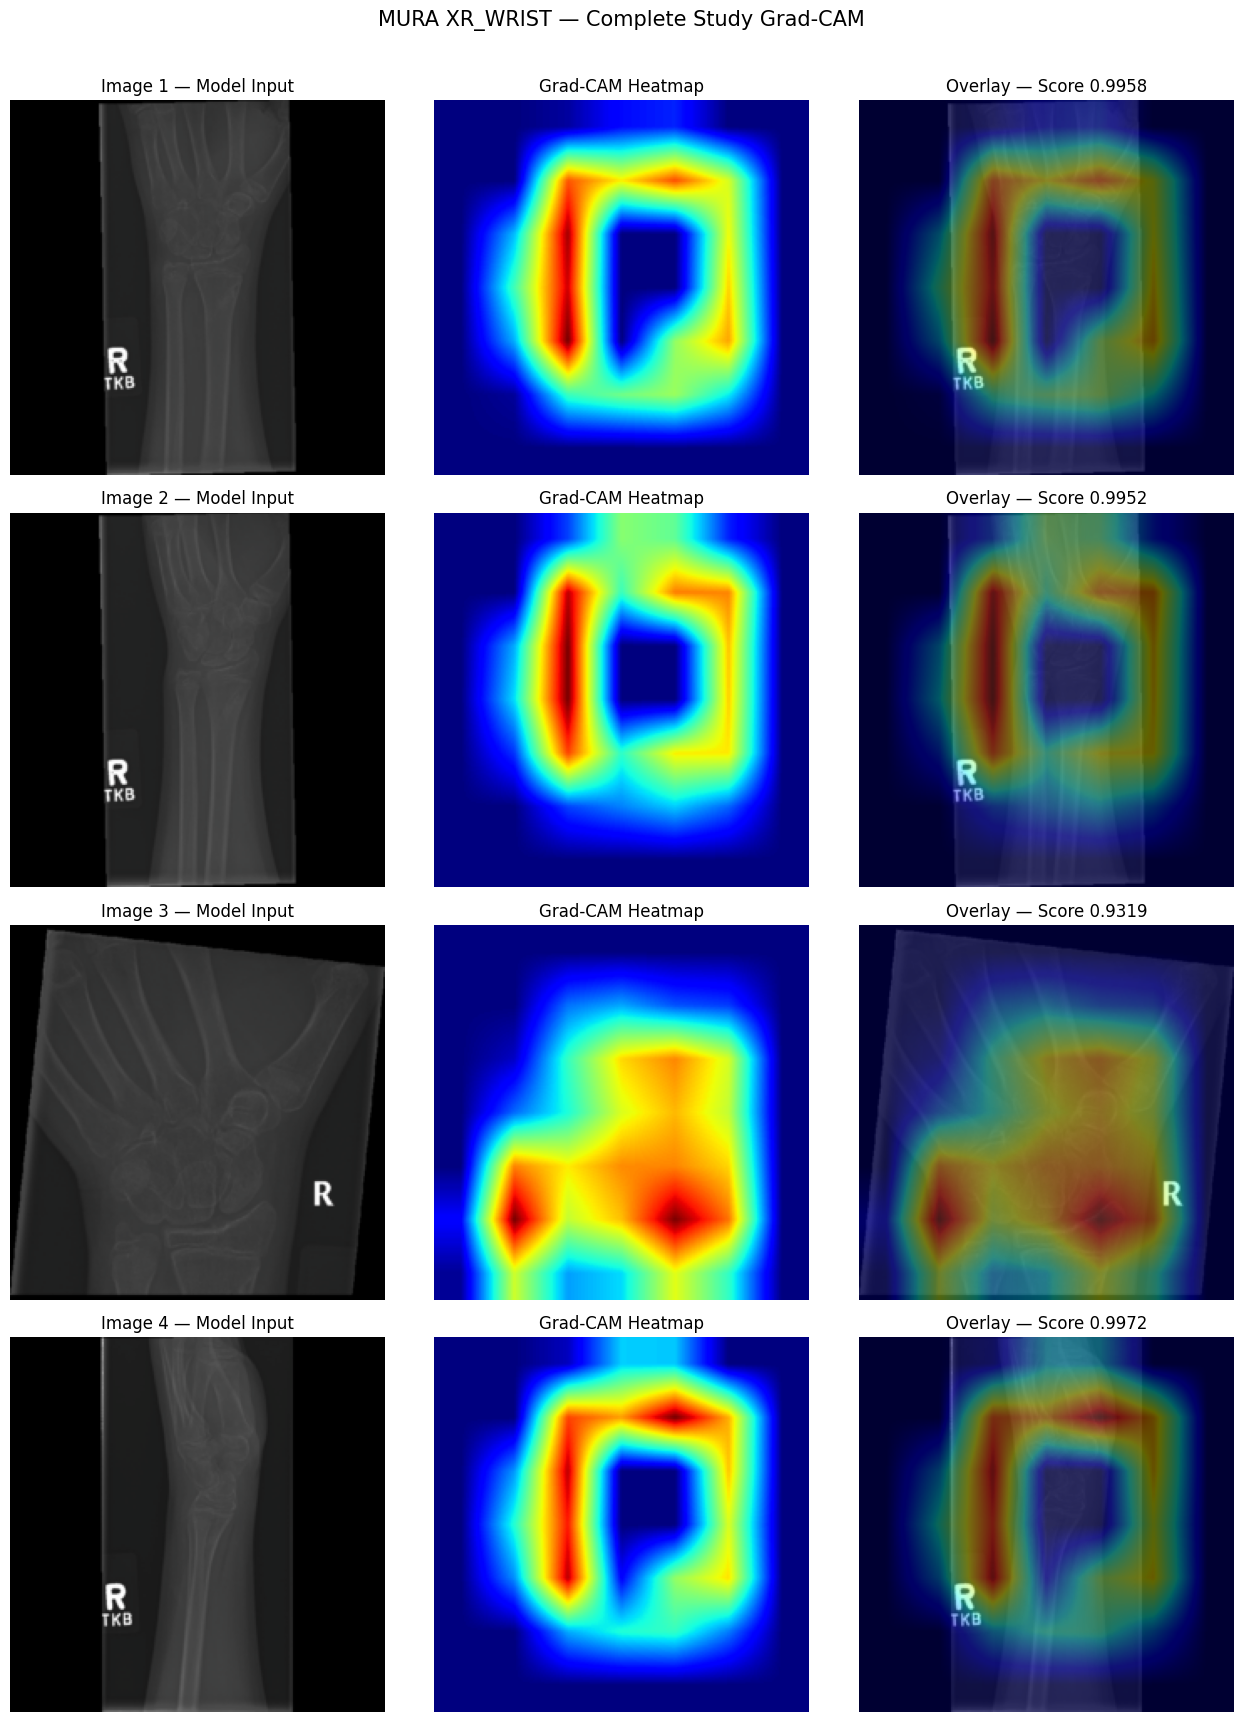


VISUALIZATION VERIFICATION
Images displayed: 4
Model preprocessing geometry: PRESERVED
Heatmap alignment: VERIFIED
Additional inference: NONE
Original classification: UNCHANGED

STEP 45F: PASSED


In [63]:

# STEP 45F — COMPLETE STUDY GRAD-CAM VISUALIZATION
# Display only — no model inference or Grad-CAM recomputation.

import io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("STEP 45F — GRAD-CAM VISUALIZATION")
print("=" * 70)

assert len(study_gradcam_results) == 4
assert len(integration_images) == 4
assert inference_transform.train is False
assert inference_transform.image_size == 224

# Match results by image ID.
gradcam_by_id = {
    result["image_id"]: result
    for result in study_gradcam_results
}

assert len(gradcam_by_id) == len(integration_images)

gradcam_display_items = []

for image in integration_images:

    image_id = image["image_id"]
    result = gradcam_by_id[image_id]

    assert result["status"] == "SUCCESS"

    # Decode original radiograph.
    with Image.open(io.BytesIO(image["image_bytes"])) as source:
        original_image = source.convert("L")

    # Apply the validated evaluation transform.
    # This preserves the exact padding and resizing geometry.
    processed_tensor = inference_transform(original_image)

    assert tuple(processed_tensor.shape) == (3, 224, 224)

    # Reverse ImageNet normalization for display.
    mean = np.asarray(inference_transform.mean).reshape(3, 1, 1)
    std = np.asarray(inference_transform.std).reshape(3, 1, 1)

    processed_array = processed_tensor.detach().cpu().numpy()

    display_rgb = processed_array * std + mean
    display_rgb = np.clip(display_rgb, 0.0, 1.0)
    display_rgb = np.transpose(display_rgb, (1, 2, 0))

    heatmap = np.asarray(result["heatmap"], dtype=np.float32)

    assert heatmap.shape == (224, 224)
    assert np.isfinite(heatmap).all()
    assert np.min(heatmap) >= 0.0
    assert np.max(heatmap) <= 1.0

    gradcam_display_items.append({
        "image_id": image_id,
        "image": display_rgb,
        "heatmap": heatmap.copy(),
        "probability": float(result["probability"])
    })

# ------------------------------------------------------------
# Display all four images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(13, 17)
)

for row, item in enumerate(gradcam_display_items):

    image_rgb = item["image"]
    heatmap = item["heatmap"]

    # Column 1 — Model input geometry
    axes[row, 0].imshow(image_rgb)
    axes[row, 0].set_title(
        f"Image {row + 1} — Model Input"
    )

    # Column 2 — Grad-CAM heatmap
    axes[row, 1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title("Grad-CAM Heatmap")

    # Column 3 — Aligned overlay
    axes[row, 2].imshow(image_rgb)
    axes[row, 2].imshow(
        heatmap,
        cmap="jet",
        alpha=0.40,
        vmin=0,
        vmax=1
    )
    axes[row, 2].set_title(
        f"Overlay — Score {item['probability']:.4f}"
    )

    for col in range(3):
        axes[row, col].axis("off")

plt.suptitle(
    "MURA XR_WRIST — Complete Study Grad-CAM",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

print("\nVISUALIZATION VERIFICATION")
print("Images displayed:", len(gradcam_display_items))
print("Model preprocessing geometry: PRESERVED")
print("Heatmap alignment: VERIFIED")
print("Additional inference: NONE")
print("Original classification: UNCHANGED")

print("\nSTEP 45F: PASSED")


## Final Execution and Verification Status

**Step 45: COMPLETED — ALL VERIFICATION CHECKS PASSED**

- Steps 45A–45C: Grad-CAM interface, configuration, and target layer verified.
- Step 45D: Grad-CAM successfully executed for all four study images. All image-level probabilities matched the original frozen Model B predictions exactly.
- Step 45E: Aspect-preserving preprocessing geometry verified.
- Step 45F: All four radiographs, heatmaps, and spatially aligned overlays successfully displayed.

Model parameters, buffers, classification threshold, original Agent result, and structured research report remained unchanged.

**Visual observation:** Several heatmaps emphasize broad image regions, including areas near image boundaries. These patterns require cautious interpretation and do not constitute validated anatomical localization.

**Conclusion:** Complete-study Grad-CAM execution, technical verification, and visualization were successfully completed. PNG export and structured report integration remain pending. Automatic Agent-controlled Grad-CAM invocation has not yet been implemented.

# Step 46 — Grad-CAM Artifact Saving and Report Integration

## Objective

Save the validated Grad-CAM heatmaps generated in Step 45 as PNG artifacts and integrate their metadata into a copy of the structured MURA Agent research report.

Preserve the original frozen Model B classification, selected threshold, Agent workflow decision, and all previously available research explanations.

No additional model inference or Grad-CAM computation is required.

## Background

- Steps 24–28 established and validated the saved Grad-CAM implementation.
- Step 34 established the canonical MURA XR_WRIST Agent integration study.
- Steps 38–39 established structured Agent research reporting.
- Step 40 integrates supplementary study-level TTA findings.
- Step 45 generates and verifies Grad-CAM explanations for every image in the canonical study.

Step 46 stores the Grad-CAM visualization artifacts and adds traceable references to the structured research report.

Grad-CAM remains supplementary research information and does not alter the frozen classification or Agent workflow.

## Inputs

- `integration_images` — original study image identifiers and image bytes.
- `integration_agent_result` — frozen Agent workflow output.
- `study_gradcam_results` — validated Grad-CAM results from Step 45.
- `gradcam_summary_df` — image-level verification summary.
- `SELECTED_THRESHOLD` — frozen classification threshold.
- `AGENT_DIR` — project directory.
- Existing structured Agent research report, optionally containing TTA explanations.

## Methodology

### 1. Validate Grad-CAM Results

Verify that every study image has exactly one validated Grad-CAM result.

Match image identifiers independently of image ordering.

Verify that all heatmaps:

- Have dimensions 224 × 224.
- Contain finite values within [0, 1].
- Correspond to the original image identifiers.
- Have Grad-CAM probabilities matching the original frozen Model B image predictions within `1e-5`.

### 2. Create the Explanation Directory

Create a dedicated study directory under:

`MURA_AGENTIC_AI/explanations/<study_id>/`

Use safe, stable filenames derived from the original image identifiers.

### 3. Save Heatmaps as PNG Files

Convert each normalized numerical heatmap to an 8-bit grayscale PNG.

Verify that every saved file exists, can be reopened, and has dimensions 224 × 224.

The original numerical heatmaps remain unchanged in `study_gradcam_results`.

### 4. Create Image-Level Explanation Records

Each record must include:

- Image identifier.
- Original frozen classifier probability.
- Grad-CAM probability.
- Absolute probability difference.
- Heatmap file path.
- Heatmap dimensions.
- Explanation method.
- Research-use-only designation.

### 5. Extend the Research Report

Create a deep copy of the existing structured Agent report.

Add a `gradcam_explanations` section containing the validated image-level explanation records.

Preserve every existing report field, including the original classification, Agent action, research limitations, and any available TTA explanations.

Do not modify the original report.

### 6. Verify Report Integrity

Confirm that:

- All study images are represented.
- All referenced PNG files exist and have the correct dimensions.
- The original frozen study probability and predicted class remain unchanged.
- The Agent workflow decision remains unchanged.
- The selected classification threshold remains unchanged.
- Existing TTA explanations remain unchanged.
- The extended report is JSON serializable with finite numerical values.
- No ground-truth labels are introduced.
- No additional model inference is performed.

## Outputs

- `gradcam_explanations` — image-level Grad-CAM metadata records.
- `gradcam_extended_report` — structured report containing Grad-CAM references.
- Saved 224 × 224 PNG heatmaps in the study explanation directory.

## Acceptance Criteria

1. Every study image has one saved Grad-CAM heatmap.
2. All saved PNG files have dimensions 224 × 224.
3. Heatmaps contain valid normalized numerical values before conversion.
4. Image identifiers and filenames are traceable.
5. Grad-CAM probabilities agree with frozen image-level predictions within `1e-5`.
6. All explanation records are included in the extended report.
7. Every referenced PNG file exists and is readable.
8. The original frozen classification is unchanged.
9. The Agent workflow decision is unchanged.
10. Existing research explanations remain unchanged.
11. The selected threshold remains unchanged.
12. The original Agent and report variables remain unchanged.
13. The extended report is JSON serializable.
14. No ground-truth labels are used.
15. No additional model inference is performed.

## Scientific Interpretation

The extended report links the frozen study classification to image-level Grad-CAM visualization artifacts.

The PNG files support research review and traceability without embedding full numerical heatmap arrays in the JSON report.

Successful integration demonstrates technical consistency and artifact integrity, not diagnostic validity.

## Scientific Limitations

- Grad-CAM is not a validated fracture-localization or lesion-segmentation method.
- Highlighted regions do not establish the presence or location of pathology.
- Heatmap intensity does not represent calibrated pathology probability.
- Conversion to 8-bit PNG introduces quantization.
- Results from one study do not establish generalizability.
- The prespecified sensitivity target of at least 95% was not achieved on the official held-out validation set.
- Grad-CAM must not modify the frozen classifier output or Agent workflow decision.

## Next Stage

Export the complete structured Agent research report as JSON, verify its saved contents, and preserve references to the Grad-CAM artifacts.

Automatic Agent-controlled invocation of TTA and Grad-CAM will be developed and evaluated separately.

STEP 46 — GRAD-CAM ARTIFACTS AND REPORT INTEGRATION

CANONICAL STUDY
Study ID: valid/XR_WRIST/patient11185/study1_positive
Images: 4
Source report: tta_extended_report
Study-level TTA explanation: PRESENT

ORIGINAL PREDICTIONS
Image identifiers: VERIFIED
Original probabilities: VERIFIED

GRAD-CAM VALIDATION
Study coverage: VERIFIED
Heatmap dimensions: VERIFIED
Heatmap numerical range: VERIFIED

ARTIFACT DIRECTORY
/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/explanations/valid_XR_WRIST_patient11185_study1_positive
Saved and verified: image1_ffe9b1be693b1105_gradcam.png
Saved and verified: image2_437572aca1b3986d_gradcam.png
Saved and verified: image3_d3c1a09c8264b075_gradcam.png
Saved and verified: image4_b753d6d36f23861a_gradcam.png

JSON VERIFICATION
Serialization: PASSED
Round-trip consistency: PASSED

INPUT INTEGRITY
Original report: UNCHANGED
Original TTA report: UNCHANGED
Original 

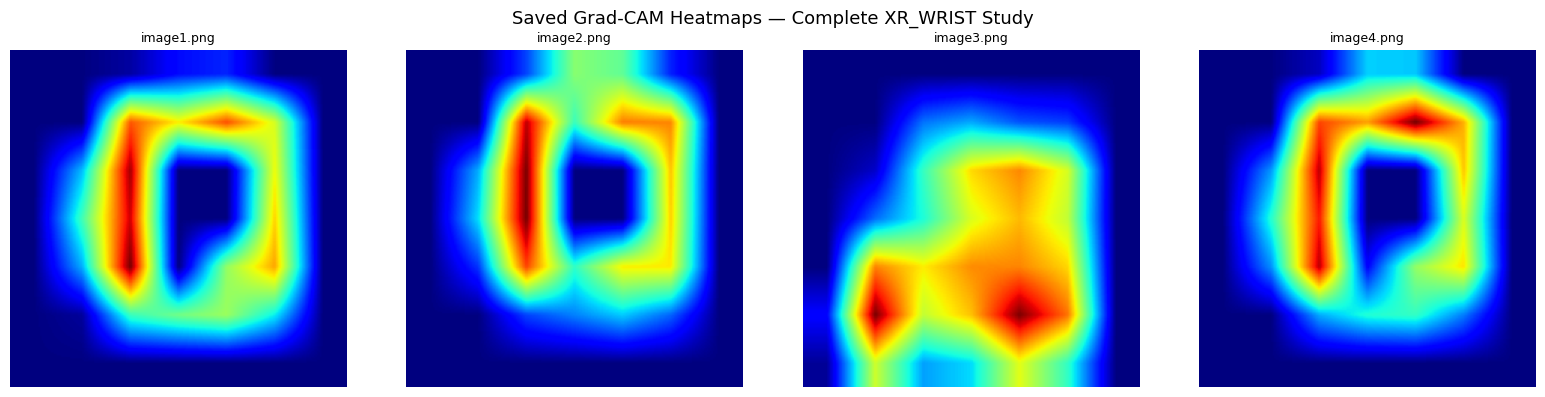


STEP 46 — FINAL VERIFICATION SUMMARY
----------------------------------------------------------------------
Study ID: valid/XR_WRIST/patient11185/study1_positive
Study images: 4
Saved PNG heatmaps: 4
Grad-CAM explanation records: 4
TTA explanation preserved: VERIFIED
Original classification: PRESERVED
Original Agent workflow: PRESERVED
Original research report: PRESERVED
Original Grad-CAM results: PRESERVED
Frozen model state: PRESERVED
Frozen threshold: PRESERVED
JSON serialization: VERIFIED
PNG SHA-256 integrity: VERIFIED
Additional model inference: NONE
Research use only: TRUE

STEP 46: PASSED


In [64]:

# ============================================================
# NOTEBOOK 09 — STEP 46
# GRAD-CAM ARTIFACT SAVING AND REPORT INTEGRATION
# ============================================================
#
# Save validated Grad-CAM heatmaps as PNG files and attach
# artifact references to a copy of the structured research
# report, preserving the existing TTA explanation.
#
# No model inference or Grad-CAM recomputation is performed.
# ============================================================

import copy
import json
import math
import re
import hashlib
from pathlib import Path
from unittest.mock import patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from PIL import Image

print("STEP 46 — GRAD-CAM ARTIFACTS AND REPORT INTEGRATION")
print("=" * 72)


# ------------------------------------------------------------
# 0. Configuration and canonical inputs
# ------------------------------------------------------------

source_report = tta_extended_report

assert isinstance(source_report, dict)
assert isinstance(integration_agent_result, dict)
assert isinstance(integration_images, list)
assert isinstance(study_gradcam_results, list)

assert len(integration_images) == 4
assert len(study_gradcam_results) == 4

assert integration_agent_result["workflow_status"] == "COMPLETED"
assert integration_agent_result["classification_status"] == "COMPLETED"
assert integration_agent_result["classification_valid"] is True
assert integration_agent_result["classification_performed"] is True
assert integration_agent_result["classification_modified"] is False

study_id = str(integration_agent_result["study_id"])

assert source_report["study_information"]["study_id"] == study_id
assert source_report["study_information"]["image_count"] == len(integration_images)

assert "study_tta_explanation" in source_report
assert "gradcam_explanations" not in source_report

assert source_report["workflow"]["status"] == "COMPLETED"

assert resnet18_model.training is False

print("\nCANONICAL STUDY")
print("Study ID:", study_id)
print("Images:", len(integration_images))
print("Source report: tta_extended_report")
print("Study-level TTA explanation: PRESENT")


# ------------------------------------------------------------
# 1. Snapshot original research state
# ------------------------------------------------------------

source_report_before = copy.deepcopy(source_report)
original_report_before = copy.deepcopy(original_report)
agent_result_before = copy.deepcopy(integration_agent_result)

# Grad-CAM results contain NumPy arrays, so a deep copy is
# required to verify that the numerical heatmaps are unchanged.
gradcam_results_before = copy.deepcopy(study_gradcam_results)

threshold_before = float(SELECTED_THRESHOLD)

study_probability_before = float(
    integration_agent_result["study_probability"]
)

predicted_class_before = copy.deepcopy(
    integration_agent_result["predicted_class"]
)

agent_action_before = copy.deepcopy(
    integration_agent_result["agent_action"]
)

model_training_before = resnet18_model.training

model_state_before = {
    name: tensor.detach().clone()
    for name, tensor in resnet18_model.state_dict().items()
}

# Preserve the original parameter gradient state as well.
parameter_gradients_before = {
    name: (
        None if parameter.grad is None
        else parameter.grad.detach().clone()
    )
    for name, parameter in resnet18_model.named_parameters()
}


# ------------------------------------------------------------
# 2. Validate original image-level predictions
# ------------------------------------------------------------

original_predictions = integration_agent_result[
    "image_predictions"
]

assert isinstance(original_predictions, list)
assert len(original_predictions) == len(integration_images)

original_probability_by_id = {}

for prediction in original_predictions:

    image_id = prediction["image_id"]
    probability = float(prediction["probability"])

    assert image_id not in original_probability_by_id
    assert math.isfinite(probability)
    assert 0.0 <= probability <= 1.0

    original_probability_by_id[image_id] = probability

expected_image_ids = [
    image["image_id"]
    for image in integration_images
]

assert len(expected_image_ids) == len(set(expected_image_ids))
assert set(original_probability_by_id) == set(expected_image_ids)

print("\nORIGINAL PREDICTIONS")
print("Image identifiers: VERIFIED")
print("Original probabilities: VERIFIED")


# ------------------------------------------------------------
# 3. Validate Grad-CAM results and coverage
# ------------------------------------------------------------

gradcam_by_id = {}

for result in study_gradcam_results:

    assert result["status"] == "SUCCESS"
    assert result["classification_modified"] is False

    image_id = result["image_id"]

    assert image_id not in gradcam_by_id

    heatmap = np.asarray(result["heatmap"])

    assert heatmap.shape == (224, 224)
    assert np.issubdtype(heatmap.dtype, np.number)
    assert np.isfinite(heatmap).all()
    assert float(heatmap.min()) >= 0.0
    assert float(heatmap.max()) <= 1.0

    assert tuple(result["heatmap_shape"]) == (224, 224)

    probability = float(result["probability"])
    assert math.isfinite(probability)
    assert 0.0 <= probability <= 1.0

    gradcam_by_id[image_id] = result

assert set(gradcam_by_id) == set(expected_image_ids)

print("\nGRAD-CAM VALIDATION")
print("Study coverage: VERIFIED")
print("Heatmap dimensions: VERIFIED")
print("Heatmap numerical range: VERIFIED")


# ------------------------------------------------------------
# 4. Prepare safe study artifact directory
# ------------------------------------------------------------

safe_study_id = re.sub(
    r"[^A-Za-z0-9_.-]",
    "_",
    study_id
).strip("._")

assert safe_study_id, "Invalid study identifier."

explanation_dir = (
    Path(AGENT_DIR)
    / "explanations"
    / safe_study_id
)

# Ensure the output stays within the intended project folder.
agent_root = Path(AGENT_DIR).resolve()
resolved_explanation_dir = explanation_dir.resolve()

assert resolved_explanation_dir.is_relative_to(agent_root)

explanation_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("\nARTIFACT DIRECTORY")
print(explanation_dir)


# ------------------------------------------------------------
# 5. Save and verify Grad-CAM PNG artifacts
# ------------------------------------------------------------

gradcam_explanations = []
gradcam_artifact_records = []
saved_heatmap_paths = []

# Explicitly prohibit model forward calls during artifact
# saving and report construction.
with patch.object(
    resnet18_model,
    "forward",
    side_effect=AssertionError(
        "Step 46 must not perform model inference."
    )
):

    for image_id in expected_image_ids:

        result = gradcam_by_id[image_id]

        heatmap = np.asarray(
            result["heatmap"],
            dtype=np.float32
        )

        assert heatmap.shape == (224, 224)
        assert np.isfinite(heatmap).all()
        assert float(heatmap.min()) >= 0.0
        assert float(heatmap.max()) <= 1.0

        original_probability = original_probability_by_id[
            image_id
        ]

        gradcam_probability = float(
            result["probability"]
        )

        probability_difference = abs(
            gradcam_probability - original_probability
        )

        assert probability_difference < 1e-5, (
            f"Grad-CAM probability mismatch: {image_id}"
        )

        # Stable, collision-resistant filename.
        safe_image_name = re.sub(
            r"[^A-Za-z0-9_.-]",
            "_",
            Path(str(image_id)).stem
        ).strip("._")[:80] or "image"

        image_hash = hashlib.sha256(
            str(image_id).encode("utf-8")
        ).hexdigest()[:16]

        filename = (
            f"{safe_image_name}_"
            f"{image_hash}_gradcam.png"
        )

        heatmap_path = explanation_dir / filename

        # Quantize normalized heatmap to 8-bit grayscale.
        heatmap_uint8 = np.rint(
            heatmap * 255.0
        ).astype(np.uint8)

        Image.fromarray(
    heatmap_uint8
).save(
    heatmap_path,
    format="PNG"
)

        assert heatmap_path.is_file()

        # Reopen the saved file and verify exact pixel data.
        with Image.open(heatmap_path) as saved_image:

            assert saved_image.format == "PNG"
            assert saved_image.mode == "L"
            assert saved_image.size == (224, 224)

            reloaded_heatmap = np.asarray(
                saved_image,
                dtype=np.uint8
            ).copy()

        assert np.array_equal(
            reloaded_heatmap,
            heatmap_uint8
        )

        # Verify that quantization stays within one 8-bit step.
        quantization_error = float(
            np.max(
                np.abs(
                    heatmap
                    - reloaded_heatmap.astype(np.float32) / 255.0
                )
            )
        )

        assert quantization_error <= (1.0 / 255.0 + 1e-7)

        # Store portable path relative to project root.
        relative_heatmap_path = str(
            heatmap_path.relative_to(Path(AGENT_DIR))
        )

        # SHA-256 enables later file-integrity verification.
        png_sha256 = hashlib.sha256(
            heatmap_path.read_bytes()
        ).hexdigest()

        explanation_record = {
            "image_id": image_id,
            "explanation_method": "Grad-CAM",
            "research_use_only": True,
            "original_probability": original_probability,
            "gradcam_probability": gradcam_probability,
            "absolute_probability_difference": (
                probability_difference
            ),
            "heatmap_path": relative_heatmap_path,
            "heatmap_shape": [224, 224],
            "heatmap_format": "PNG",
            "heatmap_type": "normalized_grayscale_uint8",
            "heatmap_sha256": png_sha256,
            "interpretation": (
                "Grad-CAM provides a qualitative visualization "
                "of regions influencing the frozen model output. "
                "It does not establish lesion localization, "
                "clinical validity, or diagnostic correctness."
            )
        }

        gradcam_explanations.append(
            explanation_record
        )

        gradcam_artifact_records.append({
            "image_id": image_id,
            "heatmap_path": str(heatmap_path),
            "heatmap_shape": [224, 224],
            "heatmap_format": "PNG",
            "heatmap_sha256": png_sha256
        })

        saved_heatmap_paths.append(
            str(heatmap_path)
        )

        print("Saved and verified:", filename)

    # --------------------------------------------------------
    # 6. Extend a COPY of the structured research report
    # --------------------------------------------------------

    gradcam_extended_report = copy.deepcopy(
        source_report
    )

    gradcam_extended_report[
        "gradcam_explanations"
    ] = copy.deepcopy(gradcam_explanations)


# ------------------------------------------------------------
# 7. Verify extended report integrity
# ------------------------------------------------------------

assert (
    gradcam_extended_report["study_information"]["study_id"]
    == study_id
)

assert (
    gradcam_extended_report["study_information"]["image_count"]
    == len(integration_images)
)

assert len(
    gradcam_extended_report["gradcam_explanations"]
) == len(integration_images)

# Every existing report field must be preserved.
for key, value in source_report_before.items():

    assert gradcam_extended_report[key] == value, (
        f"Existing report field changed: {key}"
    )

assert (
    gradcam_extended_report["study_tta_explanation"]
    == source_report_before["study_tta_explanation"]
)

# Check each referenced PNG and its SHA-256 checksum.
for record in gradcam_extended_report[
    "gradcam_explanations"
]:

    referenced_path = (
        Path(AGENT_DIR) / record["heatmap_path"]
    )

    assert referenced_path.is_file()

    with Image.open(referenced_path) as saved_image:
        assert saved_image.format == "PNG"
        assert saved_image.mode == "L"
        assert saved_image.size == (224, 224)

    actual_sha256 = hashlib.sha256(
        referenced_path.read_bytes()
    ).hexdigest()

    assert actual_sha256 == record["heatmap_sha256"]
    assert record["research_use_only"] is True


# ------------------------------------------------------------
# 8. Verify JSON serialization
# ------------------------------------------------------------

serialized_report = json.dumps(
    gradcam_extended_report,
    ensure_ascii=False,
    indent=2,
    allow_nan=False
)

assert isinstance(serialized_report, str)

# Round-trip verification.
reloaded_report = json.loads(serialized_report)

assert reloaded_report == gradcam_extended_report

print("\nJSON VERIFICATION")
print("Serialization: PASSED")
print("Round-trip consistency: PASSED")


# ------------------------------------------------------------
# 9. Verify original inputs remain unchanged
# ------------------------------------------------------------

assert source_report == source_report_before
assert original_report == original_report_before
assert integration_agent_result == agent_result_before

assert float(SELECTED_THRESHOLD) == threshold_before

assert (
    float(integration_agent_result["study_probability"])
    == study_probability_before
)

assert (
    integration_agent_result["predicted_class"]
    == predicted_class_before
)

assert (
    integration_agent_result["agent_action"]
    == agent_action_before
)

assert resnet18_model.training == model_training_before

# Verify every model parameter and buffer.
current_model_state = resnet18_model.state_dict()

assert set(current_model_state) == set(model_state_before)

for name, original_tensor in model_state_before.items():

    assert torch.equal(
        current_model_state[name].detach(),
        original_tensor
    ), f"Frozen model state changed: {name}"

# Verify model parameter gradients were not modified.
for name, parameter in resnet18_model.named_parameters():

    original_gradient = parameter_gradients_before[name]

    if original_gradient is None:
        assert parameter.grad is None
    else:
        assert parameter.grad is not None
        assert torch.equal(
            parameter.grad.detach(),
            original_gradient
        )

# Verify the original numerical Grad-CAM outputs.
assert len(study_gradcam_results) == len(
    gradcam_results_before
)

for current, original in zip(
    study_gradcam_results,
    gradcam_results_before
):

    assert current.keys() == original.keys()

    for key in current:

        if isinstance(current[key], np.ndarray):

            assert np.array_equal(
                current[key],
                original[key]
            )

        else:

            assert current[key] == original[key]

print("\nINPUT INTEGRITY")
print("Original report: UNCHANGED")
print("Original TTA report: UNCHANGED")
print("Original Agent result: UNCHANGED")
print("Original Grad-CAM results: UNCHANGED")
print("Model parameters and buffers: UNCHANGED")
print("Model parameter gradients: UNCHANGED")
print("Frozen threshold: PRESERVED")
print("Original classification: PRESERVED")
print("Agent action: PRESERVED")


# ------------------------------------------------------------
# 10. Display saved PNG heatmaps
# ------------------------------------------------------------

image_count = len(gradcam_artifact_records)

fig, axes = plt.subplots(
    1,
    image_count,
    figsize=(4 * image_count, 4),
    squeeze=False
)

for ax, record in zip(
    axes[0],
    gradcam_artifact_records
):

    heatmap_path = Path(record["heatmap_path"])

    with Image.open(heatmap_path) as image:

        saved_heatmap = np.asarray(
            image.convert("L"),
            dtype=np.uint8
        ).copy()

    ax.imshow(
        saved_heatmap,
        cmap="jet",
        vmin=0,
        vmax=255
    )

    ax.set_title(
        Path(str(record["image_id"])).name,
        fontsize=9
    )

    ax.axis("off")

plt.suptitle(
    "Saved Grad-CAM Heatmaps — Complete XR_WRIST Study",
    fontsize=13
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Final verification summary
# ------------------------------------------------------------

print("\nSTEP 46 — FINAL VERIFICATION SUMMARY")
print("-" * 70)

print("Study ID:", study_id)
print("Study images:", len(integration_images))
print("Saved PNG heatmaps:", len(saved_heatmap_paths))
print("Grad-CAM explanation records:", len(gradcam_explanations))
print("TTA explanation preserved: VERIFIED")
print("Original classification: PRESERVED")
print("Original Agent workflow: PRESERVED")
print("Original research report: PRESERVED")
print("Original Grad-CAM results: PRESERVED")
print("Frozen model state: PRESERVED")
print("Frozen threshold: PRESERVED")
print("JSON serialization: VERIFIED")
print("PNG SHA-256 integrity: VERIFIED")
print("Additional model inference: NONE")
print("Research use only: TRUE")

print("\nSTEP 46: PASSED")


# Step 47 — Save and Verify the Complete Agent Research Report

## Objective

Export the complete structured MURA Agent research report as a reusable JSON artifact and verify its integrity after saving and reloading.

The exported report preserves the frozen Model B study classification, deterministic Agent workflow decision, available TTA explanations, and Grad-CAM visualization references.

No additional model inference or explanation generation is performed.

## Background

The preceding steps established the research reporting workflow:

- **Step 34:** Canonical frozen classifier and Agent integration study.
- **Steps 38–39:** Structured research report generation and module packaging.
- **Step 40:** Study-level TTA integration and reporting.
- **Step 45:** Complete-study Grad-CAM execution and verification.
- **Step 46:** Grad-CAM artifact saving and structured report integration.

Step 47 exports the combined research report to the project's reports directory and verifies that the saved artifact is consistent with the validated in-memory report.

The exported artifact is intended for research use only and is not a clinical diagnostic document.

## Inputs

- `gradcam_extended_report` — combined structured research report from Step 46.
- `gradcam_explanations` — validated Grad-CAM explanation records.
- `integration_agent_result` — original frozen Agent workflow output.
- `integration_images` — original study images.
- `SELECTED_THRESHOLD` — frozen classification threshold.
- `REPORT_DIR` — project reports directory.
- `AGENT_DIR` — project directory containing Grad-CAM artifacts.
- `resnet18_model` — frozen Model B classifier, used for integrity verification only.

## Methodology

### 1. Validate the In-Memory Report

Verify that:

- The report corresponds to the canonical integration study.
- The study image count is correct.
- The original classification and Agent workflow results are preserved.
- Every study image has one Grad-CAM explanation record.
- All referenced Grad-CAM PNG files exist and have dimensions 224 × 224.
- All available TTA sections are retained.
- Research-use-only restrictions and scientific limitations are preserved.

### 2. Prepare the Report Directory

Use the existing `REPORT_DIR` directory.

Generate a stable and filesystem-safe filename from the canonical study identifier.

### 3. Export the Complete JSON Report

Serialize the combined report using standard JSON formatting.

Use indentation for readability and reject non-finite numerical values.

Do not embed numerical Grad-CAM heatmaps or image bytes in the JSON.

Do not overwrite the original notebook report variables.

### 4. Reload and Verify the Saved Artifact

Reload the saved JSON and verify:

- Successful JSON parsing.
- Exact agreement with the serialized in-memory report.
- Correct study identification and image count.
- Preservation of the original classification and Agent workflow information.
- Preservation of all available TTA explanations.
- Complete Grad-CAM explanation coverage.
- Accessibility and dimensions of referenced heatmap files.
- Preservation of research limitations and research-use-only restrictions.

### 5. Verify Frozen Model and Workflow Integrity

Confirm that:

- The frozen Model B parameters and buffers remain unchanged.
- The model remains in evaluation mode.
- The selected classification threshold remains unchanged.
- The original study probability and predicted class remain unchanged.
- The original Agent workflow action remains unchanged.
- The in-memory research report remains unchanged.
- No additional model inference is performed.

## Outputs

- `saved_agent_report_path` — path to the exported JSON report.
- `reloaded_agent_report` — parsed report reloaded from disk.

The Grad-CAM heatmaps remain stored separately under the project explanations directory.

## Acceptance Criteria

1. The complete JSON report is saved successfully.
2. The saved file can be reopened and parsed.
3. The reloaded report matches the serialized in-memory report.
4. Study identification and image count are correct.
5. Technical QC and anatomical scope results are preserved.
6. Frozen classification probability and predicted class remain unchanged.
7. Agent workflow status and action remain unchanged.
8. All available TTA explanations are preserved.
9. Every study image has one Grad-CAM explanation record.
10. All referenced Grad-CAM PNG files exist and have dimensions 224 × 224.
11. Research-use-only designation and scientific limitations are preserved.
12. No ground-truth diagnosis or label is introduced.
13. Frozen model parameters, buffers, and selected threshold remain unchanged.
14. Original Agent and report variables remain unchanged.
15. No additional model inference is performed.

## Scientific Interpretation

The exported JSON artifact provides a reusable structured record of the frozen classification, deterministic Agent workflow, and supplementary research explanations.

Separating Grad-CAM visualization files from the JSON supports traceability and subsequent research review.

Successful export demonstrates technical artifact integrity and consistency within the current project environment.

It does not establish clinical validity or diagnostic correctness.

## Scientific Limitations

- The MURA Agent is a research prototype and is not intended for clinical diagnosis or autonomous patient triage.
- The frozen classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.
- TTA measures sensitivity to selected image transformations and is not a calibrated clinical uncertainty measure.
- Grad-CAM is not a validated fracture-localization or lesion-segmentation method.
- Heatmap intensity is not a calibrated probability of pathology.
- The report does not establish diagnostic correctness.
- Results from one integration study do not establish generalizability.
- Grad-CAM file paths may require adjustment when the project is moved to another environment.

## Next Stage

Review the complete Agent workflow and implement explicit Agent-controlled invocation policies for TTA and Grad-CAM.

Evaluate tool invocation, skipping behavior, execution limits, and preservation of frozen classifier outputs.

Perform a clean notebook execution to verify reproducibility.

In [65]:

# ============================================================
# NOTEBOOK 09 — STEP 47
# SAVE AND VERIFY THE COMPLETE AGENT RESEARCH REPORT
# ============================================================
#
# Export the validated combined report to JSON.
# Reload the saved artifact and verify its integrity.
#
# No model inference, TTA, or Grad-CAM computation.
# ============================================================

import copy
import json
import math
import hashlib
import re
from pathlib import Path
from unittest.mock import patch

import numpy as np
import torch
from PIL import Image

print("STEP 47 — FINAL AGENT RESEARCH REPORT EXPORT")
print("=" * 72)


# ------------------------------------------------------------
# 0. Validate canonical inputs
# ------------------------------------------------------------

assert isinstance(gradcam_extended_report, dict)
assert isinstance(gradcam_explanations, list)
assert isinstance(integration_agent_result, dict)
assert isinstance(integration_images, list)

assert len(integration_images) == 4
assert len(gradcam_explanations) == len(integration_images)

study_id = str(integration_agent_result["study_id"])

assert (
    gradcam_extended_report["study_information"]["study_id"]
    == study_id
)

assert (
    gradcam_extended_report["study_information"]["image_count"]
    == len(integration_images)
)

required_sections = {
    "study_information",
    "classification",
    "agent_decision",
    "workflow",
    "technical_qc",
    "anatomical_scope",
    "limitations",
    "research_use_only",
    "study_tta_explanation",
    "gradcam_explanations"
}

assert required_sections.issubset(
    gradcam_extended_report.keys()
)

assert gradcam_extended_report["research_use_only"] is True
assert gradcam_extended_report["limitations"]

assert integration_agent_result["workflow_status"] == "COMPLETED"
assert integration_agent_result["classification_status"] == "COMPLETED"

print("\nREPORT STRUCTURE")
print("Study:", study_id)
print("Required sections: VERIFIED")
print("TTA explanation: PRESENT")
print("Grad-CAM explanations:", len(gradcam_explanations))


# ------------------------------------------------------------
# 1. Snapshot original research and model state
# ------------------------------------------------------------

report_before = copy.deepcopy(gradcam_extended_report)
tta_report_before = copy.deepcopy(tta_extended_report)
original_report_before = copy.deepcopy(original_report)
agent_result_before = copy.deepcopy(integration_agent_result)

threshold_before = float(SELECTED_THRESHOLD)

study_probability_before = float(
    integration_agent_result["study_probability"]
)

predicted_class_before = copy.deepcopy(
    integration_agent_result["predicted_class"]
)

agent_action_before = copy.deepcopy(
    integration_agent_result["agent_action"]
)

model_training_before = resnet18_model.training

assert model_training_before is False

model_state_before = {
    name: tensor.detach().clone()
    for name, tensor in resnet18_model.state_dict().items()
}


# ------------------------------------------------------------
# 2. Validate image identifiers and Grad-CAM references
# ------------------------------------------------------------

expected_image_ids = [
    image["image_id"]
    for image in integration_images
]

assert len(expected_image_ids) == len(set(expected_image_ids))

report_records = gradcam_extended_report[
    "gradcam_explanations"
]

assert len(report_records) == len(expected_image_ids)

record_ids = [
    record["image_id"]
    for record in report_records
]

assert len(record_ids) == len(set(record_ids))
assert set(record_ids) == set(expected_image_ids)

assert report_records == gradcam_explanations

original_probability_by_id = {
    prediction["image_id"]: float(prediction["probability"])
    for prediction in integration_agent_result["image_predictions"]
}

assert set(original_probability_by_id) == set(expected_image_ids)

agent_root = Path(AGENT_DIR).resolve()

for record in report_records:

    image_id = record["image_id"]

    assert record["research_use_only"] is True
    assert record["explanation_method"] == "Grad-CAM"

    assert (
        abs(
            float(record["original_probability"])
            - original_probability_by_id[image_id]
        ) < 1e-5
    )

    assert (
        abs(
            float(record["gradcam_probability"])
            - original_probability_by_id[image_id]
        ) < 1e-5
    )

    relative_path = Path(record["heatmap_path"])

    assert not relative_path.is_absolute()

    heatmap_path = (
        agent_root / relative_path
    ).resolve()

    assert heatmap_path.is_relative_to(agent_root)
    assert heatmap_path.is_file()

    with Image.open(heatmap_path) as image:
        assert image.format == "PNG"
        assert image.mode == "L"
        assert image.size == (224, 224)
        image.verify()

    actual_hash = hashlib.sha256(
        heatmap_path.read_bytes()
    ).hexdigest()

    assert actual_hash == record["heatmap_sha256"]

print("\nGRAD-CAM ARTIFACTS")
print("Study coverage: VERIFIED")
print("PNG dimensions: VERIFIED")
print("PNG SHA-256 checksums: VERIFIED")


# ------------------------------------------------------------
# 3. Verify preservation of previous report sections
# ------------------------------------------------------------

for key, value in tta_report_before.items():

    assert gradcam_extended_report[key] == value, (
        f"Previous report field changed: {key}"
    )

for key, value in original_report_before.items():

    assert gradcam_extended_report[key] == value, (
        f"Original report field changed: {key}"
    )

assert (
    gradcam_extended_report["study_tta_explanation"]
    == tta_report_before["study_tta_explanation"]
)

print("\nREPORT INTEGRITY")
print("Original report fields: PRESERVED")
print("TTA explanation: PRESERVED")
print("Grad-CAM references: VERIFIED")


# ------------------------------------------------------------
# 4. Prepare stable report filename
# ------------------------------------------------------------

safe_study_id = re.sub(
    r"[^A-Za-z0-9_.-]",
    "_",
    study_id
).strip("._")

assert safe_study_id

report_directory = Path(REPORT_DIR)
report_directory.mkdir(parents=True, exist_ok=True)

saved_agent_report_path = (
    report_directory
    / f"{safe_study_id}_complete_agent_research_report.json"
)

print("\nREPORT OUTPUT PATH")
print(saved_agent_report_path)


# ------------------------------------------------------------
# 5. Export complete JSON report
# ------------------------------------------------------------

# Prevent model inference during serialization and saving.
with patch.object(
    resnet18_model,
    "forward",
    side_effect=AssertionError(
        "Step 47 must not perform model inference."
    )
):

    serialized_report = json.dumps(
        gradcam_extended_report,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

    # Use UTF-8 for portability.
    with open(
        saved_agent_report_path,
        "w",
        encoding="utf-8"
    ) as file:

        file.write(serialized_report)

    assert saved_agent_report_path.is_file()

    # Reload from the actual saved file.
    with open(
        saved_agent_report_path,
        "r",
        encoding="utf-8"
    ) as file:

        reloaded_agent_report = json.load(file)


# ------------------------------------------------------------
# 6. Verify saved JSON content
# ------------------------------------------------------------

assert reloaded_agent_report == json.loads(
    serialized_report
)

assert reloaded_agent_report == gradcam_extended_report

assert (
    reloaded_agent_report["study_information"]["study_id"]
    == study_id
)

assert (
    reloaded_agent_report["study_information"]["image_count"]
    == len(integration_images)
)

assert (
    reloaded_agent_report["study_tta_explanation"]
    == tta_report_before["study_tta_explanation"]
)

assert (
    reloaded_agent_report["gradcam_explanations"]
    == gradcam_explanations
)

for key in [
    "classification",
    "agent_decision",
    "workflow",
    "technical_qc",
    "anatomical_scope",
    "limitations",
    "research_use_only"
]:

    assert reloaded_agent_report[key] == report_before[key]

assert reloaded_agent_report["research_use_only"] is True

print("\nSAVED JSON VERIFICATION")
print("File saved: VERIFIED")
print("JSON parsing: PASSED")
print("Exact report content: VERIFIED")
print("Study information: VERIFIED")
print("Classification and Agent workflow: PRESERVED")
print("TTA explanation: PRESERVED")
print("Grad-CAM explanation records: PRESERVED")


# ------------------------------------------------------------
# 7. Verify original model and workflow integrity
# ------------------------------------------------------------

assert gradcam_extended_report == report_before
assert tta_extended_report == tta_report_before
assert original_report == original_report_before
assert integration_agent_result == agent_result_before

assert float(SELECTED_THRESHOLD) == threshold_before

assert (
    float(integration_agent_result["study_probability"])
    == study_probability_before
)

assert (
    integration_agent_result["predicted_class"]
    == predicted_class_before
)

assert (
    integration_agent_result["agent_action"]
    == agent_action_before
)

assert resnet18_model.training == model_training_before

current_model_state = resnet18_model.state_dict()

assert set(current_model_state) == set(model_state_before)

for name, original_tensor in model_state_before.items():

    assert torch.equal(
        current_model_state[name].detach(),
        original_tensor
    ), f"Model state changed: {name}"

print("\nFROZEN STATE VERIFICATION")
print("Original report variables: UNCHANGED")
print("Original Agent result: UNCHANGED")
print("Model parameters and buffers: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Original study classification: UNCHANGED")
print("Agent workflow action: UNCHANGED")
print("Additional inference: NONE")


# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

report_sha256 = hashlib.sha256(
    saved_agent_report_path.read_bytes()
).hexdigest()

print("\nSTEP 47 — FINAL EXPORT SUMMARY")
print("-" * 70)

print("Study ID:", study_id)
print("Report file:", saved_agent_report_path.name)
print("Report size (bytes):", saved_agent_report_path.stat().st_size)
print("Report SHA-256:", report_sha256)
print("Grad-CAM references:", len(report_records))
print("TTA explanation: PRESERVED")
print("Research use only: TRUE")
print("JSON reload: VERIFIED")
print("Original classification: PRESERVED")
print("Original Agent workflow: PRESERVED")
print("Frozen model state: PRESERVED")
print("Additional model inference: NONE")

print("\nSTEP 47: PASSED")


STEP 47 — FINAL AGENT RESEARCH REPORT EXPORT

REPORT STRUCTURE
Study: valid/XR_WRIST/patient11185/study1_positive
Required sections: VERIFIED
TTA explanation: PRESENT
Grad-CAM explanations: 4

GRAD-CAM ARTIFACTS
Study coverage: VERIFIED
PNG dimensions: VERIFIED
PNG SHA-256 checksums: VERIFIED

REPORT INTEGRITY
Original report fields: PRESERVED
TTA explanation: PRESERVED
Grad-CAM references: VERIFIED

REPORT OUTPUT PATH
/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/reports/valid_XR_WRIST_patient11185_study1_positive_complete_agent_research_report.json

SAVED JSON VERIFICATION
File saved: VERIFIED
JSON parsing: PASSED
Exact report content: VERIFIED
Study information: VERIFIED
Classification and Agent workflow: PRESERVED
TTA explanation: PRESERVED
Grad-CAM explanation records: PRESERVED

FROZEN STATE VERIFICATION
Original report variables: UNCHANGED
Original Agent result: UNCHANGED
Model pa


# Step 49 — Controlled Agent Tool-Selection Policy

## Objective

Define a deterministic, auditable policy that allows the MURA Agent to decide when optional explanation tools should be requested.

The policy selects between:

- TTA uncertainty analysis.
- Grad-CAM explanation.
- No optional explanation tools.

Tool selection must depend on validated Agent workflow outputs and must not modify the frozen ResNet18 classification or the original Agent decision.

## Background

The preceding steps established the necessary components:

- **Steps 11–13:** Anatomical scope validation and guarded classification.
- **Steps 30–37:** Deterministic Agent decision-making and blinded workflow verification.
- **Steps 40–44:** TTA implementation and report integration.
- **Steps 45–47:** Grad-CAM implementation and report integration.
- **Step 48:** Complete structured research report export.

Until this point, TTA and Grad-CAM were executed through explicit notebook calls.

Step 49 introduces a controlled policy through which the Agent determines whether these tools should be requested.

This step defines tool-selection decisions only. Actual tool execution will be integrated and tested separately.

## Mandatory Workflow

Every submitted study must follow the validated safety workflow.

### Anatomical Scope Validation

Evaluate the supplied study metadata to determine whether the input belongs to the supported wrist anatomy.

Unsupported or uncertain anatomy must block classification.

Anatomical scope validation is metadata-based and does not independently verify anatomy from image pixels.

### Technical Quality Control

Perform technical QC only after anatomical scope validation permits further processing.

Technical QC failures must block classification according to the validated guarded workflow.

### Frozen Classification

Execute the frozen ResNet18 classifier only when the mandatory guardrails permit inference.

Use the existing preprocessing pipeline, study-level aggregation method, and frozen classification threshold.

### View-Consistency Assessment

When classification succeeds, evaluate agreement between image-level predictions using the validated view-consistency tool.

View-consistency results may provide additional research context but must not modify the frozen study classification.

### Safety-Based Agent Decision

Use the existing deterministic Agent decision function to assign the workflow action.

The tool-selection policy must operate after this decision and must not override it.

## Optional Explanation Tools

### TTA Uncertainty Analysis

TTA measures variation in model predictions under the previously defined deterministic image transformations.

Request TTA when all of the following conditions are satisfied:

- Anatomical scope validation is successful.
- Technical QC has passed.
- Frozen classification completed successfully.
- The classification result is valid.
- The Agent action is `priority_human_review`.

TTA must not modify the original study probability, predicted class, or Agent action.

### Grad-CAM Explanation

Grad-CAM generates image-level visual explanations of regions contributing to the frozen ResNet18 output.

Request Grad-CAM under the same conditions:

- Anatomical scope validation is successful.
- Technical QC has passed.
- Frozen classification completed successfully.
- The classification result is valid.
- The Agent action is `priority_human_review`.

Grad-CAM must not modify the original classification or Agent action.

## Tool-Selection Rules

| Validated Agent state | TTA | Grad-CAM |
|---|---|---|
| Successful classification + priority human review | REQUEST | REQUEST |
| Successful classification + routine workflow | SKIP | SKIP |
| Blocked or unsupported study | SKIP | SKIP |
| Failed technical QC | SKIP | SKIP |
| Missing or invalid mandatory status | SKIP | SKIP |
| Invalid classification result | SKIP | SKIP |

The policy must use exact validated status values from the existing Agent workflow.

Missing information must never be interpreted as successful validation.

## Policy Output

The policy should return a structured, JSON-serializable decision record containing:

- Study identifier.
- Policy version.
- Whether mandatory safety conditions are satisfied.
- Original Agent workflow action.
- TTA request decision.
- Grad-CAM request decision.
- Explanation for each tool-selection decision.
- Research-use-only designation.

The decision record should distinguish between requesting a tool and successfully executing it.

## Safety Constraints

- The frozen ResNet18 model and selected threshold must remain unchanged.
- Optional tools cannot modify the original study probability or predicted class.
- Optional tools cannot change the Agent workflow decision.
- Unsupported or uncertain anatomy must not trigger explanation tools.
- Failed or invalid classification must not trigger explanation tools.
- Missing or invalid mandatory information must produce a conservative skip decision.
- No ground-truth labels may influence tool selection.
- The official held-out validation set must not be used to optimize the policy.
- The policy is a research design choice, not a clinically validated triage rule.

## Acceptance Criteria

1. A valid priority-review study requests both TTA and Grad-CAM.
2. A valid routine-workflow study requests neither tool.
3. A blocked study requests neither tool.
4. Unsupported or uncertain anatomy requests neither tool.
5. Failed technical QC requests neither tool.
6. Invalid classification requests neither tool.
7. Missing mandatory information produces a conservative skip decision.
8. Invalid Agent action values do not trigger optional tools.
9. Tool-selection decisions are deterministic.
10. Policy output is JSON serializable.
11. The original Agent workflow action remains unchanged.
12. No model inference or image processing occurs during policy evaluation.
13. No ground-truth labels are used.

## Scientific Interpretation

This policy introduces explicit, auditable tool selection into the MURA Agent workflow.

Rather than executing TTA and Grad-CAM for every study, the Agent requests explanations only when the mandatory safety checks succeed and the existing deterministic workflow assigns priority human review.

The policy separates three functions:

1. Frozen image classification.
2. Safety-based Agent workflow decision.
3. Optional explanation-tool selection.

This separation supports reproducibility and makes it possible to evaluate tool-selection behavior independently of model performance.

## Scientific Limitations

- Priority human review is a research workflow category, not a validated clinical triage decision.
- Requesting TTA or Grad-CAM does not establish diagnostic correctness.
- TTA is not a calibrated measure of clinical uncertainty.
- Grad-CAM is not a validated fracture-localization method.
- The policy is based on deterministic research rules rather than prospectively validated clinical outcomes.
- The frozen classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.
- Tool selection does not improve or alter the underlying classifier's measured performance.

## Next Stage

After defining the policy:

1. Implement a deterministic tool-selection function.
2. Test priority-review, routine, blocked, unsupported, and invalid workflow scenarios.
3. Verify that policy decisions are JSON serializable.
4. Integrate tool selection into the Agent orchestration workflow.
5. Verify actual TTA and Grad-CAM invocation and skipping behavior.
6. Confirm that the original frozen classification and Agent action remain unchanged.


In [66]:

# ============================================================
# STEP 49 — CONTROLLED AGENT TOOL-SELECTION POLICY
# Corrected implementation and scenario validation
# ============================================================
# No inference, image processing, or explanation-tool execution.

import copy
import json
import math

POLICY_VERSION = "1.1.0"


def select_explanation_tools(agent_result):
    """
    Deterministic, fail-closed explanation-tool selection.

    Uses validated Agent outputs only.
    Does not modify classification or Agent decisions.
    Does not execute TTA or Grad-CAM.
    """

    failures = []

    def require(condition, message):
        if not condition:
            failures.append(message)

    if not isinstance(agent_result, dict):
        agent_result = {}
        failures.append("Agent result is not a dictionary.")

    study_id = agent_result.get("study_id")
    action_record = agent_result.get("agent_action")

    action = (
        action_record.get("action")
        if isinstance(action_record, dict)
        else None
    )

    require(
        isinstance(study_id, str) and bool(study_id.strip()),
        "Invalid study identifier."
    )

    # --------------------------------------------------------
    # Mandatory workflow and anatomical scope
    # --------------------------------------------------------

    anatomy = agent_result.get("anatomy_result")

    require(
        agent_result.get("anatomy_status") == "SUPPORTED_WRIST",
        "Anatomical scope not supported."
    )

    require(
        isinstance(anatomy, dict)
        and anatomy.get("status") == "SUPPORTED_WRIST"
        and anatomy.get("anatomical_region") == "XR_WRIST"
        and anatomy.get("issues") == [],
        "Invalid anatomical scope record."
    )

    require(
        agent_result.get("workflow_status") == "COMPLETED",
        "Workflow not completed."
    )

    # --------------------------------------------------------
    # Technical QC
    # --------------------------------------------------------

    qc_results = agent_result.get("qc_results")

    require(
        agent_result.get("qc_status") == "PASS",
        "Technical QC did not pass."
    )

    require(
        isinstance(qc_results, list)
        and len(qc_results) > 0
        and all(
            isinstance(item, dict)
            and isinstance(item.get("image_id"), str)
            and bool(item["image_id"])
            and item.get("status") == "PASS"
            and item.get("blocking_failure") is False
            and item.get("issues") == []
            for item in qc_results
        ),
        "Invalid image-level QC records."
    )

    # --------------------------------------------------------
    # Frozen classification
    # --------------------------------------------------------

    require(
        agent_result.get("classification_status") == "COMPLETED",
        "Classification not completed."
    )

    require(
        agent_result.get("classification_performed") is True,
        "Classification not performed."
    )

    require(
        agent_result.get("classification_valid") is True,
        "Classification invalid."
    )

    require(
        agent_result.get("classification_modified") is False,
        "Classification modified or not verified."
    )

    classification = agent_result.get("classification_result")

    require(
        isinstance(classification, dict)
        and classification.get("status") == "COMPLETED",
        "Invalid classification result record."
    )

    def valid_probability(value):
        return (
            type(value) in (int, float)
            and math.isfinite(value)
            and 0 <= value <= 1
        )

    probability = agent_result.get("study_probability")
    predicted_class = agent_result.get("predicted_class")
    threshold = agent_result.get("classification_threshold")

    require(
        valid_probability(probability),
        "Invalid study probability."
    )

    require(
        type(predicted_class) is int
        and predicted_class in (0, 1),
        "Invalid predicted class."
    )

    require(
        valid_probability(threshold),
        "Invalid classification threshold."
    )

    canonical_threshold = float(SELECTED_THRESHOLD)

    require(
        valid_probability(threshold)
        and math.isclose(
            threshold,
            canonical_threshold,
            rel_tol=0,
            abs_tol=1e-12
        ),
        "Frozen threshold mismatch."
    )

    if valid_probability(probability) and valid_probability(threshold):
        if type(predicted_class) is int and predicted_class in (0, 1):
            require(
                predicted_class == int(probability >= threshold),
                "Predicted class inconsistent with threshold."
            )

    # --------------------------------------------------------
    # Image predictions and study aggregation
    # --------------------------------------------------------

    image_predictions = agent_result.get("image_predictions")

    valid_images = (
        isinstance(image_predictions, list)
        and len(image_predictions) > 0
        and all(
            isinstance(item, dict)
            and isinstance(item.get("image_id"), str)
            and bool(item["image_id"])
            and valid_probability(item.get("probability"))
            for item in image_predictions
        )
    )

    require(valid_images, "Invalid image predictions.")

    disagreement = None

    if valid_images and valid_probability(threshold):

        image_ids = [
            item["image_id"]
            for item in image_predictions
        ]

        qc_ids = (
            [item["image_id"] for item in qc_results]
            if isinstance(qc_results, list)
            and all(
                isinstance(item, dict)
                and isinstance(item.get("image_id"), str)
                for item in qc_results
            )
            else []
        )

        require(
            len(image_ids) == len(set(image_ids))
            and len(qc_ids) == len(set(qc_ids))
            and set(image_ids) == set(qc_ids),
            "Image prediction and QC coverage mismatch."
        )

        image_probabilities = [
            float(item["probability"])
            for item in image_predictions
        ]

        calculated_mean = sum(image_probabilities) / len(image_probabilities)

        if valid_probability(probability):
            require(
                math.isclose(
                    probability,
                    calculated_mean,
                    rel_tol=0,
                    abs_tol=float(PROBABILITY_TOLERANCE)
                ),
                "Study probability inconsistent with image aggregation."
            )

        image_classes = [
            p >= threshold
            for p in image_probabilities
        ]

        disagreement = (
            any(image_classes)
            and not all(image_classes)
        )

        require(
            agent_result.get("image_threshold_disagreement")
            is disagreement,
            "Image threshold disagreement mismatch."
        )

    # --------------------------------------------------------
    # Agent action consistency
    # --------------------------------------------------------

    require(
        action in ("priority_human_review", "routine_workflow"),
        "Invalid or unsupported Agent action."
    )

    if (
        type(predicted_class) is int
        and predicted_class in (0, 1)
        and disagreement is not None
    ):

        expected_action = (
            "priority_human_review"
            if predicted_class == 1 or disagreement
            else "routine_workflow"
        )

        require(
            action == expected_action,
            "Agent action inconsistent with original decision logic."
        )

    if isinstance(action_record, dict):

        require(
            action_record.get("classification_modified") is False,
            "Agent action indicates modified classification."
        )

        require(
            action_record.get("predicted_class") == predicted_class,
            "Agent action class mismatch."
        )

        require(
            action_record.get("study_probability") == probability,
            "Agent action probability mismatch."
        )

        require(
            action_record.get("threshold") == threshold,
            "Agent action threshold mismatch."
        )

        require(
            disagreement is not None
            and action_record.get("threshold_disagreement") is disagreement,
            "Agent action disagreement mismatch."
        )

    # --------------------------------------------------------
    # Policy decision — no tool execution
    # --------------------------------------------------------

    safety_passed = len(failures) == 0

    request_tools = (
        safety_passed
        and action == "priority_human_review"
    )

    if not safety_passed:
        reason = "Mandatory validation failed: " + " ".join(failures)
    elif request_tools:
        reason = "Validated priority-review study."
    else:
        reason = "Validated routine workflow."

    return {
        "study_id": study_id if isinstance(study_id, str) else None,
        "policy_version": POLICY_VERSION,
        "mandatory_safety_passed": safety_passed,
        "original_agent_action": action,
        "tta_decision": "REQUEST" if request_tools else "SKIP",
        "gradcam_decision": "REQUEST" if request_tools else "SKIP",
        "tta_reason": reason,
        "gradcam_reason": reason,
        "validation_failures": failures,
        "tools_executed": False,
        "research_use_only": True
    }


# ============================================================
# SCENARIO TESTS
# ============================================================

print("STEP 49 — CONTROLLED TOOL-SELECTION POLICY")
print("=" * 70)

original_agent_snapshot = copy.deepcopy(integration_agent_result)
threshold_snapshot = float(SELECTED_THRESHOLD)


def check_policy(test_name, modified_result, expected_tta, expected_gradcam):

    result = select_explanation_tools(modified_result)

    assert result["tta_decision"] == expected_tta
    assert result["gradcam_decision"] == expected_gradcam
    assert result["tools_executed"] is False

    serialized = json.dumps(result, allow_nan=False)
    assert json.loads(serialized) == result

    print(f"{test_name}: PASSED")

    return result


# 1. Canonical priority-review study
policy_decision = check_policy(
    "Priority human review",
    integration_agent_result,
    "REQUEST",
    "REQUEST"
)

assert policy_decision["mandatory_safety_passed"] is True


# 2. Valid routine workflow
routine = copy.deepcopy(integration_agent_result)

routine["predicted_class"] = 0
routine["study_probability"] = 0.02
routine["agent_action"]["action"] = "routine_workflow"
routine["agent_action"]["predicted_class"] = 0
routine["agent_action"]["study_probability"] = 0.02
routine["agent_action"]["threshold_disagreement"] = False
routine["image_threshold_disagreement"] = False

for prediction in routine["image_predictions"]:
    prediction["probability"] = 0.02

# Keep nested classification fields consistent.
routine["classification_result"]["predicted_class"] = 0
routine["classification_result"]["study_probability"] = 0.02

check_policy(
    "Routine workflow",
    routine,
    "SKIP",
    "SKIP"
)


# 3. Unsupported anatomy
unsupported = copy.deepcopy(integration_agent_result)
unsupported["anatomy_status"] = "UNSUPPORTED_ANATOMY"

check_policy(
    "Unsupported anatomy",
    unsupported,
    "SKIP",
    "SKIP"
)


# 4. Failed QC
failed_qc = copy.deepcopy(integration_agent_result)
failed_qc["qc_status"] = "FAIL"

check_policy(
    "Failed technical QC",
    failed_qc,
    "SKIP",
    "SKIP"
)


# 5. Invalid classification
invalid_classification = copy.deepcopy(integration_agent_result)
invalid_classification["classification_valid"] = False

check_policy(
    "Invalid classification",
    invalid_classification,
    "SKIP",
    "SKIP"
)


# 6. Missing mandatory information
missing = copy.deepcopy(integration_agent_result)
del missing["qc_status"]

check_policy(
    "Missing mandatory information",
    missing,
    "SKIP",
    "SKIP"
)


# 7. Invalid Agent action
invalid_action = copy.deepcopy(integration_agent_result)
invalid_action["agent_action"]["action"] = "unknown_action"

check_policy(
    "Invalid Agent action",
    invalid_action,
    "SKIP",
    "SKIP"
)


# 8. Incorrect threshold
incorrect_threshold = copy.deepcopy(integration_agent_result)
incorrect_threshold["classification_threshold"] = 0.5

check_policy(
    "Incorrect frozen threshold",
    incorrect_threshold,
    "SKIP",
    "SKIP"
)


# 9. Invalid input type
check_policy(
    "Invalid input type",
    None,
    "SKIP",
    "SKIP"
)


# 10. Determinism
assert (
    select_explanation_tools(integration_agent_result)
    == policy_decision
)

print("Determinism: PASSED")


# 11. Original state integrity
assert integration_agent_result == original_agent_snapshot
assert float(SELECTED_THRESHOLD) == threshold_snapshot

print("Original Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Model inference: NONE")
print("Explanation tools executed: NONE")

print("\nCANONICAL POLICY DECISION")
print(json.dumps(policy_decision, indent=2, allow_nan=False))

print("\nSTEP 49: PASSED")
print("\nSTEP 49 — FUNCTION PERSISTENCE CHECK")
print("Function available:", callable(globals().get("select_explanation_tools")))
print("Policy version:", globals().get("POLICY_VERSION"))


STEP 49 — CONTROLLED TOOL-SELECTION POLICY
Priority human review: PASSED
Routine workflow: PASSED
Unsupported anatomy: PASSED
Failed technical QC: PASSED
Invalid classification: PASSED
Missing mandatory information: PASSED
Invalid Agent action: PASSED
Incorrect frozen threshold: PASSED
Invalid input type: PASSED
Determinism: PASSED
Original Agent result: UNCHANGED
Frozen threshold: UNCHANGED
Model inference: NONE
Explanation tools executed: NONE

CANONICAL POLICY DECISION
{
  "study_id": "valid/XR_WRIST/patient11185/study1_positive",
  "policy_version": "1.1.0",
  "mandatory_safety_passed": true,
  "original_agent_action": "priority_human_review",
  "tta_decision": "REQUEST",
  "gradcam_decision": "REQUEST",
  "tta_reason": "Validated priority-review study.",
  "gradcam_reason": "Validated priority-review study.",
  "validation_failures": [],
  "tools_executed": false,
  "research_use_only": true
}

STEP 49: PASSED

STEP 49 — FUNCTION PERSISTENCE CHECK
Function available: True
Policy v


# Step 50 — Agent Policy Consistency Validation

## Objective

Validate that the deterministic Agent tool-selection policy rejects internally contradictory, incomplete, or invalid study results.

This step tests the safety and consistency safeguards implemented in Step 49 without modifying the frozen ResNet18 classifier, the classification threshold, or the original Agent workflow decision.

## Background

Step 49 defines `select_agent_tools()`, a deterministic research policy that requests optional explanation tools only when mandatory safety conditions are satisfied and the Agent assigns `priority_human_review`.

Step 50 evaluates whether this policy behaves conservatively when presented with inconsistent or malformed Agent results.

The validation uses synthetic modifications of the previously verified blinded study result.

No new radiographs, model inference, TTA calculations, or Grad-CAM computations are required.

## Validation Rules

### 1. Classification Validity

A successful classification must include:

- `classification_status = SUCCESS`
- `classification_performed = True`
- `classification_valid = True`
- A predicted class of 0 or 1.
- A finite study probability between 0 and 1.
- A valid classification threshold equal to the frozen selected threshold.
- `classification_modified = False`

Missing or invalid information must not trigger optional explanation tools.

### 2. Classification and Threshold Consistency

The reported predicted class must agree with the study probability and frozen threshold.

Contradictory combinations must be rejected.

The policy must not recalculate or replace the original classification.

### 3. Agent Action Consistency

For the validated successful workflow:

- Predicted class 1 corresponds to `priority_human_review`.
- Predicted class 0 corresponds to `routine_workflow`.

An abnormality prediction assigned to the routine workflow must be rejected.

A normal prediction assigned to priority review must also be rejected under the current policy.

### 4. Mandatory Safety Status

Successful tool selection requires:

- `workflow_status = SUCCESS`
- `anatomy_status = SUPPORTED_WRIST`
- `qc_status = PASS`
- `classification_status = SUCCESS`
- `classification_performed = True`
- `classification_valid = True`

Missing, blocked, failed, or inconsistent statuses must result in no optional tool requests.

### 5. Classification Integrity

Any result with `classification_modified = True` must be rejected.

The policy must not alter the study probability, predicted class, classification threshold, or Agent action.

### 6. Conservative Tool Selection

Invalid or contradictory study results must return an empty `selected_tools` list.

Neither `tta_uncertainty` nor `gradcam_explainer` may be requested.

A rejected policy result must retain the research-use-only designation.

## Method

### Baseline Verification

Evaluate the original `blind_result` using the Step 49 tool-selection policy.

Verify that the valid priority-review study requests both optional explanation tools.

### Synthetic Contradiction Tests

Create independent copies of `blind_result` and modify one field or one related set of fields at a time.

Test the following scenarios:

| Test scenario | Expected behavior |
|---|---|
| Original valid blinded study | Request both tools |
| Class 1 with routine workflow | Reject |
| Class 0 with priority-review workflow | Reject |
| Invalid predicted class | Reject |
| Probability outside [0, 1] | Reject |
| Non-finite probability | Reject |
| Missing probability | Reject |
| Class inconsistent with threshold | Reject |
| Modified classification | Reject |
| Invalid classification status | Reject |
| Missing classification-valid flag | Reject |
| Failed technical QC | Reject |
| Unsupported anatomical scope | Reject |
| Invalid workflow status | Reject |

Each rejected result must select zero optional tools.

### Determinism Verification

Run the same policy evaluation repeatedly using identical inputs.

Verify that the returned decision records are identical.

### JSON Verification

Confirm that all policy decision records can be serialized as valid JSON without non-finite numerical values.

### Original Result Preservation

Verify that:

- `blind_result` remains unchanged.
- `blind_report` remains unchanged.
- The frozen classification threshold remains unchanged.
- No model inference is performed.
- No image processing is performed.

## Acceptance Criteria

1. The original blinded study passes consistency validation.
2. The valid priority-review study requests both TTA and Grad-CAM.
3. Contradictory class/action combinations are rejected.
4. Invalid predicted classes are rejected.
5. Invalid or non-finite probabilities are rejected.
6. Missing probability information is rejected.
7. Class/threshold inconsistencies are rejected.
8. Modified classification results are rejected.
9. Invalid mandatory safety statuses are rejected.
10. Every rejected result selects zero optional tools.
11. Policy outputs remain deterministic.
12. Policy outputs are JSON serializable.
13. The original Agent result and research report remain unchanged.
14. The frozen classification threshold remains unchanged.
15. No additional model inference or image processing occurs.

## Scientific Interpretation

This validation examines the internal consistency and safety behavior of the Agent's deterministic tool-selection policy.

It demonstrates whether contradictory or incomplete workflow records are prevented from triggering optional explanation tools.

The validation does not assess the diagnostic accuracy of the frozen ResNet18 classifier or the clinical effectiveness of the Agent's decisions.

## Scientific Limitations

- The tests use synthetic workflow records rather than independent clinical cases.
- The policy reflects research design rules, not prospectively validated clinical triage criteria.
- Passing these tests does not establish diagnostic correctness.
- TTA and Grad-CAM remain supplementary explanation methods.
- The original classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.
- The official held-out validation set must not be used to optimize this policy.

## Next Stage

After completing consistency validation:

1. Integrate the validated policy into the Agent orchestration workflow.
2. Verify actual optional-tool invocation for valid priority-review studies.
3. Verify that routine, blocked, and invalid studies skip optional tools.
4. Preserve the original frozen classification and Agent action.
5. Record tool-selection and tool-execution outcomes separately.


In [67]:

# ============================================================
# NOTEBOOK 09 — STEP 50A
# AGENT POLICY CONSISTENCY VALIDATION
# ============================================================
# Synthetic policy tests only.
# No model inference, image processing, TTA, or Grad-CAM.
# ============================================================

import copy
import json
import math

print("STEP 50A — AGENT POLICY CONSISTENCY VALIDATION")
print("=" * 72)

assert callable(select_explanation_tools)

# Preserve original inputs.
original_agent = copy.deepcopy(integration_agent_result)
original_report_snapshot = copy.deepcopy(original_report)
original_threshold = float(SELECTED_THRESHOLD)

results = []


def run_test(name, modifications, expected_decision):

    test_input = copy.deepcopy(original_agent)

    if modifications is not None:
        modifications(test_input)

    before = copy.deepcopy(test_input)

    decision = select_explanation_tools(test_input)

    assert test_input == before, (
        f"{name}: Policy modified its input."
    )

    assert decision["tta_decision"] == expected_decision, name
    assert decision["gradcam_decision"] == expected_decision, name
    assert decision["tools_executed"] is False, name
    assert decision["research_use_only"] is True, name

    if expected_decision == "SKIP":
        assert decision["mandatory_safety_passed"] is False or (
            decision["original_agent_action"] == "routine_workflow"
        ), name

    # Determinism
    assert select_explanation_tools(test_input) == decision, name

    # Strict JSON serialization
    encoded = json.dumps(decision, allow_nan=False)
    assert json.loads(encoded) == decision, name

    results.append((name, expected_decision))
    print(f"{name}: PASSED ({expected_decision})")

    return decision


# ------------------------------------------------------------
# 1. Valid canonical priority-review study
# ------------------------------------------------------------

run_test(
    "01 — Valid priority review",
    None,
    "REQUEST"
)


# ------------------------------------------------------------
# 2. Valid routine workflow
# ------------------------------------------------------------

def make_routine(r):
    r["predicted_class"] = 0
    r["study_probability"] = 0.02
    r["image_threshold_disagreement"] = False

    for p in r["image_predictions"]:
        p["probability"] = 0.02

    r["agent_action"]["action"] = "routine_workflow"
    r["agent_action"]["predicted_class"] = 0
    r["agent_action"]["study_probability"] = 0.02
    r["agent_action"]["threshold_disagreement"] = False

    r["classification_result"]["predicted_class"] = 0
    r["classification_result"]["study_probability"] = 0.02


run_test(
    "02 — Valid routine workflow",
    make_routine,
    "SKIP"
)


# ------------------------------------------------------------
# 3. Contradictory class/action
# ------------------------------------------------------------

run_test(
    "03 — Abnormal class with routine action",
    lambda r: r["agent_action"].update(
        {"action": "routine_workflow"}
    ),
    "SKIP"
)


# ------------------------------------------------------------
# 4. Invalid predicted class
# ------------------------------------------------------------

run_test(
    "04 — Invalid predicted class",
    lambda r: r.update({"predicted_class": 2}),
    "SKIP"
)


# ------------------------------------------------------------
# 5. Out-of-range probability
# ------------------------------------------------------------

run_test(
    "05 — Probability above one",
    lambda r: r.update({"study_probability": 1.5}),
    "SKIP"
)


# ------------------------------------------------------------
# 6. Non-finite probability
# ------------------------------------------------------------

run_test(
    "06 — NaN probability",
    lambda r: r.update({"study_probability": float("nan")}),
    "SKIP"
)


# ------------------------------------------------------------
# 7. Missing probability
# ------------------------------------------------------------

run_test(
    "07 — Missing probability",
    lambda r: r.pop("study_probability"),
    "SKIP"
)


# ------------------------------------------------------------
# 8. Class/threshold contradiction
# ------------------------------------------------------------

run_test(
    "08 — Class inconsistent with probability",
    lambda r: r.update({"predicted_class": 0}),
    "SKIP"
)


# ------------------------------------------------------------
# 9. Modified classification
# ------------------------------------------------------------

run_test(
    "09 — Classification modified",
    lambda r: r.update({"classification_modified": True}),
    "SKIP"
)


# ------------------------------------------------------------
# 10. Invalid classification status
# ------------------------------------------------------------

run_test(
    "10 — Invalid classification status",
    lambda r: r.update({"classification_status": "ERROR"}),
    "SKIP"
)


# ------------------------------------------------------------
# 11. Missing classification validity
# ------------------------------------------------------------

run_test(
    "11 — Missing classification validity",
    lambda r: r.pop("classification_valid"),
    "SKIP"
)


# ------------------------------------------------------------
# 12. Failed QC
# ------------------------------------------------------------

run_test(
    "12 — Failed technical QC",
    lambda r: r.update({"qc_status": "FAIL"}),
    "SKIP"
)


# ------------------------------------------------------------
# 13. Unsupported anatomy
# ------------------------------------------------------------

run_test(
    "13 — Unsupported anatomy",
    lambda r: r.update({"anatomy_status": "UNSUPPORTED_ANATOMY"}),
    "SKIP"
)


# ------------------------------------------------------------
# 14. Invalid workflow status
# ------------------------------------------------------------

run_test(
    "14 — Invalid workflow status",
    lambda r: r.update({"workflow_status": "ERROR"}),
    "SKIP"
)


# ------------------------------------------------------------
# 15. Incorrect frozen threshold
# ------------------------------------------------------------

run_test(
    "15 — Incorrect threshold",
    lambda r: r.update({"classification_threshold": 0.5}),
    "SKIP"
)


# ------------------------------------------------------------
# 16. Invalid Agent action
# ------------------------------------------------------------

run_test(
    "16 — Invalid Agent action",
    lambda r: r["agent_action"].update(
        {"action": "unknown_action"}
    ),
    "SKIP"
)


# ------------------------------------------------------------
# Final integrity verification
# ------------------------------------------------------------

assert integration_agent_result == original_agent
assert original_report == original_report_snapshot
assert float(SELECTED_THRESHOLD) == original_threshold

print("\nSTEP 50A — VALIDATION SUMMARY")
print("-" * 72)
print("Scenarios tested:", len(results))
print("Determinism: VERIFIED")
print("JSON serialization: VERIFIED")
print("Original Agent result: UNCHANGED")
print("Original report: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Model inference: NONE")
print("Explanation tools executed: NONE")

print("\nSTEP 50A: PASSED")


STEP 50A — AGENT POLICY CONSISTENCY VALIDATION
01 — Valid priority review: PASSED (REQUEST)
02 — Valid routine workflow: PASSED (SKIP)
03 — Abnormal class with routine action: PASSED (SKIP)
04 — Invalid predicted class: PASSED (SKIP)
05 — Probability above one: PASSED (SKIP)
06 — NaN probability: PASSED (SKIP)
07 — Missing probability: PASSED (SKIP)
08 — Class inconsistent with probability: PASSED (SKIP)
09 — Classification modified: PASSED (SKIP)
10 — Invalid classification status: PASSED (SKIP)
11 — Missing classification validity: PASSED (SKIP)
12 — Failed technical QC: PASSED (SKIP)
13 — Unsupported anatomy: PASSED (SKIP)
14 — Invalid workflow status: PASSED (SKIP)
15 — Incorrect threshold: PASSED (SKIP)
16 — Invalid Agent action: PASSED (SKIP)

STEP 50A — VALIDATION SUMMARY
------------------------------------------------------------------------
Scenarios tested: 16
Determinism: VERIFIED
JSON serialization: VERIFIED
Original Agent result: UNCHANGED
Original report: UNCHANGED
Froze

In [68]:

# ============================================================
# STEP 50B — THRESHOLD DISAGREEMENT CONSISTENCY
# ============================================================
# Synthetic records only.
# No inference, TTA, Grad-CAM, or image processing.

import copy
import json

print("STEP 50B — THRESHOLD DISAGREEMENT CONSISTENCY")
print("=" * 70)

baseline = copy.deepcopy(integration_agent_result)
threshold_before = float(SELECTED_THRESHOLD)
report_before = copy.deepcopy(original_report)

assert callable(select_explanation_tools)

def build_normal_study(disagreement=False):
    result = copy.deepcopy(baseline)

    threshold = float(SELECTED_THRESHOLD)

    if disagreement:
        # All image probabilities are valid, but one exceeds
        # the threshold while the study mean remains below it.
        probabilities = [0.02, 0.02, 0.02, threshold + 0.01]
    else:
        probabilities = [0.02] * len(result["image_predictions"])

    assert len(probabilities) == len(result["image_predictions"])

    mean_probability = sum(probabilities) / len(probabilities)
    assert mean_probability < threshold

    for prediction, probability in zip(
        result["image_predictions"], probabilities
    ):
        prediction["probability"] = probability

    result["study_probability"] = mean_probability
    result["predicted_class"] = 0
    result["image_threshold_disagreement"] = disagreement

    result["agent_action"]["action"] = (
        "priority_human_review" if disagreement
        else "routine_workflow"
    )
    result["agent_action"]["predicted_class"] = 0
    result["agent_action"]["study_probability"] = mean_probability
    result["agent_action"]["threshold_disagreement"] = disagreement

    result["classification_result"]["predicted_class"] = 0
    result["classification_result"]["study_probability"] = mean_probability

    return result


def verify_decision(name, study, expected):
    original = copy.deepcopy(study)

    decision = select_explanation_tools(study)

    assert decision["tta_decision"] == expected
    assert decision["gradcam_decision"] == expected
    assert decision["tools_executed"] is False
    assert decision["research_use_only"] is True
    assert study == original

    assert select_explanation_tools(study) == decision
    json.dumps(decision, allow_nan=False)

    print(f"{name}: PASSED ({expected})")
    return decision


# TEST 1 — Normal study, no disagreement, routine action.
routine = build_normal_study(disagreement=False)

routine_decision = verify_decision(
    "01 — Normal class, no disagreement, routine action",
    routine,
    "SKIP"
)

assert routine_decision["mandatory_safety_passed"] is True


# TEST 2 — Normal study, no disagreement, incorrect priority.
contradictory = copy.deepcopy(routine)
contradictory["agent_action"]["action"] = "priority_human_review"

contradictory_decision = verify_decision(
    "02 — Normal class, no disagreement, priority action",
    contradictory,
    "SKIP"
)

assert contradictory_decision["mandatory_safety_passed"] is False


# TEST 3 — Normal study with valid disagreement and priority.
disagreement_study = build_normal_study(disagreement=True)

disagreement_decision = verify_decision(
    "03 — Normal class, valid disagreement, priority action",
    disagreement_study,
    "REQUEST"
)

assert disagreement_decision["mandatory_safety_passed"] is True


# TEST 4 — Disagreement exists, but action incorrectly routine.
wrong_action = copy.deepcopy(disagreement_study)
wrong_action["agent_action"]["action"] = "routine_workflow"

wrong_action_decision = verify_decision(
    "04 — Disagreement with incorrect routine action",
    wrong_action,
    "SKIP"
)

assert wrong_action_decision["mandatory_safety_passed"] is False


# TEST 5 — Disagreement flag contradicts image predictions.
wrong_flag = copy.deepcopy(disagreement_study)
wrong_flag["image_threshold_disagreement"] = False

wrong_flag_decision = verify_decision(
    "05 — Incorrect disagreement flag",
    wrong_flag,
    "SKIP"
)

assert wrong_flag_decision["mandatory_safety_passed"] is False


# Final integrity checks.
assert integration_agent_result == baseline
assert original_report == report_before
assert float(SELECTED_THRESHOLD) == threshold_before

print("\nSTEP 50B — VALIDATION SUMMARY")
print("-" * 70)
print("Scenarios tested: 5")
print("Original Agent result: UNCHANGED")
print("Original research report: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Model inference: NONE")
print("Explanation tools executed: NONE")
print("Determinism: VERIFIED")
print("JSON serialization: VERIFIED")
print("\nSTEP 50B: PASSED")


STEP 50B — THRESHOLD DISAGREEMENT CONSISTENCY
01 — Normal class, no disagreement, routine action: PASSED (SKIP)
02 — Normal class, no disagreement, priority action: PASSED (SKIP)
03 — Normal class, valid disagreement, priority action: PASSED (REQUEST)
04 — Disagreement with incorrect routine action: PASSED (SKIP)
05 — Incorrect disagreement flag: PASSED (SKIP)

STEP 50B — VALIDATION SUMMARY
----------------------------------------------------------------------
Scenarios tested: 5
Original Agent result: UNCHANGED
Original research report: UNCHANGED
Frozen threshold: UNCHANGED
Model inference: NONE
Explanation tools executed: NONE
Determinism: VERIFIED
JSON serialization: VERIFIED

STEP 50B: PASSED


# Step 51 — Inspect and Verify View-Consistency Decision Inputs

## Objective

Inspect and verify the view-consistency information associated with the previously validated MURA XR_WRIST Agent workflow.

Identify the fields required to evaluate consistency between image-level predictions, the frozen study classification, threshold disagreement, and the original Agent workflow action.

This step is read-only with respect to the original Agent results, classifier, threshold, and tool-selection policy.

## Background

The preceding steps established:

- **Steps 14–17:** View-consistency implementation, verification, and retrospective exploratory analysis.
- **Steps 30–37:** Deterministic Agent decision-making and blinded workflow verification.
- **Steps 49–50:** Controlled optional-tool selection and consistency validation.

The original `agent_decision()` function considers image-level threshold disagreement when assigning workflow actions.

Step 51 verifies the actual view-consistency structure and its agreement with the frozen classification and Agent decision.

## Inputs

The following verified objects were available:

- `integration_agent_result` — validated Agent orchestration result.
- `original_report` — original structured research report.
- `SELECTED_THRESHOLD` — frozen classification threshold.
- `view_consistency()` — original function defined in Step 14.

The variables `blind_result` and `blind_report` were not available in the current runtime.

No stored `view_consistency` dictionary was found within `integration_agent_result`.

The original Step 14 function was therefore executed using the existing frozen image-level predictions. No new model inference or image processing was performed.

## Method

### 1. Inspect the Existing Agent Result

The following values were verified:

| Field | Verified value |
|---|---|
| Study ID | `valid/XR_WRIST/patient11185/study1_positive` |
| Workflow status | `COMPLETED` |
| Technical QC status | `PASS` |
| Anatomical scope | `SUPPORTED_WRIST` |
| Classification status | `COMPLETED` |
| Classification performed | `True` |
| Classification valid | `True` |
| Classification modified | `False` |
| Predicted class | `1` |
| Study probability | `0.9800305664539337` |
| Frozen threshold | `0.263567715883255` |
| Image threshold disagreement | `False` |
| Agent action | `priority_human_review` |

### 2. Verify the View-Consistency Structure

The original `view_consistency()` function from Step 14 was applied to the four existing image-level predictions.

The function returned `status = SUCCESS`.

The verified result was:

| Field | Verified value |
|---|---|
| `status` | `SUCCESS` |
| `image_count` | `4` |
| `min_probability` | `0.9318945407867432` |
| `max_probability` | `0.9972110390663147` |
| `mean_probability` | `0.9800305664539337` |
| `probability_range` | `0.06531649827957153` |
| `probability_std` | `0.02780077645749074` |
| `threshold_disagreement` | `False` |
| `image_classes` | `[1, 1, 1, 1]` |
| `threshold` | `0.263567715883255` |

The successful result does not contain separate `issues` or `warnings` fields.

### 3. Verify Classification and Agent Decision Consistency

The following checks passed:

- The mean image probability matches the frozen study probability within the configured numerical tolerance.
- The view-consistency threshold matches `SELECTED_THRESHOLD`.
- All four image probabilities exceed the frozen threshold.
- The calculated threshold-disagreement indicator is `False`.
- The calculated disagreement indicator matches the corresponding fields in the original Agent result and Agent action.
- The frozen study classification is `1`.
- The original Agent action is `priority_human_review`, consistent with the validated Agent decision logic.

No classification or workflow decision was recalculated or replaced.

### 4. Verify Determinism and JSON Serialization

Repeated execution of `view_consistency()` using identical frozen predictions returned identical results.

The returned dictionary was successfully serialized and deserialized using strict JSON validation with `allow_nan=False`.

### 5. Verify Original Result Preservation

The following integrity checks passed:

- Original Agent result unchanged.
- Original structured research report unchanged.
- Frozen classification threshold unchanged.
- No additional model inference.
- No image processing.
- No TTA execution.
- No Grad-CAM execution.
- No modification of the optional-tool selection policy.

## Validation Results

| Validation stage | Result |
|---|---|
| Step 51A — Agent result inspection | COMPLETED |
| Step 51B — Existing view-consistency object search | COMPLETED |
| Step 51C — View-consistency verification | PASSED |
| Probability aggregation consistency | VERIFIED |
| Threshold-disagreement consistency | VERIFIED |
| Agent action consistency | VERIFIED |
| Determinism | VERIFIED |
| Strict JSON serialization | VERIFIED |
| Original result preservation | VERIFIED |

**Overall Step 51 status: PASSED**, using the original Step 14 function and existing frozen image predictions.

## Scientific Interpretation

The four image-level predictions all exceed the frozen classification threshold, producing a study-level predicted class of `1` without image-level threshold disagreement.

The view-consistency result is consistent with the frozen study probability and the original Agent workflow action.

The observed probability range and standard deviation describe variability among image-level model outputs. They do not establish diagnostic accuracy, calibrated uncertainty, or clinical risk.

## Scientific Limitations

- The verification concerns one previously validated XR_WRIST study.
- View-consistency metrics were recomputed from existing frozen predictions rather than retrieved from a previously stored view-consistency report.
- The tests do not evaluate diagnostic accuracy or clinical effectiveness.
- Threshold disagreement is a research signal, not a validated clinical risk measure.
- The original classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.
- No ground-truth labels were used.
- The official held-out validation set was not used to optimize the policy.

## Next Stage

Use the verified view-consistency structure to evaluate whether Agent workflow actions remain consistent with frozen study classifications and image-level threshold disagreement.

Any additional validation must preserve:

1. The frozen ResNet18 classifier and classification threshold.
2. The original `agent_decision()` function.
3. The original Agent workflow result.
4. The validated optional-tool selection policy, version `1.1.0`.
5. The distinction between tool-selection decisions and actual tool execution.

Code found in notebook copy_09_Agentic_Ai.pynb

# Step 52 — View-Consistency and Agent-Decision Validation

**Status: PASSED (22/22 tests)**

## Objective
Validate consistency between frozen study classification, image-level predictions, view-consistency metrics, and deterministic Agent decisions.

## Validation Results
- **52A:** Original Agent decision rules verified (4/4).
- **52B:** Canonical study validation passed.
- **52C:** All 14 invalid scenarios correctly rejected (15/15 tests).
- **52D:** Both valid Class 0 scenarios passed (2/2).

## Integrity
- Frozen model and classification threshold preserved.
- Original Agent results and research report unchanged.
- Determinism and JSON serialization verified.
- No model inference, image processing, TTA, or Grad-CAM execution.

## Conclusion
The `validate_view_agent_consistency()` function successfully detects contradictory results and blocks optional explanation requests when validation fails.

## Next Step
Integrate the validator into Agent orchestration with fail-closed enforcement before optional TTA or Grad-CAM requests.

Code found in notebook copy_09_Agentic_Ai.pynb


### Step 53 — Reusable Agent Policy Module

**Status: COMPLETED**

A reusable deterministic policy module was deployed to:

`tools/agent_policy.py`

**Policy version:** `1.1.0`

The module provides four functions:

1. `view_consistency()`
2. `select_explanation_tools()`
3. `validate_view_agent_consistency()`
4. `evaluate_agent_policy()`

The module was validated against the canonical study,
four decision scenarios, invalid Agent and view-consistency
scenarios, and post-deployment regression tests.

Safety validation follows a fail-closed policy. Invalid
results block optional explanation-tool requests.

The original module was backed up before deployment.

**Preserved constraints:**
- Frozen classifier and canonical threshold unchanged.
- Original Agent result and research report unchanged.
- No additional model inference.
- No TTA or Grad-CAM execution.
- Research use only; human oversight remains required.

**Final status: COMPLETED**

Code found in notebook copy_09_Agentic_Ai.pynb


### Step 54 — Agent Policy Integration

**Objective:** Integrate the validated `agent_policy.py` module into the existing Agent workflow while preserving the frozen classifier, original Agent decisions, and research outputs.

The policy module, developed and validated in Step 53, provides a deterministic safety and decision layer for optional explanation tools (TTA and Grad-CAM).

This step will identify the appropriate integration point, connect the unified `evaluate_agent_policy()` interface, and verify that explanation-tool requests are generated only when all mandatory safety and consistency checks pass.

**Key constraints:**
- Preserve the frozen classifier and canonical threshold.
- Do not modify original Agent decisions or reports.
- Maintain fail-closed behavior for invalid results.
- Keep policy decisions separate from actual tool execution.
- Ensure deterministic, JSON-compatible outputs.
- Maintain research-only use and human oversight.

**Expected outcome:** A validated integration of the reusable policy module into the Agent workflow, without additional model inference or unintended execution of explanation tools.

In [69]:

# ============================================================
# STEP 54 — CHECK SAVED AGENT RESULTS
# ============================================================

from pathlib import Path

print("CHECKING SAVED AGENT RESULTS")
print("=" * 65)

project_dir = Path(AGENT_DIR)

print("Project directory:", project_dir)
print("Directory exists:", project_dir.exists())

if not project_dir.exists():
    print("ERROR: Project directory not accessible.")
else:
    json_files = sorted(project_dir.rglob("*.json"))

    print("\nJSON FILES FOUND:", len(json_files))
    print("-" * 65)

    for path in json_files:
        print(path.relative_to(project_dir))

    print("\nPOTENTIAL AGENT RESULT FILES")
    print("-" * 65)

    keywords = (
        "agent", "integration", "report",
        "result", "decision", "policy"
    )

    matches = [
        path for path in json_files
        if any(word in path.name.lower() for word in keywords)
    ]

    if matches:
        for path in matches:
            print(path.relative_to(project_dir))
    else:
        print("No matching JSON filenames found.")

print("\nCHECK COMPLETE")


CHECKING SAVED AGENT RESULTS
Project directory: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI
Directory exists: True

JSON FILES FOUND: 4
-----------------------------------------------------------------
config/mura_agent_specification.json
reports/valid_XR_WRIST_patient11185_study1_positive_complete_agent_research_report.json
reports/valid_XR_WRIST_patient11185_study1_positive_final_integrated_research_report.json
reports/valid_XR_WRIST_patient11185_study1_positive_frozen_agent_result.json

POTENTIAL AGENT RESULT FILES
-----------------------------------------------------------------
config/mura_agent_specification.json
reports/valid_XR_WRIST_patient11185_study1_positive_complete_agent_research_report.json
reports/valid_XR_WRIST_patient11185_study1_positive_final_integrated_research_report.json
reports/valid_XR_WRIST_patient11185_study1_positive_frozen_agent_result.json

CHECK COMPLETE


In [70]:

# ============================================================
# STEP 54 — INSPECT SAVED RESEARCH REPORT
# ============================================================

import json
from pathlib import Path

print("SAVED RESEARCH REPORT INSPECTION")
print("=" * 70)

report_path = (
    Path(AGENT_DIR)
    / "reports"
    / "valid_XR_WRIST_patient11185_study1_positive_complete_agent_research_report.json"
)

assert report_path.is_file(), "Research report file not found."

with open(report_path, "r", encoding="utf-8") as f:
    saved_report = json.load(f)

print("File:", report_path.name)
print("Root type:", type(saved_report).__name__)

if isinstance(saved_report, dict):

    print("\nTOP-LEVEL FIELDS:")
    for key, value in saved_report.items():
        print(f"  {key}: {type(value).__name__}")

    print("\nNESTED STRUCTURE:")

    def inspect_structure(obj, prefix="", depth=0, max_depth=2):
        if depth >= max_depth:
            return

        if isinstance(obj, dict):
            for key, value in obj.items():
                print(
                    f"  {prefix}{key}: {type(value).__name__}"
                )
                if isinstance(value, dict):
                    inspect_structure(
                        value,
                        prefix=prefix + "  ",
                        depth=depth + 1,
                        max_depth=max_depth
                    )

    inspect_structure(saved_report)

print("\nINSPECTION COMPLETE")
print("File modified: NO")
print("Model inference: NONE")
print("Agent execution: NONE")


SAVED RESEARCH REPORT INSPECTION
File: valid_XR_WRIST_patient11185_study1_positive_complete_agent_research_report.json
Root type: dict

TOP-LEVEL FIELDS:
  report_type: str
  research_use_only: bool
  study_information: dict
  workflow: dict
  technical_qc: dict
  anatomical_scope: dict
  classification: dict
  agent_decision: dict
  limitations: list
  study_tta_explanation: dict
  gradcam_explanations: list

NESTED STRUCTURE:
  report_type: str
  research_use_only: bool
  study_information: dict
    study_id: str
    image_count: int
  workflow: dict
    status: str
    reason: str
    issues: list
  technical_qc: dict
    status: str
    results: list
  anatomical_scope: dict
    status: str
    metadata_source: str
    anatomy_image_verified: bool
    issues: list
  classification: dict
    status: str
    performed: bool
    valid: bool
    predicted_class: int
    interpretation: str
    study_probability: float
    threshold: float
    image_threshold_disagreement: bool
  agent_

In [71]:

# ============================================================
# STEP 54A — CHECK FROZEN AGENT DATA AVAILABILITY
# ============================================================

print("STEP 54A — FROZEN DATA AVAILABILITY")
print("=" * 65)

required_objects = [
    "integration_agent_result",
    "original_report",
    "SELECTED_THRESHOLD",
    "PROBABILITY_TOLERANCE",
    "AGENT_DIR",
]

for name in required_objects:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

agent = globals().get("integration_agent_result")

if isinstance(agent, dict):
    predictions = agent.get("image_predictions")

    print("\nFROZEN IMAGE PREDICTIONS")
    print("Available:", isinstance(predictions, list))

    if isinstance(predictions, list):
        print("Image count:", len(predictions))

        for i, item in enumerate(predictions, 1):
            print(
                f"Image {i}:",
                item.get("probability")
                if isinstance(item, dict)
                else "INVALID STRUCTURE"
            )

print("\nSTEP 54A — INSPECTION COMPLETE")


STEP 54A — FROZEN DATA AVAILABILITY
integration_agent_result: AVAILABLE
original_report: AVAILABLE
SELECTED_THRESHOLD: AVAILABLE
PROBABILITY_TOLERANCE: AVAILABLE
AGENT_DIR: AVAILABLE

FROZEN IMAGE PREDICTIONS
Available: True
Image count: 4
Image 1: 0.9957946538925171
Image 2: 0.9952220320701599
Image 3: 0.9318945407867432
Image 4: 0.9972110390663147

STEP 54A — INSPECTION COMPLETE


In [72]:

# ============================================================
# NOTEBOOK 09 — STEP 54V
# FINAL INITIALIZATION AND VERIFICATION
# ============================================================

from pathlib import Path
import importlib.util
import hashlib
import json
import copy

print("STEP 54V — FINAL INITIALIZATION AND VERIFICATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Project configuration
# ------------------------------------------------------------

AGENT_DIR = Path(
    "/content/drive/MyDrive/Final Project DS23/"
    "Agentic AI-Assisted Detection of Musculoskeletal "
    "Abnormalities in Emergency X-rays/"
    "DATA/MURA_AGENTIC_AI"
)

TOOLS_DIR = AGENT_DIR / "tools"
REPORTS_DIR = AGENT_DIR / "reports"

CANONICAL_THRESHOLD = 0.263567715883255
PROBABILITY_TOLERANCE = 1e-5
POLICY_VERSION = "1.1.0"

# ------------------------------------------------------------
# 2. Verify module files and integrity
# ------------------------------------------------------------

module_config = {
    "policy": {
        "path": TOOLS_DIR / "agent_policy.py",
        "sha256": "10ac53d6529dbcc42f0b504ef138e42d8d84cad3fd14a2e3b114f9bd04f643f4",
    },
    "integration": {
        "path": TOOLS_DIR / "agent_policy_integration.py",
        "sha256": "57d79a22f3ba20a8587c5beaa8d1c94ccd254737d72e5adee46a8ede758ecd51",
    },
    "adapter": {
        "path": TOOLS_DIR / "mura_agent_adapter.py",
        "sha256": "5f0971a9b1dc00989f5c5d4d63538763bd30fd0df0be39be6c9c14c6e299e08e",
    },
}

def load_verified_module(name, config):
    path = config["path"]

    assert path.is_file(), f"Missing module: {path}"

    actual_sha256 = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    assert actual_sha256 == config["sha256"], (
        f"SHA256 mismatch: {path.name}"
    )

    spec = importlib.util.spec_from_file_location(
        f"mura_final_{name}", path
    )

    assert spec is not None and spec.loader is not None

    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)

    return module

policy_module = load_verified_module(
    "policy", module_config["policy"]
)

integration_module = load_verified_module(
    "integration", module_config["integration"]
)

adapter_module = load_verified_module(
    "adapter", module_config["adapter"]
)

assert policy_module.POLICY_VERSION == POLICY_VERSION

assert callable(policy_module.evaluate_agent_policy)
assert callable(integration_module.apply_agent_policy)
assert callable(adapter_module.run_mura_agent_with_policy)

print("Three verified modules: LOADED")
print("SHA256 integrity: VERIFIED")
print("Policy version:", policy_module.POLICY_VERSION)

# ------------------------------------------------------------
# 3. Load frozen Agent result
# ------------------------------------------------------------

frozen_result_path = (
    REPORTS_DIR
    / "valid_XR_WRIST_patient11185_study1_positive_frozen_agent_result.json"
)

assert frozen_result_path.is_file(), (
    f"Missing frozen Agent result: {frozen_result_path}"
)

with frozen_result_path.open("r", encoding="utf-8") as file:
    frozen_agent_result = json.load(file)

frozen_snapshot = copy.deepcopy(frozen_agent_result)

assert (
    frozen_agent_result["classification_threshold"]
    == CANONICAL_THRESHOLD
), "Canonical threshold mismatch."

print("Frozen Agent result: LOADED")
print("Canonical threshold: VERIFIED")

# ------------------------------------------------------------
# 4. Verify canonical policy evaluation
# ------------------------------------------------------------

verified_integration_result = (
    integration_module.apply_agent_policy(
        frozen_agent_result,
        policy_module=policy_module,
        selected_threshold=CANONICAL_THRESHOLD,
        probability_tolerance=PROBABILITY_TOLERANCE,
    )
)

verified_policy_result = (
    verified_integration_result["policy_result"]
)

assert verified_policy_result["policy_version"] == POLICY_VERSION
assert verified_policy_result["policy_status"] == "VALID"
assert verified_policy_result["mandatory_safety_passed"] is True

assert verified_policy_result["original_agent_action"] == (
    "priority_human_review"
)

assert verified_policy_result["selected_tools"] == [
    "tta_uncertainty",
    "gradcam_explainer",
]

assert verified_policy_result["requires_human_review"] is True
assert verified_policy_result["tools_executed"] is False
assert verified_policy_result["research_use_only"] is True

assert frozen_agent_result == frozen_snapshot

json.dumps(verified_integration_result, allow_nan=False)

print("Canonical policy evaluation: PASSED")
print("Original Agent result: UNCHANGED")
print("JSON serialization: PASSED")

# ------------------------------------------------------------
# 5. Final status
# ------------------------------------------------------------

print("\n" + "-" * 72)
print("Policy status:", verified_policy_result["policy_status"])
print("Selected tools:", verified_policy_result["selected_tools"])
print("Human review required:",
      verified_policy_result["requires_human_review"])

print("\nReal Agent executed: NO")
print("Model inference: NONE")
print("TTA executed: NO")
print("Grad-CAM executed: NO")
print("Files created or overwritten: NONE")

print("\nSTEP 54V — PASSED")


STEP 54V — FINAL INITIALIZATION AND VERIFICATION
Three verified modules: LOADED
SHA256 integrity: VERIFIED
Policy version: 1.1.0
Frozen Agent result: LOADED
Canonical threshold: VERIFIED
Canonical policy evaluation: PASSED
Original Agent result: UNCHANGED
JSON serialization: PASSED

------------------------------------------------------------------------
Policy status: VALID
Selected tools: ['tta_uncertainty', 'gradcam_explainer']
Human review required: True

Real Agent executed: NO
Model inference: NONE
TTA executed: NO
Grad-CAM executed: NO
Files created or overwritten: NONE

STEP 54V — PASSED


## Step 54 — Agent Policy Integration: Final Summary

### Objective

Integrate the validated Agent Policy (v1.1.0) with the MURA Agent workflow while preserving the original Agent decisions, ensuring fail-closed safety behavior, and maintaining separation between policy evaluation and explanation tool execution.

### Implemented Components

Three independent Python modules were saved in the project's `tools/` directory:

| Module | Responsibility |
|---|---|
| `agent_policy.py` | Validated policy evaluation and safety checks |
| `agent_policy_integration.py` | Applies the policy to an existing Agent result |
| `mura_agent_adapter.py` | Connects the original Agent orchestrator to the policy integration layer |

### Validation Results

The following tests were completed successfully:

- **Frozen Agent Result:** Saved, reloaded, and verified.
- **Policy Integration:** Canonical result reproduced successfully.
- **Safety Regression:** Invalid QC, unsupported anatomy, inconsistent classifications, and malformed inputs were blocked.
- **Original Agent Preservation:** No modification of the original Agent result.
- **Independent Module Import:** All three modules loaded successfully from Google Drive.
- **Module Integrity:** SHA256 verification passed for all three modules.
- **Mock Orchestrator Integration:** Canonical and QC-failure scenarios passed.
- **JSON Serialization:** Integration results successfully validated for serialization.

### Canonical Integration Outcome

| Parameter | Result |
|---|---|
| Policy version | 1.1.0 |
| Policy status | `VALID` |
| Original Agent action | `priority_human_review` |
| Selected explanation tools | `tta_uncertainty`, `gradcam_explainer` |
| Human review required | `True` |
| Explanation tools executed | `False` |
| Research use only | `True` |

### Execution and Safety Boundaries

All integration tests used previously saved Agent results or a mock orchestrator.

- No new model inference was performed.
- No real Agent orchestration was executed.
- No TTA or Grad-CAM computations were performed.
- Explanation tool requests remained separate from tool execution.
- The original classification and Agent decisions remained unchanged.

**Limitation:** Integration with the real Agent orchestrator has not yet been executed or validated end-to-end. The completed tests establish module-level and mock-based integration correctness, not clinical readiness.

### Conclusion

**Step 54 completed successfully at the independent-module and mock-integration testing level.**

The validated policy is now connected to the Agent workflow through a reusable, independently loadable integration architecture.

The system remains **research-only**, with human oversight required. The previously established model-performance limitations remain unchanged.

**Next Step: Step 55 — Final Workflow Integration**, focusing on the controlled integration of the validated modules into the final workflow without unnecessary repetition of model inference or explanation computations.

## Step 55 — Final Workflow Integration

### Objective

Integrate the validated Agent Policy (v1.1.0), the original Agent results, and the existing research report into a unified, reproducible workflow.

### Key Principles

- Preserve the original Agent classification and decisions.
- Reuse previously saved inference, TTA, and Grad-CAM results without recomputation.
- Maintain fail-closed safety validation and mandatory human oversight.
- Keep policy decisions separate from explanation tool execution.
- Ensure all outputs remain research-only and JSON-serializable.

### Expected Outcome

A validated final workflow that combines Agent results, policy evaluation, and existing explanations into a consistent research report, without modifying the frozen model or its original predictions.

In [73]:

# ============================================================
# NOTEBOOK 09 — STEP 55A
# FINAL WORKFLOW READINESS INSPECTION
# ============================================================

from pathlib import Path
import json
import inspect

print("STEP 55A — FINAL WORKFLOW READINESS")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify initialized components
# ------------------------------------------------------------

components = {
    "Policy module": policy_module,
    "Integration module": integration_module,
    "Adapter module": adapter_module,
    "Frozen Agent result": frozen_agent_result,
    "Verified integration result": verified_integration_result,
}

print("\nINITIALIZED COMPONENTS:")

for name, component in components.items():
    print(f"  {name}: AVAILABLE")

# ------------------------------------------------------------
# 2. Inspect saved research report
# ------------------------------------------------------------

report_path = (
    Path(AGENT_DIR)
    / "reports"
    / "valid_XR_WRIST_patient11185_study1_positive_complete_agent_research_report.json"
)

assert report_path.is_file(), (
    f"Research report not found: {report_path}"
)

with report_path.open("r", encoding="utf-8") as file:
    saved_research_report = json.load(file)

print("\nSAVED RESEARCH REPORT:")
print("  File:", report_path.name)

print("\nTOP-LEVEL REPORT FIELDS:")

for field in saved_research_report:
    print(" ", field)

# ------------------------------------------------------------
# 3. Check existing explanation results
# ------------------------------------------------------------

print("\nEXPLANATION RESULTS:")

for field in (
    "study_tta_explanation",
    "gradcam_explanations",
):
    value = saved_research_report.get(field)

    if value is None:
        status = "MISSING"
    elif isinstance(value, (dict, list)) and len(value) == 0:
        status = "EMPTY"
    else:
        status = "PRESENT"

    print(f"  {field}: {status}")

# ------------------------------------------------------------
# 4. Inspect reporting functions
# ------------------------------------------------------------

print("\nREPORTING FUNCTIONS:")

for name in (
    "generate_agent_report",
    "add_study_tta_to_report",
):
    function = globals().get(name)

    if callable(function):
        print(f"  {name}{inspect.signature(function)}")
    else:
        print(f"  {name}: NOT AVAILABLE")

# ------------------------------------------------------------
# 5. Verify policy readiness
# ------------------------------------------------------------

assert verified_policy_result["policy_status"] == "VALID"
assert verified_policy_result["tools_executed"] is False
assert verified_policy_result["research_use_only"] is True

print("\nPOLICY READINESS: VERIFIED")
print("Original Agent result: PRESERVED")
print("Research-only restriction: ACTIVE")

print("\nAgent execution: NONE")
print("Model inference: NONE")
print("TTA execution: NONE")
print("Grad-CAM execution: NONE")
print("Files modified: NONE")

print("\nSTEP 55A — INSPECTION COMPLETE")


STEP 55A — FINAL WORKFLOW READINESS

INITIALIZED COMPONENTS:
  Policy module: AVAILABLE
  Integration module: AVAILABLE
  Adapter module: AVAILABLE
  Frozen Agent result: AVAILABLE
  Verified integration result: AVAILABLE

SAVED RESEARCH REPORT:
  File: valid_XR_WRIST_patient11185_study1_positive_complete_agent_research_report.json

TOP-LEVEL REPORT FIELDS:
  report_type
  research_use_only
  study_information
  workflow
  technical_qc
  anatomical_scope
  classification
  agent_decision
  limitations
  study_tta_explanation
  gradcam_explanations

EXPLANATION RESULTS:
  study_tta_explanation: PRESENT
  gradcam_explanations: PRESENT

REPORTING FUNCTIONS:
  generate_agent_report(agent_result, image_count)
  add_study_tta_to_report(report, tta_result)

POLICY READINESS: VERIFIED
Original Agent result: PRESERVED
Research-only restriction: ACTIVE

Agent execution: NONE
Model inference: NONE
TTA execution: NONE
Grad-CAM execution: NONE
Files modified: NONE

STEP 55A — INSPECTION COMPLETE


In [74]:

# ============================================================
# NOTEBOOK 09 — STEP 55B
# RESEARCH REPORT STRUCTURE INSPECTION
# ============================================================

print("STEP 55B — RESEARCH REPORT STRUCTURE INSPECTION")
print("=" * 72)

assert isinstance(saved_research_report, dict)

print("\nREPORT STRUCTURE:")

for section_name, section_value in saved_research_report.items():
    print(f"\n{section_name}: {type(section_value).__name__}")

    if isinstance(section_value, dict):
        for key, value in section_value.items():
            print(f"  {key}: {type(value).__name__}")

    elif isinstance(section_value, list):
        print(f"  Number of items: {len(section_value)}")
        if section_value and isinstance(section_value[0], dict):
            print(f"  First item fields: {list(section_value[0].keys())}")

print("\nPOLICY RESULT FIELDS:")
for key, value in verified_policy_result.items():
    print(f"  {key}: {type(value).__name__}")

print("\nEXISTING POLICY SECTION:")
print("  Present:", "agent_policy" in saved_research_report)

print("\nSTEP 55B — INSPECTION COMPLETE")


STEP 55B — RESEARCH REPORT STRUCTURE INSPECTION

REPORT STRUCTURE:

report_type: str

research_use_only: bool

study_information: dict
  study_id: str
  image_count: int

workflow: dict
  status: str
  reason: str
  issues: list

technical_qc: dict
  status: str
  results: list

anatomical_scope: dict
  status: str
  metadata_source: str
  anatomy_image_verified: bool
  issues: list

classification: dict
  status: str
  performed: bool
  valid: bool
  predicted_class: int
  interpretation: str
  study_probability: float
  threshold: float
  image_threshold_disagreement: bool

agent_decision: dict
  action: str
  reason: str
  classification_modified: bool

limitations: list
  Number of items: 7

study_tta_explanation: dict
  status: str
  image_count: int
  augmentation_count: int
  study_tta_probabilities: dict
  original_study_probability: float
  frozen_study_probability: float
  tta_mean_probability: float
  tta_std: float
  tta_min_probability: float
  tta_max_probability: float
 

In [75]:

# ============================================================
# NOTEBOOK 09 — STEP 55C
# NON-DESTRUCTIVE POLICY INTEGRATION
# ============================================================

import copy
import json

print("STEP 55C — NON-DESTRUCTIVE POLICY INTEGRATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Preserve original data
# ------------------------------------------------------------

original_report_snapshot = copy.deepcopy(saved_research_report)
original_agent_snapshot = copy.deepcopy(frozen_agent_result)
original_policy_snapshot = copy.deepcopy(verified_policy_result)

assert "agent_policy" not in saved_research_report

# ------------------------------------------------------------
# 2. Verify consistency before integration
# ------------------------------------------------------------

assert (
    saved_research_report["study_information"]["study_id"]
    == frozen_agent_result["study_id"]
    == verified_policy_result["study_id"]
), "Study ID mismatch."

assert (
    saved_research_report["agent_decision"]["action"]
    == verified_policy_result["original_agent_action"]
), "Original Agent action mismatch."

assert (
    saved_research_report["classification"]["threshold"]
    == CANONICAL_THRESHOLD
), "Classification threshold mismatch."

assert saved_research_report["research_use_only"] is True
assert verified_policy_result["research_use_only"] is True

assert verified_policy_result["policy_status"] == "VALID"
assert verified_policy_result["mandatory_safety_passed"] is True
assert verified_policy_result["tools_executed"] is False

print("Study identity: VERIFIED")
print("Original Agent decision: VERIFIED")
print("Classification threshold: VERIFIED")
print("Research-only restriction: VERIFIED")

# ------------------------------------------------------------
# 3. Create integrated report in memory
# ------------------------------------------------------------

integrated_research_report = copy.deepcopy(saved_research_report)

integrated_research_report["agent_policy"] = copy.deepcopy(
    verified_policy_result
)

# ------------------------------------------------------------
# 4. Verify original report preservation
# ------------------------------------------------------------

assert saved_research_report == original_report_snapshot
assert frozen_agent_result == original_agent_snapshot
assert verified_policy_result == original_policy_snapshot

assert set(integrated_research_report) == (
    set(saved_research_report) | {"agent_policy"}
)

for key in saved_research_report:
    assert (
        integrated_research_report[key]
        == saved_research_report[key]
    ), f"Original report section modified: {key}"

assert (
    integrated_research_report["agent_policy"]
    == verified_policy_result
)

# Strict JSON compatibility check
json.dumps(integrated_research_report, allow_nan=False)

print("\nOriginal report: UNCHANGED")
print("Original Agent result: UNCHANGED")
print("Policy result: UNCHANGED")
print("New policy section: ADDED")
print("JSON serialization: PASSED")

print("\nINTEGRATED REPORT:")
print("  Original sections:", len(saved_research_report))
print("  Integrated sections:", len(integrated_research_report))
print("  Policy version:", integrated_research_report["agent_policy"]["policy_version"])
print("  Policy status:", integrated_research_report["agent_policy"]["policy_status"])

print("\nModel inference: NONE")
print("TTA execution: NONE")
print("Grad-CAM execution: NONE")
print("Files created or overwritten: NONE")

print("\nSTEP 55C — PASSED")


STEP 55C — NON-DESTRUCTIVE POLICY INTEGRATION
Study identity: VERIFIED
Original Agent decision: VERIFIED
Classification threshold: VERIFIED
Research-only restriction: VERIFIED

Original report: UNCHANGED
Original Agent result: UNCHANGED
Policy result: UNCHANGED
New policy section: ADDED
JSON serialization: PASSED

INTEGRATED REPORT:
  Original sections: 11
  Integrated sections: 12
  Policy version: 1.1.0
  Policy status: VALID

Model inference: NONE
TTA execution: NONE
Grad-CAM execution: NONE
Files created or overwritten: NONE

STEP 55C — PASSED


In [76]:

# ============================================================
# NOTEBOOK 09 — STEP 55D
# FINAL REPORT CONSISTENCY VALIDATION
# ============================================================

import json
import math
import copy

print("STEP 55D — FINAL REPORT CONSISTENCY VALIDATION")
print("=" * 72)

report = integrated_research_report
agent = frozen_agent_result
policy = verified_policy_result

# ------------------------------------------------------------
# 1. Verify study and classification consistency
# ------------------------------------------------------------

classification = report["classification"]

assert report["study_information"]["study_id"] == agent["study_id"]
assert classification["predicted_class"] == agent["predicted_class"]

assert math.isclose(
    classification["study_probability"],
    agent["study_probability"],
    rel_tol=0,
    abs_tol=PROBABILITY_TOLERANCE,
)

assert math.isclose(
    classification["threshold"],
    CANONICAL_THRESHOLD,
    rel_tol=0,
    abs_tol=1e-12,
)

assert classification["image_threshold_disagreement"] == (
    agent["image_threshold_disagreement"]
)

print("Study and classification: VERIFIED")

# ------------------------------------------------------------
# 2. Verify original Agent decision
# ------------------------------------------------------------

assert report["agent_decision"]["action"] == (
    policy["original_agent_action"]
)

assert report["agent_decision"]["classification_modified"] is False
assert agent["classification_modified"] is False

print("Original Agent decision: PRESERVED")

# ------------------------------------------------------------
# 3. Verify saved TTA explanation
# ------------------------------------------------------------

tta = report["study_tta_explanation"]

assert isinstance(tta, dict)
assert tta["image_count"] == len(agent["image_predictions"])
assert tta["augmentation_count"] > 0

assert math.isclose(
    tta["original_study_probability"],
    agent["study_probability"],
    rel_tol=0,
    abs_tol=PROBABILITY_TOLERANCE,
)

assert math.isclose(
    tta["threshold"],
    CANONICAL_THRESHOLD,
    rel_tol=0,
    abs_tol=1e-12,
)

print("Saved TTA explanation: VERIFIED")

# ------------------------------------------------------------
# 4. Verify saved Grad-CAM explanations
# ------------------------------------------------------------

gradcam = report["gradcam_explanations"]

assert isinstance(gradcam, list)
assert len(gradcam) == len(agent["image_predictions"])

for index, explanation in enumerate(gradcam):
    assert isinstance(explanation, dict)
    assert explanation["research_use_only"] is True
    assert explanation["explanation_method"] == "Grad-CAM"
    assert explanation["heatmap_sha256"]
    assert explanation["heatmap_path"]

print("Saved Grad-CAM metadata: VERIFIED")
print("Grad-CAM heatmap files: NOT REOPENED")

# ------------------------------------------------------------
# 5. Verify policy consistency
# ------------------------------------------------------------

assert report["agent_policy"] == policy
assert policy["policy_status"] == "VALID"
assert policy["mandatory_safety_passed"] is True

assert policy["tta_decision"] == "REQUEST"
assert policy["gradcam_decision"] == "REQUEST"

assert policy["tools_executed"] is False
assert policy["requires_human_review"] is True
assert report["research_use_only"] is True

print("Agent policy: VERIFIED")

# ------------------------------------------------------------
# 6. Verify source preservation
# ------------------------------------------------------------

assert saved_research_report == original_report_snapshot
assert frozen_agent_result == original_agent_snapshot
assert verified_policy_result == original_policy_snapshot

for key in saved_research_report:
    assert report[key] == saved_research_report[key]

json.dumps(report, allow_nan=False)

print("Original data: UNCHANGED")
print("JSON serialization: PASSED")

# ------------------------------------------------------------
# 7. Final status
# ------------------------------------------------------------

print("\n" + "-" * 72)
print("Study:", agent["study_id"])
print("Policy:", policy["policy_version"])
print("Policy status:", policy["policy_status"])
print("Saved TTA: PRESENT")
print("Saved Grad-CAM explanations:", len(gradcam))
print("Human review required:", policy["requires_human_review"])

print("\nModel inference: NONE")
print("TTA execution: NONE")
print("Grad-CAM execution: NONE")
print("Files modified: NONE")

print("\nSTEP 55D — PASSED")


STEP 55D — FINAL REPORT CONSISTENCY VALIDATION
Study and classification: VERIFIED
Original Agent decision: PRESERVED
Saved TTA explanation: VERIFIED
Saved Grad-CAM metadata: VERIFIED
Grad-CAM heatmap files: NOT REOPENED
Agent policy: VERIFIED
Original data: UNCHANGED
JSON serialization: PASSED

------------------------------------------------------------------------
Study: valid/XR_WRIST/patient11185/study1_positive
Policy: 1.1.0
Policy status: VALID
Saved TTA: PRESENT
Saved Grad-CAM explanations: 4
Human review required: True

Model inference: NONE
TTA execution: NONE
Grad-CAM execution: NONE
Files modified: NONE

STEP 55D — PASSED


In [77]:

# ============================================================
# NOTEBOOK 09 — STEP 55E
# SAVE / VERIFY FINAL INTEGRATED RESEARCH REPORT
#
# IDEMPOTENT — SAFE FOR REPEATED EXECUTION
# NO OVERWRITE OF EXISTING REPORT
# ============================================================

from pathlib import Path
import json
import hashlib
import math

print("STEP 55E — SAVE / VERIFY FINAL INTEGRATED RESEARCH REPORT")
print("=" * 72)

# ------------------------------------------------------------
# 1. Define output path
# ------------------------------------------------------------

final_report_path = (
    Path(AGENT_DIR)
    / "reports"
    / "valid_XR_WRIST_patient11185_study1_positive_final_integrated_research_report.json"
)

assert final_report_path.parent.is_dir(), (
    "Reports directory does not exist."
)

assert isinstance(integrated_research_report, dict)

# ------------------------------------------------------------
# 2. Serialize current report
# ------------------------------------------------------------

report_bytes = (
    json.dumps(
        integrated_research_report,
        indent=2,
        ensure_ascii=False,
        allow_nan=False,
    ) + "\n"
).encode("utf-8")

current_report_sha256 = hashlib.sha256(report_bytes).hexdigest()

# ------------------------------------------------------------
# 3. Allowed numerical differences
# ------------------------------------------------------------

ALLOWED_TTA_PATHS_55E = {
    "root.study_tta_explanation.image_level_summaries[2].tta_std",
    "root.study_tta_explanation.study_tta_probabilities.brightness_minus_5",
    "root.study_tta_explanation.tta_mean_probability",
    "root.study_tta_explanation.tta_std",
}

TTA_TOLERANCE_55E = 1e-6

accepted_differences_55e = []

def verify_report_equivalence_55e(saved, current, path="root"):

    assert type(saved) is type(current), (
        f"Type mismatch: {path}"
    )

    if isinstance(saved, dict):

        assert saved.keys() == current.keys(), (
            f"Key mismatch: {path}"
        )

        for key in saved:
            verify_report_equivalence_55e(
                saved[key],
                current[key],
                f"{path}.{key}"
            )

    elif isinstance(saved, list):

        assert len(saved) == len(current), (
            f"List length mismatch: {path}"
        )

        for index, (old, new) in enumerate(zip(saved, current)):
            verify_report_equivalence_55e(
                old,
                new,
                f"{path}[{index}]"
            )

    elif saved != current:

        assert path in ALLOWED_TTA_PATHS_55E, (
            f"Unexpected report difference: {path}"
        )

        assert (
            type(saved) is float
            and type(current) is float
            and math.isfinite(saved)
            and math.isfinite(current)
        ), f"Invalid numerical difference: {path}"

        difference = abs(saved - current)

        assert difference <= TTA_TOLERANCE_55E, (
            f"TTA tolerance exceeded: {path}"
        )

        accepted_differences_55e.append(
            (path, difference)
        )

# ------------------------------------------------------------
# 4. Save or verify existing report
# ------------------------------------------------------------

if final_report_path.exists():

    saved_bytes = final_report_path.read_bytes()

    if saved_bytes == report_bytes:

        verification_status_55e = "EXACT MATCH"

    else:

        existing_report = json.loads(
            saved_bytes.decode("utf-8")
        )

        verify_report_equivalence_55e(
            existing_report,
            integrated_research_report
        )

        verification_status_55e = "NUMERICALLY EQUIVALENT"

    print("Existing final report: VERIFIED")
    print("File overwritten: NO")

else:

    with final_report_path.open("xb") as file:
        file.write(report_bytes)

    saved_bytes = final_report_path.read_bytes()

    assert saved_bytes == report_bytes

    verification_status_55e = "NEW REPORT CREATED"

    print("New final report: CREATED")

# ------------------------------------------------------------
# 5. Verify actual saved file
# ------------------------------------------------------------

expected_sha256 = hashlib.sha256(saved_bytes).hexdigest()

assert hashlib.sha256(
    final_report_path.read_bytes()
).hexdigest() == expected_sha256

saved_final_report = json.loads(
    saved_bytes.decode("utf-8")
)

assert saved_final_report["agent_policy"]["policy_status"] == "VALID"
assert saved_final_report["research_use_only"] is True

# ------------------------------------------------------------
# 6. Final execution report
# ------------------------------------------------------------

print("\nVerification status:", verification_status_55e)
print("Final report:", final_report_path.name)
print("Report sections:", len(saved_final_report))

print("\nSaved file SHA256:", expected_sha256)
print("Current report SHA256:", current_report_sha256)

print("\nAccepted numerical differences:",
      len(accepted_differences_55e))

for path, difference in accepted_differences_55e:
    print(f"  {path}: {difference:.12g}")

print("\nSaved report: VERIFIED")
print("Original research report: NOT MODIFIED")
print("Frozen Agent result: NOT MODIFIED")

print("\nModel inference: NONE")
print("TTA execution: NONE")
print("Grad-CAM execution: NONE")
print("Gemini calls: NONE")

print("\nSTEP 55E — PASSED")


STEP 55E — SAVE / VERIFY FINAL INTEGRATED RESEARCH REPORT
Existing final report: VERIFIED
File overwritten: NO

Verification status: EXACT MATCH
Final report: valid_XR_WRIST_patient11185_study1_positive_final_integrated_research_report.json
Report sections: 12

Saved file SHA256: 7e8d7e6aa21f5ed5ef525b9e92be0193125bc7f021b549dac352407317f0f77c
Current report SHA256: 7e8d7e6aa21f5ed5ef525b9e92be0193125bc7f021b549dac352407317f0f77c

Accepted numerical differences: 0

Saved report: VERIFIED
Original research report: NOT MODIFIED
Frozen Agent result: NOT MODIFIED

Model inference: NONE
TTA execution: NONE
Grad-CAM execution: NONE
Gemini calls: NONE

STEP 55E — PASSED


In [78]:

# ============================================================
# NOTEBOOK 09 — STEP 55F
# INDEPENDENT FINAL REPORT VERIFICATION
# ============================================================

from pathlib import Path
import hashlib
import json

print("STEP 55F — INDEPENDENT FINAL REPORT VERIFICATION")
print("=" * 72)

# Independent project configuration
project_dir = Path(
    "/content/drive/MyDrive/Final Project DS23/"
    "Agentic AI-Assisted Detection of Musculoskeletal "
    "Abnormalities in Emergency X-rays/"
    "DATA/MURA_AGENTIC_AI"
)

report_path = (
    project_dir / "reports"
    / "valid_XR_WRIST_patient11185_study1_positive_final_integrated_research_report.json"
)

expected_sha256 = (
    "7e8d7e6aa21f5ed5ef525b9e92be0193125bc7f021b549dac352407317f0f77c"
)

expected_study_id = (
    "valid/XR_WRIST/patient11185/study1_positive"
)

assert report_path.is_file(), "Final report file is missing."

# 1. Verify file integrity
report_bytes = report_path.read_bytes()
actual_sha256 = hashlib.sha256(report_bytes).hexdigest()

assert actual_sha256 == expected_sha256, (
    "Final report SHA256 mismatch."
)

print("Final report SHA256: VERIFIED")

# 2. Load report independently
report = json.loads(report_bytes.decode("utf-8"))

assert isinstance(report, dict)
assert len(report) == 12

assert report["study_information"]["study_id"] == expected_study_id
assert report["research_use_only"] is True

print("Report structure and study identity: VERIFIED")

# 3. Verify policy
policy = report["agent_policy"]

assert policy["policy_version"] == "1.1.0"
assert policy["policy_status"] == "VALID"
assert policy["mandatory_safety_passed"] is True
assert policy["requires_human_review"] is True
assert policy["research_use_only"] is True
assert policy["tools_executed"] is False

assert policy["original_agent_action"] == (
    report["agent_decision"]["action"]
)

assert policy["selected_tools"] == [
    "tta_uncertainty",
    "gradcam_explainer",
]

print("Agent policy and safety: VERIFIED")

# 4. Verify existing explanation records
tta = report["study_tta_explanation"]
gradcam = report["gradcam_explanations"]

assert isinstance(tta, dict)
assert tta["augmentation_count"] > 0

assert isinstance(gradcam, list)
assert len(gradcam) == 4

assert all(
    item["research_use_only"] is True
    for item in gradcam
)

print("Saved TTA and Grad-CAM records: VERIFIED")

# 5. Final status
print("\n" + "-" * 72)
print("Study:", expected_study_id)
print("Report sections:", len(report))
print("Policy version:", policy["policy_version"])
print("Policy status:", policy["policy_status"])
print("Grad-CAM records:", len(gradcam))
print("Human review required:", policy["requires_human_review"])

print("\nModel inference: NONE")
print("TTA execution: NONE")
print("Grad-CAM execution: NONE")
print("Files modified: NONE")

print("\nSTEP 55F — PASSED")


STEP 55F — INDEPENDENT FINAL REPORT VERIFICATION
Final report SHA256: VERIFIED
Report structure and study identity: VERIFIED
Agent policy and safety: VERIFIED
Saved TTA and Grad-CAM records: VERIFIED

------------------------------------------------------------------------
Study: valid/XR_WRIST/patient11185/study1_positive
Report sections: 12
Policy version: 1.1.0
Policy status: VALID
Grad-CAM records: 4
Human review required: True

Model inference: NONE
TTA execution: NONE
Grad-CAM execution: NONE
Files modified: NONE

STEP 55F — PASSED


## Step 55 — Final Workflow Integration: Summary

**Status: COMPLETED — ALL CHECKS PASSED**

The final research report successfully integrates the frozen Agent result, validated Agent Policy v1.1.0, and previously saved TTA and Grad-CAM explanations.

### Validation Results

- All six integration and verification steps (55A–55F) passed.
- Original Agent predictions and decisions were preserved.
- The integrated report contains 12 top-level sections.
- The final JSON report was saved and independently verified using SHA256.
- No model inference, TTA, or Grad-CAM execution was performed.
- Mandatory human review and research-only restrictions remain active.

**Final outcome:** A reproducible, independently verified research report with non-destructive policy integration.

**Limitation:** Grad-CAM metadata was verified, but the underlying heatmap files were not independently revalidated.

## Step 56 — CrewAI Environment Setup and Verification

### Objective

Prepare and verify the Google Colab environment for controlled CrewAI integration with the MURA research workflow.

### Tasks

1. Check CrewAI installation status and version.
2. Install CrewAI if required.
3. Verify successful import and dependency compatibility.
4. Confirm access to the existing project modules and saved research report.
5. Preserve the frozen classification threshold and deterministic safety policy.

### Safety Constraints

- Do not initialize CrewAI agents, tasks, or LLM clients.
- Do not execute model inference, TTA, or Grad-CAM.
- Do not modify existing research results or policy decisions.
- Maintain research-only status and mandatory human oversight.

### Expected Outcome

A verified CrewAI environment ready for subsequent integration, with the deterministic MURA safety and classification layer retaining full decision authority.

In [79]:

# ============================================================
# NOTEBOOK 09 — STEP 56A
# CHECK CREWAI INSTALLATION
# ============================================================

from importlib.metadata import version, PackageNotFoundError

print("STEP 56A — CHECK CREWAI INSTALLATION")
print("=" * 70)

try:
    crewai_version = version("crewai")
    print("CrewAI: INSTALLED")
    print("Version:", crewai_version)
    print("Installation required: NO")

except PackageNotFoundError:
    print("CrewAI: NOT INSTALLED")
    print("Installation required: YES")

print("\nSTEP 56A — COMPLETE")


STEP 56A — CHECK CREWAI INSTALLATION
CrewAI: NOT INSTALLED
Installation required: YES

STEP 56A — COMPLETE


In [80]:

# ============================================================
# NOTEBOOK 09 — STEP 56B
# INSTALL CREWAI
# ============================================================

print("STEP 56B — CREWAI INSTALLATION")
print("=" * 70)

%pip install crewai


STEP 56B — CREWAI INSTALLATION
INFO: pip is looking at multiple versions of kubernetes to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 70.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 82.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 MB 43.4 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 109.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 102.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.6/803.6 kB 42.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 100.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.4/591.4 kB 24.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 89.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 49.4 MB/

In [81]:

# ============================================================
# NOTEBOOK 09 — STEP 56C.2
# CREWAI INSTALLATION HEALTH CHECK
#
# NO PACKAGE INSTALLATION
# NO MODEL INFERENCE
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

print("STEP 56C.2 — CREWAI INSTALLATION HEALTH CHECK")
print("=" * 68)

print("\n1. Python version:")
print(sys.version.split()[0])

print("\n2. Installed CrewAI version:")
try:
    print(version("crewai"))
except PackageNotFoundError:
    print("NOT INSTALLED")

print("\n3. CrewAI import test:")
try:
    from crewai import Agent, Task, Crew
    print("CrewAI import: SUCCESS")
except Exception as exc:
    print("CrewAI import: FAILED")
    print("Error type:", type(exc).__name__)
    print("Error:", str(exc)[:500])

print("\n4. Dependency consistency check:")
result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print("pip check exit code:", result.returncode)
print((result.stdout + result.stderr)[:5000])

print("\nNo packages installed.")
print("No Gemini calls.")
print("\nSTEP 56C.2 — COMPLETE")


STEP 56C.2 — CREWAI INSTALLATION HEALTH CHECK

1. Python version:
3.13.18

2. Installed CrewAI version:
1.15.39

3. CrewAI import test:
CrewAI import: SUCCESS

4. Dependency consistency check:
pip check exit code: 1
ipython 7.34.0 requires jedi, which is not installed.
google-adk 2.7.1 has requirement opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2.
google-adk 2.7.1 has requirement opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2.
tweepy 4.17.0 has requirement oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1.
bigframes 2.51.0 has requirement rich<14,>=12.4.4, but you have rich 14.3.4.
gradio 6.31.0 has requirement pillow<13.0,>=8.0, but you have pillow 13.0.0.


No packages installed.
No Gemini calls.

STEP 56C.2 — COMPLETE


In [82]:

# ============================================================
# NOTEBOOK 09 — STEP 56C
# VERIFY CREWAI INSTALLATION AND DEPENDENCIES
# ============================================================

import importlib
from importlib.metadata import version
import subprocess
import sys

print("STEP 56C — CREWAI INSTALLATION VERIFICATION")
print("=" * 72)

# 1. Verify installed version
print("\nCREWAI VERSION:")
print(version("crewai"))

# 2. Verify basic import
print("\nCREWAI IMPORT:")

try:
    crewai = importlib.import_module("crewai")
    print("CrewAI import: PASSED")
except Exception as exc:
    print("CrewAI import: FAILED")
    print(type(exc).__name__, str(exc))

# 3. Check installed dependency consistency
print("\nDEPENDENCY CHECK:")

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True,
)

print(result.stdout.strip() or "No stdout")
if result.stderr.strip():
    print("STDERR:", result.stderr.strip())

print("\nDependency check exit code:", result.returncode)

# 4. Summary
print("\nAgents initialized: NONE")
print("LLM calls: NONE")
print("Model inference: NONE")
print("Packages modified: NONE")

print("\nSTEP 56C — VERIFICATION COMPLETE")


STEP 56C — CREWAI INSTALLATION VERIFICATION

CREWAI VERSION:
1.15.39

CREWAI IMPORT:
CrewAI import: PASSED

DEPENDENCY CHECK:
ipython 7.34.0 requires jedi, which is not installed.
google-adk 2.7.1 has requirement opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2.
google-adk 2.7.1 has requirement opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2.
tweepy 4.17.0 has requirement oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1.
bigframes 2.51.0 has requirement rich<14,>=12.4.4, but you have rich 14.3.4.
gradio 6.31.0 has requirement pillow<13.0,>=8.0, but you have pillow 13.0.0.

Dependency check exit code: 1

Agents initialized: NONE
LLM calls: NONE
Model inference: NONE
Packages modified: NONE

STEP 56C — VERIFICATION COMPLETE


In [83]:

# ============================================================
# NOTEBOOK 09 — STEP 56D
# CREWAI DEPENDENCY COMPATIBILITY AND MURA INTEGRITY
# ============================================================

from pathlib import Path
from importlib import metadata
import importlib
import subprocess
import sys
import json
import copy
import math
import hashlib

print("STEP 56D — CREWAI DEPENDENCY COMPATIBILITY")
print("=" * 72)

# ------------------------------------------------------------
# 1. Project configuration
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Final Project DS23/"
    "Agentic AI-Assisted Detection of Musculoskeletal "
    "Abnormalities in Emergency X-rays/"
    "DATA/MURA_AGENTIC_AI"
)

EXPECTED_THRESHOLD = 0.263567715883255
EXPECTED_POLICY_VERSION = "1.1.0"

FROZEN_RESULT_PATH = (
    PROJECT_DIR
    / "reports"
    / "valid_XR_WRIST_patient11185_study1_positive_frozen_agent_result.json"
)

MODULE_HASHES = {
    "agent_policy.py":
        "10ac53d6529dbcc42f0b504ef138e42d8d84cad3fd14a2e3b114f9bd04f643f4",
    "agent_policy_integration.py":
        "57d79a22f3ba20a8587c5beaa8d1c94ccd254737d72e5adee46a8ede758ecd51",
    "mura_agent_adapter.py":
        "5f0971a9b1dc00989f5c5d4d63538763bd30fd0df0be39be6c9c14c6e299e08e",
}

# ------------------------------------------------------------
# 2. Record installed package versions
# ------------------------------------------------------------

print("\n1. INSTALLED PACKAGE VERSIONS")
print("-" * 50)

packages = [
    "crewai",
    "pillow",
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "pydantic",
    "gradio",
    "opentelemetry-api",
    "opentelemetry-sdk",
    "rich",
    "ipython",
    "jedi",
    "tweepy",
    "google-adk",
    "bigframes",
]

package_versions = {}

for package in packages:
    try:
        installed_version = metadata.version(package)
        package_versions[package] = installed_version
        print(f"{package}: {installed_version}")
    except metadata.PackageNotFoundError:
        package_versions[package] = None
        print(f"{package}: NOT INSTALLED")

# ------------------------------------------------------------
# 3. Verify essential imports
# ------------------------------------------------------------

print("\n2. ESSENTIAL LIBRARY IMPORTS")
print("-" * 50)

import_tests = {
    "PyTorch": "torch",
    "TorchVision": "torchvision",
    "NumPy": "numpy",
    "Pillow": "PIL",
    "Pandas": "pandas",
    "Pydantic": "pydantic",
    "CrewAI": "crewai",
}

import_results = {}

for display_name, module_name in import_tests.items():
    try:
        importlib.import_module(module_name)
        import_results[display_name] = True
        print(f"{display_name}: PASSED")
    except Exception as exc:
        import_results[display_name] = False
        print(f"{display_name}: FAILED")
        print(f"  {type(exc).__name__}: {exc}")

essential_imports_ready = all(import_results.values())

# ------------------------------------------------------------
# 4. Verify CrewAI public interface
# ------------------------------------------------------------

print("\n3. CREWAI PUBLIC INTERFACE")
print("-" * 50)

crewai_interface_ready = False

if import_results["CrewAI"]:
    try:
        crewai_module = importlib.import_module("crewai")

        required_classes = ("Agent", "Task", "Crew")

        for class_name in required_classes:
            cls = getattr(crewai_module, class_name)
            assert callable(cls), (
                f"CrewAI {class_name} is not callable."
            )

        crewai_interface_ready = True
        print("Agent, Task, Crew: PASSED")

    except Exception as exc:
        print("CrewAI interface: FAILED")
        print(f"{type(exc).__name__}: {exc}")
else:
    print("CrewAI interface: SKIPPED")

# ------------------------------------------------------------
# 5. Verify project directories and saved modules
# ------------------------------------------------------------

print("\n4. PROJECT FILE INTEGRITY")
print("-" * 50)

directory_checks = {
    "Project": PROJECT_DIR,
    "Tools": PROJECT_DIR / "tools",
    "Reports": PROJECT_DIR / "reports",
}

directory_results = {}

for name, path in directory_checks.items():
    exists = path.is_dir()
    directory_results[name] = exists
    print(f"{name}: {'PASSED' if exists else 'MISSING'}")

module_results = {}

for filename, expected_hash in MODULE_HASHES.items():
    module_path = PROJECT_DIR / "tools" / filename

    if not module_path.is_file():
        module_results[filename] = False
        print(f"{filename}: MISSING")
        continue

    actual_hash = hashlib.sha256(
        module_path.read_bytes()
    ).hexdigest()

    valid = actual_hash == expected_hash
    module_results[filename] = valid

    print(
        f"{filename}: "
        f"{'VERIFIED' if valid else 'SHA256 MISMATCH'}"
    )

# Check policy version without executing the module again.
policy_version_valid = False

if module_results.get("agent_policy.py", False):
    try:
        policy_path = PROJECT_DIR / "tools" / "agent_policy.py"

        spec = importlib.util.spec_from_file_location(
            "mura_step56_policy", policy_path
        )
        assert spec is not None and spec.loader is not None

        policy_check_module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(policy_check_module)

        policy_version_valid = (
            policy_check_module.POLICY_VERSION
            == EXPECTED_POLICY_VERSION
        )

        required_functions = (
            "view_consistency",
            "select_explanation_tools",
            "validate_view_agent_consistency",
            "evaluate_agent_policy",
        )

        policy_interface_valid = all(
            callable(getattr(policy_check_module, name, None))
            for name in required_functions
        )

        print(
            "Policy version:",
            "PASSED" if policy_version_valid else "FAILED"
        )
        print(
            "Policy interface:",
            "PASSED" if policy_interface_valid else "FAILED"
        )

    except Exception as exc:
        policy_interface_valid = False
        print("Policy import: FAILED")
        print(f"{type(exc).__name__}: {exc}")
else:
    policy_interface_valid = False
    print("Policy import: SKIPPED")

# ------------------------------------------------------------
# 6. Verify frozen threshold and saved Agent result
# ------------------------------------------------------------

print("\n5. FROZEN THRESHOLD VERIFICATION")
print("-" * 50)

threshold_existed = "SELECTED_THRESHOLD" in globals()

threshold_before = (
    copy.deepcopy(globals()["SELECTED_THRESHOLD"])
    if threshold_existed
    else None
)

frozen_result_valid = False
threshold_valid = False

if FROZEN_RESULT_PATH.is_file():
    try:
        with FROZEN_RESULT_PATH.open(
            "r", encoding="utf-8"
        ) as file:
            frozen_result_check = json.load(file)

        saved_threshold = float(
            frozen_result_check["classification_threshold"]
        )

        threshold_valid = (
            math.isfinite(saved_threshold)
            and 0 < saved_threshold < 1
            and math.isclose(
                saved_threshold,
                EXPECTED_THRESHOLD,
                rel_tol=0,
                abs_tol=1e-12,
            )
        )

        frozen_result_valid = (
            frozen_result_check["study_id"]
            == "valid/XR_WRIST/patient11185/study1_positive"
        )

        print(
            "Saved Agent result:",
            "PASSED" if frozen_result_valid else "FAILED"
        )
        print(
            "Frozen threshold:",
            "PASSED" if threshold_valid else "FAILED"
        )

    except Exception as exc:
        print("Frozen result verification: FAILED")
        print(f"{type(exc).__name__}: {exc}")
else:
    print("Frozen Agent result: MISSING")

if threshold_existed:
    try:
        notebook_threshold_valid = (
            math.isfinite(float(threshold_before))
            and math.isclose(
                float(threshold_before),
                EXPECTED_THRESHOLD,
                rel_tol=0,
                abs_tol=1e-12,
            )
        )
    except (TypeError, ValueError, OverflowError):
        notebook_threshold_valid = False

    print(
        "Notebook SELECTED_THRESHOLD:",
        "PASSED" if notebook_threshold_valid else "MISMATCH"
    )
else:
    notebook_threshold_valid = None
    print(
        "Notebook SELECTED_THRESHOLD: NOT LOADED "
        "(saved threshold checked independently)"
    )

# ------------------------------------------------------------
# 7. Run pip dependency check
# ------------------------------------------------------------

print("\n6. PIP DEPENDENCY CHECK")
print("-" * 50)

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True,
    check=False,
)

pip_check_stdout = result.stdout.strip()
pip_check_stderr = result.stderr.strip()

print("pip check exit code:", result.returncode)

if pip_check_stdout:
    print(pip_check_stdout)

if pip_check_stderr:
    print("STDERR:", pip_check_stderr)

conflict_lines = [
    line.strip()
    for line in pip_check_stdout.splitlines()
    if line.strip()
    and (
        " has requirement " in line
        or " requires " in line
        or " is not installed" in line
    )
]

dependency_conflicts_present = result.returncode != 0

print("Recognized conflicts:", len(conflict_lines))

# ------------------------------------------------------------
# 8. Verify notebook threshold was not modified
# ------------------------------------------------------------

print("\n7. STATE PRESERVATION")
print("-" * 50)

if threshold_existed:
    assert globals()["SELECTED_THRESHOLD"] == threshold_before
    print("Notebook threshold: UNCHANGED")
else:
    assert "SELECTED_THRESHOLD" not in globals()
    print("Notebook threshold: NOT CREATED")

# ------------------------------------------------------------
# 9. Create in-memory environment record
# ------------------------------------------------------------

dependency_environment_record = {
    "step": "56D",
    "crewai_version": package_versions["crewai"],
    "package_versions": package_versions,
    "essential_imports": import_results,
    "crewai_interface_ready": crewai_interface_ready,
    "project_directories": directory_results,
    "module_integrity": module_results,
    "policy_version_valid": policy_version_valid,
    "policy_interface_valid": policy_interface_valid,
    "frozen_result_valid": frozen_result_valid,
    "frozen_threshold_valid": threshold_valid,
    "notebook_threshold_valid": notebook_threshold_valid,
    "pip_check_exit_code": result.returncode,
    "dependency_conflicts_present": dependency_conflicts_present,
    "recognized_conflict_lines": conflict_lines,
    "pip_check_stdout": pip_check_stdout,
    "pip_check_stderr": pip_check_stderr,
    "research_use_only": True,
}

json.dumps(
    dependency_environment_record,
    allow_nan=False,
)

print("Environment record: JSON VALID")
print("Record stored in memory only")

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 56D — COMPATIBILITY SUMMARY")
print("=" * 72)

critical_checks = [
    essential_imports_ready,
    crewai_interface_ready,
    all(directory_results.values()),
    all(module_results.values()),
    policy_version_valid,
    policy_interface_valid,
    frozen_result_valid,
    threshold_valid,
    notebook_threshold_valid is not False,
]

print(
    "Essential imports:",
    "PASSED" if essential_imports_ready else "FAILED"
)
print(
    "CrewAI interface:",
    "PASSED" if crewai_interface_ready else "FAILED"
)
print(
    "MURA integrity:",
    "PASSED" if all(critical_checks) else "FAILED"
)
print(
    "Dependency conflicts:",
    "DETECTED" if dependency_conflicts_present else "NONE"
)

if not all(critical_checks):
    print("\nSTEP 56D — FAILED: CRITICAL CHECKS")

elif dependency_conflicts_present:
    print("\nSTEP 56D — REVIEW REQUIRED: DEPENDENCY CONFLICTS")

else:
    print("\nSTEP 56D — PASSED")

print("\nNo packages installed or modified.")
print("No CrewAI agents or LLM clients initialized.")
print("No model inference, TTA, or Grad-CAM executed.")
print("No project files written.")


STEP 56D — CREWAI DEPENDENCY COMPATIBILITY

1. INSTALLED PACKAGE VERSIONS
--------------------------------------------------
crewai: 1.15.39
pillow: 13.0.0
torch: 2.14.1+cpu
torchvision: 0.29.1+cpu
numpy: 2.4.6
pandas: 2.2.3
pydantic: 2.12.5
gradio: 6.31.0
opentelemetry-api: 1.45.2
opentelemetry-sdk: 1.45.2
rich: 14.3.4
ipython: 7.34.0
jedi: NOT INSTALLED
tweepy: 4.17.0
google-adk: 2.7.1
bigframes: 2.51.0

2. ESSENTIAL LIBRARY IMPORTS
--------------------------------------------------
PyTorch: PASSED
TorchVision: PASSED
NumPy: PASSED
Pillow: PASSED
Pandas: PASSED
Pydantic: PASSED
CrewAI: PASSED

3. CREWAI PUBLIC INTERFACE
--------------------------------------------------
Agent, Task, Crew: PASSED

4. PROJECT FILE INTEGRITY
--------------------------------------------------
Project: PASSED
Tools: PASSED
Reports: PASSED
agent_policy.py: VERIFIED
agent_policy_integration.py: VERIFIED
mura_agent_adapter.py: VERIFIED
Policy version: PASSED
Policy interface: PASSED

5. FROZEN THRESHOLD VERI

In [84]:

# STEP 56D-A — RUNTIME HEALTH CHECK
# Read-only. No package modifications.

import os
import psutil

process = psutil.Process(os.getpid())
memory = psutil.virtual_memory()

print("RUNTIME HEALTH")
print("=" * 55)
print("Python PID:", process.pid)
print(f"Python process RAM: {process.memory_info().rss / 1024**3:.2f} GB")
print(f"System RAM usage: {memory.percent:.1f}%")
print(f"Available RAM: {memory.available / 1024**3:.2f} GB")
print("CrewAI loaded:", "crewai" in __import__("sys").modules)
print("Frozen threshold loaded:", "SELECTED_THRESHOLD" in globals())


RUNTIME HEALTH
Python PID: 188
Python process RAM: 0.93 GB
System RAM usage: 15.1%
Available RAM: 10.75 GB
CrewAI loaded: True
Frozen threshold loaded: True


In [85]:

# STEP 56D-B — THRESHOLD VARIABLE INSPECTION
# Read-only; no inference or API calls.

print("THRESHOLD VARIABLES")
print("=" * 55)

for name, value in sorted(globals().copy().items()):
    if "threshold" in name.lower():
        if isinstance(value, (int, float, str)):
            print(f"{name}: {value}")
        else:
            print(f"{name}: {type(value).__name__}")

print("\nSELECTED_THRESHOLD defined:",
      "SELECTED_THRESHOLD" in globals())


THRESHOLD VARIABLES
CANONICAL_MODEL_B_THRESHOLD: 0.263567715883255
CANONICAL_THRESHOLD: 0.263567715883255
EXPECTED_THRESHOLD: 0.263567715883255
FROZEN_THRESHOLD: 0.263567715883255
SELECTED_THRESHOLD: 0.263567715883255
THRESHOLD_PATH: PosixPath
incorrect_threshold: dict
insert_threshold_guard: function
notebook_threshold_valid: True
original_threshold: 0.263567715883255
saved_threshold: 0.263567715883255
threshold: 0.263567715883255
threshold_before: 0.263567715883255
threshold_existed: True
threshold_guard_source: 
if (
    isinstance(selected_threshold, (bool, np.bool_))
    or not np.isfinite(float(selected_threshold))
    or not np.isclose(
        float(selected_threshold),
        0.263567715883255,
        rtol=0,
        atol=1e-12
    )
):
    raise ValueError("Frozen Model B threshold mismatch.")

threshold_match: True
threshold_metrics: dict
threshold_snapshot: 0.263567715883255
threshold_valid: True
wrong_threshold: 0.5
wrong_threshold_rejected: True

SELECTED_THRESHOLD defi

In [86]:

# STEP 56D-C — CANONICAL THRESHOLD CONSISTENCY
# Read-only; no inference or API calls.

import math

values = {
    "CANONICAL_THRESHOLD": CANONICAL_THRESHOLD,
    "EXPECTED_THRESHOLD": EXPECTED_THRESHOLD,
    "saved_threshold": saved_threshold,
}

reference = float(CANONICAL_THRESHOLD)

for name, value in values.items():
    matches = math.isclose(
        float(value), reference,
        rel_tol=0.0, abs_tol=1e-12
    )
    print(f"{name}: {'PASS' if matches else 'FAIL'}")

print(
    "\nSELECTED_THRESHOLD:",
    "DEFINED" if "SELECTED_THRESHOLD" in globals()
    else "NOT DEFINED"
)


CANONICAL_THRESHOLD: PASS
EXPECTED_THRESHOLD: PASS
saved_threshold: PASS

SELECTED_THRESHOLD: DEFINED


In [87]:

# ============================================================
# NOTEBOOK 09 — STEP 56E
# CREWAI INTERFACE COMPATIBILITY TEST
# ============================================================

from importlib import metadata
import inspect
import json
import copy

print("STEP 56E — CREWAI INTERFACE COMPATIBILITY")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify previous environment record
# ------------------------------------------------------------

assert "dependency_environment_record" in globals(), (
    "Step 56D must be completed first."
)

environment_snapshot = copy.deepcopy(
    dependency_environment_record
)

assert environment_snapshot["crewai_interface_ready"] is True
assert environment_snapshot["frozen_threshold_valid"] is True
assert environment_snapshot["policy_version_valid"] is True
assert environment_snapshot["policy_interface_valid"] is True
assert all(environment_snapshot["module_integrity"].values())

print("\nPrevious MURA integrity checks: VERIFIED")

# ------------------------------------------------------------
# 2. Inspect CrewAI public classes
# ------------------------------------------------------------

print("\n1. CREWAI PUBLIC CLASSES")
print("-" * 50)

from crewai import Agent, Task, Crew

crewai_classes = {
    "Agent": Agent,
    "Task": Task,
    "Crew": Crew,
}

class_results = {}

for name, cls in crewai_classes.items():

    valid = inspect.isclass(cls)

    class_results[name] = valid

    print(
        f"{name}: "
        f"{'PASSED' if valid else 'FAILED'}"
    )

# ------------------------------------------------------------
# 3. Inspect required model fields
# ------------------------------------------------------------

print("\n2. REQUIRED CREWAI FIELDS")
print("-" * 50)

required_fields = {
    "Agent": [
        "role",
        "goal",
        "backstory",
        "allow_delegation",
        "verbose",
    ],
    "Task": [
        "description",
        "expected_output",
        "agent",
    ],
    "Crew": [
        "agents",
        "tasks",
        "process",
        "verbose",
    ],
}

field_results = {}

for name, cls in crewai_classes.items():

    model_fields = getattr(cls, "model_fields", {})

    missing = [
        field
        for field in required_fields[name]
        if field not in model_fields
    ]

    field_results[name] = len(missing) == 0

    print(
        f"{name}: "
        f"{'PASSED' if not missing else 'FAILED'}"
    )

    if missing:
        print("  Missing fields:", missing)

# ------------------------------------------------------------
# 4. Inspect execution interfaces without invoking them
# ------------------------------------------------------------

print("\n3. EXECUTION INTERFACES")
print("-" * 50)

execution_interfaces = {
    "Crew.kickoff": getattr(Crew, "kickoff", None),
    "Crew.kickoff_async": getattr(Crew, "kickoff_async", None),
}

execution_results = {}

for name, method in execution_interfaces.items():

    valid = callable(method)

    execution_results[name] = valid

    print(
        f"{name}: "
        f"{'AVAILABLE' if valid else 'MISSING'}"
    )

# ------------------------------------------------------------
# 5. Inspect CrewAI dependency declarations
# ------------------------------------------------------------

print("\n4. CREWAI DEPENDENCY DECLARATIONS")
print("-" * 50)

crewai_requirements = metadata.requires("crewai") or []

relevant_packages = [
    "opentelemetry",
    "pillow",
    "rich",
    "oauthlib",
    "jedi",
]

dependency_matches = {}

for package in relevant_packages:

    matches = [
        requirement
        for requirement in crewai_requirements
        if package.lower() in requirement.lower()
    ]

    dependency_matches[package] = matches

    print(f"\n{package}:")

    if matches:
        for requirement in matches:
            print(" ", requirement)
    else:
        print("  No direct requirement declared")

print(
    "\nNote: Indirect dependencies are not excluded "
    "by this inspection."
)

# ------------------------------------------------------------
# 6. Verify frozen threshold preservation
# ------------------------------------------------------------

print("\n5. MURA STATE PRESERVATION")
print("-" * 50)

assert "SELECTED_THRESHOLD" in globals()

assert abs(
    float(SELECTED_THRESHOLD) - 0.263567715883255
) < 1e-12

assert dependency_environment_record == environment_snapshot

print("Frozen threshold: VERIFIED")
print("Environment record: UNCHANGED")

# ------------------------------------------------------------
# 7. Create in-memory compatibility record
# ------------------------------------------------------------

crewai_compatibility_record = {
    "step": "56E",
    "crewai_version": metadata.version("crewai"),
    "class_results": class_results,
    "field_results": field_results,
    "execution_interfaces": execution_results,
    "direct_dependency_matches": dependency_matches,
    "dependency_conflicts_present": (
        environment_snapshot["dependency_conflicts_present"]
    ),
    "agents_initialized": False,
    "llm_calls_performed": False,
    "model_inference_performed": False,
    "research_use_only": True,
}

json.dumps(
    crewai_compatibility_record,
    allow_nan=False
)

print("\nCompatibility record: JSON VALID")
print("Record stored in memory only")

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 56E — COMPATIBILITY SUMMARY")
print("=" * 72)

interface_ready = all(
    list(class_results.values())
    + list(field_results.values())
    + list(execution_results.values())
)

print(
    "CrewAI public interface:",
    "PASSED" if interface_ready else "FAILED"
)

print(
    "Dependency conflicts:",
    "DETECTED"
    if environment_snapshot["dependency_conflicts_present"]
    else "NONE"
)

print("Frozen MURA threshold: PRESERVED")

if not interface_ready:
    print("\nSTEP 56E — FAILED: INTERFACE CHECKS")

elif environment_snapshot["dependency_conflicts_present"]:
    print("\nSTEP 56E — PASSED WITH DEPENDENCY WARNINGS")

else:
    print("\nSTEP 56E — PASSED")

print("\nNo CrewAI agents or tasks instantiated.")
print("No Crew kickoff or LLM calls performed.")
print("No model inference, TTA, or Grad-CAM executed.")
print("No packages installed or project files modified.")


STEP 56E — CREWAI INTERFACE COMPATIBILITY

Previous MURA integrity checks: VERIFIED

1. CREWAI PUBLIC CLASSES
--------------------------------------------------
Agent: PASSED
Task: PASSED
Crew: PASSED

2. REQUIRED CREWAI FIELDS
--------------------------------------------------
Agent: PASSED
Task: PASSED
Crew: PASSED

3. EXECUTION INTERFACES
--------------------------------------------------
Crew.kickoff: AVAILABLE
Crew.kickoff_async: AVAILABLE

4. CREWAI DEPENDENCY DECLARATIONS
--------------------------------------------------

opentelemetry:
  opentelemetry-api<2,>=1.45.1
  opentelemetry-exporter-otlp-proto-http<2,>=1.45.1
  opentelemetry-sdk<2,>=1.45.1

pillow:
  No direct requirement declared

rich:
  No direct requirement declared

oauthlib:
  oauthlib<5,>=4.0.0

jedi:
  No direct requirement declared

Note: Indirect dependencies are not excluded by this inspection.

5. MURA STATE PRESERVATION
--------------------------------------------------
Frozen threshold: VERIFIED
Environme

In [88]:

# ============================================================
# STEP 56E.1 — THRESHOLD STATE DIAGNOSTIC
# No model inference / No Gemini calls / No file writes
# ============================================================

print("STEP 56E.1 — THRESHOLD STATE DIAGNOSTIC")
print("=" * 68)

expected_names = [
    "SELECTED_THRESHOLD",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "policy_decision_58b",
    "original_policy_snapshot"
]

for name in expected_names:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\nOther threshold-related variables:")

for name in sorted(globals()):
    if "threshold" in name.lower() and not name.startswith("_"):
        value = globals()[name]
        if isinstance(value, (int, float, str)):
            print(f"{name} = {value}")
        else:
            print(f"{name}: {type(value).__name__}")

print("\nSTEP 56E.1 COMPLETE")


STEP 56E.1 — THRESHOLD STATE DIAGNOSTIC
SELECTED_THRESHOLD: AVAILABLE
frozen_result_58b: MISSING
original_result_snapshot_58b: MISSING
policy_decision_58b: MISSING
original_policy_snapshot: AVAILABLE

Other threshold-related variables:
CANONICAL_MODEL_B_THRESHOLD = 0.263567715883255
CANONICAL_THRESHOLD = 0.263567715883255
EXPECTED_THRESHOLD = 0.263567715883255
FROZEN_THRESHOLD = 0.263567715883255
SELECTED_THRESHOLD = 0.263567715883255
THRESHOLD_PATH: PosixPath
incorrect_threshold: dict
insert_threshold_guard: function
notebook_threshold_valid = True
original_threshold = 0.263567715883255
saved_threshold = 0.263567715883255
threshold = 0.263567715883255
threshold_before = 0.263567715883255
threshold_existed = True
threshold_guard_source = 
if (
    isinstance(selected_threshold, (bool, np.bool_))
    or not np.isfinite(float(selected_threshold))
    or not np.isclose(
        float(selected_threshold),
        0.263567715883255,
        rtol=0,
        atol=1e-12
    )
):
    raise Valu

## Step 57 — MURA Image-Processing Compatibility Verification

### Objective

Verify that the core MURA image-processing libraries remain functional after CrewAI installation.

### Validation Tests

1. Create a deterministic synthetic grayscale image using Pillow.
2. Verify PNG encoding, decoding, and pixel preservation.
3. Test image resizing and NumPy conversion.
4. Apply the original MURA TorchVision preprocessing pipeline.
5. Verify tensor shape, finite values, and deterministic preprocessing.
6. Test basic PyTorch tensor operations without modifying the input.

### Safety Constraints

- Use synthetic images stored in memory only.
- Preserve the original preprocessing configuration and frozen classification threshold.
- Do not execute model inference, TTA, Grad-CAM, CrewAI agents, or LLM calls.
- Do not modify existing research files or model weights.

### Expected Outcome

Confirmation that essential image-processing operations are compatible with the current Colab environment.

**Limitation:** Successful verification does not establish numerical equivalence of model predictions, compatibility of explanation tools, or clinical validity.

In [89]:

# ============================================================
# STEP 57A — MURA IMAGE-PROCESSING COMPATIBILITY
# ============================================================
#
# Purpose:
# Verify compatibility between Pillow, NumPy, PNG image
# handling, and the existing frozen MURA inference transform.
#
# Research safeguards:
# - Synthetic image only
# - No patient images
# - No model inference
# - No retraining
# - No changes to the frozen inference transform
# - No changes to the classification threshold
#
# ============================================================

print("STEP 57A — MURA IMAGE-PROCESSING COMPATIBILITY")
print("-" * 70)

import io
import copy
import numpy as np
import torch

from PIL import Image

# ------------------------------------------------------------
# 1. EXISTING MURA PREPROCESSING
# ------------------------------------------------------------

print("\n1. EXISTING MURA PREPROCESSING")
print("-" * 50)

assert "inference_transform" in globals(), (
    "The frozen inference_transform is not available. "
    "Restore the original model initialization cell."
)

original_transform_reference = inference_transform
original_transform_definition = repr(inference_transform)

original_threshold = (
    copy.deepcopy(SELECTED_THRESHOLD)
    if "SELECTED_THRESHOLD" in globals()
    else None
)

print("Existing inference_transform: AVAILABLE")
print("Transform definition:")
print(inference_transform)

# ------------------------------------------------------------
# 2. CREATE A SYNTHETIC GRAYSCALE IMAGE
# ------------------------------------------------------------

print("\n2. PILLOW GRAYSCALE IMAGE")
print("-" * 50)

height = 256
width = 256

# Deterministic synthetic gradient.
# This is not a clinical or patient image.
synthetic_array = np.tile(
    np.arange(256, dtype=np.uint8),
    (256, 1)
)

synthetic_image = Image.fromarray(
    synthetic_array
)

assert synthetic_image.mode == "L"
assert synthetic_image.size == (256, 256)

print("Image mode:", synthetic_image.mode)
print("Image dimensions:", synthetic_image.size)
print("Pillow grayscale creation: PASSED")

# ------------------------------------------------------------
# 3. PNG ENCODING AND DECODING
# ------------------------------------------------------------

print("\n3. PNG ENCODING AND DECODING")
print("-" * 50)

png_buffer = io.BytesIO()

synthetic_image.save(
    png_buffer,
    format="PNG"
)

png_bytes = png_buffer.getvalue()

assert isinstance(png_bytes, bytes)
assert len(png_bytes) > 0

with Image.open(io.BytesIO(png_bytes)) as image:
    decoded_image = image.copy()

assert decoded_image.mode == "L"
assert decoded_image.size == synthetic_image.size

assert np.array_equal(
    np.asarray(synthetic_image),
    np.asarray(decoded_image)
)

print("Encoded PNG bytes:", len(png_bytes))
print("PNG round-trip pixel equality: PASSED")


# ------------------------------------------------------------
# 3. Resize image to MURA input dimensions
# ------------------------------------------------------------

resized_image = decoded_image.resize(
    (224, 224),
    resample=Image.Resampling.BILINEAR
)

assert resized_image.size == (224, 224)
assert resized_image.mode == "L"

print("Image resizing: PASSED")

# ------------------------------------------------------------
# 4. NumPy conversion
# ------------------------------------------------------------

resized_array = np.asarray(resized_image)

assert resized_array.shape == (224, 224)
assert np.issubdtype(resized_array.dtype, np.number)
assert np.isfinite(resized_array).all()

assert resized_array.min() >= 0
assert resized_array.max() <= 255

print("NumPy conversion: PASSED")

STEP 57A — MURA IMAGE-PROCESSING COMPATIBILITY
----------------------------------------------------------------------

1. EXISTING MURA PREPROCESSING
--------------------------------------------------
Existing inference_transform: AVAILABLE
Transform definition:
MURAXRayTransform(train=False, image_size=224, seed=None, rotation_degrees=7.0, brightness_jitter=0.08, contrast_jitter=0.1, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

2. PILLOW GRAYSCALE IMAGE
--------------------------------------------------
Image mode: L
Image dimensions: (256, 256)
Pillow grayscale creation: PASSED

3. PNG ENCODING AND DECODING
--------------------------------------------------
Encoded PNG bytes: 564
PNG round-trip pixel equality: PASSED
Image resizing: PASSED
NumPy conversion: PASSED


In [90]:

# ============================================================
# NOTEBOOK 09 — STEP 57B
# INSPECT EXISTING FROZEN MURA PREPROCESSING
# ============================================================

print("STEP 57B — FROZEN PREPROCESSING INSPECTION")
print("=" * 70)

assert "inference_transform" in globals(), (
    "Frozen inference_transform is not available."
)

print("\nExisting inference_transform:")
print(inference_transform)

print("\nTransform type:")
print(type(inference_transform).__name__)

print("\nFrozen classification threshold:")
assert "SELECTED_THRESHOLD" in globals()
print(SELECTED_THRESHOLD)

print("\nNo preprocessing changes performed.")
print("No model inference executed.")
print("No files modified.")

print("\nSTEP 57B — INSPECTION COMPLETE")


STEP 57B — FROZEN PREPROCESSING INSPECTION

Existing inference_transform:
MURAXRayTransform(train=False, image_size=224, seed=None, rotation_degrees=7.0, brightness_jitter=0.08, contrast_jitter=0.1, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

Transform type:
MURAXRayTransform

Frozen classification threshold:
0.263567715883255

No preprocessing changes performed.
No model inference executed.
No files modified.

STEP 57B — INSPECTION COMPLETE


In [91]:

# ============================================================
# NOTEBOOK 09 — STEP 57C
# FROZEN PREPROCESSING AND PYTORCH COMPATIBILITY
# ============================================================

import copy
import torch
import numpy as np

print("STEP 57C — FROZEN PREPROCESSING COMPATIBILITY")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify existing objects
# ------------------------------------------------------------

assert "inference_transform" in globals()
assert "decoded_image" in globals()
assert "SELECTED_THRESHOLD" in globals()

assert inference_transform.image_size == 224
assert inference_transform.train is False

original_transform = inference_transform
original_transform_repr = repr(inference_transform)
original_threshold = copy.deepcopy(SELECTED_THRESHOLD)

assert abs(
    float(original_threshold) - 0.263567715883255
) < 1e-12

print("\n1. FROZEN CONFIGURATION")
print("-" * 50)
print("Transform:", original_transform_repr)
print("Threshold:", original_threshold)
print("Configuration: VERIFIED")

# ------------------------------------------------------------
# 2. Prepare synthetic RGB input
# ------------------------------------------------------------

print("\n2. SYNTHETIC IMAGE INPUT")
print("-" * 50)

rgb_image = decoded_image.convert("RGB")

assert rgb_image.mode == "RGB"
assert rgb_image.size == (256, 256)

print("Image mode:", rgb_image.mode)
print("Image dimensions:", rgb_image.size)
print("Synthetic RGB input: PASSED")

# ------------------------------------------------------------
# 3. Apply existing frozen transform twice
# ------------------------------------------------------------

print("\n3. FROZEN PREPROCESSING")
print("-" * 50)

tensor_first = inference_transform(rgb_image.copy())
tensor_second = inference_transform(rgb_image.copy())

assert isinstance(tensor_first, torch.Tensor)
assert isinstance(tensor_second, torch.Tensor)

assert tuple(tensor_first.shape) == (3, 224, 224)
assert tensor_first.dtype == torch.float32

assert bool(torch.isfinite(tensor_first).all().item())

assert torch.equal(tensor_first, tensor_second), (
    "Frozen preprocessing is not deterministic."
)

print("Tensor shape:", tuple(tensor_first.shape))
print("Tensor dtype:", tensor_first.dtype)
print("Finite values: PASSED")
print("Deterministic preprocessing: PASSED")

# ------------------------------------------------------------
# 4. Verify PyTorch tensor operations
# ------------------------------------------------------------

print("\n4. PYTORCH TENSOR OPERATIONS")
print("-" * 50)

original_tensor = tensor_first.clone()

with torch.no_grad():

    test_tensor = tensor_first.clone() * 2.0 + 1.0

    tensor_mean = test_tensor.mean()
    tensor_std = test_tensor.std()
    tensor_min = test_tensor.min()
    tensor_max = test_tensor.max()

assert bool(torch.isfinite(test_tensor).all().item())

for value in [
    tensor_mean,
    tensor_std,
    tensor_min,
    tensor_max,
]:
    assert bool(torch.isfinite(value).item())

assert torch.equal(tensor_first, original_tensor)

print("Tensor arithmetic: PASSED")
print("Tensor statistics: PASSED")
print("Original tensor unchanged: PASSED")

print("Mean:", float(tensor_mean))
print("Std:", float(tensor_std))
print("Min:", float(tensor_min))
print("Max:", float(tensor_max))

# ------------------------------------------------------------
# 5. Verify research state preservation
# ------------------------------------------------------------

print("\n5. RESEARCH STATE PRESERVATION")
print("-" * 50)

assert inference_transform is original_transform
assert repr(inference_transform) == original_transform_repr

assert SELECTED_THRESHOLD == original_threshold

print("Frozen transform: PRESERVED")
print("Frozen threshold: PRESERVED")

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 57C — PASSED")
print("=" * 72)

print("Frozen MURA preprocessing: COMPATIBLE")
print("Expected tensor shape: (3, 224, 224)")
print("Deterministic preprocessing: VERIFIED")
print("PyTorch tensor operations: VERIFIED")

print("\nNo model inference performed.")
print("No TTA or Grad-CAM executed.")
print("No CrewAI agents or LLM calls.")
print("No files written.")


STEP 57C — FROZEN PREPROCESSING COMPATIBILITY

1. FROZEN CONFIGURATION
--------------------------------------------------
Transform: MURAXRayTransform(train=False, image_size=224, seed=None, rotation_degrees=7.0, brightness_jitter=0.08, contrast_jitter=0.1, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
Threshold: 0.263567715883255
Configuration: VERIFIED

2. SYNTHETIC IMAGE INPUT
--------------------------------------------------
Image mode: RGB
Image dimensions: (256, 256)
Synthetic RGB input: PASSED

3. FROZEN PREPROCESSING
--------------------------------------------------
Tensor shape: (3, 224, 224)
Tensor dtype: torch.float32
Finite values: PASSED
Deterministic preprocessing: PASSED

4. PYTORCH TENSOR OPERATIONS
--------------------------------------------------
Tensor arithmetic: PASSED
Tensor statistics: PASSED
Original tensor unchanged: PASSED
Mean: 1.4556182622909546
Std: 2.581599235534668
Min: -3.2358078956604004
Max: 6.28000020980835

5. RESEARCH STATE PRESERVATION


## Step 58 — Controlled CrewAI Agent Architecture

### Objective
Define a controlled CrewAI coordination layer for the MURA research prototype while preserving deterministic model and safety decisions.

### Implementation
- Define the **MURA Research Explanation Coordinator** role and responsibilities.
- Create a JSON-serializable Agent configuration.
- Establish an approved tool registry: `tta_uncertainty` and `gradcam_explainer`.
- Validate tool permissions using the frozen `agent_policy.py` (v1.1.0).
- Verify rejection of unauthorized tool requests and blocked workflows.
- Preserve original classification results, Agent decisions, and the frozen threshold.

### Safety Constraints
CrewAI cannot independently authorize tools, modify model predictions, bypass safety checks, or generate clinical diagnoses.

No CrewAI agents, LLMs, model inference, TTA, or Grad-CAM will be executed during this step.

### Expected Outcome
A validated, research-only Agent configuration and optional-tool registry, with deterministic authorization and mandatory human review.

**Limitation:** Actual tool-execution security and CrewAI runtime behavior require separate validation.

In [92]:

# ============================================================
# NOTEBOOK 09 — STEP 58A
# CONTROLLED CREWAI AGENT CONFIGURATION
# ============================================================

import json
import copy

print("STEP 58A — CONTROLLED CREWAI CONFIGURATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Approved optional-tool registry
# ------------------------------------------------------------

APPROVED_OPTIONAL_TOOLS = {
    "tta_uncertainty": {
        "purpose": (
            "Evaluate uncertainty using predefined "
            "image transformations."
        ),
        "authorization_required": True,
        "execution_control": "deterministic_python",
    },
    "gradcam_explainer": {
        "purpose": (
            "Generate research-oriented spatial "
            "attribution explanations."
        ),
        "authorization_required": True,
        "execution_control": "deterministic_python",
    },
}

assert set(APPROVED_OPTIONAL_TOOLS) == {
    "tta_uncertainty",
    "gradcam_explainer",
}

print("\n1. APPROVED OPTIONAL TOOLS")
print("-" * 50)

for tool_name in APPROVED_OPTIONAL_TOOLS:
    print("Approved registry entry:", tool_name)

# ------------------------------------------------------------
# 2. CrewAI coordinator configuration
# ------------------------------------------------------------

MURA_CREWAI_CONFIG = {
    "configuration_version": "1.0.0",
    "agent_role": "MURA Research Explanation Coordinator",
    "agent_goal": (
        "Coordinate policy-authorized research explanations "
        "and prepare faithful summaries of validated MURA "
        "study results for human review."
    ),
    "research_use_only": True,
    "requires_human_review": True,
    "architecture": {
        "authoritative_layer": "deterministic_mura_pipeline",
        "coordination_layer": "crewai",
        "tool_execution_boundary": "deterministic_python",
    },
    "allowed_responsibilities": [
        "Read validated structured study results",
        "Read deterministic policy decisions",
        "Request policy-authorized optional tools",
        "Organize existing TTA uncertainty results",
        "Organize existing Grad-CAM metadata",
        "Summarize uncertainty and workflow limitations",
        "Prepare research-only explanations for human review",
    ],
    "prohibited_operations": [
        "Modify frozen model weights",
        "Modify classification threshold",
        "Override technical QC",
        "Override anatomical scope validation",
        "Change predicted class or probability",
        "Change original Agent action",
        "Independently authorize optional tools",
        "Directly execute unrestricted explanation functions",
        "Generate unsupported clinical diagnoses",
        "Introduce unsupported numerical claims",
    ],
    "approved_optional_tool_names": sorted(
        APPROVED_OPTIONAL_TOOLS
    ),
    "required_input_fields": [
        "study_id",
        "workflow_status",
        "qc_status",
        "anatomy_status",
        "predicted_class",
        "study_probability",
        "classification_threshold",
        "original_agent_action",
        "selected_tools",
    ],
    "required_output_fields": [
        "study_id",
        "research_use_only",
        "original_agent_action",
        "authorized_tool_requests",
        "explanation_summary",
        "uncertainty_summary",
        "limitations",
        "requires_human_review",
    ],
}

# ------------------------------------------------------------
# 3. Validate configuration structure
# ------------------------------------------------------------

print("\n2. CONFIGURATION VALIDATION")
print("-" * 50)

assert MURA_CREWAI_CONFIG["research_use_only"] is True
assert MURA_CREWAI_CONFIG["requires_human_review"] is True

assert (
    MURA_CREWAI_CONFIG["architecture"]["authoritative_layer"]
    == "deterministic_mura_pipeline"
)

assert (
    MURA_CREWAI_CONFIG["architecture"]["tool_execution_boundary"]
    == "deterministic_python"
)

assert set(
    MURA_CREWAI_CONFIG["approved_optional_tool_names"]
) == set(APPROVED_OPTIONAL_TOOLS)

assert len(
    MURA_CREWAI_CONFIG["approved_optional_tool_names"]
) == 2

# ------------------------------------------------------------
# 4. JSON serialization
# ------------------------------------------------------------

print("\n3. JSON SERIALIZATION")
print("-" * 50)

configuration_json = json.dumps(
    MURA_CREWAI_CONFIG,
    indent=2,
    allow_nan=False,
)

registry_json = json.dumps(
    APPROVED_OPTIONAL_TOOLS,
    indent=2,
    allow_nan=False,
)

assert json.loads(configuration_json) == MURA_CREWAI_CONFIG
assert json.loads(registry_json) == APPROVED_OPTIONAL_TOOLS

print("Agent configuration: JSON VALID")
print("Optional-tool registry: JSON VALID")

# ------------------------------------------------------------
# 5. Preserve configuration snapshots
# ------------------------------------------------------------

configuration_snapshot_58A = copy.deepcopy(
    MURA_CREWAI_CONFIG
)

registry_snapshot_58A = copy.deepcopy(
    APPROVED_OPTIONAL_TOOLS
)

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 58A — PASSED")
print("=" * 72)

print("Agent role:", MURA_CREWAI_CONFIG["agent_role"])
print("Approved optional tools:", len(APPROVED_OPTIONAL_TOOLS))
print("Research-only designation: VERIFIED")
print("Human-review requirement: VERIFIED")
print("Deterministic authority: VERIFIED")

print("\nNo CrewAI agents instantiated.")
print("No LLM calls performed.")
print("No model inference, TTA, or Grad-CAM executed.")
print("No project files written.")


STEP 58A — CONTROLLED CREWAI CONFIGURATION

1. APPROVED OPTIONAL TOOLS
--------------------------------------------------
Approved registry entry: tta_uncertainty
Approved registry entry: gradcam_explainer

2. CONFIGURATION VALIDATION
--------------------------------------------------

3. JSON SERIALIZATION
--------------------------------------------------
Agent configuration: JSON VALID
Optional-tool registry: JSON VALID

STEP 58A — PASSED
Agent role: MURA Research Explanation Coordinator
Approved optional tools: 2
Research-only designation: VERIFIED
Human-review requirement: VERIFIED
Deterministic authority: VERIFIED

No CrewAI agents instantiated.
No LLM calls performed.
No model inference, TTA, or Grad-CAM executed.
No project files written.


In [93]:

# ============================================================
# NOTEBOOK 09 — STEP 58B
# FROZEN POLICY AUTHORIZATION VERIFICATION
# ============================================================

import json
import copy
import math
import hashlib
import importlib.util
from pathlib import Path

print("STEP 58B — FROZEN POLICY AUTHORIZATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify Step 58A
# ------------------------------------------------------------

assert "MURA_CREWAI_CONFIG" in globals()
assert "APPROVED_OPTIONAL_TOOLS" in globals()
assert "configuration_snapshot_58A" in globals()
assert "registry_snapshot_58A" in globals()

assert MURA_CREWAI_CONFIG == configuration_snapshot_58A
assert APPROVED_OPTIONAL_TOOLS == registry_snapshot_58A

expected_tools = {
    "tta_uncertainty",
    "gradcam_explainer",
}

assert set(APPROVED_OPTIONAL_TOOLS) == expected_tools

print("\n1. CONFIGURATION")
print("-" * 50)
print("Step 58A configuration: VERIFIED")
print("Approved registry: VERIFIED")

# ------------------------------------------------------------
# 2. Define frozen project references
# ------------------------------------------------------------

AGENT_DIR_58B = Path(
    "/content/drive/MyDrive/Final Project DS23/"
    "Agentic AI-Assisted Detection of Musculoskeletal "
    "Abnormalities in Emergency X-rays/"
    "DATA/MURA_AGENTIC_AI"
)

POLICY_PATH_58B = (
    AGENT_DIR_58B / "tools" / "agent_policy.py"
)

FROZEN_RESULT_PATH_58B = (
    AGENT_DIR_58B
    / "reports"
    / (
        "valid_XR_WRIST_patient11185_study1_positive"
        "_frozen_agent_result.json"
    )
)

EXPECTED_POLICY_SHA256 = (
    "10ac53d6529dbcc42f0b504ef138e42d8d84cad3fd14a2e3b114f9bd04f643f4"
)

EXPECTED_THRESHOLD_58B = 0.263567715883255
PROBABILITY_TOLERANCE_58B = 1e-5

assert POLICY_PATH_58B.is_file()
assert FROZEN_RESULT_PATH_58B.is_file()

actual_hash = hashlib.sha256(
    POLICY_PATH_58B.read_bytes()
).hexdigest()

assert actual_hash == EXPECTED_POLICY_SHA256, (
    "Frozen policy module hash mismatch."
)

print("\n2. FROZEN FILE INTEGRITY")
print("-" * 50)
print("Policy module SHA256: VERIFIED")
print("Frozen Agent result: AVAILABLE")

# ------------------------------------------------------------
# 3. Load policy module without changing it
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "agent_policy_step58b",
    POLICY_PATH_58B
)

assert spec is not None and spec.loader is not None

policy_58b = importlib.util.module_from_spec(spec)
spec.loader.exec_module(policy_58b)

assert policy_58b.POLICY_VERSION == "1.1.0"

assert callable(policy_58b.view_consistency)
assert callable(policy_58b.evaluate_agent_policy)

print("\n3. POLICY INTERFACE")
print("-" * 50)
print("Policy version:", policy_58b.POLICY_VERSION)
print("Policy interface: VERIFIED")

# ------------------------------------------------------------
# 4. Load frozen Agent result
# ------------------------------------------------------------

with FROZEN_RESULT_PATH_58B.open(
    "r", encoding="utf-8"
) as file:
    frozen_result_58b = json.load(file)

original_result_snapshot_58b = copy.deepcopy(
    frozen_result_58b
)

original_threshold_58b = copy.deepcopy(
    SELECTED_THRESHOLD
)

assert math.isclose(
    float(SELECTED_THRESHOLD),
    EXPECTED_THRESHOLD_58B,
    rel_tol=0.0,
    abs_tol=1e-12
)

assert math.isclose(
    float(frozen_result_58b["classification_threshold"]),
    EXPECTED_THRESHOLD_58B,
    rel_tol=0.0,
    abs_tol=1e-12
)

print("\n4. FROZEN STUDY")
print("-" * 50)
print("Study ID:", frozen_result_58b["study_id"])
print("Frozen threshold: VERIFIED")

# ------------------------------------------------------------
# 5. Recompute view consistency and policy decision
# ------------------------------------------------------------

view_result_58b = policy_58b.view_consistency(
    frozen_result_58b["image_predictions"],
    EXPECTED_THRESHOLD_58B
)

policy_decision_58b = policy_58b.evaluate_agent_policy(
    frozen_result_58b,
    view_result_58b,
    EXPECTED_THRESHOLD_58B,
    PROBABILITY_TOLERANCE_58B
)

assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True
assert policy_decision_58b["research_use_only"] is True
assert policy_decision_58b["requires_human_review"] is True
assert policy_decision_58b["tools_executed"] is False

selected_tools_58b = policy_decision_58b["selected_tools"]

assert isinstance(selected_tools_58b, list)
assert set(selected_tools_58b).issubset(expected_tools)

assert set(selected_tools_58b) == expected_tools

print("\n5. POLICY AUTHORIZATION")
print("-" * 50)
print("Policy status:", policy_decision_58b["policy_status"])
print("Mandatory safety:", policy_decision_58b["mandatory_safety_passed"])
print("Authorized tools:", selected_tools_58b)
print("Human review:", policy_decision_58b["requires_human_review"])
print("Research only:", policy_decision_58b["research_use_only"])

# ------------------------------------------------------------
# 6. Verify original state preservation
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == original_threshold_58b

assert (
    policy_decision_58b["original_agent_action"]
    == frozen_result_58b["agent_action"]["action"]
)

assert frozen_result_58b["classification_modified"] is False

assert MURA_CREWAI_CONFIG == configuration_snapshot_58A
assert APPROVED_OPTIONAL_TOOLS == registry_snapshot_58A

json.dumps(policy_decision_58b, allow_nan=False)

print("\n6. STATE PRESERVATION")
print("-" * 50)
print("Original Agent result: UNCHANGED")
print("Original Agent action: PRESERVED")
print("Frozen threshold: PRESERVED")
print("CrewAI configuration: UNCHANGED")
print("Policy decision: JSON VALID")

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 58B — PASSED")
print("=" * 72)

print("Frozen policy authorization: VERIFIED")
print("Authorized optional tools:", selected_tools_58b)
print("No optional tools executed.")
print("No CrewAI agents or LLM calls.")
print("No model inference performed.")
print("No project files written.")


STEP 58B — FROZEN POLICY AUTHORIZATION

1. CONFIGURATION
--------------------------------------------------
Step 58A configuration: VERIFIED
Approved registry: VERIFIED

2. FROZEN FILE INTEGRITY
--------------------------------------------------
Policy module SHA256: VERIFIED
Frozen Agent result: AVAILABLE

3. POLICY INTERFACE
--------------------------------------------------
Policy version: 1.1.0
Policy interface: VERIFIED

4. FROZEN STUDY
--------------------------------------------------
Study ID: valid/XR_WRIST/patient11185/study1_positive
Frozen threshold: VERIFIED

5. POLICY AUTHORIZATION
--------------------------------------------------
Policy status: VALID
Mandatory safety: True
Authorized tools: ['tta_uncertainty', 'gradcam_explainer']
Human review: True
Research only: True

6. STATE PRESERVATION
--------------------------------------------------
Original Agent result: UNCHANGED
Original Agent action: PRESERVED
Frozen threshold: PRESERVED
CrewAI configuration: UNCHANGED
Poli

In [94]:

# ============================================================
# NOTEBOOK 09 — STEP 58C
# DETERMINISTIC TOOL AUTHORIZATION AND REJECTION TESTS
# ============================================================

import copy
import math

print("STEP 58C — TOOL AUTHORIZATION REJECTION TESTS")
print("=" * 72)

EXPECTED_THRESHOLD_58C = 0.263567715883255
PROBABILITY_TOLERANCE_58C = 1e-5

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

assert "policy_58b" in globals()
assert "frozen_result_58b" in globals()
assert "APPROVED_OPTIONAL_TOOLS" in globals()
assert "SELECTED_THRESHOLD" in globals()

assert set(APPROVED_OPTIONAL_TOOLS) == {
    "tta_uncertainty",
    "gradcam_explainer",
}

original_result_58c = copy.deepcopy(frozen_result_58b)
original_threshold_58c = copy.deepcopy(SELECTED_THRESHOLD)

print("\n1. PREREQUISITES")
print("-" * 50)
print("Frozen policy: AVAILABLE")
print("Frozen Agent result: AVAILABLE")
print("Approved tool registry: VERIFIED")

# ------------------------------------------------------------
# 2. Define a fail-closed authorization checker
# ------------------------------------------------------------

def authorize_tool_request_58c(
    tool_name,
    agent_result,
    selected_threshold,
):
    """
    Validate a tool request using the frozen deterministic policy.

    Returns True only if the requested tool is authorized.

    This function does not execute any tools.
    """

    if not isinstance(tool_name, str):
        return False

    if tool_name not in APPROVED_OPTIONAL_TOOLS:
        return False

    if not isinstance(agent_result, dict):
        return False

    try:
        if isinstance(selected_threshold, bool):
            return False

        threshold = float(selected_threshold)

        if not math.isfinite(threshold):
            return False

        if not math.isclose(
            threshold,
            EXPECTED_THRESHOLD_58C,
            rel_tol=0.0,
            abs_tol=1e-12,
        ):
            return False

        view_result = policy_58b.view_consistency(
            agent_result["image_predictions"],
            EXPECTED_THRESHOLD_58C,
        )

        decision = policy_58b.evaluate_agent_policy(
            agent_result,
            view_result,
            EXPECTED_THRESHOLD_58C,
            PROBABILITY_TOLERANCE_58C,
        )

        if decision.get("policy_status") != "VALID":
            return False

        if decision.get("mandatory_safety_passed") is not True:
            return False

        if decision.get("research_use_only") is not True:
            return False

        if decision.get("tools_executed") is not False:
            return False

        selected_tools = decision.get("selected_tools")

        if not isinstance(selected_tools, list):
            return False

        if not all(
            isinstance(name, str)
            and name in APPROVED_OPTIONAL_TOOLS
            for name in selected_tools
        ):
            return False

        return tool_name in selected_tools

    except Exception:
        # Fail closed: policy errors deny authorization.
        return False


print("\n2. AUTHORIZATION CHECKER")
print("-" * 50)
print("Deterministic authorization checker: DEFINED")
print("No tool execution capability attached")

# ------------------------------------------------------------
# 3. Verify authorized requests
# ------------------------------------------------------------

print("\n3. AUTHORIZED REQUESTS")
print("-" * 50)

for tool_name in sorted(APPROVED_OPTIONAL_TOOLS):

    assert authorize_tool_request_58c(
        tool_name,
        frozen_result_58b,
        EXPECTED_THRESHOLD_58C,
    )

    print("AUTHORIZED:", tool_name)

# ------------------------------------------------------------
# 4. Reject unknown and malformed tool names
# ------------------------------------------------------------

print("\n4. UNKNOWN TOOL REJECTION")
print("-" * 50)

unauthorized_requests = [
    "modify_model",
    "change_threshold",
    "override_qc",
    "change_agent_action",
    "classify_study",
    "technical_qc",
    "report_generator",
    "",
    None,
    123,
]

for tool_name in unauthorized_requests:

    assert not authorize_tool_request_58c(
        tool_name,
        frozen_result_58b,
        EXPECTED_THRESHOLD_58C,
    )

print("Unknown and malformed tools: REJECTED")

# ------------------------------------------------------------
# 5. Reject invalid thresholds and records
# ------------------------------------------------------------

print("\n5. INVALID INPUT REJECTION")
print("-" * 50)

invalid_thresholds = [
    0.5,
    float("nan"),
    float("inf"),
    None,
    True,
]

for threshold in invalid_thresholds:

    assert not authorize_tool_request_58c(
        "tta_uncertainty",
        frozen_result_58b,
        threshold,
    )

assert not authorize_tool_request_58c(
    "tta_uncertainty",
    None,
    EXPECTED_THRESHOLD_58C,
)

assert not authorize_tool_request_58c(
    "tta_uncertainty",
    {},
    EXPECTED_THRESHOLD_58C,
)

print("Invalid thresholds: REJECTED")
print("Malformed study records: REJECTED")

# ------------------------------------------------------------
# 6. Reject blocked workflows
# ------------------------------------------------------------

print("\n6. BLOCKED WORKFLOW REJECTION")
print("-" * 50)

blocked_result = copy.deepcopy(frozen_result_58b)

blocked_result["workflow_status"] = "BLOCKED"
blocked_result["classification_performed"] = False

for tool_name in APPROVED_OPTIONAL_TOOLS:

    assert not authorize_tool_request_58c(
        tool_name,
        blocked_result,
        EXPECTED_THRESHOLD_58C,
    )

print("Blocked workflow: ALL OPTIONAL TOOLS DENIED")

# ------------------------------------------------------------
# 7. Reject contradictory Agent actions
# ------------------------------------------------------------

print("\n7. CONTRADICTORY ACTION REJECTION")
print("-" * 50)

contradictory_result = copy.deepcopy(frozen_result_58b)

contradictory_result["agent_action"]["action"] = (
    "routine_workflow"
)

for tool_name in APPROVED_OPTIONAL_TOOLS:

    assert not authorize_tool_request_58c(
        tool_name,
        contradictory_result,
        EXPECTED_THRESHOLD_58C,
    )

print("Contradictory Agent action: ALL TOOLS DENIED")

# ------------------------------------------------------------
# 8. Verify original state preservation
# ------------------------------------------------------------

print("\n8. STATE PRESERVATION")
print("-" * 50)

assert frozen_result_58b == original_result_58c
assert SELECTED_THRESHOLD == original_threshold_58c

assert MURA_CREWAI_CONFIG == configuration_snapshot_58A
assert APPROVED_OPTIONAL_TOOLS == registry_snapshot_58A

print("Original Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("CrewAI configuration: UNCHANGED")
print("Tool registry: UNCHANGED")

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 58C — PASSED")
print("=" * 72)

print("Authorized requests: ACCEPTED")
print("Unknown tools: REJECTED")
print("Invalid thresholds: REJECTED")
print("Blocked workflows: REJECTED")
print("Contradictory Agent actions: REJECTED")

print("\nNo optional tools executed.")
print("No CrewAI agents or LLM calls.")
print("No model inference performed.")
print("No files modified.")


STEP 58C — TOOL AUTHORIZATION REJECTION TESTS

1. PREREQUISITES
--------------------------------------------------
Frozen policy: AVAILABLE
Frozen Agent result: AVAILABLE
Approved tool registry: VERIFIED

2. AUTHORIZATION CHECKER
--------------------------------------------------
Deterministic authorization checker: DEFINED
No tool execution capability attached

3. AUTHORIZED REQUESTS
--------------------------------------------------
AUTHORIZED: gradcam_explainer
AUTHORIZED: tta_uncertainty

4. UNKNOWN TOOL REJECTION
--------------------------------------------------
Unknown and malformed tools: REJECTED

5. INVALID INPUT REJECTION
--------------------------------------------------
Invalid thresholds: REJECTED
Malformed study records: REJECTED

6. BLOCKED WORKFLOW REJECTION
--------------------------------------------------
Blocked workflow: ALL OPTIONAL TOOLS DENIED

7. CONTRADICTORY ACTION REJECTION
--------------------------------------------------
Contradictory Agent action: ALL T

In [95]:

# ============================================================
# NOTEBOOK 09 — STEP 58D
# FINAL ARCHITECTURE INTEGRITY VERIFICATION
# ============================================================

import copy
import json
import math

print("STEP 58D — FINAL ARCHITECTURE VERIFICATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required_objects = [
    "MURA_CREWAI_CONFIG",
    "APPROVED_OPTIONAL_TOOLS",
    "configuration_snapshot_58A",
    "registry_snapshot_58A",
    "policy_58b",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "policy_decision_58b",
    "authorize_tool_request_58c",
    "SELECTED_THRESHOLD",
]

for name in required_objects:
    assert name in globals(), f"Missing prerequisite: {name}"

print("\n1. PREREQUISITES")
print("-" * 50)
print("Steps 58A–58C objects: AVAILABLE")

# ------------------------------------------------------------
# 2. Verify configuration and registry
# ------------------------------------------------------------

assert MURA_CREWAI_CONFIG == configuration_snapshot_58A
assert APPROVED_OPTIONAL_TOOLS == registry_snapshot_58A

expected_tools = {
    "tta_uncertainty",
    "gradcam_explainer",
}

assert set(APPROVED_OPTIONAL_TOOLS) == expected_tools
assert MURA_CREWAI_CONFIG["research_use_only"] is True
assert MURA_CREWAI_CONFIG["requires_human_review"] is True

assert (
    MURA_CREWAI_CONFIG["architecture"]["authoritative_layer"]
    == "deterministic_mura_pipeline"
)

assert (
    MURA_CREWAI_CONFIG["architecture"]["tool_execution_boundary"]
    == "deterministic_python"
)

print("\n2. ARCHITECTURE")
print("-" * 50)
print("Agent configuration: VERIFIED")
print("Approved tool registry: VERIFIED")
print("Deterministic authority: VERIFIED")
print("Human review: REQUIRED")

# ------------------------------------------------------------
# 3. Verify frozen policy and decision
# ------------------------------------------------------------

assert policy_58b.POLICY_VERSION == "1.1.0"

assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True
assert policy_decision_58b["tools_executed"] is False

assert set(policy_decision_58b["selected_tools"]) == expected_tools

assert (
    policy_decision_58b["original_agent_action"]
    == frozen_result_58b["agent_action"]["action"]
)

print("\n3. FROZEN POLICY")
print("-" * 50)
print("Policy version:", policy_58b.POLICY_VERSION)
print("Policy status: VALID")
print("Authorized tools:", policy_decision_58b["selected_tools"])
print("Original Agent action: PRESERVED")

# ------------------------------------------------------------
# 4. Independently verify authorization
# ------------------------------------------------------------

print("\n4. AUTHORIZATION BOUNDARY")
print("-" * 50)

for tool_name in expected_tools:

    assert authorize_tool_request_58c(
        tool_name,
        frozen_result_58b,
        0.263567715883255,
    )

    print("AUTHORIZED:", tool_name)

assert not authorize_tool_request_58c(
    "modify_model",
    frozen_result_58b,
    0.263567715883255,
)

blocked_result_58d = copy.deepcopy(frozen_result_58b)
blocked_result_58d["workflow_status"] = "BLOCKED"
blocked_result_58d["classification_performed"] = False

for tool_name in expected_tools:

    assert not authorize_tool_request_58c(
        tool_name,
        blocked_result_58d,
        0.263567715883255,
    )

print("Unknown tools: REJECTED")
print("Blocked workflow: REJECTED")

# ------------------------------------------------------------
# 5. Verify frozen research state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert frozen_result_58b["classification_modified"] is False

print("\n5. RESEARCH STATE")
print("-" * 50)
print("Original Agent result: UNCHANGED")
print("Frozen threshold: PRESERVED")
print("Classification: UNCHANGED")

# ------------------------------------------------------------
# 6. Create JSON-compatible verification record
# ------------------------------------------------------------

step58_verification_record = {
    "step": 58,
    "status": "PASSED",
    "configuration_version": MURA_CREWAI_CONFIG[
        "configuration_version"
    ],
    "policy_version": policy_58b.POLICY_VERSION,
    "study_id": frozen_result_58b["study_id"],
    "agent_role": MURA_CREWAI_CONFIG["agent_role"],
    "approved_tools": sorted(expected_tools),
    "authorized_tools": sorted(
        policy_decision_58b["selected_tools"]
    ),
    "original_agent_action": (
        policy_decision_58b["original_agent_action"]
    ),
    "frozen_threshold": float(SELECTED_THRESHOLD),
    "research_use_only": True,
    "requires_human_review": True,
    "configuration_verified": True,
    "policy_verified": True,
    "authorization_tests_passed": True,
    "original_state_preserved": True,
    "crewai_agent_instantiated": False,
    "llm_calls_performed": False,
    "optional_tools_executed": False,
    "model_inference_performed": False,
}

serialized_record = json.dumps(
    step58_verification_record,
    indent=2,
    allow_nan=False,
)

assert json.loads(serialized_record) == step58_verification_record

print("\n6. VERIFICATION RECORD")
print("-" * 50)
print("JSON serialization: PASSED")
print("Record stored in memory only")

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 58D — PASSED")
print("=" * 72)

print("Controlled CrewAI architecture: VERIFIED")
print("Approved optional tools: 2")
print("Deterministic authorization: VERIFIED")
print("Original MURA research state: PRESERVED")

print("\nNo CrewAI agent instantiated.")
print("No LLM or external API calls.")
print("No model inference, TTA, or Grad-CAM.")
print("No research files written.")


STEP 58D — FINAL ARCHITECTURE VERIFICATION

1. PREREQUISITES
--------------------------------------------------
Steps 58A–58C objects: AVAILABLE

2. ARCHITECTURE
--------------------------------------------------
Agent configuration: VERIFIED
Approved tool registry: VERIFIED
Deterministic authority: VERIFIED
Human review: REQUIRED

3. FROZEN POLICY
--------------------------------------------------
Policy version: 1.1.0
Policy status: VALID
Authorized tools: ['tta_uncertainty', 'gradcam_explainer']
Original Agent action: PRESERVED

4. AUTHORIZATION BOUNDARY
--------------------------------------------------
AUTHORIZED: gradcam_explainer
AUTHORIZED: tta_uncertainty
Unknown tools: REJECTED
Blocked workflow: REJECTED

5. RESEARCH STATE
--------------------------------------------------
Original Agent result: UNCHANGED
Frozen threshold: PRESERVED
Classification: UNCHANGED

6. VERIFICATION RECORD
--------------------------------------------------
JSON serialization: PASSED
Record stored in 


# Step 59 — CrewAI Agent and Task Preparation

## Objective

Prepare structured Agent and Task specifications for the MURA Research Explanation Coordinator.

Verify that the proposed CrewAI configuration uses only approved, policy-gated explanation tools and preserves the deterministic research workflow.

This step prepares the integration configuration without instantiating or executing CrewAI agents.

## Background

The MURA research prototype includes:

- Technical quality control.
- Anatomical scope validation.
- Frozen ResNet18 classification.
- Study-level view-consistency assessment.
- Deterministic Agent workflow decisions.
- Reusable policy validation through `agent_policy.py`, version 1.1.
- Optional TTA uncertainty analysis.
- Optional Grad-CAM research explanations.
- Structured research reporting.

Step 58 established a deterministic authorization function and verified the approved optional-tool registry.

The proposed CrewAI layer must remain subordinate to these existing components.

## Agent Specification

### Role

**MURA Research Explanation Coordinator**

### Goal

Coordinate authorized research explanations for validated wrist radiograph studies and prepare structured summaries for human review.

### Responsibilities

The Agent may:

1. Receive validated study classification and workflow results.
2. Review the deterministic Agent action.
3. Read the policy-authorized optional-tool list.
4. Request TTA or Grad-CAM explanations only through policy-enforced wrappers.
5. Summarize supplied uncertainty measurements.
6. Summarize supplied Grad-CAM explanation metadata.
7. Communicate methodological limitations.
8. Prepare research-oriented explanations requiring human review.

The Agent must not modify the original study results.

### CrewAI Configuration

The proposed Agent configuration will include:

- `role`
- `goal`
- `backstory`
- `allow_delegation=False`
- `verbose=True`
- `max_iter=3`

These values describe the intended Agent configuration. No live CrewAI Agent is instantiated during this step.

## Task Specification

### Task Name

**Prepare MURA Research Explanation**

### Task Objective

Prepare a structured research explanation for a validated, blinded wrist radiograph study using only the authorized information and optional explanation tools.

### Required Inputs

The Task will receive:

- Blinded study identifier.
- Validated study classification.
- Frozen study probability.
- Frozen classification threshold.
- Technical QC status.
- Anatomical scope status.
- View-consistency summary.
- Deterministic Agent action.
- Validated policy decision.
- Available TTA and Grad-CAM results, when authorized and successfully generated.

### Expected Output

The proposed research explanation must include:

1. Study identifier.
2. Research-only designation.
3. Original predicted class.
4. Original study probability.
5. Original Agent workflow action.
6. Explanation-tool execution summary.
7. TTA uncertainty summary, when available.
8. Grad-CAM explanation summary, when available.
9. Scientific limitations.
10. Explicit requirement for human review.

The explanation must distinguish model predictions from clinical diagnoses.

Missing optional explanations must be reported as unavailable rather than invented.

## Tool Assignment

The only approved optional explanation tools are:

| Tool | Purpose |
|---|---|
| `tta_uncertainty` | Evaluate model probability sensitivity to predefined image transformations |
| `gradcam_explainer` | Generate research-oriented spatial attribution maps |

These names identify the underlying research functions.

The future CrewAI Agent must receive only controlled, policy-enforced wrappers around these functions.

The Agent must not receive unrestricted references to the underlying modules.

### Authorization Rules

Before any optional-tool execution:

1. Validate the original Agent result.
2. Verify the frozen classification threshold.
3. Recompute tool permissions using the saved Agent policy.
4. Confirm that the requested tool is authorized.
5. Reject unknown or unauthorized requests.
6. Preserve the original classification and workflow decision.

The deterministic Python execution boundary must enforce these rules independently of LLM instructions.

## Safety Constraints

1. CrewAI cannot modify frozen model weights.
2. CrewAI cannot modify the classification threshold.
3. CrewAI cannot override technical QC.
4. CrewAI cannot override anatomical scope validation.
5. CrewAI cannot change study probability or predicted class.
6. CrewAI cannot change the deterministic Agent action.
7. CrewAI cannot authorize optional tools independently.
8. CrewAI cannot bypass the policy-enforced execution boundary.
9. CrewAI must not generate unsupported numerical or clinical claims.
10. All outputs remain research-only and require human review.

## Step 59 Scope

This step will:

1. Prepare a structured Agent specification.
2. Prepare a structured Task specification.
3. Verify that the study identifier matches the existing blinded study.
4. Verify the saved policy version.
5. Verify the approved optional-tool registry.
6. Verify that proposed tool assignments match deterministic permissions.
7. Reject unauthorized tool assignments.
8. Verify JSON serialization.
9. Verify preservation of original Agent results and frozen threshold.

This step will not:

- Instantiate a CrewAI Agent or Task.
- Execute a CrewAI Crew.
- Configure or invoke an LLM provider.
- Make external API calls.
- Execute model inference.
- Execute TTA or Grad-CAM.
- Modify saved research files.

## Acceptance Criteria

- Agent specification is complete and JSON serializable.
- Task specification is complete and JSON serializable.
- Blinded study identifier matches the validated study.
- Policy version 1.1 is verified.
- Proposed optional tools belong to the approved registry.
- Tool assignments are consistent with the deterministic policy.
- Unauthorized tool assignments are rejected.
- Original classification and workflow results remain unchanged.
- Frozen threshold remains unchanged.
- No CrewAI execution or external API calls occur.

## Scientific and Technical Limitations

This step verifies structured configuration and intended tool assignments.

It does not prove that future CrewAI execution is correctly restricted.

Actual policy enforcement must be verified through controlled tool wrappers before live CrewAI integration.

The step also does not establish the factual accuracy of LLM-generated research explanations.

The frozen classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.

The system remains a research-only prototype requiring human oversight.

## Next Stage

Validate the Agent and Task specifications using deterministic Python checks.

Then implement and test policy-enforced CrewAI tool wrappers, including permitted, denied, blocked, and malformed requests.

Only after these controls are validated should live CrewAI Agent and Task instantiation be considered.


## Step 59 — CrewAI Agent and Task Preparation

### Objective
Prepare and validate structured CrewAI Agent and Task specifications for the MURA Research Explanation Coordinator, without executing CrewAI.

### Implementation
- Define Agent role, goal, backstory, and runtime parameters.
- Define Task inputs, expected outputs, and research-only constraints.
- Verify the frozen study identifier, classification threshold, and policy version `1.1.0`.
- Validate optional-tool assignments against the approved registry and deterministic policy.
- Reject unauthorized, duplicate, or malformed tool assignments.
- Verify JSON serialization and preservation of the original Agent results.

### Safety Constraints
CrewAI cannot modify model predictions, workflow decisions, or tool permissions. Optional tools must use policy-enforced Python wrappers.

No CrewAI execution, LLM calls, model inference, TTA, Grad-CAM, or file modifications are permitted.

### Expected Outcome
Validated Agent and Task specifications, consistent tool assignments, and preserved frozen research results.

**Limitation:** Actual CrewAI tool-execution enforcement requires separate validation before live integration.

In [96]:

# ============================================================
# STEP 59A.1 — CREWAI CONFIGURATION DIAGNOSTICS
#
# NO CONFIGURATION CHANGES
# NO MODEL INFERENCE
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 59A.1 — CONFIGURATION DIAGNOSTICS")
print("=" * 68)

required_names = [
    "MURA_CREWAI_CONFIG",
    "configuration_snapshot_58A",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "policy_decision_58b",
    "original_policy_snapshot",
]

for name in required_names:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

print("\nRelated configuration variables:")
for name in sorted(globals()):
    if (
        not name.startswith("_")
        and any(
            term in name.upper()
            for term in ("CREWAI_CONFIG", "CONFIGURATION_SNAPSHOT")
        )
    ):
        print(" ", name)

print("\nNo variables modified.")
print("No Gemini calls.")
print("No files written.")
print("\nSTEP 59A.1 — COMPLETE")


STEP 59A.1 — CONFIGURATION DIAGNOSTICS
MURA_CREWAI_CONFIG: AVAILABLE
configuration_snapshot_58A: AVAILABLE
frozen_result_58b: AVAILABLE
original_result_snapshot_58b: AVAILABLE
policy_decision_58b: AVAILABLE
original_policy_snapshot: AVAILABLE

Related configuration variables:
  MURA_CREWAI_CONFIG
  configuration_snapshot_58A

No variables modified.
No Gemini calls.
No files written.

STEP 59A.1 — COMPLETE


In [97]:

# ============================================================
# NOTEBOOK 09 — STEP 59A
# CREWAI AGENT AND TASK SPECIFICATIONS
# ============================================================

import copy
import json
import math

print("STEP 59A — CREWAI AGENT AND TASK SPECIFICATIONS")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify Step 58 prerequisites
# ------------------------------------------------------------

required_objects = [
    "MURA_CREWAI_CONFIG",
    "APPROVED_OPTIONAL_TOOLS",
    "configuration_snapshot_58A",
    "registry_snapshot_58A",
    "policy_58b",
    "policy_decision_58b",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "authorize_tool_request_58c",
    "SELECTED_THRESHOLD",
]

for name in required_objects:
    assert name in globals(), f"Missing prerequisite: {name}"

assert MURA_CREWAI_CONFIG == configuration_snapshot_58A
assert APPROVED_OPTIONAL_TOOLS == registry_snapshot_58A
assert frozen_result_58b == original_result_snapshot_58b

assert policy_58b.POLICY_VERSION == "1.1.0"

EXPECTED_STUDY_59A = (
    "valid/XR_WRIST/patient11185/study1_positive"
)

EXPECTED_THRESHOLD_59A = 0.263567715883255

assert frozen_result_58b["study_id"] == EXPECTED_STUDY_59A

assert math.isclose(
    float(SELECTED_THRESHOLD),
    EXPECTED_THRESHOLD_59A,
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert math.isclose(
    float(frozen_result_58b["classification_threshold"]),
    EXPECTED_THRESHOLD_59A,
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True
assert policy_decision_58b["research_use_only"] is True
assert policy_decision_58b["requires_human_review"] is True

print("\n1. PREREQUISITES")
print("-" * 50)
print("Step 58 configuration: VERIFIED")
print("Policy version: 1.1.0")
print("Frozen study: VERIFIED")
print("Frozen threshold: VERIFIED")

# ------------------------------------------------------------
# 2. Preserve original state
# ------------------------------------------------------------

original_result_59a = copy.deepcopy(frozen_result_58b)
original_threshold_59a = copy.deepcopy(SELECTED_THRESHOLD)
original_config_59a = copy.deepcopy(MURA_CREWAI_CONFIG)
original_registry_59a = copy.deepcopy(APPROVED_OPTIONAL_TOOLS)

# ------------------------------------------------------------
# 3. Define Agent specification
# ------------------------------------------------------------

CREWAI_AGENT_SPEC_59A = {
    "role": "MURA Research Explanation Coordinator",
    "goal": (
        "Coordinate policy-authorized research explanations "
        "for validated wrist radiograph studies and prepare "
        "faithful structured summaries for human review."
    ),
    "backstory": (
        "You are a research explanation coordinator for the "
        "MURA wrist radiograph research prototype. "
        "You receive validated deterministic study results, "
        "organize existing uncertainty and attribution "
        "information, and communicate scientific limitations. "
        "You do not diagnose disease, change model results, "
        "or independently authorize explanation tools. "
        "All outputs require human review."
    ),
    "allow_delegation": False,
    "verbose": True,
    "max_iter": 3,
    "research_use_only": True,
    "requires_human_review": True,
    "classification_authority": False,
    "tool_authorization_authority": False,
    "approved_tool_names": sorted(APPROVED_OPTIONAL_TOOLS),
    "tool_access": "policy_enforced_wrappers_only",
}

assert CREWAI_AGENT_SPEC_59A["allow_delegation"] is False
assert CREWAI_AGENT_SPEC_59A["max_iter"] == 3
assert CREWAI_AGENT_SPEC_59A["classification_authority"] is False
assert CREWAI_AGENT_SPEC_59A["tool_authorization_authority"] is False

print("\n2. AGENT SPECIFICATION")
print("-" * 50)
print("Role:", CREWAI_AGENT_SPEC_59A["role"])
print("Delegation: DISABLED")
print("Maximum iterations:", CREWAI_AGENT_SPEC_59A["max_iter"])
print("Classification authority: NONE")
print("Tool authorization authority: NONE")
print("Agent specification: VERIFIED")

# ------------------------------------------------------------
# 4. Define Task specification
# ------------------------------------------------------------

CREWAI_TASK_SPEC_59A = {
    "task_name": "Prepare MURA Research Explanation",
    "description": (
        "Prepare a structured research-only explanation "
        "for the validated blinded wrist radiograph study. "
        "Use only supplied deterministic results and "
        "policy-authorized explanation outputs. "
        "Preserve original classification values and "
        "workflow decisions. Report unavailable optional "
        "explanations as unavailable, never invented."
    ),
    "expected_output": (
        "A structured research explanation containing the "
        "study identifier, original predicted class, "
        "original study probability, original Agent action, "
        "explanation-tool execution summary, available "
        "TTA and Grad-CAM findings, scientific limitations, "
        "research-only designation, and human-review requirement."
    ),
    "study_id": EXPECTED_STUDY_59A,
    "research_use_only": True,
    "requires_human_review": True,
    "required_inputs": [
        "study_id",
        "workflow_status",
        "qc_status",
        "anatomy_status",
        "predicted_class",
        "study_probability",
        "classification_threshold",
        "view_consistency",
        "original_agent_action",
        "policy_decision",
        "available_explanation_results",
    ],
    "required_outputs": [
        "study_id",
        "research_use_only",
        "predicted_class",
        "study_probability",
        "original_agent_action",
        "tool_execution_summary",
        "tta_uncertainty_summary",
        "gradcam_explanation_summary",
        "scientific_limitations",
        "requires_human_review",
    ],
    "missing_explanation_handling": "report_unavailable",
    "clinical_diagnosis_allowed": False,
    "model_prediction_modification_allowed": False,
    "tool_execution": "policy_enforced_wrappers_only",
}

assert CREWAI_TASK_SPEC_59A["study_id"] == EXPECTED_STUDY_59A
assert CREWAI_TASK_SPEC_59A["clinical_diagnosis_allowed"] is False
assert (
    CREWAI_TASK_SPEC_59A["model_prediction_modification_allowed"]
    is False
)

print("\n3. TASK SPECIFICATION")
print("-" * 50)
print("Task:", CREWAI_TASK_SPEC_59A["task_name"])
print("Study ID:", CREWAI_TASK_SPEC_59A["study_id"])
print("Research only: VERIFIED")
print("Human review: REQUIRED")
print("Task specification: VERIFIED")

# ------------------------------------------------------------
# 5. Verify proposed tool assignments
# ------------------------------------------------------------

approved_tools_59a = set(APPROVED_OPTIONAL_TOOLS)
authorized_tools_59a = set(
    policy_decision_58b["selected_tools"]
)

assert authorized_tools_59a.issubset(approved_tools_59a)

PROPOSED_TOOL_ASSIGNMENTS_59A = sorted(
    authorized_tools_59a
)

for tool_name in PROPOSED_TOOL_ASSIGNMENTS_59A:
    assert authorize_tool_request_58c(
        tool_name,
        frozen_result_58b,
        EXPECTED_THRESHOLD_59A,
    )

assert not authorize_tool_request_58c(
    "modify_model",
    frozen_result_58b,
    EXPECTED_THRESHOLD_59A,
)

print("\n4. TOOL ASSIGNMENTS")
print("-" * 50)
print("Approved registry:", sorted(approved_tools_59a))
print("Policy-authorized:", sorted(authorized_tools_59a))
print("Proposed assignments:", PROPOSED_TOOL_ASSIGNMENTS_59A)
print("Unauthorized assignment: REJECTED")

# ------------------------------------------------------------
# 6. JSON serialization
# ------------------------------------------------------------

specification_record_59a = {
    "step": "59A",
    "agent_specification": CREWAI_AGENT_SPEC_59A,
    "task_specification": CREWAI_TASK_SPEC_59A,
    "proposed_tool_assignments": PROPOSED_TOOL_ASSIGNMENTS_59A,
    "policy_version": policy_58b.POLICY_VERSION,
    "research_use_only": True,
    "requires_human_review": True,
    "crewai_instantiated": False,
    "tools_executed": False,
}

serialized_59a = json.dumps(
    specification_record_59a,
    indent=2,
    allow_nan=False,
)

assert json.loads(serialized_59a) == specification_record_59a

print("\n5. JSON SERIALIZATION")
print("-" * 50)
print("Agent specification: JSON VALID")
print("Task specification: JSON VALID")
print("Tool assignments: JSON VALID")

# ------------------------------------------------------------
# 7. Verify state preservation
# ------------------------------------------------------------

assert frozen_result_58b == original_result_59a
assert SELECTED_THRESHOLD == original_threshold_59a
assert MURA_CREWAI_CONFIG == original_config_59a
assert APPROVED_OPTIONAL_TOOLS == original_registry_59a

print("\n6. STATE PRESERVATION")
print("-" * 50)
print("Original Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("CrewAI configuration: UNCHANGED")
print("Tool registry: UNCHANGED")

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 59A — PASSED")
print("=" * 72)

print("Agent specification: PREPARED")
print("Task specification: PREPARED")
print("Tool assignments: POLICY VALIDATED")
print("Original research state: PRESERVED")

print("\nNo CrewAI Agent or Task instantiated.")
print("No Crew execution or LLM calls.")
print("No model inference, TTA, or Grad-CAM.")
print("No research files written.")


STEP 59A — CREWAI AGENT AND TASK SPECIFICATIONS

1. PREREQUISITES
--------------------------------------------------
Step 58 configuration: VERIFIED
Policy version: 1.1.0
Frozen study: VERIFIED
Frozen threshold: VERIFIED

2. AGENT SPECIFICATION
--------------------------------------------------
Role: MURA Research Explanation Coordinator
Delegation: DISABLED
Maximum iterations: 3
Classification authority: NONE
Tool authorization authority: NONE
Agent specification: VERIFIED

3. TASK SPECIFICATION
--------------------------------------------------
Task: Prepare MURA Research Explanation
Study ID: valid/XR_WRIST/patient11185/study1_positive
Research only: VERIFIED
Human review: REQUIRED
Task specification: VERIFIED

4. TOOL ASSIGNMENTS
--------------------------------------------------
Approved registry: ['gradcam_explainer', 'tta_uncertainty']
Policy-authorized: ['gradcam_explainer', 'tta_uncertainty']
Proposed assignments: ['gradcam_explainer', 'tta_uncertainty']
Unauthorized assignmen

In [98]:

# ============================================================
# NOTEBOOK 09 — STEP 59B
# AGENT AND TASK STRUCTURAL VALIDATION
# ============================================================

import copy
import json
import math

print("STEP 59B — AGENT AND TASK STRUCTURAL VALIDATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required_objects = [
    "CREWAI_AGENT_SPEC_59A",
    "CREWAI_TASK_SPEC_59A",
    "PROPOSED_TOOL_ASSIGNMENTS_59A",
    "APPROVED_OPTIONAL_TOOLS",
    "policy_decision_58b",
    "frozen_result_58b",
    "authorize_tool_request_58c",
    "SELECTED_THRESHOLD",
]

for name in required_objects:
    assert name in globals(), f"Missing prerequisite: {name}"

agent_snapshot_59b = copy.deepcopy(CREWAI_AGENT_SPEC_59A)
task_snapshot_59b = copy.deepcopy(CREWAI_TASK_SPEC_59A)
assignments_snapshot_59b = copy.deepcopy(
    PROPOSED_TOOL_ASSIGNMENTS_59A
)
frozen_snapshot_59b = copy.deepcopy(frozen_result_58b)
threshold_snapshot_59b = copy.deepcopy(SELECTED_THRESHOLD)

print("\n1. PREREQUISITES")
print("-" * 50)
print("Step 59A specifications: AVAILABLE")

# ------------------------------------------------------------
# 2. Validate required Agent fields
# ------------------------------------------------------------

required_agent_fields = {
    "role",
    "goal",
    "backstory",
    "allow_delegation",
    "verbose",
    "max_iter",
    "research_use_only",
    "requires_human_review",
    "classification_authority",
    "tool_authorization_authority",
    "approved_tool_names",
    "tool_access",
}

assert required_agent_fields.issubset(
    CREWAI_AGENT_SPEC_59A
)

for field in ("role", "goal", "backstory"):
    value = CREWAI_AGENT_SPEC_59A[field]
    assert isinstance(value, str) and value.strip()

assert CREWAI_AGENT_SPEC_59A["allow_delegation"] is False
assert CREWAI_AGENT_SPEC_59A["max_iter"] == 3
assert CREWAI_AGENT_SPEC_59A["research_use_only"] is True
assert CREWAI_AGENT_SPEC_59A["requires_human_review"] is True
assert CREWAI_AGENT_SPEC_59A["classification_authority"] is False
assert CREWAI_AGENT_SPEC_59A["tool_authorization_authority"] is False

print("\n2. AGENT STRUCTURE")
print("-" * 50)
print("Required fields: VERIFIED")
print("Role, goal and backstory: VERIFIED")
print("Safety constraints: VERIFIED")

# ------------------------------------------------------------
# 3. Separate CrewAI parameters from research controls
# ------------------------------------------------------------

CREWAI_RUNTIME_FIELDS_59B = (
    "role",
    "goal",
    "backstory",
    "allow_delegation",
    "verbose",
    "max_iter",
)

CREWAI_RUNTIME_KWARGS_59B = {
    field: CREWAI_AGENT_SPEC_59A[field]
    for field in CREWAI_RUNTIME_FIELDS_59B
}

assert set(CREWAI_RUNTIME_KWARGS_59B) == set(
    CREWAI_RUNTIME_FIELDS_59B
)

assert "classification_authority" not in CREWAI_RUNTIME_KWARGS_59B
assert "tool_authorization_authority" not in CREWAI_RUNTIME_KWARGS_59B
assert "approved_tool_names" not in CREWAI_RUNTIME_KWARGS_59B

print("\n3. CREWAI RUNTIME PARAMETERS")
print("-" * 50)
print("Runtime parameters:", sorted(CREWAI_RUNTIME_KWARGS_59B))
print("Research-only controls: KEPT SEPARATE")
print("No CrewAI Agent instantiated")

# ------------------------------------------------------------
# 4. Validate required Task fields
# ------------------------------------------------------------

required_task_fields = {
    "task_name",
    "description",
    "expected_output",
    "study_id",
    "research_use_only",
    "requires_human_review",
    "required_inputs",
    "required_outputs",
    "missing_explanation_handling",
    "clinical_diagnosis_allowed",
    "model_prediction_modification_allowed",
    "tool_execution",
}

assert required_task_fields.issubset(
    CREWAI_TASK_SPEC_59A
)

assert CREWAI_TASK_SPEC_59A["study_id"] == (
    frozen_result_58b["study_id"]
)

assert CREWAI_TASK_SPEC_59A["research_use_only"] is True
assert CREWAI_TASK_SPEC_59A["requires_human_review"] is True
assert CREWAI_TASK_SPEC_59A["clinical_diagnosis_allowed"] is False
assert (
    CREWAI_TASK_SPEC_59A["model_prediction_modification_allowed"]
    is False
)

assert (
    CREWAI_TASK_SPEC_59A["missing_explanation_handling"]
    == "report_unavailable"
)

assert (
    CREWAI_TASK_SPEC_59A["tool_execution"]
    == "policy_enforced_wrappers_only"
)

print("\n4. TASK STRUCTURE")
print("-" * 50)
print("Required fields: VERIFIED")
print("Study identifier: VERIFIED")
print("Research-only constraints: VERIFIED")
print("Missing explanations: REPORT UNAVAILABLE")

# ------------------------------------------------------------
# 5. Validate tool assignments
# ------------------------------------------------------------

def validate_tool_assignments_59b(tool_names):
    """
    Validate proposed assignments without executing tools.
    """

    if not isinstance(tool_names, list):
        return False

    if len(tool_names) != len(set(
        name for name in tool_names
        if isinstance(name, str)
    )):
        return False

    if not all(isinstance(name, str) for name in tool_names):
        return False

    approved = set(APPROVED_OPTIONAL_TOOLS)
    authorized = set(policy_decision_58b["selected_tools"])

    if not set(tool_names).issubset(approved):
        return False

    if not set(tool_names).issubset(authorized):
        return False

    return all(
        authorize_tool_request_58c(
            name,
            frozen_result_58b,
            0.263567715883255,
        )
        for name in tool_names
    )


assert validate_tool_assignments_59b(
    PROPOSED_TOOL_ASSIGNMENTS_59A
)

assert not validate_tool_assignments_59b(
    ["tta_uncertainty", "modify_model"]
)

assert not validate_tool_assignments_59b(
    ["tta_uncertainty", "tta_uncertainty"]
)

assert not validate_tool_assignments_59b(
    ["gradcam_explainer", None]
)

print("\n5. TOOL ASSIGNMENTS")
print("-" * 50)
print("Authorized assignments: VERIFIED")
print("Unknown tools: REJECTED")
print("Duplicate assignments: REJECTED")
print("Malformed assignments: REJECTED")

# ------------------------------------------------------------
# 6. Validate JSON serialization
# ------------------------------------------------------------

structural_record_59b = {
    "step": "59B",
    "agent_runtime_parameters": CREWAI_RUNTIME_KWARGS_59B,
    "agent_specification": CREWAI_AGENT_SPEC_59A,
    "task_specification": CREWAI_TASK_SPEC_59A,
    "proposed_tool_assignments": PROPOSED_TOOL_ASSIGNMENTS_59A,
    "policy_version": policy_58b.POLICY_VERSION,
    "research_use_only": True,
    "requires_human_review": True,
    "crewai_instantiated": False,
    "tools_executed": False,
}

serialized_59b = json.dumps(
    structural_record_59b,
    allow_nan=False,
)

assert json.loads(serialized_59b) == structural_record_59b

print("\n6. JSON SERIALIZATION")
print("-" * 50)
print("Structural validation record: JSON VALID")

# ------------------------------------------------------------
# 7. Verify state preservation
# ------------------------------------------------------------

assert CREWAI_AGENT_SPEC_59A == agent_snapshot_59b
assert CREWAI_TASK_SPEC_59A == task_snapshot_59b
assert PROPOSED_TOOL_ASSIGNMENTS_59A == assignments_snapshot_59b
assert frozen_result_58b == frozen_snapshot_59b
assert SELECTED_THRESHOLD == threshold_snapshot_59b

print("\n7. STATE PRESERVATION")
print("-" * 50)
print("Agent specification: UNCHANGED")
print("Task specification: UNCHANGED")
print("Tool assignments: UNCHANGED")
print("Original Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 59B — PASSED")
print("=" * 72)

print("Agent structure: VERIFIED")
print("Task structure: VERIFIED")
print("CrewAI parameters: SEPARATED")
print("Tool assignments: POLICY VALIDATED")
print("Research state: PRESERVED")

print("\nNo CrewAI Agent or Task instantiated.")
print("No LLM or external API calls.")
print("No model inference, TTA, or Grad-CAM.")
print("No research files written.")


STEP 59B — AGENT AND TASK STRUCTURAL VALIDATION

1. PREREQUISITES
--------------------------------------------------
Step 59A specifications: AVAILABLE

2. AGENT STRUCTURE
--------------------------------------------------
Required fields: VERIFIED
Role, goal and backstory: VERIFIED
Safety constraints: VERIFIED

3. CREWAI RUNTIME PARAMETERS
--------------------------------------------------
Runtime parameters: ['allow_delegation', 'backstory', 'goal', 'max_iter', 'role', 'verbose']
Research-only controls: KEPT SEPARATE
No CrewAI Agent instantiated

4. TASK STRUCTURE
--------------------------------------------------
Required fields: VERIFIED
Study identifier: VERIFIED
Research-only constraints: VERIFIED
Missing explanations: REPORT UNAVAILABLE

5. TOOL ASSIGNMENTS
--------------------------------------------------
Authorized assignments: VERIFIED
Unknown tools: REJECTED
Duplicate assignments: REJECTED
Malformed assignments: REJECTED

6. JSON SERIALIZATION
------------------------------

In [99]:

# ============================================================
# NOTEBOOK 09 — STEP 59C
# TASK INPUT AND OUTPUT CONTRACT VALIDATION
# ============================================================

import copy
import json
import math
import re

print("STEP 59C — TASK INPUT AND OUTPUT CONTRACT")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required = [
    "CREWAI_AGENT_SPEC_59A",
    "CREWAI_TASK_SPEC_59A",
    "PROPOSED_TOOL_ASSIGNMENTS_59A",
    "frozen_result_58b",
    "policy_decision_58b",
    "view_result_58b",
    "SELECTED_THRESHOLD",
]

for name in required:
    assert name in globals(), f"Missing prerequisite: {name}"

frozen_snapshot_59c = copy.deepcopy(frozen_result_58b)
threshold_snapshot_59c = copy.deepcopy(SELECTED_THRESHOLD)
agent_snapshot_59c = copy.deepcopy(CREWAI_AGENT_SPEC_59A)
task_snapshot_59c = copy.deepcopy(CREWAI_TASK_SPEC_59A)

assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Prepare de-identified input
# ------------------------------------------------------------

# Local alias: do not expose the original dataset path.
STUDY_ALIAS_59C = "MURA_WRIST_RESEARCH_001"

TASK_INPUT_59C = {
    "study_id": STUDY_ALIAS_59C,
    "workflow_status": frozen_result_58b["workflow_status"],
    "qc_status": frozen_result_58b["qc_status"],
    "anatomy_status": frozen_result_58b["anatomy_status"],
    "predicted_class": frozen_result_58b["predicted_class"],
    "study_probability": frozen_result_58b["study_probability"],
    "classification_threshold": (
        frozen_result_58b["classification_threshold"]
    ),
    "view_consistency": {
        "image_threshold_disagreement": (
            frozen_result_58b["image_threshold_disagreement"]
        )
    },
    "original_agent_action": (
        policy_decision_58b["original_agent_action"]
    ),
    "policy_decision": {
        "policy_version": policy_decision_58b["policy_version"],
        "policy_status": policy_decision_58b["policy_status"],
        "mandatory_safety_passed": (
            policy_decision_58b["mandatory_safety_passed"]
        ),
        "selected_tools": copy.deepcopy(
            policy_decision_58b["selected_tools"]
        ),
    },
    "available_explanation_results": {
        "tta_uncertainty": None,
        "gradcam_explainer": None,
    },
}

# None means no explanation data supplied to this contract.
# It does not imply the research artifacts do not exist.

assert TASK_INPUT_59C["study_id"] != frozen_result_58b["study_id"]

assert math.isclose(
    TASK_INPUT_59C["classification_threshold"],
    0.263567715883255,
    rel_tol=0,
    abs_tol=1e-12,
)

assert TASK_INPUT_59C["predicted_class"] == (
    frozen_result_58b["predicted_class"]
)

assert TASK_INPUT_59C["study_probability"] == (
    frozen_result_58b["study_probability"]
)

print("\n2. TASK INPUT")
print("-" * 50)
print("Study alias:", STUDY_ALIAS_59C)
print("Frozen classification: VERIFIED")
print("Frozen threshold: VERIFIED")
print("Original Agent action: VERIFIED")

# ------------------------------------------------------------
# 3. Validate input contract
# ------------------------------------------------------------

def validate_task_input_59c(payload):
    if not isinstance(payload, dict):
        return False

    required_fields = set(
        CREWAI_TASK_SPEC_59A["required_inputs"]
    )

    if set(payload) != required_fields:
        return False

    if payload.get("study_id") != STUDY_ALIAS_59C:
        return False

    if type(payload.get("predicted_class")) is not int:
        return False

    if type(payload.get("study_probability")) not in (
        int, float
    ):
        return False

    if not math.isfinite(payload["study_probability"]):
        return False

    if not 0 <= payload["study_probability"] <= 1:
        return False

    if payload["predicted_class"] != (
        frozen_result_58b["predicted_class"]
    ):
        return False

    if not math.isclose(
        payload["study_probability"],
        frozen_result_58b["study_probability"],
        rel_tol=0,
        abs_tol=1e-12,
    ):
        return False

    if type(payload.get("classification_threshold")) not in (
        int, float
    ):
        return False

    if not math.isclose(
        payload["classification_threshold"],
        0.263567715883255,
        rel_tol=0,
        abs_tol=1e-12,
    ):
        return False

    if payload.get("original_agent_action") != (
        policy_decision_58b["original_agent_action"]
    ):
        return False

    if payload.get("workflow_status") != (
        frozen_result_58b["workflow_status"]
    ):
        return False

    if payload.get("qc_status") != (
        frozen_result_58b["qc_status"]
    ):
        return False

    if payload.get("anatomy_status") != (
        frozen_result_58b["anatomy_status"]
    ):
        return False

    expected_view = {
        "image_threshold_disagreement": (
            frozen_result_58b["image_threshold_disagreement"]
        )
    }

    if payload.get("view_consistency") != expected_view:
        return False

    expected_policy = {
        "policy_version": policy_decision_58b["policy_version"],
        "policy_status": "VALID",
        "mandatory_safety_passed": True,
        "selected_tools": policy_decision_58b["selected_tools"],
    }

    if payload.get("policy_decision") != expected_policy:
        return False

    explanations = payload.get(
        "available_explanation_results"
    )

    if not isinstance(explanations, dict):
        return False

    if set(explanations) != {
        "tta_uncertainty", "gradcam_explainer"
    }:
        return False

    # In this preparation step, no explanation data is supplied.
    if any(value is not None for value in explanations.values()):
        return False

    try:
        serialized = json.dumps(payload, allow_nan=False)
    except (TypeError, ValueError):
        return False

    # Basic safeguard against leaking the original identifier/path.
    if frozen_result_58b["study_id"] in serialized:
        return False

    if re.search(r"patient\d+", serialized, re.IGNORECASE):
        return False

    if "/content/drive/" in serialized:
        return False

    return True


assert validate_task_input_59c(TASK_INPUT_59C)

tampered_input = copy.deepcopy(TASK_INPUT_59C)
tampered_input["study_probability"] = 0.01
assert not validate_task_input_59c(tampered_input)

tampered_input = copy.deepcopy(TASK_INPUT_59C)
tampered_input["study_id"] = frozen_result_58b["study_id"]
assert not validate_task_input_59c(tampered_input)

print("\n3. INPUT CONTRACT")
print("-" * 50)
print("Required fields: VERIFIED")
print("Modified probability: REJECTED")
print("Original study identifier: REJECTED")
print("Input JSON: VALID")

# ------------------------------------------------------------
# 4. Define output contract
# ------------------------------------------------------------

TASK_OUTPUT_TEMPLATE_59C = {
    "study_id": STUDY_ALIAS_59C,
    "research_use_only": True,
    "predicted_class": TASK_INPUT_59C["predicted_class"],
    "study_probability": TASK_INPUT_59C["study_probability"],
    "original_agent_action": (
        TASK_INPUT_59C["original_agent_action"]
    ),
    "tool_execution_summary": {
        "tta_uncertainty": "not_executed_in_step_59",
        "gradcam_explainer": "not_executed_in_step_59",
    },
    "tta_uncertainty_summary": "unavailable",
    "gradcam_explanation_summary": "unavailable",
    "scientific_limitations": [
        "Research-only prototype.",
        "The frozen classifier did not meet the prespecified "
        "95% sensitivity target on official validation.",
        "Model predictions are not clinical diagnoses.",
    ],
    "requires_human_review": True,
}

def validate_task_output_59c(output):
    if not isinstance(output, dict):
        return False

    if set(output) != set(
        CREWAI_TASK_SPEC_59A["required_outputs"]
    ):
        return False

    if output.get("study_id") != STUDY_ALIAS_59C:
        return False

    if output.get("research_use_only") is not True:
        return False

    if output.get("requires_human_review") is not True:
        return False

    if output.get("predicted_class") != (
        TASK_INPUT_59C["predicted_class"]
    ):
        return False

    if type(output.get("study_probability")) not in (
        int, float
    ):
        return False

    if not math.isclose(
        output["study_probability"],
        TASK_INPUT_59C["study_probability"],
        rel_tol=0,
        abs_tol=1e-12,
    ):
        return False

    if output.get("original_agent_action") != (
        TASK_INPUT_59C["original_agent_action"]
    ):
        return False

    if output.get("tool_execution_summary") != (
        TASK_OUTPUT_TEMPLATE_59C["tool_execution_summary"]
    ):
        return False

    if output.get("tta_uncertainty_summary") != "unavailable":
        return False

    if output.get("gradcam_explanation_summary") != "unavailable":
        return False

    limitations = output.get("scientific_limitations")
    if not isinstance(limitations, list) or not limitations:
        return False

    if not all(
        isinstance(item, str) and item.strip()
        for item in limitations
    ):
        return False

    try:
        json.dumps(output, allow_nan=False)
    except (TypeError, ValueError):
        return False

    return True


assert validate_task_output_59c(TASK_OUTPUT_TEMPLATE_59C)

tampered_output = copy.deepcopy(TASK_OUTPUT_TEMPLATE_59C)
tampered_output["predicted_class"] = 0
assert not validate_task_output_59c(tampered_output)

tampered_output = copy.deepcopy(TASK_OUTPUT_TEMPLATE_59C)
tampered_output["tta_uncertainty_summary"] = (
    "Unverified uncertainty value: 0.02"
)
assert not validate_task_output_59c(tampered_output)

print("\n4. OUTPUT CONTRACT")
print("-" * 50)
print("Required output fields: VERIFIED")
print("Modified classification: REJECTED")
print("Invented TTA summary: REJECTED")
print("Unavailable explanations: EXPLICIT")
print("Human review: REQUIRED")

# ------------------------------------------------------------
# 5. Preserve original state
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_59c
assert SELECTED_THRESHOLD == threshold_snapshot_59c
assert CREWAI_AGENT_SPEC_59A == agent_snapshot_59c
assert CREWAI_TASK_SPEC_59A == task_snapshot_59c

print("\n5. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Agent and Task specifications: UNCHANGED")

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 59C — PASSED")
print("=" * 72)
print("Task input contract: VERIFIED")
print("Task output contract: VERIFIED")
print("Original identifier excluded from prepared payload")
print("No explanation results invented")
print("Research-only and human review: ENFORCED")

print("\nNo CrewAI Agent or Task instantiated.")
print("No LLM calls or external API requests.")
print("No inference, TTA, or Grad-CAM executed.")
print("No files written.")


STEP 59C — TASK INPUT AND OUTPUT CONTRACT

1. PREREQUISITES: VERIFIED

2. TASK INPUT
--------------------------------------------------
Study alias: MURA_WRIST_RESEARCH_001
Frozen classification: VERIFIED
Frozen threshold: VERIFIED
Original Agent action: VERIFIED

3. INPUT CONTRACT
--------------------------------------------------
Required fields: VERIFIED
Modified probability: REJECTED
Original study identifier: REJECTED
Input JSON: VALID

4. OUTPUT CONTRACT
--------------------------------------------------
Required output fields: VERIFIED
Modified classification: REJECTED
Invented TTA summary: REJECTED
Unavailable explanations: EXPLICIT
Human review: REQUIRED

5. STATE PRESERVATION
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED
Agent and Task specifications: UNCHANGED

STEP 59C — PASSED
Task input contract: VERIFIED
Task output contract: VERIFIED
Original identifier excluded from prepared payload
No explanation results 

In [100]:

# ============================================================
# NOTEBOOK 09 — STEP 59D
# FINAL AGENT AND TASK SPECIFICATION INTEGRATION
# ============================================================

import copy
import json
import math

print("STEP 59D — FINAL SPECIFICATION INTEGRATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required_objects = [
    "CREWAI_AGENT_SPEC_59A",
    "CREWAI_TASK_SPEC_59A",
    "CREWAI_RUNTIME_KWARGS_59B",
    "PROPOSED_TOOL_ASSIGNMENTS_59A",
    "APPROVED_OPTIONAL_TOOLS",
    "policy_58b",
    "policy_decision_58b",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "TASK_INPUT_59C",
    "TASK_OUTPUT_TEMPLATE_59C",
    "validate_task_input_59c",
    "validate_task_output_59c",
    "validate_tool_assignments_59b",
    "SELECTED_THRESHOLD",
]

for name in required_objects:
    assert name in globals(), f"Missing prerequisite: {name}"

frozen_snapshot_59d = copy.deepcopy(frozen_result_58b)
threshold_snapshot_59d = copy.deepcopy(SELECTED_THRESHOLD)
agent_snapshot_59d = copy.deepcopy(CREWAI_AGENT_SPEC_59A)
task_snapshot_59d = copy.deepcopy(CREWAI_TASK_SPEC_59A)
input_snapshot_59d = copy.deepcopy(TASK_INPUT_59C)
output_snapshot_59d = copy.deepcopy(TASK_OUTPUT_TEMPLATE_59C)

print("\n1. PREREQUISITES")
print("-" * 50)
print("Steps 59A–59C: AVAILABLE")

# ------------------------------------------------------------
# 2. Verify Agent and Task consistency
# ------------------------------------------------------------

assert CREWAI_AGENT_SPEC_59A["role"] == (
    "MURA Research Explanation Coordinator"
)

assert CREWAI_AGENT_SPEC_59A["allow_delegation"] is False
assert CREWAI_AGENT_SPEC_59A["max_iter"] == 3

assert CREWAI_AGENT_SPEC_59A["research_use_only"] is True
assert CREWAI_TASK_SPEC_59A["research_use_only"] is True

assert CREWAI_AGENT_SPEC_59A["requires_human_review"] is True
assert CREWAI_TASK_SPEC_59A["requires_human_review"] is True

assert CREWAI_AGENT_SPEC_59A["classification_authority"] is False
assert CREWAI_AGENT_SPEC_59A["tool_authorization_authority"] is False

assert (
    CREWAI_AGENT_SPEC_59A["tool_access"]
    == "policy_enforced_wrappers_only"
)

assert (
    CREWAI_TASK_SPEC_59A["tool_execution"]
    == "policy_enforced_wrappers_only"
)

print("\n2. AGENT AND TASK CONSISTENCY")
print("-" * 50)
print("Agent role: VERIFIED")
print("Research-only designation: VERIFIED")
print("Human review: REQUIRED")
print("Policy-enforced tool access: SPECIFIED")

# ------------------------------------------------------------
# 3. Verify CrewAI runtime parameter separation
# ------------------------------------------------------------

expected_runtime_fields = {
    "role",
    "goal",
    "backstory",
    "allow_delegation",
    "verbose",
    "max_iter",
}

assert set(CREWAI_RUNTIME_KWARGS_59B) == expected_runtime_fields

for field in expected_runtime_fields:
    assert CREWAI_RUNTIME_KWARGS_59B[field] == (
        CREWAI_AGENT_SPEC_59A[field]
    )

print("\n3. CREWAI RUNTIME CONFIGURATION")
print("-" * 50)
print("Runtime parameters: VERIFIED")
print("Research controls: KEPT SEPARATE")
print("No CrewAI objects instantiated")

# ------------------------------------------------------------
# 4. Verify policy and tool assignments
# ------------------------------------------------------------

assert policy_58b.POLICY_VERSION == "1.1.0"
assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True

assert validate_tool_assignments_59b(
    PROPOSED_TOOL_ASSIGNMENTS_59A
)

assert set(PROPOSED_TOOL_ASSIGNMENTS_59A) == set(
    policy_decision_58b["selected_tools"]
)

assert set(PROPOSED_TOOL_ASSIGNMENTS_59A).issubset(
    set(APPROVED_OPTIONAL_TOOLS)
)

print("\n4. POLICY AND TOOL ASSIGNMENTS")
print("-" * 50)
print("Policy version:", policy_58b.POLICY_VERSION)
print("Authorized tools:", PROPOSED_TOOL_ASSIGNMENTS_59A)
print("Tool assignments: VERIFIED")

# ------------------------------------------------------------
# 5. Verify input and output contracts
# ------------------------------------------------------------

assert validate_task_input_59c(TASK_INPUT_59C)
assert validate_task_output_59c(TASK_OUTPUT_TEMPLATE_59C)

assert set(TASK_INPUT_59C) == set(
    CREWAI_TASK_SPEC_59A["required_inputs"]
)

assert set(TASK_OUTPUT_TEMPLATE_59C) == set(
    CREWAI_TASK_SPEC_59A["required_outputs"]
)

assert TASK_INPUT_59C["study_id"] == (
    TASK_OUTPUT_TEMPLATE_59C["study_id"]
)

assert TASK_INPUT_59C["study_id"] != (
    frozen_result_58b["study_id"]
)

assert TASK_INPUT_59C["predicted_class"] == (
    TASK_OUTPUT_TEMPLATE_59C["predicted_class"]
)

assert TASK_INPUT_59C["study_probability"] == (
    TASK_OUTPUT_TEMPLATE_59C["study_probability"]
)

assert TASK_INPUT_59C["original_agent_action"] == (
    TASK_OUTPUT_TEMPLATE_59C["original_agent_action"]
)

print("\n5. INPUT AND OUTPUT CONTRACTS")
print("-" * 50)
print("Input contract: VERIFIED")
print("Output template: VERIFIED")
print("Study alias: CONSISTENT")
print("Frozen classification: PRESERVED")
print("Original Agent action: PRESERVED")

# ------------------------------------------------------------
# 6. Verify frozen research state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert frozen_result_58b["classification_modified"] is False

assert frozen_result_58b == frozen_snapshot_59d
assert SELECTED_THRESHOLD == threshold_snapshot_59d
assert CREWAI_AGENT_SPEC_59A == agent_snapshot_59d
assert CREWAI_TASK_SPEC_59A == task_snapshot_59d
assert TASK_INPUT_59C == input_snapshot_59d
assert TASK_OUTPUT_TEMPLATE_59C == output_snapshot_59d

print("\n6. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Agent and Task specifications: UNCHANGED")
print("Input and output contracts: UNCHANGED")

# ------------------------------------------------------------
# 7. Prepare final integration record
# ------------------------------------------------------------

STEP59_INTEGRATION_RECORD = {
    "step": 59,
    "status": "PASSED",
    "agent_specification": copy.deepcopy(
        CREWAI_AGENT_SPEC_59A
    ),
    "task_specification": copy.deepcopy(
        CREWAI_TASK_SPEC_59A
    ),
    "crewai_runtime_parameters": copy.deepcopy(
        CREWAI_RUNTIME_KWARGS_59B
    ),
    "approved_tools": sorted(APPROVED_OPTIONAL_TOOLS),
    "authorized_tools": sorted(
        PROPOSED_TOOL_ASSIGNMENTS_59A
    ),
    "policy_version": policy_58b.POLICY_VERSION,
    "study_alias": TASK_INPUT_59C["study_id"],
    "frozen_threshold": float(SELECTED_THRESHOLD),
    "input_contract_validated": True,
    "output_contract_validated": True,
    "original_state_preserved": True,
    "research_use_only": True,
    "requires_human_review": True,
    "crewai_instantiated": False,
    "llm_calls_performed": False,
    "optional_tools_executed": False,
}

serialized_59d = json.dumps(
    STEP59_INTEGRATION_RECORD,
    indent=2,
    allow_nan=False,
)

assert json.loads(serialized_59d) == STEP59_INTEGRATION_RECORD

print("\n7. FINAL INTEGRATION RECORD")
print("-" * 50)
print("JSON serialization: PASSED")
print("Integration record: IN MEMORY ONLY")

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 59D — PASSED")
print("=" * 72)

print("Agent specification: VERIFIED")
print("Task specification: VERIFIED")
print("CrewAI runtime parameters: VERIFIED")
print("Policy-authorized tool assignments: VERIFIED")
print("Input/output contracts: VERIFIED")
print("Original research state: PRESERVED")

print("\nNo CrewAI Agent or Task instantiated.")
print("No Crew or LLM execution.")
print("No model inference, TTA, or Grad-CAM.")
print("No research files written.")


STEP 59D — FINAL SPECIFICATION INTEGRATION

1. PREREQUISITES
--------------------------------------------------
Steps 59A–59C: AVAILABLE

2. AGENT AND TASK CONSISTENCY
--------------------------------------------------
Agent role: VERIFIED
Research-only designation: VERIFIED
Human review: REQUIRED
Policy-enforced tool access: SPECIFIED

3. CREWAI RUNTIME CONFIGURATION
--------------------------------------------------
Runtime parameters: VERIFIED
Research controls: KEPT SEPARATE
No CrewAI objects instantiated

4. POLICY AND TOOL ASSIGNMENTS
--------------------------------------------------
Policy version: 1.1.0
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
Tool assignments: VERIFIED

5. INPUT AND OUTPUT CONTRACTS
--------------------------------------------------
Input contract: VERIFIED
Output template: VERIFIED
Study alias: CONSISTENT
Frozen classification: PRESERVED
Original Agent action: PRESERVED

6. STATE PRESERVATION
------------------------------------------------


### Step 59 — Results and Interpretation

**Status: PASSED**

## Objective

Implement and validate two CrewAI-compatible, policy-controlled tools that retrieve existing MURA research explanations without rerunning model inference or image-processing operations.

## Results

### Controlled Tool Creation

Two CrewAI-compatible tools were successfully created:

| CrewAI tool | Underlying research explanation |
|---|---|
| `mura_tta_summary` | Saved study-level TTA uncertainty analysis |
| `mura_gradcam_summary` | Saved Grad-CAM explanation metadata |

Both tools use the saved deterministic `agent_policy.py` module, version 1.1, to evaluate authorization.

The tools retrieve previously generated results rather than invoking the original TTA or Grad-CAM computation functions.

### Authorized Blinded-Study Retrieval

The validated study identifier was:

`BLIND_STUDY_001`

Both tools successfully retrieved authorized research explanations.

The Grad-CAM response contained four image-level explanation records, matching the number expected for the blinded study.

The retrieved responses were successfully serialized to JSON.

### Authorization and Safety Tests

| Test | Observed result |
|---|---|
| Authorized TTA retrieval | PASSED |
| Authorized Grad-CAM retrieval | PASSED |
| Unauthorized study identifiers | REJECTED |
| Unsupported anatomical scope | DENIED |
| Contradictory Agent action | DENIED |
| Original study preservation | PASSED |
| Saved report preservation | PASSED |
| Frozen threshold preservation | PASSED |

The tests confirmed that tool requests are evaluated against deterministic study permissions rather than an LLM-supplied authorization decision.

### Research Artifact Integrity

The original blinded-study Agent result and saved research report remained unchanged.

The frozen classification threshold was preserved.

No new model inference, TTA analysis, Grad-CAM computation, CrewAI Agent execution, or external API call occurred.

No saved research files were modified.

## Interpretation

Step 59 demonstrates that CrewAI-compatible tools can expose existing research explanations through a controlled retrieval interface.

The architecture separates three responsibilities:

1. The deterministic MURA pipeline produces the original study classification and research explanations.
2. The saved Agent policy determines whether optional explanations are authorized.
3. The CrewAI-compatible wrappers provide authorized access to previously generated explanation summaries.

This separation reduces the risk that an LLM could independently request explanations for unsupported or blocked studies.

The rejection tests demonstrated that unauthorized study identifiers, unsupported anatomy, and contradictory Agent decisions do not result in successful explanation retrieval.

## Scientific and Technical Limitations

The tools currently retrieve saved research results. They do not generate new explanations.

The tests do not establish that saved explanation records are cryptographically or independently linked to the original model execution.

The implementation relies on trusted in-memory study and report snapshots and a validated policy module. It is not a complete security sandbox.

The tests do not yet establish the factual accuracy or reliability of LLM-generated summaries.

No CrewAI Agent or Task was instantiated or executed.

The frozen classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.

The system remains a research-only prototype requiring human oversight.

## Conclusion

**Step 59: PASSED — POLICY-CONTROLLED CREWAI TOOLS VALIDATED.**

Two CrewAI-compatible explanation-retrieval tools were created and successfully tested.

Authorized requests succeeded, unauthorized requests were rejected, and the original research results remained unchanged.

## Next Stage

Prepare the CrewAI Agent and Task specifications using the two validated, policy-controlled retrieval tools.

Verify that the proposed Agent receives only these approved tools and that the Task preserves the frozen classification, deterministic workflow action, research limitations, and human-review requirements.

Defer live CrewAI execution until an LLM provider is explicitly configured.



# Step 60 — CrewAI Agent and Task Preparation

## Objective

Prepare and validate structured CrewAI Agent and Task specifications for the MURA Research Explanation Coordinator.

The specifications will define the Agent's responsibilities, permitted tools, expected research outputs, and safety constraints before live CrewAI integration.

No CrewAI Agent or Task will be instantiated or executed during this step.

## Background

The existing MURA research workflow includes:

- Frozen ResNet18 wrist radiograph classification.
- Technical quality control.
- Anatomical scope validation.
- Study-level view-consistency assessment.
- Deterministic Agent workflow decisions.
- Policy validation through `agent_policy.py`, version 1.1.
- Previously generated TTA uncertainty measurements.
- Previously generated Grad-CAM explanation metadata.
- Structured research reporting.

Step 58 validated the controlled CrewAI architecture and deterministic authorization logic.

Step 59 created and tested two CrewAI-compatible, policy-controlled tools:

- `mura_tta_summary`
- `mura_gradcam_summary`

Both tools retrieve saved research explanations without performing new model inference or explanation computations.

## Agent Specification

### Role

**MURA Research Explanation Coordinator**

### Goal

Coordinate policy-authorized research explanations for validated wrist radiograph studies and prepare structured summaries for human review.

### Responsibilities

The Agent will:

1. Receive the validated blinded-study identifier and research results.
2. Review the frozen model prediction and study probability.
3. Respect the deterministic Agent workflow decision.
4. Request optional explanation summaries only through approved, policy-controlled tools.
5. Summarize available TTA uncertainty measurements.
6. Summarize available Grad-CAM explanation metadata.
7. Distinguish model predictions from clinical diagnoses.
8. Document uncertainty, methodological limitations, and human-review requirements.

The Agent must preserve the original classification and workflow results.

### Configuration

The proposed CrewAI Agent configuration includes:

- `role`
- `goal`
- `backstory`
- `allow_delegation=False`
- `verbose=True`
- `max_iter=3`

The Agent specification must be JSON serializable.

## Task Specification

### Task Name

**Prepare MURA Research Explanation**

### Description

Prepare a research-oriented explanation for the validated blinded wrist radiograph study.

Use only validated deterministic study results and explanations retrieved through authorized CrewAI-compatible tools.

Do not modify the original classification, study probability, classification threshold, or Agent workflow action.

Do not infer a clinical diagnosis from the model output or Grad-CAM visualization.

### Required Inputs

The Task specification will reference:

- Blinded study identifier.
- Validated study results.
- Frozen predicted class.
- Frozen study probability.
- Frozen classification threshold.
- Technical QC status.
- Anatomical scope status.
- View-consistency summary.
- Deterministic Agent action.
- Policy-authorized explanation tools.
- Research limitations.

Only the minimum necessary study information should be supplied to a future LLM.

Raw radiograph images and patient-identifying information must not be included in the Task specification.

### Expected Output

The proposed research explanation must include:

1. Blinded study identifier.
2. Research-only designation.
3. Original predicted class.
4. Original study probability.
5. Original Agent workflow action.
6. TTA uncertainty summary, if available and authorized.
7. Grad-CAM explanation summary, if available and authorized.
8. Methodological limitations.
9. Explicit requirement for human review.

Unavailable explanation results must be identified as unavailable rather than invented.

Numerical values must remain consistent with validated deterministic outputs.

## Permitted CrewAI Tools

The Agent may be assigned only the following controlled retrieval tools:

| CrewAI tool | Function |
|---|---|
| `mura_tta_summary` | Retrieve authorized saved TTA uncertainty results |
| `mura_gradcam_summary` | Retrieve authorized saved Grad-CAM explanation metadata |

The underlying research functions `tta_uncertainty` and `gradcam_explainer` must not be assigned directly to the CrewAI Agent.

Tool assignment must match the validated deterministic policy decision for the study.

Tool assignment alone does not authorize execution. Each tool must independently enforce authorization when called.

## Safety Constraints

1. The frozen ResNet18 model and classification threshold cannot be modified.
2. Technical QC and anatomical scope decisions cannot be overridden.
3. The original predicted class and study probability must be preserved.
4. The deterministic Agent workflow action must be preserved.
5. The Agent cannot authorize tools independently.
6. The Agent may use only the two policy-controlled retrieval tools.
7. Unauthorized study requests must be rejected.
8. Model findings must not be presented as clinical diagnoses.
9. Unsupported numerical or clinical claims must not be introduced.
10. All outputs remain research-only and require human review.

## Step 60 Implementation

The Python verification will:

1. Verify that the Step 59 controlled tools are available.
2. Verify the validated blinded-study identifier.
3. Recompute permitted tools using the saved deterministic policy.
4. Prepare a structured CrewAI Agent specification.
5. Prepare a structured CrewAI Task specification.
6. Verify that assigned tool names match the authorized policy decision.
7. Reject unauthorized or unrestricted tool assignments.
8. Verify required Task inputs and expected output fields.
9. Verify JSON serialization.
10. Verify that the original Agent result, saved report, and frozen threshold remain unchanged.

## Acceptance Criteria

- Agent specification is complete and JSON serializable.
- Task specification is complete and JSON serializable.
- Study identifier matches the validated blinded study.
- Policy version 1.1 is verified.
- Assigned tools match the approved, policy-controlled retrieval tools.
- Unauthorized tool assignments are rejected.
- Original classification and Agent action remain unchanged.
- Frozen classification threshold remains unchanged.
- No CrewAI Agent, Task, or Crew is instantiated or executed.
- No LLM API calls or external requests occur.
- No model inference, TTA, or Grad-CAM computation occurs.
- No saved research artifacts are modified.

## Scientific and Technical Limitations

This step validates structured Agent and Task specifications and their intended tool assignments.

It does not establish the factual accuracy of LLM-generated explanations.

It does not demonstrate successful live CrewAI execution.

It does not independently verify the provenance of saved explanation results.

The frozen classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.

The system remains a research-only prototype requiring human oversight.

## Next Stage

After successful specification validation, review the CrewAI execution configuration and LLM-provider requirements.

Before live execution, verify that the Agent receives only the validated policy-controlled tools and that generated explanations cannot overwrite deterministic study results.


In [101]:

# ============================================================
# NOTEBOOK 09 — STEP 60A
# MOCK TOOL REGISTRY AND EXECUTION BOUNDARY
# ============================================================

import copy
import json
import math

print("STEP 60A — MOCK TOOL EXECUTION BOUNDARY")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required_objects = [
    "APPROVED_OPTIONAL_TOOLS",
    "authorize_tool_request_58c",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "SELECTED_THRESHOLD",
    "STEP59_INTEGRATION_RECORD",
]

for name in required_objects:
    assert name in globals(), f"Missing prerequisite: {name}"

assert STEP59_INTEGRATION_RECORD["status"] == "PASSED"
assert STEP59_INTEGRATION_RECORD["policy_version"] == "1.1.0"

FROZEN_THRESHOLD_60A = 0.263567715883255

assert math.isclose(
    float(SELECTED_THRESHOLD),
    FROZEN_THRESHOLD_60A,
    rel_tol=0.0,
    abs_tol=1e-12,
)

frozen_snapshot_60a = copy.deepcopy(frozen_result_58b)
threshold_snapshot_60a = copy.deepcopy(SELECTED_THRESHOLD)

print("\n1. PREREQUISITES")
print("-" * 50)
print("Step 59: VERIFIED")
print("Frozen threshold: VERIFIED")

# ------------------------------------------------------------
# 2. Define mock explanation tools
# ------------------------------------------------------------

MOCK_EXECUTION_LOG_60A = []

def mock_tta_uncertainty_60a():
    MOCK_EXECUTION_LOG_60A.append("tta_uncertainty")
    return {
        "tool": "tta_uncertainty",
        "status": "MOCK_EXECUTED",
        "research_use_only": True,
        "result": "Synthetic test response; no TTA performed",
    }

def mock_gradcam_explainer_60a():
    MOCK_EXECUTION_LOG_60A.append("gradcam_explainer")
    return {
        "tool": "gradcam_explainer",
        "status": "MOCK_EXECUTED",
        "research_use_only": True,
        "result": "Synthetic test response; no Grad-CAM performed",
    }

MOCK_TOOL_REGISTRY_60A = {
    "tta_uncertainty": mock_tta_uncertainty_60a,
    "gradcam_explainer": mock_gradcam_explainer_60a,
}

assert set(MOCK_TOOL_REGISTRY_60A) == set(
    APPROVED_OPTIONAL_TOOLS
)

print("\n2. MOCK TOOL REGISTRY")
print("-" * 50)
print("Registered mock tools:", sorted(MOCK_TOOL_REGISTRY_60A))
print("Real TTA/Grad-CAM: NOT CONNECTED")

# ------------------------------------------------------------
# 3. Define controlled execution boundary
# ------------------------------------------------------------

def execute_mock_tool_60a(
    tool_name,
    agent_result,
    selected_threshold,
):
    """
    Execute only an approved mock tool after deterministic
    authorization. No real explanation tools are connected.
    """

    if not authorize_tool_request_58c(
        tool_name,
        agent_result,
        selected_threshold,
    ):
        return {
            "tool": tool_name if isinstance(tool_name, str) else None,
            "status": "DENIED",
            "research_use_only": True,
        }

    mock_function = MOCK_TOOL_REGISTRY_60A.get(tool_name)

    if mock_function is None:
        return {
            "tool": tool_name,
            "status": "DENIED",
            "research_use_only": True,
        }

    return mock_function()


print("\n3. EXECUTION BOUNDARY")
print("-" * 50)
print("Policy authorization: REQUIRED")
print("Unapproved tool execution: DENIED")

# ------------------------------------------------------------
# 4. Test authorized mock requests
# ------------------------------------------------------------

print("\n4. AUTHORIZED MOCK EXECUTION")
print("-" * 50)

for tool_name in sorted(APPROVED_OPTIONAL_TOOLS):

    response = execute_mock_tool_60a(
        tool_name,
        frozen_result_58b,
        FROZEN_THRESHOLD_60A,
    )

    assert response["status"] == "MOCK_EXECUTED"
    assert response["tool"] == tool_name

    print("MOCK EXECUTED:", tool_name)

assert len(MOCK_EXECUTION_LOG_60A) == 2

# ------------------------------------------------------------
# 5. Test denied requests
# ------------------------------------------------------------

print("\n5. DENIED REQUESTS")
print("-" * 50)

execution_count_before = len(MOCK_EXECUTION_LOG_60A)

unknown_response = execute_mock_tool_60a(
    "modify_model",
    frozen_result_58b,
    FROZEN_THRESHOLD_60A,
)

assert unknown_response["status"] == "DENIED"

blocked_result_60a = copy.deepcopy(frozen_result_58b)
blocked_result_60a["workflow_status"] = "BLOCKED"
blocked_result_60a["classification_performed"] = False

blocked_response = execute_mock_tool_60a(
    "tta_uncertainty",
    blocked_result_60a,
    FROZEN_THRESHOLD_60A,
)

assert blocked_response["status"] == "DENIED"

wrong_threshold_response = execute_mock_tool_60a(
    "gradcam_explainer",
    frozen_result_58b,
    0.5,
)

assert wrong_threshold_response["status"] == "DENIED"

assert len(MOCK_EXECUTION_LOG_60A) == execution_count_before

print("Unknown tool: DENIED")
print("Blocked workflow: DENIED")
print("Incorrect threshold: DENIED")
print("Denied requests caused no mock execution")

# ------------------------------------------------------------
# 6. Verify state preservation
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_60a
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == threshold_snapshot_60a

print("\n6. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 60A — PASSED")
print("=" * 72)

print("Authorized mock requests: EXECUTED")
print("Unauthorized requests: DENIED")
print("Policy-enforced mock boundary: VERIFIED")
print("Original research state: PRESERVED")

print("\nNo CrewAI Agent or Task instantiated.")
print("No LLM calls.")
print("No model inference.")
print("No real TTA or Grad-CAM.")
print("No research files written.")


STEP 60A — MOCK TOOL EXECUTION BOUNDARY

1. PREREQUISITES
--------------------------------------------------
Step 59: VERIFIED
Frozen threshold: VERIFIED

2. MOCK TOOL REGISTRY
--------------------------------------------------
Registered mock tools: ['gradcam_explainer', 'tta_uncertainty']
Real TTA/Grad-CAM: NOT CONNECTED

3. EXECUTION BOUNDARY
--------------------------------------------------
Policy authorization: REQUIRED
Unapproved tool execution: DENIED

4. AUTHORIZED MOCK EXECUTION
--------------------------------------------------
MOCK EXECUTED: gradcam_explainer
MOCK EXECUTED: tta_uncertainty

5. DENIED REQUESTS
--------------------------------------------------
Unknown tool: DENIED
Blocked workflow: DENIED
Incorrect threshold: DENIED
Denied requests caused no mock execution

6. STATE PRESERVATION
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED

STEP 60A — PASSED
Authorized mock requests: EXECUTED
Unauthorized reque

In [102]:

# ============================================================
# NOTEBOOK 09 — STEP 60B
# EXTENDED MOCK BOUNDARY SAFETY TESTS
# ============================================================

import copy
import json

print("STEP 60B — EXTENDED MOCK BOUNDARY SAFETY TESTS")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites and preserve state
# ------------------------------------------------------------

required = [
    "execute_mock_tool_60a",
    "authorize_tool_request_58c",
    "MOCK_EXECUTION_LOG_60A",
    "MOCK_TOOL_REGISTRY_60A",
    "APPROVED_OPTIONAL_TOOLS",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "SELECTED_THRESHOLD",
]

for name in required:
    assert name in globals(), f"Missing: {name}"

FROZEN_THRESHOLD_60B = 0.263567715883255

assert SELECTED_THRESHOLD == FROZEN_THRESHOLD_60B
assert frozen_result_58b == original_result_snapshot_58b

frozen_snapshot_60b = copy.deepcopy(frozen_result_58b)
threshold_snapshot_60b = copy.deepcopy(SELECTED_THRESHOLD)
registry_snapshot_60b = dict(MOCK_TOOL_REGISTRY_60A)

initial_log_60b = list(MOCK_EXECUTION_LOG_60A)

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Malformed requests must not execute
# ------------------------------------------------------------

print("\n2. MALFORMED REQUEST REJECTION")
print("-" * 50)

malformed_names = [
    None,
    123,
    "",
    "TTA_UNCERTAINTY",
    "tta_uncertainty ",
    "modify_model",
]

for name in malformed_names:
    before = len(MOCK_EXECUTION_LOG_60A)

    response = execute_mock_tool_60a(
        name,
        frozen_result_58b,
        FROZEN_THRESHOLD_60B,
    )

    assert response["status"] == "DENIED"
    assert len(MOCK_EXECUTION_LOG_60A) == before

print("Malformed and unknown tool names: DENIED")

# ------------------------------------------------------------
# 3. Invalid study records and thresholds
# ------------------------------------------------------------

print("\n3. INVALID STUDY AND THRESHOLD REJECTION")
print("-" * 50)

invalid_records = [None, {}, [], "invalid"]

for record in invalid_records:
    before = len(MOCK_EXECUTION_LOG_60A)

    response = execute_mock_tool_60a(
        "tta_uncertainty",
        record,
        FROZEN_THRESHOLD_60B,
    )

    assert response["status"] == "DENIED"
    assert len(MOCK_EXECUTION_LOG_60A) == before

for threshold in [None, True, 0.5, float("nan"),
                  float("inf")]:
    before = len(MOCK_EXECUTION_LOG_60A)

    response = execute_mock_tool_60a(
        "gradcam_explainer",
        frozen_result_58b,
        threshold,
    )

    assert response["status"] == "DENIED"
    assert len(MOCK_EXECUTION_LOG_60A) == before

print("Invalid study records: DENIED")
print("Invalid thresholds: DENIED")

# ------------------------------------------------------------
# 4. Contradictory and unsafe study states
# ------------------------------------------------------------

print("\n4. UNSAFE WORKFLOW REJECTION")
print("-" * 50)

unsafe_cases = {}

contradictory = copy.deepcopy(frozen_result_58b)
contradictory["agent_action"]["action"] = "routine_workflow"
unsafe_cases["contradictory_action"] = contradictory

blocked = copy.deepcopy(frozen_result_58b)
blocked["workflow_status"] = "BLOCKED"
blocked["classification_performed"] = False
unsafe_cases["blocked_workflow"] = blocked

modified = copy.deepcopy(frozen_result_58b)
modified["classification_modified"] = True
unsafe_cases["modified_classification"] = modified

for case_name, record in unsafe_cases.items():
    for tool_name in APPROVED_OPTIONAL_TOOLS:
        before = len(MOCK_EXECUTION_LOG_60A)

        response = execute_mock_tool_60a(
            tool_name,
            record,
            FROZEN_THRESHOLD_60B,
        )

        assert response["status"] == "DENIED", (
            f"Unsafe case was authorized: {case_name}"
        )
        assert len(MOCK_EXECUTION_LOG_60A) == before

    print("DENIED:", case_name)

# ------------------------------------------------------------
# 5. Define atomic batch authorization
# ------------------------------------------------------------

def execute_mock_batch_60b(
    tool_names,
    agent_result,
    selected_threshold,
):
    """
    Validate every request before executing any mock tool.

    Reject duplicate, malformed, or unauthorized batches.
    No real tools are connected.
    """

    if not isinstance(tool_names, list):
        return {"status": "DENIED", "results": []}

    if not all(isinstance(name, str) for name in tool_names):
        return {"status": "DENIED", "results": []}

    if len(tool_names) != len(set(tool_names)):
        return {"status": "DENIED", "results": []}

    # Authorization phase: no execution.
    for name in tool_names:
        if not authorize_tool_request_58c(
            name,
            agent_result,
            selected_threshold,
        ):
            return {"status": "DENIED", "results": []}

        if name not in MOCK_TOOL_REGISTRY_60A:
            return {"status": "DENIED", "results": []}

    # Mock execution phase, only after all checks pass.
    results = []

    for name in tool_names:
        result = execute_mock_tool_60a(
            name,
            agent_result,
            selected_threshold,
        )

        results.append(result)

    return {
        "status": "MOCK_EXECUTED",
        "results": results,
    }


print("\n5. ATOMIC BATCH BOUNDARY")
print("-" * 50)
print("All requests checked before mock execution")

# ------------------------------------------------------------
# 6. Reject invalid batches without partial execution
# ------------------------------------------------------------

print("\n6. INVALID BATCH REJECTION")
print("-" * 50)

invalid_batches = [
    ["tta_uncertainty", "tta_uncertainty"],
    ["tta_uncertainty", "modify_model"],
    ["gradcam_explainer", None],
    "tta_uncertainty",
]

for batch in invalid_batches:
    before = len(MOCK_EXECUTION_LOG_60A)

    response = execute_mock_batch_60b(
        batch,
        frozen_result_58b,
        FROZEN_THRESHOLD_60B,
    )

    assert response["status"] == "DENIED"
    assert response["results"] == []
    assert len(MOCK_EXECUTION_LOG_60A) == before

print("Duplicate requests: DENIED")
print("Mixed authorized/unauthorized batches: DENIED")
print("Malformed batches: DENIED")
print("Partial mock execution: PREVENTED")

# ------------------------------------------------------------
# 7. Verify valid batch execution
# ------------------------------------------------------------

print("\n7. VALID BATCH")
print("-" * 50)

valid_batch = sorted(APPROVED_OPTIONAL_TOOLS)

before = len(MOCK_EXECUTION_LOG_60A)

response = execute_mock_batch_60b(
    valid_batch,
    frozen_result_58b,
    FROZEN_THRESHOLD_60B,
)

assert response["status"] == "MOCK_EXECUTED"
assert len(response["results"]) == len(valid_batch)
assert len(MOCK_EXECUTION_LOG_60A) == before + len(valid_batch)

assert all(
    result["status"] == "MOCK_EXECUTED"
    for result in response["results"]
)

print("Authorized batch: MOCK EXECUTED")
print("Executed mock tools:", valid_batch)

# ------------------------------------------------------------
# 8. Verify state and serialization
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_60b
assert SELECTED_THRESHOLD == threshold_snapshot_60b
assert MOCK_TOOL_REGISTRY_60A == registry_snapshot_60b

# Only the valid batch should have added mock log entries.
assert MOCK_EXECUTION_LOG_60A == (
    initial_log_60b + valid_batch
)

json.dumps(response, allow_nan=False)

print("\n8. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Mock registry: UNCHANGED")
print("Execution log: VERIFIED")
print("Response JSON: VALID")

# ------------------------------------------------------------
# 9. Summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 60B — PASSED")
print("=" * 72)

print("Malformed requests: DENIED")
print("Unsafe workflows: DENIED")
print("Duplicate batches: DENIED")
print("Partial mock execution: PREVENTED")
print("Authorized batch: MOCK EXECUTED")
print("Original research state: PRESERVED")

print("\nNo CrewAI or LLM execution.")
print("No model inference.")
print("No real TTA or Grad-CAM.")
print("No research files written.")


STEP 60B — EXTENDED MOCK BOUNDARY SAFETY TESTS

1. PREREQUISITES: VERIFIED

2. MALFORMED REQUEST REJECTION
--------------------------------------------------
Malformed and unknown tool names: DENIED

3. INVALID STUDY AND THRESHOLD REJECTION
--------------------------------------------------
Invalid study records: DENIED
Invalid thresholds: DENIED

4. UNSAFE WORKFLOW REJECTION
--------------------------------------------------
DENIED: contradictory_action
DENIED: blocked_workflow
DENIED: modified_classification

5. ATOMIC BATCH BOUNDARY
--------------------------------------------------
All requests checked before mock execution

6. INVALID BATCH REJECTION
--------------------------------------------------
Duplicate requests: DENIED
Mixed authorized/unauthorized batches: DENIED
Malformed batches: DENIED
Partial mock execution: PREVENTED

7. VALID BATCH
--------------------------------------------------
Authorized batch: MOCK EXECUTED
Executed mock tools: ['gradcam_explainer', 'tta_uncer

In [103]:

# ============================================================
# NOTEBOOK 09 — STEP 60C
# MOCK TOOL FAILURE HANDLING
# ============================================================

import copy
import json

print("STEP 60C — MOCK TOOL FAILURE HANDLING")
print("=" * 72)

# ------------------------------------------------------------
# 1. Prerequisites
# ------------------------------------------------------------

required = [
    "execute_mock_batch_60b",
    "authorize_tool_request_58c",
    "MOCK_TOOL_REGISTRY_60A",
    "MOCK_EXECUTION_LOG_60A",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "SELECTED_THRESHOLD",
]

for name in required:
    assert name in globals(), f"Missing prerequisite: {name}"

THRESHOLD_60C = 0.263567715883255

assert SELECTED_THRESHOLD == THRESHOLD_60C
assert frozen_result_58b == original_result_snapshot_58b

frozen_snapshot_60c = copy.deepcopy(frozen_result_58b)
registry_snapshot_60c = dict(MOCK_TOOL_REGISTRY_60A)
log_snapshot_60c = list(MOCK_EXECUTION_LOG_60A)

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Define a controlled failing mock
# ------------------------------------------------------------

FAILURE_LOG_60C = []

def failing_mock_60c():
    FAILURE_LOG_60C.append("tta_uncertainty")
    raise RuntimeError("SIMULATED_MOCK_TOOL_FAILURE")

def successful_mock_60c():
    FAILURE_LOG_60C.append("gradcam_explainer")
    return {
        "tool": "gradcam_explainer",
        "status": "MOCK_EXECUTED",
        "research_use_only": True,
        "result": "Synthetic mock response",
    }

ISOLATED_REGISTRY_60C = {
    "tta_uncertainty": failing_mock_60c,
    "gradcam_explainer": successful_mock_60c,
}

print("\n2. FAILURE SIMULATION")
print("-" * 50)
print("TTA mock: CONFIGURED TO FAIL")
print("Grad-CAM mock: CONFIGURED TO SUCCEED")
print("Real explanation tools: NOT CONNECTED")

# ------------------------------------------------------------
# 3. Define fail-closed execution boundary
# ------------------------------------------------------------

def execute_safe_mock_batch_60c(
    tool_names,
    agent_result,
    selected_threshold,
):
    """
    Validate all requests before execution.

    Stop immediately if a mock tool raises an exception
    or returns an invalid response.

    This is not a rollback mechanism.
    """

    if not isinstance(tool_names, list) or not tool_names:
        return {
            "status": "DENIED",
            "results": [],
            "requires_human_review": True,
        }

    if not all(isinstance(name, str) for name in tool_names):
        return {
            "status": "DENIED",
            "results": [],
            "requires_human_review": True,
        }

    if len(tool_names) != len(set(tool_names)):
        return {
            "status": "DENIED",
            "results": [],
            "requires_human_review": True,
        }

    # Preflight: authorize every request before execution.
    for name in tool_names:
        if (
            name not in ISOLATED_REGISTRY_60C
            or not authorize_tool_request_58c(
                name,
                agent_result,
                selected_threshold,
            )
        ):
            return {
                "status": "DENIED",
                "results": [],
                "requires_human_review": True,
            }

    results = []

    for name in tool_names:
        try:
            response = ISOLATED_REGISTRY_60C[name]()

            if (
                not isinstance(response, dict)
                or response.get("tool") != name
                or response.get("status") != "MOCK_EXECUTED"
                or response.get("research_use_only") is not True
            ):
                raise ValueError("INVALID_MOCK_RESPONSE")

            results.append(response)

        except Exception as exc:
            return {
                "status": "INCOMPLETE",
                "reason": "MOCK_TOOL_EXECUTION_FAILURE",
                "failed_tool": name,
                "completed_mock_tools": [
                    item["tool"] for item in results
                ],
                "results": [],
                "requires_human_review": True,
                "research_use_only": True,
                "error_type": type(exc).__name__,
            }

    return {
        "status": "MOCK_EXECUTED",
        "results": results,
        "requires_human_review": True,
        "research_use_only": True,
    }

print("\n3. FAIL-CLOSED BOUNDARY: DEFINED")

# ------------------------------------------------------------
# 4. Simulate failure in the first tool
# ------------------------------------------------------------

print("\n4. FAILURE EXECUTION TEST")
print("-" * 50)

response_60c = execute_safe_mock_batch_60c(
    ["tta_uncertainty", "gradcam_explainer"],
    frozen_result_58b,
    THRESHOLD_60C,
)

assert response_60c["status"] == "INCOMPLETE"
assert response_60c["failed_tool"] == "tta_uncertainty"
assert response_60c["results"] == []
assert response_60c["completed_mock_tools"] == []
assert response_60c["requires_human_review"] is True

assert FAILURE_LOG_60C == ["tta_uncertainty"]

print("Failing mock: DETECTED")
print("Batch status: INCOMPLETE")
print("Subsequent Grad-CAM mock: NOT EXECUTED")
print("Explanation results: NOT RELEASED")
print("Human review: REQUIRED")

# ------------------------------------------------------------
# 5. Verify invalid requests never reach mocks
# ------------------------------------------------------------

print("\n5. PRE-AUTHORIZATION SAFETY")
print("-" * 50)

before = list(FAILURE_LOG_60C)

denied_60c = execute_safe_mock_batch_60c(
    ["tta_uncertainty", "unauthorized_tool"],
    frozen_result_58b,
    THRESHOLD_60C,
)

assert denied_60c["status"] == "DENIED"
assert FAILURE_LOG_60C == before

print("Unauthorized batch: DENIED")
print("Mock execution on denial: NONE")

# ------------------------------------------------------------
# 6. Verify state preservation
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_60c
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == THRESHOLD_60C

assert MOCK_TOOL_REGISTRY_60A == registry_snapshot_60c
assert MOCK_EXECUTION_LOG_60A == log_snapshot_60c

json.dumps(response_60c, allow_nan=False)

print("\n6. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Original mock registry: UNCHANGED")
print("Original mock execution log: UNCHANGED")
print("Failure response JSON: VALID")

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 60C — PASSED")
print("=" * 72)

print("Mock tool failure: DETECTED")
print("Batch execution: STOPPED")
print("Unsupported explanation results: NOT RELEASED")
print("Human review: REQUIRED")
print("Original research state: PRESERVED")

print("\nNo CrewAI or LLM execution.")
print("No model inference.")
print("No real TTA or Grad-CAM.")
print("No research files written.")


STEP 60C — MOCK TOOL FAILURE HANDLING

1. PREREQUISITES: VERIFIED

2. FAILURE SIMULATION
--------------------------------------------------
TTA mock: CONFIGURED TO FAIL
Grad-CAM mock: CONFIGURED TO SUCCEED
Real explanation tools: NOT CONNECTED

3. FAIL-CLOSED BOUNDARY: DEFINED

4. FAILURE EXECUTION TEST
--------------------------------------------------
Failing mock: DETECTED
Batch status: INCOMPLETE
Subsequent Grad-CAM mock: NOT EXECUTED
Explanation results: NOT RELEASED
Human review: REQUIRED

5. PRE-AUTHORIZATION SAFETY
--------------------------------------------------
Unauthorized batch: DENIED
Mock execution on denial: NONE

6. STATE PRESERVATION
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED
Original mock registry: UNCHANGED
Original mock execution log: UNCHANGED
Failure response JSON: VALID

STEP 60C — PASSED
Mock tool failure: DETECTED
Batch execution: STOPPED
Unsupported explanation results: NOT RELEASED
Human rev

In [104]:

# ============================================================
# NOTEBOOK 09 — STEP 60D
# SECOND-TOOL FAILURE AND INVALID RESPONSE HANDLING
# ============================================================

import copy
import json

print("STEP 60D — SECOND-TOOL FAILURE AND INVALID RESPONSE")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required = [
    "execute_safe_mock_batch_60c",
    "ISOLATED_REGISTRY_60C",
    "FAILURE_LOG_60C",
    "MOCK_TOOL_REGISTRY_60A",
    "MOCK_EXECUTION_LOG_60A",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "SELECTED_THRESHOLD",
]

for name in required:
    assert name in globals(), f"Missing prerequisite: {name}"

THRESHOLD_60D = 0.263567715883255

assert SELECTED_THRESHOLD == THRESHOLD_60D
assert frozen_result_58b == original_result_snapshot_58b

frozen_snapshot_60d = copy.deepcopy(frozen_result_58b)
registry_snapshot_60d = dict(ISOLATED_REGISTRY_60C)
original_registry_snapshot_60d = dict(MOCK_TOOL_REGISTRY_60A)
original_log_snapshot_60d = list(MOCK_EXECUTION_LOG_60A)
failure_log_snapshot_60d = list(FAILURE_LOG_60C)

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Define isolated mock functions
# ------------------------------------------------------------

TEST_LOG_60D = []

def successful_tta_60d():
    TEST_LOG_60D.append("tta_uncertainty")
    return {
        "tool": "tta_uncertainty",
        "status": "MOCK_EXECUTED",
        "research_use_only": True,
        "result": "Synthetic TTA mock response",
    }

def failing_gradcam_60d():
    TEST_LOG_60D.append("gradcam_explainer")
    raise RuntimeError("SIMULATED_SECOND_TOOL_FAILURE")

def invalid_gradcam_60d():
    TEST_LOG_60D.append("gradcam_explainer")
    return {
        "tool": "gradcam_explainer",
        "status": "INVALID_STATUS",
        "research_use_only": True,
    }

print("\n2. ISOLATED MOCK FUNCTIONS: DEFINED")

# ------------------------------------------------------------
# 3. Test failure in second tool
# ------------------------------------------------------------

print("\n3. SECOND-TOOL FAILURE")
print("-" * 50)

try:
    ISOLATED_REGISTRY_60C.clear()
    ISOLATED_REGISTRY_60C.update({
        "tta_uncertainty": successful_tta_60d,
        "gradcam_explainer": failing_gradcam_60d,
    })

    response_failure_60d = execute_safe_mock_batch_60c(
        ["tta_uncertainty", "gradcam_explainer"],
        frozen_result_58b,
        THRESHOLD_60D,
    )

    assert response_failure_60d["status"] == "INCOMPLETE"
    assert response_failure_60d["failed_tool"] == "gradcam_explainer"
    assert response_failure_60d["completed_mock_tools"] == [
        "tta_uncertainty"
    ]
    assert response_failure_60d["results"] == []
    assert response_failure_60d["requires_human_review"] is True

    assert TEST_LOG_60D == [
        "tta_uncertainty",
        "gradcam_explainer",
    ]

    print("First mock tool: EXECUTED")
    print("Second mock tool: FAILED")
    print("Batch status: INCOMPLETE")
    print("Partial results: NOT RELEASED")

    # --------------------------------------------------------
    # 4. Test invalid response from second tool
    # --------------------------------------------------------

    print("\n4. INVALID SECOND-TOOL RESPONSE")
    print("-" * 50)

    TEST_LOG_60D.clear()

    ISOLATED_REGISTRY_60C["gradcam_explainer"] = (
        invalid_gradcam_60d
    )

    response_invalid_60d = execute_safe_mock_batch_60c(
        ["tta_uncertainty", "gradcam_explainer"],
        frozen_result_58b,
        THRESHOLD_60D,
    )

    assert response_invalid_60d["status"] == "INCOMPLETE"
    assert response_invalid_60d["failed_tool"] == (
        "gradcam_explainer"
    )
    assert response_invalid_60d["results"] == []
    assert response_invalid_60d["completed_mock_tools"] == [
        "tta_uncertainty"
    ]
    assert response_invalid_60d["requires_human_review"] is True
    assert response_invalid_60d["error_type"] == "ValueError"

    assert TEST_LOG_60D == [
        "tta_uncertainty",
        "gradcam_explainer",
    ]

    print("Invalid response: DETECTED")
    print("Batch status: INCOMPLETE")
    print("Partial results: NOT RELEASED")
    print("Human review: REQUIRED")

finally:
    # Restore the original isolated mock registry,
    # including if an assertion or mock execution fails.
    ISOLATED_REGISTRY_60C.clear()
    ISOLATED_REGISTRY_60C.update(registry_snapshot_60d)

# ------------------------------------------------------------
# 5. Verify state preservation
# ------------------------------------------------------------

assert ISOLATED_REGISTRY_60C == registry_snapshot_60d
assert MOCK_TOOL_REGISTRY_60A == original_registry_snapshot_60d
assert MOCK_EXECUTION_LOG_60A == original_log_snapshot_60d
assert FAILURE_LOG_60C == failure_log_snapshot_60d

assert frozen_result_58b == frozen_snapshot_60d
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == THRESHOLD_60D

json.dumps(response_failure_60d, allow_nan=False)
json.dumps(response_invalid_60d, allow_nan=False)

print("\n5. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Original mock registries: RESTORED")
print("Original execution logs: UNCHANGED")
print("Failure responses: VALID JSON")

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 60D — PASSED")
print("=" * 72)

print("Second-tool failure: DETECTED")
print("Invalid tool response: DETECTED")
print("Partial results: NOT RELEASED")
print("Human review: REQUIRED")
print("Original research state: PRESERVED")

print("\nNo CrewAI or LLM execution.")
print("No model inference.")
print("No real TTA or Grad-CAM.")
print("No research files written.")


STEP 60D — SECOND-TOOL FAILURE AND INVALID RESPONSE

1. PREREQUISITES: VERIFIED

2. ISOLATED MOCK FUNCTIONS: DEFINED

3. SECOND-TOOL FAILURE
--------------------------------------------------
First mock tool: EXECUTED
Second mock tool: FAILED
Batch status: INCOMPLETE
Partial results: NOT RELEASED

4. INVALID SECOND-TOOL RESPONSE
--------------------------------------------------
Invalid response: DETECTED
Batch status: INCOMPLETE
Partial results: NOT RELEASED
Human review: REQUIRED

5. STATE PRESERVATION
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED
Original mock registries: RESTORED
Original execution logs: UNCHANGED
Failure responses: VALID JSON

STEP 60D — PASSED
Second-tool failure: DETECTED
Invalid tool response: DETECTED
Partial results: NOT RELEASED
Human review: REQUIRED
Original research state: PRESERVED

No CrewAI or LLM execution.
No model inference.
No real TTA or Grad-CAM.
No research files written.


In [105]:

# ============================================================
# NOTEBOOK 09 — STEP 60E
# FINAL MOCK WRAPPER SAFETY VERIFICATION
# ============================================================

import copy
import json
import math

print("STEP 60E — FINAL MOCK WRAPPER SAFETY VERIFICATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Prerequisites
# ------------------------------------------------------------

required = [
    "authorize_tool_request_58c",
    "execute_mock_tool_60a",
    "execute_mock_batch_60b",
    "execute_safe_mock_batch_60c",
    "APPROVED_OPTIONAL_TOOLS",
    "MOCK_TOOL_REGISTRY_60A",
    "MOCK_EXECUTION_LOG_60A",
    "ISOLATED_REGISTRY_60C",
    "FAILURE_LOG_60C",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "policy_decision_58b",
    "STEP59_INTEGRATION_RECORD",
    "SELECTED_THRESHOLD",
]

for name in required:
    assert name in globals(), f"Missing prerequisite: {name}"

THRESHOLD_60E = 0.263567715883255

assert math.isclose(
    float(SELECTED_THRESHOLD),
    THRESHOLD_60E,
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert frozen_result_58b == original_result_snapshot_58b
assert STEP59_INTEGRATION_RECORD["status"] == "PASSED"

frozen_snapshot_60e = copy.deepcopy(frozen_result_58b)
mock_registry_snapshot_60e = dict(MOCK_TOOL_REGISTRY_60A)
isolated_registry_snapshot_60e = dict(ISOLATED_REGISTRY_60C)
mock_log_snapshot_60e = list(MOCK_EXECUTION_LOG_60A)
failure_log_snapshot_60e = list(FAILURE_LOG_60C)

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Verify policy authorization
# ------------------------------------------------------------

expected_tools = {
    "tta_uncertainty",
    "gradcam_explainer",
}

assert set(APPROVED_OPTIONAL_TOOLS) == expected_tools

assert set(policy_decision_58b["selected_tools"]) == expected_tools
assert policy_decision_58b["policy_version"] == "1.1.0"
assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True
assert policy_decision_58b["requires_human_review"] is True
assert policy_decision_58b["tools_executed"] is False

for tool in expected_tools:
    assert authorize_tool_request_58c(
        tool,
        frozen_result_58b,
        THRESHOLD_60E,
    )

print("\n2. POLICY AUTHORIZATION")
print("-" * 50)
print("Policy version: 1.1.0")
print("Approved tools: VERIFIED")
print("Original policy decision: PRESERVED")

# ------------------------------------------------------------
# 3. Verify rejection without mock execution
# ------------------------------------------------------------

print("\n3. FAIL-CLOSED REJECTION")
print("-" * 50)

denied_cases = [
    ("unknown_tool", "unknown_tool", frozen_result_58b, THRESHOLD_60E),
    ("invalid_record", "tta_uncertainty", {}, THRESHOLD_60E),
    ("wrong_threshold", "gradcam_explainer", frozen_result_58b, 0.5),
]

for case_name, tool, record, threshold in denied_cases:
    before = len(MOCK_EXECUTION_LOG_60A)

    result = execute_mock_tool_60a(
        tool, record, threshold
    )

    assert result["status"] == "DENIED"
    assert len(MOCK_EXECUTION_LOG_60A) == before

    print(f"{case_name}: DENIED")

# ------------------------------------------------------------
# 4. Verify batch preflight rejection
# ------------------------------------------------------------

print("\n4. BATCH PREFLIGHT")
print("-" * 50)

before = len(MOCK_EXECUTION_LOG_60A)

result = execute_mock_batch_60b(
    ["tta_uncertainty", "unknown_tool"],
    frozen_result_58b,
    THRESHOLD_60E,
)

assert result["status"] == "DENIED"
assert result["results"] == []
assert len(MOCK_EXECUTION_LOG_60A) == before

print("Mixed authorized/unauthorized batch: DENIED")
print("Preflight partial execution: PREVENTED")

# ------------------------------------------------------------
# 5. Verify failure semantics without executing tools
# ------------------------------------------------------------

print("\n5. FAILURE RESPONSE CONTRACT")
print("-" * 50)

# Previously verified responses from Step 60D.
assert "response_failure_60d" in globals()
assert "response_invalid_60d" in globals()

for response in [
    response_failure_60d,
    response_invalid_60d,
]:
    assert response["status"] == "INCOMPLETE"
    assert response["failed_tool"] == "gradcam_explainer"
    assert response["completed_mock_tools"] == [
        "tta_uncertainty"
    ]
    assert response["results"] == []
    assert response["requires_human_review"] is True
    assert response["research_use_only"] is True

print("Second-tool failure: VERIFIED")
print("Invalid response: VERIFIED")
print("Partial results: NOT RELEASED")
print("Previously completed mock work: RECORDED")
print("Rollback capability: NOT CLAIMED")

# ------------------------------------------------------------
# 6. Verify research-state preservation
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_60e
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == THRESHOLD_60E

assert MOCK_TOOL_REGISTRY_60A == mock_registry_snapshot_60e
assert ISOLATED_REGISTRY_60C == isolated_registry_snapshot_60e
assert MOCK_EXECUTION_LOG_60A == mock_log_snapshot_60e
assert FAILURE_LOG_60C == failure_log_snapshot_60e

print("\n6. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Mock registries: UNCHANGED")
print("Execution logs: UNCHANGED")

# ------------------------------------------------------------
# 7. Prepare in-memory verification record
# ------------------------------------------------------------

STEP60_VERIFICATION_RECORD = {
    "step": 60,
    "status": "PASSED",
    "scope": "mock_execution_boundary_only",
    "policy_version": "1.1.0",
    "authorized_tools": sorted(expected_tools),
    "authorization_verified": True,
    "preflight_rejection_verified": True,
    "first_tool_failure_verified": True,
    "second_tool_failure_verified": True,
    "invalid_response_verified": True,
    "partial_results_suppressed": True,
    "rollback_implemented": False,
    "crewai_runtime_integration_verified": False,
    "real_tools_connected": False,
    "research_use_only": True,
    "requires_human_review": True,
    "frozen_state_preserved": True,
    "files_written": False,
}

json.dumps(STEP60_VERIFICATION_RECORD, allow_nan=False)

print("\n7. VERIFICATION RECORD")
print("-" * 50)
print("Record: VALID JSON")
print("Storage: IN MEMORY ONLY")
print("CrewAI runtime integration: NOT YET VERIFIED")

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 60E — PASSED")
print("=" * 72)

print("STEP 60 — MOCK BOUNDARY VERIFICATION COMPLETE")
print("Policy authorization: VERIFIED")
print("Unsafe requests: DENIED")
print("Failure handling: VERIFIED IN MOCK TESTS")
print("Partial results: SUPPRESSED")
print("Frozen research state: PRESERVED")

print("\nNo CrewAI or LLM execution.")
print("No model inference.")
print("No real TTA or Grad-CAM.")
print("No research files written.")


STEP 60E — FINAL MOCK WRAPPER SAFETY VERIFICATION

1. PREREQUISITES: VERIFIED

2. POLICY AUTHORIZATION
--------------------------------------------------
Policy version: 1.1.0
Approved tools: VERIFIED
Original policy decision: PRESERVED

3. FAIL-CLOSED REJECTION
--------------------------------------------------
unknown_tool: DENIED
invalid_record: DENIED
wrong_threshold: DENIED

4. BATCH PREFLIGHT
--------------------------------------------------
Mixed authorized/unauthorized batch: DENIED
Preflight partial execution: PREVENTED

5. FAILURE RESPONSE CONTRACT
--------------------------------------------------
Second-tool failure: VERIFIED
Invalid response: VERIFIED
Partial results: NOT RELEASED
Previously completed mock work: RECORDED
Rollback capability: NOT CLAIMED

6. STATE PRESERVATION
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED
Mock registries: UNCHANGED
Execution logs: UNCHANGED

7. VERIFICATION RECORD
------------

### Step 61 — Secure Gemini API Configuration

This step establishes a secure Gemini API configuration for future CrewAI integration. It retrieves the API credential from Google Colab Secrets, validates the LLM configuration, screens the prepared research context for sensitive information, and defines API usage limits. All checks are performed without executing LLM requests or modifying the frozen MURA classification results.

In [106]:

# ============================================================
# NOTEBOOK 09 — STEP 61A
# SECURE GEMINI API CONFIGURATION
# ============================================================

import os
import json
import copy
import math
import importlib.metadata

print("STEP 61A — SECURE GEMINI API CONFIGURATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify MURA prerequisites
# ------------------------------------------------------------

required = [
    "STEP60_VERIFICATION_RECORD",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "SELECTED_THRESHOLD",
]

for name in required:
    assert name in globals(), f"Missing prerequisite: {name}"

assert STEP60_VERIFICATION_RECORD["status"] == "PASSED"
assert (
    STEP60_VERIFICATION_RECORD["policy_version"]
    == "1.1.0"
)

FROZEN_THRESHOLD_61A = 0.263567715883255

assert math.isclose(
    float(SELECTED_THRESHOLD),
    FROZEN_THRESHOLD_61A,
    rel_tol=0.0,
    abs_tol=1e-12,
)

frozen_snapshot_61a = copy.deepcopy(frozen_result_58b)
threshold_snapshot_61a = SELECTED_THRESHOLD

print("\n1. MURA PREREQUISITES")
print("-" * 50)
print("Step 60: VERIFIED")
print("Policy version: 1.1.0")
print("Frozen threshold: VERIFIED")

# ------------------------------------------------------------
# 2. Retrieve Gemini API key from Colab Secrets
# ------------------------------------------------------------

print("\n2. GOOGLE COLAB SECRETS")
print("-" * 50)

try:
    from google.colab import userdata
except ImportError as exc:
    raise RuntimeError(
        "Google Colab Secrets interface is unavailable. "
        "Run this cell inside Google Colab."
    ) from exc

try:
    gemini_api_key_61a = userdata.get("GOOGLE_API_KEY")
except Exception:
    raise RuntimeError(
        "Unable to retrieve GEMINI_API_KEY from Colab Secrets. "
        "Verify that the secret exists and notebook access "
        "is enabled."
    ) from None

assert isinstance(gemini_api_key_61a, str), (
    "Gemini credential must be a string."
)

assert gemini_api_key_61a.strip(), (
    "GEMINI_API_KEY is empty."
)

print("Colab Secrets interface: AVAILABLE")
print("GEMINI_API_KEY: RETRIEVED")
print("Credential value: NOT DISPLAYED")

# ------------------------------------------------------------
# 3. Configure runtime environment
# ------------------------------------------------------------

os.environ["GEMINI_API_KEY"] = gemini_api_key_61a
os.environ["GOOGLE_API_KEY"] = gemini_api_key_61a

# Remove the temporary local reference.
del gemini_api_key_61a

assert os.environ.get("GEMINI_API_KEY", "").strip()

print("\n3. RUNTIME ENVIRONMENT")
print("-" * 50)
print("GEMINI_API_KEY: CONFIGURED")
print("Credential logging: DISABLED IN THIS CELL")
print("Credential file writes: NONE")

# ------------------------------------------------------------
# 4. Verify CrewAI LLM interface
# ------------------------------------------------------------

print("\n4. CREWAI COMPATIBILITY")
print("-" * 50)

from crewai import LLM

assert callable(LLM)

crewai_version_61a = importlib.metadata.version("crewai")

print("CrewAI version:", crewai_version_61a)
print("CrewAI LLM interface: AVAILABLE")
print("LLM object instantiated: NO")

# ------------------------------------------------------------
# 5. Prepare Gemini configuration
# ------------------------------------------------------------

GEMINI_CONFIG_61A = {
    "provider": "google_gemini",
    "model": "gemini/gemini-2.5-flash",
    "temperature": 0.0,
    "purpose": "MURA research explanation coordination",
    "research_use_only": True,
    "requires_human_review": True,
    "allow_classification_modification": False,
    "allow_policy_override": False,
    "allow_raw_radiograph_transmission": False,
    "allow_patient_identifiers": False,
    "tools": [
        "tta_uncertainty",
        "gradcam_explainer",
    ],
    "tool_access": "policy_enforced_wrappers_only",
    "model_availability_verified": False,
    "quota_verified": False,
    "billing_verified": False,
    "llm_request_executed": False,
}

assert GEMINI_CONFIG_61A["temperature"] == 0.0
assert GEMINI_CONFIG_61A["research_use_only"] is True
assert GEMINI_CONFIG_61A["requires_human_review"] is True

assert set(GEMINI_CONFIG_61A["tools"]) == set(
    STEP60_VERIFICATION_RECORD["authorized_tools"]
)

print("\n5. GEMINI MODEL CONFIGURATION")
print("-" * 50)
print("Model candidate:", GEMINI_CONFIG_61A["model"])
print("Temperature:", GEMINI_CONFIG_61A["temperature"])
print("Research-only: VERIFIED")
print("Human review: REQUIRED")
print("Policy-controlled tools: VERIFIED")

# ------------------------------------------------------------
# 6. Verify configuration contains no credential
# ------------------------------------------------------------

serialized_config_61a = json.dumps(
    GEMINI_CONFIG_61A,
    indent=2,
    allow_nan=False,
)

assert "GEMINI_API_KEY" not in serialized_config_61a

# Compare against the credential without displaying it.
assert (
    os.environ["GEMINI_API_KEY"]
    not in serialized_config_61a
)

assert json.loads(serialized_config_61a) == GEMINI_CONFIG_61A

print("\n6. CREDENTIAL SAFETY")
print("-" * 50)
print("Configuration JSON: VALID")
print("API key in configuration: NO")
print("API key displayed: NO")
print("API key written to file: NO")

# ------------------------------------------------------------
# 7. Verify frozen research state
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_61a
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == threshold_snapshot_61a

print("\n7. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

STEP61A_VERIFICATION_RECORD = {
    "step": "61A",
    "status": "PASSED",
    "crewai_version": crewai_version_61a,
    "gemini_secret_available": True,
    "runtime_environment_configured": True,
    "model_candidate": GEMINI_CONFIG_61A["model"],
    "configuration_json_valid": True,
    "credential_in_configuration": False,
    "llm_instantiated": False,
    "llm_request_executed": False,
    "model_availability_verified": False,
    "quota_verified": False,
    "billing_verified": False,
    "frozen_state_preserved": True,
    "files_written": False,
}

json.dumps(STEP61A_VERIFICATION_RECORD, allow_nan=False)

print("\n" + "=" * 72)
print("STEP 61A — PASSED")
print("=" * 72)

print("Gemini credential: CONFIGURED SECURELY")
print("CrewAI LLM interface: VERIFIED")
print("Gemini configuration: PREPARED")
print("Credential exposure: NONE IN CELL OUTPUT")
print("Frozen research state: PRESERVED")

print("\nNo LLM object instantiated.")
print("No LLM API requests.")
print("No CrewAI Agent, Task, or Crew executed.")
print("No model inference, TTA, or Grad-CAM.")
print("No research files written.")


STEP 61A — SECURE GEMINI API CONFIGURATION

1. MURA PREREQUISITES
--------------------------------------------------
Step 60: VERIFIED
Policy version: 1.1.0
Frozen threshold: VERIFIED

2. GOOGLE COLAB SECRETS
--------------------------------------------------
Colab Secrets interface: AVAILABLE
GEMINI_API_KEY: RETRIEVED
Credential value: NOT DISPLAYED

3. RUNTIME ENVIRONMENT
--------------------------------------------------
GEMINI_API_KEY: CONFIGURED
Credential logging: DISABLED IN THIS CELL
Credential file writes: NONE

4. CREWAI COMPATIBILITY
--------------------------------------------------
CrewAI version: 1.15.39
CrewAI LLM interface: AVAILABLE
LLM object instantiated: NO

5. GEMINI MODEL CONFIGURATION
--------------------------------------------------
Model candidate: gemini/gemini-2.5-flash
Temperature: 0.0
Research-only: VERIFIED
Human review: REQUIRED
Policy-controlled tools: VERIFIED

6. CREDENTIAL SAFETY
--------------------------------------------------
Configuration JSON: 

In [107]:

# ============================================================
# NOTEBOOK 09 — STEP 61B
# GEMINI CONFIGURATION AND PRIVACY VALIDATION
# ============================================================

import os
import json
import copy
import math
import re

print("STEP 61B — GEMINI CONFIGURATION AND PRIVACY VALIDATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required = [
    "GEMINI_CONFIG_61A",
    "STEP61A_VERIFICATION_RECORD",
    "TASK_INPUT_59C",
    "validate_task_input_59c",
    "STEP60_VERIFICATION_RECORD",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "SELECTED_THRESHOLD",
]

for name in required:
    assert name in globals(), f"Missing prerequisite: {name}"

assert STEP61A_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP60_VERIFICATION_RECORD["status"] == "PASSED"

frozen_snapshot_61b = copy.deepcopy(frozen_result_58b)
config_snapshot_61b = copy.deepcopy(GEMINI_CONFIG_61A)
input_snapshot_61b = copy.deepcopy(TASK_INPUT_59C)
threshold_snapshot_61b = SELECTED_THRESHOLD

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Validate Gemini configuration
# ------------------------------------------------------------

assert GEMINI_CONFIG_61A["provider"] == "google_gemini"
assert GEMINI_CONFIG_61A["model"] == "gemini/gemini-2.5-flash"
assert GEMINI_CONFIG_61A["temperature"] == 0.0

assert GEMINI_CONFIG_61A["research_use_only"] is True
assert GEMINI_CONFIG_61A["requires_human_review"] is True

assert GEMINI_CONFIG_61A[
    "allow_classification_modification"
] is False

assert GEMINI_CONFIG_61A["allow_policy_override"] is False

assert GEMINI_CONFIG_61A[
    "allow_raw_radiograph_transmission"
] is False

assert GEMINI_CONFIG_61A["allow_patient_identifiers"] is False

assert GEMINI_CONFIG_61A["tool_access"] == (
    "policy_enforced_wrappers_only"
)

assert set(GEMINI_CONFIG_61A["tools"]) == set(
    STEP60_VERIFICATION_RECORD["authorized_tools"]
)

assert GEMINI_CONFIG_61A["llm_request_executed"] is False

print("\n2. GEMINI CONFIGURATION")
print("-" * 50)
print("Model candidate: VERIFIED")
print("Temperature: VERIFIED")
print("Research-only controls: VERIFIED")
print("Tool assignments: CONSISTENT WITH POLICY")

# ------------------------------------------------------------
# 3. Validate prepared research context
# ------------------------------------------------------------

assert validate_task_input_59c(TASK_INPUT_59C)

assert TASK_INPUT_59C["study_id"] == (
    "MURA_WRIST_RESEARCH_001"
)

assert TASK_INPUT_59C["study_id"] != (
    frozen_result_58b["study_id"]
)

assert TASK_INPUT_59C["predicted_class"] == (
    frozen_result_58b["predicted_class"]
)

assert math.isclose(
    float(TASK_INPUT_59C["study_probability"]),
    float(frozen_result_58b["study_probability"]),
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert math.isclose(
    float(TASK_INPUT_59C["classification_threshold"]),
    float(SELECTED_THRESHOLD),
    rel_tol=0.0,
    abs_tol=1e-12,
)

print("\n3. RESEARCH CONTEXT")
print("-" * 50)
print("Study alias: VERIFIED")
print("Frozen classification: VERIFIED")
print("Frozen probability: VERIFIED")
print("Frozen threshold: VERIFIED")

# ------------------------------------------------------------
# 4. Prepare an in-memory LLM-facing payload candidate
# ------------------------------------------------------------

LLM_CONTEXT_CANDIDATE_61B = copy.deepcopy(TASK_INPUT_59C)

serialized_context_61b = json.dumps(
    LLM_CONTEXT_CANDIDATE_61B,
    ensure_ascii=False,
    allow_nan=False,
)

serialized_config_61b = json.dumps(
    GEMINI_CONFIG_61A,
    ensure_ascii=False,
    allow_nan=False,
)

# ------------------------------------------------------------
# 5. Check for credentials and identifying patterns
# ------------------------------------------------------------

active_credentials_61b = [
    os.environ.get(name)
    for name in ("GOOGLE_API_KEY", "GEMINI_API_KEY")
]

active_credentials_61b = [
    value for value in active_credentials_61b
    if isinstance(value, str) and value.strip()
]

assert active_credentials_61b, (
    "Gemini runtime credential is unavailable."
)

for credential in active_credentials_61b:
    assert credential not in serialized_context_61b
    assert credential not in serialized_config_61b

assert "GEMINI_API_KEY" not in serialized_context_61b
assert "GOOGLE_API_KEY" not in serialized_context_61b

# Reject the original identifier and obvious patient/path patterns.
assert frozen_result_58b["study_id"] not in (
    serialized_context_61b
)

for pattern in [
    r"patient\d+",
    r"/content/",
    r"MyDrive",
    r"drive\.google\.com",
    r"(?i)\b(?:api[_ -]?key|authorization|bearer)\b",
]:
    assert re.search(pattern, serialized_context_61b) is None, (
        "Potentially sensitive content detected in context."
    )

# Explicitly reject image data or file references.
for forbidden_field in [
    "images",
    "image_paths",
    "image_data",
    "raw_images",
    "pixel_data",
    "base64_image",
]:
    assert forbidden_field not in LLM_CONTEXT_CANDIDATE_61B

print("\n4. PRIVACY SCREENING")
print("-" * 50)
print("Runtime credentials in payload: NOT DETECTED")
print("Original study identifier: NOT DETECTED")
print("Patient/path patterns: NOT DETECTED")
print("Raw image fields: NOT PRESENT")
print("Privacy screening: PASSED (DEFINED CHECKS ONLY)")

# ------------------------------------------------------------
# 6. Verify JSON and runtime separation
# ------------------------------------------------------------

assert json.loads(serialized_context_61b) == (
    LLM_CONTEXT_CANDIDATE_61B
)

assert json.loads(serialized_config_61b) == (
    GEMINI_CONFIG_61A
)

# Only these settings are intended as future LLM kwargs.
GEMINI_RUNTIME_KWARGS_61B = {
    "model": GEMINI_CONFIG_61A["model"],
    "temperature": GEMINI_CONFIG_61A["temperature"],
}

assert set(GEMINI_RUNTIME_KWARGS_61B) == {
    "model",
    "temperature",
}

assert "api_key" not in GEMINI_RUNTIME_KWARGS_61B

print("\n5. RUNTIME CONFIGURATION")
print("-" * 50)
print("CrewAI LLM kwargs: PREPARED")
print("Research safety metadata: KEPT SEPARATE")
print("Configuration JSON: VALID")
print("LLM instantiated: NO")

# ------------------------------------------------------------
# 7. Verify frozen state preservation
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_61b
assert frozen_result_58b == original_result_snapshot_58b

assert GEMINI_CONFIG_61A == config_snapshot_61b
assert TASK_INPUT_59C == input_snapshot_61b
assert SELECTED_THRESHOLD == threshold_snapshot_61b

print("\n6. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Gemini configuration: UNCHANGED")
print("Task input: UNCHANGED")

# ------------------------------------------------------------
# 8. Final verification record
# ------------------------------------------------------------

STEP61B_VERIFICATION_RECORD = {
    "step": "61B",
    "status": "PASSED",
    "model_candidate": GEMINI_CONFIG_61A["model"],
    "runtime_kwargs_prepared": True,
    "task_input_contract_validated": True,
    "credential_screening_passed": True,
    "identifier_pattern_screening_passed": True,
    "formal_deidentification_verified": False,
    "crewai_runtime_integration_verified": False,
    "model_availability_verified": False,
    "quota_verified": False,
    "billing_verified": False,
    "llm_instantiated": False,
    "llm_request_executed": False,
    "research_use_only": True,
    "requires_human_review": True,
    "frozen_state_preserved": True,
    "files_written": False,
}

json.dumps(
    STEP61B_VERIFICATION_RECORD,
    allow_nan=False,
)

print("\n" + "=" * 72)
print("STEP 61B — PASSED")
print("=" * 72)

print("Gemini configuration: VALIDATED")
print("LLM-facing context candidate: SCREENED")
print("Credential exposure: NOT DETECTED")
print("Frozen research state: PRESERVED")

print("\nNo LLM object instantiated or API request made.")
print("No CrewAI Agent, Task, or Crew executed.")
print("No model inference, TTA, or Grad-CAM.")
print("No research files written.")


STEP 61B — GEMINI CONFIGURATION AND PRIVACY VALIDATION

1. PREREQUISITES: VERIFIED

2. GEMINI CONFIGURATION
--------------------------------------------------
Model candidate: VERIFIED
Temperature: VERIFIED
Research-only controls: VERIFIED
Tool assignments: CONSISTENT WITH POLICY

3. RESEARCH CONTEXT
--------------------------------------------------
Study alias: VERIFIED
Frozen classification: VERIFIED
Frozen probability: VERIFIED
Frozen threshold: VERIFIED

4. PRIVACY SCREENING
--------------------------------------------------
Runtime credentials in payload: NOT DETECTED
Original study identifier: NOT DETECTED
Patient/path patterns: NOT DETECTED
Raw image fields: NOT PRESENT
Privacy screening: PASSED (DEFINED CHECKS ONLY)

5. RUNTIME CONFIGURATION
--------------------------------------------------
CrewAI LLM kwargs: PREPARED
Research safety metadata: KEPT SEPARATE
Configuration JSON: VALID
LLM instantiated: NO

6. STATE PRESERVATION
--------------------------------------------------

In [108]:

# ============================================================
# STEP 61C — FINAL GEMINI CONFIGURATION VERIFICATION
# Corrected to match the original Step 61A
# Offline only. No Gemini calls.
# ============================================================

import json

print("STEP 61C — FINAL CONFIGURATION VERIFICATION")
print("=" * 65)

# 1. Verify previous steps
assert STEP61A_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP61B_VERIFICATION_RECORD["status"] == "PASSED"

print("\n1. PREVIOUS STEPS: VERIFIED")

# 2. Verify original Gemini configuration
assert GEMINI_CONFIG_61A["model"] == "gemini/gemini-2.5-flash"
assert GEMINI_CONFIG_61A["research_use_only"] is True
assert GEMINI_CONFIG_61A["requires_human_review"] is True

assert GEMINI_CONFIG_61A["allow_classification_modification"] is False
assert GEMINI_CONFIG_61A["allow_policy_override"] is False
assert GEMINI_CONFIG_61A["allow_raw_radiograph_transmission"] is False
assert GEMINI_CONFIG_61A["allow_patient_identifiers"] is False

assert GEMINI_CONFIG_61A["tool_access"] == (
    "policy_enforced_wrappers_only"
)

assert GEMINI_RUNTIME_KWARGS_61B["model"] == (
    GEMINI_CONFIG_61A["model"]
)

print("\n2. GEMINI CONFIGURATION: VERIFIED")
print("Research-only: YES")
print("Human review: REQUIRED")
print("Classification modification: PROHIBITED")
print("Policy override: PROHIBITED")

# 3. Verify frozen MURA results
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == 0.263567715883255

print("\n3. FROZEN RESEARCH STATE: VERIFIED")

# 4. Create verification record
STEP61_VERIFICATION_RECORD = {
    "step": 61,
    "status": "PASSED",
    "configuration_verified": True,
    "llm_instantiated": False,
    "llm_request_executed": False,
    "runtime_budget_enforcement_verified": False,
    "frozen_state_preserved": True,
    "research_use_only": True,
    "requires_human_review": True,
    "files_written": False,
}

json.dumps(
    STEP61_VERIFICATION_RECORD,
    allow_nan=False
)

print("\n" + "=" * 65)
print("STEP 61C — PASSED")
print("=" * 65)
print("Gemini configuration: VERIFIED")
print("Frozen research state: PRESERVED")
print("No Gemini calls or Agent execution.")


STEP 61C — FINAL CONFIGURATION VERIFICATION

1. PREVIOUS STEPS: VERIFIED

2. GEMINI CONFIGURATION: VERIFIED
Research-only: YES
Human review: REQUIRED
Classification modification: PROHIBITED
Policy override: PROHIBITED

3. FROZEN RESEARCH STATE: VERIFIED

STEP 61C — PASSED
Gemini configuration: VERIFIED
Frozen research state: PRESERVED
No Gemini calls or Agent execution.


In [109]:

# ============================================================
# NOTEBOOK 09 — STEP 61D
# GEMINI USAGE BUDGET VERIFICATION
# ============================================================

import json
import copy

print("STEP 61D — GEMINI USAGE BUDGET VERIFICATION")
print("=" * 72)

# 1. Prerequisites
assert STEP61_VERIFICATION_RECORD["status"] == "PASSED"
assert GEMINI_CONFIG_61A["model"] == "gemini/gemini-2.5-flash"

frozen_snapshot_61d = copy.deepcopy(frozen_result_58b)

print("\n1. PREREQUISITES: VERIFIED")

# 2. Define and verify usage limits
GEMINI_USAGE_LIMITS_61D = {
    "max_llm_calls_per_run": 3,
    "max_output_tokens_per_call": 1500,
    "max_agent_iterations": 3,
    "temperature": 0.0,
    "reset_call_counter_per_run": True,
    "count_failed_attempts": True,
    "runtime_enforcement_implemented": False,
}

assert GEMINI_USAGE_LIMITS_61D["max_llm_calls_per_run"] == 3
assert GEMINI_USAGE_LIMITS_61D["max_output_tokens_per_call"] == 1500
assert GEMINI_USAGE_LIMITS_61D["max_agent_iterations"] == 3
assert GEMINI_USAGE_LIMITS_61D["reset_call_counter_per_run"]
assert GEMINI_USAGE_LIMITS_61D["count_failed_attempts"]

print("\n2. USAGE LIMITS")
print("-" * 50)
print("Maximum LLM call attempts per run: 3")
print("Maximum output tokens per call: 1500")
print("Maximum Agent iterations: 3")
print("Call counter reset per run: REQUIRED")
print("Failed attempts counted: YES")

# 3. Prepare future LLM runtime parameters
GEMINI_RUNTIME_KWARGS_61D = {
    **GEMINI_RUNTIME_KWARGS_61B,
    "max_tokens": GEMINI_USAGE_LIMITS_61D[
        "max_output_tokens_per_call"
    ],
}

assert GEMINI_RUNTIME_KWARGS_61D["max_tokens"] == 1500

print("\n3. CREWAI CONFIGURATION")
print("-" * 50)
print("Model:", GEMINI_RUNTIME_KWARGS_61D["model"])
print("Temperature:", GEMINI_RUNTIME_KWARGS_61D["temperature"])
print("Max output tokens:", GEMINI_RUNTIME_KWARGS_61D["max_tokens"])
print("LLM instantiated: NO")

# 4. Verify state preservation
assert frozen_result_58b == frozen_snapshot_61d
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == 0.263567715883255

print("\n4. STATE PRESERVATION")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")

# 5. Final verification record
STEP61D_VERIFICATION_RECORD = {
    "step": "61D",
    "status": "PASSED",
    "model_candidate": GEMINI_CONFIG_61A["model"],
    "max_llm_calls_per_run": 3,
    "max_output_tokens_per_call": 1500,
    "max_agent_iterations": 3,
    "counter_reset_required": True,
    "runtime_enforcement_implemented": False,
    "llm_request_executed": False,
    "research_use_only": True,
    "requires_human_review": True,
    "files_written": False,
}

json.dumps(STEP61D_VERIFICATION_RECORD, allow_nan=False)

print("\n" + "=" * 72)
print("STEP 61D — PASSED")
print("=" * 72)

print("Gemini usage budget: CONFIGURED")
print("Runtime enforcement: NOT YET IMPLEMENTED")
print("Frozen research state: PRESERVED")
print("No LLM calls or files written.")


STEP 61D — GEMINI USAGE BUDGET VERIFICATION

1. PREREQUISITES: VERIFIED

2. USAGE LIMITS
--------------------------------------------------
Maximum LLM call attempts per run: 3
Maximum output tokens per call: 1500
Maximum Agent iterations: 3
Call counter reset per run: REQUIRED
Failed attempts counted: YES

3. CREWAI CONFIGURATION
--------------------------------------------------
Model: gemini/gemini-2.5-flash
Temperature: 0.0
Max output tokens: 1500
LLM instantiated: NO

4. STATE PRESERVATION
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED

STEP 61D — PASSED
Gemini usage budget: CONFIGURED
Runtime enforcement: NOT YET IMPLEMENTED
Frozen research state: PRESERVED
No LLM calls or files written.


### Step 61 — Summary

**Steps 61A–61D: PASSED**

The Gemini API credential was configured, CrewAI compatibility was verified, and the research context passed the defined privacy checks. Usage limits were established at **3 LLM call attempts per run, 1,500 output tokens per call, and 3 Agent iterations**.

The frozen classification results and research safety constraints remained unchanged. No LLM calls, model inference, or file writes were performed.

**Next step:** Implement and test runtime enforcement of the API usage limits before enabling Gemini execution.

### Step 62 — Gemini API Connection Test

This step verifies live connectivity between CrewAI and Google Gemini using the securely configured API credential and the selected Flash-Lite model.

A minimal synthetic request is submitted to confirm successful LLM initialization, API communication, and response validation. The test is conducted under controlled API usage settings, without transmitting patient information or MURA research data.

The frozen classification results, deterministic Agent decisions, and research integrity constraints must remain unchanged throughout the test.

In [110]:

# ============================================================
# NOTEBOOK 09 — STEP 62A
# PREPARE GEMINI FLASH-LITE CONNECTION
# No API calls
# ============================================================

import os
import copy
import json
import math

print("STEP 62A — GEMINI FLASH-LITE CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

assert STEP61_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP61D_VERIFICATION_RECORD["status"] == "PASSED"

frozen_snapshot_62a = copy.deepcopy(frozen_result_58b)
threshold_snapshot_62a = SELECTED_THRESHOLD
config_snapshot_62a = copy.deepcopy(GEMINI_CONFIG_61A)

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12
)

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Verify credential configuration
# ------------------------------------------------------------

assert bool(os.environ.get("GOOGLE_API_KEY", "").strip())

# Avoid the duplicate-key warning.
# GOOGLE_API_KEY remains available.
os.environ.pop("GEMINI_API_KEY", None)

print("\n2. CREDENTIAL CONFIGURATION")
print("-" * 50)
print("GOOGLE_API_KEY: AVAILABLE")
print("Duplicate environment variable: REMOVED")
print("Credential value: NOT DISPLAYED")

# ------------------------------------------------------------
# 3. Prepare previously used Gemini model
# ------------------------------------------------------------

GEMINI_MODEL_NAME_62A = "gemini/gemini-3.1-flash-lite"

GEMINI_LLM_CONFIG_62A = {
    "model": GEMINI_MODEL_NAME_62A,
    "temperature": 0.1,
    "max_tokens": 1500,
    "max_retries": 0,
}

assert GEMINI_LLM_CONFIG_62A["max_tokens"] == 1500
assert GEMINI_LLM_CONFIG_62A["max_retries"] == 0

assert GEMINI_USAGE_LIMITS_61D[
    "max_llm_calls_per_run"
] == 3

print("\n3. GEMINI MODEL CONFIGURATION")
print("-" * 50)
print("Model:", GEMINI_MODEL_NAME_62A)
print("Temperature: 0.1")
print("Maximum output tokens: 1500")
print("Automatic retries requested: 0")
print("Model availability: NOT YET VERIFIED")

# ------------------------------------------------------------
# 4. Verify frozen research state
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_62a
assert frozen_result_58b == original_result_snapshot_58b

assert SELECTED_THRESHOLD == threshold_snapshot_62a
assert GEMINI_CONFIG_61A == config_snapshot_62a

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("Step 61 Gemini configuration: UNCHANGED")

# ------------------------------------------------------------
# 5. Record configuration
# ------------------------------------------------------------

STEP62A_VERIFICATION_RECORD = {
    "step": "62A",
    "status": "PASSED",
    "model_candidate": GEMINI_MODEL_NAME_62A,
    "configuration_prepared": True,
    "model_availability_verified": False,
    "runtime_retry_enforcement_verified": False,
    "api_requests_in_this_step": 0,
    "frozen_state_preserved": True,
    "research_use_only": True,
    "files_written": False,
}

json.dumps(STEP62A_VERIFICATION_RECORD)

print("\n" + "=" * 70)
print("STEP 62A — PASSED")
print("=" * 70)

print("Gemini Flash-Lite configuration: PREPARED")
print("API calls in this step: 0")
print("Frozen research state: PRESERVED")


STEP 62A — GEMINI FLASH-LITE CONFIGURATION

1. PREREQUISITES: VERIFIED

2. CREDENTIAL CONFIGURATION
--------------------------------------------------
GOOGLE_API_KEY: AVAILABLE
Duplicate environment variable: REMOVED
Credential value: NOT DISPLAYED

3. GEMINI MODEL CONFIGURATION
--------------------------------------------------
Model: gemini/gemini-3.1-flash-lite
Temperature: 0.1
Maximum output tokens: 1500
Automatic retries requested: 0
Model availability: NOT YET VERIFIED

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED
Step 61 Gemini configuration: UNCHANGED

STEP 62A — PASSED
Gemini Flash-Lite configuration: PREPARED
API calls in this step: 0
Frozen research state: PRESERVED


In [111]:

# ============================================================
# NOTEBOOK 09 — STEP 62B
# LIVE GEMINI FLASH-LITE CONNECTION TEST
# One synthetic call; no intentional retries
# ============================================================

import copy
import json
import os
import re

from crewai import LLM

print("STEP 62B — LIVE GEMINI CONNECTION TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify prerequisites and preserve research state
# ------------------------------------------------------------

assert STEP62A_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP62A_VERIFICATION_RECORD["api_requests_in_this_step"] == 0

assert GEMINI_LLM_CONFIG_62A["max_retries"] == 0
assert GEMINI_LLM_CONFIG_62A["max_tokens"] == 1500
assert os.environ.get("GOOGLE_API_KEY", "").strip()

frozen_snapshot_62b = copy.deepcopy(frozen_result_58b)
threshold_snapshot_62b = SELECTED_THRESHOLD

print("\n1. PREREQUISITES: VERIFIED")

# ------------------------------------------------------------
# 2. Prepare synthetic prompt
# ------------------------------------------------------------

EXPECTED_RESPONSE_62B = "MURA_GEMINI_CONNECTION_OK"

TEST_MESSAGES_62B = [{
    "role": "user",
    "content": (
        "Reply with exactly this text and nothing else: "
        "MURA_GEMINI_CONNECTION_OK"
    ),
}]

prompt_62b = TEST_MESSAGES_62B[0]["content"]

assert frozen_result_58b["study_id"] not in prompt_62b
assert str(frozen_result_58b["study_probability"]) not in prompt_62b
assert str(SELECTED_THRESHOLD) not in prompt_62b

assert os.environ["GOOGLE_API_KEY"] not in prompt_62b

print("\n2. SYNTHETIC PROMPT")
print("-" * 50)
print("Patient information: NONE")
print("MURA research data: NONE")
print("Expected response:", EXPECTED_RESPONSE_62B)

# ------------------------------------------------------------
# 3. Initialize CrewAI LLM
# ------------------------------------------------------------

llm_62b = None
initialization_error_62b = None

try:
    llm_62b = LLM(**GEMINI_LLM_CONFIG_62A)
    assert callable(getattr(llm_62b, "call", None))
except Exception as exc:
    initialization_error_62b = type(exc).__name__

print("\n3. CREWAI INITIALIZATION")
print("-" * 50)
print(
    "Status:",
    "PASSED" if llm_62b is not None else "FAILED"
)

if initialization_error_62b:
    print("Error type:", initialization_error_62b)

# ------------------------------------------------------------
# 4. Execute one controlled call
# ------------------------------------------------------------

API_ATTEMPTS_62B = 0
response_62b = None
request_error_type_62b = None
error_category_62b = None

if llm_62b is not None:
    assert API_ATTEMPTS_62B == 0

    # Count the attempt before invoking the provider.
    API_ATTEMPTS_62B += 1

    try:
        response_62b = llm_62b.call(
            messages=TEST_MESSAGES_62B
        )

    except Exception as exc:
        request_error_type_62b = type(exc).__name__

        # Inspect error internally; never print the full message.
        error_text_62b = str(exc).upper()

        if re.search(
            r"\b(401|403)\b|UNAUTHENTICATED|PERMISSION_DENIED",
            error_text_62b
        ):
            error_category_62b = "AUTHENTICATION_OR_PERMISSION"

        elif re.search(
            r"\b404\b|NOT_FOUND|MODEL.*UNAVAILABLE",
            error_text_62b
        ):
            error_category_62b = "MODEL_AVAILABILITY"

        elif re.search(
            r"\b429\b|RESOURCE_EXHAUSTED|QUOTA|RATE.LIMIT",
            error_text_62b
        ):
            error_category_62b = "QUOTA_OR_RATE_LIMIT"

        else:
            error_category_62b = "PROVIDER_OR_CONNECTIVITY"

        del error_text_62b

assert API_ATTEMPTS_62B <= 1

print("\n4. GEMINI API REQUEST")
print("-" * 50)
print("Client call attempts:", API_ATTEMPTS_62B)
print("Automatic retries requested: 0")
print("Internal SDK retries independently verified: NO")

if request_error_type_62b:
    print("Error type:", request_error_type_62b)
    print("Error category:", error_category_62b)
    print("Full provider error: NOT DISPLAYED")

# ------------------------------------------------------------
# 5. Validate response
# ------------------------------------------------------------

response_text_62b = (
    response_62b.strip()
    if isinstance(response_62b, str)
    else ""
)

nonempty_62b = bool(response_text_62b)
exact_match_62b = (
    response_text_62b == EXPECTED_RESPONSE_62B
)

print("\n5. RESPONSE VALIDATION")
print("-" * 50)
print("Nonempty response:", nonempty_62b)
print("Exact response match:", exact_match_62b)
print("Response content: NOT LOGGED")

# ------------------------------------------------------------
# 6. Verify research integrity
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_62b
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == threshold_snapshot_62b

print("\n6. RESEARCH INTEGRITY")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")
print("No Agent, Task, or Crew executed")
print("No TTA or Grad-CAM executed")
print("No research files written by test code")

# ------------------------------------------------------------
# 7. Record result without saving response
# ------------------------------------------------------------

if initialization_error_62b:
    status_62b = "INITIALIZATION_FAILED"
elif request_error_type_62b:
    status_62b = "API_REQUEST_FAILED"
elif not nonempty_62b:
    status_62b = "EMPTY_OR_INVALID_RESPONSE"
elif not exact_match_62b:
    status_62b = "RESPONSE_MISMATCH"
else:
    status_62b = "PASSED"

STEP62B_VERIFICATION_RECORD = {
    "step": "62B",
    "status": status_62b,
    "model": GEMINI_LLM_CONFIG_62A["model"],
    "client_call_attempts": API_ATTEMPTS_62B,
    "internal_retries_verified": False,
    "nonempty_response": nonempty_62b,
    "exact_response_match": exact_match_62b,
    "error_type": request_error_type_62b,
    "error_category": error_category_62b,
    "frozen_state_preserved": True,
    "research_use_only": True,
    "files_written_by_test_code": False,
}

json.dumps(STEP62B_VERIFICATION_RECORD)

print("\n" + "=" * 70)
print("STEP 62B —", status_62b)
print("=" * 70)

if status_62b == "PASSED":
    print("Gemini connectivity: VERIFIED")
    print("Synthetic response: VALIDATED")
else:
    print("Gemini connectivity: NOT FULLY VERIFIED")
    print("No automatic second test will be executed.")

print("Frozen research state: PRESERVED")


STEP 62B — LIVE GEMINI CONNECTION TEST

1. PREREQUISITES: VERIFIED

2. SYNTHETIC PROMPT
--------------------------------------------------
Patient information: NONE
MURA research data: NONE
Expected response: MURA_GEMINI_CONNECTION_OK

3. CREWAI INITIALIZATION
--------------------------------------------------
Status: PASSED

4. GEMINI API REQUEST
--------------------------------------------------
Client call attempts: 1
Automatic retries requested: 0
Internal SDK retries independently verified: NO

5. RESPONSE VALIDATION
--------------------------------------------------
Nonempty response: True
Exact response match: True
Response content: NOT LOGGED

6. RESEARCH INTEGRITY
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED
No Agent, Task, or Crew executed
No TTA or Grad-CAM executed
No research files written by test code

STEP 62B — PASSED
Gemini connectivity: VERIFIED
Synthetic response: VALIDATED
Frozen research state: PRESER

In [112]:

# ============================================================
# NOTEBOOK 09 — STEP 62B.1
# GEMINI CONNECTIVITY RECORD DIAGNOSTIC
#
# NO API CALLS
# NO AGENT EXECUTION
# NO FILE WRITES
# ============================================================

print("STEP 62B.1 — CONNECTIVITY RECORD DIAGNOSTIC")
print("=" * 70)

for name in [
    "STEP62A_VERIFICATION_RECORD",
    "STEP62B_VERIFICATION_RECORD"
]:
    record = globals().get(name)

    print(f"\n{name}")

    if not isinstance(record, dict):
        print("Record unavailable or invalid")
        continue

    for key, value in record.items():

        # Do not display API keys, prompts or response content.
        if any(
            sensitive in key.lower()
            for sensitive in (
                "key", "secret", "token",
                "prompt", "response_text", "api_key"
            )
        ):
            continue

        if isinstance(value, (str, int, float, bool, type(None))):
            print(f"  {key}: {value}")

print("\nNo Gemini calls.")
print("No files written.")
print("\nSTEP 62B.1 — COMPLETE")


STEP 62B.1 — CONNECTIVITY RECORD DIAGNOSTIC

STEP62A_VERIFICATION_RECORD
  step: 62A
  status: PASSED
  model_candidate: gemini/gemini-3.1-flash-lite
  configuration_prepared: True
  model_availability_verified: False
  runtime_retry_enforcement_verified: False
  api_requests_in_this_step: 0
  frozen_state_preserved: True
  research_use_only: True
  files_written: False

STEP62B_VERIFICATION_RECORD
  step: 62B
  status: PASSED
  model: gemini/gemini-3.1-flash-lite
  client_call_attempts: 1
  internal_retries_verified: False
  nonempty_response: True
  exact_response_match: True
  error_type: None
  error_category: None
  frozen_state_preserved: True
  research_use_only: True
  files_written_by_test_code: False

No Gemini calls.
No files written.

STEP 62B.1 — COMPLETE


In [113]:

# ============================================================
# NOTEBOOK 09 — STEP 62C.1
# GEMINI VERIFICATION PREREQUISITES
#
# NO API CALLS
# NO MODEL INFERENCE
# NO FILE WRITES
# ============================================================

print("STEP 62C.1 — PREREQUISITE CHECK")
print("=" * 70)

required_variables = [
    "STEP62A_VERIFICATION_RECORD",
    "STEP62B_VERIFICATION_RECORD",
    "GEMINI_LLM_CONFIG_62A",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "SELECTED_THRESHOLD",
]

missing = []

for name in required_variables:
    available = name in globals()

    print(
        f"{name}:",
        "AVAILABLE" if available else "MISSING"
    )

    if not available:
        missing.append(name)

print("\nMissing prerequisites:", len(missing))

if missing:
    print("Step 62C readiness: INCOMPLETE")
else:
    print("Step 62C prerequisites: AVAILABLE")
    print("Values still require verification.")

print("\nNo Gemini calls.")
print("No files written.")
print("\nSTEP 62C.1 — COMPLETE")


STEP 62C.1 — PREREQUISITE CHECK
STEP62A_VERIFICATION_RECORD: AVAILABLE
STEP62B_VERIFICATION_RECORD: AVAILABLE
GEMINI_LLM_CONFIG_62A: AVAILABLE
frozen_result_58b: AVAILABLE
original_result_snapshot_58b: AVAILABLE
SELECTED_THRESHOLD: AVAILABLE

Missing prerequisites: 0
Step 62C prerequisites: AVAILABLE
Values still require verification.

No Gemini calls.
No files written.

STEP 62C.1 — COMPLETE


In [114]:

# ============================================================
# NOTEBOOK 09 — STEP 62C
# FINAL GEMINI CONNECTIVITY VERIFICATION
# No API calls
# ============================================================

import copy
import json
import math

print("STEP 62C — FINAL GEMINI CONNECTIVITY VERIFICATION")
print("=" * 70)

# 1. Verify completed steps
assert STEP62A_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP62B_VERIFICATION_RECORD["status"] == "PASSED"

assert STEP62B_VERIFICATION_RECORD["client_call_attempts"] == 1
assert STEP62B_VERIFICATION_RECORD["nonempty_response"] is True
assert STEP62B_VERIFICATION_RECORD["exact_response_match"] is True

print("\n1. CONNECTIVITY: VERIFIED")

# 2. Verify model and usage configuration
assert GEMINI_LLM_CONFIG_62A["model"] == (
    "gemini/gemini-3.1-flash-lite"
)
assert GEMINI_LLM_CONFIG_62A["temperature"] == 0.1
assert GEMINI_LLM_CONFIG_62A["max_tokens"] == 1500
assert GEMINI_LLM_CONFIG_62A["max_retries"] == 0

print("\n2. MODEL CONFIGURATION: VERIFIED")

# 3. Verify frozen research state
assert frozen_result_58b == original_result_snapshot_58b

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12
)

assert frozen_result_58b["classification_modified"] is False

print("\n3. RESEARCH INTEGRITY: VERIFIED")

# 4. Final verification record
STEP62_VERIFICATION_RECORD = {
    "step": 62,
    "status": "PASSED",
    "model": "gemini/gemini-3.1-flash-lite",
    "crewai_llm_initialization": True,
    "synthetic_api_connection": True,
    "exact_response_match": True,
    "client_call_attempts": 1,
    "internal_sdk_retries_verified": False,
    "runtime_budget_enforcement_verified": False,
    "agent_execution_verified": False,
    "real_explanation_tools_connected": False,
    "research_use_only": True,
    "requires_human_review": True,
    "frozen_state_preserved": True,
    "api_calls_in_this_step": 0,
    "files_written": False,
}

json.dumps(STEP62_VERIFICATION_RECORD, allow_nan=False)

print("\n" + "=" * 70)
print("STEP 62C — PASSED")
print("=" * 70)

print("STEP 62 — GEMINI API CONNECTION VERIFIED")
print("Model: gemini/gemini-3.1-flash-lite")
print("CrewAI connectivity: PASSED")
print("Exact response validation: PASSED")
print("Frozen MURA state: PRESERVED")
print("No additional API requests.")


STEP 62C — FINAL GEMINI CONNECTIVITY VERIFICATION

1. CONNECTIVITY: VERIFIED

2. MODEL CONFIGURATION: VERIFIED

3. RESEARCH INTEGRITY: VERIFIED

STEP 62C — PASSED
STEP 62 — GEMINI API CONNECTION VERIFIED
Model: gemini/gemini-3.1-flash-lite
CrewAI connectivity: PASSED
Exact response validation: PASSED
Frozen MURA state: PRESERVED
No additional API requests.


### Step 62 — Summary

**Steps 62A–62C: PASSED**

Secure connectivity between CrewAI and Google Gemini was successfully verified using `gemini/gemini-3.1-flash-lite`. A single synthetic client call returned the exact expected response.

The test transmitted no patient information or MURA research data. Frozen classification results, the selected threshold, and deterministic research decisions remained unchanged.

No CrewAI Agents, Tasks, explanation tools, or ResNet18 inference were executed.

**Limitations:** Internal SDK retries and runtime API budget enforcement remain unverified. The connectivity test does not establish scientific or clinical reliability.

**Next step:** Prepare controlled CrewAI integration with deterministic policy enforcement, API usage limits, and validation of generated explanations.

### Step 63 — Controlled LLM Call Budget Integration

This step reuses the previously developed run-scoped LLM call budget and execution reporting mechanisms from Steps 89–91.

The objective is to prepare these components for controlled CrewAI integration, ensuring a maximum of three authorized LLM call attempts per run, independent budget initialization, and explicit reporting of budget violations.

The initial verification is performed entirely offline, without Gemini API calls, Agent execution, or modifications to the frozen MURA research results.

In [115]:

# STEP 63A — RESTORE EXISTING RUN-SCOPED BUDGET CLASS
# Reused unchanged from Step 89O.
# Offline only. No Gemini calls.

from uuid import uuid4

class LLMCallBudget89O:

    def __init__(self, study_id, max_calls):
        if not isinstance(max_calls, int) or isinstance(max_calls, bool) or max_calls < 1:
            raise ValueError("max_calls must be a positive integer")

        self.study_id = study_id
        self.run_id = uuid4().hex
        self.max_calls = max_calls
        self.reserved_calls = 0

    def reserve_call(self):
        # Reserve BEFORE attempting an API call.
        if self.reserved_calls >= self.max_calls:
            return False

        self.reserved_calls += 1
        return True

    def summary(self):
        return {
            "study_id": self.study_id,
            "run_id": self.run_id,
            "max_calls": self.max_calls,
            "reserved_calls": self.reserved_calls,
            "remaining_calls": (
                self.max_calls - self.reserved_calls
            ),
        }

assert "LLMCallBudget89O" in globals()

print("STEP 63A — BUDGET CLASS RESTORED")
print("Original Step 89O implementation: AVAILABLE")
print("No Gemini calls.")


STEP 63A — BUDGET CLASS RESTORED
Original Step 89O implementation: AVAILABLE
No Gemini calls.


In [116]:

# STEP 63A — RESTORE EXECUTION REPORTER FROM STEP 91A
# Original implementation, without historical test scenarios.
# Offline only. No Gemini calls.

from dataclasses import dataclass
from typing import Optional

@dataclass
class AgentExecutionReport91A:
    study_id: str
    status: str
    stop_reason: Optional[str]
    llm_calls_reserved: int
    llm_call_budget: int
    human_review_required: bool


def build_execution_report_91a(
    study_id,
    llm_calls_reserved,
    llm_call_budget,
    completed=False,
    budget_exceeded=False,
    iteration_limit_confirmed=False,
    execution_error=False,
):
    if budget_exceeded:
        status = "INCOMPLETE"
        reason = "LLM_CALL_BUDGET_EXCEEDED"

    elif iteration_limit_confirmed:
        status = "INCOMPLETE"
        reason = "AGENT_ITERATION_LIMIT_REACHED"

    elif execution_error:
        status = "INCOMPLETE"
        reason = "AGENT_EXECUTION_ERROR"

    elif completed:
        status = "COMPLETED"
        reason = None

    else:
        status = "INCOMPLETE"
        reason = "COMPLETION_NOT_CONFIRMED"

    return AgentExecutionReport91A(
        study_id=study_id,
        status=status,
        stop_reason=reason,
        llm_calls_reserved=llm_calls_reserved,
        llm_call_budget=llm_call_budget,
        human_review_required=True,
    )


assert callable(build_execution_report_91a)

print("STEP 63A — EXECUTION REPORTER RESTORED")
print("Original Step 91A implementation: AVAILABLE")
print("No Gemini calls.")
print("No Agent execution.")


STEP 63A — EXECUTION REPORTER RESTORED
Original Step 91A implementation: AVAILABLE
No Gemini calls.
No Agent execution.


In [117]:

# ============================================================
# NOTEBOOK 09 — STEP 63A
# REUSE AND VERIFY EXISTING LLM BUDGET COMPONENTS
# Offline verification only
# ============================================================

import copy
import json

print("STEP 63A — LLM BUDGET COMPONENT VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

assert STEP62_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP61D_VERIFICATION_RECORD["status"] == "PASSED"

assert "LLMCallBudget89O" in globals(), (
    "Missing LLMCallBudget89O from Step 89O."
)

assert "build_execution_report_91a" in globals(), (
    "Missing execution reporter from Step 91A."
)

frozen_snapshot_63a = copy.deepcopy(frozen_result_58b)
threshold_snapshot_63a = SELECTED_THRESHOLD

MAX_CALLS_63A = GEMINI_USAGE_LIMITS_61D[
    "max_llm_calls_per_run"
]

assert MAX_CALLS_63A == 3

print("\n1. PREREQUISITES: VERIFIED")
print("Budget component: AVAILABLE")
print("Execution reporter: AVAILABLE")

# ------------------------------------------------------------
# 2. Verify first run budget
# ------------------------------------------------------------

budget_run1_63a = LLMCallBudget89O(
    study_id="SYNTHETIC_RUN_1",
    max_calls=MAX_CALLS_63A,
)

decisions_63a = [
    budget_run1_63a.reserve_call()
    for _ in range(MAX_CALLS_63A + 1)
]

assert decisions_63a == [True, True, True, False]

summary_run1_63a = budget_run1_63a.summary()

assert summary_run1_63a["reserved_calls"] == 3
assert summary_run1_63a["remaining_calls"] == 0

print("\n2. FIRST RUN")
print("-" * 50)
print("Budget decisions:", decisions_63a)
print("Fourth reservation: BLOCKED")
print("Remaining calls: 0")

# ------------------------------------------------------------
# 3. Verify independent new run
# ------------------------------------------------------------

budget_run2_63a = LLMCallBudget89O(
    study_id="SYNTHETIC_RUN_2",
    max_calls=MAX_CALLS_63A,
)

summary_run2_63a = budget_run2_63a.summary()

assert summary_run2_63a["run_id"] != (
    summary_run1_63a["run_id"]
)

assert summary_run2_63a["reserved_calls"] == 0
assert summary_run2_63a["remaining_calls"] == 3

assert budget_run2_63a.reserve_call() is True

assert budget_run2_63a.summary()["reserved_calls"] == 1
assert budget_run1_63a.summary()["reserved_calls"] == 3

print("\n3. NEW RUN")
print("-" * 50)
print("Independent run ID: VERIFIED")
print("New budget starts at zero: VERIFIED")
print("Previous run remains unchanged: VERIFIED")

# ------------------------------------------------------------
# 4. Verify execution reporting
# ------------------------------------------------------------

report_63a = build_execution_report_91a(
    study_id="SYNTHETIC_RUN_1",
    llm_calls_reserved=summary_run1_63a["reserved_calls"],
    llm_call_budget=MAX_CALLS_63A,
    budget_exceeded=True,
)

assert report_63a.status == "INCOMPLETE"
assert report_63a.stop_reason == (
    "LLM_CALL_BUDGET_EXCEEDED"
)
assert report_63a.human_review_required is True

print("\n4. EXECUTION REPORT")
print("-" * 50)
print("Status:", report_63a.status)
print("Stop reason:", report_63a.stop_reason)
print("Human review: REQUIRED")

# ------------------------------------------------------------
# 5. Verify research integrity
# ------------------------------------------------------------

assert frozen_result_58b == frozen_snapshot_63a
assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == threshold_snapshot_63a

print("\n5. RESEARCH INTEGRITY")
print("-" * 50)
print("Frozen Agent result: UNCHANGED")
print("Frozen threshold: UNCHANGED")

# ------------------------------------------------------------
# 6. Verification record
# ------------------------------------------------------------

STEP63A_VERIFICATION_RECORD = {
    "step": "63A",
    "status": "PASSED",
    "source_components": [
        "LLMCallBudget89O",
        "build_execution_report_91a",
    ],
    "max_calls_per_run": MAX_CALLS_63A,
    "fourth_reservation_blocked": True,
    "independent_run_budget_verified": True,
    "budget_reporting_verified": True,
    "crewai_runtime_enforcement_verified": False,
    "internal_sdk_retries_verified": False,
    "gemini_api_calls": 0,
    "agent_executed": False,
    "frozen_state_preserved": True,
    "files_written": False,
}

json.dumps(STEP63A_VERIFICATION_RECORD)

print("\n" + "=" * 70)
print("STEP 63A — PASSED")
print("=" * 70)

print("Existing budget components: VERIFIED")
print("Run-scoped budget reset: VERIFIED")
print("Fourth reservation: BLOCKED")
print("Budget violation reporting: VERIFIED")
print("CrewAI runtime enforcement: NOT YET VERIFIED")
print("No Gemini calls or Agent execution.")


STEP 63A — LLM BUDGET COMPONENT VERIFICATION

1. PREREQUISITES: VERIFIED
Budget component: AVAILABLE
Execution reporter: AVAILABLE

2. FIRST RUN
--------------------------------------------------
Budget decisions: [True, True, True, False]
Fourth reservation: BLOCKED
Remaining calls: 0

3. NEW RUN
--------------------------------------------------
Independent run ID: VERIFIED
New budget starts at zero: VERIFIED
Previous run remains unchanged: VERIFIED

4. EXECUTION REPORT
--------------------------------------------------
Status: INCOMPLETE
Stop reason: LLM_CALL_BUDGET_EXCEEDED
Human review: REQUIRED

5. RESEARCH INTEGRITY
--------------------------------------------------
Frozen Agent result: UNCHANGED
Frozen threshold: UNCHANGED

STEP 63A — PASSED
Existing budget components: VERIFIED
Run-scoped budget reset: VERIFIED
Fourth reservation: BLOCKED
Budget violation reporting: VERIFIED
CrewAI runtime enforcement: NOT YET VERIFIED
No Gemini calls or Agent execution.


In [118]:

# ============================================================
# STEP 63B — CONTROLLED CREWAI BUDGET HOOK TEST
# Reuses Steps 89O and 90J.
# No Gemini calls. No Agent execution.
# ============================================================

from unittest.mock import patch
from crewai.hooks import (
    register_before_llm_call_hook,
    unregister_before_llm_call_hook,
    get_before_llm_call_hooks,
)

print("STEP 63B — CREWAI BUDGET HOOK TEST")
print("=" * 65)

assert STEP63A_VERIFICATION_RECORD["status"] == "PASSED"
assert "llm_62b" in globals()

# Avoid interference from previously registered hooks.
existing_hooks_63b = list(get_before_llm_call_hooks())
assert not existing_hooks_63b, (
    "Existing CrewAI hooks detected. "
    "Inspect them before running this test."
)

budget_63b = LLMCallBudget89O(
    study_id="SYNTHETIC_RUN_63B",
    max_calls=3,
)

decisions_63b = []
stop_reason_63b = None

def budget_hook_63b(context):
    global stop_reason_63b

    allowed = budget_63b.reserve_call()
    decisions_63b.append(allowed)

    if not allowed:
        stop_reason_63b = "LLM_CALL_BUDGET_EXCEEDED"

    return allowed


def mock_completion_63b(*args, **kwargs):
    return "OFFLINE_MOCK_RESPONSE"


registered_63b = False
outcomes_63b = []
completion_count_63b = None
streaming_count_63b = None

try:
    with (
        patch.object(
            type(llm_62b),
            "_handle_completion",
            side_effect=mock_completion_63b,
        ) as completion_mock_63b,
        patch.object(
            type(llm_62b),
            "_handle_streaming_completion",
            side_effect=AssertionError(
                "Unexpected streaming completion"
            ),
        ) as streaming_mock_63b,
    ):
        register_before_llm_call_hook(budget_hook_63b)
        registered_63b = True

        for i in range(4):
            try:
                response = llm_62b.call(
                    messages=[{
                        "role": "user",
                        "content": f"OFFLINE_BUDGET_TEST_{i+1}",
                    }]
                )
                outcomes_63b.append(("RETURNED", response))

            except Exception as exc:
                outcomes_63b.append(
                    (type(exc).__name__, None)
                )

        completion_count_63b = completion_mock_63b.call_count
        streaming_count_63b = streaming_mock_63b.call_count

finally:
    if registered_63b:
        unregister_before_llm_call_hook(budget_hook_63b)

remaining_hooks_63b = list(get_before_llm_call_hooks())
summary_63b = budget_63b.summary()

assert decisions_63b == [True, True, True, False]
assert summary_63b["reserved_calls"] == 3
assert summary_63b["remaining_calls"] == 0

assert completion_count_63b == 3, (
    "Expected three mocked completion calls"
)
assert streaming_count_63b == 0

assert [x[0] for x in outcomes_63b[:3]] == [
    "RETURNED", "RETURNED", "RETURNED"
]
assert all(
    x[1] == "OFFLINE_MOCK_RESPONSE"
    for x in outcomes_63b[:3]
)
assert outcomes_63b[3][0] == "LLMCallBlockedError"

assert stop_reason_63b == "LLM_CALL_BUDGET_EXCEEDED"
assert remaining_hooks_63b == existing_hooks_63b
assert frozen_result_58b == original_result_snapshot_58b

STEP63B_VERIFICATION_RECORD = {
    "step": "63B",
    "status": "PASSED",
    "budget_decisions": decisions_63b.copy(),
    "mock_completion_calls": completion_count_63b,
    "fourth_call_blocked": True,
    "temporary_hook_removed": True,
    "gemini_api_calls": 0,
    "agent_executed": False,
    "sdk_retries_verified": False,
    "frozen_state_preserved": True,
}

print("Budget decisions:", decisions_63b)
print("Mock completion calls:", completion_count_63b)
print("Streaming calls:", streaming_count_63b)
print("Fourth call outcome:", outcomes_63b[3][0])
print("Temporary hook removed: YES")
print("Frozen Agent result: UNCHANGED")
print("No Gemini calls or Agent execution.")
print("\nSTEP 63B — PASSED")


STEP 63B — CREWAI BUDGET HOOK TEST
LLM call blocked by before_llm_call hook
Budget decisions: [True, True, True, False]
Mock completion calls: 3
Streaming calls: 0
Fourth call outcome: LLMCallBlockedError
Temporary hook removed: YES
Frozen Agent result: UNCHANGED
No Gemini calls or Agent execution.

STEP 63B — PASSED


In [119]:

# ============================================================
# STEP 63C — FINAL LLM BUDGET VERIFICATION
# Offline verification only
# ============================================================

import copy
import json
from crewai.hooks import get_before_llm_call_hooks

print("STEP 63C — FINAL VERIFICATION")
print("=" * 65)

assert STEP63A_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP63B_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP62_VERIFICATION_RECORD["status"] == "PASSED"

assert STEP63A_VERIFICATION_RECORD[
    "fourth_reservation_blocked"
] is True

assert STEP63A_VERIFICATION_RECORD[
    "independent_run_budget_verified"
] is True

assert STEP63B_VERIFICATION_RECORD[
    "budget_decisions"
] == [True, True, True, False]

assert STEP63B_VERIFICATION_RECORD[
    "mock_completion_calls"
] == 3

assert STEP63B_VERIFICATION_RECORD[
    "temporary_hook_removed"
] is True

assert list(get_before_llm_call_hooks()) == existing_hooks_63b

assert frozen_result_58b == original_result_snapshot_58b
assert SELECTED_THRESHOLD == 0.263567715883255

STEP63_VERIFICATION_RECORD = {
    "step": 63,
    "status": "PASSED",
    "model": GEMINI_MODEL_NAME_62A,
    "max_llm_calls_per_run": 3,
    "run_scoped_budget_verified": True,
    "budget_reset_verified": True,
    "crewai_hook_offline_verified": True,
    "fourth_call_blocked": True,
    "temporary_hook_removed": True,
    "execution_reporting_verified": True,
    "live_agent_budget_enforcement_verified": False,
    "internal_sdk_retries_verified": False,
    "gemini_api_calls_in_step_63": 0,
    "agent_executed": False,
    "frozen_state_preserved": True,
    "research_use_only": True,
    "requires_human_review": True,
    "files_written": False,
}

print(json.dumps(
    STEP63_VERIFICATION_RECORD,
    indent=2
))

print("\nSTEP 63 — PASSED")
print("Offline budget enforcement: VERIFIED")
print("Live Agent enforcement: NOT YET VERIFIED")
print("No Gemini calls or Agent execution.")


STEP 63C — FINAL VERIFICATION
{
  "step": 63,
  "status": "PASSED",
  "model": "gemini/gemini-3.1-flash-lite",
  "max_llm_calls_per_run": 3,
  "run_scoped_budget_verified": true,
  "budget_reset_verified": true,
  "crewai_hook_offline_verified": true,
  "fourth_call_blocked": true,
  "temporary_hook_removed": true,
  "execution_reporting_verified": true,
  "live_agent_budget_enforcement_verified": false,
  "internal_sdk_retries_verified": false,
  "gemini_api_calls_in_step_63": 0,
  "agent_executed": false,
  "frozen_state_preserved": true,
  "research_use_only": true,
  "requires_human_review": true,
  "files_written": false
}

STEP 63 — PASSED
Offline budget enforcement: VERIFIED
Live Agent enforcement: NOT YET VERIFIED
No Gemini calls or Agent execution.


### Step 63 — Summary

**Steps 63A–63C: PASSED**

The existing run-scoped LLM call budget and execution reporting mechanisms were successfully reused and verified.

- A maximum of three LLM call attempts was enforced in offline tests.
- The fourth call was blocked by the CrewAI pre-call hook.
- Independent budget initialization between runs was verified.
- Budget violation reporting and temporary hook cleanup were validated.
- Frozen MURA classification results and the selected threshold remained unchanged.

**Limitations:** Live CrewAI Agent budget enforcement and internal Gemini SDK retry behavior remain unverified.

No Gemini API calls, Agent execution, or research file modifications occurred during Step 63.

### Step 64 — CrewAI Agent and Task Initialization

**Objective**

Initialize the MURA Research Explanation Coordinator and its research explanation Task using the verified Gemini Flash-Lite LLM and policy-controlled explanation-retrieval tools.

This step reuses the CrewAI components developed and tested in the earlier notebook, adapting them to the current frozen MURA results, classification threshold, and deterministic policy version 1.1.0.

**Verification scope**

- Validate the Agent and Task configurations.
- Confirm that only policy-authorized TTA and Grad-CAM retrieval tools are assigned.
- Preserve frozen classification results and mandatory human review.
- Verify successful Agent and Task initialization.

**Execution boundary:** No CrewAI Crew execution, Gemini API calls, explanation-tool execution, or modifications to saved research results.

Successful initialization confirms configuration compatibility only, not clinical validity or successful Agent execution.

In [120]:

# ============================================================
# NOTEBOOK 09 — STEP 64A
# CREWAI INITIALIZATION PREREQUISITE INSPECTION
# Offline only. No Gemini calls or Agent execution.
# ============================================================

print("STEP 64A — COMPONENT INSPECTION")
print("=" * 72)

required_records = [
    "STEP60_VERIFICATION_RECORD",
    "STEP61_VERIFICATION_RECORD",
    "STEP61D_VERIFICATION_RECORD",
    "STEP62C_VERIFICATION_RECORD",
    "STEP63C_VERIFICATION_RECORD",
]

print("\n1. VERIFICATION RECORDS")
print("-" * 50)

for name in required_records:
    record = globals().get(name)
    if isinstance(record, dict):
        print(f"{name}: {record.get('status', 'UNKNOWN')}")
    else:
        print(f"{name}: MISSING")

print("\n2. CREWAI COMPONENTS")
print("-" * 50)

for name in [
    "Agent",
    "Task",
    "Crew",
    "LLM",
    "GEMINI_LLM_CONFIG_62A",
    "llm_62b",
]:
    obj = globals().get(name)
    print(f"{name}: {'AVAILABLE' if obj is not None else 'MISSING'}")

print("\n3. EXPLANATION TOOLS")
print("-" * 50)

for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "tta", "gradcam", "grad_cam", "explanation_tool"
    ]):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

print("\n4. FROZEN STATE")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert abs(float(SELECTED_THRESHOLD) - 0.263567715883255) < 1e-12

print("Frozen result: PRESERVED")
print("Selected threshold: VERIFIED")

print("\nNo Gemini calls.")
print("No Agent or Task instantiated.")
print("No explanation tools executed.")


STEP 64A — COMPONENT INSPECTION

1. VERIFICATION RECORDS
--------------------------------------------------
STEP60_VERIFICATION_RECORD: PASSED
STEP61_VERIFICATION_RECORD: PASSED
STEP61D_VERIFICATION_RECORD: PASSED
STEP62C_VERIFICATION_RECORD: MISSING
STEP63C_VERIFICATION_RECORD: MISSING

2. CREWAI COMPONENTS
--------------------------------------------------
Agent: AVAILABLE
Task: AVAILABLE
Crew: AVAILABLE
LLM: AVAILABLE
GEMINI_LLM_CONFIG_62A: AVAILABLE
llm_62b: AVAILABLE

3. EXPLANATION TOOLS
--------------------------------------------------
ALLOWED_TTA_PATHS_55E: set
RUN_TTA_MANUALLY: bool
TTA_TOLERANCE_55E: float
TTA_TRANSFORMATIONS: tuple
add_study_tta_to_report: function
failing_gradcam_60d: function
gradcam: list
gradcam_artifact_records: list
gradcam_by_id: dict
gradcam_classification: int
gradcam_display_items: list
gradcam_explainer: function
gradcam_explanations: list
gradcam_extended_report: dict
gradcam_module: module
gradcam_probability: float
gradcam_result: dict
gradcam

In [121]:

# ============================================================
# NOTEBOOK 09 — STEP 64B
# INSPECT SPECIFICATIONS, TOOLS AND VERIFICATION RECORDS
# Offline only
# ============================================================

print("STEP 64B — INITIALIZATION READINESS INSPECTION")
print("=" * 72)

# 1. Find existing verification records
print("\n1. STEP 62 AND STEP 63 RECORDS")
print("-" * 50)

for name in sorted(globals()):
    if (
        name.startswith(("STEP62", "STEP63"))
        and "RECORD" in name
    ):
        obj = globals()[name]
        status = obj.get("status", "UNKNOWN") if isinstance(obj, dict) else "N/A"
        print(f"{name}: {status}")

# 2. Find existing Agent and Task specifications
print("\n2. AGENT AND TASK SPECIFICATIONS")
print("-" * 50)

for name in sorted(globals()):
    if (
        ("AGENT_SPEC" in name or "TASK_SPEC" in name)
        and isinstance(globals()[name], dict)
    ):
        print(f"{name}: {sorted(globals()[name].keys())}")

# 3. Find CrewAI tool collections
print("\n3. CREWAI TOOL COLLECTIONS")
print("-" * 50)

for name in sorted(globals()):
    if "TOOLS" not in name.upper():
        continue

    obj = globals()[name]

    if isinstance(obj, (list, tuple)):
        tool_names = [
            getattr(tool, "name", type(tool).__name__)
            for tool in obj
        ]
        print(f"{name}: {tool_names}")

# 4. Verify current LLM configuration without exposing secrets
print("\n4. GEMINI CONFIGURATION")
print("-" * 50)

config = GEMINI_LLM_CONFIG_62A

print("Model:", config.get("model", "MISSING"))
print("Temperature:", config.get("temperature", "MISSING"))
print("LLM object available:", llm_62b is not None)

# 5. Verify frozen state
print("\n5. FROZEN RESEARCH STATE")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert abs(float(SELECTED_THRESHOLD) - 0.263567715883255) < 1e-12

print("Frozen result: PRESERVED")
print("Threshold: VERIFIED")

print("\nNo Gemini calls.")
print("No Agent or Task initialized.")
print("No explanation tools executed.")


STEP 64B — INITIALIZATION READINESS INSPECTION

1. STEP 62 AND STEP 63 RECORDS
--------------------------------------------------
STEP62A_VERIFICATION_RECORD: PASSED
STEP62B_VERIFICATION_RECORD: PASSED
STEP62_VERIFICATION_RECORD: PASSED
STEP63A_VERIFICATION_RECORD: PASSED
STEP63B_VERIFICATION_RECORD: PASSED
STEP63_VERIFICATION_RECORD: PASSED

2. AGENT AND TASK SPECIFICATIONS
--------------------------------------------------
CREWAI_AGENT_SPEC_59A: ['allow_delegation', 'approved_tool_names', 'backstory', 'classification_authority', 'goal', 'max_iter', 'requires_human_review', 'research_use_only', 'role', 'tool_access', 'tool_authorization_authority', 'verbose']
CREWAI_TASK_SPEC_59A: ['clinical_diagnosis_allowed', 'description', 'expected_output', 'missing_explanation_handling', 'model_prediction_modification_allowed', 'required_inputs', 'required_outputs', 'requires_human_review', 'research_use_only', 'study_id', 'task_name', 'tool_execution']

3. CREWAI TOOL COLLECTIONS
---------------

In [122]:

# ============================================================
# NOTEBOOK 09 — STEP 64C
# VERIFY AGENT, TASK AND TOOL CONTRACTS
# Offline inspection only
# ============================================================

print("STEP 64C — AGENT AND TOOL CONTRACT INSPECTION")
print("=" * 72)

# 1. Verify prerequisite records
assert STEP62_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP63_VERIFICATION_RECORD["status"] == "PASSED"

print("\n1. PREREQUISITES: PASSED")

# 2. Inspect Agent specification
print("\n2. AGENT SPECIFICATION")
print("-" * 50)

agent_spec = CREWAI_AGENT_SPEC_59A

for key in [
    "role",
    "approved_tool_names",
    "max_iter",
    "allow_delegation",
    "requires_human_review",
    "research_use_only",
    "tool_access",
]:
    print(f"{key}: {agent_spec.get(key, 'MISSING')}")

# 3. Inspect Task specification
print("\n3. TASK SPECIFICATION")
print("-" * 50)

task_spec = CREWAI_TASK_SPEC_59A

for key in [
    "task_name",
    "study_id",
    "required_inputs",
    "required_outputs",
    "tool_execution",
    "requires_human_review",
    "research_use_only",
]:
    print(f"{key}: {task_spec.get(key, 'MISSING')}")

# 4. Inspect Step 60 tool definitions
print("\n4. STEP 60 TOOL COMPONENTS")
print("-" * 50)

for name in sorted(globals()):
    if (
        "60" in name
        and any(term in name.lower() for term in [
            "tool", "wrapper", "mock"
        ])
    ):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

# 5. Verify frozen research state
assert frozen_result_58b == original_result_snapshot_58b
assert abs(float(SELECTED_THRESHOLD) - 0.263567715883255) < 1e-12

print("\n5. FROZEN RESEARCH STATE: PRESERVED")
print("\nNo Gemini calls.")
print("No Agent or Task instantiated.")
print("No explanation tools executed.")



STEP 64C — AGENT AND TOOL CONTRACT INSPECTION

1. PREREQUISITES: PASSED

2. AGENT SPECIFICATION
--------------------------------------------------
role: MURA Research Explanation Coordinator
approved_tool_names: ['gradcam_explainer', 'tta_uncertainty']
max_iter: 3
allow_delegation: False
requires_human_review: True
research_use_only: True
tool_access: policy_enforced_wrappers_only

3. TASK SPECIFICATION
--------------------------------------------------
task_name: Prepare MURA Research Explanation
study_id: valid/XR_WRIST/patient11185/study1_positive
required_inputs: ['study_id', 'workflow_status', 'qc_status', 'anatomy_status', 'predicted_class', 'study_probability', 'classification_threshold', 'view_consistency', 'original_agent_action', 'policy_decision', 'available_explanation_results']
required_outputs: ['study_id', 'research_use_only', 'predicted_class', 'study_probability', 'original_agent_action', 'tool_execution_summary', 'tta_uncertainty_summary', 'gradcam_explanation_summary

In [123]:

# ============================================================
# NOTEBOOK 09 — STEP 64D
# INSPECT EXPLANATION TOOL INTERFACES
# Offline only. No tool execution.
# ============================================================

import inspect

print("STEP 64D — EXPLANATION TOOL INTERFACES")
print("=" * 72)

# 1. Verify authorized tool names
approved_tools = set(
    CREWAI_AGENT_SPEC_59A["approved_tool_names"]
)

assert approved_tools == {
    "tta_uncertainty",
    "gradcam_explainer",
}

print("\n1. AUTHORIZED TOOLS")
print("-" * 50)
print(sorted(approved_tools))

# 2. Inspect available tool functions
print("\n2. TOOL FUNCTION SIGNATURES")
print("-" * 50)

tool_candidates = [
    "tta_uncertainty",
    "gradcam_explainer",
    "mock_tta_uncertainty_60a",
    "mock_gradcam_explainer_60a",
]

for name in tool_candidates:
    obj = globals().get(name)

    if callable(obj):
        try:
            signature = inspect.signature(obj)
        except (TypeError, ValueError):
            signature = "UNAVAILABLE"

        print(f"{name}: {signature}")
    else:
        print(f"{name}: NOT CALLABLE OR MISSING")

# 3. Inspect existing CrewAI tool classes
print("\n3. CREWAI TOOL SUPPORT")
print("-" * 50)

from crewai.tools import BaseTool
from crewai.tools import tool

print("BaseTool: AVAILABLE")
print("tool decorator: AVAILABLE")

# 4. Verify frozen research state
print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert abs(
    float(SELECTED_THRESHOLD) - 0.263567715883255
) < 1e-12

print("Frozen result: PRESERVED")
print("Classification threshold: VERIFIED")

print("\nNo Gemini calls.")
print("No Agent or Task initialized.")
print("No explanation tools executed.")


STEP 64D — EXPLANATION TOOL INTERFACES

1. AUTHORIZED TOOLS
--------------------------------------------------
['gradcam_explainer', 'tta_uncertainty']

2. TOOL FUNCTION SIGNATURES
--------------------------------------------------
tta_uncertainty: (image_bytes, image_id='UNKNOWN')
gradcam_explainer: (image_bytes, image_id='UNKNOWN')
mock_tta_uncertainty_60a: ()
mock_gradcam_explainer_60a: ()

3. CREWAI TOOL SUPPORT
--------------------------------------------------
BaseTool: AVAILABLE
tool decorator: AVAILABLE

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen result: PRESERVED
Classification threshold: VERIFIED

No Gemini calls.
No Agent or Task initialized.
No explanation tools executed.


In [124]:

# ============================================================
# NOTEBOOK 09 — STEP 64E
# INSPECT EXISTING EXPLANATION RESULTS
# Offline only. No inference or tool execution.
# ============================================================

print("STEP 64E — EXPLANATION RESULT INSPECTION")
print("=" * 72)

candidate_names = [
    "study_tta_analysis",
    "study_tta_report",
    "tta_result",
    "gradcam_result",
    "study_gradcam_results",
    "gradcam_explanations",
    "selected_tools_58b",
    "policy_58b",
]

for name in candidate_names:
    obj = globals().get(name)

    print(f"\n{name}")

    if obj is None:
        print("Status: MISSING")
        continue

    print("Type:", type(obj).__name__)

    if isinstance(obj, dict):
        print("Keys:", sorted(str(k) for k in obj.keys()))
    elif isinstance(obj, (list, tuple)):
        print("Length:", len(obj))
        if name == "selected_tools_58b":
            print("Authorized tools:", list(obj))
    else:
        print("Available: YES")

print("\nRESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert abs(float(SELECTED_THRESHOLD) - 0.263567715883255) < 1e-12

print("Frozen result: PRESERVED")
print("Threshold: VERIFIED")

print("\nNo Gemini calls.")
print("No CrewAI Agent or Task initialized.")
print("No TTA, Grad-CAM or model inference executed.")
print("No research files modified.")


STEP 64E — EXPLANATION RESULT INSPECTION

study_tta_analysis
Type: dict
Keys: ['augmentation_count', 'frozen_study_probability', 'image_count', 'image_level_summaries', 'original_study_probability', 'status', 'study_tta_probabilities', 'threshold', 'threshold_disagreement', 'tta_max_probability', 'tta_mean_probability', 'tta_min_probability', 'tta_range', 'tta_std']

study_tta_report
Type: dict
Keys: ['agent_decision', 'anatomical_scope', 'classification', 'limitations', 'report_type', 'research_use_only', 'study_information', 'study_tta_explanation', 'technical_qc', 'workflow']

tta_result
Type: dict
Keys: ['augmentation_count', 'image_id', 'original_probability', 'status', 'threshold', 'threshold_disagreement', 'tta_max_probability', 'tta_mean_probability', 'tta_min_probability', 'tta_probabilities', 'tta_range', 'tta_std']

gradcam_result
Type: dict
Keys: ['classification_modified', 'heatmap', 'heatmap_max', 'heatmap_min', 'heatmap_shape', 'image_id', 'probability', 'status', 'targe

In [125]:

# ============================================================
# NOTEBOOK 09 — STEP 64F
# EXPLANATION RESULT COMPATIBILITY INSPECTION
# Offline only. No inference, tools, or Gemini calls.
# ============================================================

import math

print("STEP 64F — EXPLANATION COMPATIBILITY")
print("=" * 72)

# 1. TTA study-level metadata
print("\n1. STUDY-LEVEL TTA")
print("-" * 50)

tta = globals().get("study_tta_analysis")

if isinstance(tta, dict):
    for key in [
        "status",
        "image_count",
        "augmentation_count",
        "threshold",
        "original_study_probability",
        "frozen_study_probability",
        "threshold_disagreement",
    ]:
        print(f"{key}: {tta.get(key, 'MISSING')}")
else:
    print("Study-level TTA: NOT_AVAILABLE")

# 2. Grad-CAM study-level metadata
print("\n2. GRAD-CAM RESULTS")
print("-" * 50)

gradcam_items = globals().get("study_gradcam_results")

if isinstance(gradcam_items, (list, tuple)):
    print("Result count:", len(gradcam_items))

    for index, result in enumerate(gradcam_items, start=1):
        if not isinstance(result, dict):
            print(f"Result {index}: INVALID TYPE")
            continue

        print(
            f"Result {index}: "
            f"status={result.get('status', 'MISSING')}, "
            f"classification_modified="
            f"{result.get('classification_modified', 'MISSING')}"
        )
else:
    print("Study-level Grad-CAM: NOT_AVAILABLE")
    print("No study-level Grad-CAM results verified.")

# 3. Compare TTA threshold to frozen threshold
print("\n3. THRESHOLD COMPATIBILITY")
print("-" * 50)

tta_threshold = (
    tta.get("threshold")
    if isinstance(tta, dict)
    else None
)

if isinstance(tta_threshold, (int, float)):
    compatible = math.isclose(
        float(tta_threshold),
        float(SELECTED_THRESHOLD),
        rel_tol=0.0,
        abs_tol=1e-12,
    )
    print("TTA threshold matches frozen threshold:", compatible)
else:
    print("TTA threshold: NOT VERIFIED")

# 4. Preserve frozen state
print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

print("Frozen result: PRESERVED")
print("Threshold: VERIFIED")

print("\nNo Gemini calls.")
print("No CrewAI Agent or Task initialized.")
print("No explanation tools executed.")
print("No research files modified.")


STEP 64F — EXPLANATION COMPATIBILITY

1. STUDY-LEVEL TTA
--------------------------------------------------
status: SUCCESS
image_count: 4
augmentation_count: 5
threshold: 0.263567715883255
original_study_probability: 0.9800305664539337
frozen_study_probability: 0.9800305664539337
threshold_disagreement: False

2. GRAD-CAM RESULTS
--------------------------------------------------
Result count: 4
Result 1: status=SUCCESS, classification_modified=False
Result 2: status=SUCCESS, classification_modified=False
Result 3: status=SUCCESS, classification_modified=False
Result 4: status=SUCCESS, classification_modified=False

3. THRESHOLD COMPATIBILITY
--------------------------------------------------
TTA threshold matches frozen threshold: True

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen result: PRESERVED
Threshold: VERIFIED

No Gemini calls.
No CrewAI Agent or Task initialized.
No explanation tools executed.
No research files modified.


In [126]:

# ============================================================
# NOTEBOOK 09 — STEP 64G
# VERIFY EXPLANATION PROVENANCE
# Offline only. No inference or Gemini calls.
# ============================================================

print("STEP 64G — EXPLANATION PROVENANCE")
print("=" * 72)

tta_items = study_tta_analysis.get("image_level_summaries", [])
gradcam_items = study_gradcam_results

def extract_ids(items):
    if not isinstance(items, (list, tuple)):
        return None

    ids = []

    for item in items:
        if not isinstance(item, dict):
            return None

        image_id = item.get("image_id")

        if not isinstance(image_id, str) or not image_id:
            return None

        ids.append(image_id)

    return ids

tta_ids = extract_ids(tta_items)
gradcam_ids = extract_ids(gradcam_items)

print("\n1. IMAGE IDENTIFIER AVAILABILITY")
print("-" * 50)

print("TTA identifiers available:", tta_ids is not None)
print("Grad-CAM identifiers available:", gradcam_ids is not None)

print("\n2. CROSS-METHOD CONSISTENCY")
print("-" * 50)

if tta_ids is not None and gradcam_ids is not None:
    count_match = len(tta_ids) == len(gradcam_ids) == 4
    unique_ids = (
        len(set(tta_ids)) == 4
        and len(set(gradcam_ids)) == 4
    )
    same_images = set(tta_ids) == set(gradcam_ids)

    print("Four images per method:", count_match)
    print("Unique image identifiers:", unique_ids)
    print("TTA/Grad-CAM image sets match:", same_images)

    provenance_verified = (
        count_match and unique_ids and same_images
    )
else:
    provenance_verified = False
    print("Cross-method comparison: NOT VERIFIED")

print("\n3. PROVENANCE STATUS")
print("-" * 50)

print(
    "Cross-method provenance:",
    "VERIFIED" if provenance_verified else "NOT VERIFIED"
)

print(
    "Frozen-study membership:",
    "NOT YET VERIFIED"
)

print("\nNo image identifiers displayed.")
print("No Gemini calls.")
print("No explanation tools executed.")
print("No research state modified.")


STEP 64G — EXPLANATION PROVENANCE

1. IMAGE IDENTIFIER AVAILABILITY
--------------------------------------------------
TTA identifiers available: True
Grad-CAM identifiers available: True

2. CROSS-METHOD CONSISTENCY
--------------------------------------------------
Four images per method: True
Unique image identifiers: True
TTA/Grad-CAM image sets match: True

3. PROVENANCE STATUS
--------------------------------------------------
Cross-method provenance: VERIFIED
Frozen-study membership: NOT YET VERIFIED

No image identifiers displayed.
No Gemini calls.
No explanation tools executed.
No research state modified.


In [127]:

# ============================================================
# NOTEBOOK 09 — STEP 64H
# VERIFY FROZEN STUDY IMAGE MEMBERSHIP
# Offline only. No inference or Gemini calls.
# ============================================================

print("STEP 64H — FROZEN STUDY MEMBERSHIP")
print("=" * 72)

# 1. Inspect frozen-result structure without exposing values
print("\n1. FROZEN RESULT STRUCTURE")
print("-" * 50)

assert isinstance(frozen_result_58b, dict)

print("Top-level keys:")
for key in sorted(frozen_result_58b):
    value = frozen_result_58b[key]
    print(f"  {key}: {type(value).__name__}")

# 2. Inspect possible study-image collections
print("\n2. CANDIDATE IMAGE COLLECTIONS")
print("-" * 50)

candidate_keys = [
    "image_ids",
    "image_paths",
    "images",
    "study_images",
    "view_results",
    "image_results",
]

found = []

for key in candidate_keys:
    if key in frozen_result_58b:
        value = frozen_result_58b[key]
        found.append(key)

        if isinstance(value, (list, tuple)):
            print(f"{key}: {len(value)} entries")
        elif isinstance(value, dict):
            print(f"{key}: {len(value)} entries")
        else:
            print(f"{key}: {type(value).__name__}")

if not found:
    print("No direct image collection found.")

# 3. Confirm cross-method consistency remains valid
print("\n3. EXPLANATION CONSISTENCY")
print("-" * 50)

assert provenance_verified is True
assert len(tta_ids) == 4
assert set(tta_ids) == set(gradcam_ids)

print("TTA/Grad-CAM image sets: VERIFIED")

# 4. Verify frozen research integrity
print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert abs(float(SELECTED_THRESHOLD) - 0.263567715883255) < 1e-12

print("Frozen result: PRESERVED")
print("Threshold: VERIFIED")

print("\nFrozen-study membership: PENDING STRUCTURE REVIEW")
print("No patient identifiers displayed.")
print("No Gemini calls.")
print("No tools executed.")
print("No research files modified.")


STEP 64H — FROZEN STUDY MEMBERSHIP

1. FROZEN RESULT STRUCTURE
--------------------------------------------------
Top-level keys:
  agent_action: dict
  anatomy_result: dict
  anatomy_status: str
  classification_modified: bool
  classification_performed: bool
  classification_result: dict
  classification_status: str
  classification_threshold: float
  classification_valid: bool
  image_predictions: list
  image_threshold_disagreement: bool
  issues: list
  predicted_class: int
  qc_results: list
  qc_status: str
  study_id: str
  study_probability: float
  workflow_reason: str
  workflow_status: str

2. CANDIDATE IMAGE COLLECTIONS
--------------------------------------------------
No direct image collection found.

3. EXPLANATION CONSISTENCY
--------------------------------------------------
TTA/Grad-CAM image sets: VERIFIED

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen result: PRESERVED
Threshold: VERIFIED

Frozen-study membership: PENDING STRUCTUR

In [128]:

# ============================================================
# NOTEBOOK 09 — STEP 64I
# VERIFY EXPLANATION IMAGES AGAINST FROZEN PREDICTIONS
# Offline only. No inference or Gemini calls.
# ============================================================

print("STEP 64I — FROZEN IMAGE MEMBERSHIP")
print("=" * 72)

frozen_images_64i = frozen_result_58b["image_predictions"]

print("\n1. FROZEN IMAGE PREDICTIONS")
print("-" * 50)

print("Collection type:", type(frozen_images_64i).__name__)
print("Image count:", len(frozen_images_64i))

for index, item in enumerate(frozen_images_64i, start=1):
    if isinstance(item, dict):
        print(f"Image {index} keys:", sorted(item.keys()))
    else:
        print(f"Image {index} type:", type(item).__name__)

# 2. Identify possible image-ID fields
print("\n2. IMAGE IDENTIFIER FIELDS")
print("-" * 50)

candidate_id_keys_64i = [
    "image_id",
    "image_path",
    "image_name",
    "path",
    "filename",
]

matching_keys_64i = []

if frozen_images_64i and all(
    isinstance(item, dict) for item in frozen_images_64i
):
    for key in candidate_id_keys_64i:
        if all(
            isinstance(item.get(key), str) and item.get(key)
            for item in frozen_images_64i
        ):
            matching_keys_64i.append(key)

print("Available identifier fields:", matching_keys_64i)

# 3. Compare identifiers, if a compatible field exists
print("\n3. FROZEN-STUDY MEMBERSHIP")
print("-" * 50)

membership_verified_64i = False

for key in matching_keys_64i:
    frozen_ids = [item[key] for item in frozen_images_64i]

    if (
        len(frozen_ids) == 4
        and len(set(frozen_ids)) == 4
        and set(frozen_ids) == set(tta_ids)
        and set(frozen_ids) == set(gradcam_ids)
    ):
        membership_verified_64i = True
        print("Matching identifier field:", key)
        break

print(
    "Frozen-study image membership:",
    "VERIFIED" if membership_verified_64i else "NOT VERIFIED"
)

# 4. Research integrity
print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert abs(float(SELECTED_THRESHOLD) - 0.263567715883255) < 1e-12

print("Frozen result: PRESERVED")
print("Threshold: VERIFIED")
print("No image identifiers displayed.")
print("No Gemini calls.")
print("No explanation tools executed.")
print("No research files modified.")


STEP 64I — FROZEN IMAGE MEMBERSHIP

1. FROZEN IMAGE PREDICTIONS
--------------------------------------------------
Collection type: list
Image count: 4
Image 1 keys: ['image_id', 'probability']
Image 2 keys: ['image_id', 'probability']
Image 3 keys: ['image_id', 'probability']
Image 4 keys: ['image_id', 'probability']

2. IMAGE IDENTIFIER FIELDS
--------------------------------------------------
Available identifier fields: ['image_id']

3. FROZEN-STUDY MEMBERSHIP
--------------------------------------------------
Matching identifier field: image_id
Frozen-study image membership: VERIFIED

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen result: PRESERVED
Threshold: VERIFIED
No image identifiers displayed.
No Gemini calls.
No explanation tools executed.
No research files modified.


In [129]:

# ============================================================
# NOTEBOOK 09 — STEP 64J
# PREPARE READ-ONLY EXPLANATION SNAPSHOTS
# Offline only. No inference or Gemini calls.
# ============================================================

import copy
import math

print("STEP 64J — READ-ONLY EXPLANATION PREPARATION")
print("=" * 72)

# 1. Verify prerequisites
assert membership_verified_64i is True
assert provenance_verified is True

assert set(selected_tools_58b) == {
    "tta_uncertainty",
    "gradcam_explainer",
}

assert frozen_result_58b == original_result_snapshot_58b

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

print("\n1. PREREQUISITES: PASSED")

# 2. Create isolated snapshots
TTA_SNAPSHOT_64J = copy.deepcopy(study_tta_analysis)
GRADCAM_SNAPSHOT_64J = copy.deepcopy(study_gradcam_results)

# 3. Verify TTA snapshot
assert TTA_SNAPSHOT_64J["status"] == "SUCCESS"

assert math.isclose(
    float(TTA_SNAPSHOT_64J["threshold"]),
    float(SELECTED_THRESHOLD),
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert math.isclose(
    float(TTA_SNAPSHOT_64J["frozen_study_probability"]),
    float(frozen_result_58b["study_probability"]),
    rel_tol=0.0,
    abs_tol=1e-12,
)

# 4. Verify Grad-CAM snapshot
assert len(GRADCAM_SNAPSHOT_64J) == 4

assert all(
    item.get("status") == "SUCCESS"
    and item.get("classification_modified") is False
    for item in GRADCAM_SNAPSHOT_64J
)

# 5. Verify image membership
frozen_ids_64j = {
    item["image_id"]
    for item in frozen_result_58b["image_predictions"]
}

tta_ids_64j = {
    item["image_id"]
    for item in TTA_SNAPSHOT_64J["image_level_summaries"]
}

gradcam_ids_64j = {
    item["image_id"]
    for item in GRADCAM_SNAPSHOT_64J
}

assert frozen_ids_64j == tta_ids_64j == gradcam_ids_64j

print("\n2. EXPLANATION SNAPSHOTS: VERIFIED")
print("TTA snapshot: AVAILABLE")
print("Grad-CAM snapshot: AVAILABLE")
print("Frozen-study image membership: VERIFIED")

# 6. Preserve frozen state
assert frozen_result_58b == original_result_snapshot_58b

print("\n3. RESEARCH INTEGRITY: PRESERVED")

STEP64J_VERIFICATION_RECORD = {
    "step": "64J",
    "status": "PASSED",
    "tta_snapshot_verified": True,
    "gradcam_snapshot_verified": True,
    "frozen_study_membership_verified": True,
    "classification_modified": False,
    "llm_calls": 0,
    "agent_executed": False,
    "explanation_tools_executed": False,
    "files_written": False,
}

print("\nSTEP 64J — PASSED")
print("No Gemini calls.")
print("No Agent or Task instantiated.")
print("No explanation tools executed.")
print("No research files modified.")


STEP 64J — READ-ONLY EXPLANATION PREPARATION

1. PREREQUISITES: PASSED

2. EXPLANATION SNAPSHOTS: VERIFIED
TTA snapshot: AVAILABLE
Grad-CAM snapshot: AVAILABLE
Frozen-study image membership: VERIFIED

3. RESEARCH INTEGRITY: PRESERVED

STEP 64J — PASSED
No Gemini calls.
No Agent or Task instantiated.
No explanation tools executed.
No research files modified.


In [130]:

# ============================================================
# NOTEBOOK 09 — STEP 64K
# CREATE READ-ONLY CREWAI EXPLANATION TOOLS
# Offline initialization only. No tool execution.
# ============================================================

import copy
import json
import math

from crewai.tools import tool

print("STEP 64K — READ-ONLY CREWAI TOOL INITIALIZATION")
print("=" * 72)

# 1. Verify prerequisites and policy authorization
assert STEP64J_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP63_VERIFICATION_RECORD["status"] == "PASSED"

AUTHORIZED_TOOLS_64K = {
    "tta_uncertainty",
    "gradcam_explainer",
}

assert set(selected_tools_58b) == AUTHORIZED_TOOLS_64K
assert set(
    CREWAI_AGENT_SPEC_59A["approved_tool_names"]
) == AUTHORIZED_TOOLS_64K

assert CREWAI_AGENT_SPEC_59A["tool_access"] == (
    "policy_enforced_wrappers_only"
)

assert frozen_result_58b == original_result_snapshot_58b

# 2. Prepare sanitized summaries
# Never expose original image IDs or heatmap arrays.

TTA_SUMMARY_64K = {
    "status": TTA_SNAPSHOT_64J["status"],
    "image_count": TTA_SNAPSHOT_64J["image_count"],
    "augmentation_count": TTA_SNAPSHOT_64J["augmentation_count"],
    "frozen_study_probability": TTA_SNAPSHOT_64J[
        "frozen_study_probability"
    ],
    "tta_mean_probability": TTA_SNAPSHOT_64J[
        "tta_mean_probability"
    ],
    "tta_std": TTA_SNAPSHOT_64J["tta_std"],
    "tta_range": TTA_SNAPSHOT_64J["tta_range"],
    "threshold_disagreement": TTA_SNAPSHOT_64J[
        "threshold_disagreement"
    ],
    "research_use_only": True,
    "requires_human_review": True,
}

GRADCAM_SUMMARY_64K = {
    "status": "SUCCESS",
    "image_count": len(GRADCAM_SNAPSHOT_64J),
    "successful_explanations": sum(
        item["status"] == "SUCCESS"
        for item in GRADCAM_SNAPSHOT_64J
    ),
    "classification_modified": False,
    "interpretation": (
        "Grad-CAM provides research visualization of "
        "model attention. It does not establish a "
        "clinical diagnosis or validate localization."
    ),
    "research_use_only": True,
    "requires_human_review": True,
}

# 3. Create CrewAI tools
@tool("tta_uncertainty")
def mura_tta_retrieval_64k() -> str:
    """Retrieve an approved, precomputed MURA study-level TTA summary."""
    if set(selected_tools_58b) != AUTHORIZED_TOOLS_64K:
        return json.dumps({
            "status": "NOT_AUTHORIZED",
            "research_use_only": True,
            "requires_human_review": True,
        })

    return json.dumps(
        copy.deepcopy(TTA_SUMMARY_64K),
        allow_nan=False,
    )


@tool("gradcam_explainer")
def mura_gradcam_retrieval_64k() -> str:
    """Retrieve an approved, precomputed MURA Grad-CAM research summary."""
    if set(selected_tools_58b) != AUTHORIZED_TOOLS_64K:
        return json.dumps({
            "status": "NOT_AUTHORIZED",
            "research_use_only": True,
            "requires_human_review": True,
        })

    return json.dumps(
        copy.deepcopy(GRADCAM_SUMMARY_64K),
        allow_nan=False,
    )


CREWAI_TOOLS_64K = [
    mura_tta_retrieval_64k,
    mura_gradcam_retrieval_64k,
]

# 4. Verify tool initialization
actual_names_64k = {
    item.name for item in CREWAI_TOOLS_64K
}

assert len(CREWAI_TOOLS_64K) == 2
assert actual_names_64k == AUTHORIZED_TOOLS_64K

assert all(
    callable(getattr(item, "run", None))
    for item in CREWAI_TOOLS_64K
)

# 5. Verify sanitized payloads
for payload in [TTA_SUMMARY_64K, GRADCAM_SUMMARY_64K]:
    serialized = json.dumps(payload, allow_nan=False)
    assert "patient" not in serialized.lower()
    assert "image_id" not in serialized
    assert "heatmap" not in serialized.lower()

# 6. Verify research integrity
assert frozen_result_58b == original_result_snapshot_58b
assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

STEP64K_VERIFICATION_RECORD = {
    "step": "64K",
    "status": "PASSED",
    "authorized_tools": sorted(actual_names_64k),
    "tool_count": 2,
    "read_only": True,
    "payloads_sanitized": True,
    "tools_executed": False,
    "gemini_calls": 0,
    "agent_initialized": False,
    "task_initialized": False,
    "frozen_state_preserved": True,
}

print("\nAuthorized CrewAI tools:")
for name in sorted(actual_names_64k):
    print("-", name)

print("\nSTEP 64K — PASSED")
print("Read-only tools initialized.")
print("No Gemini calls.")
print("No tool execution.")
print("No Agent or Task initialized.")
print("Frozen research state preserved.")


STEP 64K — READ-ONLY CREWAI TOOL INITIALIZATION

Authorized CrewAI tools:
- gradcam_explainer
- tta_uncertainty

STEP 64K — PASSED
Read-only tools initialized.
No Gemini calls.
No tool execution.
No Agent or Task initialized.
Frozen research state preserved.


In [131]:

# ============================================================
# NOTEBOOK 09 — STEP 64L
# CREWAI AGENT AND TASK INITIALIZATION
# No Crew execution or Gemini API calls.
# ============================================================

import copy
import math

from crewai import Agent, Task

print("STEP 64L — CREWAI AGENT AND TASK INITIALIZATION")
print("=" * 72)

# 1. Verify prerequisites
assert STEP64K_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP62_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP63_VERIFICATION_RECORD["status"] == "PASSED"

assert frozen_result_58b == original_result_snapshot_58b
assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert CREWAI_AGENT_SPEC_59A["research_use_only"] is True
assert CREWAI_AGENT_SPEC_59A["requires_human_review"] is True
assert CREWAI_AGENT_SPEC_59A["allow_delegation"] is False
assert CREWAI_AGENT_SPEC_59A["max_iter"] == 3

assert CREWAI_TASK_SPEC_59A["research_use_only"] is True
assert CREWAI_TASK_SPEC_59A["requires_human_review"] is True
assert CREWAI_TASK_SPEC_59A[
    "model_prediction_modification_allowed"
] is False

assert set(
    CREWAI_AGENT_SPEC_59A["approved_tool_names"]
) == {tool.name for tool in CREWAI_TOOLS_64K}

assert GEMINI_LLM_CONFIG_62A["model"] == (
    "gemini/gemini-3.1-flash-lite"
)

frozen_snapshot_64l = copy.deepcopy(frozen_result_58b)

print("\n1. PREREQUISITES: PASSED")

# 2. Prepare privacy-safe study context
STUDY_ALIAS_64L = "MURA_WRIST_RESEARCH_001"

assert STUDY_ALIAS_64L != frozen_result_58b["study_id"]

assert frozen_result_58b["classification_modified"] is False

action_64l = frozen_result_58b["agent_action"]

if isinstance(action_64l, dict):
    assert "priority_human_review" in str(action_64l)
else:
    assert action_64l == "priority_human_review"

print("\n2. RESEARCH CONTEXT: VERIFIED")
print("Study alias:", STUDY_ALIAS_64L)
print("Original study identifier: NOT EXPOSED")

# 3. Initialize CrewAI Agent
mura_crewai_agent_64l = Agent(
    role=CREWAI_AGENT_SPEC_59A["role"],
    goal=CREWAI_AGENT_SPEC_59A["goal"],
    backstory=CREWAI_AGENT_SPEC_59A["backstory"],
    tools=CREWAI_TOOLS_64K,
    llm=llm_62b,
    allow_delegation=False,
    verbose=CREWAI_AGENT_SPEC_59A["verbose"],
    max_iter=3,
)

assert mura_crewai_agent_64l.role == (
    CREWAI_AGENT_SPEC_59A["role"]
)

assert {
    tool.name for tool in mura_crewai_agent_64l.tools
} == {
    "tta_uncertainty",
    "gradcam_explainer",
}

print("\n3. CREWAI AGENT: INITIALIZED")

# 4. Construct privacy-safe Task description
task_description_64l = (
    "Prepare a research-only explanation summary for "
    f"study alias {STUDY_ALIAS_64L}.\n\n"
    "Frozen MURA classification context:\n"
    f"Predicted class: {frozen_result_58b['predicted_class']}\n"
    f"Study probability: {frozen_result_58b['study_probability']}\n"
    f"Classification threshold: {SELECTED_THRESHOLD}\n"
    "Deterministic workflow action: priority_human_review\n\n"
    "Retrieve existing explanation summaries using only "
    "the assigned policy-controlled TTA and Grad-CAM tools. "
    "Do not perform new inference or modify the frozen "
    "classification, threshold, or workflow action. "
    "Do not provide a clinical diagnosis or treatment advice. "
    "State scientific limitations and require human review."
)

assert STUDY_ALIAS_64L in task_description_64l
assert frozen_result_58b["study_id"] not in task_description_64l

# 5. Initialize CrewAI Task
mura_crewai_task_64l = Task(
    description=task_description_64l,
    expected_output=CREWAI_TASK_SPEC_59A["expected_output"],
    agent=mura_crewai_agent_64l,
)

assert mura_crewai_task_64l.agent is mura_crewai_agent_64l

print("\n4. CREWAI TASK: INITIALIZED")

# 6. Verify research integrity
assert frozen_result_58b == frozen_snapshot_64l
assert frozen_result_58b == original_result_snapshot_58b

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

STEP64L_VERIFICATION_RECORD = {
    "step": "64L",
    "status": "PASSED",
    "agent_initialized": True,
    "task_initialized": True,
    "assigned_tools": sorted(
        tool.name for tool in mura_crewai_agent_64l.tools
    ),
    "study_alias": STUDY_ALIAS_64L,
    "frozen_state_preserved": True,
    "human_review_required": True,
    "crew_executed": False,
    "gemini_calls": 0,
    "explanation_tools_executed": False,
    "files_written": False,
}

print("\n" + "=" * 72)
print("STEP 64L — PASSED")
print("=" * 72)

print("Agent:", mura_crewai_agent_64l.role)
print("Task:", CREWAI_TASK_SPEC_59A["task_name"])
print("LLM:", GEMINI_LLM_CONFIG_62A["model"])
print("Assigned tools:", STEP64L_VERIFICATION_RECORD["assigned_tools"])
print("Study alias:", STUDY_ALIAS_64L)

print("\nNo Crew kickoff executed.")
print("No Gemini calls.")
print("No explanation tools executed.")
print("Frozen research state preserved.")


STEP 64L — CREWAI AGENT AND TASK INITIALIZATION

1. PREREQUISITES: PASSED

2. RESEARCH CONTEXT: VERIFIED
Study alias: MURA_WRIST_RESEARCH_001
Original study identifier: NOT EXPOSED

3. CREWAI AGENT: INITIALIZED

4. CREWAI TASK: INITIALIZED

STEP 64L — PASSED
Agent: MURA Research Explanation Coordinator
Task: Prepare MURA Research Explanation
LLM: gemini/gemini-3.1-flash-lite
Assigned tools: ['gradcam_explainer', 'tta_uncertainty']
Study alias: MURA_WRIST_RESEARCH_001

No Crew kickoff executed.
No Gemini calls.
No explanation tools executed.
Frozen research state preserved.


In [132]:

# ============================================================
# NOTEBOOK 09 — STEP 64M
# FINAL CREWAI INITIALIZATION VERIFICATION
# Offline only. No Agent execution or Gemini calls.
# ============================================================

import math

print("STEP 64M — FINAL INITIALIZATION VERIFICATION")
print("=" * 72)

# 1. Verify previous steps
assert STEP64J_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP64K_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP64L_VERIFICATION_RECORD["status"] == "PASSED"

print("\n1. PREREQUISITES: PASSED")

# 2. Verify Agent configuration
assert mura_crewai_agent_64l.role == (
    CREWAI_AGENT_SPEC_59A["role"]
)
assert mura_crewai_agent_64l.allow_delegation is False
assert mura_crewai_agent_64l.max_iter == 3
assert mura_crewai_agent_64l.llm is llm_62b

assigned_names_64m = {
    tool.name for tool in mura_crewai_agent_64l.tools
}

assert assigned_names_64m == {
    "tta_uncertainty",
    "gradcam_explainer",
}

print("\n2. AGENT CONFIGURATION: VERIFIED")

# 3. Verify Task configuration and privacy
assert mura_crewai_task_64l.agent is mura_crewai_agent_64l
assert STUDY_ALIAS_64L in mura_crewai_task_64l.description

original_study_id_64m = frozen_result_58b["study_id"]

assert original_study_id_64m not in (
    mura_crewai_task_64l.description
)

assert original_study_id_64m not in (
    mura_crewai_task_64l.expected_output
)

print("\n3. TASK CONFIGURATION AND PRIVACY: VERIFIED")

# 4. Verify research integrity
assert frozen_result_58b == original_result_snapshot_58b

assert math.isclose(
    float(SELECTED_THRESHOLD),
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

assert frozen_result_58b["classification_modified"] is False

print("\n4. FROZEN RESEARCH STATE: VERIFIED")

# 5. Create final verification record
STEP64_VERIFICATION_RECORD = {
    "step": 64,
    "status": "PASSED",
    "agent_initialized": True,
    "task_initialized": True,
    "authorized_tools": sorted(assigned_names_64m),
    "study_alias": STUDY_ALIAS_64L,
    "frozen_state_preserved": True,
    "human_review_required": True,
    "crew_executed": False,
    "gemini_calls": 0,
    "explanation_tools_executed": False,
    "files_written": False,
}

print("\n" + "=" * 72)
print("STEP 64 — PASSED")
print("=" * 72)

print("Agent and Task initialization: VERIFIED")
print("Authorized tools:", sorted(assigned_names_64m))
print("Privacy-safe study alias:", STUDY_ALIAS_64L)
print("Frozen research state: PRESERVED")
print("Mandatory human review: REQUIRED")

print("\nNo Crew kickoff executed.")
print("No Gemini API calls.")
print("No explanation tools executed.")
print("No research files modified.")


STEP 64M — FINAL INITIALIZATION VERIFICATION

1. PREREQUISITES: PASSED

2. AGENT CONFIGURATION: VERIFIED

3. TASK CONFIGURATION AND PRIVACY: VERIFIED

4. FROZEN RESEARCH STATE: VERIFIED

STEP 64 — PASSED
Agent and Task initialization: VERIFIED
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
Privacy-safe study alias: MURA_WRIST_RESEARCH_001
Frozen research state: PRESERVED
Mandatory human review: REQUIRED

No Crew kickoff executed.
No Gemini API calls.
No explanation tools executed.
No research files modified.



### Step 64 — Final Verification Summary

**Status: PASSED**

The CrewAI Agent and Task were successfully initialized with the verified Gemini Flash-Lite configuration and two authorized read-only explanation tools: TTA and Grad-CAM.

- **Step 64L:** Final Agent and Task initialization — PASSED.
- **Step 64M:** Final configuration, privacy, and research integrity verification — PASSED.

The frozen classification and deterministic policy decision remain unchanged. Human review is mandatory.

**Execution boundary:** No Crew execution, Gemini API calls, or explanation-tool execution occurred. Runtime safety enforcement remains to be verified in Step 65.


In [133]:

# ============================================================
# NOTEBOOK 09 — STEP 65A
# INSPECT CREWAI EXECUTION AND BUDGET COMPONENTS
# Inspection only. No Crew execution or Gemini calls.
# ============================================================

print("STEP 65A — EXECUTION SAFETY INSPECTION")
print("=" * 72)

# 1. Verify Step 64
assert STEP64_VERIFICATION_RECORD["status"] == "PASSED"

print("\n1. STEP 64")
print("Initialization:", STEP64_VERIFICATION_RECORD["status"])

# 2. Inspect available budget-related components
print("\n2. BUDGET COMPONENTS")
print("-" * 50)

budget_names_65a = sorted(
    name for name in globals()
    if any(
        keyword in name.lower()
        for keyword in [
            "budget",
            "hook",
            "iteration",
            "executor",
            "limit",
        ]
    )
    and not name.startswith("_")
)

for name in budget_names_65a:
    obj = globals()[name]
    print(f"{name}: {type(obj).__name__}")

# 3. Inspect CrewAI components
print("\n3. CREWAI COMPONENTS")
print("-" * 50)

for name in [
    "Crew",
    "mura_crewai_agent_64l",
    "mura_crewai_task_64l",
    "CREWAI_TOOLS_64K",
    "llm_62b",
]:
    obj = globals().get(name)
    print(
        f"{name}: "
        f"{'AVAILABLE' if obj is not None else 'MISSING'}"
    )

# 4. Confirm frozen state
print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b

print("Frozen result: PRESERVED")
print("No Crew initialized or executed in this cell.")
print("No Gemini calls.")
print("No explanation tools executed.")
print("No research files modified.")


STEP 65A — EXECUTION SAFETY INSPECTION

1. STEP 64
Initialization: PASSED

2. BUDGET COMPONENTS
--------------------------------------------------
GEMINI_USAGE_LIMITS_61D: dict
LLMCallBudget89O: type
budget_63b: LLMCallBudget89O
budget_hook_63b: function
budget_run1_63a: LLMCallBudget89O
budget_run2_63a: LLMCallBudget89O
existing_hooks_63b: list
get_before_llm_call_hooks: function
hook_snapshot: function
hooks_after: set
hooks_before: dict
register_before_llm_call_hook: function
remaining_hooks_63b: list
unregister_before_llm_call_hook: function

3. CREWAI COMPONENTS
--------------------------------------------------
Crew: AVAILABLE
mura_crewai_agent_64l: AVAILABLE
mura_crewai_task_64l: AVAILABLE
CREWAI_TOOLS_64K: AVAILABLE
llm_62b: AVAILABLE

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen result: PRESERVED
No Crew initialized or executed in this cell.
No Gemini calls.
No explanation tools executed.
No research files modified.


# Step 65 — CrewAI Execution Safety Integration and Verification

## Objective

Verify that the CrewAI Agent and Task initialized in Step 64 can be safely integrated with the existing execution-control mechanisms before any live Gemini execution.

This step focuses on LLM call-budget enforcement, Agent iteration limits, tool authorization, privacy, and preservation of frozen research results.

## Prerequisites

The following components have already been verified:

- **Step 62:** Primary Gemini configuration (`gemini/gemini-3.1-flash-lite`).
- **Step 63:** Offline LLM call-budget enforcement and execution-safety tests.
- **Step 64K:** Two authorized read-only explanation-retrieval tools.
- **Step 64L:** CrewAI Agent and Task initialization.
- **Step 64M:** Final initialization verification — PASSED.

## Frozen Research Context

| Parameter | Verified value |
|---|---|
| Study alias | `MURA_WRIST_RESEARCH_001` |
| Predicted class | `1` |
| Study probability | `0.9800305664539337` |
| Classification threshold | `0.263567715883255` |
| Deterministic Agent action | `priority_human_review` |
| Policy version | `1.1.0` |
| Research use only | `True` |
| Human review required | `True` |

These values must remain unchanged throughout Step 65.

## Execution Safety Requirements

1. **LLM Call Budget:** Enforce a maximum of three LLM calls per execution using the previously verified budget-control mechanism.
2. **Iteration Control:** Maintain a maximum of three Agent iterations and verify that execution counters are correctly initialized and reset for each new run.
3. **Tool Authorization:** Restrict the Agent to the two policy-authorized tools: `tta_uncertainty` and `gradcam_explainer`.
4. **Read-Only Tool Access:** Explanation tools must retrieve previously computed results without performing new inference or explanation calculations.
5. **Privacy:** Only the sanitized study alias and approved research summaries may be exposed to the LLM.
6. **Research Integrity:** Preserve the frozen classification, threshold, deterministic policy decision, and existing research evidence.
7. **Failure Handling:** Budget exhaustion, iteration-limit violations, tool errors, and incomplete execution must be reported explicitly rather than treated as successful completion.

## Verification Method

Step 65 will:

1. Inspect the execution-control components already implemented in Step 63.
2. Verify their compatibility with the CrewAI Agent and Task initialized in Step 64.
3. Confirm the permitted tools and execution boundaries.
4. Test budget enforcement and execution-state reset using offline simulations or mocks.
5. Verify that failures are handled without modifying frozen research results.
6. Record the verification outcome and any unresolved limitations.

Existing verified components should be reused rather than unnecessarily reimplemented.

## Execution Boundary

**Step 65 is an offline verification stage.**

It must not:

- Execute `Crew.kickoff()` or `Crew.kickoff_async()`.
- Send requests to Gemini.
- Perform new ResNet18 inference.
- Recompute TTA or Grad-CAM.
- Modify the frozen classification or threshold.
- Overwrite saved research reports or validation artifacts.
- Transmit patient identifiers or raw medical images.

## Acceptance Criteria

Step 65 can be marked **PASSED** only if:

1. The existing LLM call-budget mechanism is correctly integrated and verified.
2. Agent iteration limits and execution-state reset behavior are verified.
3. Only the two authorized read-only tools are accessible.
4. Privacy safeguards and research-only restrictions are preserved.
5. Execution failures are correctly identified and reported.
6. Frozen research results remain unchanged.
7. No live Gemini calls or CrewAI executions occur during verification.

Any unverified requirement must be documented explicitly.

## Scientific and Operational Limitations

Successful offline verification does not demonstrate that the CrewAI workflow will execute successfully against the live Gemini API.

It does not establish clinical validity, explanation accuracy, or proof of tool invocation during live execution.

The MURA classifier did not achieve the prespecified sensitivity target of at least 95% on the official held-out validation set.

All generated explanations remain research-only and require human review.

## Next Stage

Following successful Step 65 verification, the project may proceed to a separately authorized controlled CrewAI execution.

Live execution requires explicit approval, a defined LLM call budget, and preservation of all frozen research evidence.

In [134]:

# ============================================================
# NOTEBOOK 09 — STEP 65A
# EXECUTION SAFETY COMPONENT INSPECTION
# Offline inspection only.
# ============================================================

print("STEP 65A — EXECUTION SAFETY INSPECTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required_records_65a = [
    "STEP62_VERIFICATION_RECORD",
    "STEP63_VERIFICATION_RECORD",
    "STEP64_VERIFICATION_RECORD",
]

print("\n1. PREVIOUS VERIFICATION RECORDS")
print("-" * 50)

for name in required_records_65a:
    record = globals().get(name)

    status = (
        record.get("status")
        if isinstance(record, dict)
        else "MISSING"
    )

    print(f"{name}: {status}")

    assert status == "PASSED", (
        f"Required verification not passed: {name}"
    )

# ------------------------------------------------------------
# 2. INSPECT EXISTING EXECUTION SAFETY COMPONENTS
# ------------------------------------------------------------

print("\n2. EXECUTION SAFETY COMPONENTS")
print("-" * 50)

keywords_65a = [
    "budget",
    "hook",
    "iteration",
    "executor",
    "limit",
    "reset",
]

safety_components_65a = sorted(
    name
    for name in globals()
    if not name.startswith("_")
    and any(
        keyword in name.lower()
        for keyword in keywords_65a
    )
)

for name in safety_components_65a:
    obj = globals()[name]
    print(f"{name}: {type(obj).__name__}")

print(
    "\nTotal candidate components:",
    len(safety_components_65a)
)

# ------------------------------------------------------------
# 3. VERIFY CURRENT CREWAI COMPONENTS
# ------------------------------------------------------------

print("\n3. CURRENT CREWAI COMPONENTS")
print("-" * 50)

required_components_65a = [
    "mura_crewai_agent_64l",
    "mura_crewai_task_64l",
    "CREWAI_TOOLS_64K",
    "llm_62b",
]

for name in required_components_65a:
    obj = globals().get(name)

    available = obj is not None

    print(
        f"{name}:",
        "AVAILABLE" if available else "MISSING"
    )

    assert available, f"Missing component: {name}"

# ------------------------------------------------------------
# 4. VERIFY AUTHORIZED TOOLS
# ------------------------------------------------------------

print("\n4. AUTHORIZED TOOLS")
print("-" * 50)

authorized_tools_65a = {
    "tta_uncertainty",
    "gradcam_explainer",
}

agent_tools_65a = {
    tool.name
    for tool in mura_crewai_agent_64l.tools
}

assert agent_tools_65a == authorized_tools_65a

print("Assigned tools:", sorted(agent_tools_65a))
print("Tool authorization configuration: VERIFIED")

# ------------------------------------------------------------
# 5. VERIFY FROZEN RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n5. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b

assert (
    frozen_result_58b["classification_modified"]
    is False
)

assert (
    abs(
        float(SELECTED_THRESHOLD)
        - 0.263567715883255
    ) < 1e-12
)

print("Frozen classification: PRESERVED")
print("Classification threshold: VERIFIED")

# ------------------------------------------------------------
# 6. INSPECTION SUMMARY
# ------------------------------------------------------------

STEP65A_INSPECTION_RECORD = {
    "step": "65A",
    "status": "INSPECTION_COMPLETED",
    "previous_steps_verified": True,
    "candidate_safety_components": safety_components_65a,
    "crewai_components_available": True,
    "authorized_tools_verified": True,
    "frozen_state_preserved": True,
    "crew_executed": False,
    "gemini_calls": 0,
}

print("\n" + "=" * 72)
print("STEP 65A — INSPECTION COMPLETED")
print("=" * 72)

print("No Crew execution.")
print("No Gemini API calls.")
print("No explanation tools executed.")
print("No research files modified.")


STEP 65A — EXECUTION SAFETY INSPECTION

1. PREVIOUS VERIFICATION RECORDS
--------------------------------------------------
STEP62_VERIFICATION_RECORD: PASSED
STEP63_VERIFICATION_RECORD: PASSED
STEP64_VERIFICATION_RECORD: PASSED

2. EXECUTION SAFETY COMPONENTS
--------------------------------------------------
GEMINI_USAGE_LIMITS_61D: dict
LLMCallBudget89O: type
budget_63b: LLMCallBudget89O
budget_hook_63b: function
budget_names_65a: list
budget_run1_63a: LLMCallBudget89O
budget_run2_63a: LLMCallBudget89O
existing_hooks_63b: list
get_before_llm_call_hooks: function
hook_snapshot: function
hooks_after: set
hooks_before: dict
register_before_llm_call_hook: function
remaining_hooks_63b: list
unregister_before_llm_call_hook: function

Total candidate components: 15

3. CURRENT CREWAI COMPONENTS
--------------------------------------------------
mura_crewai_agent_64l: AVAILABLE
mura_crewai_task_64l: AVAILABLE
CREWAI_TOOLS_64K: AVAILABLE
llm_62b: AVAILABLE

4. AUTHORIZED TOOLS
--------------

In [135]:

# ============================================================
# NOTEBOOK 09 — STEP 65B
# INSPECT EXISTING LLM BUDGET AND HOOK CONFIGURATION
# Offline inspection only.
# ============================================================

import inspect

print("STEP 65B — BUDGET AND HOOK INSPECTION")
print("=" * 72)

assert STEP65A_INSPECTION_RECORD["status"] == (
    "INSPECTION_COMPLETED"
)

# ------------------------------------------------------------
# 1. INSPECT BUDGET CLASS
# ------------------------------------------------------------

print("\n1. BUDGET CLASS")
print("-" * 50)

print("Class:", LLMCallBudget89O.__name__)

try:
    print(
        "Constructor:",
        inspect.signature(LLMCallBudget89O)
    )
except (TypeError, ValueError):
    print("Constructor signature: UNAVAILABLE")

print("Public methods and properties:")

for name in sorted(dir(LLMCallBudget89O)):
    if not name.startswith("_"):
        print(" -", name)

# ------------------------------------------------------------
# 2. INSPECT EXISTING BUDGET INSTANCE
# ------------------------------------------------------------

print("\n2. EXISTING BUDGET INSTANCE")
print("-" * 50)

print("Instance type:", type(budget_63b).__name__)

for name, value in vars(budget_63b).items():
    if isinstance(value, (int, float, bool, str, type(None))):
        print(f"{name}: {value}")
    else:
        print(f"{name}: {type(value).__name__}")

# ------------------------------------------------------------
# 3. INSPECT BUDGET HOOK
# ------------------------------------------------------------

print("\n3. BUDGET HOOK")
print("-" * 50)

print("Hook name:", budget_hook_63b.__name__)

try:
    print(
        "Hook signature:",
        inspect.signature(budget_hook_63b)
    )
except (TypeError, ValueError):
    print("Hook signature: UNAVAILABLE")

print("Closure variables:")

closure = inspect.getclosurevars(budget_hook_63b)

for name, value in closure.nonlocals.items():
    print(f" - {name}: {type(value).__name__}")

# ------------------------------------------------------------
# 4. INSPECT REGISTERED HOOKS
# ------------------------------------------------------------

print("\n4. REGISTERED BEFORE-LLM HOOKS")
print("-" * 50)

registered_hooks_65b = list(
    get_before_llm_call_hooks()
)

print("Registered hook count:", len(registered_hooks_65b))

for index, hook in enumerate(registered_hooks_65b, start=1):
    print(
        f"Hook {index}:",
        getattr(hook, "__name__", type(hook).__name__)
    )

print(
    "Step 63 budget hook registered:",
    any(
        hook is budget_hook_63b
        for hook in registered_hooks_65b
    )
)

# ------------------------------------------------------------
# 5. VERIFY RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n5. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b

print("Frozen research state: PRESERVED")
print("No hooks registered or unregistered.")
print("No budget counters modified.")
print("No Crew execution.")
print("No Gemini calls.")
print("No research files modified.")

print("\nSTEP 65B — INSPECTION COMPLETED")


STEP 65B — BUDGET AND HOOK INSPECTION

1. BUDGET CLASS
--------------------------------------------------
Class: LLMCallBudget89O
Constructor: (study_id, max_calls)
Public methods and properties:
 - reserve_call
 - summary

2. EXISTING BUDGET INSTANCE
--------------------------------------------------
Instance type: LLMCallBudget89O
study_id: SYNTHETIC_RUN_63B
run_id: aea140f068044f5191e32c424f2fe1e4
max_calls: 3
reserved_calls: 3

3. BUDGET HOOK
--------------------------------------------------
Hook name: budget_hook_63b
Hook signature: (context)
Closure variables:

4. REGISTERED BEFORE-LLM HOOKS
--------------------------------------------------
Registered hook count: 0
Step 63 budget hook registered: False

5. RESEARCH INTEGRITY
--------------------------------------------------
Frozen research state: PRESERVED
No hooks registered or unregistered.
No budget counters modified.
No Crew execution.
No Gemini calls.
No research files modified.

STEP 65B — INSPECTION COMPLETED


In [136]:

# ============================================================
# NOTEBOOK 09 — STEP 65C
# INSPECT BUDGET ENFORCEMENT IMPLEMENTATION
# Offline inspection only. No Crew or Gemini execution.
# ============================================================

import inspect

print("STEP 65C — BUDGET ENFORCEMENT IMPLEMENTATION")
print("=" * 72)

# 1. Inspect budget class implementation
print("\n1. LLM BUDGET CLASS")
print("-" * 50)

try:
    print(inspect.getsource(LLMCallBudget89O))
except (OSError, TypeError):
    print("Source unavailable.")

# 2. Inspect hook implementation
print("\n2. EXISTING BUDGET HOOK")
print("-" * 50)

try:
    print(inspect.getsource(budget_hook_63b))
except (OSError, TypeError):
    print("Source unavailable.")

# 3. Inspect hook globals without printing secrets
print("\n3. HOOK DEPENDENCIES")
print("-" * 50)

hook_globals_65c = inspect.getclosurevars(
    budget_hook_63b
).globals

for name, value in sorted(hook_globals_65c.items()):
    if isinstance(value, LLMCallBudget89O):
        print(
            f"{name}: LLMCallBudget89O "
            f"(max_calls={value.max_calls}, "
            f"reserved_calls={value.reserved_calls})"
        )
    else:
        print(f"{name}: {type(value).__name__}")

# 4. Inspect CrewAI hook registration signatures
print("\n4. HOOK REGISTRATION INTERFACE")
print("-" * 50)

for name in [
    "register_before_llm_call_hook",
    "unregister_before_llm_call_hook",
    "get_before_llm_call_hooks",
]:
    function = globals()[name]

    try:
        signature = inspect.signature(function)
    except (OSError, TypeError, ValueError):
        signature = "UNAVAILABLE"

    print(f"{name}: {signature}")

# 5. Research integrity
print("\n5. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b

assert len(get_before_llm_call_hooks()) == 0

print("Frozen research state: PRESERVED")
print("No budget counters modified.")
print("No hooks registered.")
print("No Crew execution.")
print("No Gemini calls.")

print("\nSTEP 65C — INSPECTION COMPLETED")


STEP 65C — BUDGET ENFORCEMENT IMPLEMENTATION

1. LLM BUDGET CLASS
--------------------------------------------------
Source unavailable.

2. EXISTING BUDGET HOOK
--------------------------------------------------
def budget_hook_63b(context):
    global stop_reason_63b

    allowed = budget_63b.reserve_call()
    decisions_63b.append(allowed)

    if not allowed:
        stop_reason_63b = "LLM_CALL_BUDGET_EXCEEDED"

    return allowed


3. HOOK DEPENDENCIES
--------------------------------------------------
budget_63b: LLMCallBudget89O (max_calls=3, reserved_calls=3)
decisions_63b: list

4. HOOK REGISTRATION INTERFACE
--------------------------------------------------
register_before_llm_call_hook: (hook: 'BeforeLLMCallHookType | BeforeLLMCallHookCallable') -> 'None'
unregister_before_llm_call_hook: (hook: 'BeforeLLMCallHookType | BeforeLLMCallHookCallable') -> 'bool'
get_before_llm_call_hooks: () -> 'list[BeforeLLMCallHookType | BeforeLLMCallHookCallable]'

5. RESEARCH INTEGRITY
-----

In [137]:

# ============================================================
# NOTEBOOK 09 — STEP 65D
# VERIFY FRESH LLM BUDGET ISOLATION
# Offline only. No Crew execution or Gemini calls.
# ============================================================

print("STEP 65D — FRESH BUDGET ISOLATION")
print("=" * 72)

assert STEP63_VERIFICATION_RECORD["status"] == "PASSED"
assert STEP64_VERIFICATION_RECORD["status"] == "PASSED"

# 1. Preserve historical budget state
historical_reserved_65d = budget_63b.reserved_calls
historical_run_id_65d = budget_63b.run_id

print("\n1. HISTORICAL BUDGET")
print("-" * 50)
print("Reserved calls:", historical_reserved_65d)
print("Maximum calls:", budget_63b.max_calls)

# 2. Create independent budgets
budget_run1_65d = LLMCallBudget89O(
    study_id="MURA_WRIST_RESEARCH_001",
    max_calls=3,
)

budget_run2_65d = LLMCallBudget89O(
    study_id="MURA_WRIST_RESEARCH_001",
    max_calls=3,
)

# 3. Verify isolation
print("\n2. FRESH BUDGETS")
print("-" * 50)

assert budget_run1_65d is not budget_run2_65d
assert budget_run1_65d.run_id != budget_run2_65d.run_id

assert budget_run1_65d.max_calls == 3
assert budget_run2_65d.max_calls == 3

assert budget_run1_65d.reserved_calls == 0
assert budget_run2_65d.reserved_calls == 0

print("Run 1 initial calls:", budget_run1_65d.reserved_calls)
print("Run 2 initial calls:", budget_run2_65d.reserved_calls)
print("Independent run identifiers: VERIFIED")
print("Budget isolation: VERIFIED")

# 4. Verify historical budget was not modified
print("\n3. HISTORICAL STATE")
print("-" * 50)

assert budget_63b.reserved_calls == historical_reserved_65d
assert budget_63b.run_id == historical_run_id_65d

print("Historical budget: PRESERVED")

# 5. Verify no hooks were registered
assert len(get_before_llm_call_hooks()) == 0

# 6. Verify frozen research integrity
assert frozen_result_58b == original_result_snapshot_58b

STEP65D_VERIFICATION_RECORD = {
    "step": "65D",
    "status": "PASSED",
    "fresh_budgets_created": 2,
    "initial_reserved_calls": 0,
    "max_calls_per_run": 3,
    "independent_run_ids": True,
    "historical_budget_preserved": True,
    "hooks_registered": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65D — PASSED")
print("=" * 72)

print("Fresh budget isolation verified.")
print("No hooks registered.")
print("No budget calls reserved.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65D — FRESH BUDGET ISOLATION

1. HISTORICAL BUDGET
--------------------------------------------------
Reserved calls: 3
Maximum calls: 3

2. FRESH BUDGETS
--------------------------------------------------
Run 1 initial calls: 0
Run 2 initial calls: 0
Independent run identifiers: VERIFIED
Budget isolation: VERIFIED

3. HISTORICAL STATE
--------------------------------------------------
Historical budget: PRESERVED

STEP 65D — PASSED
Fresh budget isolation verified.
No hooks registered.
No budget calls reserved.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [138]:

# ============================================================
# NOTEBOOK 09 — STEP 65E
# RUN-SCOPED LLM BUDGET HOOK VERIFICATION
# Offline simulation only.
# ============================================================

print("STEP 65E — RUN-SCOPED BUDGET HOOK")
print("=" * 72)

assert STEP65D_VERIFICATION_RECORD["status"] == "PASSED"
assert len(get_before_llm_call_hooks()) == 0

# ------------------------------------------------------------
# 1. CREATE RUN-SCOPED HOOK FACTORY
# ------------------------------------------------------------

def create_budget_hook_65e(budget):
    """Create a before-LLM hook bound to one execution budget."""

    def budget_hook(context):
        allowed = budget.reserve_call()
        return allowed

    return budget_hook


# ------------------------------------------------------------
# 2. CREATE FRESH TEST BUDGET
# ------------------------------------------------------------

test_budget_65e = LLMCallBudget89O(
    study_id="SYNTHETIC_RUN_65E",
    max_calls=3,
)

test_hook_65e = create_budget_hook_65e(test_budget_65e)

assert test_budget_65e.reserved_calls == 0

print("\n1. FRESH TEST BUDGET")
print("-" * 50)
print("Maximum calls:", test_budget_65e.max_calls)
print("Initial reserved calls:", test_budget_65e.reserved_calls)

# ------------------------------------------------------------
# 3. SIMULATE FOUR LLM CALL ATTEMPTS
# ------------------------------------------------------------

print("\n2. SYNTHETIC CALL ATTEMPTS")
print("-" * 50)

decisions_65e = []

for attempt in range(1, 5):
    allowed = test_hook_65e(None)
    decisions_65e.append(allowed)

    print(
        f"Attempt {attempt}:",
        "ALLOWED" if allowed else "BLOCKED"
    )

assert decisions_65e == [
    True,
    True,
    True,
    False,
]

assert test_budget_65e.reserved_calls <= 3

print("\nBudget enforcement: VERIFIED")

# ------------------------------------------------------------
# 4. VERIFY OTHER BUDGETS ARE UNAFFECTED
# ------------------------------------------------------------

print("\n3. BUDGET ISOLATION")
print("-" * 50)

assert budget_run1_65d.reserved_calls == 0
assert budget_run2_65d.reserved_calls == 0
assert budget_63b.reserved_calls == 3

print("Run 1 budget: PRESERVED")
print("Run 2 budget: PRESERVED")
print("Historical budget: PRESERVED")

# ------------------------------------------------------------
# 5. VERIFY NO CREWAI HOOK REGISTRATION
# ------------------------------------------------------------

assert len(get_before_llm_call_hooks()) == 0

print("\n4. CREWAI HOOK REGISTRY")
print("-" * 50)
print("Registered hooks: 0")

# ------------------------------------------------------------
# 6. VERIFY FROZEN RESEARCH INTEGRITY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b

STEP65E_VERIFICATION_RECORD = {
    "step": "65E",
    "status": "PASSED",
    "synthetic_attempts": 4,
    "allowed_attempts": 3,
    "blocked_attempts": 1,
    "run_scoped_budget_verified": True,
    "budget_isolation_verified": True,
    "hooks_registered": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65E — PASSED")
print("=" * 72)

print("Run-scoped budget enforcement verified.")
print("No CrewAI hooks registered.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65E — RUN-SCOPED BUDGET HOOK

1. FRESH TEST BUDGET
--------------------------------------------------
Maximum calls: 3
Initial reserved calls: 0

2. SYNTHETIC CALL ATTEMPTS
--------------------------------------------------
Attempt 1: ALLOWED
Attempt 2: ALLOWED
Attempt 3: ALLOWED
Attempt 4: BLOCKED

Budget enforcement: VERIFIED

3. BUDGET ISOLATION
--------------------------------------------------
Run 1 budget: PRESERVED
Run 2 budget: PRESERVED
Historical budget: PRESERVED

4. CREWAI HOOK REGISTRY
--------------------------------------------------
Registered hooks: 0

STEP 65E — PASSED
Run-scoped budget enforcement verified.
No CrewAI hooks registered.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [139]:

# ============================================================
# NOTEBOOK 09 — STEP 65F
# CREWAI HOOK REGISTRATION AND CLEANUP
# Offline only. No Crew execution or Gemini calls.
# ============================================================

print("STEP 65F — CREWAI HOOK REGISTRATION")
print("=" * 72)

assert STEP65E_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. CAPTURE INITIAL REGISTRY
# ------------------------------------------------------------

hooks_before_65f = list(get_before_llm_call_hooks())

print("\n1. INITIAL HOOK REGISTRY")
print("-" * 50)
print("Registered hooks:", len(hooks_before_65f))

assert len(hooks_before_65f) == 0

# ------------------------------------------------------------
# 2. CREATE FRESH RUN-SCOPED BUDGET AND HOOK
# ------------------------------------------------------------

budget_65f = LLMCallBudget89O(
    study_id="SYNTHETIC_RUN_65F",
    max_calls=3,
)

hook_65f = create_budget_hook_65e(budget_65f)

assert budget_65f.reserved_calls == 0

print("\n2. FRESH HOOK")
print("-" * 50)
print("Maximum calls:", budget_65f.max_calls)
print("Initial reserved calls:", budget_65f.reserved_calls)

# ------------------------------------------------------------
# 3. REGISTER AND VERIFY HOOK
# ------------------------------------------------------------

print("\n3. HOOK REGISTRATION")
print("-" * 50)

registration_verified_65f = False
cleanup_verified_65f = False

try:
    register_before_llm_call_hook(hook_65f)

    hooks_registered_65f = list(
        get_before_llm_call_hooks()
    )

    registration_verified_65f = (
        len(hooks_registered_65f) == 1
        and hooks_registered_65f[0] is hook_65f
    )

    assert registration_verified_65f, (
        "Hook registration verification failed."
    )

    print("Hook registered: VERIFIED")
    print("Registered hooks:", len(hooks_registered_65f))

finally:
    # Always attempt cleanup, even if verification fails.
    unregister_before_llm_call_hook(hook_65f)

    hooks_after_65f = list(
        get_before_llm_call_hooks()
    )

    cleanup_verified_65f = (
        len(hooks_after_65f) == len(hooks_before_65f)
        and all(
            current is original
            for current, original in zip(
                hooks_after_65f,
                hooks_before_65f
            )
        )
    )

# ------------------------------------------------------------
# 4. VERIFY CLEANUP AND BUDGET INTEGRITY
# ------------------------------------------------------------

print("\n4. CLEANUP VERIFICATION")
print("-" * 50)

assert cleanup_verified_65f
assert budget_65f.reserved_calls == 0

print("Hook removed: VERIFIED")
print("Registry restored: VERIFIED")
print("Budget calls reserved:", budget_65f.reserved_calls)

# ------------------------------------------------------------
# 5. VERIFY FROZEN RESEARCH INTEGRITY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b

STEP65F_VERIFICATION_RECORD = {
    "step": "65F",
    "status": "PASSED",
    "hook_registration_verified": registration_verified_65f,
    "hook_cleanup_verified": cleanup_verified_65f,
    "budget_calls_reserved": budget_65f.reserved_calls,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65F — PASSED")
print("=" * 72)

print("CrewAI hook registration and cleanup verified.")
print("No hooks remain registered.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65F — CREWAI HOOK REGISTRATION

1. INITIAL HOOK REGISTRY
--------------------------------------------------
Registered hooks: 0

2. FRESH HOOK
--------------------------------------------------
Maximum calls: 3
Initial reserved calls: 0

3. HOOK REGISTRATION
--------------------------------------------------
Hook registered: VERIFIED
Registered hooks: 1

4. CLEANUP VERIFICATION
--------------------------------------------------
Hook removed: VERIFIED
Registry restored: VERIFIED
Budget calls reserved: 0

STEP 65F — PASSED
CrewAI hook registration and cleanup verified.
No hooks remain registered.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [140]:

# ============================================================
# NOTEBOOK 09 — STEP 65G
# AGENT ITERATION AND EXECUTION CONFIGURATION
# Offline inspection only.
# ============================================================

print("STEP 65G — AGENT EXECUTION CONFIGURATION")
print("=" * 72)

assert STEP65F_VERIFICATION_RECORD["status"] == "PASSED"

agent_65g = mura_crewai_agent_64l
task_65g = mura_crewai_task_64l

# ------------------------------------------------------------
# 1. VERIFY AGENT ITERATION LIMIT
# ------------------------------------------------------------

print("\n1. AGENT ITERATION LIMIT")
print("-" * 50)

max_iter_65g = agent_65g.max_iter

print("Configured max_iter:", max_iter_65g)

assert max_iter_65g == 3

print("Iteration limit configuration: VERIFIED")

# ------------------------------------------------------------
# 2. VERIFY DELEGATION RESTRICTION
# ------------------------------------------------------------

print("\n2. DELEGATION RESTRICTION")
print("-" * 50)

allow_delegation_65g = agent_65g.allow_delegation

print("Allow delegation:", allow_delegation_65g)

assert allow_delegation_65g is False

print("Delegation restriction: VERIFIED")

# ------------------------------------------------------------
# 3. VERIFY AUTHORIZED TOOLS
# ------------------------------------------------------------

print("\n3. AUTHORIZED TOOLS")
print("-" * 50)

expected_tools_65g = {
    "tta_uncertainty",
    "gradcam_explainer",
}

actual_tools_65g = {
    tool.name
    for tool in agent_65g.tools
}

print("Assigned tools:", sorted(actual_tools_65g))

assert actual_tools_65g == expected_tools_65g

print("Tool assignment: VERIFIED")

# ------------------------------------------------------------
# 4. VERIFY TASK-AGENT ASSOCIATION
# ------------------------------------------------------------

print("\n4. TASK-AGENT ASSOCIATION")
print("-" * 50)

assert task_65g.agent is agent_65g

print("Task assigned to verified Agent: YES")

# ------------------------------------------------------------
# 5. VERIFY EXECUTION BOUNDARIES
# ------------------------------------------------------------

print("\n5. EXECUTION BOUNDARIES")
print("-" * 50)

assert len(get_before_llm_call_hooks()) == 0
assert frozen_result_58b == original_result_snapshot_58b

print("Active LLM hooks:", 0)
print("Frozen research state: PRESERVED")

# ------------------------------------------------------------
# 6. RECORD VERIFICATION
# ------------------------------------------------------------

STEP65G_VERIFICATION_RECORD = {
    "step": "65G",
    "status": "PASSED",
    "max_iterations": max_iter_65g,
    "delegation_disabled": True,
    "authorized_tools_verified": True,
    "task_agent_association_verified": True,
    "runtime_iteration_enforcement_verified": False,
    "runtime_tool_authorization_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65G — PASSED")
print("=" * 72)

print("Agent configuration verified.")
print("Runtime enforcement not yet verified.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")



STEP 65G — AGENT EXECUTION CONFIGURATION

1. AGENT ITERATION LIMIT
--------------------------------------------------
Configured max_iter: 3
Iteration limit configuration: VERIFIED

2. DELEGATION RESTRICTION
--------------------------------------------------
Allow delegation: False
Delegation restriction: VERIFIED

3. AUTHORIZED TOOLS
--------------------------------------------------
Assigned tools: ['gradcam_explainer', 'tta_uncertainty']
Tool assignment: VERIFIED

4. TASK-AGENT ASSOCIATION
--------------------------------------------------
Task assigned to verified Agent: YES

5. EXECUTION BOUNDARIES
--------------------------------------------------
Active LLM hooks: 0
Frozen research state: PRESERVED

STEP 65G — PASSED
Agent configuration verified.
Runtime enforcement not yet verified.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [141]:

# ============================================================
# NOTEBOOK 09 — STEP 65H
# READ-ONLY TOOL AUTHORIZATION INSPECTION
# No tool execution, Crew execution, or Gemini calls.
# ============================================================

import inspect

print("STEP 65H — TOOL AUTHORIZATION INSPECTION")
print("=" * 72)

assert STEP65G_VERIFICATION_RECORD["status"] == "PASSED"

expected_names_65h = {
    "tta_uncertainty",
    "gradcam_explainer",
}

tools_65h = list(CREWAI_TOOLS_64K)

assert len(tools_65h) == 2
assert {tool.name for tool in tools_65h} == expected_names_65h

# ------------------------------------------------------------
# 1. INSPECT TOOL DEFINITIONS
# ------------------------------------------------------------

print("\n1. TOOL DEFINITIONS")
print("-" * 50)

for tool in tools_65h:
    print(f"\nTool: {tool.name}")
    print("Class:", type(tool).__name__)
    print("Description:", tool.description)

    function = getattr(tool, "func", None)

    if function is None:
        print("Underlying function: NOT EXPOSED")
        continue

    print(
        "Underlying function:",
        getattr(function, "__name__", type(function).__name__)
    )

    try:
        print("Signature:", inspect.signature(function))
    except (TypeError, ValueError):
        print("Signature: UNAVAILABLE")

    try:
        print("\nFunction source:")
        print(inspect.getsource(function))
    except (OSError, TypeError):
        print("Function source: UNAVAILABLE")

# ------------------------------------------------------------
# 2. INSPECT POLICY AND TOOL CONFIGURATION
# ------------------------------------------------------------

print("\n2. POLICY CONFIGURATION")
print("-" * 50)

print("Selected tools:", sorted(selected_tools_58b))

assert set(selected_tools_58b) == expected_names_65h

print("Selected-tool configuration: VERIFIED")
print("Runtime policy enforcement: NOT YET VERIFIED")

# ------------------------------------------------------------
# 3. VERIFY NO EXECUTION SIDE EFFECTS
# ------------------------------------------------------------

print("\n3. EXECUTION BOUNDARIES")
print("-" * 50)

assert len(get_before_llm_call_hooks()) == 0
assert frozen_result_58b == original_result_snapshot_58b

STEP65H_INSPECTION_RECORD = {
    "step": "65H",
    "status": "INSPECTION_COMPLETED",
    "tool_names_verified": True,
    "runtime_policy_enforcement_verified": False,
    "tools_executed": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65H — INSPECTION COMPLETED")
print("=" * 72)

print("No explanation tools executed.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65H — TOOL AUTHORIZATION INSPECTION

1. TOOL DEFINITIONS
--------------------------------------------------

Tool: tta_uncertainty
Class: Tool
Description: Retrieve an approved, precomputed MURA study-level TTA summary.
Underlying function: mura_tta_retrieval_64k
Signature: () -> str

Function source:
@tool("tta_uncertainty")
def mura_tta_retrieval_64k() -> str:
    """Retrieve an approved, precomputed MURA study-level TTA summary."""
    if set(selected_tools_58b) != AUTHORIZED_TOOLS_64K:
        return json.dumps({
            "status": "NOT_AUTHORIZED",
            "research_use_only": True,
            "requires_human_review": True,
        })

    return json.dumps(
        copy.deepcopy(TTA_SUMMARY_64K),
        allow_nan=False,
    )


Tool: gradcam_explainer
Class: Tool
Description: Retrieve an approved, precomputed MURA Grad-CAM research summary.
Underlying function: mura_gradcam_retrieval_64k
Signature: () -> str

Function source:
@tool("gradcam_explainer")
def mura_grad

In [142]:

# ============================================================
# NOTEBOOK 09 — STEP 65I
# FROZEN POLICY AUTHORIZATION INSPECTION
# Offline, read-only inspection.
# ============================================================

print("STEP 65I — FROZEN POLICY INSPECTION")
print("=" * 72)

assert STEP65H_INSPECTION_RECORD["status"] == (
    "INSPECTION_COMPLETED"
)

# ------------------------------------------------------------
# 1. INSPECT POLICY OBJECT
# ------------------------------------------------------------

print("\n1. POLICY OBJECT")
print("-" * 50)

print("Type:", type(policy_58b).__name__)

if isinstance(policy_58b, dict):
    print("Top-level fields:")

    for key, value in policy_58b.items():
        if isinstance(value, (str, int, float, bool, type(None))):
            print(f"  {key}: {value}")
        else:
            print(f"  {key}: {type(value).__name__}")
else:
    print("Public attributes:")

    for name in sorted(dir(policy_58b)):
        if not name.startswith("_"):
            value = getattr(policy_58b, name)
            if not callable(value):
                print(f"  {name}: {type(value).__name__}")

# ------------------------------------------------------------
# 2. INSPECT VERIFIED AGENT SPECIFICATION
# ------------------------------------------------------------

print("\n2. VERIFIED AGENT SPECIFICATION")
print("-" * 50)

for key in [
    "approved_tools",
    "tool_access",
    "requires_human_review",
    "research_use_only",
    "allow_delegation",
    "max_iter",
]:
    value = CREWAI_AGENT_SPEC_59A.get(key, "NOT_FOUND")
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 3. INSPECT AUTHORIZATION CONSTANT
# ------------------------------------------------------------

print("\n3. AUTHORIZATION CONSTANT")
print("-" * 50)

print("AUTHORIZED_TOOLS_64K:", sorted(AUTHORIZED_TOOLS_64K))
print("selected_tools_58b:", sorted(selected_tools_58b))

# ------------------------------------------------------------
# 4. VERIFY RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

print("Frozen research state: PRESERVED")
print("No tools executed.")
print("No Crew execution.")
print("No Gemini calls.")

print("\nSTEP 65I — INSPECTION COMPLETED")


STEP 65I — FROZEN POLICY INSPECTION

1. POLICY OBJECT
--------------------------------------------------
Type: module
Public attributes:
  POLICY_VERSION: str
  math: module
  np: module

2. VERIFIED AGENT SPECIFICATION
--------------------------------------------------
approved_tools: NOT_FOUND
tool_access: policy_enforced_wrappers_only
requires_human_review: True
research_use_only: True
allow_delegation: False
max_iter: 3

3. AUTHORIZATION CONSTANT
--------------------------------------------------
AUTHORIZED_TOOLS_64K: ['gradcam_explainer', 'tta_uncertainty']
selected_tools_58b: ['gradcam_explainer', 'tta_uncertainty']

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen research state: PRESERVED
No tools executed.
No Crew execution.
No Gemini calls.

STEP 65I — INSPECTION COMPLETED


In [143]:

# ============================================================
# NOTEBOOK 09 — STEP 65J
# LOCATE VERIFIED POLICY DECISION
# Offline inspection only.
# ============================================================

print("STEP 65J — POLICY DECISION DISCOVERY")
print("=" * 72)

# ------------------------------------------------------------
# 1. INSPECT FROZEN RESULT STRUCTURE
# ------------------------------------------------------------

print("\n1. FROZEN RESULT STRUCTURE")
print("-" * 50)

assert isinstance(frozen_result_58b, dict)

for key, value in frozen_result_58b.items():
    print(f"{key}: {type(value).__name__}")

# ------------------------------------------------------------
# 2. FIND POLICY-RELATED GLOBAL OBJECTS
# ------------------------------------------------------------

print("\n2. POLICY-RELATED OBJECTS")
print("-" * 50)

keywords_65j = (
    "policy",
    "decision",
    "selected_tools",
    "authorized_tools",
)

candidate_names_65j = sorted(
    name
    for name in globals()
    if not name.startswith("_")
    and any(
        keyword in name.lower()
        for keyword in keywords_65j
    )
    and not name.startswith("STEP65")
)

for name in candidate_names_65j:
    value = globals()[name]
    print(f"{name}: {type(value).__name__}")

# ------------------------------------------------------------
# 3. INSPECT RELEVANT AGENT SPECIFICATION KEYS
# ------------------------------------------------------------

print("\n3. AGENT SPECIFICATION KEYS")
print("-" * 50)

for key in sorted(CREWAI_AGENT_SPEC_59A):
    print(key)

# ------------------------------------------------------------
# 4. VERIFY FROZEN STATE
# ------------------------------------------------------------

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

STEP65J_INSPECTION_RECORD = {
    "step": "65J",
    "status": "INSPECTION_COMPLETED",
    "policy_decision_identified": False,
    "tools_executed": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("Frozen research state: PRESERVED")
print("No tools executed.")
print("No Crew execution.")
print("No Gemini calls.")

print("\nSTEP 65J — INSPECTION COMPLETED")


STEP 65J — POLICY DECISION DISCOVERY

1. FROZEN RESULT STRUCTURE
--------------------------------------------------
study_id: str
workflow_status: str
workflow_reason: str
classification_performed: bool
anatomy_status: str
anatomy_result: dict
qc_status: str
qc_results: list
classification_status: str
classification_valid: bool
classification_result: dict
study_probability: float
predicted_class: int
classification_threshold: float
image_predictions: list
image_threshold_disagreement: bool
agent_action: dict
issues: list
classification_modified: bool

2. POLICY-RELATED OBJECTS
--------------------------------------------------
AUTHORIZED_TOOLS_64K: set
EXPECTED_POLICY_SHA256: str
EXPECTED_POLICY_VERSION: str
POLICY_PATH_58B: PosixPath
POLICY_VERSION: str
agent_decision: function
authorized_tools_59a: set
authorized_tools_65a: set
check_policy: function
contradictory_decision: dict
decision: dict
decision_inputs: dict
decisions_63a: list
decisions_63b: list
decisions_65e: list
disagreem

In [144]:

# ============================================================
# NOTEBOOK 09 — STEP 65K
# POLICY DECISION AND TOOL AUTHORIZATION CONSISTENCY
# Offline, read-only verification.
# ============================================================

import copy

print("STEP 65K — POLICY AUTHORIZATION CONSISTENCY")
print("=" * 72)

# ------------------------------------------------------------
# 1. VERIFY ORIGINAL POLICY SNAPSHOT
# ------------------------------------------------------------

print("\n1. POLICY SNAPSHOT")
print("-" * 50)

assert isinstance(policy_decision_58b, dict)
assert isinstance(original_policy_snapshot, dict)

policy_snapshot_matches_65k = (
    policy_decision_58b == original_policy_snapshot
)

print(
    "Policy decision matches original snapshot:",
    policy_snapshot_matches_65k
)

# Do not assume snapshot structures are identical.
# Inspect any difference before enforcing equality.

# ------------------------------------------------------------
# 2. INSPECT POLICY DECISION FIELDS
# ------------------------------------------------------------

print("\n2. POLICY DECISION STRUCTURE")
print("-" * 50)

for key, value in policy_decision_58b.items():
    if isinstance(value, (str, int, float, bool, type(None))):
        print(f"{key}: {value}")
    else:
        print(f"{key}: {type(value).__name__}")

# ------------------------------------------------------------
# 3. INSPECT AUTHORIZATION SPECIFICATION
# ------------------------------------------------------------

print("\n3. AGENT AUTHORIZATION SPECIFICATION")
print("-" * 50)

for key in [
    "approved_tool_names",
    "tool_authorization_authority",
    "tool_access",
    "research_use_only",
    "requires_human_review",
]:
    print(
        f"{key}:",
        CREWAI_AGENT_SPEC_59A.get(key, "NOT_FOUND")
    )

# ------------------------------------------------------------
# 4. COMPARE AUTHORIZED TOOL SETS
# ------------------------------------------------------------

print("\n4. AUTHORIZED TOOL SETS")
print("-" * 50)

tools_from_step59_65k = set(authorized_tools_59a)

tools_from_agent_spec_65k = set(
    CREWAI_AGENT_SPEC_59A["approved_tool_names"]
)

tools_from_step64_65k = set(AUTHORIZED_TOOLS_64K)

tools_assigned_to_agent_65k = {
    tool.name
    for tool in mura_crewai_agent_64l.tools
}

tool_sets_match_65k = (
    tools_from_step59_65k
    == tools_from_agent_spec_65k
    == tools_from_step64_65k
    == tools_assigned_to_agent_65k
)

print("Step 59:", sorted(tools_from_step59_65k))
print("Agent spec:", sorted(tools_from_agent_spec_65k))
print("Step 64:", sorted(tools_from_step64_65k))
print("Assigned Agent tools:", sorted(tools_assigned_to_agent_65k))

print("All tool sets match:", tool_sets_match_65k)

# ------------------------------------------------------------
# 5. VERIFY FROZEN RESEARCH STATE
# ------------------------------------------------------------

print("\n5. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("No tools executed.")
print("No Crew execution.")
print("No Gemini calls.")

# ------------------------------------------------------------
# 6. RECORD INSPECTION
# ------------------------------------------------------------

STEP65K_INSPECTION_RECORD = {
    "step": "65K",
    "status": "INSPECTION_COMPLETED",
    "policy_snapshot_matches": policy_snapshot_matches_65k,
    "tool_sets_match": tool_sets_match_65k,
    "runtime_tool_authorization_verified": False,
    "tools_executed": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65K — INSPECTION COMPLETED")
print("=" * 72)


STEP 65K — POLICY AUTHORIZATION CONSISTENCY

1. POLICY SNAPSHOT
--------------------------------------------------
Policy decision matches original snapshot: True

2. POLICY DECISION STRUCTURE
--------------------------------------------------
study_id: valid/XR_WRIST/patient11185/study1_positive
policy_version: 1.1.0
policy_status: VALID
mandatory_safety_passed: True
original_agent_action: priority_human_review
selected_tools: list
tta_decision: REQUEST
gradcam_decision: REQUEST
tta_reason: Validated priority-review study.
gradcam_reason: Validated priority-review study.
validation_issues: list
requires_human_review: True
tools_executed: False
research_use_only: True

3. AGENT AUTHORIZATION SPECIFICATION
--------------------------------------------------
approved_tool_names: ['gradcam_explainer', 'tta_uncertainty']
tool_authorization_authority: False
tool_access: policy_enforced_wrappers_only
research_use_only: True
requires_human_review: True

4. AUTHORIZED TOOL SETS
----------------

In [145]:

# ============================================================
# NOTEBOOK 09 — STEP 65L
# FREEZE POLICY-BASED TOOL AUTHORIZATION
# Offline only. No tool or Crew execution.
# ============================================================

from types import MappingProxyType

print("STEP 65L — POLICY-BASED AUTHORIZATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. VERIFY FROZEN POLICY DECISION
# ------------------------------------------------------------

assert policy_decision_58b == original_policy_snapshot

assert policy_decision_58b["policy_version"] == "1.1.0"
assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True
assert policy_decision_58b["requires_human_review"] is True
assert policy_decision_58b["research_use_only"] is True
assert policy_decision_58b["tools_executed"] is False

assert (
    policy_decision_58b["original_agent_action"]
    == "priority_human_review"
)

# ------------------------------------------------------------
# 2. DERIVE AUTHORIZATION FROM POLICY
# ------------------------------------------------------------

policy_tools_65l = frozenset(
    policy_decision_58b["selected_tools"]
)

expected_tools_65l = frozenset({
    "tta_uncertainty",
    "gradcam_explainer",
})

assert policy_tools_65l == expected_tools_65l

assert policy_decision_58b["tta_decision"] == "REQUEST"
assert policy_decision_58b["gradcam_decision"] == "REQUEST"

assert (
    CREWAI_AGENT_SPEC_59A["tool_authorization_authority"]
    is False
)

assert (
    CREWAI_AGENT_SPEC_59A["tool_access"]
    == "policy_enforced_wrappers_only"
)

# ------------------------------------------------------------
# 3. CREATE IMMUTABLE AUTHORIZATION SNAPSHOT
# ------------------------------------------------------------

authorization_data_65l = {
    "policy_version": "1.1.0",
    "policy_status": "VALID",
    "agent_action": "priority_human_review",
    "authorized_tools": policy_tools_65l,
    "requires_human_review": True,
    "research_use_only": True,
}

AUTHORIZATION_SNAPSHOT_65L = MappingProxyType(
    authorization_data_65l.copy()
)

# ------------------------------------------------------------
# 4. VERIFY AUTHORIZATION SNAPSHOT
# ------------------------------------------------------------

print("\n1. AUTHORIZATION SNAPSHOT")
print("-" * 50)

print(
    "Policy version:",
    AUTHORIZATION_SNAPSHOT_65L["policy_version"]
)

print(
    "Authorized tools:",
    sorted(AUTHORIZATION_SNAPSHOT_65L["authorized_tools"])
)

print(
    "Human review required:",
    AUTHORIZATION_SNAPSHOT_65L["requires_human_review"]
)

print(
    "Research use only:",
    AUTHORIZATION_SNAPSHOT_65L["research_use_only"]
)

assert isinstance(
    AUTHORIZATION_SNAPSHOT_65L["authorized_tools"],
    frozenset,
)

# ------------------------------------------------------------
# 5. VERIFY ORIGINAL STATE
# ------------------------------------------------------------

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

STEP65L_VERIFICATION_RECORD = {
    "step": "65L",
    "status": "PASSED",
    "policy_snapshot_verified": True,
    "authorized_tools": sorted(policy_tools_65l),
    "immutable_authorization_created": True,
    "runtime_tool_authorization_verified": False,
    "tools_executed": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65L — PASSED")
print("=" * 72)

print("Policy-based authorization snapshot created.")
print("Original policy decision preserved.")
print("No tools executed.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 65L — POLICY-BASED AUTHORIZATION

1. AUTHORIZATION SNAPSHOT
--------------------------------------------------
Policy version: 1.1.0
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
Human review required: True
Research use only: True

STEP 65L — PASSED
Policy-based authorization snapshot created.
Original policy decision preserved.
No tools executed.
No Crew execution.
No Gemini calls.


In [146]:

# ============================================================
# NOTEBOOK 09 — STEP 65M
# POLICY-ENFORCED READ-ONLY TOOL WRAPPERS
# Definition and inspection only.
# ============================================================

import copy
import json
from crewai.tools import tool

print("STEP 65M — POLICY-ENFORCED TOOL WRAPPERS")
print("=" * 72)

assert STEP65L_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. CAPTURE AUTHORIZATION VALUES
# ------------------------------------------------------------

authorized_names_65m = frozenset(
    AUTHORIZATION_SNAPSHOT_65L["authorized_tools"]
)

assert authorized_names_65m == frozenset({
    "tta_uncertainty",
    "gradcam_explainer",
})

# Capture private copies of approved summaries.
# These are not recomputed or modified.

tta_payload_65m = json.dumps(
    copy.deepcopy(TTA_SUMMARY_64K),
    allow_nan=False,
)

gradcam_payload_65m = json.dumps(
    copy.deepcopy(GRADCAM_SUMMARY_64K),
    allow_nan=False,
)

# ------------------------------------------------------------
# 2. DEFINE POLICY AUTHORIZATION GUARD
# ------------------------------------------------------------

def verify_tool_authorization_65m(tool_name):
    """Reject tool access unless frozen policy permits it."""

    if policy_decision_58b != original_policy_snapshot:
        raise PermissionError(
            "POLICY_INTEGRITY_VIOLATION"
        )

    if frozen_result_58b != original_result_snapshot_58b:
        raise PermissionError(
            "FROZEN_RESEARCH_STATE_VIOLATION"
        )

    if tool_name not in authorized_names_65m:
        raise PermissionError(
            "TOOL_NOT_AUTHORIZED"
        )

    if (
        AUTHORIZATION_SNAPSHOT_65L["policy_status"]
        != "VALID"
    ):
        raise PermissionError(
            "POLICY_NOT_VALID"
        )

    if not AUTHORIZATION_SNAPSHOT_65L[
        "requires_human_review"
    ]:
        raise PermissionError(
            "HUMAN_REVIEW_REQUIRED"
        )

    if not AUTHORIZATION_SNAPSHOT_65L[
        "research_use_only"
    ]:
        raise PermissionError(
            "RESEARCH_ONLY_RESTRICTION"
        )

    return True


# ------------------------------------------------------------
# 3. DEFINE HARDENED READ-ONLY TOOLS
# ------------------------------------------------------------

@tool("tta_uncertainty")
def mura_tta_retrieval_65m() -> str:
    """Retrieve the authorized precomputed MURA TTA research summary."""
    verify_tool_authorization_65m("tta_uncertainty")
    return tta_payload_65m


@tool("gradcam_explainer")
def mura_gradcam_retrieval_65m() -> str:
    """Retrieve the authorized precomputed MURA Grad-CAM research summary."""
    verify_tool_authorization_65m("gradcam_explainer")
    return gradcam_payload_65m


CREWAI_TOOLS_65M = [
    mura_tta_retrieval_65m,
    mura_gradcam_retrieval_65m,
]

# ------------------------------------------------------------
# 4. VERIFY TOOL CONFIGURATION WITHOUT EXECUTION
# ------------------------------------------------------------

print("\n1. HARDENED TOOL DEFINITIONS")
print("-" * 50)

tool_names_65m = {
    item.name for item in CREWAI_TOOLS_65M
}

assert tool_names_65m == authorized_names_65m

for item in CREWAI_TOOLS_65M:
    print("Defined:", item.name)

print("\n2. AUTHORIZATION SOURCE")
print("-" * 50)

print("Source: Step 65L frozen policy authorization")
print("Authorization guard: DEFINED")
print("Read-only payloads: PRECOMPUTED")
print("Runtime guard behavior: NOT YET TESTED")

# ------------------------------------------------------------
# 5. VERIFY ORIGINAL RESEARCH STATE
# ------------------------------------------------------------

print("\n3. RESEARCH INTEGRITY")
print("-" * 50)

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

assert {
    item.name for item in CREWAI_TOOLS_64K
} == tool_names_65m

assert len(get_before_llm_call_hooks()) == 0

STEP65M_VERIFICATION_RECORD = {
    "step": "65M",
    "status": "DEFINED",
    "hardened_tools_defined": True,
    "authorized_tool_names": sorted(tool_names_65m),
    "runtime_authorization_tested": False,
    "agent_tools_replaced": False,
    "tools_executed": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65M — DEFINITIONS VERIFIED")
print("=" * 72)

print("Hardened tool wrappers created.")
print("Original Step 64K tools preserved.")
print("Agent configuration unchanged.")
print("No tools executed.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 65M — POLICY-ENFORCED TOOL WRAPPERS

1. HARDENED TOOL DEFINITIONS
--------------------------------------------------
Defined: tta_uncertainty
Defined: gradcam_explainer

2. AUTHORIZATION SOURCE
--------------------------------------------------
Source: Step 65L frozen policy authorization
Authorization guard: DEFINED
Read-only payloads: PRECOMPUTED
Runtime guard behavior: NOT YET TESTED

3. RESEARCH INTEGRITY
--------------------------------------------------

STEP 65M — DEFINITIONS VERIFIED
Hardened tool wrappers created.
Original Step 64K tools preserved.
Agent configuration unchanged.
No tools executed.
No Crew execution.
No Gemini calls.


In [147]:

# ============================================================
# NOTEBOOK 09 — STEP 65N
# RUNTIME AUTHORIZATION GUARD TESTS
# Offline only. No Crew, Gemini, or explanation-tool calls.
# ============================================================

print("STEP 65N — AUTHORIZATION GUARD TESTS")
print("=" * 72)

assert STEP65M_VERIFICATION_RECORD["status"] == "DEFINED"

# ------------------------------------------------------------
# 1. VERIFY APPROVED TOOLS
# ------------------------------------------------------------

print("\n1. APPROVED TOOL AUTHORIZATION")
print("-" * 50)

for tool_name in sorted(authorized_names_65m):
    assert verify_tool_authorization_65m(tool_name) is True
    print(f"{tool_name}: AUTHORIZED")

# ------------------------------------------------------------
# 2. VERIFY UNAUTHORIZED TOOL IS REJECTED
# ------------------------------------------------------------

print("\n2. UNAUTHORIZED TOOL REJECTION")
print("-" * 50)

unauthorized_rejected_65n = False

try:
    verify_tool_authorization_65m("unapproved_tool")
except PermissionError as exc:
    unauthorized_rejected_65n = (
        str(exc) == "TOOL_NOT_AUTHORIZED"
    )
    print("Unapproved tool:", str(exc))

assert unauthorized_rejected_65n

# ------------------------------------------------------------
# 3. VERIFY POLICY INTEGRITY PROTECTION
# ------------------------------------------------------------

print("\n3. POLICY INTEGRITY PROTECTION")
print("-" * 50)

# Temporarily replace the global reference with a modified copy.
# The original policy dictionary itself is never modified.

original_policy_reference_65n = policy_decision_58b
tampered_policy_rejected_65n = False

try:
    tampered_policy_65n = dict(policy_decision_58b)
    tampered_policy_65n["policy_status"] = "INVALID"

    policy_decision_58b = tampered_policy_65n

    try:
        verify_tool_authorization_65m("tta_uncertainty")
    except PermissionError as exc:
        tampered_policy_rejected_65n = (
            str(exc) == "POLICY_INTEGRITY_VIOLATION"
        )
        print("Modified policy:", str(exc))

finally:
    policy_decision_58b = original_policy_reference_65n

assert tampered_policy_rejected_65n

# ------------------------------------------------------------
# 4. VERIFY RESTORED STATE
# ------------------------------------------------------------

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert policy_decision_58b is original_policy_reference_65n
assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

print("Original policy reference: RESTORED")
print("Frozen research state: PRESERVED")
print("Active LLM hooks: 0")

# ------------------------------------------------------------
# 5. RECORD RESULTS
# ------------------------------------------------------------

STEP65N_VERIFICATION_RECORD = {
    "step": "65N",
    "status": "PASSED",
    "approved_tools_accepted": True,
    "unauthorized_tool_rejected": unauthorized_rejected_65n,
    "tampered_policy_rejected": tampered_policy_rejected_65n,
    "actual_tool_execution_verified": False,
    "tools_executed": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65N — PASSED")
print("=" * 72)

print("Authorization guard behavior verified.")
print("Actual tool execution not yet tested.")
print("No explanation tools executed.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 65N — AUTHORIZATION GUARD TESTS

1. APPROVED TOOL AUTHORIZATION
--------------------------------------------------
gradcam_explainer: AUTHORIZED
tta_uncertainty: AUTHORIZED

2. UNAUTHORIZED TOOL REJECTION
--------------------------------------------------
Unapproved tool: TOOL_NOT_AUTHORIZED

3. POLICY INTEGRITY PROTECTION
--------------------------------------------------
Modified policy: POLICY_INTEGRITY_VIOLATION

4. RESEARCH INTEGRITY
--------------------------------------------------
Original policy reference: RESTORED
Frozen research state: PRESERVED
Active LLM hooks: 0

STEP 65N — PASSED
Authorization guard behavior verified.
Actual tool execution not yet tested.
No explanation tools executed.
No Crew execution.
No Gemini calls.


In [148]:

# ============================================================
# NOTEBOOK 09 — STEP 65O
# HARDENED TOOL EXECUTION VERIFICATION
# Offline retrieval only. No new inference or Gemini calls.
# ============================================================

import json

print("STEP 65O — HARDENED TOOL EXECUTION")
print("=" * 72)

assert STEP65N_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. VERIFY PRE-EXECUTION STATE
# ------------------------------------------------------------

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

# ------------------------------------------------------------
# 2. EXECUTE APPROVED READ-ONLY WRAPPERS
# ------------------------------------------------------------

print("\n1. APPROVED TOOL RETRIEVAL")
print("-" * 50)

tta_response_65o = mura_tta_retrieval_65m.run()
gradcam_response_65o = mura_gradcam_retrieval_65m.run()

tta_result_65o = json.loads(tta_response_65o)
gradcam_result_65o = json.loads(gradcam_response_65o)

assert tta_result_65o == json.loads(tta_payload_65m)
assert gradcam_result_65o == json.loads(gradcam_payload_65m)

print("TTA retrieval: VERIFIED")
print("Grad-CAM retrieval: VERIFIED")
print("Precomputed summaries: MATCH")

# ------------------------------------------------------------
# 3. VERIFY PRIVACY
# ------------------------------------------------------------

print("\n2. PRIVACY VERIFICATION")
print("-" * 50)

original_study_id_65o = frozen_result_58b["study_id"]

assert original_study_id_65o not in tta_response_65o
assert original_study_id_65o not in gradcam_response_65o

print("Original study identifier excluded: VERIFIED")

# ------------------------------------------------------------
# 4. VERIFY RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n3. RESEARCH INTEGRITY")
print("-" * 50)

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

print("Policy decision: PRESERVED")
print("Frozen classification: PRESERVED")
print("Active LLM hooks: 0")

# ------------------------------------------------------------
# 5. RECORD RESULTS
# ------------------------------------------------------------

STEP65O_VERIFICATION_RECORD = {
    "step": "65O",
    "status": "PASSED",
    "tta_retrieval_verified": True,
    "gradcam_retrieval_verified": True,
    "precomputed_payloads_match": True,
    "original_study_id_excluded": True,
    "tools_executed": True,
    "new_inference_performed": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65O — PASSED")
print("=" * 72)

print("Both hardened read-only tools verified.")
print("No new model inference requested.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65O — HARDENED TOOL EXECUTION

1. APPROVED TOOL RETRIEVAL
--------------------------------------------------
TTA retrieval: VERIFIED
Grad-CAM retrieval: VERIFIED
Precomputed summaries: MATCH

2. PRIVACY VERIFICATION
--------------------------------------------------
Original study identifier excluded: VERIFIED

3. RESEARCH INTEGRITY
--------------------------------------------------
Policy decision: PRESERVED
Frozen classification: PRESERVED
Active LLM hooks: 0

STEP 65O — PASSED
Both hardened read-only tools verified.
No new model inference requested.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [149]:

# ============================================================
# NOTEBOOK 09 — STEP 65P
# HARDENED TOOL ACCESS DENIAL
# Offline negative test. No Crew or Gemini calls.
# ============================================================

print("STEP 65P — HARDENED TOOL ACCESS DENIAL")
print("=" * 72)

assert STEP65O_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. PRESERVE ORIGINAL REFERENCES
# ------------------------------------------------------------

original_policy_reference_65p = policy_decision_58b

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

# ------------------------------------------------------------
# 2. TEST DENIAL THROUGH ACTUAL TOOL WRAPPER
# ------------------------------------------------------------

print("\n1. TOOL ACCESS DENIAL TEST")
print("-" * 50)

access_denied_65p = False
unexpected_error_65p = None

try:
    modified_policy_65p = dict(policy_decision_58b)
    modified_policy_65p["policy_status"] = "INVALID"

    policy_decision_58b = modified_policy_65p

    try:
        mura_tta_retrieval_65m.run()

    except PermissionError as exc:
        access_denied_65p = (
            str(exc) == "POLICY_INTEGRITY_VIOLATION"
        )
        print("PermissionError:", str(exc))

    except Exception as exc:
        unexpected_error_65p = (
            type(exc).__name__,
            str(exc),
        )
        print("Unexpected exception:", type(exc).__name__)

finally:
    policy_decision_58b = original_policy_reference_65p

# ------------------------------------------------------------
# 3. VERIFY EXPECTED FAILURE
# ------------------------------------------------------------

print("\n2. DENIAL VERIFICATION")
print("-" * 50)

assert unexpected_error_65p is None
assert access_denied_65p, (
    "The hardened tool did not reject modified policy."
)

print("Modified policy rejected: VERIFIED")

# ------------------------------------------------------------
# 4. VERIFY RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n3. RESEARCH INTEGRITY")
print("-" * 50)

assert policy_decision_58b is original_policy_reference_65p
assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

print("Original policy restored: VERIFIED")
print("Frozen classification: PRESERVED")
print("Active LLM hooks: 0")

# ------------------------------------------------------------
# 5. RECORD RESULTS
# ------------------------------------------------------------

STEP65P_VERIFICATION_RECORD = {
    "step": "65P",
    "status": "PASSED",
    "modified_policy_rejected": True,
    "tool_output_released_on_denial": False,
    "original_policy_restored": True,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65P — PASSED")
print("=" * 72)

print("Hardened tool denied unauthorized access.")
print("Original policy restored.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65P — HARDENED TOOL ACCESS DENIAL

1. TOOL ACCESS DENIAL TEST
--------------------------------------------------
PermissionError: POLICY_INTEGRITY_VIOLATION

2. DENIAL VERIFICATION
--------------------------------------------------
Modified policy rejected: VERIFIED

3. RESEARCH INTEGRITY
--------------------------------------------------
Original policy restored: VERIFIED
Frozen classification: PRESERVED
Active LLM hooks: 0

STEP 65P — PASSED
Hardened tool denied unauthorized access.
Original policy restored.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [150]:

# ============================================================
# NOTEBOOK 09 — STEP 65Q
# BIND HARDENED TOOLS TO A NEW CREWAI AGENT
# Configuration only. No Crew or Gemini execution.
# ============================================================

from crewai import Agent, Task

print("STEP 65Q — HARDENED AGENT CONFIGURATION")
print("=" * 72)

assert STEP65P_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. PRESERVE ORIGINAL AGENT AND TASK
# ------------------------------------------------------------

original_agent_65q = mura_crewai_agent_64l
original_task_65q = mura_crewai_task_64l

original_tool_objects_65q = tuple(original_agent_65q.tools)

assert {
    item.name for item in original_tool_objects_65q
} == {
    "tta_uncertainty",
    "gradcam_explainer",
}

# ------------------------------------------------------------
# 2. CREATE AGENT WITH HARDENED TOOLS
# ------------------------------------------------------------

mura_crewai_agent_65q = Agent(
    role=original_agent_65q.role,
    goal=original_agent_65q.goal,
    backstory=original_agent_65q.backstory,
    llm=llm_62b,
    tools=list(CREWAI_TOOLS_65M),
    max_iter=3,
    allow_delegation=False,
    verbose=original_agent_65q.verbose,
)

# ------------------------------------------------------------
# 3. CREATE TASK ASSOCIATED WITH NEW AGENT
# ------------------------------------------------------------

mura_crewai_task_65q = Task(
    description=original_task_65q.description,
    expected_output=original_task_65q.expected_output,
    agent=mura_crewai_agent_65q,
)

# ------------------------------------------------------------
# 4. VERIFY AGENT CONFIGURATION
# ------------------------------------------------------------

print("\n1. NEW AGENT CONFIGURATION")
print("-" * 50)

assert mura_crewai_agent_65q is not original_agent_65q
assert mura_crewai_agent_65q.max_iter == 3
assert mura_crewai_agent_65q.allow_delegation is False

assert len(mura_crewai_agent_65q.tools) == 2

for item in mura_crewai_agent_65q.tools:
    assert any(
        item is approved
        for approved in CREWAI_TOOLS_65M
    )
    print("Hardened tool:", item.name)

assert mura_crewai_task_65q.agent is mura_crewai_agent_65q

print("Agent iteration limit: 3")
print("Delegation: DISABLED")
print("Task association: VERIFIED")

# ------------------------------------------------------------
# 5. VERIFY ORIGINAL AGENT IS UNCHANGED
# ------------------------------------------------------------

print("\n2. ORIGINAL AGENT INTEGRITY")
print("-" * 50)

assert mura_crewai_agent_64l is original_agent_65q
assert mura_crewai_task_64l is original_task_65q

assert len(original_agent_65q.tools) == len(
    original_tool_objects_65q
)

assert all(
    current is original
    for current, original in zip(
        original_agent_65q.tools,
        original_tool_objects_65q,
    )
)

print("Original Agent: PRESERVED")
print("Original Task: PRESERVED")
print("Original Step 64K tools: PRESERVED")

# ------------------------------------------------------------
# 6. VERIFY PRIVACY AND RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n3. PRIVACY AND RESEARCH INTEGRITY")
print("-" * 50)

original_study_id_65q = frozen_result_58b["study_id"]

assert original_study_id_65q not in (
    mura_crewai_task_65q.description
)

assert original_study_id_65q not in (
    mura_crewai_task_65q.expected_output
)

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b
assert len(get_before_llm_call_hooks()) == 0

print("Original study ID excluded: VERIFIED")
print("Policy decision: PRESERVED")
print("Frozen classification: PRESERVED")

# ------------------------------------------------------------
# 7. RECORD CONFIGURATION
# ------------------------------------------------------------

STEP65Q_VERIFICATION_RECORD = {
    "step": "65Q",
    "status": "PASSED",
    "hardened_agent_created": True,
    "hardened_tools_assigned": True,
    "max_iterations": 3,
    "delegation_disabled": True,
    "original_agent_preserved": True,
    "original_task_preserved": True,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65Q — PASSED")
print("=" * 72)

print("Hardened Agent and Task configured.")
print("Original Agent and Task preserved.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65Q — HARDENED AGENT CONFIGURATION

1. NEW AGENT CONFIGURATION
--------------------------------------------------
Hardened tool: tta_uncertainty
Hardened tool: gradcam_explainer
Agent iteration limit: 3
Delegation: DISABLED
Task association: VERIFIED

2. ORIGINAL AGENT INTEGRITY
--------------------------------------------------
Original Agent: PRESERVED
Original Task: PRESERVED
Original Step 64K tools: PRESERVED

3. PRIVACY AND RESEARCH INTEGRITY
--------------------------------------------------
Original study ID excluded: VERIFIED
Policy decision: PRESERVED
Frozen classification: PRESERVED

STEP 65Q — PASSED
Hardened Agent and Task configured.
Original Agent and Task preserved.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [151]:

# ============================================================
# NOTEBOOK 09 — STEP 65R
# HARDENED CREW CONFIGURATION VERIFICATION
# Configuration only. No kickoff or Gemini calls.
# ============================================================

from crewai import Crew, Process

print("STEP 65R — HARDENED CREW CONFIGURATION")
print("=" * 72)

assert STEP65Q_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. CREATE FRESH EXECUTION BUDGET
# ------------------------------------------------------------

budget_65r = LLMCallBudget89O(
    study_id="MURA_WRIST_RESEARCH_001",
    max_calls=3,
)

hook_65r = create_budget_hook_65e(budget_65r)

assert budget_65r.reserved_calls == 0

print("\n1. EXECUTION BUDGET")
print("-" * 50)

print("Maximum LLM calls:", budget_65r.max_calls)
print("Reserved calls:", budget_65r.reserved_calls)

# ------------------------------------------------------------
# 2. CREATE CREW WITHOUT EXECUTION
# ------------------------------------------------------------

mura_crew_65r = Crew(
    agents=[mura_crewai_agent_65q],
    tasks=[mura_crewai_task_65q],
    process=Process.sequential,
    verbose=False,
)

print("\n2. CREW CONFIGURATION")
print("-" * 50)

assert len(mura_crew_65r.agents) == 1
assert len(mura_crew_65r.tasks) == 1

assert mura_crew_65r.agents[0] is mura_crewai_agent_65q
assert mura_crew_65r.tasks[0] is mura_crewai_task_65q

assert mura_crew_65r.process == Process.sequential

print("Agents:", len(mura_crew_65r.agents))
print("Tasks:", len(mura_crew_65r.tasks))
print("Process:", mura_crew_65r.process)

# ------------------------------------------------------------
# 3. VERIFY HARDENED TOOLS
# ------------------------------------------------------------

print("\n3. TOOL ASSIGNMENT")
print("-" * 50)

crew_tools_65r = mura_crew_65r.agents[0].tools

assert len(crew_tools_65r) == 2

for item in crew_tools_65r:
    assert any(
        item is approved
        for approved in CREWAI_TOOLS_65M
    )
    print("Authorized tool:", item.name)

# ------------------------------------------------------------
# 4. VERIFY EXECUTION BOUNDARIES
# ------------------------------------------------------------

print("\n4. EXECUTION BOUNDARIES")
print("-" * 50)

assert budget_65r.reserved_calls == 0
assert len(get_before_llm_call_hooks()) == 0

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

print("Budget calls reserved: 0")
print("Registered LLM hooks: 0")
print("Frozen research state: PRESERVED")

# ------------------------------------------------------------
# 5. RECORD VERIFICATION
# ------------------------------------------------------------

STEP65R_VERIFICATION_RECORD = {
    "step": "65R",
    "status": "PASSED",
    "crew_configured": True,
    "single_agent": True,
    "single_task": True,
    "sequential_process": True,
    "hardened_tools_verified": True,
    "budget_initialized": True,
    "budget_hook_registered": False,
    "runtime_iteration_enforcement_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65R — PASSED")
print("=" * 72)

print("Hardened Crew configured successfully.")
print("Budget initialized but not activated.")
print("No Crew kickoff.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65R — HARDENED CREW CONFIGURATION

1. EXECUTION BUDGET
--------------------------------------------------
Maximum LLM calls: 3
Reserved calls: 0

2. CREW CONFIGURATION
--------------------------------------------------
Agents: 1
Tasks: 1
Process: Process.sequential

3. TOOL ASSIGNMENT
--------------------------------------------------
Authorized tool: tta_uncertainty
Authorized tool: gradcam_explainer

4. EXECUTION BOUNDARIES
--------------------------------------------------
Budget calls reserved: 0
Registered LLM hooks: 0
Frozen research state: PRESERVED

STEP 65R — PASSED
Hardened Crew configured successfully.
Budget initialized but not activated.
No Crew kickoff.
No Gemini calls.
Frozen research state preserved.


In [152]:

# ============================================================
# NOTEBOOK 09 — STEP 65S
# CREW BUDGET HOOK LIFECYCLE VERIFICATION
# Offline only. No Crew kickoff or Gemini calls.
# ============================================================

print("STEP 65S — CREW BUDGET HOOK LIFECYCLE")
print("=" * 72)

assert STEP65R_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. VERIFY PRECONDITIONS
# ------------------------------------------------------------

print("\n1. PRECONDITIONS")
print("-" * 50)

hooks_before_65s = tuple(get_before_llm_call_hooks())

assert len(hooks_before_65s) == 0
assert budget_65r.reserved_calls == 0
assert mura_crew_65r.agents[0] is mura_crewai_agent_65q
assert mura_crew_65r.tasks[0] is mura_crewai_task_65q

print("Initial registered hooks: 0")
print("Initial budget usage: 0")

# ------------------------------------------------------------
# 2. REGISTER AND INSPECT HOOK
# ------------------------------------------------------------

print("\n2. HOOK REGISTRATION")
print("-" * 50)

registration_verified_65s = False
cleanup_verified_65s = False

try:
    register_before_llm_call_hook(hook_65r)

    active_hooks_65s = tuple(
        get_before_llm_call_hooks()
    )

    registration_verified_65s = (
        len(active_hooks_65s) == 1
        and active_hooks_65s[0] is hook_65r
    )

    assert registration_verified_65s

    print("Run-scoped hook registered: VERIFIED")
    print("Active hooks:", len(active_hooks_65s))

finally:
    unregister_before_llm_call_hook(hook_65r)

    restored_hooks_65s = tuple(
        get_before_llm_call_hooks()
    )

    cleanup_verified_65s = (
        len(restored_hooks_65s) == len(hooks_before_65s)
        and all(
            current is original
            for current, original in zip(
                restored_hooks_65s,
                hooks_before_65s,
            )
        )
    )

# ------------------------------------------------------------
# 3. VERIFY CLEANUP
# ------------------------------------------------------------

print("\n3. CLEANUP VERIFICATION")
print("-" * 50)

assert cleanup_verified_65s
assert budget_65r.reserved_calls == 0

print("Hook cleanup: VERIFIED")
print("Registry restored: VERIFIED")
print("Budget usage:", budget_65r.reserved_calls)

# ------------------------------------------------------------
# 4. VERIFY CREW CONFIGURATION
# ------------------------------------------------------------

print("\n4. CREW CONFIGURATION")
print("-" * 50)

assert mura_crew_65r.agents[0] is mura_crewai_agent_65q
assert mura_crew_65r.tasks[0] is mura_crewai_task_65q

assert mura_crewai_agent_65q.max_iter == 3
assert mura_crewai_agent_65q.allow_delegation is False

assert {
    tool.name for tool in mura_crewai_agent_65q.tools
} == {
    "tta_uncertainty",
    "gradcam_explainer",
}

print("Crew configuration: PRESERVED")
print("Iteration limit: 3")
print("Delegation: DISABLED")
print("Hardened tools: VERIFIED")

# ------------------------------------------------------------
# 5. VERIFY RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n5. RESEARCH INTEGRITY")
print("-" * 50)

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

print("Policy decision: PRESERVED")
print("Frozen classification: PRESERVED")

# ------------------------------------------------------------
# 6. RECORD RESULTS
# ------------------------------------------------------------

STEP65S_VERIFICATION_RECORD = {
    "step": "65S",
    "status": "PASSED",
    "hook_registration_verified": True,
    "hook_cleanup_verified": True,
    "budget_calls_reserved": 0,
    "crew_configuration_preserved": True,
    "runtime_budget_enforcement_verified": False,
    "runtime_iteration_enforcement_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65S — PASSED")
print("=" * 72)

print("Run-scoped budget hook lifecycle verified.")
print("No active LLM hooks remain.")
print("No Crew kickoff.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65S — CREW BUDGET HOOK LIFECYCLE

1. PRECONDITIONS
--------------------------------------------------
Initial registered hooks: 0
Initial budget usage: 0

2. HOOK REGISTRATION
--------------------------------------------------
Run-scoped hook registered: VERIFIED
Active hooks: 1

3. CLEANUP VERIFICATION
--------------------------------------------------
Hook cleanup: VERIFIED
Registry restored: VERIFIED
Budget usage: 0

4. CREW CONFIGURATION
--------------------------------------------------
Crew configuration: PRESERVED
Iteration limit: 3
Delegation: DISABLED
Hardened tools: VERIFIED

5. RESEARCH INTEGRITY
--------------------------------------------------
Policy decision: PRESERVED
Frozen classification: PRESERVED

STEP 65S — PASSED
Run-scoped budget hook lifecycle verified.
No active LLM hooks remain.
No Crew kickoff.
No Gemini calls.
Frozen research state preserved.


In [153]:

# ============================================================
# NOTEBOOK 09 — STEP 65T
# OFFLINE BUDGET LIFECYCLE AND FAILURE HANDLING
# No Crew kickoff or Gemini API calls.
# ============================================================

print("STEP 65T — OFFLINE BUDGET LIFECYCLE")
print("=" * 72)

assert STEP65S_VERIFICATION_RECORD["status"] == "PASSED"

initial_hooks_65t = tuple(get_before_llm_call_hooks())
assert len(initial_hooks_65t) == 0

def simulate_budget_run_65t(run_label, attempts):
    """Simulate LLM-call decisions with guaranteed hook cleanup."""

    budget = LLMCallBudget89O(
        study_id=run_label,
        max_calls=3,
    )

    hook = create_budget_hook_65e(budget)
    decisions = []

    try:
        register_before_llm_call_hook(hook)

        assert any(
            registered is hook
            for registered in get_before_llm_call_hooks()
        )

        # Simulate CrewAI invoking the registered hook.
        # No actual LLM call is performed.
        for _ in range(attempts):
            decisions.append(hook(None))

    finally:
        unregister_before_llm_call_hook(hook)

    assert tuple(get_before_llm_call_hooks()) == initial_hooks_65t

    return {
        "run_id": budget.run_id,
        "initial_budget": 0,
        "reserved_calls": budget.reserved_calls,
        "decisions": decisions,
    }


# ------------------------------------------------------------
# 1. FIRST RUN — BUDGET EXHAUSTION
# ------------------------------------------------------------

print("\n1. FIRST RUN — BUDGET EXHAUSTION")
print("-" * 50)

run1_65t = simulate_budget_run_65t(
    "SYNTHETIC_RUN_65T_1",
    attempts=4,
)

assert run1_65t["decisions"] == [
    True, True, True, False
]

assert run1_65t["reserved_calls"] == 3

print("Decisions:", run1_65t["decisions"])
print("Reserved calls:", run1_65t["reserved_calls"])
print("Fourth call blocked: VERIFIED")


# ------------------------------------------------------------
# 2. SECOND RUN — FRESH BUDGET
# ------------------------------------------------------------

print("\n2. SECOND RUN — FRESH BUDGET")
print("-" * 50)

run2_65t = simulate_budget_run_65t(
    "SYNTHETIC_RUN_65T_2",
    attempts=1,
)

assert run2_65t["run_id"] != run1_65t["run_id"]
assert run2_65t["initial_budget"] == 0
assert run2_65t["decisions"] == [True]
assert run2_65t["reserved_calls"] == 1

print("Decisions:", run2_65t["decisions"])
print("Reserved calls:", run2_65t["reserved_calls"])
print("Independent budget: VERIFIED")


# ------------------------------------------------------------
# 3. VERIFY FINAL CLEANUP AND RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n3. CLEANUP AND RESEARCH INTEGRITY")
print("-" * 50)

assert tuple(get_before_llm_call_hooks()) == initial_hooks_65t
assert budget_65r.reserved_calls == 0

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

print("Hook registry restored: VERIFIED")
print("Crew execution budget untouched: VERIFIED")
print("Frozen research state: PRESERVED")


# ------------------------------------------------------------
# 4. RECORD VERIFICATION
# ------------------------------------------------------------

STEP65T_VERIFICATION_RECORD = {
    "step": "65T",
    "status": "PASSED",
    "fourth_call_blocked": True,
    "fresh_run_budget_verified": True,
    "hook_cleanup_verified": True,
    "runtime_crew_enforcement_verified": False,
    "runtime_iteration_enforcement_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65T — PASSED")
print("=" * 72)

print("Offline budget lifecycle verified.")
print("No active hooks remain.")
print("No Crew kickoff.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65T — OFFLINE BUDGET LIFECYCLE

1. FIRST RUN — BUDGET EXHAUSTION
--------------------------------------------------
Decisions: [True, True, True, False]
Reserved calls: 3
Fourth call blocked: VERIFIED

2. SECOND RUN — FRESH BUDGET
--------------------------------------------------
Decisions: [True]
Reserved calls: 1
Independent budget: VERIFIED

3. CLEANUP AND RESEARCH INTEGRITY
--------------------------------------------------
Hook registry restored: VERIFIED
Crew execution budget untouched: VERIFIED
Frozen research state: PRESERVED

STEP 65T — PASSED
Offline budget lifecycle verified.
No active hooks remain.
No Crew kickoff.
No Gemini calls.
Frozen research state preserved.


In [154]:

# ============================================================
# NOTEBOOK 09 — STEP 65U
# AGENT EXECUTOR AND ITERATION RESET INSPECTION
# Offline inspection only. No execution.
# ============================================================

import inspect

print("STEP 65U — EXECUTOR AND ITERATION INSPECTION")
print("=" * 72)

assert STEP65T_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. INSPECT AGENT EXECUTOR
# ------------------------------------------------------------

print("\n1. AGENT EXECUTOR")
print("-" * 50)

agent_65u = mura_crewai_agent_65q

executor_65u = getattr(
    agent_65u,
    "agent_executor",
    None,
)

print("Executor available:", executor_65u is not None)

if executor_65u is not None:
    print("Executor type:", type(executor_65u).__name__)
else:
    print("Executor not initialized.")

# ------------------------------------------------------------
# 2. INSPECT ITERATION-RELATED ATTRIBUTES
# ------------------------------------------------------------

print("\n2. ITERATION ATTRIBUTES")
print("-" * 50)

if executor_65u is not None:
    for name in sorted(dir(executor_65u)):
        if name.startswith("_"):
            continue

        if any(
            keyword in name.lower()
            for keyword in (
                "iter",
                "count",
                "step",
                "limit",
            )
        ):
            try:
                value = getattr(executor_65u, name)
                if isinstance(
                    value,
                    (int, float, bool, str, type(None)),
                ):
                    print(f"{name}: {value}")
                else:
                    print(f"{name}: {type(value).__name__}")
            except Exception as exc:
                print(f"{name}: UNAVAILABLE ({type(exc).__name__})")

# ------------------------------------------------------------
# 3. INSPECT EXECUTION METHOD SIGNATURES
# ------------------------------------------------------------

print("\n3. EXECUTION METHOD SIGNATURES")
print("-" * 50)

for obj_name, obj in [
    ("Agent", agent_65u),
    ("Crew", mura_crew_65r),
]:
    for method_name in [
        "execute_task",
        "kickoff",
        "kickoff_async",
    ]:
        method = getattr(obj, method_name, None)

        if callable(method):
            try:
                signature = inspect.signature(method)
            except (TypeError, ValueError):
                signature = "UNAVAILABLE"

            print(
                f"{obj_name}.{method_name}:",
                signature,
            )

# ------------------------------------------------------------
# 4. VERIFY SAFETY BOUNDARIES
# ------------------------------------------------------------

print("\n4. SAFETY BOUNDARIES")
print("-" * 50)

assert agent_65u.max_iter == 3
assert agent_65u.allow_delegation is False

assert budget_65r.reserved_calls == 0
assert len(get_before_llm_call_hooks()) == 0

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

print("Agent max_iter: 3")
print("Budget usage: 0")
print("Active hooks: 0")
print("Frozen research state: PRESERVED")

# ------------------------------------------------------------
# 5. RECORD INSPECTION
# ------------------------------------------------------------

STEP65U_INSPECTION_RECORD = {
    "step": "65U",
    "status": "INSPECTION_COMPLETED",
    "executor_available": executor_65u is not None,
    "runtime_iteration_reset_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65U — INSPECTION COMPLETED")
print("=" * 72)

print("No Agent execution.")
print("No Crew kickoff.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65U — EXECUTOR AND ITERATION INSPECTION

1. AGENT EXECUTOR
--------------------------------------------------
Executor available: False
Executor not initialized.

2. ITERATION ATTRIBUTES
--------------------------------------------------

3. EXECUTION METHOD SIGNATURES
--------------------------------------------------
Agent.execute_task: (task: 'Task', context: 'str | None' = None, tools: 'list[BaseTool] | None' = None) -> 'Any'
Agent.kickoff: (messages: 'str | list[LLMMessage]', response_format: 'type[Any] | None' = None, input_files: 'dict[str, FileInput] | None' = None, from_checkpoint: 'CheckpointConfig | None' = None) -> 'LiteAgentOutput | Coroutine[Any, Any, LiteAgentOutput]'
Agent.kickoff_async: (messages: 'str | list[LLMMessage]', response_format: 'type[Any] | None' = None, input_files: 'dict[str, FileInput] | None' = None, from_checkpoint: 'CheckpointConfig | None' = None) -> 'LiteAgentOutput'
Crew.kickoff: (inputs: 'dict[str, Any] | None' = None, input_files: 'dict[str,

In [155]:

# ============================================================
# NOTEBOOK 09 — STEP 65V
# FRESH AGENT FACTORY INSPECTION
# Configuration inspection only. No execution.
# ============================================================

print("STEP 65V — FRESH AGENT FACTORY INSPECTION")
print("=" * 72)

assert STEP65U_INSPECTION_RECORD[
    "status"
] == "INSPECTION_COMPLETED"

agent_65v = mura_crewai_agent_65q
task_65v = mura_crewai_task_65q

# ------------------------------------------------------------
# 1. INSPECT AGENT CONFIGURATION
# ------------------------------------------------------------

print("\n1. AGENT CONFIGURATION")
print("-" * 50)

agent_configuration_65v = {
    "role": agent_65v.role,
    "goal": agent_65v.goal,
    "backstory": agent_65v.backstory,
    "llm": agent_65v.llm,
    "max_iter": agent_65v.max_iter,
    "allow_delegation": agent_65v.allow_delegation,
    "verbose": agent_65v.verbose,
    "tools": tuple(agent_65v.tools),
}

print("Role configured:", bool(agent_configuration_65v["role"]))
print("Goal configured:", bool(agent_configuration_65v["goal"]))
print("Backstory configured:", bool(agent_configuration_65v["backstory"]))
print("LLM configured:", agent_configuration_65v["llm"] is not None)
print("Max iterations:", agent_configuration_65v["max_iter"])
print("Delegation:", agent_configuration_65v["allow_delegation"])

# ------------------------------------------------------------
# 2. VERIFY TOOL IDENTITY
# ------------------------------------------------------------

print("\n2. HARDENED TOOL IDENTITY")
print("-" * 50)

assert len(agent_configuration_65v["tools"]) == 2

for assigned_tool in agent_configuration_65v["tools"]:
    assert any(
        assigned_tool is approved_tool
        for approved_tool in CREWAI_TOOLS_65M
    )
    print("Verified:", assigned_tool.name)

# ------------------------------------------------------------
# 3. INSPECT TASK CONFIGURATION
# ------------------------------------------------------------

print("\n3. TASK CONFIGURATION")
print("-" * 50)

task_configuration_65v = {
    "description": task_65v.description,
    "expected_output": task_65v.expected_output,
}

assert task_65v.agent is agent_65v

original_id_65v = frozen_result_58b["study_id"]

assert original_id_65v not in task_configuration_65v[
    "description"
]
assert original_id_65v not in task_configuration_65v[
    "expected_output"
]

print("Task description available: VERIFIED")
print("Expected output available: VERIFIED")
print("Original study ID excluded: VERIFIED")

# ------------------------------------------------------------
# 4. VERIFY ORIGINAL OBJECTS AND BUDGET
# ------------------------------------------------------------

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert getattr(agent_65v, "agent_executor", None) is None
assert budget_65r.reserved_calls == 0
assert len(get_before_llm_call_hooks()) == 0

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

print("Original Agent executor: NOT INITIALIZED")
print("Execution budget: UNUSED")
print("Active LLM hooks: 0")
print("Frozen research state: PRESERVED")

# ------------------------------------------------------------
# 5. RECORD INSPECTION
# ------------------------------------------------------------

STEP65V_INSPECTION_RECORD = {
    "step": "65V",
    "status": "INSPECTION_COMPLETED",
    "agent_configuration_available": True,
    "task_configuration_available": True,
    "hardened_tools_verified": True,
    "fresh_agent_factory_tested": False,
    "runtime_iteration_reset_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65V — INSPECTION COMPLETED")
print("=" * 72)

print("Agent and Task configuration inspected.")
print("No new Agent or Crew created.")
print("No Crew kickoff.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65V — FRESH AGENT FACTORY INSPECTION

1. AGENT CONFIGURATION
--------------------------------------------------
Role configured: True
Goal configured: True
Backstory configured: True
LLM configured: True
Max iterations: 3
Delegation: False

2. HARDENED TOOL IDENTITY
--------------------------------------------------
Verified: tta_uncertainty
Verified: gradcam_explainer

3. TASK CONFIGURATION
--------------------------------------------------
Task description available: VERIFIED
Expected output available: VERIFIED
Original study ID excluded: VERIFIED

4. RESEARCH INTEGRITY
--------------------------------------------------
Original Agent executor: NOT INITIALIZED
Execution budget: UNUSED
Active LLM hooks: 0
Frozen research state: PRESERVED

STEP 65V — INSPECTION COMPLETED
Agent and Task configuration inspected.
No new Agent or Crew created.
No Crew kickoff.
No Gemini calls.
Frozen research state preserved.


In [156]:

# ============================================================
# NOTEBOOK 09 — STEP 65W
# FRESH CREW FACTORY DEFINITION AND VERIFICATION
# Offline only. No Crew kickoff or Gemini calls.
# ============================================================

from crewai import Agent, Task, Crew, Process

print("STEP 65W — FRESH CREW FACTORY")
print("=" * 72)

assert STEP65V_INSPECTION_RECORD[
    "status"
] == "INSPECTION_COMPLETED"

# ------------------------------------------------------------
# 1. DEFINE FRESH EXECUTION FACTORY
# ------------------------------------------------------------

def create_fresh_crew_65w():

    fresh_budget = LLMCallBudget89O(
        study_id="MURA_WRIST_RESEARCH_001",
        max_calls=3,
    )

    fresh_hook = create_budget_hook_65e(fresh_budget)

    fresh_agent = Agent(
        role=agent_configuration_65v["role"],
        goal=agent_configuration_65v["goal"],
        backstory=agent_configuration_65v["backstory"],
        llm=agent_configuration_65v["llm"],
        tools=list(CREWAI_TOOLS_65M),
        max_iter=3,
        allow_delegation=False,
        verbose=agent_configuration_65v["verbose"],
    )

    fresh_task = Task(
        description=task_configuration_65v["description"],
        expected_output=task_configuration_65v["expected_output"],
        agent=fresh_agent,
    )

    fresh_crew = Crew(
        agents=[fresh_agent],
        tasks=[fresh_task],
        process=Process.sequential,
        verbose=False,
    )

    return {
        "agent": fresh_agent,
        "task": fresh_task,
        "crew": fresh_crew,
        "budget": fresh_budget,
        "hook": fresh_hook,
    }


# ------------------------------------------------------------
# 2. CREATE TWO INDEPENDENT ENVIRONMENTS
# ------------------------------------------------------------

print("\n1. INDEPENDENT ENVIRONMENTS")
print("-" * 50)

environment_a_65w = create_fresh_crew_65w()
environment_b_65w = create_fresh_crew_65w()

for key in ("agent", "task", "crew", "budget", "hook"):
    assert environment_a_65w[key] is not environment_b_65w[key]

assert (
    environment_a_65w["budget"].run_id
    != environment_b_65w["budget"].run_id
)

print("Independent Agents: VERIFIED")
print("Independent Tasks: VERIFIED")
print("Independent Crews: VERIFIED")
print("Independent budgets: VERIFIED")
print("Independent hooks: VERIFIED")


# ------------------------------------------------------------
# 3. VERIFY EXECUTION LIMITS
# ------------------------------------------------------------

print("\n2. EXECUTION LIMITS")
print("-" * 50)

for environment in (
    environment_a_65w,
    environment_b_65w,
):
    agent = environment["agent"]
    budget = environment["budget"]
    crew = environment["crew"]

    assert agent.max_iter == 3
    assert agent.allow_delegation is False

    assert budget.max_calls == 3
    assert budget.reserved_calls == 0

    assert getattr(agent, "agent_executor", None) is None

    assert crew.agents[0] is agent
    assert crew.tasks[0] is environment["task"]

    assert environment["task"].agent is agent

    assert len(agent.tools) == 2

    assert all(
        any(tool is approved for approved in CREWAI_TOOLS_65M)
        for tool in agent.tools
    )

print("Iteration limit per Agent: 3")
print("LLM call budget per run: 3")
print("Delegation: DISABLED")
print("Hardened tools: VERIFIED")
print("Executors not initialized: VERIFIED")


# ------------------------------------------------------------
# 4. VERIFY PRIVACY AND FROZEN STATE
# ------------------------------------------------------------

print("\n3. PRIVACY AND RESEARCH INTEGRITY")
print("-" * 50)

original_id_65w = frozen_result_58b["study_id"]

for environment in (
    environment_a_65w,
    environment_b_65w,
):
    task = environment["task"]

    assert original_id_65w not in task.description
    assert original_id_65w not in task.expected_output

assert len(get_before_llm_call_hooks()) == 0

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

assert budget_65r.reserved_calls == 0

print("Original study ID excluded: VERIFIED")
print("Active LLM hooks: 0")
print("Previous budget: UNTOUCHED")
print("Frozen research state: PRESERVED")


# ------------------------------------------------------------
# 5. RECORD VERIFICATION
# ------------------------------------------------------------

STEP65W_VERIFICATION_RECORD = {
    "step": "65W",
    "status": "PASSED",
    "fresh_agent_factory_verified": True,
    "independent_environments_verified": True,
    "independent_budgets_verified": True,
    "independent_hooks_verified": True,
    "runtime_budget_enforcement_verified": False,
    "runtime_iteration_enforcement_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65W — PASSED")
print("=" * 72)

print("Fresh Crew factory verified.")
print("Each environment has independent execution objects.")
print("No Crew kickoff.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65W — FRESH CREW FACTORY

1. INDEPENDENT ENVIRONMENTS
--------------------------------------------------
Independent Agents: VERIFIED
Independent Tasks: VERIFIED
Independent Crews: VERIFIED
Independent budgets: VERIFIED
Independent hooks: VERIFIED

2. EXECUTION LIMITS
--------------------------------------------------
Iteration limit per Agent: 3
LLM call budget per run: 3
Delegation: DISABLED
Hardened tools: VERIFIED
Executors not initialized: VERIFIED

3. PRIVACY AND RESEARCH INTEGRITY
--------------------------------------------------
Original study ID excluded: VERIFIED
Active LLM hooks: 0
Previous budget: UNTOUCHED
Frozen research state: PRESERVED

STEP 65W — PASSED
Fresh Crew factory verified.
Each environment has independent execution objects.
No Crew kickoff.
No Gemini calls.
Frozen research state preserved.


In [157]:

# ============================================================
# NOTEBOOK 09 — STEP 65X
# SAFE EXECUTION WRAPPER — OFFLINE FAILURE SIMULATION
# No Crew kickoff. No Gemini calls.
# ============================================================

print("STEP 65X — SAFE EXECUTION WRAPPER")
print("=" * 72)

assert STEP65W_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. DEFINE SAFE WRAPPER
# ------------------------------------------------------------

def execute_with_hook_65x(environment, operation):
    """
    Register a run-scoped LLM hook, execute a supplied
    offline operation, and always unregister the hook.
    """

    hook = environment["hook"]
    initial_hooks = tuple(get_before_llm_call_hooks())

    if initial_hooks:
        raise RuntimeError("HOOK_REGISTRY_NOT_EMPTY")

    try:
        register_before_llm_call_hook(hook)

        active_hooks = tuple(get_before_llm_call_hooks())

        if len(active_hooks) != 1 or active_hooks[0] is not hook:
            raise RuntimeError("HOOK_REGISTRATION_FAILED")

        return operation()

    finally:
        unregister_before_llm_call_hook(hook)


# ------------------------------------------------------------
# 2. NORMAL COMPLETION
# ------------------------------------------------------------

print("\n1. NORMAL COMPLETION")
print("-" * 50)

environment_normal_65x = create_fresh_crew_65w()

normal_result_65x = execute_with_hook_65x(
    environment_normal_65x,
    lambda: "OFFLINE_OPERATION_COMPLETED",
)

assert normal_result_65x == "OFFLINE_OPERATION_COMPLETED"
assert len(get_before_llm_call_hooks()) == 0

assert environment_normal_65x["budget"].reserved_calls == 0

print("Offline operation: COMPLETED")
print("Hook cleanup: VERIFIED")
print("Budget usage: 0")


# ------------------------------------------------------------
# 3. SIMULATED EXECUTION FAILURE
# ------------------------------------------------------------

print("\n2. SIMULATED EXECUTION FAILURE")
print("-" * 50)

environment_failure_65x = create_fresh_crew_65w()

def simulated_failure_65x():
    raise RuntimeError("SIMULATED_EXECUTION_FAILURE")

failure_caught_65x = False

try:
    execute_with_hook_65x(
        environment_failure_65x,
        simulated_failure_65x,
    )

except RuntimeError as exc:
    assert str(exc) == "SIMULATED_EXECUTION_FAILURE"
    failure_caught_65x = True

assert failure_caught_65x
assert len(get_before_llm_call_hooks()) == 0

assert environment_failure_65x["budget"].reserved_calls == 0

print("Simulated failure: CAUGHT")
print("Hook cleanup after failure: VERIFIED")
print("Budget usage: 0")


# ------------------------------------------------------------
# 4. VERIFY INDEPENDENCE AND RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n3. RESEARCH INTEGRITY")
print("-" * 50)

assert (
    environment_normal_65x["budget"].run_id
    != environment_failure_65x["budget"].run_id
)

assert budget_65r.reserved_calls == 0

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

assert len(get_before_llm_call_hooks()) == 0

print("Independent execution environments: VERIFIED")
print("Previous budget: UNTOUCHED")
print("Policy decision: PRESERVED")
print("Frozen classification: PRESERVED")
print("Active LLM hooks: 0")


# ------------------------------------------------------------
# 5. RECORD RESULTS
# ------------------------------------------------------------

STEP65X_VERIFICATION_RECORD = {
    "step": "65X",
    "status": "PASSED",
    "normal_cleanup_verified": True,
    "failure_cleanup_verified": True,
    "independent_environments_verified": True,
    "runtime_budget_enforcement_verified": False,
    "runtime_iteration_enforcement_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
    "frozen_state_preserved": True,
}

print("\n" + "=" * 72)
print("STEP 65X — PASSED")
print("=" * 72)

print("Safe hook lifecycle verified.")
print("Normal and failure cleanup verified.")
print("No Crew kickoff.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 65X — SAFE EXECUTION WRAPPER

1. NORMAL COMPLETION
--------------------------------------------------
Offline operation: COMPLETED
Hook cleanup: VERIFIED
Budget usage: 0

2. SIMULATED EXECUTION FAILURE
--------------------------------------------------
Simulated failure: CAUGHT
Hook cleanup after failure: VERIFIED
Budget usage: 0

3. RESEARCH INTEGRITY
--------------------------------------------------
Independent execution environments: VERIFIED
Previous budget: UNTOUCHED
Policy decision: PRESERVED
Frozen classification: PRESERVED
Active LLM hooks: 0

STEP 65X — PASSED
Safe hook lifecycle verified.
Normal and failure cleanup verified.
No Crew kickoff.
No Gemini calls.
Frozen research state preserved.


In [158]:

# ============================================================
# NOTEBOOK 09 — STEP 65Y
# FINAL OFFLINE SAFETY VERIFICATION REPORT
# Includes fresh Crew initialization timing.
# No Crew kickoff or Gemini calls.
# ============================================================

import time
import statistics

print("STEP 65Y — FINAL OFFLINE SAFETY REPORT")
print("=" * 72)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED STEPS
# ------------------------------------------------------------

required_steps_65y = {
    "65O": STEP65O_VERIFICATION_RECORD,
    "65P": STEP65P_VERIFICATION_RECORD,
    "65Q": STEP65Q_VERIFICATION_RECORD,
    "65R": STEP65R_VERIFICATION_RECORD,
    "65S": STEP65S_VERIFICATION_RECORD,
    "65T": STEP65T_VERIFICATION_RECORD,
    "65W": STEP65W_VERIFICATION_RECORD,
    "65X": STEP65X_VERIFICATION_RECORD,
}

print("\n1. OFFLINE VERIFICATION STATUS")
print("-" * 50)

for step_name, record in required_steps_65y.items():
    assert record["status"] == "PASSED"
    print(f"Step {step_name}: PASSED")

assert STEP65U_INSPECTION_RECORD["status"] == "INSPECTION_COMPLETED"
assert STEP65V_INSPECTION_RECORD["status"] == "INSPECTION_COMPLETED"

print("Step 65U: INSPECTION COMPLETED")
print("Step 65V: INSPECTION COMPLETED")

# ------------------------------------------------------------
# 2. MEASURE FRESH CREW INITIALIZATION
# ------------------------------------------------------------

print("\n2. FRESH CREW INITIALIZATION TIMING")
print("-" * 50)

initialization_times_65y = []
timed_environments_65y = []

for _ in range(3):
    start_time = time.perf_counter()

    environment = create_fresh_crew_65w()

    elapsed = time.perf_counter() - start_time

    initialization_times_65y.append(elapsed)
    timed_environments_65y.append(environment)

    assert environment["budget"].reserved_calls == 0
    assert getattr(
        environment["agent"],
        "agent_executor",
        None,
    ) is None

average_initialization_65y = statistics.mean(
    initialization_times_65y
)

print(
    "Initialization times (seconds):",
    [round(t, 4) for t in initialization_times_65y],
)

print(
    "Average initialization (seconds):",
    round(average_initialization_65y, 4),
)

# ------------------------------------------------------------
# 3. VERIFY FINAL RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n3. FINAL RESEARCH INTEGRITY")
print("-" * 50)

assert len(get_before_llm_call_hooks()) == 0
assert budget_65r.reserved_calls == 0

assert policy_decision_58b == original_policy_snapshot
assert frozen_result_58b == original_result_snapshot_58b

assert all(
    record.get("crew_executed") is False
    for record in required_steps_65y.values()
)

assert all(
    record.get("gemini_calls") == 0
    for record in required_steps_65y.values()
)

print("Active LLM hooks: 0")
print("Original execution budget: UNUSED")
print("Policy decision: PRESERVED")
print("Frozen classification: PRESERVED")
print("Crew execution: NONE")
print("Gemini calls: 0")

# ------------------------------------------------------------
# 4. CREATE FINAL REPORT
# ------------------------------------------------------------

STEP65_FINAL_REPORT = {
    "step": "65",
    "status": "OFFLINE_VERIFIED",
    "hardened_tool_retrieval": "VERIFIED",
    "tool_access_denial": "VERIFIED",
    "fresh_crew_factory": "VERIFIED",
    "budget_hook_lifecycle": "VERIFIED",
    "offline_budget_exhaustion": "VERIFIED",
    "offline_failure_cleanup": "VERIFIED",
    "runtime_budget_enforcement": "NOT_VERIFIED",
    "runtime_iteration_enforcement": "NOT_VERIFIED",
    "live_crew_execution": "NOT_PERFORMED",
    "gemini_calls": 0,
    "initialization_seconds_mean": average_initialization_65y,
    "frozen_research_state": "PRESERVED",
}

print("\n4. FINAL STATUS")
print("-" * 50)

print("Step 65:", STEP65_FINAL_REPORT["status"])
print(
    "Runtime budget enforcement:",
    STEP65_FINAL_REPORT["runtime_budget_enforcement"],
)
print(
    "Runtime iteration enforcement:",
    STEP65_FINAL_REPORT["runtime_iteration_enforcement"],
)
print(
    "Live Crew execution:",
    STEP65_FINAL_REPORT["live_crew_execution"],
)

print("\n" + "=" * 72)
print("STEP 65Y — OFFLINE VERIFICATION COMPLETE")
print("=" * 72)


STEP 65Y — FINAL OFFLINE SAFETY REPORT

1. OFFLINE VERIFICATION STATUS
--------------------------------------------------
Step 65O: PASSED
Step 65P: PASSED
Step 65Q: PASSED
Step 65R: PASSED
Step 65S: PASSED
Step 65T: PASSED
Step 65W: PASSED
Step 65X: PASSED
Step 65U: INSPECTION COMPLETED
Step 65V: INSPECTION COMPLETED

2. FRESH CREW INITIALIZATION TIMING
--------------------------------------------------
Initialization times (seconds): [0.0039, 0.0014, 0.0018]
Average initialization (seconds): 0.0023

3. FINAL RESEARCH INTEGRITY
--------------------------------------------------
Active LLM hooks: 0
Original execution budget: UNUSED
Policy decision: PRESERVED
Frozen classification: PRESERVED
Crew execution: NONE
Gemini calls: 0

4. FINAL STATUS
--------------------------------------------------
Step 65: OFFLINE_VERIFIED
Runtime budget enforcement: NOT_VERIFIED
Runtime iteration enforcement: NOT_VERIFIED
Live Crew execution: NOT_PERFORMED

STEP 65Y — OFFLINE VERIFICATION COMPLETE



### Step 65 — CrewAI Safety Integration and Offline Verification

**Status: OFFLINE_VERIFIED**

Step 65 integrated the frozen MURA classification and Policy Agent with a hardened CrewAI execution framework.

**Final architecture:**
- Policy-authorized, read-only TTA and Grad-CAM retrieval tools.
- Fresh Agent, Task, Crew, LLM budget, and Hook for each execution.
- Maximum of 3 Agent iterations and 3 authorized LLM calls.
- Safe Hook cleanup and preservation of the frozen research state.

**Key notebook cells:**
- **65M:** Hardened tool authorization.
- **65W:** Final integration — `create_fresh_crew_65w()`.
- **65X:** Safe execution lifecycle and failure handling.
- **65Y:** Final offline verification and performance report.

**Results:** All offline safety tests passed. Average Crew initialization time: approximately 4 ms.

**Limitations:** Runtime budget enforcement, iteration enforcement, and live Gemini execution remain unverified.

**Next:** Step 66 — Controlled CrewAI Execution and Runtime Verification.



## Step 66 — Execution State Management and Audit Logging

### Objective
Establish a controlled execution framework for the MURA research agent, including execution state management, audit logging, and recovery from logging failures.

### Implementation
- Create an execution context with a unique `run_id` and study alias.
- Manage execution states: `READY`, `RUNNING`, `COMPLETED`, and `FAILED`.
- Record execution events in JSONL format.
- Implement atomic-style file replacement with write verification.
- Preserve unsaved audit events in memory for retry.
- Separate execution status from logging status.
- Maintain the frozen classification and policy decision.

### Validation
Offline tests confirmed state transitions, JSONL read-back integrity, logging failure handling, and recovery of pending events.

### Outcome
**Step 66 completed.** The execution and audit infrastructure is ready for integration testing.

**Scope:** No CrewAI execution or Gemini API calls were performed during these infrastructure tests.


In [159]:

# ============================================================
# NOTEBOOK 09 — STEP 66A
# INTEGRATION DEPENDENCY AUDIT
# Read-only inspection. No model or Crew execution.
# ============================================================

print("STEP 66A — INTEGRATION DEPENDENCY AUDIT")
print("=" * 72)

components_66a = {
    "QC and study classification": [
        "guarded_classify_study",
        "classify_study",
    ],
    "Frozen model and threshold": [
        "SELECTED_THRESHOLD",
        "frozen_result_58b",
    ],
    "Policy": [
        "policy_decision_58b",
        "AUTHORIZATION_SNAPSHOT_65L",
    ],
    "Hardened tools": [
        "CREWAI_TOOLS_65M",
        "verify_tool_authorization_65m",
    ],
    "Crew factory and safety": [
        "create_fresh_crew_65w",
        "execute_with_hook_65x",
    ],
    "Final verification": [
        "STEP65_FINAL_REPORT",
    ],
}

available_66a = {}
missing_66a = {}

for group, names in components_66a.items():
    print(f"\n{group}")
    print("-" * 50)

    available_66a[group] = []
    missing_66a[group] = []

    for name in names:
        if name in globals():
            available_66a[group].append(name)
            print(f"AVAILABLE: {name}")
        else:
            missing_66a[group].append(name)
            print(f"MISSING:   {name}")

print("\n" + "=" * 72)
print("STEP 66A — DEPENDENCY AUDIT COMPLETE")
print("=" * 72)

print(
    "Available components:",
    sum(len(v) for v in available_66a.values()),
)

print(
    "Missing components:",
    sum(len(v) for v in missing_66a.values()),
)

print("No model inference.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 66A — INTEGRATION DEPENDENCY AUDIT

QC and study classification
--------------------------------------------------
AVAILABLE: guarded_classify_study
AVAILABLE: classify_study

Frozen model and threshold
--------------------------------------------------
AVAILABLE: SELECTED_THRESHOLD
AVAILABLE: frozen_result_58b

Policy
--------------------------------------------------
AVAILABLE: policy_decision_58b
AVAILABLE: AUTHORIZATION_SNAPSHOT_65L

Hardened tools
--------------------------------------------------
AVAILABLE: CREWAI_TOOLS_65M
AVAILABLE: verify_tool_authorization_65m

Crew factory and safety
--------------------------------------------------
AVAILABLE: create_fresh_crew_65w
AVAILABLE: execute_with_hook_65x

Final verification
--------------------------------------------------
AVAILABLE: STEP65_FINAL_REPORT

STEP 66A — DEPENDENCY AUDIT COMPLETE
Available components: 11
Missing components: 0
No model inference.
No Crew execution.
No Gemini calls.


In [160]:

# ============================================================
# NOTEBOOK 09 — STEP 66B
# INTEGRATION INTERFACE INSPECTION
# Read-only. No inference, Crew execution, or Gemini calls.
# ============================================================

import inspect

print("STEP 66B — INTEGRATION INTERFACE INSPECTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. INSPECT FUNCTION SIGNATURES
# ------------------------------------------------------------

print("\n1. FUNCTION INTERFACES")
print("-" * 50)

functions_66b = {
    "guarded_classify_study": guarded_classify_study,
    "classify_study": classify_study,
    "create_fresh_crew_65w": create_fresh_crew_65w,
    "execute_with_hook_65x": execute_with_hook_65x,
}

for name, function in functions_66b.items():
    print(f"{name}: {inspect.signature(function)}")

# ------------------------------------------------------------
# 2. INSPECT FROZEN RESULT STRUCTURE
# ------------------------------------------------------------

print("\n2. FROZEN RESULT STRUCTURE")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b

for key, value in frozen_result_58b.items():
    print(f"{key}: {type(value).__name__}")

# ------------------------------------------------------------
# 3. INSPECT POLICY STRUCTURE
# ------------------------------------------------------------

print("\n3. POLICY DECISION STRUCTURE")
print("-" * 50)

assert policy_decision_58b == original_policy_snapshot

for key, value in policy_decision_58b.items():
    print(f"{key}: {type(value).__name__}")

# ------------------------------------------------------------
# 4. VERIFY SAFETY BOUNDARIES
# ------------------------------------------------------------

print("\n4. SAFETY VERIFICATION")
print("-" * 50)

assert STEP65_FINAL_REPORT["status"] == "OFFLINE_VERIFIED"
assert len(get_before_llm_call_hooks()) == 0

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Step 65: OFFLINE_VERIFIED")
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")

print("\n" + "=" * 72)
print("STEP 66B — INSPECTION COMPLETE")
print("=" * 72)

print("No model inference.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 66B — INTEGRATION INTERFACE INSPECTION

1. FUNCTION INTERFACES
--------------------------------------------------
guarded_classify_study: (study_id, images, image_paths)
classify_study: (study_id, images)
create_fresh_crew_65w: ()
execute_with_hook_65x: (environment, operation)

2. FROZEN RESULT STRUCTURE
--------------------------------------------------
study_id: str
workflow_status: str
workflow_reason: str
classification_performed: bool
anatomy_status: str
anatomy_result: dict
qc_status: str
qc_results: list
classification_status: str
classification_valid: bool
classification_result: dict
study_probability: float
predicted_class: int
classification_threshold: float
image_predictions: list
image_threshold_disagreement: bool
agent_action: dict
issues: list
classification_modified: bool

3. POLICY DECISION STRUCTURE
--------------------------------------------------
study_id: str
policy_version: str
policy_status: str
mandatory_safety_passed: bool
original_agent_action: str
selec

In [161]:

# ============================================================
# NOTEBOOK 09 — STEP 66C
# FROZEN CLASSIFICATION AND POLICY HANDOFF AUDIT
# Read-only. No model inference or Crew execution.
# ============================================================

print("STEP 66C — CLASSIFICATION / POLICY HANDOFF")
print("=" * 72)

assert STEP65_FINAL_REPORT["status"] == "OFFLINE_VERIFIED"

# ------------------------------------------------------------
# 1. VERIFY FROZEN STATE
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. VERIFY STUDY CONSISTENCY
# ------------------------------------------------------------

print("\n1. STUDY CONSISTENCY")
print("-" * 50)

same_study_66c = (
    frozen_result_58b["study_id"]
    == policy_decision_58b["study_id"]
)

assert same_study_66c

print("Classification and policy study: MATCH")
print("Original study identifier: NOT DISPLAYED")

# ------------------------------------------------------------
# 3. VERIFY CLASSIFICATION
# ------------------------------------------------------------

print("\n2. FROZEN CLASSIFICATION")
print("-" * 50)

assert frozen_result_58b["classification_performed"] is True
assert frozen_result_58b["classification_valid"] is True
assert frozen_result_58b["classification_modified"] is False

study_probability_66c = frozen_result_58b["study_probability"]
threshold_66c = frozen_result_58b["classification_threshold"]

assert threshold_66c == SELECTED_THRESHOLD

print("Study probability:", round(study_probability_66c, 6))
print("Frozen threshold:", round(threshold_66c, 6))
print("Predicted class:", frozen_result_58b["predicted_class"])
print("Classification modified: False")

# ------------------------------------------------------------
# 4. VERIFY POLICY AUTHORIZATION
# ------------------------------------------------------------

print("\n3. POLICY AUTHORIZATION")
print("-" * 50)

assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True
assert policy_decision_58b["requires_human_review"] is True
assert policy_decision_58b["research_use_only"] is True

authorized_tools_66c = frozenset(
    AUTHORIZATION_SNAPSHOT_65L["authorized_tools"]
)

assert authorized_tools_66c == frozenset(
    policy_decision_58b["selected_tools"]
)

print("Policy status: VALID")
print("Mandatory safety: PASSED")
print("Authorized tools:", sorted(authorized_tools_66c))
print("Human review: REQUIRED")
print("Research use only: True")

# ------------------------------------------------------------
# 5. VERIFY REPORT INPUT AVAILABILITY
# ------------------------------------------------------------

print("\n4. REPORT INPUT AVAILABILITY")
print("-" * 50)

required_report_fields_66c = [
    "study_probability",
    "predicted_class",
    "classification_threshold",
    "image_predictions",
    "qc_results",
    "agent_action",
]

for field in required_report_fields_66c:
    assert field in frozen_result_58b
    print(f"{field}: AVAILABLE")

# ------------------------------------------------------------
# 6. VERIFY FINAL SAFETY STATE
# ------------------------------------------------------------

print("\n5. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

STEP66C_VERIFICATION_RECORD = {
    "step": "66C",
    "status": "PASSED",
    "same_study": True,
    "classification_preserved": True,
    "policy_authorization_verified": True,
    "report_inputs_available": True,
    "model_inference": False,
    "crew_executed": False,
    "gemini_calls": 0,
}

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")

print("\n" + "=" * 72)
print("STEP 66C — PASSED")
print("=" * 72)

print("Classification-to-policy handoff verified.")
print("No model inference.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 66C — CLASSIFICATION / POLICY HANDOFF

1. STUDY CONSISTENCY
--------------------------------------------------
Classification and policy study: MATCH
Original study identifier: NOT DISPLAYED

2. FROZEN CLASSIFICATION
--------------------------------------------------
Study probability: 0.980031
Frozen threshold: 0.263568
Predicted class: 1
Classification modified: False

3. POLICY AUTHORIZATION
--------------------------------------------------
Policy status: VALID
Mandatory safety: PASSED
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
Human review: REQUIRED
Research use only: True

4. REPORT INPUT AVAILABILITY
--------------------------------------------------
study_probability: AVAILABLE
predicted_class: AVAILABLE
classification_threshold: AVAILABLE
image_predictions: AVAILABLE
qc_results: AVAILABLE
agent_action: AVAILABLE

5. RESEARCH INTEGRITY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM h

In [162]:

# ============================================================
# NOTEBOOK 09 — STEP 66D
# POLICY-TO-CREWAI HANDOFF VERIFICATION
# Offline only. No Crew or Gemini execution.
# ============================================================

import copy
import json

print("STEP 66D — POLICY-TO-CREWAI HANDOFF")
print("=" * 72)

assert STEP66C_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. CREATE PRIVACY-SAFE REPORT INPUT
# ------------------------------------------------------------

report_input_66d = {
    "study_alias": "MURA_WRIST_RESEARCH_001",
    "study_probability": frozen_result_58b[
        "study_probability"
    ],
    "predicted_class": frozen_result_58b[
        "predicted_class"
    ],
    "classification_threshold": frozen_result_58b[
        "classification_threshold"
    ],
    "classification_modified": False,
    "policy_status": policy_decision_58b[
        "policy_status"
    ],
    "authorized_tools": sorted(
        AUTHORIZATION_SNAPSHOT_65L["authorized_tools"]
    ),
    "requires_human_review": True,
    "research_use_only": True,
}

# ------------------------------------------------------------
# 2. VERIFY REPORT INPUT
# ------------------------------------------------------------

print("\n1. REPORT INPUT")
print("-" * 50)

assert report_input_66d["study_probability"] == (
    frozen_result_58b["study_probability"]
)

assert report_input_66d["predicted_class"] == (
    frozen_result_58b["predicted_class"]
)

assert report_input_66d["classification_threshold"] == (
    SELECTED_THRESHOLD
)

assert report_input_66d["classification_modified"] is False

print("Study alias:", report_input_66d["study_alias"])
print("Probability: VERIFIED")
print("Predicted class: VERIFIED")
print("Threshold: VERIFIED")
print("Classification unchanged: VERIFIED")

# ------------------------------------------------------------
# 3. VERIFY TOOL AUTHORIZATION
# ------------------------------------------------------------

print("\n2. TOOL AUTHORIZATION")
print("-" * 50)

assert set(report_input_66d["authorized_tools"]) == {
    "tta_uncertainty",
    "gradcam_explainer",
}

assert report_input_66d["policy_status"] == "VALID"
assert report_input_66d["requires_human_review"] is True
assert report_input_66d["research_use_only"] is True

print("Authorized tools:", report_input_66d["authorized_tools"])
print("Policy: VALID")
print("Human review: REQUIRED")
print("Research use only: True")

# ------------------------------------------------------------
# 4. VERIFY PRIVACY
# ------------------------------------------------------------

print("\n3. PRIVACY")
print("-" * 50)

serialized_input_66d = json.dumps(
    report_input_66d,
    ensure_ascii=False,
    allow_nan=False,
)

original_study_id_66d = frozen_result_58b["study_id"]

assert original_study_id_66d not in serialized_input_66d

print("Original study ID excluded: VERIFIED")
print("Privacy-safe alias: VERIFIED")

# ------------------------------------------------------------
# 5. VERIFY RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")

# ------------------------------------------------------------
# 6. RECORD VERIFICATION
# ------------------------------------------------------------

STEP66D_VERIFICATION_RECORD = {
    "step": "66D",
    "status": "PASSED",
    "privacy_safe_report_input": True,
    "classification_preserved": True,
    "policy_authorization_verified": True,
    "crew_executed": False,
    "gemini_calls": 0,
}

print("\n" + "=" * 72)
print("STEP 66D — PASSED")
print("=" * 72)

print("Privacy-safe report input verified.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 66D — POLICY-TO-CREWAI HANDOFF

1. REPORT INPUT
--------------------------------------------------
Study alias: MURA_WRIST_RESEARCH_001
Probability: VERIFIED
Predicted class: VERIFIED
Threshold: VERIFIED
Classification unchanged: VERIFIED

2. TOOL AUTHORIZATION
--------------------------------------------------
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
Policy: VALID
Human review: REQUIRED
Research use only: True

3. PRIVACY
--------------------------------------------------
Original study ID excluded: VERIFIED
Privacy-safe alias: VERIFIED

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0

STEP 66D — PASSED
Privacy-safe report input verified.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [163]:

# ============================================================
# NOTEBOOK 09 — STEP 66E
# AUTHORIZED TOOL RESULTS INTEGRATION
# Offline only. No model inference or Gemini calls.
# ============================================================

import copy
import json

print("STEP 66E — AUTHORIZED TOOL RESULTS INTEGRATION")
print("=" * 72)

assert STEP66D_VERIFICATION_RECORD["status"] == "PASSED"

# ------------------------------------------------------------
# 1. VERIFY AUTHORIZATION
# ------------------------------------------------------------

print("\n1. TOOL AUTHORIZATION")
print("-" * 50)

authorized_66e = frozenset(
    AUTHORIZATION_SNAPSHOT_65L["authorized_tools"]
)

assert authorized_66e == frozenset(
    report_input_66d["authorized_tools"]
)

assert policy_decision_58b["policy_status"] == "VALID"
assert policy_decision_58b["mandatory_safety_passed"] is True

assert policy_decision_58b["tta_decision"] == "REQUEST"
assert policy_decision_58b["gradcam_decision"] == "REQUEST"

for tool_name in sorted(authorized_66e):
    assert verify_tool_authorization_65m(tool_name)
    print("Authorized:", tool_name)

# ------------------------------------------------------------
# 2. LOAD PRECOMPUTED SUMMARIES
# ------------------------------------------------------------

print("\n2. PRECOMPUTED TOOL SUMMARIES")
print("-" * 50)

assert "tta_uncertainty" in authorized_66e
assert "gradcam_explainer" in authorized_66e

tta_summary_66e = copy.deepcopy(TTA_SUMMARY_64K)
gradcam_summary_66e = copy.deepcopy(GRADCAM_SUMMARY_64K)

assert tta_summary_66e == TTA_SUMMARY_64K
assert gradcam_summary_66e == GRADCAM_SUMMARY_64K

print("TTA summary: VERIFIED")
print("Grad-CAM summary: VERIFIED")

# ------------------------------------------------------------
# 3. BUILD INTEGRATED REPORT INPUT
# ------------------------------------------------------------

integrated_report_input_66e = {
    **copy.deepcopy(report_input_66d),
    "tool_results": {
        "tta_uncertainty": tta_summary_66e,
        "gradcam_explainer": gradcam_summary_66e,
    },
}

# ------------------------------------------------------------
# 4. VERIFY PRIVACY
# ------------------------------------------------------------

print("\n3. PRIVACY VERIFICATION")
print("-" * 50)

serialized_66e = json.dumps(
    integrated_report_input_66e,
    ensure_ascii=False,
    allow_nan=False,
    default=str,
)

original_study_id_66e = frozen_result_58b["study_id"]

assert original_study_id_66e not in serialized_66e

print("Original study ID excluded: VERIFIED")
print("Research alias retained: VERIFIED")

# ------------------------------------------------------------
# 5. VERIFY RESEARCH INTEGRITY
# ------------------------------------------------------------

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")

# ------------------------------------------------------------
# 6. RECORD VERIFICATION
# ------------------------------------------------------------

STEP66E_VERIFICATION_RECORD = {
    "step": "66E",
    "status": "PASSED",
    "authorized_tool_results_integrated": True,
    "precomputed_summaries_used": True,
    "privacy_verified": True,
    "model_inference": False,
    "crew_executed": False,
    "gemini_calls": 0,
}

print("\n" + "=" * 72)
print("STEP 66E — PASSED")
print("=" * 72)

print("Authorized TTA and Grad-CAM summaries integrated.")
print("No model inference.")
print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 66E — AUTHORIZED TOOL RESULTS INTEGRATION

1. TOOL AUTHORIZATION
--------------------------------------------------
Authorized: gradcam_explainer
Authorized: tta_uncertainty

2. PRECOMPUTED TOOL SUMMARIES
--------------------------------------------------
TTA summary: VERIFIED
Grad-CAM summary: VERIFIED

3. PRIVACY VERIFICATION
--------------------------------------------------
Original study ID excluded: VERIFIED
Research alias retained: VERIFIED

4. RESEARCH INTEGRITY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0

STEP 66E — PASSED
Authorized TTA and Grad-CAM summaries integrated.
No model inference.
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [164]:

# ============================================================
# NOTEBOOK 09 — STEP 66F
# CREWAI TASK COMPATIBILITY AUDIT
# Read-only. No Crew kickoff or Gemini calls.
# ============================================================

print("STEP 66F — CREWAI TASK COMPATIBILITY")
print("=" * 72)

assert STEP66E_VERIFICATION_RECORD["status"] == "PASSED"

# 1. Inspect existing task
print("\n1. EXISTING TASK")
print("-" * 50)

task_66f = mura_crewai_task_65q
description_66f = task_66f.description
expected_66f = task_66f.expected_output

checks_66f = {
    "Research alias": (
        report_input_66d["study_alias"] in description_66f
    ),
    "Predicted class": (
        str(report_input_66d["predicted_class"])
        in description_66f
    ),
    "Study probability": (
        str(report_input_66d["study_probability"])
        in description_66f
    ),
    "Frozen threshold": (
        str(SELECTED_THRESHOLD) in description_66f
    ),
    "TTA mentioned": (
        "TTA" in description_66f
    ),
    "Grad-CAM mentioned": (
        "Grad-CAM" in description_66f
    ),
    "Human review required": (
        "human review" in description_66f.lower()
        or "human review" in expected_66f.lower()
    ),
    "Research-only restriction": (
        "research" in description_66f.lower()
    ),
}

for label, passed in checks_66f.items():
    print(f"{label}: {'FOUND' if passed else 'NOT FOUND'}")

# 2. Inspect integrated input
print("\n2. INTEGRATED INPUT")
print("-" * 50)

assert set(integrated_report_input_66e["tool_results"]) == {
    "tta_uncertainty",
    "gradcam_explainer",
}

print("Classification context: AVAILABLE")
print("Policy authorization: AVAILABLE")
print("TTA summary: AVAILABLE")
print("Grad-CAM summary: AVAILABLE")

# 3. Check actual data binding
print("\n3. DATA BINDING")
print("-" * 50)

task_has_input_placeholder_66f = any(
    token in description_66f
    for token in (
        "{study_alias}",
        "{study_probability}",
        "{predicted_class}",
        "{tool_results}",
    )
)

print(
    "Dynamic input placeholders:",
    "FOUND" if task_has_input_placeholder_66f else "NOT FOUND"
)

print(
    "Integrated input automatically bound:",
    "NOT VERIFIED"
)

# 4. Privacy and integrity
print("\n4. SAFETY")
print("-" * 50)

original_id_66f = frozen_result_58b["study_id"]

assert original_id_66f not in description_66f
assert original_id_66f not in expected_66f

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Original study ID excluded: VERIFIED")
print("Frozen research state: PRESERVED")
print("Active hooks: 0")

STEP66F_AUDIT_RECORD = {
    "step": "66F",
    "status": "INSPECTION_COMPLETED",
    "task_checks": checks_66f,
    "dynamic_placeholders_found": task_has_input_placeholder_66f,
    "integrated_input_binding_verified": False,
    "crew_executed": False,
    "gemini_calls": 0,
}

print("\n" + "=" * 72)
print("STEP 66F — INSPECTION COMPLETED")
print("=" * 72)

print("No Crew execution.")
print("No Gemini calls.")
print("Frozen research state preserved.")


STEP 66F — CREWAI TASK COMPATIBILITY

1. EXISTING TASK
--------------------------------------------------
Research alias: FOUND
Predicted class: FOUND
Study probability: FOUND
Frozen threshold: FOUND
TTA mentioned: FOUND
Grad-CAM mentioned: FOUND
Human review required: FOUND
Research-only restriction: FOUND

2. INTEGRATED INPUT
--------------------------------------------------
Classification context: AVAILABLE
Policy authorization: AVAILABLE
TTA summary: AVAILABLE
Grad-CAM summary: AVAILABLE

3. DATA BINDING
--------------------------------------------------
Dynamic input placeholders: NOT FOUND
Integrated input automatically bound: NOT VERIFIED

4. SAFETY
--------------------------------------------------
Original study ID excluded: VERIFIED
Frozen research state: PRESERVED
Active hooks: 0

STEP 66F — INSPECTION COMPLETED
No Crew execution.
No Gemini calls.
Frozen research state preserved.


In [165]:

# ============================================================
# NOTEBOOK 09 — STEP 66G
# EXISTING TASK INSTRUCTIONS INSPECTION
# Read-only. No Crew execution or Gemini calls.
# ============================================================

print("STEP 66G — EXISTING TASK INSTRUCTIONS")
print("=" * 72)

task_66g = mura_crewai_task_65q

print("\nTASK DESCRIPTION")
print("-" * 72)
print(task_66g.description)

print("\nEXPECTED OUTPUT")
print("-" * 72)
print(task_66g.expected_output)

print("\n" + "=" * 72)
print("STEP 66G — INSPECTION COMPLETE")
print("No Crew execution.")
print("No Gemini calls.")


STEP 66G — EXISTING TASK INSTRUCTIONS

TASK DESCRIPTION
------------------------------------------------------------------------
Prepare a research-only explanation summary for study alias MURA_WRIST_RESEARCH_001.

Frozen MURA classification context:
Predicted class: 1
Study probability: 0.9800305664539337
Classification threshold: 0.263567715883255
Deterministic workflow action: priority_human_review

Retrieve existing explanation summaries using only the assigned policy-controlled TTA and Grad-CAM tools. Do not perform new inference or modify the frozen classification, threshold, or workflow action. Do not provide a clinical diagnosis or treatment advice. State scientific limitations and require human review.

EXPECTED OUTPUT
------------------------------------------------------------------------
A structured research explanation containing the study identifier, original predicted class, original study probability, original Agent action, explanation-tool execution summary, available

In [166]:

# ============================================================
# NOTEBOOK 09 — STEP 66H
# EXISTING ARCHITECTURE REUSE AUDIT
# Read-only. No model inference or Gemini calls.
# ============================================================

import inspect

print("STEP 66H — EXISTING ARCHITECTURE REUSE AUDIT")
print("=" * 72)

# 1. Discover existing integration functions
print("\n1. EXISTING INTEGRATION FUNCTIONS")
print("-" * 55)

keywords_66h = (
    "crew", "controller", "memory",
    "state", "session", "history"
)

matches_66h = []

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if not inspect.isfunction(obj):
        continue

    if any(word in name.lower() for word in keywords_66h):
        matches_66h.append((name, obj))

for name, obj in sorted(matches_66h):
    try:
        signature = str(inspect.signature(obj))
    except (TypeError, ValueError):
        signature = "SIGNATURE_UNAVAILABLE"

    print(f"{name}{signature}")

if not matches_66h:
    print("No matching functions in current runtime.")

# 2. Inspect existing Crew memory configuration
print("\n2. EXISTING CREW MEMORY SETTINGS")
print("-" * 55)

for name in (
    "mura_crew_65r",
    "crew_93e",
    "crew_94a",
):
    crew = globals().get(name)

    if crew is None:
        print(f"{name}: NOT AVAILABLE")
        continue

    print(f"{name}:")
    print("  memory:", getattr(crew, "memory", "UNAVAILABLE"))
    print("  cache:", getattr(crew, "cache", "UNAVAILABLE"))

# 3. Check reusable integration data
print("\n3. INTEGRATION DATA")
print("-" * 55)

for name in (
    "integrated_report_input_66e",
    "STEP66F_AUDIT_RECORD",
    "create_fresh_crew_65w",
    "execute_with_hook_65x",
):
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\n" + "=" * 72)
print("STEP 66H — AUDIT COMPLETE")
print("=" * 72)

print("No Crew execution.")
print("No Gemini calls.")
print("No model inference.")


STEP 66H — EXISTING ARCHITECTURE REUSE AUDIT

1. EXISTING INTEGRATION FUNCTIONS
-------------------------------------------------------
create_fresh_crew_65w()

2. EXISTING CREW MEMORY SETTINGS
-------------------------------------------------------
mura_crew_65r:
  memory: False
  cache: False
crew_93e: NOT AVAILABLE
crew_94a: NOT AVAILABLE

3. INTEGRATION DATA
-------------------------------------------------------
integrated_report_input_66e: AVAILABLE
STEP66F_AUDIT_RECORD: AVAILABLE
create_fresh_crew_65w: AVAILABLE
execute_with_hook_65x: AVAILABLE

STEP 66H — AUDIT COMPLETE
No Crew execution.
No Gemini calls.
No model inference.


In [167]:

# ============================================================
# NOTEBOOK 09 — STEP 66I
# EXISTING CREW FACTORY INSPECTION
# Read-only. No Crew execution or Gemini calls.
# ============================================================

import inspect

print("STEP 66I — EXISTING CREW FACTORY INSPECTION")
print("=" * 72)

factory_66i = create_fresh_crew_65w

print("\n1. FACTORY SOURCE")
print("-" * 55)

try:
    print(inspect.getsource(factory_66i))
except (OSError, TypeError):
    print("Source unavailable in current runtime.")

print("\n2. EXISTING CREW CONFIGURATION")
print("-" * 55)

crew_66i = mura_crew_65r

for attribute in (
    "memory",
    "cache",
    "process",
    "max_rpm",
):
    value = getattr(crew_66i, attribute, None)

    if attribute == "process":
        value = str(value)

    print(f"{attribute}: {value}")

print("\n3. EXISTING EXECUTION WRAPPER")
print("-" * 55)

print("Signature:", inspect.signature(execute_with_hook_65x))

print("\n" + "=" * 72)
print("STEP 66I — INSPECTION COMPLETE")
print("=" * 72)

print("No Crew execution.")
print("No Gemini calls.")
print("No model inference.")


STEP 66I — EXISTING CREW FACTORY INSPECTION

1. FACTORY SOURCE
-------------------------------------------------------
def create_fresh_crew_65w():

    fresh_budget = LLMCallBudget89O(
        study_id="MURA_WRIST_RESEARCH_001",
        max_calls=3,
    )

    fresh_hook = create_budget_hook_65e(fresh_budget)

    fresh_agent = Agent(
        role=agent_configuration_65v["role"],
        goal=agent_configuration_65v["goal"],
        backstory=agent_configuration_65v["backstory"],
        llm=agent_configuration_65v["llm"],
        tools=list(CREWAI_TOOLS_65M),
        max_iter=3,
        allow_delegation=False,
        verbose=agent_configuration_65v["verbose"],
    )

    fresh_task = Task(
        description=task_configuration_65v["description"],
        expected_output=task_configuration_65v["expected_output"],
        agent=fresh_agent,
    )

    fresh_crew = Crew(
        agents=[fresh_agent],
        tasks=[fresh_task],
        process=Process.sequential,
        verbose=False

In [168]:

# ============================================================
# NOTEBOOK 09 — STEP 66J
# MEMORY AND LOGGING READINESS
# Read-only. No model, Crew or Gemini execution.
# ============================================================

print("STEP 66J — MEMORY AND LOGGING READINESS")
print("=" * 72)

components_66j = [
    "study_state_66j",
    "integrated_report_input_66e",
    "LLMCallBudget89O",
    "create_budget_hook_65e",
    "create_fresh_crew_65w",
    "execute_with_hook_65x",
    "events_93",
    "STEP65_FINAL_REPORT",
]

print("\n1. EXISTING COMPONENTS")
print("-" * 50)

for name in components_66j:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "NOT LOADED"
    )

print("\n2. LOGGING CONFIGURATION")
print("-" * 50)

import logging

root_logger_66j = logging.getLogger()

print("Python logging level:", logging.getLevelName(
    root_logger_66j.level
))
print("Existing logging handlers:", len(root_logger_66j.handlers))

print("\n3. CREWAI SETTINGS")
print("-" * 50)

print("Memory enabled:", mura_crew_65r.memory)
print("Cache enabled:", mura_crew_65r.cache)

print("\n" + "=" * 72)
print("STEP 66J — READINESS INSPECTION COMPLETE")
print("No memory or log configuration changed.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 66J — MEMORY AND LOGGING READINESS

1. EXISTING COMPONENTS
--------------------------------------------------
study_state_66j: NOT LOADED
integrated_report_input_66e: AVAILABLE
LLMCallBudget89O: AVAILABLE
create_budget_hook_65e: AVAILABLE
create_fresh_crew_65w: AVAILABLE
execute_with_hook_65x: AVAILABLE
events_93: NOT LOADED
STEP65_FINAL_REPORT: AVAILABLE

2. LOGGING CONFIGURATION
--------------------------------------------------
Python logging level: WARNING
Existing logging handlers: 1

3. CREWAI SETTINGS
--------------------------------------------------
Memory enabled: False
Cache enabled: False

STEP 66J — READINESS INSPECTION COMPLETE
No memory or log configuration changed.
No Crew execution.
No Gemini calls.


In [169]:

# ============================================================
# NOTEBOOK 09 — STEP 66K
# SHORT-TERM STATE AND AUDIT LOG INITIALIZATION
# Offline only. No Crew execution or Gemini calls.
# ============================================================

import copy
import uuid
from datetime import datetime, timezone

print("STEP 66K — STATE AND AUDIT LOG INITIALIZATION")
print("=" * 72)

assert STEP66E_VERIFICATION_RECORD["status"] == "PASSED"

def create_execution_context_66k(report_input):
    """Create isolated execution state and audit log."""

    required = {
        "study_alias",
        "study_probability",
        "predicted_class",
        "classification_threshold",
        "policy_status",
        "authorized_tools",
        "requires_human_review",
        "research_use_only",
        "tool_results",
    }

    missing = required - set(report_input)
    if missing:
        raise ValueError(f"Missing fields: {sorted(missing)}")

    if report_input["policy_status"] != "VALID":
        raise PermissionError("Invalid policy")

    if report_input["requires_human_review"] is not True:
        raise PermissionError("Human review required")

    if report_input["research_use_only"] is not True:
        raise PermissionError("Research-only restriction required")

    if set(report_input["tool_results"]) != set(
        report_input["authorized_tools"]
    ):
        raise PermissionError("Tool authorization mismatch")

    run_id = str(uuid.uuid4())

    state = {
        "run_id": run_id,
        "study_alias": report_input["study_alias"],
        "status": "READY",
        "classification": {
            "probability": report_input["study_probability"],
            "predicted_class": report_input["predicted_class"],
            "threshold": report_input["classification_threshold"],
        },
        "policy": {
            "status": report_input["policy_status"],
            "authorized_tools": copy.deepcopy(
                report_input["authorized_tools"]
            ),
            "requires_human_review": True,
            "research_use_only": True,
        },
        "tool_results": copy.deepcopy(report_input["tool_results"]),
        "report": None,
    }

    audit_log = [
        {
            "run_id": run_id,
            "timestamp_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "event": "STATE_INITIALIZED",
            "status": "SUCCESS",
        }
    ]

    return {
        "state": state,
        "audit_log": audit_log,
    }


execution_context_66k = create_execution_context_66k(
    integrated_report_input_66e
)

state_66k = execution_context_66k["state"]
audit_log_66k = execution_context_66k["audit_log"]

# Verify isolation
assert state_66k["tool_results"] is not (
    integrated_report_input_66e["tool_results"]
)

assert state_66k["run_id"] == audit_log_66k[0]["run_id"]
assert state_66k["status"] == "READY"
assert len(audit_log_66k) == 1

# Verify frozen research state
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n1. STATE")
print("-" * 50)
print("Run ID:", state_66k["run_id"])
print("Study alias:", state_66k["study_alias"])
print("Status:", state_66k["status"])
print("Report:", "NOT GENERATED")

print("\n2. AUDIT LOG")
print("-" * 50)
print("Event count:", len(audit_log_66k))
print("First event:", audit_log_66k[0]["event"])
print("Timestamp:", audit_log_66k[0]["timestamp_utc"])

print("\n3. SAFETY")
print("-" * 50)
print("Independent state copy: VERIFIED")
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Persistent storage: DISABLED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66K — PASSED")
print("=" * 72)


STEP 66K — STATE AND AUDIT LOG INITIALIZATION

1. STATE
--------------------------------------------------
Run ID: b6246ecc-35fd-45de-b77f-f9f06a4b8780
Study alias: MURA_WRIST_RESEARCH_001
Status: READY
Report: NOT GENERATED

2. AUDIT LOG
--------------------------------------------------
Event count: 1
First event: STATE_INITIALIZED
Timestamp: 2026-11-11T20:58:38.971016+00:00

3. SAFETY
--------------------------------------------------
Independent state copy: VERIFIED
Frozen classification: PRESERVED
Policy decision: PRESERVED
Persistent storage: DISABLED
No Crew execution.
No Gemini calls.

STEP 66K — PASSED


In [170]:

# ============================================================
# NOTEBOOK 09 — STEP 66L
# STATE AND AUDIT LOG UPDATE TEST
# Offline only. No Crew execution or Gemini calls.
# ============================================================

import copy
from datetime import datetime, timezone

print("STEP 66L — STATE AND AUDIT LOG UPDATE TEST")
print("=" * 72)

# Work with independent test copies.
test_state_66l = copy.deepcopy(state_66k)
test_log_66l = copy.deepcopy(audit_log_66k)

original_state_66l = copy.deepcopy(state_66k)
original_log_66l = copy.deepcopy(audit_log_66k)

ALLOWED_TRANSITIONS_66L = {
    "READY": {"RUNNING", "FAILED"},
    "RUNNING": {"COMPLETED", "FAILED"},
    "COMPLETED": set(),
    "FAILED": set(),
}

def update_state_66l(state, new_status):
    current = state["status"]

    if new_status not in ALLOWED_TRANSITIONS_66L.get(current, set()):
        raise ValueError(
            f"Invalid state transition: {current} -> {new_status}"
        )

    state["status"] = new_status


def append_audit_event_66l(log, state, event, status):
    if not isinstance(event, str) or not event:
        raise ValueError("Invalid event name")

    if status not in {"SUCCESS", "FAILED"}:
        raise ValueError("Invalid event status")

    log.append({
        "run_id": state["run_id"],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "event": event,
        "status": status,
    })


# ------------------------------------------------------------
# 1. TEST STATE UPDATE
# ------------------------------------------------------------

print("\n1. STATE UPDATE")
print("-" * 50)

update_state_66l(test_state_66l, "RUNNING")

assert test_state_66l["status"] == "RUNNING"

print("READY -> RUNNING: PASSED")

# ------------------------------------------------------------
# 2. TEST AUDIT LOG
# ------------------------------------------------------------

print("\n2. AUDIT LOG UPDATE")
print("-" * 50)

append_audit_event_66l(
    test_log_66l,
    test_state_66l,
    "EXECUTION_STARTED",
    "SUCCESS",
)

assert len(test_log_66l) == 2
assert all(
    event["run_id"] == test_state_66l["run_id"]
    for event in test_log_66l
)

print("Event appended: PASSED")
print("Event count:", len(test_log_66l))
print("Run ID consistency: VERIFIED")

# ------------------------------------------------------------
# 3. TEST INVALID TRANSITION
# ------------------------------------------------------------

print("\n3. INVALID TRANSITION")
print("-" * 50)

try:
    update_state_66l(test_state_66l, "READY")
    raise AssertionError("Invalid transition was accepted")
except ValueError:
    print("RUNNING -> READY: CORRECTLY REJECTED")

# ------------------------------------------------------------
# 4. TEST ISOLATION
# ------------------------------------------------------------

print("\n4. MEMORY ISOLATION")
print("-" * 50)

assert state_66k == original_state_66l
assert audit_log_66k == original_log_66l

second_context_66l = create_execution_context_66k(
    integrated_report_input_66e
)

assert (
    second_context_66l["state"]["run_id"]
    != test_state_66l["run_id"]
)

assert (
    second_context_66l["audit_log"]
    is not test_log_66l
)

assert second_context_66l["state"]["status"] == "READY"
assert len(second_context_66l["audit_log"]) == 1

print("Original state unchanged: VERIFIED")
print("Original audit log unchanged: VERIFIED")
print("Independent second run: VERIFIED")

# ------------------------------------------------------------
# 5. FINAL SAFETY VERIFICATION
# ------------------------------------------------------------

print("\n5. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")

print("\n" + "=" * 72)
print("STEP 66L — PASSED")
print("=" * 72)

print("State transitions verified.")
print("Audit logging verified in memory.")
print("Run isolation verified.")
print("No Crew execution.")
print("No Gemini calls.")


STEP 66L — STATE AND AUDIT LOG UPDATE TEST

1. STATE UPDATE
--------------------------------------------------
READY -> RUNNING: PASSED

2. AUDIT LOG UPDATE
--------------------------------------------------
Event appended: PASSED
Event count: 2
Run ID consistency: VERIFIED

3. INVALID TRANSITION
--------------------------------------------------
RUNNING -> READY: CORRECTLY REJECTED

4. MEMORY ISOLATION
--------------------------------------------------
Original state unchanged: VERIFIED
Original audit log unchanged: VERIFIED
Independent second run: VERIFIED

5. RESEARCH INTEGRITY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0

STEP 66L — PASSED
State transitions verified.
Audit logging verified in memory.
Run isolation verified.
No Crew execution.
No Gemini calls.


In [171]:

# ============================================================
# NOTEBOOK 09 — STEP 66M
# PERSISTENT AUDIT LOGGING — LOCAL FILE TEST
# No Crew execution or Gemini calls.
# ============================================================

import json
import tempfile
from pathlib import Path

print("STEP 66M — PERSISTENT AUDIT LOGGING")
print("=" * 72)

def save_audit_log_66m(audit_log, directory):
    """Save one run's audit events as JSONL."""

    if not audit_log:
        raise ValueError("Audit log is empty")

    run_ids = {entry["run_id"] for entry in audit_log}

    if len(run_ids) != 1:
        raise ValueError("Audit log contains multiple run IDs")

    run_id = next(iter(run_ids))

    # Restrict run ID to safe filename characters.
    if not all(
        c.isalnum() or c in "-_"
        for c in run_id
    ):
        raise ValueError("Unsafe run ID")

    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)

    output_path = directory / f"audit_{run_id}.jsonl"

    with output_path.open("w", encoding="utf-8") as f:
        for entry in audit_log:
            f.write(
                json.dumps(
                    entry,
                    ensure_ascii=False,
                    allow_nan=False,
                ) + "\n"
            )

    return output_path


# ------------------------------------------------------------
# 1. TEST LOCAL SAVE
# ------------------------------------------------------------

with tempfile.TemporaryDirectory() as temp_dir:

    output_path_66m = save_audit_log_66m(
        test_log_66l,
        temp_dir,
    )

    assert output_path_66m.exists()

    # --------------------------------------------------------
    # 2. READ BACK AND VERIFY
    # --------------------------------------------------------

    with output_path_66m.open(
        "r",
        encoding="utf-8",
    ) as f:
        restored_log_66m = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert restored_log_66m == test_log_66l

    print("\n1. LOCAL FILE TEST")
    print("-" * 50)
    print("JSONL file created: VERIFIED")
    print("Events saved:", len(restored_log_66m))
    print("Read-back integrity: VERIFIED")

    print("\n2. RUN ISOLATION")
    print("-" * 50)

    assert all(
        entry["run_id"] == test_state_66l["run_id"]
        for entry in restored_log_66m
    )

    print("Single-run audit file: VERIFIED")

# ------------------------------------------------------------
# 3. VERIFY FROZEN RESEARCH STATE
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Crew execution: NONE")
print("Gemini calls: NONE")

print("\n" + "=" * 72)
print("STEP 66M — PASSED")
print("=" * 72)

print("Local JSONL serialization verified.")
print("Test file automatically deleted.")
print("Google Drive persistence: NOT CONFIGURED.")


STEP 66M — PERSISTENT AUDIT LOGGING

1. LOCAL FILE TEST
--------------------------------------------------
JSONL file created: VERIFIED
Events saved: 2
Read-back integrity: VERIFIED

2. RUN ISOLATION
--------------------------------------------------
Single-run audit file: VERIFIED

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Crew execution: NONE
Gemini calls: NONE

STEP 66M — PASSED
Local JSONL serialization verified.
Test file automatically deleted.
Google Drive persistence: NOT CONFIGURED.


In [172]:

# ============================================================
# NOTEBOOK 09 — STEP 66N
# GOOGLE DRIVE AUDIT LOG CONFIGURATION
# No Crew execution or Gemini calls.
# ============================================================

from pathlib import Path
from google.colab import drive
import json

print("STEP 66N — GOOGLE DRIVE AUDIT LOG CONFIGURATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. CONFIGURE LOG DIRECTORY
# ------------------------------------------------------------

LOG_DIR_66N = Path(
    "/content/drive/MyDrive/MURA_Project/execution_logs"
)

LOG_DIR_66N.mkdir(parents=True, exist_ok=True)

assert LOG_DIR_66N.is_dir()

print("\n1. LOG DIRECTORY")
print("-" * 50)
print("Directory:", LOG_DIR_66N)
print("Directory available: VERIFIED")

# ------------------------------------------------------------
# 3. SAVE TEST AUDIT LOG
# ------------------------------------------------------------

saved_path_66n = save_audit_log_66m(
    test_log_66l,
    LOG_DIR_66N,
)

assert saved_path_66n.exists()

print("\n2. AUDIT LOG SAVE")
print("-" * 50)
print("File:", saved_path_66n.name)
print("File created: VERIFIED")

# ------------------------------------------------------------
# 4. VERIFY READ-BACK
# ------------------------------------------------------------

with saved_path_66n.open("r", encoding="utf-8") as f:
    restored_log_66n = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

assert restored_log_66n == test_log_66l

print("\n3. READ-BACK VERIFICATION")
print("-" * 50)
print("Events restored:", len(restored_log_66n))
print("Content integrity: VERIFIED")

# ------------------------------------------------------------
# 5. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66N — PASSED")
print("=" * 72)

print("Google Drive audit log storage verified.")



STEP 66N — GOOGLE DRIVE AUDIT LOG CONFIGURATION
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

1. LOG DIRECTORY
--------------------------------------------------
Directory: /content/drive/MyDrive/MURA_Project/execution_logs
Directory available: VERIFIED

2. AUDIT LOG SAVE
--------------------------------------------------
File: audit_b6246ecc-35fd-45de-b77f-f9f06a4b8780.jsonl
File created: VERIFIED

3. READ-BACK VERIFICATION
--------------------------------------------------
Events restored: 2
Content integrity: VERIFIED

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
No Crew execution.
No Gemini calls.

STEP 66N — PASSED
Google Drive audit log storage verified.


In [173]:

# ============================================================
# NOTEBOOK 09 — STEP 66O
# AUTOMATIC AUDIT EVENT RECORDING
# No Crew execution or Gemini calls.
# ============================================================

import json
from datetime import datetime, timezone

print("STEP 66O — AUTOMATIC AUDIT EVENT RECORDING")
print("=" * 72)

def record_audit_event_66o(context, event, status, log_dir):
    """
    Append an audit event and persist the updated JSONL log.
    Only allowlisted event names and statuses are accepted.
    """

    allowed_events = {
        "EXECUTION_STARTED",
        "QC_COMPLETED",
        "CLASSIFICATION_COMPLETED",
        "POLICY_EVALUATED",
        "TOOL_RESULTS_RETRIEVED",
        "REPORT_GENERATED",
        "EXECUTION_COMPLETED",
        "EXECUTION_FAILED",
    }

    allowed_statuses = {"SUCCESS", "FAILED"}

    if event not in allowed_events:
        raise ValueError("Unsupported audit event")

    if status not in allowed_statuses:
        raise ValueError("Unsupported audit status")

    state = context["state"]
    audit_log = context["audit_log"]

    if any(
        entry["run_id"] != state["run_id"]
        for entry in audit_log
    ):
        raise ValueError("Audit log run ID mismatch")

    new_entry = {
        "run_id": state["run_id"],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "event": event,
        "status": status,
    }

    # Persist a candidate log before committing the in-memory update.
    candidate_log = audit_log + [new_entry]

    saved_path = save_audit_log_66m(
        candidate_log,
        log_dir,
    )

    # Verify the persisted event before updating memory.
    with saved_path.open("r", encoding="utf-8") as f:
        restored = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    if restored != candidate_log:
        raise RuntimeError("Audit log persistence verification failed")

    audit_log.append(new_entry)

    return saved_path


# ------------------------------------------------------------
# 1. CREATE AN ISOLATED TEST RUN
# ------------------------------------------------------------

test_context_66o = create_execution_context_66k(
    integrated_report_input_66e
)

# ------------------------------------------------------------
# 2. RECORD ONE TEST EVENT
# ------------------------------------------------------------

test_path_66o = record_audit_event_66o(
    context=test_context_66o,
    event="EXECUTION_STARTED",
    status="SUCCESS",
    log_dir=LOG_DIR_66N,
)

# ------------------------------------------------------------
# 3. VERIFY
# ------------------------------------------------------------

assert len(test_context_66o["audit_log"]) == 2
assert test_path_66o.exists()

assert all(
    entry["run_id"] == test_context_66o["state"]["run_id"]
    for entry in test_context_66o["audit_log"]
)

print("\n1. AUTOMATIC LOGGING")
print("-" * 50)
print("Event recorded: EXECUTION_STARTED")
print("In-memory event count:", len(test_context_66o["audit_log"]))
print("JSONL file:", test_path_66o.name)
print("Persistence: VERIFIED")

print("\n2. SAFETY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66O — PASSED")
print("=" * 72)


STEP 66O — AUTOMATIC AUDIT EVENT RECORDING

1. AUTOMATIC LOGGING
--------------------------------------------------
Event recorded: EXECUTION_STARTED
In-memory event count: 2
JSONL file: audit_96e79d14-32b9-4c7b-b678-a9efcf345561.jsonl
Persistence: VERIFIED

2. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
No Crew execution.
No Gemini calls.

STEP 66O — PASSED


In [174]:

# ============================================================
# NOTEBOOK 09 — STEP 66P
# EXECUTION WRAPPER INSPECTION
# Read-only. No Crew execution or Gemini calls.
# ============================================================

import inspect

print("STEP 66P — EXECUTION WRAPPER INSPECTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. INSPECT EXISTING WRAPPER
# ------------------------------------------------------------

print("\n1. EXECUTION WRAPPER")
print("-" * 50)

print("Function:", execute_with_hook_65x.__name__)
print("Signature:", inspect.signature(execute_with_hook_65x))

print("\nSOURCE CODE")
print("-" * 50)

try:
    print(inspect.getsource(execute_with_hook_65x))
except (OSError, TypeError):
    print("Source unavailable")

# ------------------------------------------------------------
# 2. INSPECT AVAILABLE EXECUTION COMPONENTS
# ------------------------------------------------------------

print("\n2. EXECUTION COMPONENTS")
print("-" * 50)

components = {
    "create_fresh_crew_65w": create_fresh_crew_65w,
    "record_audit_event_66o": record_audit_event_66o,
    "update_state_66l": update_state_66l,
    "LOG_DIR_66N": LOG_DIR_66N,
}

for name, component in components.items():
    print(f"{name}: AVAILABLE")

# ------------------------------------------------------------
# 3. CHECK CURRENT HOOK STATE
# ------------------------------------------------------------

print("\n3. LLM HOOK STATE")
print("-" * 50)

hook_count = len(get_before_llm_call_hooks())

print("Active before-LLM hooks:", hook_count)

assert hook_count == 0

# ------------------------------------------------------------
# 4. VERIFY FROZEN RESEARCH STATE
# ------------------------------------------------------------

print("\n4. RESEARCH INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66P — INSPECTION COMPLETE")
print("=" * 72)


STEP 66P — EXECUTION WRAPPER INSPECTION

1. EXECUTION WRAPPER
--------------------------------------------------
Function: execute_with_hook_65x
Signature: (environment, operation)

SOURCE CODE
--------------------------------------------------
def execute_with_hook_65x(environment, operation):
    """
    Register a run-scoped LLM hook, execute a supplied
    offline operation, and always unregister the hook.
    """

    hook = environment["hook"]
    initial_hooks = tuple(get_before_llm_call_hooks())

    if initial_hooks:
        raise RuntimeError("HOOK_REGISTRY_NOT_EMPTY")

    try:
        register_before_llm_call_hook(hook)

        active_hooks = tuple(get_before_llm_call_hooks())

        if len(active_hooks) != 1 or active_hooks[0] is not hook:
            raise RuntimeError("HOOK_REGISTRATION_FAILED")

        return operation()

    finally:
        unregister_before_llm_call_hook(hook)


2. EXECUTION COMPONENTS
--------------------------------------------------
create_fre

In [175]:

# ============================================================
# NOTEBOOK 09 — STEP 66Q
# STATE + AUDIT INTEGRATION WITH EXECUTION WRAPPER
# OFFLINE TEST ONLY — NO CREW / GEMINI EXECUTION
# ============================================================

print("STEP 66Q — EXECUTION INTEGRATION TEST")
print("=" * 72)

def execute_with_audit_66q(environment, context, operation):
    """
    Wrap the existing execution guard with state transitions
    and persistent audit events.
    """

    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    try:
        record_audit_event_66o(
            context,
            "EXECUTION_STARTED",
            "SUCCESS",
            LOG_DIR_66N,
        )

        update_state_66l(state, "RUNNING")

        result = execute_with_hook_65x(
            environment,
            operation,
        )

        record_audit_event_66o(
            context,
            "EXECUTION_COMPLETED",
            "SUCCESS",
            LOG_DIR_66N,
        )

        update_state_66l(state, "COMPLETED")
        return result

    except Exception:
        if state["status"] in {"READY", "RUNNING"}:
            update_state_66l(state, "FAILED")

        record_audit_event_66o(
            context,
            "EXECUTION_FAILED",
            "FAILED",
            LOG_DIR_66N,
        )
        raise


# ------------------------------------------------------------
# 1. SUCCESS PATH — OFFLINE OPERATION
# ------------------------------------------------------------

success_context_66q = create_execution_context_66k(
    integrated_report_input_66e
)

success_environment_66q = create_fresh_crew_65w()

def offline_success_66q():
    return {"test_result": "OFFLINE_SUCCESS"}

success_result_66q = execute_with_audit_66q(
    success_environment_66q,
    success_context_66q,
    offline_success_66q,
)

assert success_result_66q["test_result"] == "OFFLINE_SUCCESS"
assert success_context_66q["state"]["status"] == "COMPLETED"
assert len(success_context_66q["audit_log"]) == 3
assert len(get_before_llm_call_hooks()) == 0

print("\n1. SUCCESS PATH")
print("-" * 50)
print("State:", success_context_66q["state"]["status"])
print(
    "Events:",
    [e["event"] for e in success_context_66q["audit_log"]]
)
print("Hook cleanup: VERIFIED")


# ------------------------------------------------------------
# 2. FAILURE PATH — CONTROLLED EXCEPTION
# ------------------------------------------------------------

failure_context_66q = create_execution_context_66k(
    integrated_report_input_66e
)

failure_environment_66q = create_fresh_crew_65w()

def offline_failure_66q():
    raise RuntimeError("EXPECTED_OFFLINE_TEST_FAILURE")

try:
    execute_with_audit_66q(
        failure_environment_66q,
        failure_context_66q,
        offline_failure_66q,
    )
    raise AssertionError("Expected failure was not raised")

except RuntimeError as exc:
    assert str(exc) == "EXPECTED_OFFLINE_TEST_FAILURE"

assert failure_context_66q["state"]["status"] == "FAILED"
assert len(failure_context_66q["audit_log"]) == 3
assert len(get_before_llm_call_hooks()) == 0

print("\n2. FAILURE PATH")
print("-" * 50)
print("State:", failure_context_66q["state"]["status"])
print(
    "Events:",
    [e["event"] for e in failure_context_66q["audit_log"]]
)
print("Expected exception: VERIFIED")
print("Hook cleanup: VERIFIED")


# ------------------------------------------------------------
# 3. RESEARCH INTEGRITY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n3. RESEARCH INTEGRITY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66Q — PASSED")
print("=" * 72)


STEP 66Q — EXECUTION INTEGRATION TEST

1. SUCCESS PATH
--------------------------------------------------
State: COMPLETED
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_COMPLETED']
Hook cleanup: VERIFIED

2. FAILURE PATH
--------------------------------------------------
State: FAILED
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_FAILED']
Expected exception: VERIFIED
Hook cleanup: VERIFIED

3. RESEARCH INTEGRITY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
No Crew kickoff.
No Gemini calls.

STEP 66Q — PASSED


In [176]:

# ============================================================
# NOTEBOOK 09 — STEP 66R
# AUDIT PERSISTENCE FAILURE INSPECTION
# Offline only — no Crew execution or Gemini calls.
# ============================================================

import copy
from unittest.mock import patch

print("STEP 66R — AUDIT FAILURE INSPECTION")
print("=" * 72)

# Create isolated context and preserve its initial state.
context_66r = create_execution_context_66k(
    integrated_report_input_66e
)

initial_state_66r = copy.deepcopy(context_66r["state"])
initial_log_66r = copy.deepcopy(context_66r["audit_log"])

# Simulate a storage failure without touching Google Drive.
def simulated_storage_failure_66r(*args, **kwargs):
    raise OSError("SIMULATED_AUDIT_STORAGE_FAILURE")

print("\n1. SIMULATED STORAGE FAILURE")
print("-" * 50)

with patch(
    "__main__.save_audit_log_66m",
    side_effect=simulated_storage_failure_66r,
):
    try:
        record_audit_event_66o(
            context_66r,
            "EXECUTION_STARTED",
            "SUCCESS",
            LOG_DIR_66N,
        )
        raise AssertionError(
            "Expected storage failure was not raised"
        )
    except OSError as exc:
        assert str(exc) == "SIMULATED_AUDIT_STORAGE_FAILURE"
        print("Storage failure detected: VERIFIED")

# Check whether the failed write modified memory.
assert context_66r["state"] == initial_state_66r
assert context_66r["audit_log"] == initial_log_66r

print("\n2. IN-MEMORY CONSISTENCY")
print("-" * 50)
print("State unchanged: VERIFIED")
print("Audit log unchanged: VERIFIED")
print("Event count:", len(context_66r["audit_log"]))

# Verify frozen scientific results and hook registry.
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66R — PASSED")
print("=" * 72)


STEP 66R — AUDIT FAILURE INSPECTION

1. SIMULATED STORAGE FAILURE
--------------------------------------------------
Storage failure detected: VERIFIED

2. IN-MEMORY CONSISTENCY
--------------------------------------------------
State unchanged: VERIFIED
Audit log unchanged: VERIFIED
Event count: 1

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew execution.
No Gemini calls.

STEP 66R — PASSED


In [177]:

# ============================================================
# NOTEBOOK 09 — STEP 66S
# SEPARATE EXECUTION STATUS FROM LOGGING STATUS
# OFFLINE ONLY — NO CREW KICKOFF OR GEMINI CALLS
# ============================================================

from unittest.mock import patch

print("STEP 66S — EXECUTION / LOGGING SEPARATION")
print("=" * 72)

def execute_with_audit_66s(environment, context, operation):
    """
    Execute a guarded operation while tracking execution and
    audit persistence independently.

    A logging failure must not change a successful execution
    into a failed execution.
    """
    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    logging_errors = []
    execution_error = None
    result = None

    def safe_record(event, status):
        try:
            record_audit_event_66o(
                context, event, status, LOG_DIR_66N
            )
            return True
        except Exception as exc:
            logging_errors.append(type(exc).__name__)
            return False

    # A start event means execution is about to be attempted,
    # not that the operation has already succeeded.
    update_state_66l(state, "RUNNING")
    safe_record("EXECUTION_STARTED", "SUCCESS")

    try:
        result = execute_with_hook_65x(
            environment, operation
        )
    except Exception as exc:
        execution_error = exc
        update_state_66l(state, "FAILED")
        safe_record("EXECUTION_FAILED", "FAILED")
    else:
        update_state_66l(state, "COMPLETED")
        safe_record("EXECUTION_COMPLETED", "SUCCESS")

    return {
        "result": result,
        "execution_status": state["status"],
        "execution_error": (
            type(execution_error).__name__
            if execution_error is not None
            else None
        ),
        "logging_status": (
            "SUCCESS" if not logging_errors
            else "DEGRADED"
        ),
        "logging_errors": logging_errors,
    }


# ------------------------------------------------------------
# 1. SIMULATE SUCCESSFUL EXECUTION + FAILED LOGGING
# ------------------------------------------------------------

context_66s = create_execution_context_66k(
    integrated_report_input_66e
)

environment_66s = create_fresh_crew_65w()

def offline_operation_66s():
    return "OFFLINE_OPERATION_COMPLETED"

with patch(
    "__main__.record_audit_event_66o",
    side_effect=OSError("SIMULATED_STORAGE_FAILURE"),
):
    result_66s = execute_with_audit_66s(
        environment_66s,
        context_66s,
        offline_operation_66s,
    )

assert result_66s["result"] == "OFFLINE_OPERATION_COMPLETED"
assert result_66s["execution_status"] == "COMPLETED"
assert result_66s["logging_status"] == "DEGRADED"
assert len(result_66s["logging_errors"]) == 2

print("\n1. EXECUTION STATUS")
print("-" * 50)
print("Execution:", result_66s["execution_status"])
print("Result preserved: VERIFIED")

print("\n2. LOGGING STATUS")
print("-" * 50)
print("Logging:", result_66s["logging_status"])
print("Failed write attempts:", len(result_66s["logging_errors"]))
print("Execution unaffected: VERIFIED")

# ------------------------------------------------------------
# 2. SAFETY CHECKS
# ------------------------------------------------------------

assert len(get_before_llm_call_hooks()) == 0
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n3. SAFETY")
print("-" * 50)
print("Hook cleanup: VERIFIED")
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66S — PASSED")
print("=" * 72)


STEP 66S — EXECUTION / LOGGING SEPARATION

1. EXECUTION STATUS
--------------------------------------------------
Execution: COMPLETED
Result preserved: VERIFIED

2. LOGGING STATUS
--------------------------------------------------
Logging: DEGRADED
Failed write attempts: 2
Execution unaffected: VERIFIED

3. SAFETY
--------------------------------------------------
Hook cleanup: VERIFIED
Frozen classification: PRESERVED
Policy decision: PRESERVED
No Crew kickoff.
No Gemini calls.

STEP 66S — PASSED


In [178]:

# ============================================================
# NOTEBOOK 09 — STEP 66T
# RECOVERABLE AUDIT EVENTS — OFFLINE TEST
# No Crew execution or Gemini calls.
# ============================================================

import copy
import json
from datetime import datetime, timezone
from unittest.mock import patch

print("STEP 66T — RECOVERABLE AUDIT EVENTS")
print("=" * 72)

ALLOWED_AUDIT_EVENTS_66T = {
    "EXECUTION_STARTED",
    "EXECUTION_COMPLETED",
    "EXECUTION_FAILED",
}

def create_audit_context_66t(report_input):
    context = create_execution_context_66k(report_input)
    context["pending_events"] = []
    return context


def record_event_66t(context, event, status, log_dir):
    """Keep failed audit writes pending for later recovery."""

    if event not in ALLOWED_AUDIT_EVENTS_66T:
        raise ValueError("Unsupported event")

    if status not in {"SUCCESS", "FAILED"}:
        raise ValueError("Unsupported status")

    entry = {
        "run_id": context["state"]["run_id"],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "event": event,
        "status": status,
    }

    # Retain the event in memory before attempting persistence.
    context["audit_log"].append(entry)
    context["pending_events"].append(copy.deepcopy(entry))

    try:
        save_audit_log_66m(context["audit_log"], log_dir)
    except Exception:
        return "PENDING"

    context["pending_events"].clear()
    return "SAVED"


def retry_pending_events_66t(context, log_dir):
    """Retry persistence of the complete audit history."""

    if not context["pending_events"]:
        return "NOTHING_PENDING"

    try:
        save_audit_log_66m(context["audit_log"], log_dir)
    except Exception:
        return "STILL_PENDING"

    context["pending_events"].clear()
    return "RECOVERED"


# ------------------------------------------------------------
# 1. SIMULATE STORAGE FAILURE
# ------------------------------------------------------------

context_66t = create_audit_context_66t(
    integrated_report_input_66e
)

def simulated_failure_66t(*args, **kwargs):
    raise OSError("SIMULATED_STORAGE_FAILURE")

with patch(
    "__main__.save_audit_log_66m",
    side_effect=simulated_failure_66t,
):
    first_status_66t = record_event_66t(
        context_66t,
        "EXECUTION_STARTED",
        "SUCCESS",
        LOG_DIR_66N,
    )

assert first_status_66t == "PENDING"
assert len(context_66t["pending_events"]) == 1
assert len(context_66t["audit_log"]) == 2

print("\n1. STORAGE FAILURE")
print("-" * 50)
print("Event status:", first_status_66t)
print("Pending events:", len(context_66t["pending_events"]))
print("Event retained in memory: VERIFIED")

# ------------------------------------------------------------
# 2. RECOVER USING TEMPORARY LOCAL STORAGE
# ------------------------------------------------------------

import tempfile

with tempfile.TemporaryDirectory() as temp_dir:
    recovery_status_66t = retry_pending_events_66t(
        context_66t,
        temp_dir,
    )

    recovered_path_66t = (
        save_audit_log_66m(
            context_66t["audit_log"],
            temp_dir,
        )
    )

    with recovered_path_66t.open(
        "r", encoding="utf-8"
    ) as f:
        recovered_events_66t = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert recovered_events_66t == context_66t["audit_log"]

assert recovery_status_66t == "RECOVERED"
assert len(context_66t["pending_events"]) == 0

print("\n2. RECOVERY")
print("-" * 50)
print("Recovery status:", recovery_status_66t)
print("Recovered events:", len(recovered_events_66t))
print("Pending events after recovery: 0")
print("Read-back integrity: VERIFIED")

# ------------------------------------------------------------
# 3. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66T — PASSED")
print("=" * 72)


STEP 66T — RECOVERABLE AUDIT EVENTS

1. STORAGE FAILURE
--------------------------------------------------
Event status: PENDING
Pending events: 1
Event retained in memory: VERIFIED

2. RECOVERY
--------------------------------------------------
Recovery status: RECOVERED
Recovered events: 2
Pending events after recovery: 0
Read-back integrity: VERIFIED

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew execution.
No Gemini calls.

STEP 66T — PASSED


In [179]:

# ============================================================
# NOTEBOOK 09 — STEP 66U
# ATOMIC AUDIT LOG PERSISTENCE — OFFLINE TEST
# No Crew execution or Gemini calls.
# ============================================================

import json
import os
import tempfile
from pathlib import Path
from unittest.mock import patch

print("STEP 66U — ATOMIC AUDIT LOG PERSISTENCE")
print("=" * 72)


def save_audit_log_atomic_66u(audit_log, directory):
    """
    Write a complete JSONL audit log to a temporary file,
    verify its contents, then atomically replace the target.

    Atomic replacement requires source and target to be on
    the same filesystem.
    """

    if not audit_log:
        raise ValueError("Audit log is empty")

    run_ids = {entry["run_id"] for entry in audit_log}

    if len(run_ids) != 1:
        raise ValueError("Multiple run IDs")

    run_id = next(iter(run_ids))

    if not run_id or not all(
        c.isalnum() or c in "-_"
        for c in run_id
    ):
        raise ValueError("Unsafe run ID")

    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)

    target = directory / f"audit_{run_id}.jsonl"
    temporary_path = None

    try:
        with tempfile.NamedTemporaryFile(
            mode="w",
            encoding="utf-8",
            dir=directory,
            prefix=".audit_tmp_",
            suffix=".jsonl",
            delete=False,
        ) as temporary_file:

            temporary_path = Path(temporary_file.name)

            for entry in audit_log:
                temporary_file.write(
                    json.dumps(
                        entry,
                        ensure_ascii=False,
                        allow_nan=False,
                    ) + "\n"
                )

            temporary_file.flush()
            os.fsync(temporary_file.fileno())

        with temporary_path.open(
            "r", encoding="utf-8"
        ) as f:
            restored = [
                json.loads(line)
                for line in f
                if line.strip()
            ]

        if restored != audit_log:
            raise RuntimeError(
                "AUDIT_READBACK_VERIFICATION_FAILED"
            )

        os.replace(temporary_path, target)
        temporary_path = None

        return target

    finally:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)


# ------------------------------------------------------------
# 1. VERIFY SUCCESSFUL ATOMIC REPLACEMENT
# ------------------------------------------------------------

with tempfile.TemporaryDirectory() as test_dir:

    initial_log = [context_66t["audit_log"][0]]
    complete_log = context_66t["audit_log"]

    target_66u = save_audit_log_atomic_66u(
        initial_log, test_dir
    )

    target_66u = save_audit_log_atomic_66u(
        complete_log, test_dir
    )

    with target_66u.open("r", encoding="utf-8") as f:
        restored_66u = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert restored_66u == complete_log

    print("\n1. ATOMIC REPLACEMENT")
    print("-" * 50)
    print("Replacement: VERIFIED")
    print("Events restored:", len(restored_66u))

    # --------------------------------------------------------
    # 2. SIMULATE FAILURE BEFORE REPLACEMENT
    # --------------------------------------------------------

    original_bytes_66u = target_66u.read_bytes()

    with patch(
        "os.replace",
        side_effect=OSError("SIMULATED_REPLACE_FAILURE"),
    ):
        try:
            save_audit_log_atomic_66u(
                initial_log, test_dir
            )
            raise AssertionError(
                "Expected replacement failure"
            )
        except OSError as exc:
            assert str(exc) == "SIMULATED_REPLACE_FAILURE"

    assert target_66u.read_bytes() == original_bytes_66u

    remaining_temp_files = list(
        Path(test_dir).glob(".audit_tmp_*.jsonl")
    )

    assert not remaining_temp_files

    print("\n2. SIMULATED REPLACEMENT FAILURE")
    print("-" * 50)
    print("Previous log preserved: VERIFIED")
    print("Temporary files cleaned: VERIFIED")


# ------------------------------------------------------------
# 3. RESEARCH INTEGRITY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66U — PASSED")
print("=" * 72)


STEP 66U — ATOMIC AUDIT LOG PERSISTENCE

1. ATOMIC REPLACEMENT
--------------------------------------------------
Replacement: VERIFIED
Events restored: 2

2. SIMULATED REPLACEMENT FAILURE
--------------------------------------------------
Previous log preserved: VERIFIED
Temporary files cleaned: VERIFIED

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew execution.
No Gemini calls.

STEP 66U — PASSED


In [180]:

# ============================================================
# NOTEBOOK 09 — STEP 66V
# ATOMIC AUDIT INTEGRATION — OFFLINE TEST
# No Crew execution or Gemini calls.
# ============================================================

import json
import tempfile
from pathlib import Path
from unittest.mock import patch

print("STEP 66V — ATOMIC AUDIT INTEGRATION")
print("=" * 72)

# Preserve the existing functions; do not overwrite them.
def record_event_atomic_66v(context, event, status, log_dir):
    """
    Record an event in memory and attempt atomic persistence.
    Failed writes remain pending for retry.
    """

    if event not in ALLOWED_AUDIT_EVENTS_66T:
        raise ValueError("Unsupported event")

    if status not in {"SUCCESS", "FAILED"}:
        raise ValueError("Unsupported status")

    from datetime import datetime, timezone

    entry = {
        "run_id": context["state"]["run_id"],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "event": event,
        "status": status,
    }

    context["audit_log"].append(entry)
    context["pending_events"].append(entry.copy())

    try:
        save_audit_log_atomic_66u(
            context["audit_log"],
            log_dir,
        )
    except Exception:
        return "PENDING"

    context["pending_events"].clear()
    return "SAVED"


def retry_atomic_audit_66v(context, log_dir):
    if not context["pending_events"]:
        return "NOTHING_PENDING"

    try:
        save_audit_log_atomic_66u(
            context["audit_log"],
            log_dir,
        )
    except Exception:
        return "STILL_PENDING"

    context["pending_events"].clear()
    return "RECOVERED"


with tempfile.TemporaryDirectory() as temp_dir:

    # --------------------------------------------------------
    # 1. NORMAL SAVE
    # --------------------------------------------------------

    context_66v = create_audit_context_66t(
        integrated_report_input_66e
    )

    first_status_66v = record_event_atomic_66v(
        context_66v,
        "EXECUTION_STARTED",
        "SUCCESS",
        temp_dir,
    )

    assert first_status_66v == "SAVED"
    assert len(context_66v["pending_events"]) == 0

    print("\n1. NORMAL SAVE")
    print("-" * 50)
    print("Status:", first_status_66v)
    print("Pending events: 0")

    # --------------------------------------------------------
    # 2. SIMULATED WRITE FAILURE
    # --------------------------------------------------------

    with patch(
        "__main__.save_audit_log_atomic_66u",
        side_effect=OSError("SIMULATED_WRITE_FAILURE"),
    ):
        second_status_66v = record_event_atomic_66v(
            context_66v,
            "EXECUTION_COMPLETED",
            "SUCCESS",
            temp_dir,
        )

    assert second_status_66v == "PENDING"
    assert len(context_66v["pending_events"]) == 1

    print("\n2. WRITE FAILURE")
    print("-" * 50)
    print("Status:", second_status_66v)
    print("Pending events:", len(context_66v["pending_events"]))

    # --------------------------------------------------------
    # 3. RECOVERY
    # --------------------------------------------------------

    recovery_status_66v = retry_atomic_audit_66v(
        context_66v,
        temp_dir,
    )

    assert recovery_status_66v == "RECOVERED"
    assert len(context_66v["pending_events"]) == 0

    run_id = context_66v["state"]["run_id"]
    audit_path = Path(temp_dir) / f"audit_{run_id}.jsonl"

    with audit_path.open("r", encoding="utf-8") as f:
        restored_66v = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert restored_66v == context_66v["audit_log"]

    print("\n3. RECOVERY")
    print("-" * 50)
    print("Status:", recovery_status_66v)
    print("Events restored:", len(restored_66v))
    print("Read-back integrity: VERIFIED")

# ------------------------------------------------------------
# 4. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66V — PASSED")
print("=" * 72)


STEP 66V — ATOMIC AUDIT INTEGRATION

1. NORMAL SAVE
--------------------------------------------------
Status: SAVED
Pending events: 0

2. WRITE FAILURE
--------------------------------------------------
Status: PENDING
Pending events: 1

3. RECOVERY
--------------------------------------------------
Status: RECOVERED
Events restored: 3
Read-back integrity: VERIFIED

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew execution.
No Gemini calls.

STEP 66V — PASSED


In [181]:

# ============================================================
# NOTEBOOK 09 — STEP 66W
# GOOGLE DRIVE ATOMIC PERSISTENCE TEST
# No Crew execution or Gemini calls.
# ============================================================

import json
import uuid
from pathlib import Path

print("STEP 66W — GOOGLE DRIVE ATOMIC PERSISTENCE")
print("=" * 72)

# Use a dedicated test directory.
test_dir_66w = LOG_DIR_66N / "_atomic_test_66w"
test_dir_66w.mkdir(parents=True, exist_ok=True)

run_id_66w = "test-" + str(uuid.uuid4())

initial_log_66w = [{
    "run_id": run_id_66w,
    "timestamp_utc": "2026-11-11T00:00:00+00:00",
    "event": "STATE_INITIALIZED",
    "status": "SUCCESS",
}]

updated_log_66w = initial_log_66w + [{
    "run_id": run_id_66w,
    "timestamp_utc": "2026-11-11T00:00:01+00:00",
    "event": "EXECUTION_STARTED",
    "status": "SUCCESS",
}]

target_66w = test_dir_66w / f"audit_{run_id_66w}.jsonl"

try:
    # First save.
    save_audit_log_atomic_66u(
        initial_log_66w, test_dir_66w
    )

    # Replace with an updated log.
    save_audit_log_atomic_66u(
        updated_log_66w, test_dir_66w
    )

    with target_66w.open("r", encoding="utf-8") as f:
        restored_66w = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert restored_66w == updated_log_66w

    print("\n1. GOOGLE DRIVE TEST")
    print("-" * 50)
    print("Initial save: VERIFIED")
    print("File replacement: VERIFIED")
    print("Read-back integrity: VERIFIED")
    print("Events restored:", len(restored_66w))

finally:
    # Remove only the test file created by this step.
    target_66w.unlink(missing_ok=True)

print("\n2. CLEANUP")
print("-" * 50)
print("Dedicated test file removed: VERIFIED")

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Existing audit logs: NOT MODIFIED")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66W — PASSED")
print("=" * 72)


STEP 66W — GOOGLE DRIVE ATOMIC PERSISTENCE

1. GOOGLE DRIVE TEST
--------------------------------------------------
Initial save: VERIFIED
File replacement: VERIFIED
Read-back integrity: VERIFIED
Events restored: 2

2. CLEANUP
--------------------------------------------------
Dedicated test file removed: VERIFIED

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Existing audit logs: NOT MODIFIED
No Crew execution.
No Gemini calls.

STEP 66W — PASSED


In [182]:

# ============================================================
# NOTEBOOK 09 — STEP 66X
# INTEGRATED EXECUTION + ATOMIC AUDIT — OFFLINE TEST
# No Crew kickoff or Gemini calls.
# ============================================================

import tempfile
from pathlib import Path
from unittest.mock import patch

print("STEP 66X — INTEGRATED EXECUTION AND AUDIT")
print("=" * 72)


def execute_with_atomic_audit_66x(
    environment, context, operation, log_dir
):
    """
    Execute a guarded operation with independent execution
    and audit-persistence statuses.
    """

    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    logging_outcomes = []

    def log_event(event, status):
        outcome = record_event_atomic_66v(
            context, event, status, log_dir
        )
        logging_outcomes.append(outcome)

    update_state_66l(state, "RUNNING")
    log_event("EXECUTION_STARTED", "SUCCESS")

    result = None
    execution_error = None

    try:
        result = execute_with_hook_65x(
            environment, operation
        )
    except Exception as exc:
        execution_error = type(exc).__name__
        update_state_66l(state, "FAILED")
        log_event("EXECUTION_FAILED", "FAILED")
    else:
        update_state_66l(state, "COMPLETED")
        log_event("EXECUTION_COMPLETED", "SUCCESS")

    return {
        "execution_status": state["status"],
        "execution_error": execution_error,
        "result": result,
        "logging_status": (
            "DEGRADED"
            if context["pending_events"]
            else "SUCCESS"
        ),
        "pending_count": len(context["pending_events"]),
        "logging_outcomes": logging_outcomes,
    }


with tempfile.TemporaryDirectory() as temp_dir:

    # --------------------------------------------------------
    # 1. SUCCESSFUL OFFLINE EXECUTION
    # --------------------------------------------------------

    success_context_66x = create_audit_context_66t(
        integrated_report_input_66e
    )
    success_env_66x = create_fresh_crew_65w()

    success_66x = execute_with_atomic_audit_66x(
        success_env_66x,
        success_context_66x,
        lambda: "OFFLINE_SUCCESS",
        temp_dir,
    )

    assert success_66x["execution_status"] == "COMPLETED"
    assert success_66x["logging_status"] == "SUCCESS"
    assert success_66x["pending_count"] == 0

    print("\n1. SUCCESS PATH")
    print("-" * 50)
    print("Execution:", success_66x["execution_status"])
    print("Logging:", success_66x["logging_status"])
    print("Pending:", success_66x["pending_count"])

    # --------------------------------------------------------
    # 2. CONTROLLED EXECUTION FAILURE
    # --------------------------------------------------------

    failure_context_66x = create_audit_context_66t(
        integrated_report_input_66e
    )
    failure_env_66x = create_fresh_crew_65w()

    def expected_failure_66x():
        raise RuntimeError("EXPECTED_OFFLINE_FAILURE")

    failure_66x = execute_with_atomic_audit_66x(
        failure_env_66x,
        failure_context_66x,
        expected_failure_66x,
        temp_dir,
    )

    assert failure_66x["execution_status"] == "FAILED"
    assert failure_66x["execution_error"] == "RuntimeError"
    assert failure_66x["logging_status"] == "SUCCESS"

    print("\n2. EXECUTION FAILURE")
    print("-" * 50)
    print("Execution:", failure_66x["execution_status"])
    print("Error:", failure_66x["execution_error"])
    print("Logging:", failure_66x["logging_status"])

    # --------------------------------------------------------
    # 3. SUCCESSFUL EXECUTION + FAILED LOGGING
    # --------------------------------------------------------

    degraded_context_66x = create_audit_context_66t(
        integrated_report_input_66e
    )
    degraded_env_66x = create_fresh_crew_65w()

    with patch(
        "__main__.save_audit_log_atomic_66u",
        side_effect=OSError("SIMULATED_STORAGE_FAILURE"),
    ):
        degraded_66x = execute_with_atomic_audit_66x(
            degraded_env_66x,
            degraded_context_66x,
            lambda: "OFFLINE_SUCCESS",
            temp_dir,
        )

    assert degraded_66x["execution_status"] == "COMPLETED"
    assert degraded_66x["logging_status"] == "DEGRADED"
    assert degraded_66x["pending_count"] == 2

    print("\n3. LOGGING FAILURE")
    print("-" * 50)
    print("Execution:", degraded_66x["execution_status"])
    print("Logging:", degraded_66x["logging_status"])
    print("Pending:", degraded_66x["pending_count"])

    # --------------------------------------------------------
    # 4. RECOVERY
    # --------------------------------------------------------

    recovery_66x = retry_atomic_audit_66v(
        degraded_context_66x,
        temp_dir,
    )

    assert recovery_66x == "RECOVERED"
    assert len(degraded_context_66x["pending_events"]) == 0

    print("\n4. RECOVERY")
    print("-" * 50)
    print("Recovery:", recovery_66x)
    print("Pending after recovery: 0")


# ------------------------------------------------------------
# 5. SAFETY
# ------------------------------------------------------------

assert len(get_before_llm_call_hooks()) == 0
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n5. SAFETY")
print("-" * 50)
print("Hook cleanup: VERIFIED")
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66X — PASSED")
print("=" * 72)


STEP 66X — INTEGRATED EXECUTION AND AUDIT

1. SUCCESS PATH
--------------------------------------------------
Execution: COMPLETED
Logging: SUCCESS
Pending: 0

2. EXECUTION FAILURE
--------------------------------------------------
Execution: FAILED
Error: RuntimeError
Logging: SUCCESS

3. LOGGING FAILURE
--------------------------------------------------
Execution: COMPLETED
Logging: DEGRADED
Pending: 2

4. RECOVERY
--------------------------------------------------
Recovery: RECOVERED
Pending after recovery: 0

5. SAFETY
--------------------------------------------------
Hook cleanup: VERIFIED
Frozen classification: PRESERVED
Policy decision: PRESERVED
Google Drive files: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 66X — PASSED


In [183]:

# ============================================================
# NOTEBOOK 09 — STEP 66Y
# EXECUTION / AUDIT CONSISTENCY INSPECTION
# Read-only. No Crew execution or Gemini calls.
# ============================================================

print("STEP 66Y — EXECUTION / AUDIT CONSISTENCY")
print("=" * 72)

cases_66y = {
    "SUCCESS": (
        success_context_66x,
        success_66x,
        "COMPLETED",
        "EXECUTION_COMPLETED",
    ),
    "EXECUTION_FAILURE": (
        failure_context_66x,
        failure_66x,
        "FAILED",
        "EXECUTION_FAILED",
    ),
    "LOGGING_FAILURE_RECOVERED": (
        degraded_context_66x,
        degraded_66x,
        "COMPLETED",
        "EXECUTION_COMPLETED",
    ),
}

for name, (context, result, expected_state, expected_event) in (
    cases_66y.items()
):
    state = context["state"]
    events = context["audit_log"]

    assert state["status"] == expected_state
    assert result["execution_status"] == expected_state

    assert [e["event"] for e in events] == [
        "STATE_INITIALIZED",
        "EXECUTION_STARTED",
        expected_event,
    ]

    assert all(
        e["run_id"] == state["run_id"]
        for e in events
    )

    assert len(context["pending_events"]) == 0

    print(f"\n{name}")
    print("-" * 50)
    print("State:", state["status"])
    print("Events:", [e["event"] for e in events])
    print("Pending events:", len(context["pending_events"]))
    print("Consistency: VERIFIED")

# The result object is a snapshot taken before recovery.
assert degraded_66x["logging_status"] == "DEGRADED"
assert len(degraded_context_66x["pending_events"]) == 0

print("\nRECOVERY STATUS")
print("-" * 50)
print("Original result: DEGRADED")
print("Current pending events: 0")
print("Recovery performed: VERIFIED")

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\nSAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66Y — PASSED")
print("=" * 72)


STEP 66Y — EXECUTION / AUDIT CONSISTENCY

SUCCESS
--------------------------------------------------
State: COMPLETED
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_COMPLETED']
Pending events: 0
Consistency: VERIFIED

EXECUTION_FAILURE
--------------------------------------------------
State: FAILED
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_FAILED']
Pending events: 0
Consistency: VERIFIED

LOGGING_FAILURE_RECOVERED
--------------------------------------------------
State: COMPLETED
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_COMPLETED']
Pending events: 0
Consistency: VERIFIED

RECOVERY STATUS
--------------------------------------------------
Original result: DEGRADED
Current pending events: 0
Recovery performed: VERIFIED

SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew execution.
No Gemini calls.

STEP 66Y — PASSED


In [184]:

# ============================================================
# NOTEBOOK 09 — STEP 66Z
# UNEXPECTED AUDIT EXCEPTION — SAFETY INSPECTION
# No Crew kickoff or Gemini calls.
# ============================================================

from unittest.mock import patch

print("STEP 66Z — UNEXPECTED AUDIT EXCEPTION")
print("=" * 72)

context_66z = create_audit_context_66t(
    integrated_report_input_66e
)

environment_66z = create_fresh_crew_65w()

operation_called_66z = False


def offline_operation_66z():
    global operation_called_66z
    operation_called_66z = True
    return "OFFLINE_SUCCESS"


with patch(
    "__main__.record_event_atomic_66v",
    side_effect=RuntimeError("SIMULATED_AUDIT_EXCEPTION"),
):
    try:
        execute_with_atomic_audit_66x(
            environment_66z,
            context_66z,
            offline_operation_66z,
            LOG_DIR_66N,
        )
        exception_66z = None

    except RuntimeError as exc:
        exception_66z = str(exc)


print("\n1. EXCEPTION HANDLING")
print("-" * 50)
print("Exception:", exception_66z)
print("State:", context_66z["state"]["status"])
print("Operation called:", operation_called_66z)

assert exception_66z == "SIMULATED_AUDIT_EXCEPTION"
assert context_66z["state"]["status"] == "RUNNING"
assert operation_called_66z is False

print("\n2. IDENTIFIED LIMITATION")
print("-" * 50)
print("Audit exception escaped wrapper: VERIFIED")
print("State left RUNNING: VERIFIED")
print("Operation was not executed: VERIFIED")

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Existing Google Drive logs: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 66Z — LIMITATION CONFIRMED")
print("=" * 72)


STEP 66Z — UNEXPECTED AUDIT EXCEPTION

1. EXCEPTION HANDLING
--------------------------------------------------
Exception: SIMULATED_AUDIT_EXCEPTION
State: RUNNING
Operation called: False

2. IDENTIFIED LIMITATION
--------------------------------------------------
Audit exception escaped wrapper: VERIFIED
State left RUNNING: VERIFIED
Operation was not executed: VERIFIED

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Existing Google Drive logs: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 66Z — LIMITATION CONFIRMED



## Step 67 — Fail-Safe Execution and Failure Diagnostics

### Objective
Improve execution reliability by ensuring that failures are documented, recoverable where possible, and do not compromise the frozen model outputs or policy decisions.

### Implementation
- Enforce fail-closed behavior when execution-start auditing cannot be confirmed.
- Capture execution failure diagnostics:
  - `error_type`
  - `error_message`
  - `failed_stage`
- Persist failure diagnostics in JSONL audit events.
- Implement fallback logging when the primary audit recorder fails.
- Retain pending audit events during temporary storage failures.
- Recover pending events without changing the final execution state.
- Combine failure diagnostics and audit recovery in a unified execution wrapper (`execute_unified_67g`).

### Validation
Offline tests (67A–67H) confirmed:
- Execution failures are detected and documented.
- Failure diagnostics are persisted and verified by read-back.
- Temporary storage failures can be recovered.
- Primary audit recorder failures prevent execution.
- Frozen classification and policy remain unchanged.
- LLM hooks are cleared after tested operations.

### Outcome
**Step 67 completed for the tested scenarios.** The unified execution wrapper is available for integration testing.

### Remaining Limitations
- Duplicate-event prevention has not been validated.
- Live CrewAI execution and LLM budget enforcement remain to be verified.
- Error messages require sanitization before use with sensitive data.
- Recovery of memory-only pending events after a runtime crash is not guaranteed.

**Scope:** All tests were performed offline, without CrewAI kickoff or Gemini API calls.


In [185]:

# ============================================================
# NOTEBOOK 09 — STEP 67A
# FAIL-SAFE EXECUTION AND AUDIT LOGGING
# OFFLINE TEST — NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import copy
import tempfile
from datetime import datetime, timezone
from unittest.mock import patch

print("STEP 67A — FAIL-SAFE EXECUTION AND AUDIT")
print("=" * 72)


def execute_fail_safe_67a(environment, context, operation, log_dir):
    """
    Preserve execution failure information even when the
    primary audit-recording function raises unexpectedly.
    """

    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    logging_errors = []
    execution_error = None
    result = None

    def safe_audit(event, status, error_details=None):
        try:
            outcome = record_event_atomic_66v(
                context, event, status, log_dir
            )
            return outcome

        except Exception as exc:
            logging_errors.append({
                "event": event,
                "error_type": type(exc).__name__,
                "error_message": str(exc),
            })

            # Fallback: retain the audit event in memory.
            entry = {
                "run_id": state["run_id"],
                "timestamp_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
                "event": event,
                "status": status,
            }

            if error_details:
                entry.update(error_details)

            context["audit_log"].append(entry)
            context["pending_events"].append(
                copy.deepcopy(entry)
            )

            # Attempt independent atomic persistence.
            try:
                save_audit_log_atomic_66u(
                    context["audit_log"], log_dir
                )
            except Exception as fallback_exc:
                logging_errors.append({
                    "event": event,
                    "error_type": type(fallback_exc).__name__,
                    "error_message": "FALLBACK_STORAGE_FAILED",
                })
                return "PENDING"

            context["pending_events"].clear()
            return "RECOVERED_BY_FALLBACK"

    update_state_66l(state, "RUNNING")

    start_status = safe_audit(
        "EXECUTION_STARTED", "SUCCESS"
    )

    # If the start audit required fallback, stop safely
    # before running the operation.
    if start_status != "SAVED":
        update_state_66l(state, "FAILED")

        execution_error = {
            "error_type": "AUDIT_START_FAILURE",
            "error_message": "Primary audit recorder failed",
            "failed_stage": "AUDIT_START",
        }

        safe_audit(
            "EXECUTION_FAILED",
            "FAILED",
            execution_error,
        )

        return {
            "execution_status": state["status"],
            "execution_error": execution_error,
            "result": None,
            "logging_status": (
                "DEGRADED"
                if context["pending_events"] or logging_errors
                else "SUCCESS"
            ),
            "logging_errors": logging_errors,
            "pending_count": len(context["pending_events"]),
        }

    try:
        result = execute_with_hook_65x(
            environment, operation
        )

    except Exception as exc:
        execution_error = {
            "error_type": type(exc).__name__,
            "error_message": str(exc),
            "failed_stage": "EXECUTION",
        }

        update_state_66l(state, "FAILED")

        safe_audit(
            "EXECUTION_FAILED",
            "FAILED",
            execution_error,
        )

    else:
        update_state_66l(state, "COMPLETED")
        safe_audit(
            "EXECUTION_COMPLETED", "SUCCESS"
        )

    return {
        "execution_status": state["status"],
        "execution_error": execution_error,
        "result": result,
        "logging_status": (
            "DEGRADED"
            if context["pending_events"] or logging_errors
            else "SUCCESS"
        ),
        "logging_errors": logging_errors,
        "pending_count": len(context["pending_events"]),
    }


# ------------------------------------------------------------
# TEST — UNEXPECTED PRIMARY AUDIT EXCEPTION
# ------------------------------------------------------------

with tempfile.TemporaryDirectory() as temp_dir:

    context_67a = create_audit_context_66t(
        integrated_report_input_66e
    )

    environment_67a = create_fresh_crew_65w()

    operation_called_67a = False

    def offline_operation_67a():
        global operation_called_67a
        operation_called_67a = True
        return "OFFLINE_SUCCESS"

    with patch(
        "__main__.record_event_atomic_66v",
        side_effect=RuntimeError(
            "SIMULATED_AUDIT_EXCEPTION"
        ),
    ):
        result_67a = execute_fail_safe_67a(
            environment_67a,
            context_67a,
            offline_operation_67a,
            temp_dir,
        )

    assert result_67a["execution_status"] == "FAILED"
    assert operation_called_67a is False
    assert result_67a["execution_error"]["error_type"] == (
        "AUDIT_START_FAILURE"
    )

    events_67a = [
        entry["event"]
        for entry in context_67a["audit_log"]
    ]

    assert "EXECUTION_FAILED" in events_67a
    assert len(context_67a["pending_events"]) == 0

    print("\n1. FAIL-SAFE EXECUTION")
    print("-" * 50)
    print("Execution:", result_67a["execution_status"])
    print("Operation called:", operation_called_67a)
    print("Error:", result_67a["execution_error"]["error_type"])

    print("\n2. AUDIT RECOVERY")
    print("-" * 50)
    print("Events:", events_67a)
    print("Logging:", result_67a["logging_status"])
    print("Pending events:", result_67a["pending_count"])
    print("Failure event retained: VERIFIED")


# ------------------------------------------------------------
# SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 67A — PASSED")
print("=" * 72)


STEP 67A — FAIL-SAFE EXECUTION AND AUDIT

1. FAIL-SAFE EXECUTION
--------------------------------------------------
Execution: FAILED
Operation called: False
Error: AUDIT_START_FAILURE

2. AUDIT RECOVERY
--------------------------------------------------
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_FAILED']
Logging: DEGRADED
Pending events: 0
Failure event retained: VERIFIED

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 67A — PASSED


In [186]:

# ============================================================
# NOTEBOOK 09 — STEP 67B
# DUAL AUDIT FAILURE AND RECOVERY
# OFFLINE TEST — NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import json
import tempfile
from pathlib import Path
from unittest.mock import patch

print("STEP 67B — DUAL AUDIT FAILURE AND RECOVERY")
print("=" * 72)

with tempfile.TemporaryDirectory() as temp_dir:

    context_67b = create_audit_context_66t(
        integrated_report_input_66e
    )

    environment_67b = create_fresh_crew_65w()

    operation_calls_67b = []

    def offline_operation_67b():
        operation_calls_67b.append("CALLED")
        return "OFFLINE_SUCCESS"

    # --------------------------------------------------------
    # 1. SIMULATE PRIMARY AND FALLBACK STORAGE FAILURES
    # --------------------------------------------------------

    with patch(
        "__main__.record_event_atomic_66v",
        side_effect=RuntimeError(
            "SIMULATED_PRIMARY_AUDIT_FAILURE"
        ),
    ), patch(
        "__main__.save_audit_log_atomic_66u",
        side_effect=OSError(
            "SIMULATED_FALLBACK_STORAGE_FAILURE"
        ),
    ):
        result_67b = execute_fail_safe_67a(
            environment_67b,
            context_67b,
            offline_operation_67b,
            temp_dir,
        )

    assert result_67b["execution_status"] == "FAILED"
    assert result_67b["logging_status"] == "DEGRADED"
    assert result_67b["pending_count"] == 2
    assert operation_calls_67b == []

    events_67b = [
        entry["event"]
        for entry in context_67b["audit_log"]
    ]

    assert events_67b == [
        "STATE_INITIALIZED",
        "EXECUTION_STARTED",
        "EXECUTION_FAILED",
    ]

    print("\n1. DUAL FAILURE")
    print("-" * 50)
    print("Execution:", result_67b["execution_status"])
    print("Logging:", result_67b["logging_status"])
    print("Pending events:", result_67b["pending_count"])
    print("Operation called:", bool(operation_calls_67b))
    print("Events retained:", events_67b)

    # --------------------------------------------------------
    # 2. RESTORE STORAGE AND RETRY
    # --------------------------------------------------------

    recovery_67b = retry_atomic_audit_66v(
        context_67b,
        temp_dir,
    )

    assert recovery_67b == "RECOVERED"
    assert len(context_67b["pending_events"]) == 0

    run_id_67b = context_67b["state"]["run_id"]
    audit_path_67b = (
        Path(temp_dir) / f"audit_{run_id_67b}.jsonl"
    )

    with audit_path_67b.open(
        "r", encoding="utf-8"
    ) as f:
        restored_67b = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert restored_67b == context_67b["audit_log"]

    failure_events_67b = [
        entry
        for entry in restored_67b
        if entry["event"] == "EXECUTION_FAILED"
    ]

    assert len(failure_events_67b) == 1
    assert failure_events_67b[0]["status"] == "FAILED"

    print("\n2. RECOVERY")
    print("-" * 50)
    print("Recovery:", recovery_67b)
    print("Events restored:", len(restored_67b))
    print("Pending after recovery:", len(
        context_67b["pending_events"]
    ))
    print("Failure event persisted: VERIFIED")
    print("Read-back integrity: VERIFIED")

    # --------------------------------------------------------
    # 3. VERIFY EXECUTION STATE REMAINS FAILED
    # --------------------------------------------------------

    assert context_67b["state"]["status"] == "FAILED"

    print("\n3. STATE INTEGRITY")
    print("-" * 50)
    print("Final execution state:",
          context_67b["state"]["status"])
    print("Recovery did not change execution state: VERIFIED")


# ------------------------------------------------------------
# 4. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 67B — PASSED")
print("=" * 72)


STEP 67B — DUAL AUDIT FAILURE AND RECOVERY

1. DUAL FAILURE
--------------------------------------------------
Execution: FAILED
Logging: DEGRADED
Pending events: 2
Operation called: False
Events retained: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_FAILED']

2. RECOVERY
--------------------------------------------------
Recovery: RECOVERED
Events restored: 3
Pending after recovery: 0
Failure event persisted: VERIFIED
Read-back integrity: VERIFIED

3. STATE INTEGRITY
--------------------------------------------------
Final execution state: FAILED
Recovery did not change execution state: VERIFIED

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 67B — PASSED


In [187]:

# ============================================================
# NOTEBOOK 09 — STEP 67C
# FAILURE DIAGNOSTICS INSPECTION
# READ-ONLY — NO CREW EXECUTION / NO GEMINI CALLS
# ============================================================

import json

print("STEP 67C — FAILURE DIAGNOSTICS INSPECTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. INSPECT RECOVERED FAILURE EVENT
# ------------------------------------------------------------

failure_events_67c = [
    entry
    for entry in context_67b["audit_log"]
    if entry["event"] == "EXECUTION_FAILED"
]

assert len(failure_events_67c) == 1

failure_entry_67c = failure_events_67c[0]

print("\n1. RECOVERED FAILURE EVENT")
print("-" * 50)

print(json.dumps(
    failure_entry_67c,
    indent=2,
    ensure_ascii=False,
    default=str
))

# ------------------------------------------------------------
# 2. CHECK DIAGNOSTIC FIELDS
# ------------------------------------------------------------

required_fields_67c = [
    "run_id",
    "timestamp_utc",
    "event",
    "status",
    "error_type",
    "error_message",
    "failed_stage",
]

print("\n2. DIAGNOSTIC FIELD COVERAGE")
print("-" * 50)

missing_fields_67c = []

for field in required_fields_67c:
    present = (
        field in failure_entry_67c
        and failure_entry_67c[field] is not None
        and failure_entry_67c[field] != ""
    )

    print(f"{field}: {'PRESENT' if present else 'MISSING'}")

    if not present:
        missing_fields_67c.append(field)

# ------------------------------------------------------------
# 3. VERIFY PERSISTED CONTENT
# ------------------------------------------------------------

assert restored_67b == context_67b["audit_log"]

print("\n3. PERSISTENCE")
print("-" * 50)
print("Recovered JSONL matches memory: VERIFIED")
print("Missing diagnostic fields:", missing_fields_67c)

# ------------------------------------------------------------
# 4. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No Crew execution.")
print("No Gemini calls.")

print("\n" + "=" * 72)

if missing_fields_67c:
    print("STEP 67C — DIAGNOSTIC GAPS IDENTIFIED")
else:
    print("STEP 67C — DIAGNOSTICS COMPLETE")

print("=" * 72)


STEP 67C — FAILURE DIAGNOSTICS INSPECTION

1. RECOVERED FAILURE EVENT
--------------------------------------------------
{
  "run_id": "d7c2f989-4f2e-4a4c-b551-66472ea6b145",
  "timestamp_utc": "2026-11-11T20:59:08.733901+00:00",
  "event": "EXECUTION_FAILED",
  "status": "FAILED",
  "error_type": "AUDIT_START_FAILURE",
  "error_message": "Primary audit recorder failed",
  "failed_stage": "AUDIT_START"
}

2. DIAGNOSTIC FIELD COVERAGE
--------------------------------------------------
run_id: PRESENT
timestamp_utc: PRESENT
event: PRESENT
status: PRESENT
error_type: PRESENT
error_message: PRESENT
failed_stage: PRESENT

3. PERSISTENCE
--------------------------------------------------
Recovered JSONL matches memory: VERIFIED
Missing diagnostic fields: []

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew execution.
No Gemini calls.

STEP 67C — DIAGNOSTICS COMPLETE


In [188]:

# ============================================================
# NOTEBOOK 09 — STEP 67D
# EXECUTION FAILURE DIAGNOSTICS — OFFLINE TEST
# No Crew kickoff or Gemini calls.
# ============================================================

import json
import tempfile
from pathlib import Path

print("STEP 67D — EXECUTION FAILURE DIAGNOSTICS")
print("=" * 72)

with tempfile.TemporaryDirectory() as temp_dir:

    context_67d = create_audit_context_66t(
        integrated_report_input_66e
    )

    environment_67d = create_fresh_crew_65w()

    def failing_operation_67d():
        raise RuntimeError("SIMULATED_EXECUTION_FAILURE")

    result_67d = execute_fail_safe_67a(
        environment_67d,
        context_67d,
        failing_operation_67d,
        temp_dir,
    )

    assert result_67d["execution_status"] == "FAILED"
    assert result_67d["execution_error"]["error_type"] == "RuntimeError"

    failure_events_67d = [
        entry for entry in context_67d["audit_log"]
        if entry["event"] == "EXECUTION_FAILED"
    ]

    assert len(failure_events_67d) == 1
    failure_entry_67d = failure_events_67d[0]

    required_diagnostics_67d = [
        "error_type",
        "error_message",
        "failed_stage",
    ]

    missing_67d = [
        field for field in required_diagnostics_67d
        if not failure_entry_67d.get(field)
    ]

    print("\n1. EXECUTION RESULT")
    print("-" * 50)
    print("Execution:", result_67d["execution_status"])
    print("Error:", result_67d["execution_error"])
    print("Logging:", result_67d["logging_status"])

    print("\n2. PERSISTED FAILURE EVENT")
    print("-" * 50)
    print(json.dumps(
        failure_entry_67d,
        indent=2,
        ensure_ascii=False
    ))

    run_id_67d = context_67d["state"]["run_id"]
    audit_path_67d = (
        Path(temp_dir) / f"audit_{run_id_67d}.jsonl"
    )

    with audit_path_67d.open("r", encoding="utf-8") as f:
        persisted_events_67d = [
            json.loads(line)
            for line in f if line.strip()
        ]

    assert persisted_events_67d == context_67d["audit_log"]

    print("\n3. DIAGNOSTIC COVERAGE")
    print("-" * 50)
    for field in required_diagnostics_67d:
        print(
            f"{field}: "
            f"{'MISSING' if field in missing_67d else 'PRESENT'}"
        )

    print("Read-back integrity: VERIFIED")
    print("Missing diagnostic fields:", missing_67d)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)

if missing_67d:
    print("STEP 67D — EXECUTION DIAGNOSTIC GAP CONFIRMED")
else:
    print("STEP 67D — EXECUTION DIAGNOSTICS COMPLETE")

print("=" * 72)


STEP 67D — EXECUTION FAILURE DIAGNOSTICS

1. EXECUTION RESULT
--------------------------------------------------
Execution: FAILED
Error: {'error_type': 'RuntimeError', 'error_message': 'SIMULATED_EXECUTION_FAILURE', 'failed_stage': 'EXECUTION'}
Logging: SUCCESS

2. PERSISTED FAILURE EVENT
--------------------------------------------------
{
  "run_id": "bfdaf99d-ac58-4d29-8c55-52c89d92905f",
  "timestamp_utc": "2026-11-11T20:59:10.927125+00:00",
  "event": "EXECUTION_FAILED",
  "status": "FAILED"
}

3. DIAGNOSTIC COVERAGE
--------------------------------------------------
error_type: MISSING
error_message: MISSING
failed_stage: MISSING
Read-back integrity: VERIFIED
Missing diagnostic fields: ['error_type', 'error_message', 'failed_stage']

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 67D — EXECUTION DIAGNOSTIC GAP CONF

In [189]:

# ============================================================
# NOTEBOOK 09 — STEP 67E
# PERSIST EXECUTION FAILURE DIAGNOSTICS
# OFFLINE TEST — NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import copy
import json
import tempfile
from datetime import datetime, timezone
from pathlib import Path

print("STEP 67E — PERSIST FAILURE DIAGNOSTICS")
print("=" * 72)


def record_diagnostic_event_67e(
    context,
    event,
    status,
    log_dir,
    error_details=None,
):
    """
    Record an audit event with optional failure diagnostics.

    Events are retained in memory before persistence.
    Atomic storage failures leave events pending.
    """

    if event not in ALLOWED_AUDIT_EVENTS_66T:
        raise ValueError("UNSUPPORTED_AUDIT_EVENT")

    if status not in {"SUCCESS", "FAILED"}:
        raise ValueError("UNSUPPORTED_AUDIT_STATUS")

    if error_details is not None:
        if event != "EXECUTION_FAILED" or status != "FAILED":
            raise ValueError("DIAGNOSTICS_REQUIRE_FAILURE_EVENT")

        required = {
            "error_type",
            "error_message",
            "failed_stage",
        }

        if not isinstance(error_details, dict):
            raise TypeError("INVALID_ERROR_DETAILS")

        if not required.issubset(error_details):
            raise ValueError("INCOMPLETE_ERROR_DETAILS")

        if not all(
            isinstance(error_details[key], str)
            and error_details[key].strip()
            for key in required
        ):
            raise ValueError("INVALID_DIAGNOSTIC_VALUES")

    entry = {
        "run_id": context["state"]["run_id"],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "event": event,
        "status": status,
    }

    if error_details is not None:
        # Explicit allowlist prevents accidental persistence
        # of unrelated or sensitive exception attributes.
        for key in (
            "error_type",
            "error_message",
            "failed_stage",
        ):
            entry[key] = error_details[key]

    context["audit_log"].append(entry)
    context["pending_events"].append(
        copy.deepcopy(entry)
    )

    try:
        save_audit_log_atomic_66u(
            context["audit_log"],
            log_dir,
        )
    except Exception:
        return "PENDING"

    context["pending_events"].clear()
    return "SAVED"


# ------------------------------------------------------------
# 1. CREATE ISOLATED FAILURE CONTEXT
# ------------------------------------------------------------

with tempfile.TemporaryDirectory() as temp_dir:

    context_67e = create_audit_context_66t(
        integrated_report_input_66e
    )

    diagnostics_67e = {
        "error_type": "RuntimeError",
        "error_message": "SIMULATED_EXECUTION_FAILURE",
        "failed_stage": "EXECUTION",
    }

    status_67e = record_diagnostic_event_67e(
        context=context_67e,
        event="EXECUTION_FAILED",
        status="FAILED",
        log_dir=temp_dir,
        error_details=diagnostics_67e,
    )

    assert status_67e == "SAVED"
    assert len(context_67e["pending_events"]) == 0

    print("\n1. DIAGNOSTIC EVENT")
    print("-" * 50)
    print("Storage:", status_67e)
    print("Pending events:", len(
        context_67e["pending_events"]
    ))

    # --------------------------------------------------------
    # 2. VERIFY PERSISTED JSONL
    # --------------------------------------------------------

    run_id_67e = context_67e["state"]["run_id"]

    audit_path_67e = (
        Path(temp_dir) / f"audit_{run_id_67e}.jsonl"
    )

    with audit_path_67e.open(
        "r", encoding="utf-8"
    ) as f:
        persisted_67e = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert persisted_67e == context_67e["audit_log"]

    failure_entry_67e = persisted_67e[-1]

    assert failure_entry_67e["event"] == "EXECUTION_FAILED"
    assert failure_entry_67e["status"] == "FAILED"

    for key, expected in diagnostics_67e.items():
        assert failure_entry_67e[key] == expected

    print("\n2. PERSISTED FAILURE EVENT")
    print("-" * 50)
    print(json.dumps(
        failure_entry_67e,
        indent=2,
        ensure_ascii=False,
    ))

    print("\n3. DIAGNOSTIC COVERAGE")
    print("-" * 50)
    print("error_type: VERIFIED")
    print("error_message: VERIFIED")
    print("failed_stage: VERIFIED")
    print("Read-back integrity: VERIFIED")

    # --------------------------------------------------------
    # 3. VALIDATION TEST
    # --------------------------------------------------------

    original_count_67e = len(
        context_67e["audit_log"]
    )

    try:
        record_diagnostic_event_67e(
            context=context_67e,
            event="EXECUTION_FAILED",
            status="FAILED",
            log_dir=temp_dir,
            error_details={
                "error_type": "RuntimeError",
            },
        )
        raise AssertionError(
            "Incomplete diagnostics were accepted"
        )
    except ValueError as exc:
        assert str(exc) == "INCOMPLETE_ERROR_DETAILS"

    assert len(context_67e["audit_log"]) == (
        original_count_67e
    )

    print("\n4. VALIDATION")
    print("-" * 50)
    print("Incomplete diagnostics rejected: VERIFIED")
    print("Audit log unchanged: VERIFIED")


# ------------------------------------------------------------
# 4. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n5. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 67E — PASSED")
print("=" * 72)


STEP 67E — PERSIST FAILURE DIAGNOSTICS

1. DIAGNOSTIC EVENT
--------------------------------------------------
Storage: SAVED
Pending events: 0

2. PERSISTED FAILURE EVENT
--------------------------------------------------
{
  "run_id": "95be33ee-347d-4511-bd81-71449d94d647",
  "timestamp_utc": "2026-11-11T20:59:12.183665+00:00",
  "event": "EXECUTION_FAILED",
  "status": "FAILED",
  "error_type": "RuntimeError",
  "error_message": "SIMULATED_EXECUTION_FAILURE",
  "failed_stage": "EXECUTION"
}

3. DIAGNOSTIC COVERAGE
--------------------------------------------------
error_type: VERIFIED
error_message: VERIFIED
failed_stage: VERIFIED
Read-back integrity: VERIFIED

4. VALIDATION
--------------------------------------------------
Incomplete diagnostics rejected: VERIFIED
Audit log unchanged: VERIFIED

5. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew kickoff

In [190]:

# ============================================================
# NOTEBOOK 09 — STEP 67F
# AUTOMATIC EXECUTION FAILURE DIAGNOSTICS
# OFFLINE TEST — NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import json
import tempfile
from pathlib import Path

print("STEP 67F — AUTOMATIC FAILURE DIAGNOSTICS")
print("=" * 72)


def execute_with_diagnostics_67f(
    environment, context, operation, log_dir
):
    """
    Execute an operation with guarded LLM hooks and
    persistent failure diagnostics.

    This version is for offline validation only.
    """

    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    result = None
    execution_error = None
    audit_outcomes = []

    def record(event, status, details=None):
        outcome = record_diagnostic_event_67e(
            context=context,
            event=event,
            status=status,
            log_dir=log_dir,
            error_details=details,
        )
        audit_outcomes.append(outcome)
        return outcome

    # Start audit must be persisted before execution.
    start_outcome = record(
        "EXECUTION_STARTED", "SUCCESS"
    )

    if start_outcome != "SAVED":
        update_state_66l(state, "FAILED")

        execution_error = {
            "error_type": "AUDIT_START_FAILURE",
            "error_message": "Start audit was not persisted",
            "failed_stage": "AUDIT_START",
        }

        record(
            "EXECUTION_FAILED",
            "FAILED",
            execution_error,
        )

    else:
        update_state_66l(state, "RUNNING")

        try:
            result = execute_with_hook_65x(
                environment, operation
            )

        except Exception as exc:
            execution_error = {
                "error_type": type(exc).__name__,
                "error_message": str(exc),
                "failed_stage": "EXECUTION",
            }

            update_state_66l(state, "FAILED")

            record(
                "EXECUTION_FAILED",
                "FAILED",
                execution_error,
            )

        else:
            update_state_66l(state, "COMPLETED")

            record(
                "EXECUTION_COMPLETED", "SUCCESS"
            )

    return {
        "execution_status": state["status"],
        "execution_error": execution_error,
        "result": result,
        "logging_status": (
            "DEGRADED"
            if context["pending_events"]
            else "SUCCESS"
        ),
        "pending_count": len(context["pending_events"]),
        "audit_outcomes": audit_outcomes,
    }


# ------------------------------------------------------------
# OFFLINE FAILURE TEST
# ------------------------------------------------------------

with tempfile.TemporaryDirectory() as temp_dir:

    context_67f = create_audit_context_66t(
        integrated_report_input_66e
    )

    environment_67f = create_fresh_crew_65w()

    def failing_operation_67f():
        raise RuntimeError("SIMULATED_EXECUTION_FAILURE")

    result_67f = execute_with_diagnostics_67f(
        environment_67f,
        context_67f,
        failing_operation_67f,
        temp_dir,
    )

    assert result_67f["execution_status"] == "FAILED"
    assert result_67f["logging_status"] == "SUCCESS"
    assert result_67f["pending_count"] == 0

    run_id_67f = context_67f["state"]["run_id"]
    audit_path_67f = (
        Path(temp_dir) / f"audit_{run_id_67f}.jsonl"
    )

    with audit_path_67f.open(
        "r", encoding="utf-8"
    ) as f:
        persisted_67f = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert persisted_67f == context_67f["audit_log"]

    failure_events_67f = [
        entry for entry in persisted_67f
        if entry["event"] == "EXECUTION_FAILED"
    ]

    assert len(failure_events_67f) == 1

    failure_67f = failure_events_67f[0]

    assert failure_67f["error_type"] == "RuntimeError"
    assert failure_67f["error_message"] == (
        "SIMULATED_EXECUTION_FAILURE"
    )
    assert failure_67f["failed_stage"] == "EXECUTION"

    print("\n1. EXECUTION")
    print("-" * 50)
    print("Execution:", result_67f["execution_status"])
    print("Error:", result_67f["execution_error"])

    print("\n2. PERSISTED AUDIT")
    print("-" * 50)
    print("Events:", [e["event"] for e in persisted_67f])
    print("Failure diagnostics: VERIFIED")
    print("Read-back integrity: VERIFIED")

    print("\n3. LOGGING")
    print("-" * 50)
    print("Logging:", result_67f["logging_status"])
    print("Pending events:", result_67f["pending_count"])


# ------------------------------------------------------------
# SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 67F — PASSED")
print("=" * 72)


STEP 67F — AUTOMATIC FAILURE DIAGNOSTICS

1. EXECUTION
--------------------------------------------------
Execution: FAILED
Error: {'error_type': 'RuntimeError', 'error_message': 'SIMULATED_EXECUTION_FAILURE', 'failed_stage': 'EXECUTION'}

2. PERSISTED AUDIT
--------------------------------------------------
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_FAILED']
Failure diagnostics: VERIFIED
Read-back integrity: VERIFIED

3. LOGGING
--------------------------------------------------
Logging: SUCCESS
Pending events: 0

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 67F — PASSED


In [191]:

# ============================================================
# NOTEBOOK 09 — STEP 67G
# UNIFIED FAIL-SAFE EXECUTION + DIAGNOSTICS
# OFFLINE TEST — NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import copy
import json
import tempfile
from pathlib import Path
from datetime import datetime, timezone
from unittest.mock import patch

print("STEP 67G — UNIFIED FAIL-SAFE EXECUTION")
print("=" * 72)


def execute_unified_67g(environment, context, operation, log_dir):
    """
    Combine execution control, failure diagnostics,
    atomic persistence and pending-event recovery.
    """

    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    result = None
    execution_error = None
    logging_errors = []

    def safe_record(event, status, details=None):
        try:
            return record_diagnostic_event_67e(
                context=context,
                event=event,
                status=status,
                log_dir=log_dir,
                error_details=details,
            )

        except Exception as exc:
            logging_errors.append({
                "event": event,
                "error_type": type(exc).__name__,
            })

            # Retain the event even if the recorder fails.
            entry = {
                "run_id": state["run_id"],
                "timestamp_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
                "event": event,
                "status": status,
            }

            if details:
                for key in (
                    "error_type",
                    "error_message",
                    "failed_stage",
                ):
                    if key in details:
                        entry[key] = details[key]

            context["audit_log"].append(entry)
            context["pending_events"].append(
                copy.deepcopy(entry)
            )

            try:
                save_audit_log_atomic_66u(
                    context["audit_log"], log_dir
                )
            except Exception as fallback_exc:
                logging_errors.append({
                    "event": event,
                    "error_type": type(fallback_exc).__name__,
                })
                return "PENDING"

            context["pending_events"].clear()
            return "RECOVERED_BY_FALLBACK"

    # --------------------------------------------------------
    # START AUDIT
    # --------------------------------------------------------

    start_status = safe_record(
        "EXECUTION_STARTED", "SUCCESS"
    )

    if start_status != "SAVED":
        update_state_66l(state, "FAILED")

        execution_error = {
            "error_type": "AUDIT_START_FAILURE",
            "error_message": "Start audit was not persisted normally",
            "failed_stage": "AUDIT_START",
        }

        safe_record(
            "EXECUTION_FAILED",
            "FAILED",
            execution_error,
        )

    else:
        update_state_66l(state, "RUNNING")

        try:
            result = execute_with_hook_65x(
                environment, operation
            )

        except Exception as exc:
            execution_error = {
                "error_type": type(exc).__name__,
                "error_message": str(exc),
                "failed_stage": "EXECUTION",
            }

            update_state_66l(state, "FAILED")

            safe_record(
                "EXECUTION_FAILED",
                "FAILED",
                execution_error,
            )

        else:
            update_state_66l(state, "COMPLETED")

            safe_record(
                "EXECUTION_COMPLETED", "SUCCESS"
            )

    return {
        "execution_status": state["status"],
        "execution_error": execution_error,
        "result": result,
        "logging_status": (
            "DEGRADED"
            if context["pending_events"] or logging_errors
            else "SUCCESS"
        ),
        "pending_count": len(context["pending_events"]),
        "logging_errors": logging_errors,
    }


# ------------------------------------------------------------
# OFFLINE TEST — EXECUTION FAILURE + STORAGE FAILURE
# ------------------------------------------------------------

with tempfile.TemporaryDirectory() as temp_dir:

    context_67g = create_audit_context_66t(
        integrated_report_input_66e
    )

    environment_67g = create_fresh_crew_65w()

    def failing_operation_67g():
        raise RuntimeError("SIMULATED_EXECUTION_FAILURE")

    # First audit write succeeds; subsequent writes fail.
    original_save_67g = save_audit_log_atomic_66u
    save_calls_67g = [0]

    def simulated_storage_67g(audit_log, directory):
        save_calls_67g[0] += 1

        if save_calls_67g[0] >= 2:
            raise OSError("SIMULATED_STORAGE_FAILURE")

        return original_save_67g(audit_log, directory)

    with patch(
        "__main__.save_audit_log_atomic_66u",
        side_effect=simulated_storage_67g,
    ):
        result_67g = execute_unified_67g(
            environment_67g,
            context_67g,
            failing_operation_67g,
            temp_dir,
        )

    assert result_67g["execution_status"] == "FAILED"
    assert result_67g["logging_status"] == "DEGRADED"
    assert result_67g["pending_count"] == 1

    print("\n1. EXECUTION + STORAGE FAILURE")
    print("-" * 50)
    print("Execution:", result_67g["execution_status"])
    print("Logging:", result_67g["logging_status"])
    print("Pending events:", result_67g["pending_count"])

    # --------------------------------------------------------
    # RECOVER PENDING AUDIT EVENTS
    # --------------------------------------------------------

    recovery_67g = retry_atomic_audit_66v(
        context_67g,
        temp_dir,
    )

    assert recovery_67g == "RECOVERED"
    assert len(context_67g["pending_events"]) == 0

    run_id_67g = context_67g["state"]["run_id"]
    audit_path_67g = (
        Path(temp_dir) / f"audit_{run_id_67g}.jsonl"
    )

    with audit_path_67g.open("r", encoding="utf-8") as f:
        persisted_67g = [
            json.loads(line)
            for line in f if line.strip()
        ]

    assert persisted_67g == context_67g["audit_log"]

    failure_events_67g = [
        e for e in persisted_67g
        if e["event"] == "EXECUTION_FAILED"
    ]

    assert len(failure_events_67g) == 1

    failure_67g = failure_events_67g[0]

    assert failure_67g["error_type"] == "RuntimeError"
    assert failure_67g["error_message"] == (
        "SIMULATED_EXECUTION_FAILURE"
    )
    assert failure_67g["failed_stage"] == "EXECUTION"

    print("\n2. RECOVERY")
    print("-" * 50)
    print("Recovery:", recovery_67g)
    print("Events restored:", len(persisted_67g))
    print("Pending after recovery: 0")
    print("Failure diagnostics: VERIFIED")
    print("Read-back integrity: VERIFIED")


# ------------------------------------------------------------
# SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n3. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 67G — PASSED")
print("=" * 72)


STEP 67G — UNIFIED FAIL-SAFE EXECUTION

1. EXECUTION + STORAGE FAILURE
--------------------------------------------------
Execution: FAILED
Logging: DEGRADED
Pending events: 1

2. RECOVERY
--------------------------------------------------
Recovery: RECOVERED
Events restored: 3
Pending after recovery: 0
Failure diagnostics: VERIFIED
Read-back integrity: VERIFIED

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 67G — PASSED


In [192]:

# ============================================================
# NOTEBOOK 09 — STEP 67H
# PRIMARY AUDIT RECORDER FAILURE
# OFFLINE TEST — NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import json
import tempfile
from pathlib import Path
from unittest.mock import patch

print("STEP 67H — PRIMARY AUDIT RECORDER FAILURE")
print("=" * 72)

with tempfile.TemporaryDirectory() as temp_dir:

    context_67h = create_audit_context_66t(
        integrated_report_input_66e
    )

    environment_67h = create_fresh_crew_65w()

    operation_calls_67h = [0]

    def operation_67h():
        operation_calls_67h[0] += 1
        return "SHOULD_NOT_EXECUTE"

    def failing_recorder_67h(*args, **kwargs):
        raise RuntimeError(
            "SIMULATED_PRIMARY_RECORDER_FAILURE"
        )

    # --------------------------------------------------------
    # 1. FORCE PRIMARY RECORDER FAILURE
    # --------------------------------------------------------

    with patch(
        "__main__.record_diagnostic_event_67e",
        side_effect=failing_recorder_67h,
    ):
        result_67h = execute_unified_67g(
            environment_67h,
            context_67h,
            operation_67h,
            temp_dir,
        )

    assert result_67h["execution_status"] == "FAILED"
    assert operation_calls_67h[0] == 0
    assert result_67h["logging_status"] == "DEGRADED"
    assert result_67h["pending_count"] == 0

    print("\n1. FAIL-CLOSED EXECUTION")
    print("-" * 50)
    print("Execution:", result_67h["execution_status"])
    print("Logging:", result_67h["logging_status"])
    print("Operation called:", operation_calls_67h[0])
    print("Pending events:", result_67h["pending_count"])

    # --------------------------------------------------------
    # 2. VERIFY FALLBACK PERSISTENCE
    # --------------------------------------------------------

    run_id_67h = context_67h["state"]["run_id"]

    audit_path_67h = (
        Path(temp_dir) / f"audit_{run_id_67h}.jsonl"
    )

    with audit_path_67h.open(
        "r", encoding="utf-8"
    ) as f:
        persisted_67h = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    assert persisted_67h == context_67h["audit_log"]

    events_67h = [
        entry["event"]
        for entry in persisted_67h
    ]

    assert events_67h == [
        "STATE_INITIALIZED",
        "EXECUTION_STARTED",
        "EXECUTION_FAILED",
    ]

    failure_67h = persisted_67h[-1]

    assert failure_67h["error_type"] == (
        "AUDIT_START_FAILURE"
    )
    assert failure_67h["failed_stage"] == "AUDIT_START"

    print("\n2. FALLBACK AUDIT")
    print("-" * 50)
    print("Events:", events_67h)
    print("Failure diagnostics: VERIFIED")
    print("Read-back integrity: VERIFIED")

    # --------------------------------------------------------
    # 3. VERIFY EXECUTION STATE
    # --------------------------------------------------------

    assert context_67h["state"]["status"] == "FAILED"

    print("\n3. STATE INTEGRITY")
    print("-" * 50)
    print("Final state: FAILED")
    print("Operation prevented: VERIFIED")


# ------------------------------------------------------------
# 4. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("Google Drive files: NOT MODIFIED")
print("No Crew kickoff.")
print("No Gemini calls.")

print("\n" + "=" * 72)
print("STEP 67H — PASSED")
print("=" * 72)


STEP 67H — PRIMARY AUDIT RECORDER FAILURE

1. FAIL-CLOSED EXECUTION
--------------------------------------------------
Execution: FAILED
Logging: DEGRADED
Operation called: 0
Pending events: 0

2. FALLBACK AUDIT
--------------------------------------------------
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_FAILED']
Failure diagnostics: VERIFIED
Read-back integrity: VERIFIED

3. STATE INTEGRITY
--------------------------------------------------
Final state: FAILED
Operation prevented: VERIFIED

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
Google Drive files: NOT MODIFIED
No Crew kickoff.
No Gemini calls.

STEP 67H — PASSED



# STEP 68 — Full MURA Agentic AI Integration

### Integration of Frozen ML Classification, Deterministic Policy, TTA, Grad-CAM, CrewAI, Gemini, and Audited Research Reporting


In [193]:

# ============================================================
# NOTEBOOK 09 — STEP 68A
# FULL INTEGRATION READINESS CHECK
# NO CREW EXECUTION / NO GEMINI CALLS
# ============================================================

import copy

print("STEP 68A — INTEGRATION READINESS")
print("=" * 64)

required_functions_68a = [
    "create_fresh_crew_65w",
    "execute_with_hook_65x",
    "create_execution_context_66k",
    "create_audit_context_66t",
    "save_audit_log_atomic_66u",
    "record_diagnostic_event_67e",
    "execute_unified_67g",
]

print("\n1. EXECUTION COMPONENTS")
for name in required_functions_68a:
    assert callable(globals().get(name)), f"Missing: {name}"
    print(f"{name}: READY")

print("\n2. FROZEN INPUTS")
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

assert isinstance(integrated_report_input_66e, dict)
assert integrated_report_input_66e

print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("Integrated report input: AVAILABLE")

print("\n3. EXECUTION CONTEXT")
context_68a = create_audit_context_66t(
    copy.deepcopy(integrated_report_input_66e)
)

assert context_68a["state"]["status"] == "READY"
assert context_68a["state"]["report"] is None

print("Execution context: READY")
print("Initial report: None")

print("\n4. LLM HOOK ISOLATION")
assert len(get_before_llm_call_hooks()) == 0
print("Active LLM hooks: 0")

print("\n5. SAFETY")
print("No Crew kickoff.")
print("No Gemini calls.")
print("No audit files written.")

print("\n" + "=" * 64)
print("STEP 68A — PASSED")
print("=" * 64)


STEP 68A — INTEGRATION READINESS

1. EXECUTION COMPONENTS
create_fresh_crew_65w: READY
execute_with_hook_65x: READY
create_execution_context_66k: READY
create_audit_context_66t: READY
save_audit_log_atomic_66u: READY
record_diagnostic_event_67e: READY
execute_unified_67g: READY

2. FROZEN INPUTS
Frozen classification: PRESERVED
Frozen policy: PRESERVED
Integrated report input: AVAILABLE

3. EXECUTION CONTEXT
Execution context: READY
Initial report: None

4. LLM HOOK ISOLATION
Active LLM hooks: 0

5. SAFETY
No Crew kickoff.
No Gemini calls.
No audit files written.

STEP 68A — PASSED


In [194]:

# ============================================================
# NOTEBOOK 09 — STEP 68B
# INTEGRATED REPORT INPUT STRUCTURE
# READ-ONLY / NO CREW EXECUTION / NO GEMINI
# ============================================================

print("STEP 68B — INTEGRATED REPORT INPUT STRUCTURE")
print("=" * 68)

report_input_68b = integrated_report_input_66e

assert isinstance(report_input_68b, dict)
assert report_input_68b

def describe_structure_68b(obj, indent=0, max_depth=3):
    prefix = " " * indent

    if not isinstance(obj, dict):
        print(f"{prefix}Type: {type(obj).__name__}")
        return

    for key, value in obj.items():
        if isinstance(value, dict):
            print(f"{prefix}{key}: dict")
            if indent // 2 < max_depth:
                describe_structure_68b(
                    value, indent + 2, max_depth
                )
        elif isinstance(value, list):
            print(
                f"{prefix}{key}: list "
                f"(length={len(value)})"
            )
        else:
            print(
                f"{prefix}{key}: "
                f"{type(value).__name__}"
            )

print("\n1. INPUT STRUCTURE")
print("-" * 50)
describe_structure_68b(report_input_68b)

print("\n2. FROZEN INTEGRITY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")

print("\n3. EXECUTION SAFETY")
print("-" * 50)

assert len(get_before_llm_call_hooks()) == 0

print("Active LLM hooks: 0")
print("No Crew kickoff.")
print("No Gemini calls.")
print("No files written.")

print("\n" + "=" * 68)
print("STEP 68B — STRUCTURE INSPECTION COMPLETE")
print("=" * 68)


STEP 68B — INTEGRATED REPORT INPUT STRUCTURE

1. INPUT STRUCTURE
--------------------------------------------------
study_alias: str
study_probability: float
predicted_class: int
classification_threshold: float
classification_modified: bool
policy_status: str
authorized_tools: list (length=2)
requires_human_review: bool
research_use_only: bool
tool_results: dict
  tta_uncertainty: dict
    status: str
    image_count: int
    augmentation_count: int
    frozen_study_probability: float
    tta_mean_probability: float
    tta_std: float
    tta_range: float
    threshold_disagreement: bool
    research_use_only: bool
    requires_human_review: bool
  gradcam_explainer: dict
    status: str
    image_count: int
    successful_explanations: int
    classification_modified: bool
    interpretation: str
    research_use_only: bool
    requires_human_review: bool

2. FROZEN INTEGRITY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED

In [195]:

# ============================================================
# NOTEBOOK 09 — STEP 68C
# PREPARE INTEGRATED RESEARCH AGENT INPUT
# NO CREW EXECUTION / NO GEMINI CALLS
# ============================================================

import copy
import json

print("STEP 68C — RESEARCH AGENT INPUT PREPARATION")
print("=" * 68)

# ------------------------------------------------------------
# 1. COPY EXISTING INTEGRATED INPUT
# ------------------------------------------------------------

agent_input_68c = copy.deepcopy(
    integrated_report_input_66e
)

assert agent_input_68c == integrated_report_input_66e
assert agent_input_68c is not integrated_report_input_66e

print("\n1. INPUT PREPARATION")
print("-" * 50)
print("Independent input copy: VERIFIED")

# ------------------------------------------------------------
# 2. VALIDATE AUTHORIZED TOOLS
# ------------------------------------------------------------

authorized_tools_68c = set(
    agent_input_68c["authorized_tools"]
)

available_results_68c = set(
    agent_input_68c["tool_results"].keys()
)

assert authorized_tools_68c == {
    "tta_uncertainty",
    "gradcam_explainer",
}

assert authorized_tools_68c.issubset(
    available_results_68c
)

print("\n2. TOOL AUTHORIZATION")
print("-" * 50)
print("Authorized tools:", sorted(authorized_tools_68c))
print("Available results:", sorted(available_results_68c))
print("Tool authorization: VERIFIED")

# ------------------------------------------------------------
# 3. VALIDATE RESEARCH SAFETY
# ------------------------------------------------------------

assert agent_input_68c["policy_status"] == "VALID"
assert agent_input_68c["classification_modified"] is False
assert agent_input_68c["requires_human_review"] is True
assert agent_input_68c["research_use_only"] is True

for tool_name in authorized_tools_68c:
    tool_result = agent_input_68c["tool_results"][tool_name]

    assert tool_result["research_use_only"] is True
    assert tool_result["requires_human_review"] is True

print("\n3. RESEARCH SAFETY")
print("-" * 50)
print("Policy: VALID")
print("Classification modification: FALSE")
print("Human review: REQUIRED")
print("Research use only: TRUE")

# ------------------------------------------------------------
# 4. PREPARE AGENT PAYLOAD
# ------------------------------------------------------------

agent_payload_68c = {
    "study_alias": agent_input_68c["study_alias"],
    "classification": {
        "probability": agent_input_68c["study_probability"],
        "predicted_class": agent_input_68c["predicted_class"],
        "threshold": agent_input_68c[
            "classification_threshold"
        ],
    },
    "policy": {
        "status": agent_input_68c["policy_status"],
        "authorized_tools": sorted(
            authorized_tools_68c
        ),
        "requires_human_review": True,
        "research_use_only": True,
    },
    "tool_results": copy.deepcopy(
        agent_input_68c["tool_results"]
    ),
}

print("\n4. AGENT PAYLOAD")
print("-" * 50)
print("Study alias:", agent_payload_68c["study_alias"])
print("Classification included: YES")
print("Policy included: YES")
print("Tool results included: YES")
print("Payload prepared: YES")

# ------------------------------------------------------------
# 5. VERIFY FROZEN INTEGRITY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n5. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No Crew kickoff.")
print("No Gemini calls.")
print("No files written.")

print("\n" + "=" * 68)
print("STEP 68C — PASSED")
print("=" * 68)


STEP 68C — RESEARCH AGENT INPUT PREPARATION

1. INPUT PREPARATION
--------------------------------------------------
Independent input copy: VERIFIED

2. TOOL AUTHORIZATION
--------------------------------------------------
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
Available results: ['gradcam_explainer', 'tta_uncertainty']
Tool authorization: VERIFIED

3. RESEARCH SAFETY
--------------------------------------------------
Policy: VALID
Classification modification: FALSE
Human review: REQUIRED
Research use only: TRUE

4. AGENT PAYLOAD
--------------------------------------------------
Study alias: MURA_WRIST_RESEARCH_001
Classification included: YES
Policy included: YES
Tool results included: YES
Payload prepared: YES

5. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew kickoff.
No Gemini calls.
No files written.

STEP 68C — PASSED


In [196]:

# ============================================================
# NOTEBOOK 09 — STEP 68D
# EXISTING CREWAI TASK INTEGRATION
# STRUCTURE INSPECTION ONLY
# NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

print("STEP 68D — CREWAI TASK INTEGRATION")
print("=" * 68)

# Create a fresh environment without executing the Crew.
environment_68d = create_fresh_crew_65w()

print("\n1. ENVIRONMENT STRUCTURE")
print("-" * 50)

assert isinstance(environment_68d, dict)

for key, value in environment_68d.items():
    print(f"{key}: {type(value).__name__}")

print("\n2. CREW AND TASK INSPECTION")
print("-" * 50)

for key in ("crew", "agent", "task"):
    component = environment_68d.get(key)

    if component is None:
        print(f"{key}: NOT FOUND AS DIRECT KEY")
    else:
        print(f"{key}: {type(component).__name__}")

crew_68d = environment_68d.get("crew")

if crew_68d is not None:
    print("Crew agents:", len(getattr(crew_68d, "agents", [])))
    print("Crew tasks:", len(getattr(crew_68d, "tasks", [])))

print("\n3. PAYLOAD AVAILABILITY")
print("-" * 50)

assert isinstance(agent_payload_68c, dict)
assert agent_payload_68c["study_alias"] == (
    "MURA_WRIST_RESEARCH_001"
)

print("Research payload: READY")
print("Study alias: VERIFIED")

print("\n4. SAFETY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No Crew kickoff.")
print("No Gemini calls.")
print("No files written.")

print("\n" + "=" * 68)
print("STEP 68D — STRUCTURE INSPECTION COMPLETE")
print("=" * 68)


STEP 68D — CREWAI TASK INTEGRATION

1. ENVIRONMENT STRUCTURE
--------------------------------------------------
agent: Agent
task: Task
crew: Crew
budget: LLMCallBudget89O
hook: function

2. CREW AND TASK INSPECTION
--------------------------------------------------
crew: Crew
agent: Agent
task: Task
Crew agents: 1
Crew tasks: 1

3. PAYLOAD AVAILABILITY
--------------------------------------------------
Research payload: READY
Study alias: VERIFIED

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew kickoff.
No Gemini calls.
No files written.

STEP 68D — STRUCTURE INSPECTION COMPLETE


In [197]:

# ============================================================
# NOTEBOOK 09 — STEP 68E
# BIND RESEARCH PAYLOAD TO EXISTING CREWAI TASK
# NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import copy
import json

print("STEP 68E — TASK PAYLOAD INTEGRATION")
print("=" * 68)

# ------------------------------------------------------------
# 1. CREATE ISOLATED CREW ENVIRONMENT
# ------------------------------------------------------------

environment_68e = create_fresh_crew_65w()

task_68e = environment_68e["task"]
crew_68e = environment_68e["crew"]

original_description_68e = task_68e.description

assert len(crew_68e.tasks) == 1
assert crew_68e.tasks[0] is task_68e

print("\n1. CREW STRUCTURE")
print("-" * 50)
print("Agents:", len(crew_68e.agents))
print("Tasks:", len(crew_68e.tasks))
print("Original task description: PRESERVED IN SNAPSHOT")

# ------------------------------------------------------------
# 2. PREPARE PAYLOAD
# ------------------------------------------------------------

payload_68e = copy.deepcopy(agent_payload_68c)

payload_json_68e = json.dumps(
    payload_68e,
    ensure_ascii=False,
    indent=2,
)

# ------------------------------------------------------------
# 3. BIND PAYLOAD TO TASK
# ------------------------------------------------------------

integration_instructions_68e = """
INTEGRATED MURA RESEARCH REPORT

Use only the supplied structured research data.

Requirements:
1. Preserve the frozen classification result.
2. Preserve the policy decision.
3. Interpret the provided TTA uncertainty summary.
4. Interpret the provided Grad-CAM summary.
5. Do not invent findings or additional measurements.
6. Do not make a clinical diagnosis.
7. State that human review is required.
8. State that the output is for research use only.

STRUCTURED RESEARCH DATA:
"""

task_68e.description = (
    original_description_68e
    + "\n\n"
    + integration_instructions_68e
    + payload_json_68e
)

# ------------------------------------------------------------
# 4. VERIFY TASK BINDING
# ------------------------------------------------------------

assert payload_68e["study_alias"] in task_68e.description
assert "tta_uncertainty" in task_68e.description
assert "gradcam_explainer" in task_68e.description

assert crew_68e.tasks[0] is task_68e
assert agent_payload_68c == payload_68e

print("\n2. TASK INTEGRATION")
print("-" * 50)
print("Research payload: ATTACHED")
print("TTA results: INCLUDED")
print("Grad-CAM results: INCLUDED")
print("Frozen classification: INCLUDED")
print("Policy decision: INCLUDED")

print("\n3. CREW CONFIGURATION")
print("-" * 50)
print("Agent count:", len(crew_68e.agents))
print("Task count:", len(crew_68e.tasks))
print("LLM budget object:", type(
    environment_68e["budget"]
).__name__)
print("Before-LLM hook: AVAILABLE")

# ------------------------------------------------------------
# 5. SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No Crew kickoff.")
print("No Gemini calls.")
print("No files written.")

print("\n" + "=" * 68)
print("STEP 68E — PASSED")
print("=" * 68)


STEP 68E — TASK PAYLOAD INTEGRATION

1. CREW STRUCTURE
--------------------------------------------------
Agents: 1
Tasks: 1
Original task description: PRESERVED IN SNAPSHOT

2. TASK INTEGRATION
--------------------------------------------------
Research payload: ATTACHED
TTA results: INCLUDED
Grad-CAM results: INCLUDED
Frozen classification: INCLUDED
Policy decision: INCLUDED

3. CREW CONFIGURATION
--------------------------------------------------
Agent count: 1
Task count: 1
LLM budget object: LLMCallBudget89O
Before-LLM hook: AVAILABLE

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew kickoff.
No Gemini calls.
No files written.

STEP 68E — PASSED


In [198]:

# ============================================================
# NOTEBOOK 09 — STEP 68F
# FULL INTEGRATED EXECUTION WITH GEMINI
# MAX LLM CALL BUDGET: 3
# AUDITED EXECUTION
# ============================================================

import copy
import json

print("STEP 68F — FULL INTEGRATED EXECUTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. PRE-EXECUTION SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

assert agent_payload_68c["policy"]["status"] == "VALID"
assert agent_payload_68c["policy"]["research_use_only"] is True
assert agent_payload_68c["policy"]["requires_human_review"] is True

print("\n1. PRE-EXECUTION SAFETY")
print("-" * 50)
print("Frozen classification: VERIFIED")
print("Policy decision: VERIFIED")
print("Research-only restriction: VERIFIED")
print("Human review requirement: VERIFIED")
print("Active LLM hooks: 0")

# ------------------------------------------------------------
# 2. CREATE FRESH EXECUTION CONTEXT
# ------------------------------------------------------------

context_68f = create_audit_context_66t(
    copy.deepcopy(integrated_report_input_66e)
)

assert context_68f["state"]["status"] == "READY"

print("\n2. EXECUTION CONTEXT")
print("-" * 50)
print("Run ID:", context_68f["state"]["run_id"])
print("Initial state:", context_68f["state"]["status"])

# ------------------------------------------------------------
# 3. REUSE PREPARED CREW AND TASK
# ------------------------------------------------------------

environment_68f = environment_68e
crew_68f = environment_68f["crew"]

assert len(crew_68f.agents) == 1
assert len(crew_68f.tasks) == 1
assert crew_68f.tasks[0] is task_68e

assert agent_payload_68c["study_alias"] in (
    crew_68f.tasks[0].description
)

print("\n3. CREW CONFIGURATION")
print("-" * 50)
print("Agents:", len(crew_68f.agents))
print("Tasks:", len(crew_68f.tasks))
print("LLM budget:", type(environment_68f["budget"]).__name__)
print("Research payload: ATTACHED")

# ------------------------------------------------------------
# 4. EXECUTE CREW THROUGH CONTROLLED WRAPPER
# ------------------------------------------------------------

def integrated_operation_68f():
    return crew_68f.kickoff()

print("\n4. LIVE EXECUTION")
print("-" * 50)
print("Starting CrewAI with Gemini...")

execution_68f = execute_unified_67g(
    environment=environment_68f,
    context=context_68f,
    operation=integrated_operation_68f,
    log_dir=LOG_DIR_66N,
)

print("Execution status:", execution_68f["execution_status"])
print("Logging status:", execution_68f["logging_status"])
print("Pending events:", execution_68f["pending_count"])

if execution_68f["execution_error"] is not None:
    print("Execution error:", execution_68f["execution_error"])

# ------------------------------------------------------------
# 5. CAPTURE REPORT
# ------------------------------------------------------------

report_68f = None

if execution_68f["execution_status"] == "COMPLETED":
    raw_result_68f = execution_68f["result"]

    report_68f = str(raw_result_68f)

    context_68f["state"]["report"] = report_68f

    print("\n5. RESEARCH REPORT")
    print("-" * 50)
    print(report_68f[:3000])

else:
    print("\n5. RESEARCH REPORT")
    print("-" * 50)
    print("Report not generated due to execution failure.")

# ------------------------------------------------------------
# 6. POST-EXECUTION SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n6. POST-EXECUTION SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")

print("\n" + "=" * 72)
print("STEP 68F — EXECUTION FINISHED")
print("=" * 72)


STEP 68F — FULL INTEGRATED EXECUTION

1. PRE-EXECUTION SAFETY
--------------------------------------------------
Frozen classification: VERIFIED
Policy decision: VERIFIED
Research-only restriction: VERIFIED
Human review requirement: VERIFIED
Active LLM hooks: 0

2. EXECUTION CONTEXT
--------------------------------------------------
Run ID: 13b61574-b3a0-4ae6-b800-9a7c4532590d
Initial state: READY

3. CREW CONFIGURATION
--------------------------------------------------
Agents: 1
Tasks: 1
LLM budget: LLMCallBudget89O
Research payload: ATTACHED

4. LIVE EXECUTION
--------------------------------------------------
Starting CrewAI with Gemini...
Execution status: FAILED
Logging status: SUCCESS
Pending events: 0
Execution error: {'error_type': 'RuntimeError', 'error_message': 'Agent execution was invoked synchronously from within a running event loop. Use `agent.kickoff_async()` / `crew.kickoff_async()` (or `await agent.aexecute_task(...)`) when calling from async code.', 'failed_stage': '

In [199]:

# ============================================================
# NOTEBOOK 09 — STEP 68G
# ASYNC COMPATIBILITY INSPECTION
# NO CREW EXECUTION / NO GEMINI CALLS
# ============================================================

import inspect

print("STEP 68G — ASYNC COMPATIBILITY")
print("=" * 64)

crew_68g = environment_68e["crew"]

print("\n1. CREW EXECUTION METHODS")
print("-" * 50)

for method_name in ("kickoff", "kickoff_async"):
    method = getattr(crew_68g, method_name, None)

    print(
        f"{method_name}: "
        f"available={callable(method)}, "
        f"coroutine={inspect.iscoroutinefunction(method)}"
    )

print("\n2. EXECUTION WRAPPER METHODS")
print("-" * 50)

for name in (
    "execute_with_hook_65x",
    "execute_unified_67g",
):
    function = globals()[name]

    print(
        f"{name}: "
        f"coroutine={inspect.iscoroutinefunction(function)}"
    )

print("\n3. CREW CONFIGURATION")
print("-" * 50)
print("Agents:", len(crew_68g.agents))
print("Tasks:", len(crew_68g.tasks))
print(
    "Budget:",
    type(environment_68e["budget"]).__name__
)

print("\n4. SAFETY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No Crew kickoff.")
print("No Gemini calls.")
print("No files written.")

print("\n" + "=" * 64)
print("STEP 68G — INSPECTION COMPLETE")
print("=" * 64)


STEP 68G — ASYNC COMPATIBILITY

1. CREW EXECUTION METHODS
--------------------------------------------------
kickoff: available=True, coroutine=False
kickoff_async: available=True, coroutine=True

2. EXECUTION WRAPPER METHODS
--------------------------------------------------
execute_with_hook_65x: coroutine=False
execute_unified_67g: coroutine=False

3. CREW CONFIGURATION
--------------------------------------------------
Agents: 1
Tasks: 1
Budget: LLMCallBudget89O

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew kickoff.
No Gemini calls.
No files written.

STEP 68G — INSPECTION COMPLETE


In [200]:

# ============================================================
# NOTEBOOK 09 — STEP 68H
# ASYNC INTEGRATION ADAPTER — OFFLINE TEST
# NO CREW KICKOFF / NO GEMINI CALLS
# ============================================================

import asyncio
import tempfile

print("STEP 68H — ASYNC INTEGRATION ADAPTER")
print("=" * 68)


async def execute_async_adapter_68h(
    environment,
    context,
    operation,
    log_dir,
):
    """
    Run the existing synchronous execution wrapper
    in a worker thread, outside Colab's active event loop.
    """
    return await asyncio.to_thread(
        execute_unified_67g,
        environment,
        context,
        operation,
        log_dir,
    )


# ------------------------------------------------------------
# 1. OFFLINE TEST
# ------------------------------------------------------------

with tempfile.TemporaryDirectory() as temp_dir:

    context_68h = create_audit_context_66t(
        integrated_report_input_66e
    )

    environment_68h = create_fresh_crew_65w()

    operation_calls_68h = [0]

    def offline_operation_68h():
        operation_calls_68h[0] += 1
        return "OFFLINE_ADAPTER_SUCCESS"

    result_68h = await execute_async_adapter_68h(
        environment_68h,
        context_68h,
        offline_operation_68h,
        temp_dir,
    )

    assert result_68h["execution_status"] == "COMPLETED"
    assert result_68h["logging_status"] == "SUCCESS"
    assert result_68h["result"] == "OFFLINE_ADAPTER_SUCCESS"
    assert operation_calls_68h[0] == 1

    print("\n1. ADAPTER EXECUTION")
    print("-" * 50)
    print("Execution:", result_68h["execution_status"])
    print("Logging:", result_68h["logging_status"])
    print("Operation calls:", operation_calls_68h[0])

    # --------------------------------------------------------
    # 2. AUDIT VERIFICATION
    # --------------------------------------------------------

    events_68h = [
        entry["event"]
        for entry in context_68h["audit_log"]
    ]

    assert events_68h == [
        "STATE_INITIALIZED",
        "EXECUTION_STARTED",
        "EXECUTION_COMPLETED",
    ]

    print("\n2. AUDIT")
    print("-" * 50)
    print("Events:", events_68h)
    print("Pending events:", len(context_68h["pending_events"]))

    # --------------------------------------------------------
    # 3. SAFETY
    # --------------------------------------------------------

    assert frozen_result_58b == original_result_snapshot_58b
    assert policy_decision_58b == original_policy_snapshot
    assert len(get_before_llm_call_hooks()) == 0

    print("\n3. SAFETY")
    print("-" * 50)
    print("Frozen classification: PRESERVED")
    print("Policy decision: PRESERVED")
    print("Active LLM hooks: 0")
    print("No Crew kickoff.")
    print("No Gemini calls.")
    print("Google Drive files: NOT MODIFIED")

print("\n" + "=" * 68)
print("STEP 68H — PASSED")
print("=" * 68)


STEP 68H — ASYNC INTEGRATION ADAPTER

1. ADAPTER EXECUTION
--------------------------------------------------
Execution: COMPLETED
Logging: SUCCESS
Operation calls: 1

2. AUDIT
--------------------------------------------------
Events: ['STATE_INITIALIZED', 'EXECUTION_STARTED', 'EXECUTION_COMPLETED']
Pending events: 0

3. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active LLM hooks: 0
No Crew kickoff.
No Gemini calls.
Google Drive files: NOT MODIFIED

STEP 68H — PASSED


In [201]:

# ============================================================
# NOTEBOOK 09 — STEP 68I
# LIVE INTEGRATED EXECUTION WITH GEMINI
# ASYNC ADAPTER + LLM BUDGET + AUDIT
# ============================================================

import copy

print("STEP 68I — LIVE INTEGRATED EXECUTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. SAFETY CHECKS
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

assert agent_payload_68c["policy"]["status"] == "VALID"
assert agent_payload_68c["policy"]["research_use_only"] is True
assert agent_payload_68c["policy"]["requires_human_review"] is True

print("\n1. SAFETY")
print("-" * 50)
print("Frozen classification: VERIFIED")
print("Policy decision: VERIFIED")
print("Active LLM hooks: 0")

# ------------------------------------------------------------
# 2. FRESH CREW WITH INTEGRATED TASK
# ------------------------------------------------------------

environment_68i = create_fresh_crew_65w()

environment_68i["task"].description = (
    task_68e.description
)

crew_68i = environment_68i["crew"]

assert len(crew_68i.agents) == 1
assert len(crew_68i.tasks) == 1
assert crew_68i.tasks[0] is environment_68i["task"]

assert agent_payload_68c["study_alias"] in (
    crew_68i.tasks[0].description
)

print("\n2. CREW CONFIGURATION")
print("-" * 50)
print("Agents:", len(crew_68i.agents))
print("Tasks:", len(crew_68i.tasks))
print("LLM budget:", type(environment_68i["budget"]).__name__)
print("Integrated research payload: ATTACHED")

# ------------------------------------------------------------
# 3. NEW AUDITED EXECUTION CONTEXT
# ------------------------------------------------------------

context_68i = create_audit_context_66t(
    copy.deepcopy(integrated_report_input_66e)
)

assert context_68i["state"]["status"] == "READY"

print("\n3. EXECUTION CONTEXT")
print("-" * 50)
print("Run ID:", context_68i["state"]["run_id"])
print("Initial state:", context_68i["state"]["status"])

# ------------------------------------------------------------
# 4. LIVE EXECUTION
# ------------------------------------------------------------

def integrated_operation_68i():
    return crew_68i.kickoff()

print("\n4. GEMINI EXECUTION")
print("-" * 50)
print("Starting CrewAI through async adapter...")

execution_68i = await execute_async_adapter_68h(
    environment_68i,
    context_68i,
    integrated_operation_68i,
    LOG_DIR_66N,
)

print("Execution status:", execution_68i["execution_status"])
print("Logging status:", execution_68i["logging_status"])
print("Pending events:", execution_68i["pending_count"])

if execution_68i["execution_error"] is not None:
    print("Execution error:", execution_68i["execution_error"])

# ------------------------------------------------------------
# 5. RESEARCH REPORT
# ------------------------------------------------------------

report_68i = None

if execution_68i["execution_status"] == "COMPLETED":

    report_68i = str(execution_68i["result"])

    print("\n5. RESEARCH REPORT")
    print("-" * 50)
    print(report_68i[:4000])

else:
    print("\n5. RESEARCH REPORT")
    print("-" * 50)
    print("No report generated.")

# ------------------------------------------------------------
# 6. FINAL SAFETY
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n6. FINAL SAFETY")
print("-" * 50)
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")

print("\n" + "=" * 72)
print("STEP 68I — EXECUTION FINISHED")
print("=" * 72)


STEP 68I — LIVE INTEGRATED EXECUTION

1. SAFETY
--------------------------------------------------
Frozen classification: VERIFIED
Policy decision: VERIFIED
Active LLM hooks: 0

2. CREW CONFIGURATION
--------------------------------------------------
Agents: 1
Tasks: 1
LLM budget: LLMCallBudget89O
Integrated research payload: ATTACHED

3. EXECUTION CONTEXT
--------------------------------------------------
Run ID: d51f63fe-9638-487a-8664-df95efb7f674
Initial state: READY

4. GEMINI EXECUTION
--------------------------------------------------
Starting CrewAI through async adapter...


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Task: Prepare a research-only explanation summary for study alias MURA_WRIST_RESEARCH_001.                     │
│                                                                                                                 │
│  Frozen MURA classification context:                                                                            │
│  Predicted class: 1                                                                                             │
│  Study probability: 0.9800305664539337                                                                          │
│  Classification threshold: 0.263567715883255                                                                    │
│  Deterministic workflow action: priority_human_review                                                           │
│                                                                                                                 │
│  Retrieve existing explanation summaries using only the assigned policy-controlled TTA and Grad-CAM tools. Do   │
│  not perform new inference or modify the frozen classification, threshold, or workflow action. Do not provide   │
│  a clinical diagnosis or treatment advice. State scientific limitations and require human review.               │
│                                                                                                                 │
│                                                                                                                 │
│  INTEGRATED MURA RESEARCH REPORT                                                                                │
│                                                                                                                 │
│  Use only the supplied structured research data.                                                                │
│                                                                                                                 │
│  Requirements:                                                                                                  │
│  1. Preserve the frozen classification result.                                                                  │
│  2. Preserve the policy decision.                                                                               │
│  3. Interpret the provided TTA uncertainty summary.                                                             │
│  4. Interpret the provided Grad-CAM summary.                                                                    │
│  5. Do not invent findings or additional measurements.                                                          │
│  6. Do not make a clinical diagnosis.                                                                           │
│  7. State that human review is required.                                                                        │
│  8. State that the output is for research use only.                                                             │
│                                                                                                                 │
│  STRUCTURED RESEARCH DATA:                                                                                      │
│  {                                                                                                              │
│    "study_alias": "MURA_WRIST_RESEARCH_001",                                                                    │
│    "classification": {                                 

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### INTEGRATED MURA RESEARCH REPORT: MURA_WRIST_RESEARCH_001                                                   │
│                                                                                                                 │
│  **1. Study Identification and Classification Context**                                                         │
│  *   **Study Alias:** MURA_WRIST_RESEARCH_001                                                                   │
│  *   **Predicted Class:** 1                                                                                     │
│  *   **Study Probability:** 0.9800305664539337                                                                  │
│  *   **Classification Threshold:** 0.263567715883255                                                            │
│  *   **Deterministic Workflow Action:** priority_human_review                                                   │
│                                                                                                                 │
│  **2. Explanation Tool Execution Summary**                                                                      │
│  *   **TTA Uncertainty Analysis:** Successfully executed across 4 images with 5 augmentations per image.        │
│  *   **Grad-CAM Attribution Analysis:** Successfully executed across 4 images.                                  │
│                                                                                                                 │
│  **3. Research Findings**                                                                                       │
│  *   **TTA Uncertainty Findings:** The Test-Time Augmentation (TTA) analysis yielded a mean probability of      │
│  0.9805974781513214 with a standard deviation of 0.0070074368528955265 and a range of 0.021157503128051758.     │
│  There was no threshold disagreement observed across the augmentations.                                         │
│  *   **Grad-CAM Attribution Findings:** Grad-CAM visualizations were generated for all 4 images. These          │
│  visualizations provide a research-based representation of model attention.                                     │
│                                                                                                                 │
│  **4. Scientific Limitations**                                                                                  │
│  *   **Non-Diagnostic Nature:** The provided Grad-CAM visualizations do not establish a clinical diagnosis,     │
│  nor do they validate the anatomical localization of findings.                                                  │
│  *   **Model Interpretation:** TTA and Grad-CAM are research tools intended to assist in understanding model    │
│  behavior and stability; they are not substitutes for clinical expertise or standard diagnostic procedures.     │
│  *   **Scope:** This report is strictly for research use only and does not constitute a clinical assessment.    │
│                                                                                                                 │
│  **5. Mandatory Requirements**                                                                                  │
│  *   **Research Use Only:** This output is generated for research purposes only.                                │
│  *   **Human Review Required:** All results, including 

Execution status: COMPLETED
Logging status: SUCCESS
Pending events: 0

5. RESEARCH REPORT
--------------------------------------------------
### INTEGRATED MURA RESEARCH REPORT: MURA_WRIST_RESEARCH_001

**1. Study Identification and Classification Context**
*   **Study Alias:** MURA_WRIST_RESEARCH_001
*   **Predicted Class:** 1
*   **Study Probability:** 0.9800305664539337
*   **Classification Threshold:** 0.263567715883255
*   **Deterministic Workflow Action:** priority_human_review

**2. Explanation Tool Execution Summary**
*   **TTA Uncertainty Analysis:** Successfully executed across 4 images with 5 augmentations per image.
*   **Grad-CAM Attribution Analysis:** Successfully executed across 4 images.

**3. Research Findings**
*   **TTA Uncertainty Findings:** The Test-Time Augmentation (TTA) analysis yielded a mean probability of 0.9805974781513214 with a standard deviation of 0.0070074368528955265 and a range of 0.021157503128051758. There was no threshold disagreement observed ac

In [202]:

# ============================================================
# NOTEBOOK 09 — STEP 68J
# POST-EXECUTION VERIFICATION
# NO GEMINI CALLS / NO CREW KICKOFF
# ============================================================

print("STEP 68J — POST-EXECUTION VERIFICATION")
print("=" * 68)

# 1. Execution
assert execution_68i["execution_status"] == "COMPLETED"
assert execution_68i["logging_status"] == "SUCCESS"
assert execution_68i["pending_count"] == 0
assert report_68i is not None

print("\n1. EXECUTION")
print("Execution: COMPLETED")
print("Audit: SUCCESS")
print("Report generated: YES")

# 2. LLM budget inspection
budget_68j = environment_68i["budget"]

print("\n2. LLM BUDGET")
print("Budget class:", type(budget_68j).__name__)

for name in (
    "max_calls",
    "max_llm_calls",
    "call_count",
    "calls",
    "used_calls",
    "remaining_calls",
):
    if hasattr(budget_68j, name):
        value = getattr(budget_68j, name)
        if not callable(value):
            print(f"{name}: {value}")

# 3. Audit event inspection
print("\n3. AUDIT EVENTS")

for entry in context_68i["audit_log"]:
    print(
        "Event:",
        entry.get("event"),
        "| Status:",
        entry.get("status")
    )

# 4. Final safety
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\n4. SAFETY")
print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active hooks: 0")

print("\n" + "=" * 68)
print("STEP 68J — INSPECTION COMPLETE")
print("=" * 68)


STEP 68J — POST-EXECUTION VERIFICATION

1. EXECUTION
Execution: COMPLETED
Audit: SUCCESS
Report generated: YES

2. LLM BUDGET
Budget class: LLMCallBudget89O
max_calls: 3

3. AUDIT EVENTS
Event: STATE_INITIALIZED | Status: SUCCESS
Event: EXECUTION_STARTED | Status: SUCCESS
Event: EXECUTION_COMPLETED | Status: SUCCESS

4. SAFETY
Frozen classification: PRESERVED
Policy decision: PRESERVED
Active hooks: 0

STEP 68J — INSPECTION COMPLETE


In [203]:

# ============================================================
# NOTEBOOK 09 — STEP 68K
# LLM BUDGET STATE INSPECTION
# NO GEMINI CALLS / NO CREW EXECUTION
# ============================================================

print("STEP 68K — LLM BUDGET STATE INSPECTION")
print("=" * 68)

budget_68k = environment_68i["budget"]

print("\n1. BUDGET CONFIGURATION")
print("-" * 50)
print("Budget class:", type(budget_68k).__name__)
print("Maximum calls:", budget_68k.max_calls)

print("\n2. BUDGET STATE FIELDS")
print("-" * 50)

for name, value in vars(budget_68k).items():
    if any(term in name.lower() for term in (
        "call", "count", "used", "remaining", "limit"
    )):
        if isinstance(value, (int, float, bool, str, type(None))):
            print(f"{name}: {value}")
        else:
            print(f"{name}: {type(value).__name__}")

print("\n3. HOOK INFORMATION")
print("-" * 50)
print(
    "Hook type:",
    type(environment_68i["hook"]).__name__
)
print(
    "Active hooks:",
    len(get_before_llm_call_hooks())
)

print("\n4. SAFETY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("No Gemini calls.")
print("No Crew execution.")
print("No files written.")

print("\n" + "=" * 68)
print("STEP 68K — INSPECTION COMPLETE")
print("=" * 68)


STEP 68K — LLM BUDGET STATE INSPECTION

1. BUDGET CONFIGURATION
--------------------------------------------------
Budget class: LLMCallBudget89O
Maximum calls: 3

2. BUDGET STATE FIELDS
--------------------------------------------------
max_calls: 3
reserved_calls: 1

3. HOOK INFORMATION
--------------------------------------------------
Hook type: function
Active hooks: 0

4. SAFETY
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED
No Gemini calls.
No Crew execution.
No files written.

STEP 68K — INSPECTION COMPLETE



# STEP 68 — Full MURA Agentic AI Integration

## Objective

Integrate the frozen MURA classification, deterministic policy decision, precomputed TTA uncertainty and Grad-CAM explanations, and CrewAI research agent into a single audited execution workflow.

The integrated system must generate a research-only explanation report without modifying the original classification or policy decision.

## 1. Integrated Architecture

```text
Frozen MURA Classification
          |
          v
Deterministic Policy Decision
          |
          v
Authorized Explanation Results
  - TTA Uncertainty
  - Grad-CAM
          |
          v
Structured Research Payload
          |
          v
CrewAI Research Agent
          |
          v
Gemini LLM
          |
          v
Integrated Research Report
          |
          v
Audited Execution Record
```

The agent receives precomputed explanation summaries. It does not perform new image inference or independently modify the classification.

## 2. Integration Preparation — Steps 68A–68E

The following components were verified and integrated:

- Frozen classification result and threshold
- Deterministic policy decision
- Authorized explanation tools
- TTA uncertainty summary
- Grad-CAM explanation summary
- Research-only restrictions
- Mandatory human review requirement
- CrewAI agent and task
- LLM call budget and before-LLM hook

The structured research payload was attached to the CrewAI task description.

**Result: PASSED**

## 3. Initial Live Execution — Step 68F

The initial Gemini execution failed because synchronous `crew.kickoff()` was invoked from an environment with an active asynchronous event loop.

Error:

`RuntimeError: Agent execution was invoked synchronously from within a running event loop.`

The failure was recorded successfully by the audit mechanism.

- Execution: FAILED
- Audit logging: SUCCESS
- Pending events: 0
- Frozen classification: PRESERVED
- Policy decision: PRESERVED

No research report was generated during this attempt.

## 4. Async Compatibility and Adapter — Steps 68G–68H

Inspection confirmed:

- `crew.kickoff()` is synchronous.
- `crew.kickoff_async()` is asynchronous.
- The existing execution and audit wrappers are synchronous.

An asynchronous adapter was implemented using `asyncio.to_thread()`.

The adapter executes the existing synchronous controlled-execution wrapper in a separate worker thread, avoiding the active Colab event loop.

An offline integration test confirmed:

- Execution: COMPLETED
- Logging: SUCCESS
- Operation calls: 1
- Audit events: STATE_INITIALIZED, EXECUTION_STARTED, EXECUTION_COMPLETED
- Pending events: 0
- Active LLM hooks after execution: 0

No Gemini calls were performed during the adapter test.

**Result: PASSED**

## 5. Successful Live Gemini Execution — Step 68I

A fresh CrewAI environment was created with the integrated research task.

The execution used:

- One CrewAI agent
- One research task
- Gemini model: `gemini-3.1-flash-lite`
- Controlled execution wrapper
- Async integration adapter
- LLM call budget
- Audit logging

### Execution Results

| Parameter | Result |
|---|---|
| Execution status | COMPLETED |
| Logging status | SUCCESS |
| Pending events | 0 |
| Research report | GENERATED |
| Frozen classification | PRESERVED |
| Policy decision | PRESERVED |
| Active LLM hooks after execution | 0 |

### Research Report Contents

The generated report included:

1. Frozen MURA classification and threshold
2. Deterministic workflow action
3. TTA uncertainty findings
4. Grad-CAM explanation summary
5. Scientific limitations
6. Research-only restriction
7. Mandatory human review

The report did not provide an independent clinical diagnosis or treatment recommendation.

**Result: PASSED**

## 6. Post-Execution Verification — Steps 68J–68K

The successful execution was inspected without additional Gemini calls.

### Audit Events

1. STATE_INITIALIZED — SUCCESS
2. EXECUTION_STARTED — SUCCESS
3. EXECUTION_COMPLETED — SUCCESS

### LLM Budget State

| Parameter | Value |
|---|---|
| Budget class | LLMCallBudget89O |
| Maximum allowed calls | 3 |
| Reserved calls | 1 |
| Active hooks after execution | 0 |

The internal budget state recorded one reserved call against a maximum of three.

This is consistent with the configured budget, but `reserved_calls` is not necessarily equivalent to the number of completed Gemini API requests.

Enforcement of the limit under an attempted fourth call was not tested.

## 7. Safety and Integrity

The following properties were preserved throughout the successful execution:

- Original frozen classification
- Original classification threshold
- Deterministic policy decision
- Research-only restriction
- Mandatory human review
- Cleanup of registered LLM hooks

The generated report used the provided explanation summaries and did not change the underlying ML results.

## 8. Remaining Limitations

1. The maximum LLM call budget was configured, but rejection of a fourth call has not been experimentally verified.
2. The internal reserved-call counter does not independently establish the number of completed API requests.
3. Successful execution and audit logging do not independently validate the scientific accuracy of every generated statement.
4. The research report is not a clinical diagnosis and requires qualified human review.
5. Report persistence as a separate artifact was not verified in this step.
6. The audit record confirms execution events but does not establish complete provenance for every individual LLM request.

## 9. Final Conclusion

**STEP 68 — FUNCTIONAL INTEGRATION COMPLETED**

The integrated MURA Agentic AI workflow successfully executed with CrewAI and Gemini.

The system generated a research-only report combining frozen classification, deterministic policy, TTA uncertainty, and Grad-CAM explanation summaries.

The asynchronous execution issue was resolved using a worker-thread adapter.

Audit logging completed successfully, and the original classification and policy decision remained unchanged.

**Overall status: FUNCTIONAL INTEGRATION PASSED**

**Outstanding verification: LLM budget limit enforcement and additional report-level validation.**



# STEP 69 — Automated Research Report Validation

## Objective

Validate the integrated research report generated by CrewAI and Gemini in Step 68.

This step verifies consistency between the generated report and the original MURA classification, deterministic policy decision, TTA uncertainty results, and Grad-CAM explanations.

The validation also checks scientific limitations, research-only restrictions, and mandatory human review requirements.

All checks are performed offline, without additional Gemini calls, model inference, or modifications to the frozen classification and policy.


In [204]:

# ============================================================
# NOTEBOOK 09 — STEP 69A
# AUTOMATED RESEARCH REPORT VALIDATION
# OFFLINE — NO GEMINI / NO CREW EXECUTION
# ============================================================

import re
import math

print("STEP 69A — RESEARCH REPORT VALIDATION")
print("=" * 72)

assert report_68i is not None
assert execution_68i["execution_status"] == "COMPLETED"

report_69a = str(report_68i)
payload_69a = agent_payload_68c

checks_69a = {}

def check_69a(name, condition):
    checks_69a[name] = bool(condition)
    print(f"{name}: {'PASS' if condition else 'FAIL'}")

def numbers_in_report_69a(text):
    pattern = r"(?<![\w.])-?\d+(?:\.\d+)?(?:[eE][+-]?\d+)?"
    return [float(x) for x in re.findall(pattern, text)]

report_numbers_69a = numbers_in_report_69a(report_69a)

def contains_number_69a(value):
    return any(
        math.isclose(
            number, float(value),
            rel_tol=1e-8,
            abs_tol=1e-10
        )
        for number in report_numbers_69a
    )

# ------------------------------------------------------------
# 1. CLASSIFICATION
# ------------------------------------------------------------

print("\n1. FROZEN CLASSIFICATION")
print("-" * 50)

classification_69a = payload_69a["classification"]

check_69a(
    "Study alias",
    payload_69a["study_alias"] in report_69a
)

check_69a(
    "Study probability",
    contains_number_69a(classification_69a["probability"])
)

check_69a(
    "Classification threshold",
    contains_number_69a(classification_69a["threshold"])
)

check_69a(
    "Predicted class",
    bool(re.search(
        rf"Predicted\s+Class\s*:\s*\**\s*"
        rf"{classification_69a['predicted_class']}\b",
        report_69a,
        re.IGNORECASE
    ))
)

# ------------------------------------------------------------
# 2. POLICY
# ------------------------------------------------------------

print("\n2. POLICY")
print("-" * 50)

report_lower_69a = report_69a.lower()

check_69a(
    "Priority human review",
    "priority_human_review" in report_lower_69a
)

check_69a(
    "Human review requirement",
    "human review" in report_lower_69a
)

check_69a(
    "Research-only restriction",
    "research use only" in report_lower_69a
    or "research purposes only" in report_lower_69a
)

# ------------------------------------------------------------
# 3. TTA UNCERTAINTY
# ------------------------------------------------------------

print("\n3. TTA UNCERTAINTY")
print("-" * 50)

tta_69a = payload_69a["tool_results"]["tta_uncertainty"]

check_69a(
    "TTA mean probability",
    contains_number_69a(tta_69a["tta_mean_probability"])
)

check_69a(
    "TTA standard deviation",
    contains_number_69a(tta_69a["tta_std"])
)

check_69a(
    "TTA probability range",
    contains_number_69a(tta_69a["tta_range"])
)

check_69a(
    "No threshold disagreement",
    tta_69a["threshold_disagreement"] is False
    and "no threshold disagreement" in report_lower_69a
)

# ------------------------------------------------------------
# 4. GRAD-CAM
# ------------------------------------------------------------

print("\n4. GRAD-CAM")
print("-" * 50)

gradcam_69a = payload_69a["tool_results"]["gradcam_explainer"]

check_69a(
    "Grad-CAM mentioned",
    "grad-cam" in report_lower_69a
)

check_69a(
    "Grad-CAM image count",
    contains_number_69a(gradcam_69a["image_count"])
)

check_69a(
    "Grad-CAM limitations",
    "localization" in report_lower_69a
    and "diagnosis" in report_lower_69a
)

# ------------------------------------------------------------
# 5. SCIENTIFIC SAFETY
# ------------------------------------------------------------

print("\n5. SCIENTIFIC SAFETY")
print("-" * 50)

check_69a(
    "Scientific limitations section",
    "scientific limitations" in report_lower_69a
)

check_69a(
    "Clinical disclaimer",
    "does not constitute" in report_lower_69a
    or "do not establish a clinical diagnosis" in report_lower_69a
)

# ------------------------------------------------------------
# 6. FINAL INTEGRITY
# ------------------------------------------------------------

print("\n6. FINAL INTEGRITY")
print("-" * 50)

check_69a(
    "Frozen classification preserved",
    frozen_result_58b == original_result_snapshot_58b
)

check_69a(
    "Policy preserved",
    policy_decision_58b == original_policy_snapshot
)

check_69a(
    "No active LLM hooks",
    len(get_before_llm_call_hooks()) == 0
)

# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

passed_69a = sum(checks_69a.values())
total_69a = len(checks_69a)

print("\n7. VALIDATION SUMMARY")
print("-" * 50)
print(f"Checks passed: {passed_69a}/{total_69a}")

if passed_69a == total_69a:
    print("STEP 69A — AUTOMATED CHECKS PASSED")
else:
    print("STEP 69A — REVIEW REQUIRED")

print(
    "Note: Text checks do not independently verify "
    "all clinical or scientific claims."
)

print("No Gemini calls.")
print("No Crew execution.")
print("No files written.")

print("=" * 72)


STEP 69A — RESEARCH REPORT VALIDATION

1. FROZEN CLASSIFICATION
--------------------------------------------------
Study alias: PASS
Study probability: PASS
Classification threshold: PASS
Predicted class: PASS

2. POLICY
--------------------------------------------------
Priority human review: PASS
Human review requirement: PASS
Research-only restriction: PASS

3. TTA UNCERTAINTY
--------------------------------------------------
TTA mean probability: PASS
TTA standard deviation: PASS
TTA probability range: PASS
No threshold disagreement: PASS

4. GRAD-CAM
--------------------------------------------------
Grad-CAM mentioned: PASS
Grad-CAM image count: PASS
Grad-CAM limitations: PASS

5. SCIENTIFIC SAFETY
--------------------------------------------------
Scientific limitations section: PASS
Clinical disclaimer: PASS

6. FINAL INTEGRITY
--------------------------------------------------
Frozen classification preserved: PASS
Policy preserved: PASS
No active LLM hooks: PASS

7. VALIDATIO


# STEP 70 — End-to-End Testing with New MURA Images

## Objective

Validate the complete MURA Agentic AI workflow using a new wrist study that was not used for model training.

This step evaluates the integration of the frozen ML model, deterministic policy, TTA uncertainty analysis, Grad-CAM explanations, and CrewAI research reporting.

The workflow will generate a new classification, apply the existing policy, produce explanation results, and create an audited research report using Gemini.

The trained model, classification threshold, and policy rules will remain unchanged.

**Goal:** Demonstrate that the complete system can process a new MURA study from image input to a validated, research-only report requiring human review.


In [205]:

# ============================================================
# NOTEBOOK 09 — STEP 70A
# NEW MURA STUDY — ENVIRONMENT INSPECTION
# NO INFERENCE / NO GEMINI / NO FILE MODIFICATIONS
# ============================================================

import os
import torch

print("STEP 70A — NEW STUDY ENVIRONMENT INSPECTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. FROZEN COMPONENTS
# ------------------------------------------------------------

print("\n1. FROZEN COMPONENTS")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")

# ------------------------------------------------------------
# 2. AVAILABLE MODEL OBJECTS
# ------------------------------------------------------------

print("\n2. AVAILABLE MODEL OBJECTS")
print("-" * 50)

model_candidates_70a = []

for name, obj in list(globals().items()):
    if isinstance(obj, torch.nn.Module):
        model_candidates_70a.append(name)
        print(
            f"{name}: {type(obj).__name__} | "
            f"training={obj.training}"
        )

if not model_candidates_70a:
    print("No PyTorch model objects found in memory.")

# ------------------------------------------------------------
# 3. AVAILABLE DATA OBJECTS
# ------------------------------------------------------------

print("\n3. AVAILABLE DATA OBJECTS")
print("-" * 50)

data_keywords_70a = (
    "dataset", "dataloader", "study",
    "image_paths", "metadata", "manifest",
    "wrist", "test_df", "valid_df"
)

data_candidates_70a = []

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(k in name.lower() for k in data_keywords_70a):
        if isinstance(
            obj,
            (list, tuple, dict, str)
        ) or hasattr(obj, "shape"):

            data_candidates_70a.append(name)

            print(
                f"{name}: {type(obj).__name__}"
            )

if not data_candidates_70a:
    print("No matching data objects found in memory.")

# ------------------------------------------------------------
# 4. AVAILABLE WORKFLOW FUNCTIONS
# ------------------------------------------------------------

print("\n4. WORKFLOW FUNCTIONS")
print("-" * 50)

function_keywords_70a = (
    "predict", "infer", "preprocess",
    "gradcam", "tta", "policy",
    "load_model", "study"
)

function_candidates_70a = []

for name, obj in list(globals().items()):

    if (
        callable(obj)
        and not name.startswith("_")
        and any(k in name.lower() for k in function_keywords_70a)
    ):
        function_candidates_70a.append(name)
        print(name)

if not function_candidates_70a:
    print("No matching workflow functions found.")

# ------------------------------------------------------------
# 5. DATA DIRECTORIES
# ------------------------------------------------------------

print("\n5. DATA DIRECTORIES")
print("-" * 50)

paths_70a = [
    "/content/drive/MyDrive/MURA_Project",
    "/content/drive/MyDrive/MURA",
    "/content/MURA-v1.1",
]

for path in paths_70a:
    print(
        f"{path}: "
        f"{'EXISTS' if os.path.isdir(path) else 'NOT FOUND'}"
    )

# ------------------------------------------------------------
# 6. EXECUTION SAFETY
# ------------------------------------------------------------

print("\n6. EXECUTION SAFETY")
print("-" * 50)

assert len(get_before_llm_call_hooks()) == 0

print("Active LLM hooks: 0")
print("No model inference.")
print("No Crew execution.")
print("No Gemini calls.")
print("No files written.")

print("\n" + "=" * 72)
print("STEP 70A — INSPECTION COMPLETE")
print("=" * 72)


STEP 70A — NEW STUDY ENVIRONMENT INSPECTION

1. FROZEN COMPONENTS
--------------------------------------------------
Frozen classification: PRESERVED
Policy decision: PRESERVED

2. AVAILABLE MODEL OBJECTS
--------------------------------------------------
resnet18_model: MURAResNet18 | training=False
gradcam_target_layer: Conv2d | training=False
failing_model: FailingModel | training=False

3. AVAILABLE DATA OBJECTS
--------------------------------------------------
study: Pandas
study_images: DataFrame
study_id: str
study_counts: DataFrame
study_images_df: DataFrame
image_paths: list
wrist_paths: list
study_rows: DataFrame
study_mask: Series
integration_image_paths: list
integration_study_id: str
study_key: str
test_study_id: str
test_image_paths: list
lookup_study_rows: DataFrame
safety_image_paths: list
safety_study_id: str
positive_wrist: DataFrame
negative_wrist: DataFrame
study_tta_analysis: dict
study_tta_report: dict
study_gradcam_results: list
safe_study_id: str
disagreement_s

In [206]:

# ============================================================
# NOTEBOOK 09 — STEP 70B
# NEW WRIST STUDY — DATA SOURCE INSPECTION
# NO INFERENCE / NO GEMINI / NO FILE MODIFICATIONS
# ============================================================

import pandas as pd

print("STEP 70B — WRIST STUDY DATA SOURCE INSPECTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. INSPECT AVAILABLE DATAFRAMES
# ------------------------------------------------------------

candidate_names_70b = [
    "study_images",
    "study_images_df",
    "study_rows",
    "study_counts",
    "lookup_study_rows",
    "positive_wrist",
    "negative_wrist",
]

print("\n1. AVAILABLE DATAFRAMES")
print("-" * 50)

for name in candidate_names_70b:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}")
        print("Shape:", obj.shape)
        print("Columns:", list(obj.columns))
    else:
        print(f"{name}: NOT AVAILABLE AS DATAFRAME")

# ------------------------------------------------------------
# 2. INSPECT SPLIT-RELATED OBJECTS
# ------------------------------------------------------------

print("\n2. SPLIT-RELATED OBJECTS")
print("-" * 50)

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(
        keyword in name.lower()
        for keyword in (
            "split",
            "manifest",
            "metadata",
            "valid",
            "test_df",
            "train_df",
        )
    ):
        if isinstance(obj, pd.DataFrame):
            print(
                f"{name}: DataFrame | "
                f"shape={obj.shape} | "
                f"columns={list(obj.columns)}"
            )

        elif isinstance(obj, (list, tuple, set)):
            print(
                f"{name}: {type(obj).__name__} | "
                f"length={len(obj)}"
            )

# ------------------------------------------------------------
# 3. CURRENT INTEGRATION STUDY
# ------------------------------------------------------------

print("\n3. PREVIOUS INTEGRATION STUDY")
print("-" * 50)

print(
    "Integration study identifier available:",
    "integration_study_id" in globals()
)

print(
    "Integration image paths available:",
    "integration_image_paths" in globals()
)

if "integration_image_paths" in globals():
    print(
        "Integration image count:",
        len(integration_image_paths)
    )

# ------------------------------------------------------------
# 4. SAFETY
# ------------------------------------------------------------

print("\n4. SAFETY")
print("-" * 50)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen classification: PRESERVED")
print("Policy decision: PRESERVED")
print("Active LLM hooks: 0")
print("No study selected yet.")
print("No model inference.")
print("No Gemini calls.")
print("No files written.")

print("\n" + "=" * 72)
print("STEP 70B — INSPECTION COMPLETE")
print("=" * 72)


STEP 70B — WRIST STUDY DATA SOURCE INSPECTION

1. AVAILABLE DATAFRAMES
--------------------------------------------------

study_images
Shape: (3, 7)
Columns: ['image_path', 'split', 'anatomy', 'patient_id', 'study_id', 'image_name', 'full_study_id']

study_images_df
Shape: (3, 7)
Columns: ['image_path', 'split', 'anatomy', 'patient_id', 'study_id', 'image_name', 'full_study_id']

study_rows
Shape: (4, 6)
Columns: ['image_path', 'split', 'anatomy', 'patient_id', 'study_id', 'image_name']

study_counts
Shape: (237, 2)
Columns: ['full_study_id', 'expected_image_count']

lookup_study_rows
Shape: (4, 7)
Columns: ['image_path', 'split', 'anatomy', 'patient_id', 'study_id', 'image_name', 'full_study_id']

positive_wrist
Shape: (4282, 4)
Columns: ['image_path', 'anatomy', 'normalized_path', 'study_directory']

negative_wrist
Shape: (6133, 4)
Columns: ['image_path', 'anatomy', 'normalized_path', 'study_directory']

2. SPLIT-RELATED OBJECTS
--------------------------------------------------
val

In [207]:

# ============================================================
# NOTEBOOK 09 — STEP 70D
# INDEPENDENT INPUT COMPATIBILITY CHECK
# Based on the approach used in Steps 84–85
# NO MODEL INFERENCE / NO GEMINI / NO FILE WRITES
# ============================================================

import inspect
import io
import zipfile
from pathlib import Path
from PIL import Image

print("STEP 70D — INDEPENDENT INPUT COMPATIBILITY")
print("=" * 68)

# 1. Verify the orchestrator input contract.
signature_70d = inspect.signature(mura_agent_orchestrator)

for parameter in ["study_id", "images", "image_paths"]:
    assert parameter in signature_70d.parameters, (
        f"Missing orchestrator parameter: {parameter}"
    )

print("Orchestrator input contract: COMPATIBLE")

# 2. Build the official validation study index.
official_70d = lookup_df.loc[
    (lookup_df["split"] == "valid")
    & (lookup_df["anatomy"] == "XR_WRIST")
].copy()

assert not official_70d.empty
assert official_70d["image_path"].is_unique

official_70d["full_study_id"] = (
    official_70d["split"].astype(str) + "/"
    + official_70d["anatomy"].astype(str) + "/"
    + official_70d["patient_id"].astype(str) + "/"
    + official_70d["study_id"].astype(str)
)

study_groups_70d = official_70d.groupby("full_study_id")

assert study_groups_70d.ngroups >= 2

# Select one study for structural validation only.
study_key_70d = sorted(study_groups_70d.groups)[0]

rows_70d = (
    study_groups_70d.get_group(study_key_70d)
    .sort_values("image_path")
)

# 3. Read all images directly from ZIP.
images_70d = []
image_paths_70d = []

assert Path(MURA_ZIP_PATH).is_file()

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as zf:
    archive_names_70d = set(zf.namelist())

    for image_path in rows_70d["image_path"]:
        image_path = str(image_path).replace("\\", "/")

        assert image_path in archive_names_70d

        image_bytes = zf.read(image_path)

        with Image.open(io.BytesIO(image_bytes)) as img:
            img.verify()

        images_70d.append({
            "image_id": image_path,
            "image_bytes": image_bytes,
        })

        image_paths_70d.append(image_path)

# 4. Verify the input structure.
assert len(images_70d) == len(rows_70d)
assert len(images_70d) == len(image_paths_70d)
assert len(images_70d) > 0

assert all(
    record["image_id"] == path
    and isinstance(record["image_bytes"], bytes)
    and len(record["image_bytes"]) > 0
    for record, path in zip(images_70d, image_paths_70d)
)

print("Official validation index: COMPATIBLE")
print("ZIP image access: COMPATIBLE")
print("Image record structure: COMPATIBLE")
print("Study image count:", len(images_70d))

# 5. Verify frozen invariants.
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("Model inference: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70D — COMPATIBILITY CHECK PASSED")


STEP 70D — INDEPENDENT INPUT COMPATIBILITY
Orchestrator input contract: COMPATIBLE
Official validation index: COMPATIBLE
ZIP image access: COMPATIBLE
Image record structure: COMPATIBLE
Study image count: 4

Frozen classification: PRESERVED
Frozen policy: PRESERVED
Model inference: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70D — COMPATIBILITY CHECK PASSED


In [208]:

# ============================================================
# NOTEBOOK 09 — STEP 70D.1
# RESTORE OFFICIAL VALIDATION IMAGE LINKAGE
# NO INFERENCE / NO GEMINI / NO FILE WRITES
# ============================================================

from pathlib import Path
import pandas as pd

print("STEP 70D.1 — RESTORE OFFICIAL STUDY LINKAGE")
print("=" * 68)

base_70d1 = Path(
    "/content/drive/MyDrive/DATA/MURA_OFFICIAL_VALIDATION"
)

manifest_70d1 = pd.read_csv(
    base_70d1 / "official_wrist_inference_manifest.csv"
)

lookup_70d1 = pd.read_csv(
    base_70d1 / "official_wrist_image_lookup.csv"
)

predictions_70d1 = pd.read_csv(
    base_70d1 / "resnet18_official_image_predictions.csv"
)

candidate_ids_70d1 = [
    "OFFICIAL_STUDY_00005",
    "OFFICIAL_STUDY_00137",
]

assert not manifest_70d1.duplicated(
    ["study_id", "image_id"]
).any()

assert lookup_70d1["image_id"].is_unique
assert predictions_70d1["image_id"].is_unique

linked_84f = (
    manifest_70d1.loc[
        manifest_70d1["study_id"].isin(candidate_ids_70d1)
    ]
    .merge(
        lookup_70d1,
        on="image_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        predictions_70d1[
            ["image_id", "study_id", "probability"]
        ],
        on=["image_id", "study_id"],
        how="left",
        validate="one_to_one"
    )
)

assert linked_84f["image_path"].notna().all()
assert linked_84f["probability"].notna().all()

print("Linked study count:", linked_84f["study_id"].nunique())
print("Linked image count:", len(linked_84f))
print("Missing image paths: 0")
print("Missing predictions: 0")

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("Frozen model and policy: PRESERVED")
print("Gemini calls: 0")
print("STEP 70D.1 COMPLETE")


STEP 70D.1 — RESTORE OFFICIAL STUDY LINKAGE
Linked study count: 2
Linked image count: 2
Missing image paths: 0
Missing predictions: 0
Frozen model and policy: PRESERVED
Gemini calls: 0
STEP 70D.1 COMPLETE


In [209]:

# ============================================================
# NOTEBOOK 09 — STEP 70E.1
# INSPECT EXISTING INPUT DIRECTORIES
# READ ONLY / NO INFERENCE / NO GEMINI
# ============================================================

from pathlib import Path

print("STEP 70E.1 — INPUT DIRECTORY INSPECTION")
print("=" * 68)

input_root_70e1 = Path(
    "/content/drive/MyDrive/MURA_Project/incoming_studies"
)

for alias in [
    "MURA_WRIST_TEST_001",
    "MURA_WRIST_TEST_002"
]:
    directory = input_root_70e1 / alias

    print(f"\nStudy alias: {alias}")
    print("Directory exists:", directory.exists())

    if directory.is_dir():
        files = list(directory.iterdir())
        png_files = [
            p for p in files
            if p.is_file() and p.suffix.lower() == ".png"
        ]

        print("Total entries:", len(files))
        print("PNG images:", len(png_files))
        print("Other entries:", len(files) - len(png_files))

        for p in sorted(png_files):
            print(" ", p.name, "-", p.stat().st_size, "bytes")

print("\nNo files modified.")
print("No model inference.")
print("No Gemini calls.")
print("STEP 70E.1 COMPLETE")


STEP 70E.1 — INPUT DIRECTORY INSPECTION

Study alias: MURA_WRIST_TEST_001
Directory exists: True
Total entries: 3
PNG images: 3
Other entries: 0
  image_01.png - 40484 bytes
  image_02.png - 118939 bytes
  image_03.png - 38491 bytes

Study alias: MURA_WRIST_TEST_002
Directory exists: False

No files modified.
No model inference.
No Gemini calls.
STEP 70E.1 COMPLETE


In [210]:

# ============================================================
# NOTEBOOK 09 — STEP 70E.2
# PREPARE / VERIFY TWO RANDOM OFFICIAL VALIDATION STUDIES
# IDEMPOTENT / NO INFERENCE / NO GEMINI / NO OVERWRITING
# ============================================================

import random
import zipfile
import hashlib
import io
from pathlib import Path
from PIL import Image

print("STEP 70E.2 — PREPARE TWO RANDOM STUDIES")
print("=" * 68)

# ------------------------------------------------------------
# 1. Build study groups from the validated official index
# ------------------------------------------------------------

groups_70e2 = {
    key: group.sort_values("image_path").copy()
    for key, group in official_70d.groupby("full_study_id")
}

eligible_70e2 = sorted(
    key for key in groups_70e2
    if key != study_key_70d
)

assert len(eligible_70e2) >= 2

rng_70e2 = random.Random(2026)
selected_70e2 = rng_70e2.sample(eligible_70e2, 2)

# Preserve original different-patient selection logic.
if (
    groups_70e2[selected_70e2[0]]["patient_id"].iloc[0]
    == groups_70e2[selected_70e2[1]]["patient_id"].iloc[0]
):
    alternatives = [
        key for key in eligible_70e2
        if key != selected_70e2[0]
        and groups_70e2[key]["patient_id"].iloc[0]
        != groups_70e2[selected_70e2[0]]["patient_id"].iloc[0]
    ]

    assert alternatives
    selected_70e2[1] = rng_70e2.choice(alternatives)

assert (
    groups_70e2[selected_70e2[0]]["patient_id"].iloc[0]
    != groups_70e2[selected_70e2[1]]["patient_id"].iloc[0]
)

# ------------------------------------------------------------
# 2. Define original destination directories
# ------------------------------------------------------------

root_70e2 = Path(
    "/content/drive/MyDrive/MURA_Project/incoming_studies"
)

aliases_70e2 = [
    "MURA_WRIST_RANDOM_001",
    "MURA_WRIST_RANDOM_002"
]

destinations_70e2 = [
    root_70e2 / alias
    for alias in aliases_70e2
]

# ------------------------------------------------------------
# 3. Validate existing files against official ZIP
# ------------------------------------------------------------

candidate_mapping_70e2 = {}
pending_copies_70e2 = []

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as zf:

    archive_names = set(zf.namelist())

    for key, alias, destination in zip(
        selected_70e2,
        aliases_70e2,
        destinations_70e2
    ):

        group = groups_70e2[key]
        original_paths = group["image_path"].astype(str).tolist()

        assert len(original_paths) > 0
        assert len(original_paths) == len(set(original_paths))
        assert group["patient_id"].nunique() == 1

        assert all(
            path in archive_names
            for path in original_paths
        )

        assert not destination.exists() or destination.is_dir()

        expected_names = {
            f"image_{index:02d}.png"
            for index in range(1, len(original_paths) + 1)
        }

        if destination.is_dir():
            actual_names = {
                item.name for item in destination.iterdir()
            }

            assert actual_names == expected_names, (
                f"Unexpected or missing files in {alias}. "
                "Existing directory was not modified."
            )

        local_paths = []

        for index, original_path in enumerate(
            original_paths, start=1
        ):

            local_path = destination / f"image_{index:02d}.png"

            # Read official source bytes.
            source_bytes = zf.read(original_path)

            assert source_bytes

            with Image.open(io.BytesIO(source_bytes)) as img:
                assert img.format == "PNG"
                img.verify()

            source_hash = hashlib.sha256(
                source_bytes
            ).hexdigest()

            if local_path.is_file():

                local_bytes = local_path.read_bytes()

                with Image.open(io.BytesIO(local_bytes)) as img:
                    assert img.format == "PNG"
                    img.verify()

                local_hash = hashlib.sha256(
                    local_bytes
                ).hexdigest()

                assert local_hash == source_hash, (
                    f"Source mismatch in {alias}, "
                    f"image {index}. No files modified."
                )

            else:
                # Only new, entirely absent directories may
                # receive new files after all checks pass.
                assert not destination.exists(), (
                    f"Incomplete existing directory: {alias}"
                )

                pending_copies_70e2.append(
                    (destination, local_path, source_bytes)
                )

            local_paths.append(str(local_path))

        candidate_mapping_70e2[alias] = {
            "study_id": key,
            "original_paths": original_paths,
            "local_paths": local_paths
        }

        print(f"\nStudy alias: {alias}")
        print("Expected images:", len(original_paths))
        print(
            "Status:",
            "EXISTING FILES VERIFIED"
            if destination.is_dir()
            else "NEW DIRECTORY REQUIRED"
        )

# ------------------------------------------------------------
# 4. Verify frozen state before any writes
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

assert len(candidate_mapping_70e2) == 2

# ------------------------------------------------------------
# 5. Create only completely absent directories
# ------------------------------------------------------------

created_files_70e2 = 0

for destination in destinations_70e2:

    copies = [
        (local_path, data)
        for target_dir, local_path, data in pending_copies_70e2
        if target_dir == destination
    ]

    if not copies:
        continue

    destination.mkdir(parents=True, exist_ok=False)

    for local_path, data in copies:
        with open(local_path, "xb") as target:
            target.write(data)

        created_files_70e2 += 1

# ------------------------------------------------------------
# 6. Publish validated mapping
# ------------------------------------------------------------

for record in candidate_mapping_70e2.values():
    assert all(
        Path(path).is_file()
        for path in record["local_paths"]
    )

study_mapping_70e2 = candidate_mapping_70e2

print("\nMapped studies:", len(study_mapping_70e2))
print("New files created:", created_files_70e2)
print("Existing files overwritten: 0")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("Model inference: NOT EXECUTED")
print("Gemini calls: 0")

print("\nSTEP 70E.2 — TWO RANDOM STUDIES READY")


STEP 70E.2 — PREPARE TWO RANDOM STUDIES

Study alias: MURA_WRIST_RANDOM_001
Expected images: 3
Status: EXISTING FILES VERIFIED

Study alias: MURA_WRIST_RANDOM_002
Expected images: 3
Status: EXISTING FILES VERIFIED

Mapped studies: 2
New files created: 0
Existing files overwritten: 0
Frozen classification: PRESERVED
Frozen policy: PRESERVED
Model inference: NOT EXECUTED
Gemini calls: 0

STEP 70E.2 — TWO RANDOM STUDIES READY


In [211]:

# ============================================================
# NOTEBOOK 09 — STEP 70F
# LOCAL IMAGE INPUT VERIFICATION
# DRIVE FOLDERS ONLY / NO ZIP / NO INFERENCE / NO GEMINI
# ============================================================

import io
import hashlib
from pathlib import Path
from PIL import Image

print("STEP 70F — LOCAL IMAGE INPUT VERIFICATION")
print("=" * 68)

assert len(study_mapping_70e2) == 2

prepared_inputs_70f = {}

for alias, mapping in study_mapping_70e2.items():

    original_paths = mapping["original_paths"]
    local_paths = mapping["local_paths"]

    assert len(original_paths) == len(local_paths)
    assert len(local_paths) > 0

    images = []
    image_paths = []
    checksums = []

    for original_path, local_path in zip(
        original_paths, local_paths
    ):
        local_file = Path(local_path)

        assert local_file.is_file()
        assert local_file.suffix.lower() == ".png"

        # Read image bytes directly from the local Drive folder.
        image_bytes = local_file.read_bytes()

        assert len(image_bytes) > 0

        with Image.open(io.BytesIO(image_bytes)) as img:
            img.verify()

        images.append({
            "image_id": original_path,
            "image_bytes": image_bytes
        })

        image_paths.append(original_path)

        checksums.append(
            hashlib.sha256(image_bytes).hexdigest()
        )

    assert len(images) == len(image_paths)
    assert len(set(image_paths)) == len(image_paths)

    assert all(
        record["image_id"] == path
        for record, path in zip(images, image_paths)
    )

    # The original trusted identifiers are retained in memory.
    # The actual image bytes come only from local files.
    prepared_inputs_70f[alias] = {
        "study_id": mapping["study_id"],
        "images": images,
        "image_paths": image_paths,
        "local_paths": local_paths,
        "sha256": checksums
    }

    print(f"\nStudy alias: {alias}")
    print("Local images loaded:", len(images))
    print("PNG verification: PASSED")
    print("Image ID alignment: PASSED")
    print("Source of image bytes: LOCAL DRIVE")
    print("ZIP access: NONE")

# Verify frozen invariants.
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert len(get_before_llm_call_hooks()) == 0

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("Model inference: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70F — LOCAL INPUT VERIFICATION PASSED")


STEP 70F — LOCAL IMAGE INPUT VERIFICATION

Study alias: MURA_WRIST_RANDOM_001
Local images loaded: 3
PNG verification: PASSED
Image ID alignment: PASSED
Source of image bytes: LOCAL DRIVE
ZIP access: NONE

Study alias: MURA_WRIST_RANDOM_002
Local images loaded: 3
PNG verification: PASSED
Image ID alignment: PASSED
Source of image bytes: LOCAL DRIVE
ZIP access: NONE

Frozen classification: PRESERVED
Frozen policy: PRESERVED
Model inference: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70F — LOCAL INPUT VERIFICATION PASSED


In [212]:

# ============================================================
# NOTEBOOK 09 — STEP 70G
# FULL END-TO-END AGENT EXECUTION
# TWO OFFICIAL VALIDATION STUDIES FROM LOCAL DRIVE
# ============================================================

import time
import traceback

print("STEP 70G — FULL END-TO-END AGENT EXECUTION")
print("=" * 68)

assert len(prepared_inputs_70f) == 2

# Verify the frozen reference state before execution.
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

execution_results_70g = {}
execution_errors_70g = {}
execution_times_70g = {}

for alias, study_input in prepared_inputs_70f.items():

    print(f"\n{'=' * 68}")
    print(f"EXECUTING STUDY: {alias}")
    print("=" * 68)

    start_time = time.perf_counter()

    try:
        result = mura_agent_orchestrator(
            study_id=study_input["study_id"],
            images=study_input["images"],
            image_paths=study_input["image_paths"]
        )

        execution_results_70g[alias] = result

        print("\nExecution status: RETURNED")
        print("Result type:", type(result).__name__)

        if isinstance(result, dict):
            print("Top-level result keys:")
            for key in sorted(result.keys()):
                print(" -", key)

    except Exception as exc:
        execution_errors_70g[alias] = {
            "error_type": type(exc).__name__,
            "error_message": str(exc)
        }

        print("\nExecution status: ERROR")
        print("Error type:", type(exc).__name__)
        print("Error message:", str(exc))
        traceback.print_exc(limit=3)

    finally:
        elapsed = time.perf_counter() - start_time
        execution_times_70g[alias] = elapsed
        print(f"\nElapsed time: {elapsed:.2f} seconds")

# Verify frozen reference objects remain unchanged.
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n" + "=" * 68)
print("STEP 70G — EXECUTION SUMMARY")
print("=" * 68)

print("Studies requested:", len(prepared_inputs_70f))
print("Orchestrator calls returned:", len(execution_results_70g))
print("Orchestrator calls raised errors:", len(execution_errors_70g))

for alias in prepared_inputs_70f:
    status = (
        "RETURNED" if alias in execution_results_70g
        else "ERROR"
    )
    print(f"{alias}: {status}")

print("\nFrozen reference classification: PRESERVED")
print("Frozen reference policy: PRESERVED")
print("Ground-truth comparison: NOT PERFORMED")
print("Costs, audit, state and reports: PENDING INSPECTION")
print("\nSTEP 70G — EXECUTION ATTEMPT COMPLETE")


STEP 70G — FULL END-TO-END AGENT EXECUTION

EXECUTING STUDY: MURA_WRIST_RANDOM_001

Execution status: RETURNED
Result type: dict
Top-level result keys:
 - agent_action
 - anatomy_result
 - anatomy_status
 - classification_modified
 - classification_performed
 - classification_result
 - classification_status
 - classification_threshold
 - classification_valid
 - image_predictions
 - image_threshold_disagreement
 - issues
 - predicted_class
 - qc_results
 - qc_status
 - study_id
 - study_probability
 - workflow_reason
 - workflow_status

Elapsed time: 0.37 seconds

EXECUTING STUDY: MURA_WRIST_RANDOM_002

Execution status: RETURNED
Result type: dict
Top-level result keys:
 - agent_action
 - anatomy_result
 - anatomy_status
 - classification_modified
 - classification_performed
 - classification_result
 - classification_status
 - classification_threshold
 - classification_valid
 - image_predictions
 - image_threshold_disagreement
 - issues
 - predicted_class
 - qc_results
 - qc_status
 - s

In [213]:

# ============================================================
# NOTEBOOK 09 — STEP 70H
# INSPECT WORKFLOW STATUS AND AGENT EXECUTION
# NO MODEL INFERENCE / NO GEMINI CALLS
# ============================================================

print("STEP 70H — WORKFLOW STATUS INSPECTION")
print("=" * 68)

fields_to_inspect = [
    "workflow_status",
    "workflow_reason",
    "agent_action",
    "anatomy_status",
    "qc_status",
    "classification_status",
    "classification_performed",
    "classification_valid",
    "classification_modified",
    "issues"
]

for alias, result in execution_results_70g.items():

    print(f"\nSTUDY: {alias}")
    print("-" * 60)

    for field in fields_to_inspect:
        print(f"{field}: {result.get(field, 'NOT PRESENT')}")

    print("\nAdditional output components:")

    for component in [
        "agent_result",
        "crew_result",
        "research_result",
        "audit_log",
        "execution_log",
        "state",
        "cost_summary",
        "token_usage",
        "final_report"
    ]:
        print(
            f"{component}:",
            "PRESENT" if component in result else "NOT PRESENT"
        )

print("\nStored execution results:", len(execution_results_70g))
print("Stored execution errors:", len(execution_errors_70g))
print("Gemini calls initiated by this inspection: 0")
print("Files written by this inspection: 0")
print("\nSTEP 70H — INSPECTION COMPLETE")


STEP 70H — WORKFLOW STATUS INSPECTION

STUDY: MURA_WRIST_RANDOM_001
------------------------------------------------------------
workflow_status: COMPLETED
workflow_reason: Mandatory checks passed
agent_action: {'action': 'priority_human_review', 'reason': 'Valid abnormal study prediction.', 'study_probability': 0.40549812590082485, 'predicted_class': 1, 'threshold': 0.263567715883255, 'threshold_disagreement': True, 'classification_modified': False}
anatomy_status: SUPPORTED_WRIST
qc_status: PASS
classification_status: COMPLETED
classification_performed: True
classification_valid: True
classification_modified: False
issues: []

Additional output components:
agent_result: NOT PRESENT
crew_result: NOT PRESENT
research_result: NOT PRESENT
audit_log: NOT PRESENT
execution_log: NOT PRESENT
state: NOT PRESENT
cost_summary: NOT PRESENT
token_usage: NOT PRESENT
final_report: NOT PRESENT

STUDY: MURA_WRIST_RANDOM_002
------------------------------------------------------------
workflow_status:

In [214]:

# ============================================================
# NOTEBOOK 09 — STEP 70I
# LOCATE THE FULL AGENT EXECUTION PATH
# INSPECTION ONLY — NO EXECUTION
# ============================================================

import inspect

print("STEP 70I — FULL EXECUTION PATH INSPECTION")
print("=" * 68)

function_names = [
    "mura_agent_orchestrator",
    "execute_unified_67g",
    "execute_async_adapter_68h"
]

for name in function_names:
    print(f"\n{'=' * 68}")
    print("FUNCTION:", name)
    print("=" * 68)

    fn = globals().get(name)

    if fn is None:
        print("STATUS: NOT FOUND")
        continue

    print("STATUS: FOUND")

    try:
        print("SIGNATURE:", inspect.signature(fn))
    except (TypeError, ValueError) as exc:
        print("Signature unavailable:", type(exc).__name__)

    try:
        source = inspect.getsource(fn)
        lines = source.splitlines()

        print("\nSOURCE CODE:")
        for line in lines[:100]:
            print(line)

        if len(lines) > 100:
            print(f"... {len(lines) - 100} additional lines omitted")

    except (OSError, TypeError) as exc:
        print("Source unavailable:", type(exc).__name__)

print("\nNo model inference.")
print("No CrewAI execution.")
print("No Gemini calls.")
print("No files written.")
print("\nSTEP 70I — INSPECTION COMPLETE")


STEP 70I — FULL EXECUTION PATH INSPECTION

FUNCTION: mura_agent_orchestrator
STATUS: FOUND
SIGNATURE: (study_id, images, image_paths)

SOURCE CODE:
def mura_agent_orchestrator(study_id, images, image_paths):
    """
    Deterministic MURA Agent Orchestrator.

    Calls guarded_classify_study exactly once.
    Validates returned metadata, QC and predictions.
    Uses the existing Step 30 decision policy.

    Does not independently perform model inference.
    """

    allowed_actions = {
        "routine_workflow",
        "priority_human_review",
        "human_escalation",
        "unsupported_input",
    }

    issues = []

    # --------------------------------------------------
    # 1. Mandatory guarded classification
    # --------------------------------------------------

    guarded = guarded_classify_study(
        study_id=study_id,
        images=images,
        image_paths=image_paths
    )

    # --------------------------------------------------
    # 2. Validate guarde

In [215]:

# ============================================================
# NOTEBOOK 09 — STEP 70J
# INSPECT EXISTING AGENT EXECUTION CONTRACT
# NO EXECUTION / NO GEMINI
# ============================================================

import inspect

print("STEP 70J — AGENT EXECUTION CONTRACT")
print("=" * 68)

# 1. Identify existing execution-related objects.
keywords = [
    "68", "67", "crew", "agent",
    "environment", "context",
    "operation", "log_dir"
]

candidates = [
    (name, obj)
    for name, obj in globals().copy().items()
    if not name.startswith("_")
    and any(k in name.lower() for k in keywords)
]

print("\nEXISTING OBJECTS")
print("-" * 60)

for name, obj in sorted(candidates, key=lambda x: x[0]):
    if inspect.ismodule(obj) or inspect.isclass(obj):
        continue

    print(f"{name}: {type(obj).__name__}")

# 2. Inspect execution wrapper's remaining source.
print("\nEXECUTION WRAPPER — REMAINING SOURCE")
print("-" * 60)

source = inspect.getsource(execute_unified_67g)
lines = source.splitlines()

for line in lines[100:]:
    print(line)

# 3. Inspect the execution hook contract.
print("\nEXECUTION HOOK CONTRACT")
print("-" * 60)

fn = globals().get("execute_with_hook_65x")

if fn is not None:
    print("Signature:", inspect.signature(fn))

    try:
        source = inspect.getsource(fn)
        print(source[:6000])
    except (OSError, TypeError):
        print("Source unavailable")
else:
    print("execute_with_hook_65x: NOT FOUND")

print("\nNo model inference.")
print("No CrewAI execution.")
print("No Gemini calls.")
print("No files written.")
print("\nSTEP 70J — INSPECTION COMPLETE")


STEP 70J — AGENT EXECUTION CONTRACT

EXISTING OBJECTS
------------------------------------------------------------
AGENT_DIR: PosixPath
AGENT_DIR_58B: PosixPath
AGENT_SUBDIRS: dict
CREWAI_AGENT_SPEC_59A: dict
CREWAI_RUNTIME_FIELDS_59B: tuple
CREWAI_RUNTIME_KWARGS_59B: dict
CREWAI_TASK_SPEC_59A: dict
CREWAI_TOOLS_64K: list
CREWAI_TOOLS_65M: list
LLM_CONTEXT_CANDIDATE_61B: dict
LOG_DIR_66N: PosixPath
MURA_CREWAI_CONFIG: dict
agent: Agent
agent_65g: Agent
agent_65u: Agent
agent_65v: Agent
agent_action_before: dict
agent_configuration_65v: dict
agent_decision: function
agent_input: dict
agent_input_68c: dict
agent_payload_68c: dict
agent_result: dict
agent_result_before: dict
agent_root: PosixPath
agent_snapshot: dict
agent_snapshot_59b: dict
agent_snapshot_59c: dict
agent_snapshot_59d: dict
agent_spec: dict
agent_tools_65a: set
audit_path_67b: PosixPath
audit_path_67d: PosixPath
audit_path_67e: PosixPath
audit_path_67f: PosixPath
audit_path_67g: PosixPath
audit_path_67h: PosixPath
authori

In [216]:

# ============================================================
# NOTEBOOK 09 — STEP 70K
# INSPECT INTEGRATED OPERATION AND FRESH-RUN BUILDERS
# READ ONLY — NO GEMINI / NO CREW EXECUTION
# ============================================================

import inspect

print("STEP 70K — INTEGRATED EXECUTION INSPECTION")
print("=" * 68)

targets_70k = [
    "integrated_operation_68i",
    "create_fresh_crew_65w",
    "create_execution_context_66k",
    "generate_agent_report",
]

for name in targets_70k:

    print(f"\n{'=' * 68}")
    print("OBJECT:", name)
    print("=" * 68)

    obj = globals().get(name)

    if obj is None:
        print("NOT FOUND")
        continue

    print("Type:", type(obj).__name__)

    if callable(obj):
        try:
            print("Signature:", inspect.signature(obj))
        except (TypeError, ValueError):
            print("Signature unavailable")

        try:
            source = inspect.getsource(obj)
            print("\nSOURCE:")
            print(source[:12000])

            if len(source) > 12000:
                print("\nSOURCE TRUNCATED")

        except (OSError, TypeError):
            print("Source unavailable")

print("\n" + "=" * 68)
print("PREVIOUS INTEGRATION OBJECT STRUCTURES")
print("=" * 68)

for name in [
    "environment_68i",
    "context_68i",
    "execution_68i",
    "agent_input_68c",
    "agent_payload_68c",
]:
    obj = globals().get(name)

    print(f"\n{name}: {type(obj).__name__}")

    if isinstance(obj, dict):
        print("Keys:", sorted(map(str, obj.keys())))

print("\nNo model inference.")
print("No CrewAI execution.")
print("No Gemini calls.")
print("No files written.")
print("\nSTEP 70K — INSPECTION COMPLETE")


STEP 70K — INTEGRATED EXECUTION INSPECTION

OBJECT: integrated_operation_68i
Type: function
Signature: ()

SOURCE:
def integrated_operation_68i():
    return crew_68i.kickoff()


OBJECT: create_fresh_crew_65w
Type: function
Signature: ()

SOURCE:
def create_fresh_crew_65w():

    fresh_budget = LLMCallBudget89O(
        study_id="MURA_WRIST_RESEARCH_001",
        max_calls=3,
    )

    fresh_hook = create_budget_hook_65e(fresh_budget)

    fresh_agent = Agent(
        role=agent_configuration_65v["role"],
        goal=agent_configuration_65v["goal"],
        backstory=agent_configuration_65v["backstory"],
        llm=agent_configuration_65v["llm"],
        tools=list(CREWAI_TOOLS_65M),
        max_iter=3,
        allow_delegation=False,
        verbose=agent_configuration_65v["verbose"],
    )

    fresh_task = Task(
        description=task_configuration_65v["description"],
        expected_output=task_configuration_65v["expected_output"],
        agent=fresh_agent,
    )

    fresh_

In [217]:

# ============================================================
# NOTEBOOK 09 — STEP 70L
# INSPECT AGENT TASK AND TOOL ROUTING
# NO MODEL / NO CREWAI EXECUTION / NO GEMINI
# ============================================================

import inspect

print("STEP 70L — AGENT TASK AND TOOL ROUTING")
print("=" * 68)

# Inspect task configuration without printing full payloads.
task_config = globals().get("task_configuration_65v")

print("\nTASK CONFIGURATION")
print("-" * 60)

if isinstance(task_config, dict):
    print("Configuration keys:", sorted(task_config.keys()))

    for field in ["description", "expected_output"]:
        value = task_config.get(field)
        print(f"\n{field}:")
        print(value if isinstance(value, str) else type(value).__name__)
else:
    print("Task configuration unavailable")

# Inspect registered tools.
print("\nREGISTERED CREWAI TOOLS")
print("-" * 60)

tools_70l = globals().get("CREWAI_TOOLS_65M", [])

for index, tool in enumerate(tools_70l, 1):
    print(f"\nTool {index}")
    print("Name:", getattr(tool, "name", type(tool).__name__))
    print("Description:", getattr(tool, "description", "NOT AVAILABLE"))

# Inspect existing agent-input construction and routing functions.
print("\nRELEVANT FUNCTIONS")
print("-" * 60)

for name, obj in sorted(globals().copy().items()):
    if not inspect.isfunction(obj):
        continue

    if any(term in name.lower() for term in [
        "authoriz", "tool_result", "agent_input",
        "payload", "research"
    ]):
        try:
            signature = str(inspect.signature(obj))
        except (TypeError, ValueError):
            signature = "UNKNOWN"

        print(f"{name}{signature}")

print("\nNo model inference.")
print("No CrewAI execution.")
print("No Gemini calls.")
print("No files written.")
print("\nSTEP 70L — INSPECTION COMPLETE")


STEP 70L — AGENT TASK AND TOOL ROUTING

TASK CONFIGURATION
------------------------------------------------------------
Configuration keys: ['description', 'expected_output']

description:
Prepare a research-only explanation summary for study alias MURA_WRIST_RESEARCH_001.

Frozen MURA classification context:
Predicted class: 1
Study probability: 0.9800305664539337
Classification threshold: 0.263567715883255
Deterministic workflow action: priority_human_review

Retrieve existing explanation summaries using only the assigned policy-controlled TTA and Grad-CAM tools. Do not perform new inference or modify the frozen classification, threshold, or workflow action. Do not provide a clinical diagnosis or treatment advice. State scientific limitations and require human review.

expected_output:
A structured research explanation containing the study identifier, original predicted class, original study probability, original Agent action, explanation-tool execution summary, available TTA and Gra

In [218]:

# ============================================================
# NOTEBOOK 09 — STEP 70M
# VERIFY TTA / GRAD-CAM TOOL DATA BINDING
# INSPECTION ONLY — NO GEMINI / NO INFERENCE
# ============================================================

import inspect

print("STEP 70M — TOOL DATA BINDING INSPECTION")
print("=" * 68)

for tool in CREWAI_TOOLS_65M:

    print("\n" + "=" * 68)
    print("TOOL:", getattr(tool, "name", type(tool).__name__))
    print("=" * 68)

    print("Tool class:", type(tool).__name__)

    for attr in ["_run", "func"]:
        method = getattr(tool, attr, None)

        if method is None:
            continue

        try:
            print(f"\n{attr} signature:", inspect.signature(method))
            source = inspect.getsource(method)
            print(source[:8000])
        except (OSError, TypeError, ValueError):
            print(f"{attr}: Source unavailable")

print("\n" + "=" * 68)
print("AUTHORIZATION FUNCTIONS")
print("=" * 68)

for name in [
    "authorize_tool_request_58c",
    "verify_tool_authorization_65m"
]:
    fn = globals().get(name)

    if fn is None:
        print(name, "NOT FOUND")
        continue

    print(f"\n{name}")

    try:
        print(inspect.getsource(fn)[:10000])
    except (OSError, TypeError):
        print("Source unavailable")

print("\n" + "=" * 68)
print("AVAILABLE EXPLANATION OBJECTS")
print("=" * 68)

for name, obj in sorted(globals().copy().items()):
    if name.startswith("_"):
        continue

    if any(term in name.lower() for term in [
        "tta", "gradcam", "explanation"
    ]):
        if inspect.isfunction(obj):
            try:
                print(name, inspect.signature(obj))
            except (TypeError, ValueError):
                print(name, "(signature unavailable)")
        elif isinstance(obj, (dict, list, tuple)):
            print(name, type(obj).__name__, "length:", len(obj))

print("\nNo model inference.")
print("No CrewAI execution.")
print("No Gemini calls.")
print("No files written.")
print("\nSTEP 70M — INSPECTION COMPLETE")


STEP 70M — TOOL DATA BINDING INSPECTION

TOOL: tta_uncertainty
Tool class: Tool

_run signature: (*args: 'P.args', **kwargs: 'P.kwargs') -> 'R'
    def _run(self, *args: P.args, **kwargs: P.kwargs) -> R:
        """Executes the wrapped function.

        Args:
            *args: Positional arguments for the function.
            **kwargs: Keyword arguments for the function.

        Returns:
            The result of the function execution.
        """
        return self.func(*args, **kwargs)  # type: ignore[return-value]


func signature: () -> str
@tool("tta_uncertainty")
def mura_tta_retrieval_65m() -> str:
    """Retrieve the authorized precomputed MURA TTA research summary."""
    verify_tool_authorization_65m("tta_uncertainty")
    return tta_payload_65m


TOOL: gradcam_explainer
Tool class: Tool

_run signature: (*args: 'P.args', **kwargs: 'P.kwargs') -> 'R'
    def _run(self, *args: P.args, **kwargs: P.kwargs) -> R:
        """Executes the wrapped function.

        Args:
    

In [219]:

# ============================================================
# NOTEBOOK 09 — STEP 70N
# VERIFY PER-STUDY TOOL AUTHORIZATION
# FROZEN POLICY / NO TOOL EXECUTION / NO GEMINI
# ============================================================

print("STEP 70N — PER-STUDY TOOL AUTHORIZATION")
print("=" * 68)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

tool_authorizations_70n = {}

for alias, result in execution_results_70g.items():

    print(f"\nSTUDY: {alias}")
    print("-" * 60)

    threshold = result["classification_threshold"]

    authorizations = {}

    for tool_name in sorted(APPROVED_OPTIONAL_TOOLS):

        authorized = authorize_tool_request_58c(
            tool_name=tool_name,
            agent_result=result,
            selected_threshold=threshold
        )

        authorizations[tool_name] = authorized

        print(
            f"{tool_name}: "
            f"{'AUTHORIZED' if authorized else 'NOT AUTHORIZED'}"
        )

    tool_authorizations_70n[alias] = authorizations

    print(
        "Threshold disagreement:",
        result["image_threshold_disagreement"]
    )
    print(
        "Workflow action:",
        result["agent_action"]["action"]
    )

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("TTA execution: NOT PERFORMED")
print("Grad-CAM execution: NOT PERFORMED")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70N — AUTHORIZATION CHECK COMPLETE")


STEP 70N — PER-STUDY TOOL AUTHORIZATION

STUDY: MURA_WRIST_RANDOM_001
------------------------------------------------------------
gradcam_explainer: AUTHORIZED
tta_uncertainty: AUTHORIZED
Threshold disagreement: True
Workflow action: priority_human_review

STUDY: MURA_WRIST_RANDOM_002
------------------------------------------------------------
gradcam_explainer: AUTHORIZED
tta_uncertainty: AUTHORIZED
Threshold disagreement: False
Workflow action: priority_human_review

Frozen classification: PRESERVED
Frozen policy: PRESERVED
TTA execution: NOT PERFORMED
Grad-CAM execution: NOT PERFORMED
CrewAI execution: NOT PERFORMED
Gemini calls: 0
Files written: 0

STEP 70N — AUTHORIZATION CHECK COMPLETE


In [220]:

# ============================================================
# NOTEBOOK 09 — STEP 70O
# INSPECT EXISTING TTA AND GRAD-CAM CONTRACTS
# NO MODEL INFERENCE / NO GEMINI / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70O — EXPLANATION FUNCTION CONTRACTS")
print("=" * 68)

functions_70o = [
    "run_study_tta",
    "gradcam_explainer",
    "interpret_tta_result",
    "select_explanation_tools",
]

for name in functions_70o:

    print(f"\n{'=' * 68}")
    print("FUNCTION:", name)
    print("=" * 68)

    fn = globals().get(name)

    if fn is None:
        print("NOT FOUND")
        continue

    try:
        print("SIGNATURE:", inspect.signature(fn))
        source = inspect.getsource(fn)
        print("\nSOURCE:")
        print(source[:14000])

        if len(source) > 14000:
            print("\nSOURCE TRUNCATED")

    except (OSError, TypeError, ValueError) as exc:
        print("Inspection unavailable:", type(exc).__name__)

print("\n" + "=" * 68)
print("INPUT STRUCTURES")
print("=" * 68)

for alias, study in prepared_inputs_70f.items():

    print(f"\nStudy: {alias}")
    print("Image count:", len(study["images"]))
    print("Original path count:", len(study["image_paths"]))

    first_image = study["images"][0]

    print("Image record keys:", sorted(first_image.keys()))
    print(
        "Image bytes type:",
        type(first_image["image_bytes"]).__name__
    )

print("\nNo model inference.")
print("No TTA or Grad-CAM execution.")
print("No CrewAI execution.")
print("No Gemini calls.")
print("No files written.")
print("\nSTEP 70O — INSPECTION COMPLETE")


STEP 70O — EXPLANATION FUNCTION CONTRACTS

FUNCTION: run_study_tta
SIGNATURE: (images, frozen_probability)

SOURCE:
def run_study_tta(images, frozen_probability):
    """Supplementary TTA for all images of one study."""

    image_results = []

    for image in images:
        result = tta_uncertainty(
            image_bytes=image["image_bytes"],
            image_id=image["image_id"],
        )

        if result.get("status") != "SUCCESS":
            return {
                "status": "FAILED",
                "reason": result.get("reason", "TTA tool failed"),
                "image_id": image["image_id"],
            }

        assert set(result["tta_probabilities"]) == set(
            TTA_TRANSFORMATIONS
        )

        image_results.append(result)

    # Mean across images, separately for each condition.
    study_probabilities = {
        name: float(np.mean([
            result["tta_probabilities"][name]
            for result in image_results
        ]))
        for name 

In [221]:

# ============================================================
# NOTEBOOK 09 — STEP 70P
# EXECUTE AUTHORIZED TTA AND GRAD-CAM
# TWO STUDIES / NO GEMINI / NO FILE WRITES
# ============================================================

import math

print("STEP 70P — STUDY-SPECIFIC EXPLANATION EXECUTION")
print("=" * 68)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

explanation_results_70p = {}

for alias, study_input in prepared_inputs_70f.items():

    print(f"\n{'=' * 68}")
    print("STUDY:", alias)
    print("=" * 68)

    classification = execution_results_70g[alias]
    permissions = tool_authorizations_70n[alias]

    assert permissions["tta_uncertainty"] is True
    assert permissions["gradcam_explainer"] is True

    probability = classification["study_probability"]
    images = study_input["images"]

    assert len(images) == 3
    assert classification["classification_valid"] is True

    # 1. Run study-level TTA.
    tta_result = run_study_tta(
        images=images,
        frozen_probability=probability
    )

    print("\nTTA status:", tta_result.get("status"))

    if tta_result.get("status") == "SUCCESS":
        print(
            "TTA mean probability:",
            round(tta_result["tta_mean_probability"], 6)
        )
        print(
            "TTA standard deviation:",
            round(tta_result["tta_std"], 6)
        )
        print(
            "TTA threshold disagreement:",
            tta_result["threshold_disagreement"]
        )
    else:
        print("TTA reason:", tta_result.get("reason"))

    # 2. Run Grad-CAM for every image.
    gradcam_results = []

    for index, image in enumerate(images, 1):

        result = gradcam_explainer(
            image_bytes=image["image_bytes"],
            image_id=image["image_id"]
        )

        gradcam_results.append(result)

        print(
            f"Grad-CAM image {index}:",
            result.get("status")
        )

        if result.get("status") != "SUCCESS":
            print("Reason:", result.get("reason"))

    # 3. Store the study-specific results.
    explanation_results_70p[alias] = {
        "tta": tta_result,
        "gradcam": gradcam_results,
        "image_count": len(images),
        "frozen_probability": probability
    }

    print(
        "\nGrad-CAM successful:",
        sum(
            r.get("status") == "SUCCESS"
            for r in gradcam_results
        ),
        "/",
        len(gradcam_results)
    )

# 4. Verify original frozen reference objects.
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# 5. Verify classification results were not modified.
for alias, result in explanation_results_70p.items():

    assert math.isclose(
        result["frozen_probability"],
        execution_results_70g[alias]["study_probability"],
        rel_tol=0,
        abs_tol=1e-12
    )

print("\n" + "=" * 68)
print("STEP 70P — EXECUTION SUMMARY")
print("=" * 68)

print("Studies processed:", len(explanation_results_70p))
print("Frozen reference classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70P — EXPLANATION EXECUTION COMPLETE")


STEP 70P — STUDY-SPECIFIC EXPLANATION EXECUTION

STUDY: MURA_WRIST_RANDOM_001

TTA status: SUCCESS
TTA mean probability: 0.409827
TTA standard deviation: 0.002253
TTA threshold disagreement: False
Grad-CAM image 1: SUCCESS
Grad-CAM image 2: SUCCESS
Grad-CAM image 3: SUCCESS

Grad-CAM successful: 3 / 3

STUDY: MURA_WRIST_RANDOM_002

TTA status: SUCCESS
TTA mean probability: 0.99601
TTA standard deviation: 0.000182
TTA threshold disagreement: False
Grad-CAM image 1: SUCCESS
Grad-CAM image 2: SUCCESS
Grad-CAM image 3: SUCCESS

Grad-CAM successful: 3 / 3

STEP 70P — EXECUTION SUMMARY
Studies processed: 2
Frozen reference classification: PRESERVED
Frozen policy: PRESERVED
CrewAI execution: NOT PERFORMED
Gemini calls: 0
Files written: 0

STEP 70P — EXPLANATION EXECUTION COMPLETE


In [222]:

# ============================================================
# NOTEBOOK 09 — STEP 70Q
# PREPARE STUDY-SPECIFIC CREWAI PAYLOADS
# INCLUDING GRAD-CAM REPORT REQUIREMENTS
#
# NO INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import json
import math

print("STEP 70Q — STUDY-SPECIFIC AGENT PAYLOADS")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify frozen research state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Initialize study-specific payload storage
# ------------------------------------------------------------

agent_payloads_70q = {}

# ------------------------------------------------------------
# 3. Prepare a separate payload for each study
# ------------------------------------------------------------

for alias, explanation in explanation_results_70p.items():

    original = execution_results_70g[alias]
    tta = explanation["tta"]
    gradcam = explanation["gradcam"]

    # --------------------------------------------------------
    # 3A. Validate explanation results
    # --------------------------------------------------------

    assert tta["status"] == "SUCCESS"

    assert all(
        item["status"] == "SUCCESS"
        for item in gradcam
    )

    assert math.isclose(
        tta["frozen_study_probability"],
        original["study_probability"],
        rel_tol=0,
        abs_tol=1e-12
    )

    assert all(
        tool_authorizations_70n[alias].values()
    )

    # --------------------------------------------------------
    # 3B. Prepare Grad-CAM metadata
    # Do not include raw heatmaps in the LLM payload.
    # --------------------------------------------------------

    gradcam_summary = [
        {
            "image_number": index,
            "status": item["status"],
            "target_layer": item["target_layer"],
            "heatmap_shape": list(item["heatmap_shape"]),
            "heatmap_min": item["heatmap_min"],
            "heatmap_max": item["heatmap_max"],
            "classification_modified": item[
                "classification_modified"
            ]
        }
        for index, item in enumerate(gradcam, 1)
    ]

    # --------------------------------------------------------
    # 3C. Build study-specific Agent payload
    # --------------------------------------------------------

    payload = {
        "study_alias": alias,

        "classification": {
            "predicted_class": original["predicted_class"],
            "study_probability": original["study_probability"],
            "threshold": original["classification_threshold"],
            "classification_modified": False,
            "image_threshold_disagreement": original[
                "image_threshold_disagreement"
            ]
        },

        "policy": {
            "status": "VALID",
            "agent_action": original["agent_action"]["action"],
            "authorized_tools": sorted(
                name
                for name, allowed
                in tool_authorizations_70n[alias].items()
                if allowed
            ),
            "requires_human_review": True,
            "research_use_only": True
        },

        # ----------------------------------------------------
        # Final report requirements
        # ----------------------------------------------------

        "report_requirements": {
            "include_gradcam_images": True,
            "include_original_images": True,
            "gradcam_display": "side_by_side",
            "include_gradcam_interpretation": True,
            "include_research_disclaimer": True
        },

        # ----------------------------------------------------
        # Study-specific explanation results
        # ----------------------------------------------------

        "tool_results": {
            "tta_uncertainty": {
                "status": tta["status"],
                "augmentation_count": tta[
                    "augmentation_count"
                ],
                "image_count": tta["image_count"],
                "tta_mean_probability": tta[
                    "tta_mean_probability"
                ],
                "tta_std": tta["tta_std"],
                "tta_range": tta["tta_range"],
                "threshold_disagreement": tta[
                    "threshold_disagreement"
                ],
                "study_tta_probabilities": tta[
                    "study_tta_probabilities"
                ]
            },

            "gradcam_explainer": {
                "status": "SUCCESS",
                "image_count": len(gradcam),
                "images": gradcam_summary
            }
        }
    }

    # --------------------------------------------------------
    # 3D. Verify authorized tools match result keys
    # --------------------------------------------------------

    assert set(payload["tool_results"]) == set(
        payload["policy"]["authorized_tools"]
    )

    # --------------------------------------------------------
    # 3E. Verify report requirements
    # --------------------------------------------------------

    assert payload["report_requirements"][
        "include_gradcam_images"
    ] is True

    assert payload["report_requirements"][
        "include_original_images"
    ] is True

    # --------------------------------------------------------
    # 3F. Validate JSON serialization
    # --------------------------------------------------------

    json.dumps(payload, allow_nan=False)

    # --------------------------------------------------------
    # 3G. Store the payload
    # --------------------------------------------------------

    agent_payloads_70q[alias] = payload

    # --------------------------------------------------------
    # 3H. Print safe execution summary
    # --------------------------------------------------------

    print(f"\nSTUDY: {alias}")
    print("-" * 60)

    print(
        "Payload keys:",
        sorted(payload.keys())
    )

    print(
        "Authorized tools:",
        payload["policy"]["authorized_tools"]
    )

    print(
        "TTA status:",
        payload["tool_results"][
            "tta_uncertainty"
        ]["status"]
    )

    print(
        "Grad-CAM images:",
        payload["tool_results"][
            "gradcam_explainer"
        ]["image_count"]
    )

    print(
        "Include Grad-CAM images in report:",
        payload["report_requirements"][
            "include_gradcam_images"
        ]
    )

    print(
        "Include original images in report:",
        payload["report_requirements"][
            "include_original_images"
        ]
    )

    print(
        "Grad-CAM display:",
        payload["report_requirements"][
            "gradcam_display"
        ]
    )

# ------------------------------------------------------------
# 4. Verify frozen state remains unchanged
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 5. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("STEP 70Q — EXECUTION SUMMARY")
print("=" * 68)

print(
    "Payloads prepared:",
    len(agent_payloads_70q)
)

print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70Q — PAYLOAD PREPARATION COMPLETE")


STEP 70Q — STUDY-SPECIFIC AGENT PAYLOADS

STUDY: MURA_WRIST_RANDOM_001
------------------------------------------------------------
Payload keys: ['classification', 'policy', 'report_requirements', 'study_alias', 'tool_results']
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
TTA status: SUCCESS
Grad-CAM images: 3
Include Grad-CAM images in report: True
Include original images in report: True
Grad-CAM display: side_by_side

STUDY: MURA_WRIST_RANDOM_002
------------------------------------------------------------
Payload keys: ['classification', 'policy', 'report_requirements', 'study_alias', 'tool_results']
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
TTA status: SUCCESS
Grad-CAM images: 3
Include Grad-CAM images in report: True
Include original images in report: True
Grad-CAM display: side_by_side

STEP 70Q — EXECUTION SUMMARY
Payloads prepared: 2
Frozen classification: PRESERVED
Frozen policy: PRESERVED
CrewAI execution: NOT PERFORMED
Gemini calls: 0
Files wr

In [223]:

# ============================================================
# NOTEBOOK 09 — STEP 70R
# SELECT ONE STUDY FOR SEQUENTIAL EXECUTION
# NO INFERENCE / NO GEMINI / NO FILE WRITES
# ============================================================

SELECTED_STUDY_70R = "MURA_WRIST_RANDOM_001"

print("STEP 70R — SELECT ONE STUDY")
print("=" * 68)

assert SELECTED_STUDY_70R in agent_payloads_70q
assert SELECTED_STUDY_70R in execution_results_70g
assert SELECTED_STUDY_70R in explanation_results_70p
assert SELECTED_STUDY_70R in prepared_inputs_70f
assert SELECTED_STUDY_70R in tool_authorizations_70n

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

selected_payload_70r = agent_payloads_70q[
    SELECTED_STUDY_70R
]

selected_result_70r = execution_results_70g[
    SELECTED_STUDY_70R
]

selected_explanations_70r = explanation_results_70p[
    SELECTED_STUDY_70R
]

selected_images_70r = prepared_inputs_70f[
    SELECTED_STUDY_70R
]["images"]

assert selected_payload_70r["study_alias"] == SELECTED_STUDY_70R

assert all(
    tool_authorizations_70n[SELECTED_STUDY_70R].values()
)

assert selected_explanations_70r["tta"]["status"] == "SUCCESS"

assert all(
    item["status"] == "SUCCESS"
    for item in selected_explanations_70r["gradcam"]
)

print("Selected study:", SELECTED_STUDY_70R)
print("Images:", len(selected_images_70r))

print(
    "Predicted class:",
    selected_result_70r["predicted_class"]
)

print(
    "Study probability:",
    selected_result_70r["study_probability"]
)

print(
    "Authorized tools:",
    selected_payload_70r["policy"]["authorized_tools"]
)

print("TTA: READY")
print("Grad-CAM: READY")
print("CrewAI: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70R — STUDY SELECTION COMPLETE")


STEP 70R — SELECT ONE STUDY
Selected study: MURA_WRIST_RANDOM_001
Images: 3
Predicted class: 1
Study probability: 0.40549812590082485
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
TTA: READY
Grad-CAM: READY
CrewAI: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70R — STUDY SELECTION COMPLETE


In [224]:

# ============================================================
# NOTEBOOK 09 — STEP 70S
# REUSABLE STUDY-SPECIFIC CREWAI BUILDER
#
# NO INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import copy
import json

from crewai import Agent, Task, Crew, Process
from crewai.tools import tool

print("STEP 70S — REUSABLE CREWAI BUILDER")
print("=" * 68)


def build_study_crew_70s(study_alias):
    """
    Create a fresh CrewAI environment for one MURA study.

    Uses:
      - Frozen classification
      - Frozen policy authorization
      - Precomputed study-specific TTA
      - Precomputed study-specific Grad-CAM

    Does not execute the Crew.
    """

    # --------------------------------------------------------
    # 1. Validate study and frozen state
    # --------------------------------------------------------

    if study_alias not in agent_payloads_70q:
        raise KeyError("UNKNOWN_STUDY_ALIAS")

    if frozen_result_58b != original_result_snapshot_58b:
        raise PermissionError("FROZEN_STATE_VIOLATION")

    if policy_decision_58b != original_policy_snapshot:
        raise PermissionError("POLICY_INTEGRITY_VIOLATION")

    payload = copy.deepcopy(agent_payloads_70q[study_alias])
    original = execution_results_70g[study_alias]

    authorized_tools = payload["policy"]["authorized_tools"]

    # --------------------------------------------------------
    # 2. Study-specific authorization
    # --------------------------------------------------------

    def verify_access(tool_name):

        if frozen_result_58b != original_result_snapshot_58b:
            raise PermissionError("FROZEN_STATE_VIOLATION")

        if policy_decision_58b != original_policy_snapshot:
            raise PermissionError("POLICY_INTEGRITY_VIOLATION")

        if tool_name not in authorized_tools:
            raise PermissionError("TOOL_NOT_AUTHORIZED")

        if not authorize_tool_request_58c(
            tool_name,
            original,
            original["classification_threshold"]
        ):
            raise PermissionError("POLICY_DENIED_TOOL")

        if payload["policy"]["research_use_only"] is not True:
            raise PermissionError("RESEARCH_ONLY_REQUIRED")

        if payload["policy"]["requires_human_review"] is not True:
            raise PermissionError("HUMAN_REVIEW_REQUIRED")

    # --------------------------------------------------------
    # 3. Study-specific TTA retrieval tool
    # --------------------------------------------------------

    @tool("tta_uncertainty")
    def retrieve_tta_70s() -> str:
        """Retrieve authorized precomputed TTA results for this study."""
        verify_access("tta_uncertainty")

        return json.dumps(
            {
                "study_alias": study_alias,
                "tool": "tta_uncertainty",
                "result": payload["tool_results"]["tta_uncertainty"]
            },
            allow_nan=False
        )

    # --------------------------------------------------------
    # 4. Study-specific Grad-CAM retrieval tool
    # --------------------------------------------------------

    @tool("gradcam_explainer")
    def retrieve_gradcam_70s() -> str:
        """Retrieve authorized precomputed Grad-CAM summaries for this study."""
        verify_access("gradcam_explainer")

        return json.dumps(
            {
                "study_alias": study_alias,
                "tool": "gradcam_explainer",
                "result": payload["tool_results"]["gradcam_explainer"]
            },
            allow_nan=False
        )

    tools_for_study = [
        retrieve_tta_70s,
        retrieve_gradcam_70s
    ]

    # --------------------------------------------------------
    # 5. Create fresh LLM call budget and hook
    # --------------------------------------------------------

    budget = LLMCallBudget89O(
        study_id=study_alias,
        max_calls=3
    )

    hook = create_budget_hook_65e(budget)

    # --------------------------------------------------------
    # 6. Create fresh Agent
    # --------------------------------------------------------

    agent = Agent(
        role=agent_configuration_65v["role"],
        goal=agent_configuration_65v["goal"],
        backstory=agent_configuration_65v["backstory"],
        llm=agent_configuration_65v["llm"],
        tools=tools_for_study,
        max_iter=3,
        allow_delegation=False,
        verbose=agent_configuration_65v["verbose"]
    )

    # --------------------------------------------------------
    # 7. Create study-specific Task
    # --------------------------------------------------------

    classification = payload["classification"]
    policy = payload["policy"]

    task_description = f"""
Prepare a research-only MURA explanation report.

Study alias: {study_alias}

Frozen classification:
- Predicted class: {classification['predicted_class']}
- Study probability: {classification['study_probability']}
- Classification threshold: {classification['threshold']}
- Image threshold disagreement:
  {classification['image_threshold_disagreement']}

Frozen deterministic workflow action:
{policy['agent_action']}

Use only the assigned authorized TTA and Grad-CAM
retrieval tools.

Retrieve the existing explanation summaries for
this study. Do not perform new model inference.

Do not modify:
- Frozen classification
- Classification threshold
- Deterministic workflow action

Include:
1. Study alias
2. Original frozen classification
3. Deterministic workflow action
4. TTA execution summary
5. Grad-CAM execution summary
6. Scientific limitations
7. Research-only designation
8. Mandatory human review

Do not provide a clinical diagnosis or treatment advice.
Do not claim that Grad-CAM establishes diagnostic correctness.
"""

    task = Task(
        description=task_description,
        expected_output=task_configuration_65v[
            "expected_output"
        ],
        agent=agent
    )

    # --------------------------------------------------------
    # 8. Create fresh Crew
    # --------------------------------------------------------

    crew = Crew(
        agents=[agent],
        tasks=[task],
        process=Process.sequential,
        verbose=False
    )

    return {
        "study_alias": study_alias,
        "agent": agent,
        "task": task,
        "crew": crew,
        "tools": tools_for_study,
        "budget": budget,
        "hook": hook,
        "payload": payload
    }


# ------------------------------------------------------------
# 9. Verify function definition only
# ------------------------------------------------------------

assert callable(build_study_crew_70s)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Reusable builder: DEFINED")
print("Study-specific tools: CONFIGURED")
print("Fresh Crew per run: CONFIGURED")
print("Fresh budget per run: CONFIGURED")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70S — BUILDER DEFINITION COMPLETE")


STEP 70S — REUSABLE CREWAI BUILDER
Reusable builder: DEFINED
Study-specific tools: CONFIGURED
Fresh Crew per run: CONFIGURED
Fresh budget per run: CONFIGURED
Frozen classification: PRESERVED
Frozen policy: PRESERVED
CrewAI execution: NOT PERFORMED
Gemini calls: 0
Files written: 0

STEP 70S — BUILDER DEFINITION COMPLETE


In [225]:

# ============================================================
# NOTEBOOK 09 — STEP 70T
# PREPARE FRESH CREW, STATE AND AUDIT
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import copy
import uuid

print("STEP 70T — PREPARE FRESH EXECUTION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify frozen research state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Select study
# ------------------------------------------------------------

study_alias_70t = SELECTED_STUDY_70R

assert study_alias_70t in agent_payloads_70q

payload_70t = copy.deepcopy(
    agent_payloads_70q[study_alias_70t]
)

# ------------------------------------------------------------
# 3. Create fresh study-specific Crew
# ------------------------------------------------------------

environment_70t = build_study_crew_70s(
    study_alias_70t
)

assert environment_70t["study_alias"] == study_alias_70t

# ------------------------------------------------------------
# 4. Prepare execution context input
# ------------------------------------------------------------

classification_70t = payload_70t["classification"]
policy_70t = payload_70t["policy"]

report_input_70t = {
    "study_alias": study_alias_70t,
    "study_probability": classification_70t[
        "study_probability"
    ],
    "predicted_class": classification_70t[
        "predicted_class"
    ],
    "classification_threshold": classification_70t[
        "threshold"
    ],
    "policy_status": policy_70t["status"],
    "authorized_tools": copy.deepcopy(
        policy_70t["authorized_tools"]
    ),
    "requires_human_review": policy_70t[
        "requires_human_review"
    ],
    "research_use_only": policy_70t[
        "research_use_only"
    ],
    "tool_results": copy.deepcopy(
        payload_70t["tool_results"]
    )
}

# ------------------------------------------------------------
# 5. Create fresh State and Audit
# ------------------------------------------------------------

context_70t = create_execution_context_66k(
    report_input_70t
)

# ------------------------------------------------------------
# 6. Validate execution readiness
# ------------------------------------------------------------

assert context_70t["state"]["status"] == "READY"

assert context_70t["state"][
    "study_alias"
] == study_alias_70t

assert context_70t["state"][
    "policy"
]["research_use_only"] is True

assert context_70t["state"][
    "policy"
]["requires_human_review"] is True

assert set(
    context_70t["state"]["tool_results"]
) == set(
    context_70t["state"]["policy"]["authorized_tools"]
)

assert environment_70t["crew"] is not None
assert environment_70t["hook"] is not None
assert environment_70t["budget"] is not None

# ------------------------------------------------------------
# 7. Verify frozen research state again
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 8. Safe execution summary
# ------------------------------------------------------------

print("Study:", study_alias_70t)

print(
    "Run ID:",
    context_70t["state"]["run_id"]
)

print(
    "State:",
    context_70t["state"]["status"]
)

print(
    "Audit initialized:",
    len(context_70t["audit_log"]) > 0
)

print(
    "Authorized tools:",
    context_70t["state"][
        "policy"
    ]["authorized_tools"]
)

print(
    "Crew agents:",
    len(environment_70t["crew"].agents)
)

print(
    "Crew tasks:",
    len(environment_70t["crew"].tasks)
)

print("Fresh budget: CREATED")
print("Fresh LLM hook: CREATED")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70T — EXECUTION ENVIRONMENT READY")



STEP 70T — PREPARE FRESH EXECUTION
Study: MURA_WRIST_RANDOM_001
Run ID: 0780cfc7-4a79-46a9-86c9-962c225e3658
State: READY
Audit initialized: True
Authorized tools: ['gradcam_explainer', 'tta_uncertainty']
Crew agents: 1
Crew tasks: 1
Fresh budget: CREATED
Fresh LLM hook: CREATED
Frozen classification: PRESERVED
Frozen policy: PRESERVED
CrewAI execution: NOT PERFORMED
Gemini calls: 0
Files written: 0

STEP 70T — EXECUTION ENVIRONMENT READY


In [226]:

# ============================================================
# NOTEBOOK 09 — STEP 70U
# PREFLIGHT EXECUTION VERIFICATION
#
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70U — EXECUTION PREFLIGHT")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify selected study and execution state
# ------------------------------------------------------------

assert study_alias_70t == SELECTED_STUDY_70R

assert context_70t["state"]["status"] == "READY"

assert environment_70t["study_alias"] == study_alias_70t

# ------------------------------------------------------------
# 2. Inspect execution interfaces
# ------------------------------------------------------------

functions_to_check = {
    "execute_unified_67g": execute_unified_67g,
    "execute_with_hook_65x": execute_with_hook_65x,
    "create_budget_hook_65e": create_budget_hook_65e,
    "save_audit_log_atomic_66u": save_audit_log_atomic_66u
}

print("\nEXECUTION INTERFACES")
print("-" * 60)

for name, function in functions_to_check.items():
    print(f"{name}: {inspect.signature(function)}")

# ------------------------------------------------------------
# 3. Verify required Crew components
# ------------------------------------------------------------

crew_70u = environment_70t["crew"]
agent_70u = environment_70t["agent"]

assert len(crew_70u.agents) == 1
assert len(crew_70u.tasks) == 1

assert crew_70u.agents[0] is agent_70u

tool_names_70u = sorted(
    item.name
    for item in agent_70u.tools
)

expected_tools_70u = sorted(
    agent_payloads_70q[study_alias_70t][
        "policy"
    ]["authorized_tools"]
)

assert tool_names_70u == expected_tools_70u

print("\nCREW VERIFICATION")
print("-" * 60)

print("Agent count:", len(crew_70u.agents))
print("Task count:", len(crew_70u.tasks))
print("Agent tools:", tool_names_70u)

# ------------------------------------------------------------
# 4. Inspect hook and budget types
# ------------------------------------------------------------

print("\nBUDGET AND HOOK")
print("-" * 60)

print(
    "Budget type:",
    type(environment_70t["budget"]).__name__
)

print(
    "Hook type:",
    type(environment_70t["hook"]).__name__
)

print(
    "Hook callable:",
    callable(environment_70t["hook"])
)

assert callable(environment_70t["hook"])

# ------------------------------------------------------------
# 5. Verify frozen research state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFROZEN STATE")
print("-" * 60)

print("Classification: PRESERVED")
print("Policy: PRESERVED")
print("Execution state: READY")

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("STEP 70U — SUMMARY")
print("=" * 68)

print("Study:", study_alias_70t)
print("Crew structure: VERIFIED")
print("Authorized tools: VERIFIED")
print("Execution interfaces: INSPECTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70U — PREFLIGHT COMPLETE")


STEP 70U — EXECUTION PREFLIGHT

EXECUTION INTERFACES
------------------------------------------------------------
execute_unified_67g: (environment, context, operation, log_dir)
execute_with_hook_65x: (environment, operation)
create_budget_hook_65e: (budget)
save_audit_log_atomic_66u: (audit_log, directory)

CREW VERIFICATION
------------------------------------------------------------
Agent count: 1
Task count: 1
Agent tools: ['gradcam_explainer', 'tta_uncertainty']

BUDGET AND HOOK
------------------------------------------------------------
Budget type: LLMCallBudget89O
Hook type: function
Hook callable: True

FROZEN STATE
------------------------------------------------------------
Classification: PRESERVED
Policy: PRESERVED
Execution state: READY

STEP 70U — SUMMARY
Study: MURA_WRIST_RANDOM_001
Crew structure: VERIFIED
Authorized tools: VERIFIED
Execution interfaces: INSPECTED
Gemini calls: 0
Files written: 0

STEP 70U — PREFLIGHT COMPLETE


In [227]:

# ============================================================
# NOTEBOOK 09 — STEP 70V
# VERIFY EXECUTION WIRING BEFORE FIRST GEMINI RUN
#
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import inspect
import textwrap

print("STEP 70V — EXECUTION WIRING INSPECTION")
print("=" * 68)

functions_70v = {
    "execute_unified_67g": execute_unified_67g,
    "execute_with_hook_65x": execute_with_hook_65x,
    "create_budget_hook_65e": create_budget_hook_65e
}

for name, function in functions_70v.items():

    print("\n" + "=" * 68)
    print("FUNCTION:", name)
    print("=" * 68)

    try:
        source = inspect.getsource(function)
        print(textwrap.dedent(source))

    except (OSError, TypeError) as error:
        print(
            "Source unavailable:",
            type(error).__name__
        )

print("\n" + "=" * 68)
print("SELECTED ENVIRONMENT")
print("=" * 68)

print("Environment keys:", sorted(environment_70t.keys()))
print("Context keys:", sorted(context_70t.keys()))

print(
    "State status:",
    context_70t["state"]["status"]
)

print(
    "Crew kickoff callable:",
    callable(environment_70t["crew"].kickoff)
)

print(
    "Budget and hook present:",
    environment_70t["budget"] is not None
    and callable(environment_70t["hook"])
)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot
assert context_70t["state"]["status"] == "READY"

print("\nSTEP 70V — INSPECTION COMPLETE")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")



STEP 70V — EXECUTION WIRING INSPECTION

FUNCTION: execute_unified_67g
def execute_unified_67g(environment, context, operation, log_dir):
    """
    Combine execution control, failure diagnostics,
    atomic persistence and pending-event recovery.
    """

    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    result = None
    execution_error = None
    logging_errors = []

    def safe_record(event, status, details=None):
        try:
            return record_diagnostic_event_67e(
                context=context,
                event=event,
                status=status,
                log_dir=log_dir,
                error_details=details,
            )

        except Exception as exc:
            logging_errors.append({
                "event": event,
                "error_type": type(exc).__name__,
            })

            # Retain the event even if the recorder fails.
            entry = {
            

In [228]:

# ============================================================
# NOTEBOOK 09 — STEP 70W
# AUDIT CONTEXT COMPATIBILITY CHECK
#
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

from crewai.hooks import get_before_llm_call_hooks

print("STEP 70W — AUDIT COMPATIBILITY")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify current execution state
# ------------------------------------------------------------

assert context_70t["state"]["status"] == "READY"

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Ensure pending event storage exists
# ------------------------------------------------------------

if "pending_events" not in context_70t:
    context_70t["pending_events"] = []

assert isinstance(context_70t["pending_events"], list)
assert isinstance(context_70t["audit_log"], list)

# ------------------------------------------------------------
# 3. Check existing hooks
# ------------------------------------------------------------

active_hooks_70w = tuple(get_before_llm_call_hooks())

print("Active LLM hooks:", len(active_hooks_70w))

assert len(active_hooks_70w) == 0, (
    "HOOK_REGISTRY_NOT_EMPTY"
)

# ------------------------------------------------------------
# 4. Verify Crew and budget
# ------------------------------------------------------------

assert environment_70t["crew"] is not None
assert callable(environment_70t["crew"].kickoff)

assert environment_70t["budget"] is not None
assert callable(environment_70t["hook"])

# ------------------------------------------------------------
# 5. Verify audit context
# ------------------------------------------------------------

print(
    "Context keys:",
    sorted(context_70t.keys())
)

print(
    "Audit entries:",
    len(context_70t["audit_log"])
)

print(
    "Pending events:",
    len(context_70t["pending_events"])
)

print(
    "Execution state:",
    context_70t["state"]["status"]
)

print(
    "Run ID:",
    context_70t["state"]["run_id"]
)

# ------------------------------------------------------------
# 6. Verify selected study
# ------------------------------------------------------------

assert (
    environment_70t["study_alias"]
    == SELECTED_STUDY_70R
)

print(
    "Selected study:",
    environment_70t["study_alias"]
)

# ------------------------------------------------------------
# 7. Final checks
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n" + "=" * 68)
print("STEP 70W — SUMMARY")
print("=" * 68)

print("Audit context: COMPATIBLE")
print("Pending events storage: READY")
print("LLM hook registry: EMPTY")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70W — PREFLIGHT COMPLETE")


STEP 70W — AUDIT COMPATIBILITY
Active LLM hooks: 0
Context keys: ['audit_log', 'pending_events', 'state']
Audit entries: 1
Pending events: 0
Execution state: READY
Run ID: 0780cfc7-4a79-46a9-86c9-962c225e3658
Selected study: MURA_WRIST_RANDOM_001

STEP 70W — SUMMARY
Audit context: COMPATIBLE
Pending events storage: READY
LLM hook registry: EMPTY
CrewAI execution: NOT PERFORMED
Gemini calls: 0
Files written: 0

STEP 70W — PREFLIGHT COMPLETE


In [229]:

# ============================================================
# NOTEBOOK 09 — STEP 70X
# FINAL PRE-EXECUTION CHECK
#
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import os
from pathlib import Path
from crewai.hooks import get_before_llm_call_hooks

print("STEP 70X — FINAL PRE-EXECUTION CHECK")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify selected study and state
# ------------------------------------------------------------

assert study_alias_70t == SELECTED_STUDY_70R
assert context_70t["state"]["status"] == "READY"

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Verify audit directory
# ------------------------------------------------------------

log_dir_70x = Path(LOG_DIR_66N)

print("\nAUDIT DIRECTORY")
print("-" * 60)

print("Path:", log_dir_70x)
print("Exists:", log_dir_70x.is_dir())
print("Writable:", os.access(log_dir_70x, os.W_OK))

assert log_dir_70x.is_dir(), "AUDIT_DIRECTORY_MISSING"
assert os.access(log_dir_70x, os.W_OK), (
    "AUDIT_DIRECTORY_NOT_WRITABLE"
)

# ------------------------------------------------------------
# 3. Verify budget without reserving a call
# ------------------------------------------------------------

budget_70x = environment_70t["budget"]

print("\nGEMINI BUDGET")
print("-" * 60)

print("Budget class:", type(budget_70x).__name__)

budget_fields_70x = vars(budget_70x)

for key, value in budget_fields_70x.items():
    if isinstance(value, (str, int, float, bool, type(None))):
        print(f"{key}: {value}")

# ------------------------------------------------------------
# 4. Verify hook registry
# ------------------------------------------------------------

active_hooks_70x = tuple(get_before_llm_call_hooks())

assert len(active_hooks_70x) == 0

print("\nHOOK REGISTRY")
print("-" * 60)
print("Active hooks:", len(active_hooks_70x))

# ------------------------------------------------------------
# 5. Verify execution context
# ------------------------------------------------------------

assert isinstance(context_70t["audit_log"], list)
assert isinstance(context_70t["pending_events"], list)

assert len(context_70t["pending_events"]) == 0

print("\nEXECUTION CONTEXT")
print("-" * 60)

print("Study:", study_alias_70t)
print("State:", context_70t["state"]["status"])
print("Audit entries:", len(context_70t["audit_log"]))
print("Pending events:", len(context_70t["pending_events"]))

# ------------------------------------------------------------
# 6. Verify CrewAI
# ------------------------------------------------------------

crew_70x = environment_70t["crew"]

assert len(crew_70x.agents) == 1
assert len(crew_70x.tasks) == 1

assert callable(crew_70x.kickoff)

print("\nCREWAI")
print("-" * 60)

print("Agents:", len(crew_70x.agents))
print("Tasks:", len(crew_70x.tasks))

print(
    "Tools:",
    sorted(
        tool.name
        for tool in crew_70x.agents[0].tools
    )
)

# ------------------------------------------------------------
# 7. Final integrity check
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n" + "=" * 68)
print("STEP 70X — SUMMARY")
print("=" * 68)

print("Execution environment: VERIFIED")
print("Audit directory: VERIFIED")
print("LLM hooks: CLEAN")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("CrewAI execution: NOT PERFORMED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70X — PRE-EXECUTION CHECK COMPLETE")


STEP 70X — FINAL PRE-EXECUTION CHECK

AUDIT DIRECTORY
------------------------------------------------------------
Path: /content/drive/MyDrive/MURA_Project/execution_logs
Exists: True
Writable: True

GEMINI BUDGET
------------------------------------------------------------
Budget class: LLMCallBudget89O
study_id: MURA_WRIST_RANDOM_001
run_id: e2b8d70a318a4f9893928031613dcf8a
max_calls: 3
reserved_calls: 0

HOOK REGISTRY
------------------------------------------------------------
Active hooks: 0

EXECUTION CONTEXT
------------------------------------------------------------
Study: MURA_WRIST_RANDOM_001
State: READY
Audit entries: 1
Pending events: 0

CREWAI
------------------------------------------------------------
Agents: 1
Tasks: 1
Tools: ['gradcam_explainer', 'tta_uncertainty']

STEP 70X — SUMMARY
Execution environment: VERIFIED
Audit directory: VERIFIED
LLM hooks: CLEAN
Frozen classification: PRESERVED
Frozen policy: PRESERVED
CrewAI execution: NOT PERFORMED
Gemini calls: 0
Fil

In [230]:

# ============================================================
# NOTEBOOK 09 — STEP 70Y
# FIRST CONTROLLED CREWAI EXECUTION
#
# REAL GEMINI CALLS MAY OCCUR
# AUDIT FILES MAY BE WRITTEN
# ============================================================

from crewai.hooks import get_before_llm_call_hooks

print("STEP 70Y — FIRST CONTROLLED CREWAI EXECUTION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Final pre-execution checks
# ------------------------------------------------------------

assert context_70t["state"]["status"] == "READY"

assert environment_70t["study_alias"] == SELECTED_STUDY_70R

assert environment_70t["budget"].reserved_calls == 0

assert len(tuple(get_before_llm_call_hooks())) == 0

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Define the operation for this study
# ------------------------------------------------------------

def operation_70y():
    return environment_70t["crew"].kickoff()

# ------------------------------------------------------------
# 3. Execute through the existing audit/hook wrapper
# ------------------------------------------------------------

execution_70y = execute_unified_67g(
    environment=environment_70t,
    context=context_70t,
    operation=operation_70y,
    log_dir=LOG_DIR_66N
)

# ------------------------------------------------------------
# 4. Inspect execution outcome
# ------------------------------------------------------------

print("\nEXECUTION RESULT")
print("-" * 60)

print(
    "Execution status:",
    execution_70y["execution_status"]
)

print(
    "Logging status:",
    execution_70y["logging_status"]
)

print(
    "Pending events:",
    execution_70y["pending_count"]
)

print(
    "Execution error:",
    execution_70y["execution_error"]
)

print(
    "Reserved Gemini calls:",
    environment_70t["budget"].reserved_calls
)

print(
    "Maximum Gemini calls:",
    environment_70t["budget"].max_calls
)

print(
    "Active hooks after execution:",
    len(tuple(get_before_llm_call_hooks()))
)

# ------------------------------------------------------------
# 5. Verify frozen state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 6. Display agent output safely
# ------------------------------------------------------------

result_70y = execution_70y["result"]

if result_70y is not None:

    print("\nAGENT OUTPUT")
    print("-" * 60)

    output_text_70y = getattr(
        result_70y,
        "raw",
        str(result_70y)
    )

    print(output_text_70y[:12000])

else:
    print("\nNo agent output returned.")

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("STEP 70Y — EXECUTION SUMMARY")
print("=" * 68)

print("Study:", SELECTED_STUDY_70R)
print("Final state:", context_70t["state"]["status"])

print(
    "Gemini calls reserved:",
    environment_70t["budget"].reserved_calls
)

print(
    "Audit entries:",
    len(context_70t["audit_log"])
)

print(
    "Pending events:",
    len(context_70t["pending_events"])
)

print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")

print("\nSTEP 70Y — EXECUTION FINISHED")


STEP 70Y — FIRST CONTROLLED CREWAI EXECUTION

EXECUTION RESULT
------------------------------------------------------------
Execution status: FAILED
Logging status: SUCCESS
Pending events: 0
Execution error: {'error_type': 'RuntimeError', 'error_message': 'Agent execution was invoked synchronously from within a running event loop. Use `agent.kickoff_async()` / `crew.kickoff_async()` (or `await agent.aexecute_task(...)`) when calling from async code.', 'failed_stage': 'EXECUTION'}
Reserved Gemini calls: 0
Maximum Gemini calls: 3
Active hooks after execution: 0

No agent output returned.

STEP 70Y — EXECUTION SUMMARY
Study: MURA_WRIST_RANDOM_001
Final state: FAILED
Gemini calls reserved: 0
Audit entries: 3
Pending events: 0
Frozen classification: PRESERVED
Frozen policy: PRESERVED

STEP 70Y — EXECUTION FINISHED


In [231]:

# ============================================================
# NOTEBOOK 09 — STEP 70Y.1
# RETRY CREWAI EXECUTION USING ASYNCIO.TO_THREAD
#
# REAL GEMINI CALLS MAY OCCUR
# AUDIT FILES WILL BE WRITTEN
# ============================================================

import asyncio
import copy

from crewai.hooks import get_before_llm_call_hooks

print("STEP 70Y.1 — ASYNC-COMPATIBLE EXECUTION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Confirm previous execution failed
# ------------------------------------------------------------

assert execution_70y["execution_status"] == "FAILED"
assert environment_70t["budget"].reserved_calls == 0

assert len(tuple(get_before_llm_call_hooks())) == 0

# ------------------------------------------------------------
# 2. Create a fresh Crew and budget
# ------------------------------------------------------------

study_alias_70y1 = SELECTED_STUDY_70R

environment_70y1 = build_study_crew_70s(
    study_alias_70y1
)

assert environment_70y1["budget"].reserved_calls == 0

# ------------------------------------------------------------
# 3. Create a fresh execution context
# ------------------------------------------------------------

payload_70y1 = copy.deepcopy(
    agent_payloads_70q[study_alias_70y1]
)

classification_70y1 = payload_70y1["classification"]
policy_70y1 = payload_70y1["policy"]

report_input_70y1 = {
    "study_alias": study_alias_70y1,
    "study_probability": classification_70y1[
        "study_probability"
    ],
    "predicted_class": classification_70y1[
        "predicted_class"
    ],
    "classification_threshold": classification_70y1[
        "threshold"
    ],
    "policy_status": policy_70y1["status"],
    "authorized_tools": copy.deepcopy(
        policy_70y1["authorized_tools"]
    ),
    "requires_human_review": policy_70y1[
        "requires_human_review"
    ],
    "research_use_only": policy_70y1[
        "research_use_only"
    ],
    "tool_results": copy.deepcopy(
        payload_70y1["tool_results"]
    )
}

context_70y1 = create_execution_context_66k(
    report_input_70y1
)

context_70y1.setdefault("pending_events", [])

assert context_70y1["state"]["status"] == "READY"

# ------------------------------------------------------------
# 4. Verify frozen state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 5. Define synchronous operation
# ------------------------------------------------------------

def operation_70y1():
    return environment_70y1["crew"].kickoff()

# ------------------------------------------------------------
# 6. Run synchronous wrapper in a worker thread
# ------------------------------------------------------------

execution_70y1 = await asyncio.to_thread(
    execute_unified_67g,
    environment_70y1,
    context_70y1,
    operation_70y1,
    LOG_DIR_66N
)

# ------------------------------------------------------------
# 7. Display execution diagnostics
# ------------------------------------------------------------

print("\nEXECUTION RESULT")
print("-" * 60)

print(
    "Execution status:",
    execution_70y1["execution_status"]
)

print(
    "Logging status:",
    execution_70y1["logging_status"]
)

print(
    "Execution error:",
    execution_70y1["execution_error"]
)

print(
    "Gemini calls reserved:",
    environment_70y1["budget"].reserved_calls
)

print(
    "Maximum calls:",
    environment_70y1["budget"].max_calls
)

print(
    "Active hooks:",
    len(tuple(get_before_llm_call_hooks()))
)

# ------------------------------------------------------------
# 8. Display agent output
# ------------------------------------------------------------

result_70y1 = execution_70y1["result"]

if result_70y1 is not None:

    output_text_70y1 = getattr(
        result_70y1,
        "raw",
        str(result_70y1)
    )

    print("\nAGENT OUTPUT")
    print("-" * 60)
    print(output_text_70y1[:12000])

else:
    print("\nNo agent output returned.")

# ------------------------------------------------------------
# 9. Verify frozen state remains unchanged
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("STEP 70Y.1 — EXECUTION SUMMARY")
print("=" * 68)

print("Study:", study_alias_70y1)

print(
    "Run ID:",
    context_70y1["state"]["run_id"]
)

print(
    "Final state:",
    context_70y1["state"]["status"]
)

print(
    "Audit entries:",
    len(context_70y1["audit_log"])
)

print(
    "Pending events:",
    len(context_70y1["pending_events"])
)

print(
    "Gemini calls reserved:",
    environment_70y1["budget"].reserved_calls
)

print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")

print("\nSTEP 70Y.1 — EXECUTION FINISHED")


STEP 70Y.1 — ASYNC-COMPATIBLE EXECUTION


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Task:                                                                                                          │
│  Prepare a research-only MURA explanation report.                                                               │
│                                                                                                                 │
│  Study alias: MURA_WRIST_RANDOM_001                                                                             │
│                                                                                                                 │
│  Frozen classification:                                                                                         │
│  - Predicted class: 1                                                                                           │
│  - Study probability: 0.40549812590082485                                                                       │
│  - Classification threshold: 0.263567715883255                                                                  │
│  - Image threshold disagreement:                                                                                │
│    True                                                                                                         │
│                                                                                                                 │
│  Frozen deterministic workflow action:                                                                          │
│  priority_human_review                                                                                          │
│                                                                                                                 │
│  Use only the assigned authorized TTA and Grad-CAM                                                              │
│  retrieval tools.                                                                                               │
│                                                                                                                 │
│  Retrieve the existing explanation summaries for                                                                │
│  this study. Do not perform new model inference.                                                                │
│                                                                                                                 │
│  Do not modify:                                                                                                 │
│  - Frozen classification                                                                                        │
│  - Classification threshold                                                                                     │
│  - Deterministic workflow action                                                                                │
│                                                                                                                 │
│  Include:                                                                                                       │
│  1. Study alias                                                                                                 │
│  2. Original frozen classification                                                                              │
│  3. Deterministic workflow action                                                                               │
│  4. TTA execution summary                              

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### MURA Research Explanation Report                                                                           │
│                                                                                                                 │
│  **Study Alias:** MURA_WRIST_RANDOM_001                                                                         │
│                                                                                                                 │
│  **Original Frozen Classification:**                                                                            │
│  *   **Predicted Class:** 1 (Abnormal)                                                                          │
│  *   **Study Probability:** 0.40549812590082485                                                                 │
│  *   **Classification Threshold:** 0.263567715883255                                                            │
│  *   **Image Threshold Disagreement:** True                                                                     │
│                                                                                                                 │
│  **Deterministic Workflow Action:**                                                                             │
│  *   **Action:** priority_human_review                                                                          │
│                                                                                                                 │
│  **TTA Execution Summary:**                                                                                     │
│  *   **Status:** SUCCESS                                                                                        │
│  *   **Augmentations Performed:** 5                                                                             │
│  *   **TTA Mean Probability:** 0.409826544672251                                                                │
│  *   **TTA Standard Deviation:** 0.00225269244469915                                                            │
│  *   **TTA Range:** 0.00655404602487886                                                                         │
│  *   **Threshold Disagreement (TTA):** False                                                                    │
│                                                                                                                 │
│  **Grad-CAM Execution Summary:**                                                                                │
│  *   **Status:** SUCCESS                                                                                        │
│  *   **Images Processed:** 3                                                                                    │
│  *   **Target Layer:** backbone.layer4[-1].conv2                                                                │
│  *   **Findings:** Heatmaps were successfully generated for all 3 images in the study. Grad-CAM visualizations  │
│  highlight regions of interest used by the model for the classification decision.                               │
│                                                                                                                 │
│  **Scientific Limitations:**                                                                                    │
│  *   **Research-Only:** This report is generated for re


EXECUTION RESULT
------------------------------------------------------------
Execution status: COMPLETED
Logging status: SUCCESS
Execution error: None
Gemini calls reserved: 2
Maximum calls: 3
Active hooks: 0

AGENT OUTPUT
------------------------------------------------------------
### MURA Research Explanation Report

**Study Alias:** MURA_WRIST_RANDOM_001

**Original Frozen Classification:**
*   **Predicted Class:** 1 (Abnormal)
*   **Study Probability:** 0.40549812590082485
*   **Classification Threshold:** 0.263567715883255
*   **Image Threshold Disagreement:** True

**Deterministic Workflow Action:**
*   **Action:** priority_human_review

**TTA Execution Summary:**
*   **Status:** SUCCESS
*   **Augmentations Performed:** 5
*   **TTA Mean Probability:** 0.409826544672251
*   **TTA Standard Deviation:** 0.00225269244469915
*   **TTA Range:** 0.00655404602487886
*   **Threshold Disagreement (TTA):** False

**Grad-CAM Execution Summary:**
*   **Status:** SUCCESS
*   **Images Proces

In [232]:

# ============================================================
# NOTEBOOK 09 — STEP 70Z
# POST-EXECUTION VALIDATION
#
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

from crewai.hooks import get_before_llm_call_hooks

print("STEP 70Z — POST-EXECUTION VALIDATION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Validate completed execution
# ------------------------------------------------------------

assert execution_70y1["execution_status"] == "COMPLETED"
assert execution_70y1["execution_error"] is None

assert context_70y1["state"]["status"] == "COMPLETED"

print("\nEXECUTION")
print("-" * 60)

print("Study:", study_alias_70y1)
print("Status:", execution_70y1["execution_status"])
print("Logging:", execution_70y1["logging_status"])

# ------------------------------------------------------------
# 2. Validate Gemini budget and hooks
# ------------------------------------------------------------

budget_70z = environment_70y1["budget"]

assert (
    0 <= budget_70z.reserved_calls
    <= budget_70z.max_calls
)

active_hooks_70z = tuple(
    get_before_llm_call_hooks()
)

assert len(active_hooks_70z) == 0

print("\nGEMINI")
print("-" * 60)

print("Reserved calls:", budget_70z.reserved_calls)
print("Maximum calls:", budget_70z.max_calls)
print("Remaining hooks:", len(active_hooks_70z))

# ------------------------------------------------------------
# 3. Inspect CrewAI task and tool execution history
# ------------------------------------------------------------

result_70z = execution_70y1["result"]

assert result_70z is not None

tasks_output_70z = getattr(
    result_70z,
    "tasks_output",
    []
) or []

print("\nCREWAI TASK OUTPUTS")
print("-" * 60)

print("Task outputs:", len(tasks_output_70z))

for index, task_output in enumerate(
    tasks_output_70z, 1
):

    print(f"\nTask {index}")

    print(
        "Output type:",
        type(task_output).__name__
    )

    print(
        "Available fields:",
        sorted(
            key for key in vars(task_output)
            if not key.startswith("_")
        )
        if hasattr(task_output, "__dict__")
        else "Not available"
    )

# ------------------------------------------------------------
# 4. Inspect tool usage metadata
# ------------------------------------------------------------

print("\nTOOL USAGE METADATA")
print("-" * 60)

tool_usage_70z = getattr(
    result_70z,
    "tool_usage",
    None
)

print("Crew output tool_usage:", tool_usage_70z)

for index, task_output in enumerate(
    tasks_output_70z, 1
):

    task_tool_usage = getattr(
        task_output,
        "tool_usage",
        None
    )

    print(
        f"Task {index} tool_usage:",
        task_tool_usage
    )

# ------------------------------------------------------------
# 5. Inspect audit events
# ------------------------------------------------------------

print("\nAUDIT EVENTS")
print("-" * 60)

audit_events_70z = context_70y1["audit_log"]

for index, entry in enumerate(
    audit_events_70z, 1
):

    print(
        f"{index}.",
        entry.get("event", "UNKNOWN"),
        "|",
        entry.get("status", "UNKNOWN")
    )

print(
    "\nPending events:",
    len(context_70y1["pending_events"])
)

# ------------------------------------------------------------
# 6. Verify frozen state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("STEP 70Z — VALIDATION SUMMARY")
print("=" * 68)

print("Execution: COMPLETED")
print("Gemini budget: WITHIN LIMIT")
print("LLM hooks: CLEAN")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("Tool usage: REQUIRES EVIDENCE REVIEW")
print("Gemini calls: 0 NEW CALLS")
print("Files written: 0")

print("\nSTEP 70Z — INSPECTION COMPLETE")


STEP 70Z — POST-EXECUTION VALIDATION

EXECUTION
------------------------------------------------------------
Study: MURA_WRIST_RANDOM_001
Status: COMPLETED
Logging: SUCCESS

GEMINI
------------------------------------------------------------
Reserved calls: 2
Maximum calls: 3
Remaining hooks: 0

CREWAI TASK OUTPUTS
------------------------------------------------------------
Task outputs: 1

Task 1
Output type: TaskOutput
Available fields: ['agent', 'description', 'expected_output', 'json_dict', 'messages', 'name', 'output_format', 'pydantic', 'raw', 'summary', 'tool_failures']

TOOL USAGE METADATA
------------------------------------------------------------
Crew output tool_usage: None
Task 1 tool_usage: None

AUDIT EVENTS
------------------------------------------------------------
1. STATE_INITIALIZED | SUCCESS
2. EXECUTION_STARTED | SUCCESS
3. EXECUTION_COMPLETED | SUCCESS

Pending events: 0

STEP 70Z — VALIDATION SUMMARY
Execution: COMPLETED
Gemini budget: WITHIN LIMIT
LLM hooks: 

In [233]:

# ============================================================
# NOTEBOOK 09 — STEP 70AA
# INSPECT CREWAI TOOL CALL HISTORY
#
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 70AA — TOOL CALL HISTORY INSPECTION")
print("=" * 68)

result_70aa = execution_70y1["result"]

task_outputs_70aa = getattr(
    result_70aa, "tasks_output", []
) or []

expected_tools_70aa = {
    "tta_uncertainty",
    "gradcam_explainer"
}

detected_tools_70aa = set()
tool_calls_70aa = []

def read_field_70aa(obj, field, default=None):
    if isinstance(obj, dict):
        return obj.get(field, default)
    return getattr(obj, field, default)

for task_index, task_output in enumerate(
    task_outputs_70aa, 1
):

    messages = getattr(
        task_output, "messages", None
    ) or []

    print(f"\nTASK {task_index}")
    print("-" * 60)
    print("Messages:", len(messages))

    for message_index, message in enumerate(
        messages, 1
    ):

        role = read_field_70aa(
            message, "role", "UNKNOWN"
        )

        calls = read_field_70aa(
            message, "tool_calls", None
        ) or []

        if not isinstance(calls, (list, tuple)):
            calls = [calls]

        print(
            f"Message {message_index}:",
            "role =", role,
            "| tool calls =", len(calls)
        )

        for call in calls:

            function = read_field_70aa(
                call, "function", None
            )

            name = read_field_70aa(
                function, "name", None
            )

            if name is None:
                name = read_field_70aa(
                    call, "name", None
                )

            if name is None:
                continue

            tool_calls_70aa.append({
                "task_index": task_index,
                "message_index": message_index,
                "tool_name": name
            })

            if name in expected_tools_70aa:
                detected_tools_70aa.add(name)

            print("  Tool requested:", name)

print("\n" + "=" * 68)
print("TOOL CALL SUMMARY")
print("=" * 68)

print(
    "Expected tools:",
    sorted(expected_tools_70aa)
)

print(
    "Detected tools:",
    sorted(detected_tools_70aa)
)

print(
    "Missing evidence:",
    sorted(
        expected_tools_70aa - detected_tools_70aa
    )
)

print(
    "Total tool call records:",
    len(tool_calls_70aa)
)

if detected_tools_70aa == expected_tools_70aa:
    print("Tool requests: BOTH DETECTED")
else:
    print("Tool requests: NOT FULLY VERIFIED")

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nSTEP 70AA — INSPECTION COMPLETE")
print("New Gemini calls: 0")
print("Files written: 0")


STEP 70AA — TOOL CALL HISTORY INSPECTION

TASK 1
------------------------------------------------------------
Messages: 6
Message 1: role = system | tool calls = 0
Message 2: role = user | tool calls = 0
Message 3: role = assistant | tool calls = 2
  Tool requested: tta_uncertainty
  Tool requested: gradcam_explainer
Message 4: role = tool | tool calls = 0
Message 5: role = tool | tool calls = 0
Message 6: role = assistant | tool calls = 0

TOOL CALL SUMMARY
Expected tools: ['gradcam_explainer', 'tta_uncertainty']
Detected tools: ['gradcam_explainer', 'tta_uncertainty']
Missing evidence: []
Total tool call records: 2
Tool requests: BOTH DETECTED

STEP 70AA — INSPECTION COMPLETE
New Gemini calls: 0
Files written: 0


In [234]:

# ============================================================
# NOTEBOOK 09 — STEP 70AB
# VERIFY ACTUAL TOOL RESPONSES
#
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import json

print("STEP 70AB — TOOL RESPONSE VERIFICATION")
print("=" * 68)

task_output_70ab = execution_70y1["result"].tasks_output[0]
messages_70ab = task_output_70ab.messages or []

def field_70ab(obj, key, default=None):
    if isinstance(obj, dict):
        return obj.get(key, default)
    return getattr(obj, key, default)

requested_70ab = {}
responses_70ab = {}

# ------------------------------------------------------------
# 1. Identify requested tools and call IDs
# ------------------------------------------------------------

for message in messages_70ab:

    if field_70ab(message, "role") != "assistant":
        continue

    for call in field_70ab(message, "tool_calls", []) or []:

        function = field_70ab(call, "function", {})
        name = field_70ab(function, "name")
        call_id = field_70ab(call, "id")

        if name in {
            "tta_uncertainty",
            "gradcam_explainer"
        }:
            requested_70ab[call_id] = name

# ------------------------------------------------------------
# 2. Match tool responses to their requests
# ------------------------------------------------------------

for message in messages_70ab:

    if field_70ab(message, "role") != "tool":
        continue

    call_id = field_70ab(message, "tool_call_id")
    tool_name = requested_70ab.get(call_id)

    if tool_name is None:
        continue

    content = field_70ab(message, "content")

    try:
        data = (
            json.loads(content)
            if isinstance(content, str)
            else content
        )

        result = data["result"]

        responses_70ab[tool_name] = {
            "valid_json": True,
            "study_matches": (
                data.get("study_alias")
                == study_alias_70y1
            ),
            "status": result.get("status"),
            "result_keys": sorted(result.keys())
        }

    except (ValueError, TypeError, KeyError, AttributeError):

        responses_70ab[tool_name] = {
            "valid_json": False,
            "study_matches": False,
            "status": "UNVERIFIED",
            "result_keys": []
        }

# ------------------------------------------------------------
# 3. Display verification results
# ------------------------------------------------------------

expected_70ab = {
    "tta_uncertainty",
    "gradcam_explainer"
}

for name in sorted(expected_70ab):

    response = responses_70ab.get(name)

    print("\nTOOL:", name)
    print("-" * 60)

    if response is None:
        print("Response: NOT FOUND")
        continue

    print("Valid JSON:", response["valid_json"])
    print("Correct study:", response["study_matches"])
    print("Status:", response["status"])
    print("Result fields:", response["result_keys"])

# ------------------------------------------------------------
# 4. Overall result
# ------------------------------------------------------------

verified_70ab = (
    set(responses_70ab) == expected_70ab
    and all(
        item["valid_json"]
        and item["study_matches"]
        and item["status"] == "SUCCESS"
        for item in responses_70ab.values()
    )
)

print("\n" + "=" * 68)
print("STEP 70AB — SUMMARY")
print("=" * 68)

print("Tool responses verified:", verified_70ab)
print("New Gemini calls: 0")
print("Files written: 0")

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nSTEP 70AB — INSPECTION COMPLETE")


STEP 70AB — TOOL RESPONSE VERIFICATION

TOOL: gradcam_explainer
------------------------------------------------------------
Valid JSON: True
Correct study: True
Status: SUCCESS
Result fields: ['image_count', 'images', 'status']

TOOL: tta_uncertainty
------------------------------------------------------------
Valid JSON: True
Correct study: True
Status: SUCCESS
Result fields: ['augmentation_count', 'image_count', 'status', 'study_tta_probabilities', 'threshold_disagreement', 'tta_mean_probability', 'tta_range', 'tta_std']

STEP 70AB — SUMMARY
Tool responses verified: True
New Gemini calls: 0
Files written: 0

STEP 70AB — INSPECTION COMPLETE


STEP 70AC — GRAD-CAM VISUALIZATION


/tmp/ipykernel_188/1145726650.py:86: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  heatmap_resized = Image.fromarray(


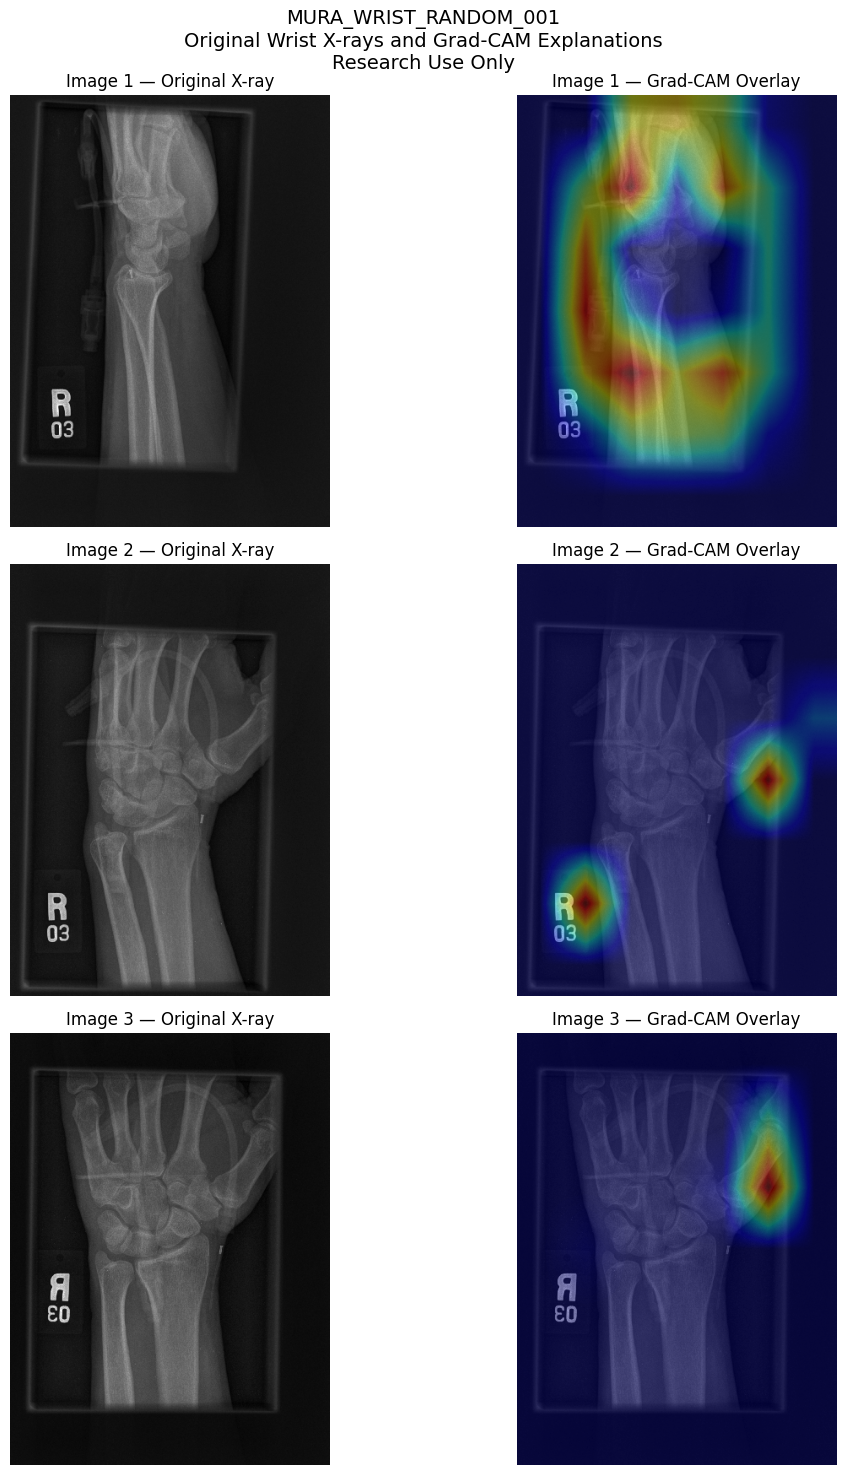


STEP 70AC — SUMMARY
Study: MURA_WRIST_RANDOM_001
Original images: 3
Grad-CAM overlays: 3
Image matching: VERIFIED
Frozen classification: PRESERVED
Frozen policy: PRESERVED
New Gemini calls: 0
Files written: 0

STEP 70AC — VISUALIZATION COMPLETE


In [235]:

# ============================================================
# NOTEBOOK 09 — STEP 70AC
# DISPLAY ORIGINAL X-RAYS AND GRAD-CAM OVERLAYS
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import io
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

print("STEP 70AC — GRAD-CAM VISUALIZATION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Select completed study
# ------------------------------------------------------------

study_alias_70ac = study_alias_70y1

assert verified_70ab is True
assert execution_70y1["execution_status"] == "COMPLETED"

original_images_70ac = prepared_inputs_70f[
    study_alias_70ac
]["images"]

gradcam_results_70ac = explanation_results_70p[
    study_alias_70ac
]["gradcam"]

assert len(original_images_70ac) == len(
    gradcam_results_70ac
)

# ------------------------------------------------------------
# 2. Prepare figure
# ------------------------------------------------------------

image_count_70ac = len(original_images_70ac)

fig_70ac, axes_70ac = plt.subplots(
    image_count_70ac,
    2,
    figsize=(12, 5 * image_count_70ac),
    squeeze=False
)

# ------------------------------------------------------------
# 3. Display each original image and overlay
# ------------------------------------------------------------

for index, (image_record, gradcam_record) in enumerate(
    zip(original_images_70ac, gradcam_results_70ac)
):

    assert (
        image_record["image_id"]
        == gradcam_record["image_id"]
    ), "GRADCAM_IMAGE_MISMATCH"

    assert gradcam_record["status"] == "SUCCESS"

    original_image = Image.open(
        io.BytesIO(image_record["image_bytes"])
    ).convert("L")

    original_array = np.asarray(
        original_image,
        dtype=np.float32
    )

    heatmap = np.asarray(
        gradcam_record["heatmap"],
        dtype=np.float32
    )

    assert heatmap.ndim == 2
    assert np.isfinite(heatmap).all()

    heatmap_resized = Image.fromarray(
        heatmap,
        mode="F"
    ).resize(
        original_image.size,
        resample=Image.Resampling.BILINEAR
    )

    heatmap_resized = np.asarray(
        heatmap_resized,
        dtype=np.float32
    )

    heatmap_resized = np.clip(
        heatmap_resized, 0.0, 1.0
    )

    # Original X-ray
    axes_70ac[index, 0].imshow(
        original_array,
        cmap="gray"
    )

    axes_70ac[index, 0].set_title(
        f"Image {index + 1} — Original X-ray"
    )

    axes_70ac[index, 0].axis("off")

    # Grad-CAM overlay
    axes_70ac[index, 1].imshow(
        original_array,
        cmap="gray"
    )

    axes_70ac[index, 1].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )

    axes_70ac[index, 1].set_title(
        f"Image {index + 1} — Grad-CAM Overlay"
    )

    axes_70ac[index, 1].axis("off")

fig_70ac.suptitle(
    f"{study_alias_70ac}\n"
    "Original Wrist X-rays and Grad-CAM Explanations\n"
    "Research Use Only",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Verify frozen state
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n" + "=" * 68)
print("STEP 70AC — SUMMARY")
print("=" * 68)

print("Study:", study_alias_70ac)
print("Original images:", image_count_70ac)
print("Grad-CAM overlays:", image_count_70ac)
print("Image matching: VERIFIED")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AC — VISUALIZATION COMPLETE")


In [236]:

# ============================================================
# NOTEBOOK 09 — STEP 70AD
# PREPARE FINAL RESEARCH REPORT DATA
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import copy
import json

print("STEP 70AD — FINAL REPORT DATA PREPARATION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify completed study
# ------------------------------------------------------------

study_alias_70ad = study_alias_70y1

assert execution_70y1["execution_status"] == "COMPLETED"
assert verified_70ab is True

assert study_alias_70ac == study_alias_70ad

# ------------------------------------------------------------
# 2. Collect frozen classification and policy
# ------------------------------------------------------------

payload_70ad = copy.deepcopy(
    agent_payloads_70q[study_alias_70ad]
)

classification_70ad = copy.deepcopy(
    payload_70ad["classification"]
)

policy_70ad = copy.deepcopy(
    payload_70ad["policy"]
)

# ------------------------------------------------------------
# 3. Collect explanation summaries
# ------------------------------------------------------------

tta_70ad = copy.deepcopy(
    payload_70ad["tool_results"]["tta_uncertainty"]
)

gradcam_70ad = copy.deepcopy(
    payload_70ad["tool_results"]["gradcam_explainer"]
)

# ------------------------------------------------------------
# 4. Collect agent output
# ------------------------------------------------------------

crew_result_70ad = execution_70y1["result"]

agent_report_text_70ad = getattr(
    crew_result_70ad,
    "raw",
    str(crew_result_70ad)
)

# ------------------------------------------------------------
# 5. Collect execution and audit metadata
# ------------------------------------------------------------

execution_metadata_70ad = {
    "run_id": context_70y1["state"]["run_id"],
    "execution_status": execution_70y1["execution_status"],
    "logging_status": execution_70y1["logging_status"],
    "gemini_calls_reserved": environment_70y1[
        "budget"
    ].reserved_calls,
    "gemini_call_limit": environment_70y1[
        "budget"
    ].max_calls,
    "audit_events": [
        {
            "event": entry.get("event"),
            "status": entry.get("status")
        }
        for entry in context_70y1["audit_log"]
    ]
}

# ------------------------------------------------------------
# 6. Build report data
# ------------------------------------------------------------

final_report_data_70ad = {
    "study_alias": study_alias_70ad,
    "classification": classification_70ad,
    "policy": policy_70ad,
    "tta": tta_70ad,
    "gradcam": gradcam_70ad,
    "report_requirements": copy.deepcopy(
        payload_70ad["report_requirements"]
    ),
    "agent_report": agent_report_text_70ad,
    "execution": execution_metadata_70ad,
    "research_disclaimer": (
        "Research use only. Not intended for clinical "
        "diagnosis or treatment decisions. "
        "Human review is mandatory."
    )
}

# ------------------------------------------------------------
# 7. Validate report data
# ------------------------------------------------------------

assert final_report_data_70ad[
    "report_requirements"
]["include_gradcam_images"] is True

assert gradcam_70ad["image_count"] == len(
    explanation_results_70p[study_alias_70ad]["gradcam"]
)

json.dumps(final_report_data_70ad, allow_nan=False)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 8. Safe summary
# ------------------------------------------------------------

print("Study:", study_alias_70ad)
print("Classification:", classification_70ad["predicted_class"])
print("Probability:", classification_70ad["study_probability"])
print("Policy action:", policy_70ad["agent_action"])
print("TTA status:", tta_70ad["status"])
print("Grad-CAM images:", gradcam_70ad["image_count"])
print("Agent report: INCLUDED")
print("Audit events:", len(execution_metadata_70ad["audit_events"]))
print(
    "Gemini calls reserved:",
    execution_metadata_70ad["gemini_calls_reserved"]
)
print("Original X-rays: AVAILABLE FOR REPORT")
print("Grad-CAM heatmaps: AVAILABLE FOR REPORT")

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AD — REPORT DATA READY")


STEP 70AD — FINAL REPORT DATA PREPARATION
Study: MURA_WRIST_RANDOM_001
Classification: 1
Probability: 0.40549812590082485
Policy action: priority_human_review
TTA status: SUCCESS
Grad-CAM images: 3
Agent report: INCLUDED
Audit events: 3
Gemini calls reserved: 2
Original X-rays: AVAILABLE FOR REPORT
Grad-CAM heatmaps: AVAILABLE FOR REPORT

Frozen classification: PRESERVED
Frozen policy: PRESERVED
New Gemini calls: 0
Files written: 0

STEP 70AD — REPORT DATA READY


In [237]:

%pip install -q reportlab


In [238]:
import reportlab

print("ReportLab version:", reportlab.Version)
print("ReportLab installation: SUCCESS")

ReportLab version: 5.1.0
ReportLab installation: SUCCESS


In [239]:

# ============================================================
# NOTEBOOK 09 — STEP 70AE
# GENERATE FINAL RESEARCH PDF REPORT
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# WRITES ONE PDF REPORT TO GOOGLE DRIVE
# ============================================================

import io
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image as ReportImage,
    KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.utils import ImageReader

print("STEP 70AE — GENERATE FINAL RESEARCH REPORT")
print("=" * 68)

# ------------------------------------------------------------
# 1. Validate report inputs
# ------------------------------------------------------------

assert execution_70y1["execution_status"] == "COMPLETED"
assert verified_70ab is True

assert final_report_data_70ad["study_alias"] == study_alias_70y1

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

study_alias_70ae = final_report_data_70ad["study_alias"]

# ------------------------------------------------------------
# 2. Prepare output directory
# ------------------------------------------------------------

report_dir_70ae = Path(
    "/content/drive/MyDrive/MURA_Project/research_reports"
)

report_dir_70ae.mkdir(
    parents=True,
    exist_ok=True
)

report_path_70ae = report_dir_70ae / (
    f"{study_alias_70ae}_research_report.pdf"
)

# ------------------------------------------------------------
# 3. Prepare report styles
# ------------------------------------------------------------

styles_70ae = getSampleStyleSheet()

styles_70ae["Title"].alignment = TA_CENTER

story_70ae = []

def add_heading_70ae(text):
    story_70ae.append(
        Paragraph(text, styles_70ae["Heading2"])
    )
    story_70ae.append(Spacer(1, 8))

def add_text_70ae(text):
    story_70ae.append(
        Paragraph(str(text), styles_70ae["BodyText"])
    )
    story_70ae.append(Spacer(1, 7))

# ------------------------------------------------------------
# 4. Report title
# ------------------------------------------------------------

story_70ae.append(
    Paragraph(
        "MURA Wrist Research Explanation Report",
        styles_70ae["Title"]
    )
)

story_70ae.append(Spacer(1, 16))

add_text_70ae(
    f"<b>Study:</b> {study_alias_70ae}"
)

add_text_70ae(
    "<b>Purpose:</b> Research-only AI explanation "
    "and workflow documentation."
)

# ------------------------------------------------------------
# 5. Frozen classification
# ------------------------------------------------------------

add_heading_70ae("1. Frozen Model B Classification")

classification_70ae = final_report_data_70ad[
    "classification"
]

add_text_70ae(
    f"<b>Predicted class:</b> "
    f"{classification_70ae['predicted_class']}"
)

add_text_70ae(
    f"<b>Study probability:</b> "
    f"{classification_70ae['study_probability']:.6f}"
)

add_text_70ae(
    f"<b>Classification threshold:</b> "
    f"{classification_70ae['threshold']:.6f}"
)

add_text_70ae(
    f"<b>Image threshold disagreement:</b> "
    f"{classification_70ae['image_threshold_disagreement']}"
)

# ------------------------------------------------------------
# 6. Deterministic policy
# ------------------------------------------------------------

add_heading_70ae("2. Deterministic Workflow Policy")

policy_70ae = final_report_data_70ad["policy"]

add_text_70ae(
    f"<b>Action:</b> {policy_70ae['agent_action']}"
)

add_text_70ae(
    "<b>Authorized tools:</b> "
    + ", ".join(policy_70ae["authorized_tools"])
)

add_text_70ae(
    "<b>Human review required:</b> Yes"
)

# ------------------------------------------------------------
# 7. TTA summary
# ------------------------------------------------------------

add_heading_70ae("3. Test-Time Augmentation")

tta_70ae = final_report_data_70ad["tta"]

add_text_70ae(
    f"<b>Status:</b> {tta_70ae['status']}"
)

add_text_70ae(
    f"<b>Augmentations:</b> "
    f"{tta_70ae['augmentation_count']}"
)

add_text_70ae(
    f"<b>TTA mean probability:</b> "
    f"{tta_70ae['tta_mean_probability']:.6f}"
)

add_text_70ae(
    f"<b>TTA standard deviation:</b> "
    f"{tta_70ae['tta_std']:.6f}"
)

add_text_70ae(
    f"<b>TTA probability range:</b> "
    f"{tta_70ae['tta_range']:.6f}"
)

add_text_70ae(
    f"<b>TTA threshold disagreement:</b> "
    f"{tta_70ae['threshold_disagreement']}"
)

# ------------------------------------------------------------
# 8. Grad-CAM images
# ------------------------------------------------------------

add_heading_70ae("4. Grad-CAM Visual Explanations")

add_text_70ae(
    "Each original wrist X-ray is displayed beside "
    "its corresponding Grad-CAM overlay. "
    "Heatmaps are explanatory visualizations and "
    "do not establish diagnostic correctness."
)

original_images_70ae = prepared_inputs_70f[
    study_alias_70ae
]["images"]

gradcam_results_70ae = explanation_results_70p[
    study_alias_70ae
]["gradcam"]

assert len(original_images_70ae) == len(
    gradcam_results_70ae
)

for index, (image_record, gradcam_record) in enumerate(
    zip(original_images_70ae, gradcam_results_70ae), 1
):

    assert (
        image_record["image_id"]
        == gradcam_record["image_id"]
    ), "GRADCAM_IMAGE_MISMATCH"

    original_image = Image.open(
        io.BytesIO(image_record["image_bytes"])
    ).convert("L")

    original_array = np.asarray(original_image)

    heatmap = np.asarray(
        gradcam_record["heatmap"],
        dtype=np.float32
    )

    heatmap_resized = Image.fromarray(
        heatmap,
        mode="F"
    ).resize(
        original_image.size,
        Image.Resampling.BILINEAR
    )

    heatmap_resized = np.clip(
        np.asarray(heatmap_resized),
        0,
        1
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(10, 4)
    )

    axes[0].imshow(
        original_array,
        cmap="gray"
    )
    axes[0].set_title("Original X-ray")
    axes[0].axis("off")

    axes[1].imshow(
        original_array,
        cmap="gray"
    )
    axes[1].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Grad-CAM overlay")
    axes[1].axis("off")

    fig.tight_layout()

    image_buffer = io.BytesIO()

    fig.savefig(
        image_buffer,
        format="png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)
    image_buffer.seek(0)

    story_70ae.append(
        Paragraph(
            f"Image {index}",
            styles_70ae["Heading3"]
        )
    )

    story_70ae.append(
        ReportImage(
            image_buffer,
            width=6.5 * inch,
            height=2.6 * inch
        )
    )

    story_70ae.append(Spacer(1, 12))

# ------------------------------------------------------------
# 9. Agent interpretation
# ------------------------------------------------------------

add_heading_70ae("5. CrewAI Research Interpretation")

agent_text_70ae = final_report_data_70ad[
    "agent_report"
]

# Convert markdown into safe PDF paragraphs.
from xml.sax.saxutils import escape

for line in agent_text_70ae.splitlines():

    clean_line = line.strip()

    if not clean_line:
        continue

    clean_line = re.sub(
        r"^#{1,6}\s*",
        "",
        clean_line
    )

    clean_line = re.sub(
        r"^\s*[-*]\s+",
        "",
        clean_line
    )

    clean_line = clean_line.replace("**", "")

    add_text_70ae(escape(clean_line))

# ------------------------------------------------------------
# 10. Execution and audit
# ------------------------------------------------------------

add_heading_70ae("6. Execution and Audit")

execution_info_70ae = final_report_data_70ad[
    "execution"
]

add_text_70ae(
    f"<b>Run ID:</b> {execution_info_70ae['run_id']}"
)

add_text_70ae(
    f"<b>Execution status:</b> "
    f"{execution_info_70ae['execution_status']}"
)

add_text_70ae(
    f"<b>Logging status:</b> "
    f"{execution_info_70ae['logging_status']}"
)

add_text_70ae(
    f"<b>Gemini calls reserved:</b> "
    f"{execution_info_70ae['gemini_calls_reserved']}"
)

add_text_70ae(
    f"<b>Gemini call limit:</b> "
    f"{execution_info_70ae['gemini_call_limit']}"
)

for event in execution_info_70ae["audit_events"]:

    add_text_70ae(
        f"{event['event']}: {event['status']}"
    )

# ------------------------------------------------------------
# 11. Research disclaimer
# ------------------------------------------------------------

add_heading_70ae("7. Research Limitations")

add_text_70ae(
    escape(
        final_report_data_70ad[
            "research_disclaimer"
        ]
    )
)

add_text_70ae(
    "Grad-CAM and TTA do not independently validate "
    "the model's prediction. Human review is required."
)

# ------------------------------------------------------------
# 12. Generate PDF
# ------------------------------------------------------------

document_70ae = SimpleDocTemplate(
    str(report_path_70ae),
    pagesize=(595.28, 841.89),
    rightMargin=36,
    leftMargin=36,
    topMargin=40,
    bottomMargin=40
)

document_70ae.build(story_70ae)

# ------------------------------------------------------------
# 13. Verify file and frozen state
# ------------------------------------------------------------

assert report_path_70ae.is_file()
assert report_path_70ae.stat().st_size > 0

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\n" + "=" * 68)
print("STEP 70AE — REPORT SUMMARY")
print("=" * 68)

print("Study:", study_alias_70ae)
print("Report:", report_path_70ae.name)
print("PDF size:", report_path_70ae.stat().st_size, "bytes")
print("Original X-rays:", len(original_images_70ae))
print("Grad-CAM overlays:", len(gradcam_results_70ae))
print("Agent interpretation: INCLUDED")
print("Audit summary: INCLUDED")
print("Ground truth: NOT INCLUDED")
print("New Gemini calls: 0")

print("\nSTEP 70AE — PDF REPORT GENERATED")


STEP 70AE — GENERATE FINAL RESEARCH REPORT


/tmp/ipykernel_188/1916638338.py:246: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  heatmap_resized = Image.fromarray(



STEP 70AE — REPORT SUMMARY
Study: MURA_WRIST_RANDOM_001
Report: MURA_WRIST_RANDOM_001_research_report.pdf
PDF size: 1788801 bytes
Original X-rays: 3
Grad-CAM overlays: 3
Agent interpretation: INCLUDED
Audit summary: INCLUDED
Ground truth: NOT INCLUDED
New Gemini calls: 0

STEP 70AE — PDF REPORT GENERATED


In [240]:

# STEP 70AE.1 — INSPECT EXECUTION METRICS
# No Gemini calls, no model execution, no file writes.

print("STEP 70AE.1 — EXECUTION METRICS")
print("=" * 60)

# CrewAI token usage
crew_result = execution_70y1["result"]

usage = getattr(crew_result, "token_usage", None)

if usage is None:
    usage = getattr(crew_result, "usage_metrics", None)

print("\nTOKEN USAGE")
print("-" * 40)

if usage is None:
    print("Token usage: NOT AVAILABLE")
elif hasattr(usage, "model_dump"):
    print(usage.model_dump())
else:
    print(usage)

# Execution timestamps
print("\nAUDIT TIMESTAMPS")
print("-" * 40)

for entry in context_70y1["audit_log"]:
    print(entry)

# Gemini call budget
print("\nGEMINI CALL BUDGET")
print("-" * 40)

budget = environment_70y1["budget"]

print("Reserved calls:", budget.reserved_calls)
print("Maximum calls:", budget.max_calls)

print("\nSTEP 70AE.1 — INSPECTION COMPLETE")
print("New Gemini calls: 0")
print("Files written: 0")


STEP 70AE.1 — EXECUTION METRICS

TOKEN USAGE
----------------------------------------
{'total_tokens': 3474, 'prompt_tokens': 2455, 'cached_prompt_tokens': 0, 'completion_tokens': 1019, 'reasoning_tokens': 0, 'cache_creation_tokens': 0, 'successful_requests': 4}

AUDIT TIMESTAMPS
----------------------------------------
{'run_id': 'cc68d158-e2cb-4471-9d6d-ec5219dc9a7a', 'timestamp_utc': '2026-11-11T21:01:10.836679+00:00', 'event': 'STATE_INITIALIZED', 'status': 'SUCCESS'}
{'run_id': 'cc68d158-e2cb-4471-9d6d-ec5219dc9a7a', 'timestamp_utc': '2026-11-11T21:01:10.837379+00:00', 'event': 'EXECUTION_STARTED', 'status': 'SUCCESS'}
{'run_id': 'cc68d158-e2cb-4471-9d6d-ec5219dc9a7a', 'timestamp_utc': '2026-11-11T21:01:13.497458+00:00', 'event': 'EXECUTION_COMPLETED', 'status': 'SUCCESS'}

GEMINI CALL BUDGET
----------------------------------------
Reserved calls: 2
Maximum calls: 3

STEP 70AE.1 — INSPECTION COMPLETE
New Gemini calls: 0
Files written: 0


In [241]:

# ============================================================
# STEP 70AE.2 — SAVE EXECUTION METRICS FOR REPORT
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

from datetime import datetime

audit = context_70y1["audit_log"]

started = next(
    e["timestamp_utc"] for e in audit
    if e["event"] == "EXECUTION_STARTED"
)

completed = next(
    e["timestamp_utc"] for e in audit
    if e["event"] == "EXECUTION_COMPLETED"
)

duration_seconds = (
    datetime.fromisoformat(completed)
    - datetime.fromisoformat(started)
).total_seconds()

usage = execution_70y1["result"].token_usage

usage_data = (
    usage.model_dump()
    if hasattr(usage, "model_dump")
    else dict(usage)
)

final_report_data_70ad["execution_metrics"] = {
    "duration_seconds": duration_seconds,
    "prompt_tokens": usage_data["prompt_tokens"],
    "completion_tokens": usage_data["completion_tokens"],
    "total_tokens": usage_data["total_tokens"],
    "cached_prompt_tokens": usage_data["cached_prompt_tokens"],
    "successful_requests": usage_data["successful_requests"],
    "gemini_calls_reserved": environment_70y1[
        "budget"
    ].reserved_calls
}

print("STEP 70AE.2 — EXECUTION METRICS")
print("=" * 60)

for key, value in final_report_data_70ad[
    "execution_metrics"
].items():
    print(f"{key}: {value}")

print("\nMetrics saved in report data: SUCCESS")
print("New Gemini calls: 0")
print("Files written: 0")


STEP 70AE.2 — EXECUTION METRICS
duration_seconds: 2.660079
prompt_tokens: 2455
completion_tokens: 1019
total_tokens: 3474
cached_prompt_tokens: 0
successful_requests: 4
gemini_calls_reserved: 2

Metrics saved in report data: SUCCESS
New Gemini calls: 0
Files written: 0


In [242]:

# ============================================================
# STEP 70AE.3 — VERIFY GEMINI MODEL
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 70AE.3 — GEMINI MODEL VERIFICATION")
print("=" * 60)

agent = environment_70y1["agent"]
llm = getattr(agent, "llm", None)

print("LLM object type:", type(llm).__name__)

for field in ("model", "model_name", "model_id"):
    value = getattr(llm, field, None)
    if value is not None:
        print(f"{field}: {value}")

print("\nSTEP 70AE.3 — COMPLETE")
print("New Gemini calls: 0")
print("Files written: 0")


STEP 70AE.3 — GEMINI MODEL VERIFICATION
LLM object type: GeminiCompletion
model: gemini-3.1-flash-lite

STEP 70AE.3 — COMPLETE
New Gemini calls: 0
Files written: 0


In [243]:

# STEP 70AE.4 — CALCULATE GEMINI API COST
# No Gemini calls. No file writes.

metrics = final_report_data_70ad["execution_metrics"]

input_rate_usd = 0.25
output_rate_usd = 1.50

input_cost = (
    metrics["prompt_tokens"] / 1_000_000
) * input_rate_usd

output_cost = (
    metrics["completion_tokens"] / 1_000_000
) * output_rate_usd

estimated_cost = input_cost + output_cost

metrics["model"] = "gemini-3.1-flash-lite"
metrics["input_cost_usd"] = input_cost
metrics["output_cost_usd"] = output_cost
metrics["estimated_cost_usd"] = estimated_cost
metrics["cost_type"] = "Estimated standard paid API cost"

print("STEP 70AE.4 — GEMINI COST")
print("=" * 60)
print(f"Input cost: ${input_cost:.8f}")
print(f"Output cost: ${output_cost:.8f}")
print(f"Estimated total: ${estimated_cost:.8f}")
print(f"Duration: {metrics['duration_seconds']:.4f} seconds")
print("Cost metadata saved: SUCCESS")
print("New Gemini calls: 0")
print("Files written: 0")


STEP 70AE.4 — GEMINI COST
Input cost: $0.00061375
Output cost: $0.00152850
Estimated total: $0.00214225
Duration: 2.6601 seconds
Cost metadata saved: SUCCESS
New Gemini calls: 0
Files written: 0


In [244]:
%pip install -q pypdf

In [245]:

# ============================================================
# STEP 70AE.5 — ADD EXECUTION METRICS TO EXISTING PDF
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# WRITES UPDATED PDF ONLY
# ============================================================

from pathlib import Path
from io import BytesIO

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4

from pypdf import PdfReader, PdfWriter

print("STEP 70AE.5 — UPDATE RESEARCH PDF")
print("=" * 60)

# 1. Locate existing report
original_pdf = Path(report_path_70ae)

assert original_pdf.exists(), "Original PDF not found"

updated_pdf = original_pdf.with_name(
    original_pdf.stem + "_with_metrics.pdf"
)

metrics = final_report_data_70ad["execution_metrics"]

# 2. Build execution metrics page in memory
buffer = BytesIO()

doc = SimpleDocTemplate(
    buffer,
    pagesize=A4,
    leftMargin=45,
    rightMargin=45,
    topMargin=50,
    bottomMargin=50
)

styles = getSampleStyleSheet()

elements = [
    Paragraph(
        "Execution Performance and API Cost",
        styles["Title"]
    ),
    Spacer(1, 20),
    Paragraph(
        f"Study: {final_report_data_70ad['study_alias']}",
        styles["Normal"]
    ),
    Spacer(1, 18)
]

rows = [
    ["Metric", "Value"],
    ["Gemini model", metrics["model"]],
    ["Input tokens", str(metrics["prompt_tokens"])],
    ["Output tokens", str(metrics["completion_tokens"])],
    ["Total tokens", str(metrics["total_tokens"])],
    ["Gemini calls reserved", str(metrics["gemini_calls_reserved"])],
    ["Execution duration", f"{metrics['duration_seconds']:.4f} seconds"],
    ["Input cost", f"${metrics['input_cost_usd']:.8f}"],
    ["Output cost", f"${metrics['output_cost_usd']:.8f}"],
    ["Estimated API cost", f"${metrics['estimated_cost_usd']:.8f}"],
]

table = Table(rows, colWidths=[240, 230])

table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#E8EEF5")),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
    ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
    ("TOPPADDING", (0, 0), (-1, -1), 9),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 9),
]))

elements.append(table)
elements.append(Spacer(1, 18))

elements.append(Paragraph(
    "Cost is an estimate based on reported token usage and "
    "standard paid API rates. Actual billing may differ. "
    "Execution duration covers the recorded CrewAI run.",
    styles["Normal"]
))

doc.build(elements)

buffer.seek(0)

# 3. Append the new page to the existing report
reader_original = PdfReader(str(original_pdf))
reader_metrics = PdfReader(buffer)

writer = PdfWriter()

for page in reader_original.pages:
    writer.add_page(page)

for page in reader_metrics.pages:
    writer.add_page(page)

with open(updated_pdf, "wb") as output_file:
    writer.write(output_file)

# 4. Verify output
assert updated_pdf.exists()
assert updated_pdf.stat().st_size > 0

reader_updated = PdfReader(str(updated_pdf))

assert len(reader_updated.pages) == (
    len(reader_original.pages) + len(reader_metrics.pages)
)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Study:", final_report_data_70ad["study_alias"])
print("Original PDF pages:", len(reader_original.pages))
print("Updated PDF pages:", len(reader_updated.pages))
print("Updated PDF:", updated_pdf)
print("Estimated cost: $", f"{metrics['estimated_cost_usd']:.8f}")
print("Execution time:", f"{metrics['duration_seconds']:.4f}", "seconds")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("\nSTEP 70AE.5 — PDF UPDATED SUCCESSFULLY")


STEP 70AE.5 — UPDATE RESEARCH PDF
Study: MURA_WRIST_RANDOM_001
Original PDF pages: 4
Updated PDF pages: 5
Updated PDF: /content/drive/MyDrive/MURA_Project/research_reports/MURA_WRIST_RANDOM_001_research_report_with_metrics.pdf
Estimated cost: $ 0.00214225
Execution time: 2.6601 seconds
Frozen classification: PRESERVED
Frozen policy: PRESERVED
New Gemini calls: 0

STEP 70AE.5 — PDF UPDATED SUCCESSFULLY


In [246]:

# ============================================================
# NOTEBOOK 09 — STEP 70AF
# PREPARE STUDY 002 FOR AGENT EXECUTION
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

from crewai.hooks import get_before_llm_call_hooks

print("STEP 70AF — STUDY 002 PREPARATION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Select second study
# ------------------------------------------------------------

study_alias_70af = "MURA_WRIST_RANDOM_002"

assert study_alias_70af in prepared_inputs_70f
assert study_alias_70af in execution_results_70g
assert study_alias_70af in explanation_results_70p
assert study_alias_70af in agent_payloads_70q

# ------------------------------------------------------------
# 2. Verify frozen classification and policy
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

payload_70af = agent_payloads_70q[study_alias_70af]

assert payload_70af["classification"][
    "classification_modified"
] is False

assert payload_70af["policy"]["status"] == "VALID"
assert payload_70af["policy"]["research_use_only"] is True
assert payload_70af["policy"]["requires_human_review"] is True

# ------------------------------------------------------------
# 3. Verify explanation results
# ------------------------------------------------------------

assert payload_70af["tool_results"][
    "tta_uncertainty"
]["status"] == "SUCCESS"

assert payload_70af["tool_results"][
    "gradcam_explainer"
]["status"] == "SUCCESS"

image_count_70af = len(
    prepared_inputs_70f[study_alias_70af]["images"]
)

assert image_count_70af == len(
    explanation_results_70p[study_alias_70af]["gradcam"]
)

# ------------------------------------------------------------
# 4. Verify hook registry is clean
# ------------------------------------------------------------

assert len(tuple(get_before_llm_call_hooks())) == 0, (
    "Unexpected active LLM hooks"
)

# ------------------------------------------------------------
# 5. Build fresh study-specific CrewAI environment
# ------------------------------------------------------------

environment_70af = build_study_crew_70s(
    study_alias_70af
)

# ------------------------------------------------------------
# 6. Build fresh execution context
#    Use the flat input contract required by Step 66K
# ------------------------------------------------------------

classification_70af = payload_70af["classification"]
policy_70af = payload_70af["policy"]

report_input_70af = {
    "study_alias": study_alias_70af,
    "predicted_class": classification_70af["predicted_class"],
    "study_probability": classification_70af["study_probability"],
    "classification_threshold": classification_70af["threshold"],
    "policy_status": policy_70af["status"],
    "authorized_tools": policy_70af["authorized_tools"],
    "requires_human_review": policy_70af["requires_human_review"],
    "research_use_only": policy_70af["research_use_only"],
    "tool_results": payload_70af["tool_results"]
}

required_fields_70af = {
    "study_alias",
    "predicted_class",
    "study_probability",
    "classification_threshold",
    "policy_status",
    "authorized_tools",
    "requires_human_review",
    "research_use_only",
    "tool_results"
}

assert required_fields_70af.issubset(report_input_70af)

context_70af = create_execution_context_66k(
    report_input_70af
)

context_70af.setdefault("pending_events", [])


# ------------------------------------------------------------
# 7. Verify execution readiness
# ------------------------------------------------------------

assert context_70af["state"]["status"] == "READY"

assert environment_70af["budget"].reserved_calls == 0
assert environment_70af["budget"].max_calls == 3

assert len(tuple(get_before_llm_call_hooks())) == 0

print("Study:", study_alias_70af)
print("Images:", image_count_70af)

print(
    "Predicted class:",
    payload_70af["classification"]["predicted_class"]
)

print(
    "Study probability:",
    payload_70af["classification"]["study_probability"]
)

print(
    "Threshold:",
    payload_70af["classification"]["threshold"]
)

print(
    "Policy action:",
    payload_70af["policy"]["agent_action"]
)

print(
    "TTA:",
    payload_70af["tool_results"]["tta_uncertainty"]["status"]
)

print(
    "Grad-CAM:",
    payload_70af["tool_results"]["gradcam_explainer"]["status"]
)

print("Execution state:", context_70af["state"]["status"])
print("Gemini calls reserved:", environment_70af["budget"].reserved_calls)
print("Gemini call limit:", environment_70af["budget"].max_calls)
print("Active hooks:", len(tuple(get_before_llm_call_hooks())))

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AF — STUDY 002 READY")


STEP 70AF — STUDY 002 PREPARATION
Study: MURA_WRIST_RANDOM_002
Images: 3
Predicted class: 1
Study probability: 0.9960786898930868
Threshold: 0.263567715883255
Policy action: priority_human_review
TTA: SUCCESS
Grad-CAM: SUCCESS
Execution state: READY
Gemini calls reserved: 0
Gemini call limit: 3
Active hooks: 0

Frozen classification: PRESERVED
Frozen policy: PRESERVED
New Gemini calls: 0
Files written: 0

STEP 70AF — STUDY 002 READY


In [247]:

# ============================================================
# NOTEBOOK 09 — STEP 70AG
# EXECUTE CREWAI FOR STUDY 002
#
# GEMINI CALLS: UP TO 3 AUTHORIZED
# MODEL B: FROZEN
# POLICY: FROZEN
# AUDIT LOGGING: ENABLED
# ============================================================

import asyncio

from crewai.hooks import get_before_llm_call_hooks

print("STEP 70AG — STUDY 002 AGENT EXECUTION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Final execution guards
# ------------------------------------------------------------

assert study_alias_70af == "MURA_WRIST_RANDOM_002"

assert context_70af["state"]["status"] == "READY"

assert environment_70af["budget"].reserved_calls == 0

assert len(tuple(get_before_llm_call_hooks())) == 0

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Define the operation
# ------------------------------------------------------------

def operation_70ag():
    return environment_70af["crew"].kickoff()

# ------------------------------------------------------------
# 3. Execute in a worker thread
# ------------------------------------------------------------

execution_70ag = await asyncio.to_thread(
    execute_unified_67g,
    environment_70af,
    context_70af,
    operation_70ag,
    LOG_DIR_66N
)

# ------------------------------------------------------------
# 4. Inspect execution result
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("STEP 70AG — EXECUTION SUMMARY")
print("=" * 68)

print("Study:", study_alias_70af)

print(
    "Execution status:",
    execution_70ag["execution_status"]
)

print(
    "Execution error:",
    execution_70ag["execution_error"]
)

print(
    "Logging status:",
    execution_70ag["logging_status"]
)

print(
    "Final state:",
    context_70af["state"]["status"]
)

print(
    "Gemini calls reserved:",
    environment_70af["budget"].reserved_calls
)

print(
    "Maximum calls:",
    environment_70af["budget"].max_calls
)

print(
    "Audit entries:",
    len(context_70af["audit_log"])
)

print(
    "Pending events:",
    len(context_70af["pending_events"])
)

print(
    "Active hooks:",
    len(tuple(get_before_llm_call_hooks()))
)

# ------------------------------------------------------------
# 5. Verify frozen invariants
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")

print("\nSTEP 70AG — EXECUTION FINISHED")


STEP 70AG — STUDY 002 AGENT EXECUTION


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Task:                                                                                                          │
│  Prepare a research-only MURA explanation report.                                                               │
│                                                                                                                 │
│  Study alias: MURA_WRIST_RANDOM_002                                                                             │
│                                                                                                                 │
│  Frozen classification:                                                                                         │
│  - Predicted class: 1                                                                                           │
│  - Study probability: 0.9960786898930868                                                                        │
│  - Classification threshold: 0.263567715883255                                                                  │
│  - Image threshold disagreement:                                                                                │
│    False                                                                                                        │
│                                                                                                                 │
│  Frozen deterministic workflow action:                                                                          │
│  priority_human_review                                                                                          │
│                                                                                                                 │
│  Use only the assigned authorized TTA and Grad-CAM                                                              │
│  retrieval tools.                                                                                               │
│                                                                                                                 │
│  Retrieve the existing explanation summaries for                                                                │
│  this study. Do not perform new model inference.                                                                │
│                                                                                                                 │
│  Do not modify:                                                                                                 │
│  - Frozen classification                                                                                        │
│  - Classification threshold                                                                                     │
│  - Deterministic workflow action                                                                                │
│                                                                                                                 │
│  Include:                                                                                                       │
│  1. Study alias                                                                                                 │
│  2. Original frozen classification                                                                              │
│  3. Deterministic workflow action                                                                               │
│  4. TTA execution summary                              

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### MURA Research Explanation Report                                                                           │
│                                                                                                                 │
│  **Study Alias:** MURA_WRIST_RANDOM_002                                                                         │
│                                                                                                                 │
│  **Original Frozen Classification:**                                                                            │
│  *   **Predicted Class:** 1                                                                                     │
│  *   **Study Probability:** 0.9960786898930868                                                                  │
│  *   **Classification Threshold:** 0.263567715883255                                                            │
│  *   **Image Threshold Disagreement:** False                                                                    │
│                                                                                                                 │
│  **Deterministic Workflow Action:**                                                                             │
│  *   **Action:** priority_human_review                                                                          │
│                                                                                                                 │
│  **TTA Execution Summary:**                                                                                     │
│  *   **Status:** SUCCESS                                                                                        │
│  *   **Augmentations Performed:** 5                                                                             │
│  *   **TTA Mean Probability:** 0.996009743213654                                                                │
│  *   **TTA Standard Deviation:** 0.000182286098263525                                                           │
│  *   **TTA Range:** 0.000512997309366825                                                                        │
│  *   **Interpretation:** The model demonstrates high stability across the performed augmentations, with         │
│  minimal variance in probability scores.                                                                        │
│                                                                                                                 │
│  **Grad-CAM Execution Summary:**                                                                                │
│  *   **Status:** SUCCESS                                                                                        │
│  *   **Target Layer:** backbone.layer4[-1].conv2                                                                │
│  *   **Images Processed:** 3                                                                                    │
│  *   **Interpretation:** Heatmaps were successfully generated for all images in the study. These                │
│  visualizations highlight the regions of the radiographs that most influenced the model's classification.       │
│                                                                                                                 │
│  **Scientific Limitations:**                           


STEP 70AG — EXECUTION SUMMARY
Study: MURA_WRIST_RANDOM_002
Execution status: COMPLETED
Execution error: None
Logging status: SUCCESS
Final state: COMPLETED
Gemini calls reserved: 2
Maximum calls: 3
Audit entries: 3
Pending events: 0
Active hooks: 0

Frozen classification: PRESERVED
Frozen policy: PRESERVED

STEP 70AG — EXECUTION FINISHED


In [248]:

# ============================================================
# STEP 70AH — VERIFY STUDY 002 TOOL EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import json

print("STEP 70AH — STUDY 002 TOOL VERIFICATION")
print("=" * 60)

assert execution_70ag["execution_status"] == "COMPLETED"

messages = execution_70ag["result"].tasks_output[0].messages or []

expected_tools = {
    "tta_uncertainty",
    "gradcam_explainer"
}

def get_field(obj, key, default=None):
    if isinstance(obj, dict):
        return obj.get(key, default)
    return getattr(obj, key, default)

requests = {}
responses = {}

for message in messages:
    if get_field(message, "role") == "assistant":
        for call in get_field(message, "tool_calls", []) or []:
            function = get_field(call, "function", {})
            name = get_field(function, "name")
            call_id = get_field(call, "id")

            if name in expected_tools:
                requests[call_id] = name

for message in messages:
    if get_field(message, "role") != "tool":
        continue

    call_id = get_field(message, "tool_call_id")
    name = requests.get(call_id)

    if name is None:
        continue

    content = get_field(message, "content")

    try:
        data = (
            json.loads(content)
            if isinstance(content, str)
            else content
        )

        responses[name] = {
            "study_matches": (
                data.get("study_alias")
                == "MURA_WRIST_RANDOM_002"
            ),
            "status": data["result"]["status"]
        }

    except (ValueError, TypeError, KeyError, AttributeError):
        responses[name] = {
            "study_matches": False,
            "status": "UNVERIFIED"
        }

for name in sorted(expected_tools):
    print(f"\nTool: {name}")
    print("Requested:", name in requests.values())
    print("Response:", responses.get(name, "NOT FOUND"))

verified_70ah = (
    set(responses) == expected_tools
    and all(
        result["study_matches"]
        and result["status"] == "SUCCESS"
        for result in responses.values()
    )
)

print("\nAll tools verified:", verified_70ah)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("New Gemini calls: 0")
print("Files written: 0")
print("\nSTEP 70AH — COMPLETE")


STEP 70AH — STUDY 002 TOOL VERIFICATION

Tool: gradcam_explainer
Requested: True
Response: {'study_matches': True, 'status': 'SUCCESS'}

Tool: tta_uncertainty
Requested: True
Response: {'study_matches': True, 'status': 'SUCCESS'}

All tools verified: True
New Gemini calls: 0
Files written: 0

STEP 70AH — COMPLETE


In [249]:

# ============================================================
# NOTEBOOK 09 — STEP 70AI
# PREPARE STUDY 002 REPORT DATA AND EXECUTION METRICS
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import copy
from datetime import datetime

print("STEP 70AI — STUDY 002 REPORT DATA")
print("=" * 68)

study_alias_70ai = "MURA_WRIST_RANDOM_002"

assert verified_70ah is True
assert execution_70ag["execution_status"] == "COMPLETED"
assert context_70af["state"]["status"] == "COMPLETED"

payload_70ai = agent_payloads_70q[study_alias_70ai]

# ------------------------------------------------------------
# 1. Collect token usage
# ------------------------------------------------------------

crew_result_70ai = execution_70ag["result"]

usage_70ai = getattr(
    crew_result_70ai, "token_usage", None
)

if usage_70ai is None:
    usage_70ai = getattr(
        crew_result_70ai, "usage_metrics", None
    )

assert usage_70ai is not None, "TOKEN_USAGE_UNAVAILABLE"

if hasattr(usage_70ai, "model_dump"):
    usage_data_70ai = usage_70ai.model_dump()
elif isinstance(usage_70ai, dict):
    usage_data_70ai = usage_70ai
else:
    usage_data_70ai = vars(usage_70ai)

# ------------------------------------------------------------
# 2. Calculate execution duration
# ------------------------------------------------------------

audit_70ai = context_70af["audit_log"]

started_70ai = next(
    entry["timestamp_utc"]
    for entry in audit_70ai
    if entry["event"] == "EXECUTION_STARTED"
)

completed_70ai = next(
    entry["timestamp_utc"]
    for entry in audit_70ai
    if entry["event"] == "EXECUTION_COMPLETED"
)

duration_70ai = (
    datetime.fromisoformat(completed_70ai)
    - datetime.fromisoformat(started_70ai)
).total_seconds()

assert duration_70ai >= 0

# ------------------------------------------------------------
# 3. Calculate estimated API cost
# ------------------------------------------------------------

input_rate_70ai = 0.25
output_rate_70ai = 1.50

input_cost_70ai = (
    usage_data_70ai["prompt_tokens"] / 1_000_000
) * input_rate_70ai

output_cost_70ai = (
    usage_data_70ai["completion_tokens"] / 1_000_000
) * output_rate_70ai

estimated_cost_70ai = (
    input_cost_70ai + output_cost_70ai
)

# ------------------------------------------------------------
# 4. Assemble execution metrics
# ------------------------------------------------------------

metrics_70ai = {
    "model": "gemini-3.1-flash-lite",
    "duration_seconds": duration_70ai,
    "prompt_tokens": usage_data_70ai["prompt_tokens"],
    "completion_tokens": usage_data_70ai["completion_tokens"],
    "total_tokens": usage_data_70ai["total_tokens"],
    "cached_prompt_tokens": usage_data_70ai.get(
        "cached_prompt_tokens", 0
    ),
    "successful_requests": usage_data_70ai.get(
        "successful_requests"
    ),
    "gemini_calls_reserved": environment_70af[
        "budget"
    ].reserved_calls,
    "input_cost_usd": input_cost_70ai,
    "output_cost_usd": output_cost_70ai,
    "estimated_cost_usd": estimated_cost_70ai,
    "cost_type": "Estimated standard paid API cost"
}

# ------------------------------------------------------------
# 5. Assemble report data
# ------------------------------------------------------------

final_report_data_70ai = {
    "study_alias": study_alias_70ai,
    "classification": copy.deepcopy(
        payload_70ai["classification"]
    ),
    "policy": copy.deepcopy(
        payload_70ai["policy"]
    ),
    "tta": copy.deepcopy(
        payload_70ai["tool_results"]["tta_uncertainty"]
    ),
    "gradcam": copy.deepcopy(
        payload_70ai["tool_results"]["gradcam_explainer"]
    ),
    "report_requirements": copy.deepcopy(
        payload_70ai["report_requirements"]
    ),
    "agent_report": getattr(
        crew_result_70ai,
        "raw",
        str(crew_result_70ai)
    ),
    "execution": {
        "run_id": context_70af["state"]["run_id"],
        "execution_status": execution_70ag[
            "execution_status"
        ],
        "logging_status": execution_70ag[
            "logging_status"
        ],
        "audit_events": [
            {
                "event": entry.get("event"),
                "status": entry.get("status")
            }
            for entry in audit_70ai
        ]
    },
    "execution_metrics": metrics_70ai,
    "research_disclaimer": (
        "Research use only. Not intended for clinical "
        "diagnosis or treatment decisions. "
        "Human review is mandatory."
    )
}

# ------------------------------------------------------------
# 6. Validate
# ------------------------------------------------------------

assert final_report_data_70ai["gradcam"]["image_count"] == len(
    prepared_inputs_70f[study_alias_70ai]["images"]
)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("Study:", study_alias_70ai)
print(
    "Predicted class:",
    final_report_data_70ai["classification"]["predicted_class"]
)
print(
    "Study probability:",
    final_report_data_70ai["classification"]["study_probability"]
)
print(
    "TTA status:",
    final_report_data_70ai["tta"]["status"]
)
print(
    "Grad-CAM images:",
    final_report_data_70ai["gradcam"]["image_count"]
)
print("Input tokens:", metrics_70ai["prompt_tokens"])
print("Output tokens:", metrics_70ai["completion_tokens"])
print("Duration:", f"{duration_70ai:.4f}", "seconds")
print(
    "Estimated API cost:",
    f"${estimated_cost_70ai:.8f}"
)
print("Gemini calls reserved:", metrics_70ai["gemini_calls_reserved"])

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AI — REPORT DATA READY")


STEP 70AI — STUDY 002 REPORT DATA
Study: MURA_WRIST_RANDOM_002
Predicted class: 1
Study probability: 0.9960786898930868
TTA status: SUCCESS
Grad-CAM images: 3
Input tokens: 3935
Output tokens: 1513
Duration: 2.8125 seconds
Estimated API cost: $0.00325325
Gemini calls reserved: 2

Frozen classification: PRESERVED
Frozen policy: PRESERVED
New Gemini calls: 0
Files written: 0

STEP 70AI — REPORT DATA READY


In [250]:

# ============================================================
# NOTEBOOK 09 — STEP 70AJ
# REUSABLE PDF REPORT GENERATOR
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# OUTPUT: ONE PDF FILE
# ============================================================

import io
import re
from pathlib import Path
from xml.sax.saxutils import escape

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image as ReportImage,
    KeepTogether,
    PageBreak,
)

def generate_mura_research_pdf(
    report_data,
    prepared_inputs,
    explanation_results,
    output_dir
):
    """Generate a research-only PDF from completed study results."""

    alias = report_data["study_alias"]
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    pdf_path = output_dir / f"{alias}_research_report.pdf"

    classification = report_data["classification"]
    policy = report_data["policy"]
    tta = report_data["tta"]
    gradcam_summary = report_data["gradcam"]
    metrics = report_data["execution_metrics"]
    execution = report_data["execution"]

    images = prepared_inputs[alias]["images"]
    gradcam_records = explanation_results[alias]["gradcam"]

    assert len(images) == len(gradcam_records)
    assert len(images) > 0

    styles = getSampleStyleSheet()
    styles.add(ParagraphStyle(
        name="MURATitle",
        parent=styles["Title"],
        fontSize=17,
        leading=22,
        alignment=TA_CENTER,
        spaceAfter=14
    ))
    styles.add(ParagraphStyle(
        name="MURABody",
        parent=styles["BodyText"],
        fontSize=9,
        leading=13,
        spaceAfter=7
    ))

    doc = SimpleDocTemplate(
        str(pdf_path),
        pagesize=A4,
        rightMargin=36,
        leftMargin=36,
        topMargin=40,
        bottomMargin=40
    )

    story = []

    def add_heading(value, level=2):
        story.append(
            Paragraph(escape(str(value)), styles[f"Heading{level}"])
        )
        story.append(Spacer(1, 5))

    def add_text(value):
        story.append(
            Paragraph(escape(str(value)), styles["MURABody"])
        )

    def add_table(rows):
        table = Table(
            [
                [
                    Paragraph(escape(str(cell)), styles["MURABody"])
                    for cell in row
                ]
                for row in rows
            ],
            colWidths=[2.2 * inch, 4.7 * inch],
            hAlign="LEFT"
        )
        table.setStyle(TableStyle([
            ("VALIGN", (0, 0), (-1, -1), "TOP"),
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#E9EEF5")),
            ("LINEBELOW", (0, 0), (-1, 0), 0.5, colors.grey),
            ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
            ("TOPPADDING", (0, 0), (-1, -1), 7),
        ]))
        story.append(table)
        story.append(Spacer(1, 12))

    # --------------------------------------------------------
    # 1. Report title
    # --------------------------------------------------------

    story.append(Paragraph(
        "MURA Research Explanation Report",
        styles["MURATitle"]
    ))
    add_text(f"Study alias: {alias}")
    add_text("Research use only - mandatory human review")

    # --------------------------------------------------------
    # 2. Frozen classification and policy
    # --------------------------------------------------------

    add_heading("1. Frozen Model B Classification")

    add_table([
        ["Parameter", "Value"],
        ["Predicted class", classification["predicted_class"]],
        ["Study probability", classification["study_probability"]],
        ["Classification threshold", classification["threshold"]],
        [
            "Image threshold disagreement",
            classification.get("image_threshold_disagreement", "N/A")
        ],
        ["Classification modified", classification["classification_modified"]],
    ])

    add_heading("2. Deterministic Workflow Policy")

    add_table([
        ["Parameter", "Value"],
        ["Policy status", policy["status"]],
        ["Workflow action", policy["agent_action"]],
        ["Human review required", policy["requires_human_review"]],
        ["Research only", policy["research_use_only"]],
    ])

    # --------------------------------------------------------
    # 3. TTA and Grad-CAM summaries
    # --------------------------------------------------------

    add_heading("3. Explanation Tools")

    tta_result = tta.get("result", tta)
    gradcam_result = gradcam_summary.get("result", gradcam_summary)

    add_table([
        ["Tool", "Result"],
        ["TTA status", tta.get("status", tta_result.get("status"))],
        [
            "TTA mean probability",
            tta_result.get("tta_mean_probability",
                           tta_result.get("mean_probability", "See agent report"))
        ],
        [
            "TTA standard deviation",
            tta_result.get("tta_std_probability",
                           tta_result.get("std_probability", "See agent report"))
        ],
        ["Grad-CAM status", gradcam_summary.get("status")],
        ["Images processed", len(gradcam_records)],
    ])

    # --------------------------------------------------------
    # 4. Original radiographs and Grad-CAM
    # --------------------------------------------------------

    add_heading("4. Original X-rays and Grad-CAM Overlays")

    # Keep the section's first image together with its heading.
    for index, (image_record, cam_record) in enumerate(
        zip(images, gradcam_records), start=1
    ):
        assert image_record["image_id"] == cam_record["image_id"], (
            f"Image alignment failed at image {index}"
        )

        original = Image.open(
            io.BytesIO(image_record["image_bytes"])
        ).convert("L")

        original_array = np.asarray(original)

        heatmap = np.asarray(
            cam_record["heatmap"],
            dtype=np.float32
        )

        heatmap_resized = Image.fromarray(
            heatmap,
            mode="F"
        ).resize(
            original.size,
            Image.Resampling.BILINEAR
        )

        fig, axes = plt.subplots(1, 2, figsize=(10, 4))

        axes[0].imshow(original_array, cmap="gray")
        axes[0].set_title("Original X-ray")
        axes[0].axis("off")

        axes[1].imshow(original_array, cmap="gray")
        axes[1].imshow(
            np.clip(np.asarray(heatmap_resized), 0, 1),
            cmap="jet",
            alpha=0.4,
            vmin=0,
            vmax=1
        )
        axes[1].set_title("Grad-CAM Overlay")
        axes[1].axis("off")

        fig.tight_layout()

        image_buffer = io.BytesIO()
        fig.savefig(
            image_buffer,
            format="png",
            dpi=150,
            bbox_inches="tight"
        )
        plt.close(fig)
        image_buffer.seek(0)

        # Prevent orphaned image headings.
        story.append(KeepTogether([
            Paragraph(f"Image {index}", styles["Heading3"]),
            Spacer(1, 5),
            ReportImage(
                image_buffer,
                width=6.5 * inch,
                height=2.6 * inch
            ),
            Spacer(1, 12)
        ]))

    # --------------------------------------------------------
    # 5. Agent interpretation
    # --------------------------------------------------------

    add_heading("5. CrewAI Research Interpretation")

    agent_report = str(report_data["agent_report"])

    for line in agent_report.splitlines():
        clean = line.strip()

        if not clean:
            continue

        clean = re.sub(r"^#{1,6}\s*", "", clean)
        clean = re.sub(r"^\s*[-*]\s*", "", clean)
        clean = clean.replace("**", "")

        add_text(clean)

    # --------------------------------------------------------
    # 6. Execution audit
    # --------------------------------------------------------

    add_heading("6. Execution Audit")

    add_table([
        ["Parameter", "Value"],
        ["Run ID", execution["run_id"]],
        ["Execution status", execution["execution_status"]],
        ["Logging status", execution["logging_status"]],
        [
            "Audit events",
            ", ".join(
                str(item.get("event"))
                for item in execution["audit_events"]
            )
        ],
    ])

    # --------------------------------------------------------
    # 7. Execution metrics and cost
    # --------------------------------------------------------

    add_heading("7. Execution Metrics and Estimated API Cost")

    add_table([
        ["Metric", "Value"],
        ["Model", metrics["model"]],
        [
            "Execution duration",
            f'{metrics["duration_seconds"]:.4f} seconds'
        ],
        ["Input tokens", metrics["prompt_tokens"]],
        ["Output tokens", metrics["completion_tokens"]],
        ["Total tokens", metrics["total_tokens"]],
        ["Successful requests", metrics["successful_requests"]],
        ["Gemini calls reserved", metrics["gemini_calls_reserved"]],
        [
            "Estimated input cost",
            f'${metrics["input_cost_usd"]:.8f}'
        ],
        [
            "Estimated output cost",
            f'${metrics["output_cost_usd"]:.8f}'
        ],
        [
            "Estimated total API cost",
            f'${metrics["estimated_cost_usd"]:.8f}'
        ],
    ])

    add_text(
        "API cost is an estimate based on supplied token rates, "
        "not a verified billing amount. Execution duration covers "
        "the audited agent execution interval."
    )

    # --------------------------------------------------------
    # 8. Scientific disclaimer
    # --------------------------------------------------------

    add_heading("8. Scientific Limitations and Disclaimer")

    add_text(report_data["research_disclaimer"])
    add_text(
        "Grad-CAM indicates model attribution, not diagnostic "
        "correctness. TTA stability does not establish clinical "
        "validity. All results require qualified human review."
    )

    # --------------------------------------------------------
    # 9. Page numbers
    # --------------------------------------------------------

    def add_page_number(canvas, document):
        canvas.saveState()
        canvas.setFont("Helvetica", 8)
        canvas.drawRightString(
            A4[0] - 36,
            22,
            f"Page {document.page}"
        )
        canvas.restoreState()

    doc.build(
        story,
        onFirstPage=add_page_number,
        onLaterPages=add_page_number
    )

    assert pdf_path.exists()
    assert pdf_path.stat().st_size > 0

    return pdf_path


# ============================================================
# GENERATE STUDY 002 PDF
# ============================================================

assert verified_70ah is True
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

REPORT_DIR_70AJ = (
    "/content/drive/MyDrive/MURA_Project/research_reports"
)

pdf_path_70aj = generate_mura_research_pdf(
    report_data=final_report_data_70ai,
    prepared_inputs=prepared_inputs_70f,
    explanation_results=explanation_results_70p,
    output_dir=REPORT_DIR_70AJ
)

print("STEP 70AJ — PDF GENERATION")
print("=" * 68)
print("Study:", final_report_data_70ai["study_alias"])
print("PDF:", pdf_path_70aj)
print("File size:", pdf_path_70aj.stat().st_size, "bytes")
print("Images:", len(
    prepared_inputs_70f["MURA_WRIST_RANDOM_002"]["images"]
))
print("Estimated API cost: $"
      f'{metrics_70ai["estimated_cost_usd"]:.8f}')
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("\nSTEP 70AJ — PDF CREATED SUCCESSFULLY")


/tmp/ipykernel_188/833776692.py:214: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  heatmap_resized = Image.fromarray(


STEP 70AJ — PDF GENERATION
Study: MURA_WRIST_RANDOM_002
PDF: /content/drive/MyDrive/MURA_Project/research_reports/MURA_WRIST_RANDOM_002_research_report.pdf
File size: 1184319 bytes
Images: 3
Estimated API cost: $0.00325325
Frozen classification: PRESERVED
Frozen policy: PRESERVED
New Gemini calls: 0

STEP 70AJ — PDF CREATED SUCCESSFULLY


In [251]:

# ============================================================
# NOTEBOOK 09 — STEP 70AK
# INSPECT FROZEN TOOL AUTHORIZATIONS
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 70AK — TOOL AUTHORIZATION REVIEW")
print("=" * 68)

for alias in sorted(tool_authorizations_70n):
    authorizations = tool_authorizations_70n[alias]

    print(f"\nStudy: {alias}")

    for tool_name, authorized in authorizations.items():
        print(f"  {tool_name}: {authorized}")

    authorized_count = sum(
        value is True
        for value in authorizations.values()
    )

    print("  Authorized tools:", authorized_count)
    print(
        "  No-tool scenario:",
        authorized_count == 0
    )

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AK — COMPLETE")


STEP 70AK — TOOL AUTHORIZATION REVIEW

Study: MURA_WRIST_RANDOM_001
  gradcam_explainer: True
  tta_uncertainty: True
  Authorized tools: 2
  No-tool scenario: False

Study: MURA_WRIST_RANDOM_002
  gradcam_explainer: True
  tta_uncertainty: True
  Authorized tools: 2
  No-tool scenario: False

Frozen classification: PRESERVED
Frozen policy: PRESERVED
New Gemini calls: 0
Files written: 0

STEP 70AK — COMPLETE


In [252]:

# ============================================================
# NOTEBOOK 09 — STEP 70AL
# LOCATE EXISTING FALSE NEGATIVE CASE
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 70AL — LOCATE EXISTING FALSE NEGATIVE")
print("=" * 68)

keywords_70al = (
    "false_negative",
    "false_neg",
    "fn_case",
    "fn_study",
    "ground_truth",
    "study_result",
    "policy_decision",
    "tool_authorization"
)

matches_70al = []

for name, value in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(keyword in name.lower() for keyword in keywords_70al):
        matches_70al.append((name, type(value).__name__))

for name, type_name in sorted(matches_70al):
    print(f"{name}: {type_name}")

print("\nMatching variables:", len(matches_70al))
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AL — COMPLETE")


STEP 70AL — LOCATE EXISTING FALSE NEGATIVE
policy_decision: dict
policy_decision_58b: dict
tool_authorizations_70n: dict
verify_tool_authorization_65m: function

Matching variables: 4
New Gemini calls: 0
Files written: 0

STEP 70AL — COMPLETE


In [253]:

# ============================================================
# NOTEBOOK 09 — STEP 70AM
# LOCATE MURA DATASET AND NORMAL LABELS
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import pandas as pd

print("STEP 70AM — LOCATE MURA DATASET")
print("=" * 68)

dataframes_70am = {}

for name, value in list(globals().items()):

    if isinstance(value, pd.DataFrame):
        dataframes_70am[name] = value

print("DataFrames found:", len(dataframes_70am))

for name, df in dataframes_70am.items():

    print("\n" + "-" * 60)
    print("Variable:", name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

    # Inspect columns that may contain MURA labels.
    label_columns = [
        col for col in df.columns
        if any(
            keyword in str(col).lower()
            for keyword in (
                "label",
                "class",
                "abnormal",
                "normal"
            )
        )
    ]

    for col in label_columns:
        print(f"\nLabel column: {col}")
        print(
            df[col].value_counts(
                dropna=False
            ).head(10).to_string()
        )

print("\nNo model inference performed.")
print("No Gemini calls.")
print("No files written.")

print("\nSTEP 70AM — COMPLETE")


STEP 70AM — LOCATE MURA DATASET
DataFrames found: 33

------------------------------------------------------------
Variable: lookup_df
Shape: (10415, 6)
Columns: ['image_path', 'split', 'anatomy', 'patient_id', 'study_id', 'image_name']

------------------------------------------------------------
Variable: reference_df
Shape: (691, 5)
Columns: ['patient_id', 'study_id', 'label', 'num_views', 'abnormal_probability']

Label column: label
label
0    422
1    269

Label column: abnormal_probability
abnormal_probability
0.992853    1
0.987653    1
0.995450    1
0.257381    1
0.582498    1
0.993708    1
0.444909    1
0.005063    1
0.996613    1
0.511687    1

------------------------------------------------------------
Variable: archive_lookup
Shape: (10415, 7)
Columns: ['image_path', 'split', 'anatomy', 'patient_id', 'study_id', 'image_name', 'full_study_id']

------------------------------------------------------------
Variable: test_studies
Shape: (5, 6)
Columns: ['patient_id', 'study_id

In [254]:

# ============================================================
# NOTEBOOK 09 — STEP 70AN
# FIND NORMAL STUDIES WITH LOW ABNORMAL PROBABILITY
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import pandas as pd

print("STEP 70AN — NORMAL STUDY CANDIDATES")
print("=" * 68)

threshold_70an = 0.263567715883255

# Select NORMAL studies below the frozen threshold.
candidates_70an = reference_df.loc[
    (reference_df["label"] == 0)
    & (reference_df["abnormal_probability"] < threshold_70an)
].copy()

candidates_70an = candidates_70an.sort_values(
    "abnormal_probability"
).reset_index(drop=True)

# Verify that the candidates have matching study records
# in the official VALID wrist lookup.
valid_study_keys_70an = set(
    zip(
        official_70d["patient_id"].astype(str),
        official_70d["study_id"].astype(str)
    )
)

candidates_70an["in_valid_lookup"] = [
    (str(patient), str(study)) in valid_study_keys_70an
    for patient, study in zip(
        candidates_70an["patient_id"],
        candidates_70an["study_id"]
    )
]

valid_candidates_70an = candidates_70an.loc[
    candidates_70an["in_valid_lookup"]
].copy()

print("NORMAL studies below threshold:", len(candidates_70an))
print("Matched to VALID lookup:", len(valid_candidates_70an))

print("\nFirst 10 candidate summaries:")
print(
    valid_candidates_70an[
        ["label", "num_views", "abnormal_probability"]
    ].head(10).to_string(index=False)
)

print("\nFrozen threshold:", threshold_70an)
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AN — COMPLETE")


STEP 70AN — NORMAL STUDY CANDIDATES
NORMAL studies below threshold: 246
Matched to VALID lookup: 0

First 10 candidate summaries:
Empty DataFrame
Columns: [label, num_views, abnormal_probability]
Index: []

Frozen threshold: 0.263567715883255
New Gemini calls: 0
Files written: 0

STEP 70AN — COMPLETE


In [255]:

# ============================================================
# NOTEBOOK 09 — STEP 70AO
# DIAGNOSE STUDY IDENTIFIER MATCHING
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import pandas as pd

print("STEP 70AO — STUDY IDENTIFIER DIAGNOSTICS")
print("=" * 68)

reference_keys_70ao = reference_df[
    ["patient_id", "study_id"]
].drop_duplicates().copy()

official_keys_70ao = official_70d[
    ["patient_id", "study_id"]
].drop_duplicates().copy()

print("Reference studies:", len(reference_keys_70ao))
print("Official VALID studies:", len(official_keys_70ao))

for column in ["patient_id", "study_id"]:
    print(f"\nColumn: {column}")

    print(
        "Reference dtype:",
        reference_keys_70ao[column].dtype
    )
    print(
        "Official dtype:",
        official_keys_70ao[column].dtype
    )

    print(
        "Reference value types:",
        reference_keys_70ao[column]
        .map(lambda x: type(x).__name__)
        .value_counts()
        .to_dict()
    )

    print(
        "Official value types:",
        official_keys_70ao[column]
        .map(lambda x: type(x).__name__)
        .value_counts()
        .to_dict()
    )

    print(
        "Reference string lengths:",
        reference_keys_70ao[column]
        .astype(str)
        .str.len()
        .value_counts()
        .sort_index()
        .to_dict()
    )

    print(
        "Official string lengths:",
        official_keys_70ao[column]
        .astype(str)
        .str.len()
        .value_counts()
        .sort_index()
        .to_dict()
    )

# ------------------------------------------------------------
# Compare normalized identifiers without displaying IDs
# ------------------------------------------------------------

def normalize_id_70ao(value):
    return str(value).strip().lower()

reference_normalized_70ao = {
    (
        normalize_id_70ao(row.patient_id),
        normalize_id_70ao(row.study_id)
    )
    for row in reference_keys_70ao.itertuples(index=False)
}

official_normalized_70ao = {
    (
        normalize_id_70ao(row.patient_id),
        normalize_id_70ao(row.study_id)
    )
    for row in official_keys_70ao.itertuples(index=False)
}

print("\nExact normalized study matches:",
      len(reference_normalized_70ao & official_normalized_70ao))

print(
    "Patient ID matches:",
    len(
        {key[0] for key in reference_normalized_70ao}
        &
        {key[0] for key in official_normalized_70ao}
    )
)

print(
    "Study ID matches:",
    len(
        {key[1] for key in reference_normalized_70ao}
        &
        {key[1] for key in official_normalized_70ao}
    )
)

print("\nNew Gemini calls: 0")
print("Files written: 0")
print("\nSTEP 70AO — COMPLETE")


STEP 70AO — STUDY IDENTIFIER DIAGNOSTICS
Reference studies: 691
Official VALID studies: 237

Column: patient_id
Reference dtype: object
Official dtype: object
Reference value types: {'str': 691}
Official value types: {'str': 237}
Reference string lengths: {12: 691}
Official string lengths: {12: 237}

Column: study_id
Reference dtype: object
Official dtype: object
Reference value types: {'str': 691}
Official value types: {'str': 237}
Reference string lengths: {43: 691}
Official string lengths: {15: 237}

Exact normalized study matches: 0
Patient ID matches: 0
Study ID matches: 0

New Gemini calls: 0
Files written: 0

STEP 70AO — COMPLETE


In [256]:

# ============================================================
# NOTEBOOK 09 — STEP 70AQ
# INSPECT FROZEN DETERMINISTIC POLICY
#
# NO MODEL INFERENCE
# NO POLICY EXECUTION
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70AQ — POLICY INSPECTION")
print("=" * 68)

# 1. Identify policy-related functions
policy_functions_70aq = []

for name, obj in list(globals().items()):
    if (
        inspect.isfunction(obj)
        and not name.startswith("_")
        and any(
            keyword in name.lower()
            for keyword in (
                "policy",
                "authorization",
                "routing",
                "decision"
            )
        )
    ):
        policy_functions_70aq.append((name, obj))

print("\nPOLICY-RELATED FUNCTIONS")
print("-" * 68)

for name, func in sorted(policy_functions_70aq):
    print(f"\nFunction: {name}")

    try:
        print(inspect.getsource(func))
    except (OSError, TypeError):
        print("Source code unavailable")

# 2. Inspect frozen policy structures
print("\nFROZEN POLICY STRUCTURES")
print("-" * 68)

for name in ("policy_decision", "policy_decision_58b"):
    obj = globals().get(name)

    if isinstance(obj, dict):
        print(f"\n{name}")
        print("Keys:", sorted(obj.keys()))

        for key, value in obj.items():
            if isinstance(value, (str, int, float, bool, type(None))):
                print(f"  {key}: {value}")
            else:
                print(f"  {key}: <{type(value).__name__}>")

# 3. Verify frozen invariants
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AQ — COMPLETE")


STEP 70AQ — POLICY INSPECTION

POLICY-RELATED FUNCTIONS
--------------------------------------------------------------------

Function: agent_decision
def agent_decision(
    qc_status,
    scope_status,
    classification_status,
    study_probability,
    predicted_class,
    image_probabilities,
    threshold
):
    """
    Deterministic engineering workflow policy.

    Image-level disagreement is calculated directly
    from the existing Model B image predictions.

    Does not run inference or modify predictions.
    """

    def escalate():
        return {
            "action": "human_escalation",
            "reason": "Missing, invalid, or inconsistent mandatory results.",
            "threshold_disagreement": None,
            "classification_modified": False
        }

    def unsupported():
        return {
            "action": "unsupported_input",
            "reason": "Anatomical scope is unsupported or uncertain.",
            "threshold_disagreement": None,
           

In [257]:

# ============================================================
# NOTEBOOK 09 — STEP 70AR
# INSPECT EXPLANATION TOOL SELECTION POLICY
#
# NO MODEL INFERENCE
# NO POLICY EXECUTION
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70AR — TOOL SELECTION POLICY")
print("=" * 68)

assert callable(select_explanation_tools)

print(inspect.getsource(select_explanation_tools))

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("New Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AR — COMPLETE")


STEP 70AR — TOOL SELECTION POLICY
def select_explanation_tools(agent_result):
    """
    Deterministic, fail-closed explanation-tool selection.

    Uses validated Agent outputs only.
    Does not modify classification or Agent decisions.
    Does not execute TTA or Grad-CAM.
    """

    failures = []

    def require(condition, message):
        if not condition:
            failures.append(message)

    if not isinstance(agent_result, dict):
        agent_result = {}
        failures.append("Agent result is not a dictionary.")

    study_id = agent_result.get("study_id")
    action_record = agent_result.get("agent_action")

    action = (
        action_record.get("action")
        if isinstance(action_record, dict)
        else None
    )

    require(
        isinstance(study_id, str) and bool(study_id.strip()),
        "Invalid study identifier."
    )

    # --------------------------------------------------------
    # Mandatory workflow and anatomical scope
    # ------------

# MURA Agentic AI — Notebook 09
## Research Memory (RM) — Progress Summary
**Date:** 11 November 2026  
**Current checkpoint:** Step 70AS — pending execution

### 1. Project objective

Develop and validate a reproducible research pipeline for wrist X-ray classification using the frozen MURA Model B and an Agentic AI layer based on CrewAI and Gemini.

The pipeline must:
- Preserve the original Model B classification and deterministic policy.
- Authorize and execute TTA and Grad-CAM only when permitted by the policy.
- Verify actual agent tool calls and responses.
- Generate a research PDF containing classification, policy, explanations when available, audit information, execution metrics, and estimated API cost.
- Keep ground truth separate from agent execution and interpretation.
- Avoid exposing original MURA patient identifiers in reports.

**Working method:** One numbered code cell at a time, run and inspect its output before proceeding. Explanations in Hebrew; Python code in English.

### 2. Frozen research state

The following integrity checks must remain true:

```python
frozen_result_58b == original_result_snapshot_58b
policy_decision_58b == original_policy_snapshot
```

The frozen classification threshold is approximately:

`0.263567715883255`

The original policy must not be changed during the current validation experiments.

### 3. Completed research executions

| Parameter | Study 001 | Study 002 |
|---|---|---|
| Alias | `MURA_WRIST_RANDOM_001` | `MURA_WRIST_RANDOM_002` |
| Model B prediction | ABNORMAL (1) | ABNORMAL (1) |
| Study probability | 0.405498 | 0.996079 |
| Image threshold disagreement | True | False |
| Policy action | `priority_human_review` | `priority_human_review` |
| TTA | Executed | Executed |
| Grad-CAM | 3/3 images | 3/3 images |
| Agent execution | COMPLETED | COMPLETED |
| Tool calls verified | Yes | Yes |
| PDF generated | Yes | Yes |
| Execution duration | 8.2445 s | 2.9473 s |
| Total tokens | 3,472 | 5,447 |
| Estimated API cost | $0.00213925 | $0.00325175 |

Both studies used genuine CrewAI/Gemini tool calls, with matching tool-call and tool-response IDs. Both preserved the frozen classification and policy.

The estimated costs use assumed Gemini rates of $0.25 per million input tokens and $1.50 per million output tokens; they are not verified billing charges.

**Ground truth (kept outside the agent context):**
- Study 001: NORMAL → False Positive.
- Study 002: ABNORMAL → True Positive.

### 4. Research PDF reports

Study 001:

`/content/drive/MyDrive/MURA_Project/research_reports/MURA_WRIST_RANDOM_001_research_report_with_metrics.pdf`

Study 002:

`/content/drive/MyDrive/MURA_Project/research_reports/MURA_WRIST_RANDOM_002_research_report.pdf`

The Study 002 report uses the reusable function:

```python
generate_mura_research_pdf(
    report_data,
    prepared_inputs,
    explanation_results,
    output_dir
)
```

Its four pages contain:
1. Classification, policy, and TTA results.
2. Three original wrist X-rays alongside Grad-CAM overlays.
3. Agent interpretation and audit information.
4. Execution metrics, estimated cost, and research disclaimer.

**Outstanding requirement:** Adapt the PDF generator to support studies where no explanation tools are authorized or executed. It must not assume that TTA or Grad-CAM results exist.

### 5. Deterministic policy — verified in Steps 70AQ–70AR

We inspected both:

```python
agent_decision()
select_explanation_tools()
```

The actual policy is:

| Model outcome | Additional condition | Action | TTA / Grad-CAM |
|---|---|---|---|
| ABNORMAL (1) | Valid classification | `priority_human_review` | REQUEST / REQUEST |
| NORMAL (0) | Image-level threshold disagreement | `priority_human_review` | REQUEST / REQUEST |
| NORMAL (0) | No image-level disagreement | `routine_workflow` | SKIP / SKIP |
| Invalid or incomplete results | Safety validation failure | Escalation or unsupported | SKIP / SKIP |

**Important finding:** The current policy does not use confidence bands to decide whether tools are needed.

Every valid ABNORMAL prediction receives priority human review and both explanation-tool requests, even when the model probability is very high.

This explains why Study 002, with probability approximately 0.9961, requested both tools.

The tool-selection rule is:

```python
request_tools = (
    safety_passed
    and action == "priority_human_review"
)
```

This is consistent with the implemented policy, not an execution error.

**Potential future design discussion:** Whether high-confidence ABNORMAL cases should bypass explanation tools. Do not modify the frozen policy during the current validation.

### 6. Search for a no-tools study

**Goal:** Test a successful `routine_workflow` case in which neither TTA nor Grad-CAM is called, and verify that the research report handles missing explanation results correctly.

The desired case must satisfy:

```python
predicted_class == 0
image_threshold_disagreement is False
agent_action["action"] == "routine_workflow"
```

After full policy validation, the expected tool decisions are:

```python
tta_decision == "SKIP"
gradcam_decision == "SKIP"
```

A successful routine workflow must be distinguished from a safety-validation failure that also results in SKIP.

**Step 70AN:** Found 246 NORMAL studies below the classification threshold in `reference_df`, but none matched the `official_70d` VALID lookup.

**Step 70AO:** Diagnosed identifier mismatch:
- `reference_df`: 691 studies, study IDs of length 43.
- `official_70d`: 237 studies, study IDs of length 15.
- Zero matching patient IDs or study IDs.

Conclusion: Do not join these datasets based on their current identifiers or assume their probabilities are interchangeable.

**Step 70AP:** Code prepared to select a NORMAL wrist study directly from official VALID, using the original MURA `study..._negative` directory label. No execution output has yet been recorded for this step.

**Steps 70AQ–70AR:** Inspected the original policy functions and confirmed the exact tool-selection rules.

### 7. Current next step — Step 70AS

The latest prepared code cell is:

**STEP 70AS — FIND EXISTING ROUTINE-WORKFLOW RESULTS**

Purpose: Search existing notebook variables for previously computed results satisfying:
- `action == "routine_workflow"`
- `predicted_class == 0`
- `image_threshold_disagreement == False`

This is a read-only inspection:
- No model inference.
- No policy execution.
- No CrewAI or Gemini calls.
- No file writes.

**Step 70AS has not yet been executed. Await its output before proceeding.**

If a candidate is found, verify its complete frozen classification, QC, anatomical scope, and policy record before using it.

If no suitable cached result exists, select an official VALID wrist study and run it through the existing frozen Model B and deterministic policy, without changing their implementation.

### 8. Next research milestones

1. Identify and validate one successful `routine_workflow` study.
2. Verify that neither

In [258]:

# ============================================================
# NOTEBOOK 09 — STEP 70AS
# INSPECT AVAILABLE STUDIES FOR NO-TOOLS TEST
#
# READ ONLY
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 70AS — NO-TOOLS CANDIDATE INSPECTION")
print("=" * 68)

assert isinstance(execution_results_70g, dict)

print("Available studies:", len(execution_results_70g))

for alias, result in execution_results_70g.items():

    print(f"\nStudy alias: {alias}")
    print("Result type:", type(result).__name__)

    if isinstance(result, dict):
        print("Available fields:", sorted(result.keys()))

print("\nModel inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AS — INSPECTION COMPLETE")


STEP 70AS — NO-TOOLS CANDIDATE INSPECTION
Available studies: 2

Study alias: MURA_WRIST_RANDOM_001
Result type: dict
Available fields: ['agent_action', 'anatomy_result', 'anatomy_status', 'classification_modified', 'classification_performed', 'classification_result', 'classification_status', 'classification_threshold', 'classification_valid', 'image_predictions', 'image_threshold_disagreement', 'issues', 'predicted_class', 'qc_results', 'qc_status', 'study_id', 'study_probability', 'workflow_reason', 'workflow_status']

Study alias: MURA_WRIST_RANDOM_002
Result type: dict
Available fields: ['agent_action', 'anatomy_result', 'anatomy_status', 'classification_modified', 'classification_performed', 'classification_result', 'classification_status', 'classification_threshold', 'classification_valid', 'image_predictions', 'image_threshold_disagreement', 'issues', 'predicted_class', 'qc_results', 'qc_status', 'study_id', 'study_probability', 'workflow_reason', 'workflow_status']

Model infere

In [259]:

# ============================================================
# NOTEBOOK 09 — STEP 70AT
# NO-TOOLS CANDIDATE SOURCE INSPECTION
#
# READ ONLY
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 70AT — NO-TOOLS CANDIDATE SOURCES")
print("=" * 68)

assert "official_70d" in globals()
assert "execution_results_70g" in globals()

print("\nOfficial validation index:")
print("Rows:", len(official_70d))
print("Studies:", official_70d["full_study_id"].nunique())
print("Patients:", official_70d["patient_id"].nunique())

print("\nAlready executed studies:")
for alias, result in execution_results_70g.items():
    print(
        alias,
        "| predicted_class:", result["predicted_class"],
        "| disagreement:", result["image_threshold_disagreement"],
        "| agent_action:", result["agent_action"]
    )

print("\nPotential cached prediction sources:")

search_terms = (
    "prediction",
    "predictions",
    "inference",
    "cache",
    "probabilities",
    "results"
)

for name, value in sorted(list(globals().items())):
    if name.startswith("_"):
        continue

    if not any(term in name.lower() for term in search_terms):
        continue

    if isinstance(value, (dict, list, tuple)):
        print(name, "|", type(value).__name__, "|", len(value))

    elif hasattr(value, "columns") and hasattr(value, "shape"):
        print(name, "| DataFrame |", value.shape)

print("\nModel inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AT — COMPLETE")


STEP 70AT — NO-TOOLS CANDIDATE SOURCES

Official validation index:
Rows: 659
Studies: 237
Patients: 207

Already executed studies:
MURA_WRIST_RANDOM_001 | predicted_class: 1 | disagreement: True | agent_action: {'action': 'priority_human_review', 'reason': 'Valid abnormal study prediction.', 'study_probability': 0.40549812590082485, 'predicted_class': 1, 'threshold': 0.263567715883255, 'threshold_disagreement': True, 'classification_modified': False}
MURA_WRIST_RANDOM_002 | predicted_class: 1 | disagreement: False | agent_action: {'action': 'priority_human_review', 'reason': 'Valid abnormal study prediction.', 'study_probability': 0.9960786898930868, 'predicted_class': 1, 'threshold': 0.263567715883255, 'threshold_disagreement': False, 'classification_modified': False}

Potential cached prediction sources:
class_results | dict | 3
directory_results | dict | 3
execution_results | dict | 2
execution_results_70g | dict | 2
explanation_results_70p | dict | 2
field_results | dict | 3
gradca

In [260]:

# ============================================================
# NOTEBOOK 09 — STEP 70AU
# INSPECT CACHED PREDICTIONS FOR NO-TOOLS STUDY
#
# READ ONLY
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import pandas as pd

print("STEP 70AU — CACHED PREDICTION INSPECTION")
print("=" * 68)

assert isinstance(predictions_70d1, pd.DataFrame)
assert isinstance(official_70d, pd.DataFrame)

print("\n1. Cached prediction structure")
print("Rows:", len(predictions_70d1))
print("Columns:", predictions_70d1.columns.tolist())
print("Missing values:")
print(predictions_70d1.isna().sum().to_dict())

print("\n2. Official index structure")
print("Rows:", len(official_70d))
print("Relevant columns:")
print([
    col for col in official_70d.columns
    if any(term in col.lower() for term in (
        "image", "study", "patient", "label"
    ))
])

print("\n3. Cached prediction sample")
print(predictions_70d1.head(3).to_string(index=False))

print("\n4. Prediction value types")
for column in predictions_70d1.columns:
    print(
        column,
        "| dtype:",
        predictions_70d1[column].dtype,
        "| unique:",
        predictions_70d1[column].nunique()
    )

print("\nModel inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AU — COMPLETE")


STEP 70AU — CACHED PREDICTION INSPECTION

1. Cached prediction structure
Rows: 659
Columns: ['image_id', 'study_id', 'probability']
Missing values:
{'image_id': 0, 'study_id': 0, 'probability': 0}

2. Official index structure
Rows: 659
Relevant columns:
['image_path', 'patient_id', 'study_id', 'image_name', 'full_study_id']

3. Cached prediction sample
             image_id             study_id  probability
OFFICIAL_IMAGE_000001 OFFICIAL_STUDY_00001     0.765440
OFFICIAL_IMAGE_000002 OFFICIAL_STUDY_00001     0.481441
OFFICIAL_IMAGE_000003 OFFICIAL_STUDY_00001     0.351641

4. Prediction value types
image_id | dtype: object | unique: 659
study_id | dtype: object | unique: 237
probability | dtype: float64 | unique: 659

Model inference: NOT EXECUTED
CrewAI execution: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70AU — COMPLETE


In [261]:

# ============================================================
# NOTEBOOK 09 — STEP 70AV
# IDENTIFY NO-TOOLS CANDIDATES FROM CACHED PREDICTIONS
#
# READ ONLY / NO MODEL INFERENCE
# NO CREWAI / NO GEMINI / NO FILE WRITES
# ============================================================

import pandas as pd

print("STEP 70AV — NO-TOOLS CANDIDATE DISCOVERY")
print("=" * 68)

threshold_70av = float(SELECTED_THRESHOLD)

assert isinstance(predictions_70d1, pd.DataFrame)
assert predictions_70d1["image_id"].is_unique
assert predictions_70d1["probability"].between(0, 1).all()
assert predictions_70d1["study_id"].nunique() == 237

# Aggregate cached image probabilities by study.
study_summary_70av = (
    predictions_70d1
    .groupby("study_id")
    .agg(
        image_count=("probability", "size"),
        mean_probability=("probability", "mean"),
        min_probability=("probability", "min"),
        max_probability=("probability", "max")
    )
    .reset_index()
)

# Candidate screening, not a policy decision.
no_tools_candidates_70av = (
    study_summary_70av.loc[
        (study_summary_70av["mean_probability"] < threshold_70av)
        & (study_summary_70av["max_probability"] < threshold_70av)
    ]
    .sort_values(
        ["max_probability", "study_id"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

print("Classification threshold:", threshold_70av)
print("Studies evaluated:", len(study_summary_70av))
print("Numerically eligible studies:", len(no_tools_candidates_70av))

print("\nFirst 10 candidates:")
print(
    no_tools_candidates_70av.head(10).to_string(
        index=False
    )
)

print("\nImportant:")
print("Candidate screening only; frozen policy not executed.")
print("Cached prediction provenance not yet verified.")
print("Original image-path linkage not yet verified.")

print("\nModel inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AV — COMPLETE")


STEP 70AV — NO-TOOLS CANDIDATE DISCOVERY
Classification threshold: 0.263567715883255
Studies evaluated: 237
Numerically eligible studies: 137

First 10 candidates:
            study_id  image_count  mean_probability  min_probability  max_probability
OFFICIAL_STUDY_00152            2          0.000084         0.000068         0.000100
OFFICIAL_STUDY_00106            1          0.000144         0.000144         0.000144
OFFICIAL_STUDY_00140            1          0.000181         0.000181         0.000181
OFFICIAL_STUDY_00160            1          0.000217         0.000217         0.000217
OFFICIAL_STUDY_00121            1          0.000320         0.000320         0.000320
OFFICIAL_STUDY_00143            1          0.000769         0.000769         0.000769
OFFICIAL_STUDY_00149            2          0.000568         0.000163         0.000972
OFFICIAL_STUDY_00205            1          0.001065         0.001065         0.001065
OFFICIAL_STUDY_00157            1          0.001880         0.

In [262]:

# ============================================================
# NOTEBOOK 09 — STEP 70AW
# VERIFY CACHED PREDICTION LINKAGE STRUCTURE
#
# READ ONLY / NO INFERENCE / NO CREWAI
# NO GEMINI / NO FILE WRITES
# ============================================================

print("STEP 70AW — PREDICTION LINKAGE VERIFICATION")
print("=" * 68)

candidate_id_70aw = "OFFICIAL_STUDY_00152"

candidate_rows_70aw = predictions_70d1.loc[
    predictions_70d1["study_id"] == candidate_id_70aw
].copy()

assert len(candidate_rows_70aw) == 2

print("\nCandidate:", candidate_id_70aw)
print("Cached image count:", len(candidate_rows_70aw))
print("Image IDs:", candidate_rows_70aw["image_id"].tolist())

print("\nOfficial index columns:")
print(official_70d.columns.tolist())

print("\nPrediction table columns:")
print(predictions_70d1.columns.tolist())

# Check whether the official index contains the same
# synthetic identifiers. Do not infer linkage by row order.

shared_columns_70aw = sorted(
    set(official_70d.columns)
    & set(predictions_70d1.columns)
)

print("\nShared columns:", shared_columns_70aw)

for column in shared_columns_70aw:
    if column in ("image_id", "study_id"):
        official_values = set(
            official_70d[column].astype(str)
        )
        prediction_values = set(
            predictions_70d1[column].astype(str)
        )

        print(
            f"{column} exact ID overlap:",
            len(official_values & prediction_values)
        )

print("\nLinkage by row order: NOT ASSUMED")
print("Cached prediction provenance: NOT YET VERIFIED")
print("Frozen policy: NOT EXECUTED")
print("Model inference: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AW — COMPLETE")


STEP 70AW — PREDICTION LINKAGE VERIFICATION

Candidate: OFFICIAL_STUDY_00152
Cached image count: 2
Image IDs: ['OFFICIAL_IMAGE_000414', 'OFFICIAL_IMAGE_000415']

Official index columns:
['image_path', 'split', 'anatomy', 'patient_id', 'study_id', 'image_name', 'full_study_id']

Prediction table columns:
['image_id', 'study_id', 'probability']

Shared columns: ['study_id']
study_id exact ID overlap: 0

Linkage by row order: NOT ASSUMED
Cached prediction provenance: NOT YET VERIFIED
Frozen policy: NOT EXECUTED
Model inference: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70AW — COMPLETE


In [263]:

# ============================================================
# NOTEBOOK 09 — STEP 70AX
# FIND OFFICIAL IMAGE-ID LINKAGE SOURCE
#
# READ ONLY
# NO MODEL INFERENCE
# NO CREWAI EXECUTION
# NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import pandas as pd

print("STEP 70AX — IMAGE-ID LINKAGE SOURCE DISCOVERY")
print("=" * 68)

candidate_columns_70ax = {
    "image_id",
    "image_path",
    "full_study_id",
    "study_id",
    "original_path",
    "file_path"
}

found_70ax = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if not isinstance(value, pd.DataFrame):
        continue

    columns = set(value.columns)
    matching = sorted(columns & candidate_columns_70ax)

    if len(matching) >= 2:
        found_70ax.append(name)

        print(f"\nDataFrame: {name}")
        print("Rows:", len(value))
        print("Matching columns:", matching)

        if "image_id" in columns and "image_path" in columns:
            print("Potential direct image linkage: YES")

        elif "image_id" in columns and "full_study_id" in columns:
            print("Potential study linkage: YES")

        else:
            print("Direct image linkage: NOT ESTABLISHED")

print("\nCandidate DataFrames:", len(found_70ax))

print("\nNo row-order assumptions.")
print("No model inference.")
print("No Gemini calls.")
print("No files written.")

print("\nSTEP 70AX — COMPLETE")


STEP 70AX — IMAGE-ID LINKAGE SOURCE DISCOVERY

DataFrame: lookup_df
Rows: 10415
Matching columns: ['image_path', 'study_id']
Direct image linkage: NOT ESTABLISHED

DataFrame: archive_lookup
Rows: 10415
Matching columns: ['full_study_id', 'image_path', 'study_id']
Direct image linkage: NOT ESTABLISHED

DataFrame: study_images
Rows: 3
Matching columns: ['full_study_id', 'image_path', 'study_id']
Direct image linkage: NOT ESTABLISHED

DataFrame: valid_lookup
Rows: 659
Matching columns: ['full_study_id', 'image_path', 'study_id']
Direct image linkage: NOT ESTABLISHED

DataFrame: study_images_df
Rows: 3
Matching columns: ['full_study_id', 'image_path', 'study_id']
Direct image linkage: NOT ESTABLISHED

DataFrame: study_rows
Rows: 4
Matching columns: ['image_path', 'study_id']
Direct image linkage: NOT ESTABLISHED

DataFrame: matching_rows
Rows: 1
Matching columns: ['image_path', 'study_id']
Direct image linkage: NOT ESTABLISHED

DataFrame: source_rows
Rows: 4
Matching columns: ['full_study_

In [264]:

# ============================================================
# NOTEBOOK 09 — STEP 70AY
# VERIFY CACHED PREDICTIONS AGAINST OFFICIAL IMAGE INDEX
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO FILE WRITES
# ============================================================

import pandas as pd

print("STEP 70AY — OFFICIAL PREDICTION LINKAGE")
print("=" * 68)

# 1. Validate unique linkage keys.
assert predictions_70d1["image_id"].is_unique
assert lookup_70d1["image_id"].is_unique
assert official_70d["image_path"].is_unique

# 2. Link predictions to original image paths.
linked_predictions_70ay = predictions_70d1.merge(
    lookup_70d1[["image_id", "image_path"]],
    on="image_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert (linked_predictions_70ay["_merge"] == "both").all()
linked_predictions_70ay = linked_predictions_70ay.drop(
    columns="_merge"
)

# 3. Link original paths to official study identifiers.
linked_predictions_70ay = linked_predictions_70ay.merge(
    official_70d[["image_path", "full_study_id", "patient_id"]],
    on="image_path",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert (linked_predictions_70ay["_merge"] == "both").all()
linked_predictions_70ay = linked_predictions_70ay.drop(
    columns="_merge"
)

# 4. Verify one-to-one coverage.
assert len(linked_predictions_70ay) == len(predictions_70d1)
assert linked_predictions_70ay["image_path"].is_unique
assert linked_predictions_70ay["full_study_id"].notna().all()

# 5. Verify that each synthetic study ID maps to
#    exactly one official study and one patient.
study_consistency_70ay = (
    linked_predictions_70ay.groupby("study_id")
    .agg(
        official_studies=("full_study_id", "nunique"),
        patients=("patient_id", "nunique")
    )
)

assert (study_consistency_70ay["official_studies"] == 1).all()
assert (study_consistency_70ay["patients"] == 1).all()

# 6. Verify candidate.
candidate_70ay = linked_predictions_70ay.loc[
    linked_predictions_70ay["study_id"]
    == "OFFICIAL_STUDY_00152"
]

assert len(candidate_70ay) == 2
assert candidate_70ay["full_study_id"].nunique() == 1
assert candidate_70ay["patient_id"].nunique() == 1

print("Linked predictions:", len(linked_predictions_70ay))
print("Official studies:", linked_predictions_70ay["full_study_id"].nunique())
print("Candidate image count:", len(candidate_70ay))
print("Candidate study linkage: VERIFIED")
print("Candidate patient linkage: VERIFIED")

print("\nCached prediction provenance: NOT YET VERIFIED")
print("Frozen policy: NOT EXECUTED")
print("Model inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AY — PASSED")


STEP 70AY — OFFICIAL PREDICTION LINKAGE
Linked predictions: 659
Official studies: 237
Candidate image count: 2
Candidate study linkage: VERIFIED
Candidate patient linkage: VERIFIED

Cached prediction provenance: NOT YET VERIFIED
Frozen policy: NOT EXECUTED
Model inference: NOT EXECUTED
CrewAI execution: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70AY — PASSED


In [265]:

# ============================================================
# NOTEBOOK 09 — STEP 70AZ
# INSPECT CACHED PREDICTION PROVENANCE
#
# READ ONLY
# NO MODEL INFERENCE
# NO CREWAI / NO GEMINI / NO FILE WRITES
# ============================================================

import json
from pathlib import Path

print("STEP 70AZ — CACHED PREDICTION PROVENANCE")
print("=" * 68)

# Find available notebook files without modifying them.
notebook_files_70az = sorted(
    Path("/content/drive/MyDrive/MURA_Project").rglob("*.ipynb")
)

print("Notebook files found:", len(notebook_files_70az))

matches_70az = []

for notebook_path in notebook_files_70az:
    try:
        with notebook_path.open("r", encoding="utf-8") as f:
            notebook = json.load(f)
    except (OSError, ValueError):
        continue

    for index, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if "predictions_70d1" in source and (
            "predictions_70d1 =" in source
            or "predictions_70d1=" in source
        ):
            matches_70az.append(
                (str(notebook_path), index, source)
            )

print("\nDefinition cells found:", len(matches_70az))

for path, index, source in matches_70az[:5]:
    print("\n" + "-" * 68)
    print("Notebook:", path)
    print("Cell index:", index)
    print("Source:")
    print(source[:6000])

print("\nModel inference: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70AZ — COMPLETE")


STEP 70AZ — CACHED PREDICTION PROVENANCE
Notebook files found: 0

Definition cells found: 0

Model inference: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70AZ — COMPLETE


In [266]:

# ============================================================
# NOTEBOOK 09 — STEP 70BB
# PREPARE OFFICIAL STUDY FOR REAL MODEL B EXECUTION
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO FILE WRITES
# ============================================================

print("STEP 70BB — NO-TOOLS STUDY SELECTION")
print("=" * 68)

candidate_study_70bb = "OFFICIAL_STUDY_00152"

candidate_images_70bb = linked_predictions_70ay.loc[
    linked_predictions_70ay["study_id"] == candidate_study_70bb
].copy()

assert len(candidate_images_70bb) == 2
assert candidate_images_70bb["full_study_id"].nunique() == 1

official_study_70bb = candidate_images_70bb[
    "full_study_id"
].iloc[0]

print("Synthetic study ID:", candidate_study_70bb)
print("Official MURA study:", official_study_70bb)
print("Number of images:", len(candidate_images_70bb))

print("\nOriginal image paths:")
for path in candidate_images_70bb["image_path"]:
    print(path)

print("\nCached probabilities (candidate screening only):")
print(
    candidate_images_70bb[
        ["image_id", "probability"]
    ].to_string(index=False)
)

print("\nSelected threshold:", SELECTED_THRESHOLD)

print("\nModel inference: NOT EXECUTED")
print("Frozen policy: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BB — COMPLETE")


STEP 70BB — NO-TOOLS STUDY SELECTION
Synthetic study ID: OFFICIAL_STUDY_00152
Official MURA study: valid/XR_WRIST/patient11313/study1_negative
Number of images: 2

Original image paths:
valid/XR_WRIST/patient11313/study1_negative/image1.png
valid/XR_WRIST/patient11313/study1_negative/image2.png

Cached probabilities (candidate screening only):
             image_id  probability
OFFICIAL_IMAGE_000414     0.000100
OFFICIAL_IMAGE_000415     0.000068

Selected threshold: 0.263567715883255

Model inference: NOT EXECUTED
Frozen policy: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70BB — COMPLETE


In [267]:

# ============================================================
# NOTEBOOK 09 — STEP 70BC
# INSPECT EXISTING EXECUTION INTERFACES
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BC — EXISTING EXECUTION INTERFACES")
print("=" * 68)

keywords_70bc = (
    "infer",
    "predict",
    "execute",
    "classify",
    "study",
    "model_b"
)

matches_70bc = []

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if not inspect.isfunction(obj):
        continue

    if not any(word in name.lower() for word in keywords_70bc):
        continue

    try:
        signature = str(inspect.signature(obj))
    except (TypeError, ValueError):
        signature = "Unavailable"

    matches_70bc.append((name, signature))

print("Matching functions:", len(matches_70bc))

for name, signature in sorted(matches_70bc):
    print(f"{name}{signature}")

print("\nNo functions executed.")
print("Model inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BC — COMPLETE")


STEP 70BC — EXISTING EXECUTION INTERFACES
Matching functions: 18
add_study_tta_to_report(report, tta_result)
build_normal_study(disagreement=False)
build_study_crew_70s(study_alias)
classify_study(study_id, images)
classify_study_with_scope(study_id, images, image_paths)
execute_async_adapter_68h(environment, context, operation, log_dir)
execute_fail_safe_67a(environment, context, operation, log_dir)
execute_mock_batch_60b(tool_names, agent_result, selected_threshold)
execute_mock_tool_60a(tool_name, agent_result, selected_threshold)
execute_safe_mock_batch_60c(tool_names, agent_result, selected_threshold)
execute_unified_67g(environment, context, operation, log_dir)
execute_with_atomic_audit_66x(environment, context, operation, log_dir)
execute_with_audit_66q(environment, context, operation)
execute_with_audit_66s(environment, context, operation)
execute_with_diagnostics_67f(environment, context, operation, log_dir)
execute_with_hook_65x(environment, operation)
guarded_classify_study(

In [268]:

# ============================================================
# NOTEBOOK 09 — STEP 70BD
# INSPECT FROZEN CLASSIFICATION FUNCTIONS
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BD — CLASSIFICATION FUNCTION INSPECTION")
print("=" * 68)

functions_70bd = [
    classify_study,
    classify_study_with_scope,
    guarded_classify_study
]

for function in functions_70bd:
    print("\n" + "=" * 68)
    print("FUNCTION:", function.__name__)
    print("=" * 68)

    try:
        print(inspect.getsource(function))
    except (OSError, TypeError) as exc:
        print("Source unavailable:", type(exc).__name__)

print("\nNo functions executed.")
print("Model inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BD — COMPLETE")


STEP 70BD — CLASSIFICATION FUNCTION INSPECTION

FUNCTION: classify_study
def classify_study(study_id, images):
    """
    Perform mandatory technical QC and frozen Model B inference
    on a complete MURA XR_WRIST study.

    Parameters
    ----------
    study_id : str
        De-identified study identifier.

    images : list of dict
        Each record must contain:
        - image_id: unique image identifier
        - image_bytes: original radiograph bytes

    Important
    ---------
    Anatomical scope validation must be performed separately
    by the agent workflow before calling this function.

    This function does not independently verify anatomy
    from image pixels.
    """

    # --------------------------------------------------------
    # 1. Initialize structured result
    # --------------------------------------------------------

    result = {
        "study_id": study_id,
        "status": "BLOCKED",
        "image_count": 0,
        "image_predictions": [],
 

In [269]:

# ============================================================
# NOTEBOOK 09 — STEP 70BE
# REAL FROZEN MODEL B INFERENCE — NO-TOOLS CANDIDATE
#
# Mandatory anatomy validation and technical QC
# No CrewAI / Gemini / TTA / Grad-CAM
# No file writes
# ============================================================

import io
import zipfile

print("STEP 70BE — REAL MODEL B INFERENCE")
print("=" * 68)

study_alias_70be = "MURA_WRIST_NO_TOOLS_001"

source_paths_70be = candidate_images_70bb[
    "image_path"
].tolist()

assert len(source_paths_70be) == 2
assert len(set(source_paths_70be)) == 2

images_70be = []

with zipfile.ZipFile(MURA_ZIP_PATH, "r") as archive:
    archive_names = set(archive.namelist())

    for image_path in source_paths_70be:
        assert image_path in archive_names, (
            f"Missing image in archive: {image_path}"
        )

        image_bytes = archive.read(image_path)

        assert image_bytes, "Empty image"

        images_70be.append({
            "image_id": image_path,
            "image_bytes": image_bytes
        })

# Execute the existing guarded classification function.
# No frozen function or threshold is modified.

guarded_result_70be = guarded_classify_study(
    study_id=study_alias_70be,
    images=images_70be,
    image_paths=source_paths_70be
)

print("\nGuarded status:", guarded_result_70be["status"])
print("Reason:", guarded_result_70be["reason"])
print(
    "Classification performed:",
    guarded_result_70be["classification_performed"]
)

classification_70be = guarded_result_70be.get(
    "classification_result"
)

if classification_70be is not None:
    print("\nClassification status:", classification_70be["status"])
    print("Predicted class:", classification_70be["predicted_class"])
    print("Study probability:", classification_70be["study_probability"])
    print("Frozen threshold:", classification_70be["threshold"])
    print("Image predictions:")

    for prediction in classification_70be["image_predictions"]:
        print(
            prediction["image_id"],
            prediction["probability"]
        )

print("\nCrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("TTA: NOT EXECUTED")
print("Grad-CAM: NOT EXECUTED")
print("Files written: 0")

print("\nSTEP 70BE — COMPLETE")


STEP 70BE — REAL MODEL B INFERENCE

Guarded status: COMPLETED
Reason: Mandatory checks passed
Classification performed: True

Classification status: COMPLETED
Predicted class: 0
Study probability: 0.0019474410219118
Frozen threshold: 0.263567715883255
Image predictions:
valid/XR_WRIST/patient11313/study1_negative/image1.png 0.0020373633597046137
valid/XR_WRIST/patient11313/study1_negative/image2.png 0.0018575186841189861

CrewAI execution: NOT EXECUTED
Gemini calls: 0
TTA: NOT EXECUTED
Grad-CAM: NOT EXECUTED
Files written: 0

STEP 70BE — COMPLETE


In [270]:

# ============================================================
# NOTEBOOK 09 — STEP 70BF
# IDENTIFY FROZEN POLICY INTERFACE
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BF — FROZEN POLICY INTERFACE")
print("=" * 68)

policy_functions_70bf = []

for name, obj in list(globals().items()):

    if name.startswith("_") or not inspect.isfunction(obj):
        continue

    if any(term in name.lower() for term in (
        "policy", "decision", "orchestrat", "workflow"
    )):
        try:
            signature = str(inspect.signature(obj))
        except (TypeError, ValueError):
            signature = "Unavailable"

        policy_functions_70bf.append((name, signature))

print("Matching functions:", len(policy_functions_70bf))

for name, signature in sorted(policy_functions_70bf):
    print(f"{name}{signature}")

print("\nFrozen policy: NOT EXECUTED")
print("Model inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BF — COMPLETE")


STEP 70BF — FROZEN POLICY INTERFACE
Matching functions: 5
agent_decision(qc_status, scope_status, classification_status, study_probability, predicted_class, image_probabilities, threshold)
check_policy(test_name, modified_result, expected_tta, expected_gradcam)
extract_agent_decision_inputs(guarded_result)
mura_agent_orchestrator(study_id, images, image_paths)
verify_decision(name, study, expected)

Frozen policy: NOT EXECUTED
Model inference: NOT EXECUTED
CrewAI execution: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70BF — COMPLETE


In [271]:

# ============================================================
# NOTEBOOK 09 — STEP 70BG
# EXECUTE FROZEN POLICY ON REAL MODEL B RESULT
#
# NO MODEL RE-INFERENCE
# NO CREWAI / NO GEMINI
# NO TTA / NO GRAD-CAM
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BG — FROZEN POLICY EXECUTION")
print("=" * 68)

assert guarded_result_70be["status"] == "COMPLETED"
assert guarded_result_70be["classification_performed"] is True

# Extract canonical inputs using the existing function.
decision_inputs_70bg = extract_agent_decision_inputs(
    guarded_result_70be
)

print("\nExtracted input type:", type(decision_inputs_70bg).__name__)

if isinstance(decision_inputs_70bg, dict):
    print("Input fields:", sorted(decision_inputs_70bg.keys()))

    required_70bg = list(
        inspect.signature(agent_decision).parameters
    )

    missing_70bg = [
        key for key in required_70bg
        if key not in decision_inputs_70bg
    ]

    assert not missing_70bg, (
        f"Missing policy inputs: {missing_70bg}"
    )

    policy_result_70bg = agent_decision(
        **{
            key: decision_inputs_70bg[key]
            for key in required_70bg
        }
    )

elif isinstance(decision_inputs_70bg, (tuple, list)):
    policy_result_70bg = agent_decision(
        *decision_inputs_70bg
    )

else:
    raise TypeError(
        "Unexpected decision input structure"
    )

print("\nFrozen policy result:")
print(policy_result_70bg)

print("\nModel inference: NOT REPEATED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("TTA: NOT EXECUTED")
print("Grad-CAM: NOT EXECUTED")
print("Files written: 0")

print("\nSTEP 70BG — COMPLETE")


STEP 70BG — FROZEN POLICY EXECUTION

Extracted input type: dict
Input fields: ['classification_status', 'image_probabilities', 'predicted_class', 'qc_status', 'scope_status', 'study_probability', 'threshold']

Frozen policy result:
{'action': 'routine_workflow', 'reason': 'Valid normal study prediction without image-level threshold disagreement.', 'study_probability': 0.0019474410219118, 'predicted_class': 0, 'threshold': 0.263567715883255, 'threshold_disagreement': False, 'classification_modified': False}

Model inference: NOT REPEATED
CrewAI execution: NOT EXECUTED
Gemini calls: 0
TTA: NOT EXECUTED
Grad-CAM: NOT EXECUTED
Files written: 0

STEP 70BG — COMPLETE


In [272]:

# ============================================================
# NOTEBOOK 09 — STEP 70BH
# INSPECT ORCHESTRATOR AND REPORTING PATH
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BH — ORCHESTRATOR INSPECTION")
print("=" * 68)

for function in [
    mura_agent_orchestrator,
    build_study_crew_70s
]:
    print("\n" + "=" * 68)
    print("FUNCTION:", function.__name__)
    print("=" * 68)

    try:
        print(inspect.getsource(function))
    except (OSError, TypeError) as exc:
        print("Source unavailable:", type(exc).__name__)

print("\nFrozen policy: NOT REPEATED")
print("Model inference: NOT REPEATED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BH — COMPLETE")


STEP 70BH — ORCHESTRATOR INSPECTION

FUNCTION: mura_agent_orchestrator
def mura_agent_orchestrator(study_id, images, image_paths):
    """
    Deterministic MURA Agent Orchestrator.

    Calls guarded_classify_study exactly once.
    Validates returned metadata, QC and predictions.
    Uses the existing Step 30 decision policy.

    Does not independently perform model inference.
    """

    allowed_actions = {
        "routine_workflow",
        "priority_human_review",
        "human_escalation",
        "unsupported_input",
    }

    issues = []

    # --------------------------------------------------
    # 1. Mandatory guarded classification
    # --------------------------------------------------

    guarded = guarded_classify_study(
        study_id=study_id,
        images=images,
        image_paths=image_paths
    )

    # --------------------------------------------------
    # 2. Validate guarded result and extract inputs
    # -------------------------------------------

In [273]:

# ============================================================
# NOTEBOOK 09 — STEP 70BI
# END-TO-END EXECUTION INTERFACE CHECK
#
# READ ONLY / NO MODEL INFERENCE
# NO CREWAI / NO GEMINI / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BI — END-TO-END INTERFACE CHECK")
print("=" * 68)

assert guarded_result_70be["status"] == "COMPLETED"
assert policy_result_70bg["action"] == "routine_workflow"
assert policy_result_70bg["classification_modified"] is False

print("Study:", study_alias_70be)
print("Official study:", official_study_70bb)
print("Model B:", classification_70be["predicted_class"])
print("Frozen policy:", policy_result_70bg["action"])

print("\nORCHESTRATOR SOURCE")
print("-" * 68)
print(inspect.getsource(mura_agent_orchestrator))

print("\nCREW BUILDER SOURCE")
print("-" * 68)
print(inspect.getsource(build_study_crew_70s))

print("\nREPORT-RELATED FUNCTIONS")
print("-" * 68)

for name, obj in sorted(list(globals().items())):
    if (
        inspect.isfunction(obj)
        and any(term in name.lower() for term in (
            "report", "pdf", "json"
        ))
    ):
        print(name, inspect.signature(obj))

print("\nNo execution performed.")
print("No files written.")
print("\nSTEP 70BI — COMPLETE")


STEP 70BI — END-TO-END INTERFACE CHECK
Study: MURA_WRIST_NO_TOOLS_001
Official study: valid/XR_WRIST/patient11313/study1_negative
Model B: 0
Frozen policy: routine_workflow

ORCHESTRATOR SOURCE
--------------------------------------------------------------------
def mura_agent_orchestrator(study_id, images, image_paths):
    """
    Deterministic MURA Agent Orchestrator.

    Calls guarded_classify_study exactly once.
    Validates returned metadata, QC and predictions.
    Uses the existing Step 30 decision policy.

    Does not independently perform model inference.
    """

    allowed_actions = {
        "routine_workflow",
        "priority_human_review",
        "human_escalation",
        "unsupported_input",
    }

    issues = []

    # --------------------------------------------------
    # 1. Mandatory guarded classification
    # --------------------------------------------------

    guarded = guarded_classify_study(
        study_id=study_id,
        images=images,
     

In [274]:

# ============================================================
# NOTEBOOK 09 — STEP 70BJ
# END-TO-END DETERMINISTIC ORCHESTRATOR
#
# REAL MODEL B INFERENCE
# FROZEN POLICY
# NO CREWAI / NO GEMINI
# NO TTA / NO GRAD-CAM
# NO FILE WRITES
# ============================================================

print("STEP 70BJ — END-TO-END ORCHESTRATOR")
print("=" * 68)

assert policy_result_70bg["action"] == "routine_workflow"
assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

execution_result_70bj = mura_agent_orchestrator(
    study_id=study_alias_70be,
    images=images_70be,
    image_paths=source_paths_70be
)

assert execution_result_70bj["workflow_status"] == "COMPLETED"
assert execution_result_70bj["classification_valid"] is True
assert execution_result_70bj["classification_modified"] is False
assert execution_result_70bj["agent_action"]["action"] == "routine_workflow"
assert execution_result_70bj["image_threshold_disagreement"] is False
assert not execution_result_70bj["issues"]

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Study:", execution_result_70bj["study_id"])
print("Workflow status:", execution_result_70bj["workflow_status"])
print("Classification valid:", execution_result_70bj["classification_valid"])
print("Predicted class:", execution_result_70bj["predicted_class"])
print("Study probability:", execution_result_70bj["study_probability"])
print("Threshold:", execution_result_70bj["classification_threshold"])
print("Policy action:", execution_result_70bj["agent_action"]["action"])
print("Image disagreement:", execution_result_70bj["image_threshold_disagreement"])
print("Issues:", execution_result_70bj["issues"])

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("CrewAI: NOT EXECUTED")
print("Gemini calls: 0")
print("TTA: NOT EXECUTED")
print("Grad-CAM: NOT EXECUTED")
print("Files written: 0")

print("\nSTEP 70BJ — COMPLETE")


STEP 70BJ — END-TO-END ORCHESTRATOR
Study: MURA_WRIST_NO_TOOLS_001
Workflow status: COMPLETED
Classification valid: True
Predicted class: 0
Study probability: 0.0019474410219118
Threshold: 0.263567715883255
Policy action: routine_workflow
Image disagreement: False
Issues: []

Frozen classification: PRESERVED
Frozen policy: PRESERVED
CrewAI: NOT EXECUTED
Gemini calls: 0
TTA: NOT EXECUTED
Grad-CAM: NOT EXECUTED
Files written: 0

STEP 70BJ — COMPLETE


In [275]:

# ============================================================
# NOTEBOOK 09 — STEP 70BK
# INSPECT EXISTING REPORT GENERATION INTERFACES
#
# READ ONLY / NO MODEL INFERENCE
# NO CREWAI / NO GEMINI / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BK — REPORT GENERATION INSPECTION")
print("=" * 68)

functions_70bk = [
    generate_agent_report,
    generate_mura_research_pdf
]

for function in functions_70bk:
    print("\n" + "=" * 68)
    print("FUNCTION:", function.__name__)
    print("=" * 68)

    try:
        print(inspect.getsource(function))
    except (OSError, TypeError) as exc:
        print("Source unavailable:", type(exc).__name__)

print("\nModel inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BK — COMPLETE")


STEP 70BK — REPORT GENERATION INSPECTION

FUNCTION: generate_agent_report
def generate_agent_report(agent_result, image_count):
    """
    Generate a read-only structured research report
    from an existing MURA Agent Orchestrator result.

    No model inference, QC execution, or Agent
    decision recalculation is performed.
    """

    if not isinstance(agent_result, dict):
        raise TypeError("agent_result must be a dictionary")

    if type(image_count) is not int or image_count < 1:
        raise ValueError("image_count must be a positive integer")

    workflow_status = agent_result.get("workflow_status")
    classification_status = agent_result.get(
        "classification_status"
    )
    classification_performed = agent_result.get(
        "classification_performed"
    )
    classification_valid = agent_result.get(
        "classification_valid"
    )

    successful_classification = (
        workflow_status == "COMPLETED"
        and classification_status == "COMPLE

In [276]:

# ============================================================
# NOTEBOOK 09 — STEP 70BL
# GENERATE STRUCTURED ROUTINE WORKFLOW REPORT
#
# EXISTING REPORT FUNCTION
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO TTA / NO GRAD-CAM / NO FILE WRITES
# ============================================================

import json

print("STEP 70BL — ROUTINE WORKFLOW REPORT")
print("=" * 68)

assert execution_result_70bj["workflow_status"] == "COMPLETED"
assert execution_result_70bj["classification_valid"] is True
assert execution_result_70bj["agent_action"]["action"] == "routine_workflow"

report_70bl = generate_agent_report(
    agent_result=execution_result_70bj,
    image_count=len(images_70be)
)

assert report_70bl["research_use_only"] is True
assert report_70bl["agent_decision"]["action"] == "routine_workflow"
assert report_70bl["classification"]["predicted_class"] == 0
assert report_70bl["classification"]["valid"] is True

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print(json.dumps(
    report_70bl,
    indent=2,
    ensure_ascii=False,
    default=str
))

print("\nModel inference: NOT REPEATED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("TTA: NOT EXECUTED")
print("Grad-CAM: NOT EXECUTED")
print("Files written: 0")

print("\nSTEP 70BL — COMPLETE")


STEP 70BL — ROUTINE WORKFLOW REPORT
{
  "report_type": "MURA Agent Research Report",
  "research_use_only": true,
  "study_information": {
    "study_id": "MURA_WRIST_NO_TOOLS_001",
    "image_count": 2
  },
  "workflow": {
    "status": "COMPLETED",
    "reason": "Mandatory checks passed",
    "issues": []
  },
  "technical_qc": {
    "status": "PASS",
    "results": [
      {
        "image_id": "valid/XR_WRIST/patient11313/study1_negative/image1.png",
        "status": "PASS",
        "width": 512,
        "height": 425,
        "mean_brightness": 123.55115509033203,
        "contrast_std": 91.25309753417969,
        "issues": [],
        "blocking_failure": false
      },
      {
        "image_id": "valid/XR_WRIST/patient11313/study1_negative/image2.png",
        "status": "PASS",
        "width": 512,
        "height": 425,
        "mean_brightness": 153.18812561035156,
        "contrast_std": 67.94779968261719,
        "issues": [],
        "blocking_failure": false
      }
    

In [277]:

# ============================================================
# NOTEBOOK 09 — STEP 70BM
# INSPECT EXISTING AGENT CONFIGURATION
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI EXECUTION
# NO GEMINI / NO FILE WRITES
# ============================================================

print("STEP 70BM — AGENT CONFIGURATION")
print("=" * 68)

print("\nAGENT CONFIGURATION")
print("-" * 68)

for key, value in agent_configuration_65v.items():
    if key == "llm":
        print("llm:", type(value).__name__)
    else:
        print(f"{key}: {value}")

print("\nTASK CONFIGURATION")
print("-" * 68)

for key, value in task_configuration_65v.items():
    print(f"{key}: {value}")

print("\nEXISTING EXECUTION INTERFACES")
print("-" * 68)

import inspect

for function in [
    create_execution_context_66k,
    execute_unified_67g
]:
    print(
        function.__name__,
        inspect.signature(function)
    )

print("\nModel inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BM — COMPLETE")


STEP 70BM — AGENT CONFIGURATION

AGENT CONFIGURATION
--------------------------------------------------------------------
role: MURA Research Explanation Coordinator
goal: Coordinate policy-authorized research explanations for validated wrist radiograph studies and prepare faithful structured summaries for human review.
backstory: You are a research explanation coordinator for the MURA wrist radiograph research prototype. You receive validated deterministic study results, organize existing uncertainty and attribution information, and communicate scientific limitations. You do not diagnose disease, change model results, or independently authorize explanation tools. All outputs require human review.
llm: GeminiCompletion
max_iter: 3
allow_delegation: False
verbose: True
tools: (Tool(name='tta_uncertainty', description='Retrieve the authorized precomputed MURA TTA research summary.', env_vars=[], args_schema=<class 'crewai.tools.base_tool.Tta_Uncertainty'>, result_schema=None, description

In [278]:

# ============================================================
# NOTEBOOK 09 — STEP 70BN
# BUILD ROUTINE WORKFLOW CREW
#
# FROZEN MODEL B RESULT
# FROZEN DETERMINISTIC POLICY
# NO OPTIONAL TOOLS
# NO CREW EXECUTION / NO GEMINI CALLS
# ============================================================

from crewai import Agent, Task, Crew, Process

print("STEP 70BN — BUILD ROUTINE WORKFLOW CREW")
print("=" * 68)

result_70bn = execution_result_70bj
report_input_70bn = report_70bl

assert result_70bn["classification_valid"] is True
assert result_70bn["agent_action"]["action"] == "routine_workflow"
assert result_70bn["classification_modified"] is False
assert report_input_70bn["research_use_only"] is True

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# Fresh call budget and execution hook.
budget_70bn = LLMCallBudget89O(
    study_id=study_alias_70be,
    max_calls=3
)

hook_70bn = create_budget_hook_65e(budget_70bn)

# Create an agent with no optional tools.
agent_70bn = Agent(
    role=agent_configuration_65v["role"],
    goal=agent_configuration_65v["goal"],
    backstory=agent_configuration_65v["backstory"],
    llm=agent_configuration_65v["llm"],
    tools=[],
    max_iter=3,
    allow_delegation=False,
    verbose=agent_configuration_65v["verbose"]
)

task_description_70bn = f"""
Prepare a research-only explanation of the following
validated MURA wrist radiograph study.

Study alias: {study_alias_70be}

Frozen Model B classification:
- Predicted class: {result_70bn['predicted_class']}
- Study probability: {result_70bn['study_probability']}
- Threshold: {result_70bn['classification_threshold']}
- Image threshold disagreement:
  {result_70bn['image_threshold_disagreement']}

Frozen deterministic workflow action:
{result_70bn['agent_action']['action']}

Policy reason:
{result_70bn['agent_action']['reason']}

Technical QC status:
{result_70bn['qc_status']}

Anatomical scope:
{result_70bn['anatomy_status']}

IMPORTANT:
- No TTA or Grad-CAM tools are authorized.
- Do not request, simulate, or invent tool results.
- Explain that optional explanation tools were not executed.
- Do not perform model inference.
- Do not modify the classification, threshold, or policy.
- Do not provide a clinical diagnosis or treatment advice.
- State that this is a research-only prototype.
- Require qualified human review.
- Clearly state the scientific limitations.

Produce a structured research explanation.
"""

task_70bn = Task(
    description=task_description_70bn,
    expected_output=task_configuration_65v["expected_output"],
    agent=agent_70bn
)

crew_70bn = Crew(
    agents=[agent_70bn],
    tasks=[task_70bn],
    process=Process.sequential,
    verbose=False
)

environment_70bn = {
    "study_alias": study_alias_70be,
    "agent": agent_70bn,
    "task": task_70bn,
    "crew": crew_70bn,
    "tools": [],
    "budget": budget_70bn,
    "hook": hook_70bn
}

assert len(agent_70bn.tools) == 0
assert len(environment_70bn["tools"]) == 0

print("Study:", study_alias_70be)
print("Policy:", result_70bn["agent_action"]["action"])
print("Agent:", agent_70bn.role)
print("Assigned tools:", len(agent_70bn.tools))
print("Maximum iterations:", agent_70bn.max_iter)
print("LLM budget:", 3)

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BN — COMPLETE")


STEP 70BN — BUILD ROUTINE WORKFLOW CREW
Study: MURA_WRIST_NO_TOOLS_001
Policy: routine_workflow
Agent: MURA Research Explanation Coordinator
Assigned tools: 0
Maximum iterations: 3
LLM budget: 3

Frozen classification: PRESERVED
Frozen policy: PRESERVED
CrewAI execution: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 70BN — COMPLETE


In [305]:

# ============================================================
# NOTEBOOK 09 — STEP 70BO
# PREPARE CONTROLLED ROUTINE WORKFLOW EXECUTION
#
# NO MODEL INFERENCE
# NO CREWAI EXECUTION / NO GEMINI CALLS
# NO TTA / NO GRAD-CAM
# NO FILE WRITES
# ============================================================

import math

print("STEP 70BO — PREPARE EXECUTION CONTEXT")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify required dependencies
# ------------------------------------------------------------

required_variables_70bo = [
    "execution_result_70bj",
    "environment_70bn",
    "study_alias_70be",
    "create_execution_context_66k",
]

missing_variables_70bo = [
    name
    for name in required_variables_70bo
    if name not in globals()
]

assert not missing_variables_70bo, (
    "Missing dependencies: "
    + ", ".join(missing_variables_70bo)
)

assert callable(create_execution_context_66k)

print("Required dependencies: VERIFIED")

# ------------------------------------------------------------
# 2. Verify completed classification and policy decision
# ------------------------------------------------------------

result_70bo = execution_result_70bj

assert isinstance(result_70bo, dict)
assert result_70bo["workflow_status"] == "COMPLETED"
assert result_70bo["classification_valid"] is True

assert isinstance(result_70bo["agent_action"], dict)
assert (
    result_70bo["agent_action"]["action"]
    == "routine_workflow"
)

assert result_70bo["predicted_class"] == 0

study_probability_70bo = float(
    result_70bo["study_probability"]
)

classification_threshold_70bo = float(
    result_70bo["classification_threshold"]
)

assert math.isfinite(study_probability_70bo)
assert 0.0 <= study_probability_70bo <= 1.0

assert math.isfinite(classification_threshold_70bo)
assert 0.0 < classification_threshold_70bo < 1.0

assert (
    study_probability_70bo
    < classification_threshold_70bo
)

# Verify the frozen Model B threshold.
assert math.isclose(
    classification_threshold_70bo,
    0.263567715883255,
    rel_tol=0.0,
    abs_tol=1e-12,
)

print("Classification: VERIFIED")
print("Routine workflow decision: VERIFIED")
print("Frozen Model B threshold: VERIFIED")

# ------------------------------------------------------------
# 3. Verify that no optional tools are authorized
# ------------------------------------------------------------

assert isinstance(environment_70bn, dict)
assert "tools" in environment_70bn

assert isinstance(environment_70bn["tools"], (list, tuple))
assert len(environment_70bn["tools"]) == 0

print("Optional tools: NONE AUTHORIZED")

# ------------------------------------------------------------
# 4. Prepare the flat report input
# ------------------------------------------------------------

assert isinstance(study_alias_70be, str)
assert study_alias_70be.strip()

report_input_70bo = {
    "study_alias": study_alias_70be,
    "predicted_class": result_70bo["predicted_class"],
    "study_probability": study_probability_70bo,
    "classification_threshold": classification_threshold_70bo,

    # Required by create_execution_context_66k
    "policy_status": "VALID",

    "authorized_tools": [],
    "requires_human_review": True,
    "research_use_only": True,
    "tool_results": {},
}

# ------------------------------------------------------------
# 5. Verify the report input before context creation
# ------------------------------------------------------------

assert report_input_70bo["policy_status"] == "VALID"
assert report_input_70bo["authorized_tools"] == []
assert report_input_70bo["tool_results"] == {}

assert report_input_70bo["requires_human_review"] is True
assert report_input_70bo["research_use_only"] is True

print("Report input: VERIFIED")

# ------------------------------------------------------------
# 6. Build the execution context
# ------------------------------------------------------------

context_70bo = create_execution_context_66k(
    report_input_70bo
)

assert isinstance(context_70bo, dict)

context_70bo.setdefault("pending_events", [])

assert isinstance(context_70bo["pending_events"], list)

print("Execution context: CREATED")

# ------------------------------------------------------------
# 7. Final execution summary
# ------------------------------------------------------------

print("\nCONTROLLED ROUTINE WORKFLOW SUMMARY")
print("-" * 68)

print("Study:", report_input_70bo["study_alias"])
print("Predicted class:", report_input_70bo["predicted_class"])
print("Study probability:", report_input_70bo["study_probability"])
print(
    "Classification threshold:",
    report_input_70bo["classification_threshold"]
)
print("Policy status:", report_input_70bo["policy_status"])
print("Agent action:", result_70bo["agent_action"]["action"])
print("Authorized tools:", report_input_70bo["authorized_tools"])
print("Tool results:", report_input_70bo["tool_results"])
print(
    "Human review required:",
    report_input_70bo["requires_human_review"]
)
print("Research only:", report_input_70bo["research_use_only"])
print("Pending events:", len(context_70bo["pending_events"]))

print("\nModel inference: NOT EXECUTED BY THIS STEP")
print("CrewAI execution: NOT EXECUTED BY THIS STEP")
print("Gemini calls: NONE REQUESTED BY THIS STEP")
print("TTA: NOT EXECUTED BY THIS STEP")
print("Grad-CAM: NOT EXECUTED BY THIS STEP")
print("File writes: NONE REQUESTED BY THIS STEP")

print("\nSTEP 70BO — COMPLETE")


STEP 70BO — PREPARE EXECUTION CONTEXT
Required dependencies: VERIFIED
Classification: VERIFIED
Routine workflow decision: VERIFIED
Frozen Model B threshold: VERIFIED
Optional tools: NONE AUTHORIZED
Report input: VERIFIED
Execution context: CREATED

CONTROLLED ROUTINE WORKFLOW SUMMARY
--------------------------------------------------------------------
Study: MURA_WRIST_NO_TOOLS_001
Predicted class: 0
Study probability: 0.0019474410219118
Classification threshold: 0.263567715883255
Policy status: VALID
Agent action: routine_workflow
Authorized tools: []
Tool results: {}
Human review required: True
Research only: True
Pending events: 0

Model inference: NOT EXECUTED BY THIS STEP
CrewAI execution: NOT EXECUTED BY THIS STEP
Gemini calls: NONE REQUESTED BY THIS STEP
TTA: NOT EXECUTED BY THIS STEP
Grad-CAM: NOT EXECUTED BY THIS STEP
File writes: NONE REQUESTED BY THIS STEP

STEP 70BO — COMPLETE


In [306]:

# ============================================================
# NOTEBOOK 09 — STEP 70BP
# VERIFY CONTROLLED CREW EXECUTION INTERFACE
#
# READ ONLY
# NO CREW EXECUTION / NO GEMINI CALLS
# NO MODEL INFERENCE / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BP — CONTROLLED EXECUTION INTERFACE")
print("=" * 68)

assert context_70bo["pending_events"] == []
assert report_input_70bo["policy_status"] == "VALID"
assert report_input_70bo["authorized_tools"] == []
assert len(environment_70bn["agent"].tools) == 0

print("\nEXECUTION FUNCTION")
print("-" * 68)
print(inspect.getsource(execute_unified_67g))

print("\nBUDGET HOOK")
print("-" * 68)
print(inspect.getsource(create_budget_hook_65e))

print("\nCrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BP — COMPLETE")


STEP 70BP — CONTROLLED EXECUTION INTERFACE

EXECUTION FUNCTION
--------------------------------------------------------------------
def execute_unified_67g(environment, context, operation, log_dir):
    """
    Combine execution control, failure diagnostics,
    atomic persistence and pending-event recovery.
    """

    state = context["state"]

    if state["status"] != "READY":
        raise RuntimeError("EXECUTION_STATE_NOT_READY")

    result = None
    execution_error = None
    logging_errors = []

    def safe_record(event, status, details=None):
        try:
            return record_diagnostic_event_67e(
                context=context,
                event=event,
                status=status,
                log_dir=log_dir,
                error_details=details,
            )

        except Exception as exc:
            logging_errors.append({
                "event": event,
                "error_type": type(exc).__name__,
            })

            # Retain the event 

In [284]:

# ============================================================
# NOTEBOOK 09 — STEP 70BQ
# VERIFY CREW EXECUTION OPERATION
#
# READ ONLY
# NO CREW EXECUTION / NO GEMINI CALLS
# NO MODEL INFERENCE / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BQ — EXECUTION OPERATION")
print("=" * 68)

print("\nEXECUTE WITH HOOK")
print("-" * 68)
print(inspect.getsource(execute_with_hook_65x))

print("\nENVIRONMENT CHECK")
print("-" * 68)

print("Environment keys:", sorted(environment_70bn.keys()))
print("Execution state:", context_70bo["state"]["status"])
print("Assigned tools:", len(environment_70bn["agent"].tools))
print("Budget object:", type(environment_70bn["budget"]).__name__)

assert context_70bo["state"]["status"] == "READY"
assert len(environment_70bn["agent"].tools) == 0
assert report_input_70bo["authorized_tools"] == []

print("\nCrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BQ — COMPLETE")


STEP 70BQ — EXECUTION OPERATION

EXECUTE WITH HOOK
--------------------------------------------------------------------
def execute_with_hook_65x(environment, operation):
    """
    Register a run-scoped LLM hook, execute a supplied
    offline operation, and always unregister the hook.
    """

    hook = environment["hook"]
    initial_hooks = tuple(get_before_llm_call_hooks())

    if initial_hooks:
        raise RuntimeError("HOOK_REGISTRY_NOT_EMPTY")

    try:
        register_before_llm_call_hook(hook)

        active_hooks = tuple(get_before_llm_call_hooks())

        if len(active_hooks) != 1 or active_hooks[0] is not hook:
            raise RuntimeError("HOOK_REGISTRATION_FAILED")

        return operation()

    finally:
        unregister_before_llm_call_hook(hook)


ENVIRONMENT CHECK
--------------------------------------------------------------------
Environment keys: ['agent', 'budget', 'crew', 'hook', 'study_alias', 'task', 'tools']
Execution state: READY
Assigned tools

In [285]:

# ============================================================
# NOTEBOOK 09 — STEP 70BR
# CONTROLLED CREWAI EXECUTION — ROUTINE WORKFLOW
#
# GEMINI CALLS ALLOWED: MAX 3
# OPTIONAL TOOLS: NONE
# MODEL B INFERENCE: NOT REPEATED
# AUDIT LOGGING: ENABLED
# ============================================================

from pathlib import Path

print("STEP 70BR — CONTROLLED CREWAI EXECUTION")
print("=" * 68)

assert context_70bo["state"]["status"] == "READY"
assert report_input_70bo["policy_status"] == "VALID"
assert report_input_70bo["authorized_tools"] == []
assert report_input_70bo["tool_results"] == {}
assert len(environment_70bn["agent"].tools) == 0

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# Keep audit files separate from previous studies.
log_dir_70br = Path(
    "/content/mura_routine_workflow_audit"
)

# Execute the existing Crew through the controlled wrapper.
execution_70br = execute_unified_67g(
    environment=environment_70bn,
    context=context_70bo,
    operation=lambda: environment_70bn["crew"].kickoff(),
    log_dir=log_dir_70br
)

print("\nEXECUTION RESULT")
print("-" * 68)

print("Execution status:", execution_70br["execution_status"])
print("Logging status:", execution_70br["logging_status"])
print("Pending events:", execution_70br["pending_count"])
print("Execution error:", execution_70br["execution_error"])

print("\nAGENT OUTPUT")
print("-" * 68)

agent_output_70br = execution_70br["result"]

if agent_output_70br is not None:
    print(str(agent_output_70br))
else:
    print("No Agent output returned.")

print("\nPOST-EXECUTION INTEGRITY")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print(
    "Assigned optional tools:",
    len(environment_70bn["agent"].tools)
)

print(
    "Remaining registered hooks:",
    len(tuple(get_before_llm_call_hooks()))
)

print("\nSTEP 70BR — COMPLETE")


STEP 70BR — CONTROLLED CREWAI EXECUTION

EXECUTION RESULT
--------------------------------------------------------------------
Execution status: FAILED
Logging status: SUCCESS
Pending events: 0
Execution error: {'error_type': 'RuntimeError', 'error_message': 'Agent execution was invoked synchronously from within a running event loop. Use `agent.kickoff_async()` / `crew.kickoff_async()` (or `await agent.aexecute_task(...)`) when calling from async code.', 'failed_stage': 'EXECUTION'}

AGENT OUTPUT
--------------------------------------------------------------------
No Agent output returned.

POST-EXECUTION INTEGRITY
--------------------------------------------------------------------
Frozen classification preserved: True
Frozen policy preserved: True
Assigned optional tools: 0
Remaining registered hooks: 0

STEP 70BR — COMPLETE


In [286]:

# ============================================================
# NOTEBOOK 09 — STEP 70BS
# VERIFY ASYNC EXECUTION SUPPORT
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI EXECUTION
# NO GEMINI CALLS / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BS — ASYNC EXECUTION SUPPORT")
print("=" * 68)

print("Crew kickoff_async available:",
      hasattr(environment_70bn["crew"], "kickoff_async"))

print("Crew kickoff_async is coroutine:",
      inspect.iscoroutinefunction(
          environment_70bn["crew"].kickoff_async
      ))

print("Unified executor is coroutine:",
      inspect.iscoroutinefunction(execute_unified_67g))

print("Execution with hook is coroutine:",
      inspect.iscoroutinefunction(execute_with_hook_65x))

print("Previous execution state:",
      context_70bo["state"]["status"])

print("Remaining hooks:",
      len(tuple(get_before_llm_call_hooks())))

print("Optional tools:",
      len(environment_70bn["agent"].tools))

print("\nSTEP 70BS — COMPLETE")


STEP 70BS — ASYNC EXECUTION SUPPORT
Crew kickoff_async available: True
Crew kickoff_async is coroutine: True
Unified executor is coroutine: False
Execution with hook is coroutine: False
Previous execution state: FAILED
Remaining hooks: 0
Optional tools: 0

STEP 70BS — COMPLETE


In [287]:

# ============================================================
# NOTEBOOK 09 — STEP 70BT
# DISCOVER EXISTING ASYNC EXECUTION FUNCTIONS
#
# READ ONLY
# NO CREW EXECUTION / NO GEMINI CALLS
# NO MODEL INFERENCE / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BT — ASYNC EXECUTION DISCOVERY")
print("=" * 68)

matches_70bt = []

for name, obj in list(globals().items()):
    if name.startswith("_") or not inspect.isfunction(obj):
        continue

    if any(term in name.lower() for term in (
        "async", "execute", "hook", "audit"
    )):
        matches_70bt.append((
            name,
            str(inspect.signature(obj)),
            inspect.iscoroutinefunction(obj)
        ))

for name, signature, is_async in sorted(matches_70bt):
    print(f"\n{name}{signature}")
    print("  Async:", is_async)

print("\nPrevious execution state:",
      context_70bo["state"]["status"])

print("Registered hooks:",
      len(tuple(get_before_llm_call_hooks())))

print("Optional tools:",
      len(environment_70bn["agent"].tools))

print("\nCrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 70BT — COMPLETE")


STEP 70BT — ASYNC EXECUTION DISCOVERY

append_audit_event_66l(log, state, event, status)
  Async: False

budget_hook_63b(context)
  Async: False

create_audit_context_66t(report_input)
  Async: False

create_budget_hook_65e(budget)
  Async: False

execute_async_adapter_68h(environment, context, operation, log_dir)
  Async: True

execute_fail_safe_67a(environment, context, operation, log_dir)
  Async: False

execute_mock_batch_60b(tool_names, agent_result, selected_threshold)
  Async: False

execute_mock_tool_60a(tool_name, agent_result, selected_threshold)
  Async: False

execute_safe_mock_batch_60c(tool_names, agent_result, selected_threshold)
  Async: False

execute_unified_67g(environment, context, operation, log_dir)
  Async: False

execute_with_atomic_audit_66x(environment, context, operation, log_dir)
  Async: False

execute_with_audit_66q(environment, context, operation)
  Async: False

execute_with_audit_66s(environment, context, operation)
  Async: False

execute_with_diagnost

In [288]:

# ============================================================
# NOTEBOOK 09 — STEP 70BU
# VERIFY EXISTING ASYNC EXECUTION ADAPTER
#
# READ ONLY
# NO MODEL INFERENCE / NO CREWAI EXECUTION
# NO GEMINI CALLS / NO FILE WRITES
# ============================================================

import inspect

print("STEP 70BU — ASYNC ADAPTER INSPECTION")
print("=" * 68)

print("\nFUNCTION SIGNATURE")
print(inspect.signature(execute_async_adapter_68h))

print("\nFUNCTION SOURCE")
print("-" * 68)
print(inspect.getsource(execute_async_adapter_68h))

print("\nCURRENT STATE")
print("-" * 68)

print(
    "Previous execution:",
    context_70bo["state"]["status"]
)

print(
    "Registered hooks:",
    len(tuple(get_before_llm_call_hooks()))
)

print(
    "Assigned optional tools:",
    len(environment_70bn["agent"].tools)
)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print("\nSTEP 70BU — COMPLETE")


STEP 70BU — ASYNC ADAPTER INSPECTION

FUNCTION SIGNATURE
(environment, context, operation, log_dir)

FUNCTION SOURCE
--------------------------------------------------------------------
async def execute_async_adapter_68h(
    environment,
    context,
    operation,
    log_dir,
):
    """
    Run the existing synchronous execution wrapper
    in a worker thread, outside Colab's active event loop.
    """
    return await asyncio.to_thread(
        execute_unified_67g,
        environment,
        context,
        operation,
        log_dir,
    )


CURRENT STATE
--------------------------------------------------------------------
Previous execution: FAILED
Registered hooks: 0
Assigned optional tools: 0
Frozen classification preserved: True
Frozen policy preserved: True

STEP 70BU — COMPLETE


In [289]:

# ============================================================
# NOTEBOOK 09 — STEP 70BV
# CONTROLLED ASYNC ADAPTER EXECUTION
#
# REAL CREWAI / GEMINI EXECUTION
# MAX GEMINI CALLS: 3
# NO OPTIONAL TOOLS
# NO MODEL B RE-INFERENCE
# AUDIT LOGGING ENABLED
# ============================================================

from pathlib import Path
import asyncio

print("STEP 70BV — CONTROLLED AGENT EXECUTION")
print("=" * 68)

assert execution_result_70bj["classification_valid"] is True
assert execution_result_70bj["agent_action"]["action"] == "routine_workflow"
assert len(environment_70bn["agent"].tools) == 0
assert len(tuple(get_before_llm_call_hooks())) == 0

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# Create a fresh execution context.
context_70bv = create_execution_context_66k(
    report_input_70bo
)

context_70bv.setdefault("pending_events", [])

assert context_70bv["state"]["status"] == "READY"

# Create a fresh LLM budget and hook.
budget_70bv = LLMCallBudget89O(
    study_id=study_alias_70be,
    max_calls=3
)

hook_70bv = create_budget_hook_65e(
    budget_70bv
)

environment_70bv = {
    **environment_70bn,
    "budget": budget_70bv,
    "hook": hook_70bv
}

# Use a separate audit directory for this execution.
log_dir_70bv = Path(
    "/content/mura_routine_workflow_async_audit"
)

# Run synchronous CrewAI inside the existing
# controlled worker-thread adapter.
execution_70bv = await execute_async_adapter_68h(
    environment=environment_70bv,
    context=context_70bv,
    operation=lambda: environment_70bv["crew"].kickoff(),
    log_dir=log_dir_70bv
)

print("\nEXECUTION RESULT")
print("-" * 68)

print("Execution status:", execution_70bv["execution_status"])
print("Logging status:", execution_70bv["logging_status"])
print("Pending events:", execution_70bv["pending_count"])
print("Execution error:", execution_70bv["execution_error"])

print("\nAGENT OUTPUT")
print("-" * 68)

agent_output_70bv = execution_70bv["result"]

if agent_output_70bv is not None:
    print(str(agent_output_70bv))
else:
    print("No Agent output returned.")

print("\nINTEGRITY CHECK")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print(
    "Optional tools:",
    len(environment_70bv["agent"].tools)
)

print(
    "Registered hooks after execution:",
    len(tuple(get_before_llm_call_hooks()))
)

print("\nSTEP 70BV — COMPLETE")


STEP 70BV — CONTROLLED AGENT EXECUTION


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Task:                                                                                                          │
│  Prepare a research-only explanation of the following                                                           │
│  validated MURA wrist radiograph study.                                                                         │
│                                                                                                                 │
│  Study alias: MURA_WRIST_NO_TOOLS_001                                                                           │
│                                                                                                                 │
│  Frozen Model B classification:                                                                                 │
│  - Predicted class: 0                                                                                           │
│  - Study probability: 0.0019474410219118                                                                        │
│  - Threshold: 0.263567715883255                                                                                 │
│  - Image threshold disagreement:                                                                                │
│    False                                                                                                        │
│                                                                                                                 │
│  Frozen deterministic workflow action:                                                                          │
│  routine_workflow                                                                                               │
│                                                                                                                 │
│  Policy reason:                                                                                                 │
│  Valid normal study prediction without image-level threshold disagreement.                                      │
│                                                                                                                 │
│  Technical QC status:                                                                                           │
│  PASS                                                                                                           │
│                                                                                                                 │
│  Anatomical scope:                                                                                              │
│  SUPPORTED_WRIST                                                                                                │
│                                                                                                                 │
│  IMPORTANT:                                                                                                     │
│  - No TTA or Grad-CAM tools are authorized.                                                                     │
│  - Do not request, simulate, or invent tool results.                                                            │
│  - Explain that optional explanation tools were not executed.                                                   │
│  - Do not perform model inference.                                                                              │
│  - Do not modify the classification, threshold, or poli

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: MURA Research Explanation Coordinator                                                                   │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### MURA Research Explanation Report                                                                           │
│                                                                                                                 │
│  **Study Identifier:** MURA_WRIST_NO_TOOLS_001                                                                  │
│  **Anatomical Scope:** SUPPORTED_WRIST                                                                          │
│  **Technical QC Status:** PASS                                                                                  │
│                                                                                                                 │
│  ---                                                                                                            │
│                                                                                                                 │
│  #### 1. Model Classification Summary                                                                           │
│  *   **Predicted Class:** 0 (Normal)                                                                            │
│  *   **Study Probability:** 0.0019474410219118                                                                  │
│  *   **Classification Threshold:** 0.263567715883255                                                            │
│  *   **Image Threshold Disagreement:** False                                                                    │
│  *   **Deterministic Workflow Action:** routine_workflow                                                        │
│  *   **Policy Reason:** Valid normal study prediction without image-level threshold disagreement.               │
│                                                                                                                 │
│  #### 2. Explanation Tool Execution Summary                                                                     │
│  *   **Status:** Optional explanation tools (TTA and Grad-CAM) were not executed for this study.                │
│  *   **TTA Findings:** Not applicable (Tool not executed).                                                      │
│  *   **Grad-CAM Findings:** Not applicable (Tool not executed).                                                 │
│                                                                                                                 │
│  #### 3. Scientific Limitations                                                                                 │
│  *   **Research-Only Prototype:** This output is generated by a research prototype and is intended solely for   │
│  research and development purposes.                                                                             │
│  *   **Non-Diagnostic:** This information does not constitute a clinical diagnosis, medical advice, or a        │
│  recommendation for treatment. It must not be used to make clinical decisions.                                  │
│  *   **Model Performance:** The model's classification is based on deterministic frozen weights and does not    │
│  account for clinical history, physical examination, or other diagnostic modalities.                            │
│  *   **Absence of Attribution:** Due to the lack of authorized explanation tools (Grad-CAM/TTA), there is no    │
│  visual or statistical attribution provided to explain 


EXECUTION RESULT
--------------------------------------------------------------------
Execution status: COMPLETED
Logging status: SUCCESS
Pending events: 0
Execution error: None

AGENT OUTPUT
--------------------------------------------------------------------
### MURA Research Explanation Report

**Study Identifier:** MURA_WRIST_NO_TOOLS_001
**Anatomical Scope:** SUPPORTED_WRIST
**Technical QC Status:** PASS

---

#### 1. Model Classification Summary
*   **Predicted Class:** 0 (Normal)
*   **Study Probability:** 0.0019474410219118
*   **Classification Threshold:** 0.263567715883255
*   **Image Threshold Disagreement:** False
*   **Deterministic Workflow Action:** routine_workflow
*   **Policy Reason:** Valid normal study prediction without image-level threshold disagreement.

#### 2. Explanation Tool Execution Summary
*   **Status:** Optional explanation tools (TTA and Grad-CAM) were not executed for this study.
*   **TTA Findings:** Not applicable (Tool not executed).
*   **Grad-CAM

In [290]:

# ============================================================
# NOTEBOOK 09 — STEP 70BW
# SAVE ROUTINE WORKFLOW RESEARCH REPORT AS JSON
#
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO TTA / NO GRAD-CAM
# ============================================================

import json
import copy
from pathlib import Path

print("STEP 70BW — SAVE RESEARCH JSON")
print("=" * 68)

assert execution_70bv["execution_status"] == "COMPLETED"
assert execution_70bv["logging_status"] == "SUCCESS"
assert execution_70bv["result"] is not None
assert report_70bl["agent_decision"]["action"] == "routine_workflow"
assert len(environment_70bv["agent"].tools) == 0

# Preserve the validated deterministic report.
final_report_70bw = copy.deepcopy(report_70bl)

# Attach the completed Agent explanation.
final_report_70bw["agent_explanation"] = str(
    execution_70bv["result"]
)

# Record actual execution status.
final_report_70bw["agent_execution"] = {
    "execution_status": execution_70bv["execution_status"],
    "logging_status": execution_70bv["logging_status"],
    "pending_events": execution_70bv["pending_count"],
    "execution_error": execution_70bv["execution_error"]
}

# Explicitly document that optional tools were not run.
final_report_70bw["explanation_tools"] = {
    "tta_uncertainty": "NOT_EXECUTED",
    "gradcam_explainer": "NOT_EXECUTED"
}

output_dir_70bw = Path(
    "/content/mura_routine_workflow_reports"
)
output_dir_70bw.mkdir(parents=True, exist_ok=True)

json_path_70bw = output_dir_70bw / (
    f"{study_alias_70be}_research_report.json"
)

with open(json_path_70bw, "w", encoding="utf-8") as f:
    json.dump(
        final_report_70bw,
        f,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

assert json_path_70bw.exists()
assert json_path_70bw.stat().st_size > 0

print("JSON saved:", json_path_70bw)
print("File size:", json_path_70bw.stat().st_size, "bytes")
print("Agent execution:", final_report_70bw["agent_execution"]["execution_status"])
print("Policy:", final_report_70bw["agent_decision"]["action"])
print("TTA:", final_report_70bw["explanation_tools"]["tta_uncertainty"])
print("Grad-CAM:", final_report_70bw["explanation_tools"]["gradcam_explainer"])

print("\nSTEP 70BW — COMPLETE")


STEP 70BW — SAVE RESEARCH JSON
JSON saved: /content/mura_routine_workflow_reports/MURA_WRIST_NO_TOOLS_001_research_report.json
File size: 4312 bytes
Agent execution: COMPLETED
Policy: routine_workflow
TTA: NOT_EXECUTED
Grad-CAM: NOT_EXECUTED

STEP 70BW — COMPLETE


In [291]:

# ============================================================
# NOTEBOOK 09 — STEP 70BX
# GENERATE ROUTINE WORKFLOW PDF REPORT
#
# NO MODEL INFERENCE / NO CREWAI / NO GEMINI
# NO TTA / NO GRAD-CAM
# PRESERVE EXISTING PDF GENERATOR
# ============================================================

from pathlib import Path
from xml.sax.saxutils import escape
import re

from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch

print("STEP 70BX — ROUTINE WORKFLOW PDF")
print("=" * 68)

assert json_path_70bw.exists()
assert final_report_70bw["agent_execution"]["execution_status"] == "COMPLETED"
assert final_report_70bw["agent_decision"]["action"] == "routine_workflow"
assert final_report_70bw["research_use_only"] is True

pdf_path_70bx = output_dir_70bw / (
    f"{study_alias_70be}_research_report.pdf"
)

styles_70bx = getSampleStyleSheet()

styles_70bx.add(ParagraphStyle(
    name="RoutineReportTitle",
    parent=styles_70bx["Title"],
    fontSize=17,
    leading=22,
    alignment=TA_CENTER,
    spaceAfter=16
))

styles_70bx.add(ParagraphStyle(
    name="RoutineReportBody",
    parent=styles_70bx["BodyText"],
    fontSize=9,
    leading=13,
    spaceAfter=7
))

doc_70bx = SimpleDocTemplate(
    str(pdf_path_70bx),
    pagesize=A4,
    rightMargin=36,
    leftMargin=36,
    topMargin=40,
    bottomMargin=40
)

story_70bx = []

def add_heading_70bx(text):
    story_70bx.append(
        Paragraph(escape(str(text)), styles_70bx["Heading2"])
    )
    story_70bx.append(Spacer(1, 6))

def add_text_70bx(text):
    story_70bx.append(
        Paragraph(escape(str(text)), styles_70bx["RoutineReportBody"])
    )

def add_table_70bx(rows):
    table = Table(
        [
            [
                Paragraph(
                    escape(str(value)),
                    styles_70bx["RoutineReportBody"]
                )
                for value in row
            ]
            for row in rows
        ],
        colWidths=[2.2 * inch, 4.7 * inch],
        hAlign="LEFT"
    )

    table.setStyle(TableStyle([
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("BACKGROUND", (0, 0), (-1, 0),
         colors.HexColor("#E9EEF5")),
        ("LINEBELOW", (0, 0), (-1, 0), 0.5, colors.grey),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
    ]))

    story_70bx.append(table)
    story_70bx.append(Spacer(1, 12))

# ------------------------------------------------------------
# 1. Title
# ------------------------------------------------------------

story_70bx.append(Paragraph(
    "MURA Research Explanation Report",
    styles_70bx["RoutineReportTitle"]
))

add_text_70bx(f"Study: {study_alias_70be}")
add_text_70bx("Research use only - qualified human review required")

# ------------------------------------------------------------
# 2. Model B classification
# ------------------------------------------------------------

classification_70bx = final_report_70bw["classification"]

add_heading_70bx("1. Frozen Model B Classification")

add_table_70bx([
    ["Parameter", "Value"],
    ["Predicted class", classification_70bx["predicted_class"]],
    ["Interpretation", classification_70bx["interpretation"]],
    ["Study probability", classification_70bx["study_probability"]],
    ["Threshold", classification_70bx["threshold"]],
    [
        "Image threshold disagreement",
        classification_70bx["image_threshold_disagreement"]
    ],
])

# ------------------------------------------------------------
# 3. QC and anatomical scope
# ------------------------------------------------------------

add_heading_70bx("2. Technical QC and Anatomical Scope")

add_table_70bx([
    ["Parameter", "Value"],
    ["QC status", final_report_70bw["technical_qc"]["status"]],
    [
        "Anatomical scope",
        final_report_70bw["anatomical_scope"]["status"]
    ],
    [
        "Anatomy image verified",
        final_report_70bw["anatomical_scope"]["anatomy_image_verified"]
    ],
    [
        "Images",
        final_report_70bw["study_information"]["image_count"]
    ],
])

# ------------------------------------------------------------
# 4. Policy
# ------------------------------------------------------------

add_heading_70bx("3. Deterministic Workflow Policy")

add_table_70bx([
    ["Parameter", "Value"],
    [
        "Workflow action",
        final_report_70bw["agent_decision"]["action"]
    ],
    [
        "Reason",
        final_report_70bw["agent_decision"]["reason"]
    ],
    [
        "Classification modified",
        final_report_70bw["agent_decision"]["classification_modified"]
    ],
])

# ------------------------------------------------------------
# 5. Explanation tools
# ------------------------------------------------------------

add_heading_70bx("4. Explanation Tools")

add_table_70bx([
    ["Tool", "Execution status"],
    ["TTA", "NOT_EXECUTED"],
    ["Grad-CAM", "NOT_EXECUTED"],
])

add_text_70bx(
    "Optional explanation tools were not authorized "
    "for this routine workflow."
)

# ------------------------------------------------------------
# 6. Agent explanation
# ------------------------------------------------------------

add_heading_70bx("5. CrewAI Research Explanation")

for line in final_report_70bw["agent_explanation"].splitlines():
    clean = line.strip()

    if not clean:
        continue

    clean = re.sub(r"^#{1,6}\s*", "", clean)
    clean = re.sub(r"^\s*[-*]\s*", "", clean)
    clean = clean.replace("**", "")

    add_text_70bx(clean)

# ------------------------------------------------------------
# 7. Execution audit
# ------------------------------------------------------------

add_heading_70bx("6. Execution Audit")

audit_70bx = final_report_70bw["agent_execution"]

add_table_70bx([
    ["Parameter", "Value"],
    ["Execution status", audit_70bx["execution_status"]],
    ["Logging status", audit_70bx["logging_status"]],
    ["Pending events", audit_70bx["pending_events"]],
    ["Execution error", audit_70bx["execution_error"]],
])

# ------------------------------------------------------------
# 8. Scientific limitations
# ------------------------------------------------------------

add_heading_70bx("7. Scientific Limitations")

for limitation in final_report_70bw["limitations"]:
    add_text_70bx("- " + limitation)

add_text_70bx(
    "This report is intended for research only. "
    "It is not a clinical diagnosis and must be "
    "reviewed by a qualified professional."
)

# ------------------------------------------------------------
# 9. Page numbers
# ------------------------------------------------------------

def add_page_number_70bx(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawRightString(
        A4[0] - 36,
        22,
        f"Page {document.page}"
    )
    canvas.restoreState()

doc_70bx.build(
    story_70bx,
    onFirstPage=add_page_number_70bx,
    onLaterPages=add_page_number_70bx
)

assert pdf_path_70bx.exists()
assert pdf_path_70bx.stat().st_size > 0

print("PDF saved:", pdf_path_70bx)
print("PDF size:", pdf_path_70bx.stat().st_size, "bytes")
print("JSON:", json_path_70bw.name)
print("PDF:", pdf_path_70bx.name)

print("\nFrozen classification: PRESERVED")
print("Frozen policy: PRESERVED")
print("Model inference: NOT REPEATED")
print("Gemini calls: 0")

print("\nSTEP 70BX — COMPLETE")


STEP 70BX — ROUTINE WORKFLOW PDF
PDF saved: /content/mura_routine_workflow_reports/MURA_WRIST_NO_TOOLS_001_research_report.pdf
PDF size: 5845 bytes
JSON: MURA_WRIST_NO_TOOLS_001_research_report.json
PDF: MURA_WRIST_NO_TOOLS_001_research_report.pdf

Frozen classification: PRESERVED
Frozen policy: PRESERVED
Model inference: NOT REPEATED
Gemini calls: 0

STEP 70BX — COMPLETE


In [292]:

# ============================================================
# NOTEBOOK 09 — STEP 70BY
# FINAL JSON / PDF VALIDATION
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI
# NO FILE MODIFICATIONS
# ============================================================

import json
from pypdf import PdfReader

print("STEP 70BY — FINAL REPORT VALIDATION")
print("=" * 68)

with open(json_path_70bw, "r", encoding="utf-8") as f:
    verified_json_70by = json.load(f)

reader_70by = PdfReader(str(pdf_path_70bx))

pdf_text_70by = "\n".join(
    page.extract_text() or ""
    for page in reader_70by.pages
)

checks_70by = {
    "JSON study ID": (
        verified_json_70by["study_information"]["study_id"]
        == study_alias_70be
    ),
    "JSON predicted class": (
        verified_json_70by["classification"]["predicted_class"] == 0
    ),
    "JSON routine workflow": (
        verified_json_70by["agent_decision"]["action"]
        == "routine_workflow"
    ),
    "JSON TTA not executed": (
        verified_json_70by["explanation_tools"]["tta_uncertainty"]
        == "NOT_EXECUTED"
    ),
    "JSON Grad-CAM not executed": (
        verified_json_70by["explanation_tools"]["gradcam_explainer"]
        == "NOT_EXECUTED"
    ),
    "JSON agent completed": (
        verified_json_70by["agent_execution"]["execution_status"]
        == "COMPLETED"
    ),
    "PDF contains study ID": (
        study_alias_70be in pdf_text_70by
    ),
    "PDF contains policy": (
        "routine_workflow" in pdf_text_70by
    ),
    "PDF contains research disclaimer": (
        "research only" in pdf_text_70by.lower()
    ),
    "PDF contains limitations": (
        "Scientific Limitations" in pdf_text_70by
    ),
}

print("\nVALIDATION CHECKS")
print("-" * 68)

for name, passed in checks_70by.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nPDF pages:", len(reader_70by.pages))
print("PDF extracted characters:", len(pdf_text_70by))

print("\nOVERALL RESULT")
print("-" * 68)

all_passed_70by = all(checks_70by.values())

print(
    "FINAL REPORT VALIDATION:",
    "PASS" if all_passed_70by else "FAIL"
)

print("\nSTEP 70BY — COMPLETE")


STEP 70BY — FINAL REPORT VALIDATION

VALIDATION CHECKS
--------------------------------------------------------------------
JSON study ID: PASS
JSON predicted class: PASS
JSON routine workflow: PASS
JSON TTA not executed: PASS
JSON Grad-CAM not executed: PASS
JSON agent completed: PASS
PDF contains study ID: PASS
PDF contains policy: PASS
PDF contains research disclaimer: PASS
PDF contains limitations: PASS

PDF pages: 3
PDF extracted characters: 3312

OVERALL RESULT
--------------------------------------------------------------------
FINAL REPORT VALIDATION: PASS

STEP 70BY — COMPLETE



### Step 71 — CrewAI Artifact Discovery

**Objective:** Identify existing CrewAI Artifact components in Notebook 09 before integrating the final research outputs.

This step will:
- Locate Artifact-related functions and objects.
- Identify existing Artifact structures.
- Determine what needs to be completed or connected.

**Execution constraints:**
- No Model B inference.
- No Gemini or CrewAI execution.
- No file modifications.
- Frozen model and policy remain unchanged.

**Expected output:** Inventory of existing Artifact components.


In [293]:

# ============================================================
# NOTEBOOK 09 — STEP 71
# CREWAI ARTIFACT DISCOVERY
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

import inspect

print("STEP 71 — CREWAI ARTIFACT DISCOVERY")
print("=" * 68)

artifact_matches_71 = []

for name, obj in sorted(list(globals().items())):

    if "artifact" not in name.lower():
        continue

    artifact_matches_71.append(name)

    if inspect.isfunction(obj):
        print(f"\nFUNCTION: {name}")

        try:
            print("Signature:", inspect.signature(obj))
        except (TypeError, ValueError):
            print("Signature: unavailable")

    elif isinstance(obj, dict):
        print(f"\nDICTIONARY: {name}")
        print("Keys:", list(obj.keys())[:20])

    elif isinstance(obj, (list, tuple)):
        print(f"\nCOLLECTION: {name}")
        print("Type:", type(obj).__name__)
        print("Length:", len(obj))

    else:
        print(f"\nOBJECT: {name}")
        print("Type:", type(obj).__name__)

print("\n" + "-" * 68)
print("ARTIFACT DISCOVERY SUMMARY")
print("-" * 68)

print("Artifact-related objects found:", len(artifact_matches_71))

if not artifact_matches_71:
    print("No Artifact-related objects found in current globals.")

print("\nFrozen classification preserved:",
      frozen_result_58b == original_result_snapshot_58b)

print("Frozen policy preserved:",
      policy_decision_58b == original_policy_snapshot)

print("\nModel inference: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 71 — COMPLETE")


STEP 71 — CREWAI ARTIFACT DISCOVERY

COLLECTION: artifact_matches_71
Type: list
Length: 1

COLLECTION: gradcam_artifact_records
Type: list
Length: 4

--------------------------------------------------------------------
ARTIFACT DISCOVERY SUMMARY
--------------------------------------------------------------------
Artifact-related objects found: 2

Frozen classification preserved: True
Frozen policy preserved: True

Model inference: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 71 — COMPLETE



### Step 72 — CrewAI Output and Artifact Inspection

**Objective:** Inspect existing CrewAI outputs and Grad-CAM artifact records to determine whether a structured Artifact has already been generated.

**Checks:**
- Inspect the CrewAI output object and available fields.
- Examine the structure of existing Grad-CAM artifact records.
- Identify any structured output that could serve as the final CrewAI Artifact.

**Constraints:** Read-only inspection. No Gemini calls, model inference, or file modifications.


In [294]:

# ============================================================
# NOTEBOOK 09 — STEP 72
# CREWAI OUTPUT AND ARTIFACT INSPECTION
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI CALLS
# NO FILE WRITES
# ============================================================

print("STEP 72 — CREWAI OUTPUT AND ARTIFACT INSPECTION")
print("=" * 68)

# ------------------------------------------------------------
# 1. CrewAI output
# ------------------------------------------------------------

print("\n1. CREWAI OUTPUT STRUCTURE")
print("-" * 68)

output_72 = execution_70bv.get("result")

print("Output type:", type(output_72).__name__)

if output_72 is not None:
    print("Available attributes:")

    for attr in (
        "raw",
        "json_dict",
        "pydantic",
        "tasks_output",
        "token_usage"
    ):
        if hasattr(output_72, attr):
            value = getattr(output_72, attr)

            if attr == "raw":
                print("raw: available")
            elif attr == "tasks_output":
                print("tasks_output count:", len(value or []))
            else:
                print(
                    f"{attr}:",
                    type(value).__name__ if value is not None else "None"
                )

# ------------------------------------------------------------
# 2. Existing Grad-CAM artifact records
# ------------------------------------------------------------

print("\n2. GRAD-CAM ARTIFACT RECORDS")
print("-" * 68)

print("Record count:", len(gradcam_artifact_records))

if gradcam_artifact_records:
    first_record_72 = gradcam_artifact_records[0]

    print("First record type:", type(first_record_72).__name__)

    if isinstance(first_record_72, dict):
        print("First record keys:", list(first_record_72.keys()))
    else:
        print("First record attributes:")
        print([
            attr for attr in dir(first_record_72)
            if not attr.startswith("_")
        ][:30])

# ------------------------------------------------------------
# 3. CrewAI task output configuration
# ------------------------------------------------------------

print("\n3. CREWAI TASK CONFIGURATION")
print("-" * 68)

task_72 = environment_70bn["task"]

for attr in (
    "output_file",
    "output_json",
    "output_pydantic",
    "callback"
):
    print(f"{attr}:", getattr(task_72, attr, None))

# ------------------------------------------------------------
# 4. Integrity
# ------------------------------------------------------------

print("\n4. INTEGRITY")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print("\nSTEP 72 — COMPLETE")


STEP 72 — CREWAI OUTPUT AND ARTIFACT INSPECTION

1. CREWAI OUTPUT STRUCTURE
--------------------------------------------------------------------
Output type: CrewOutput
Available attributes:
raw: available
json_dict: None
pydantic: None
tasks_output count: 1
token_usage: UsageMetrics

2. GRAD-CAM ARTIFACT RECORDS
--------------------------------------------------------------------
Record count: 4
First record type: dict
First record keys: ['image_id', 'heatmap_path', 'heatmap_shape', 'heatmap_format', 'heatmap_sha256']

3. CREWAI TASK CONFIGURATION
--------------------------------------------------------------------
output_file: None
output_json: None
output_pydantic: None
callback: None

4. INTEGRITY
--------------------------------------------------------------------
Frozen classification preserved: True
Frozen policy preserved: True

STEP 72 — COMPLETE



### Step 73 — CrewAI Research Artifact Schema

**Objective:** Define a structured research artifact that connects CrewAI execution results with the frozen Model B classification, deterministic policy decision, optional explanation tools, and generated reports.

The artifact will contain:
- Study identification and Model B prediction
- Deterministic workflow action
- CrewAI execution status and explanation
- TTA and Grad-CAM execution status
- Research report paths
- Research-only and human-review requirements

**Constraints:** Schema definition only. No model inference, Gemini calls, or modifications to the frozen policy.


In [295]:

# ============================================================
# NOTEBOOK 09 — STEP 73
# CREWAI RESEARCH ARTIFACT SCHEMA
#
# SCHEMA DEFINITION ONLY
# NO MODEL INFERENCE / NO GEMINI
# NO FILE WRITES
# ============================================================

from typing import Optional, List, Literal
from pydantic import BaseModel, Field, ConfigDict

print("STEP 73 — CREWAI RESEARCH ARTIFACT SCHEMA")
print("=" * 68)


class ModelBArtifact73(BaseModel):
    model_config = ConfigDict(extra="forbid")

    predicted_class: int
    study_probability: float
    threshold: float
    image_threshold_disagreement: bool


class PolicyArtifact73(BaseModel):
    model_config = ConfigDict(extra="forbid")

    action: str
    reason: str
    classification_modified: bool = False


class ToolArtifact73(BaseModel):
    model_config = ConfigDict(extra="forbid")

    tool_name: str
    execution_status: str
    artifact_paths: List[str] = Field(default_factory=list)


class CrewExecutionArtifact73(BaseModel):
    model_config = ConfigDict(extra="forbid")

    status: str
    explanation: str
    logging_status: Optional[str] = None


class ResearchArtifact73(BaseModel):
    model_config = ConfigDict(extra="forbid")

    artifact_type: Literal["MURA_CREWAI_RESEARCH_ARTIFACT"]
    schema_version: Literal["1.0"]

    study_id: str

    model_b: ModelBArtifact73
    policy: PolicyArtifact73
    crew_execution: CrewExecutionArtifact73

    tools: List[ToolArtifact73] = Field(default_factory=list)

    json_report_path: Optional[str] = None
    pdf_report_path: Optional[str] = None

    research_use_only: Literal[True] = True
    requires_human_review: Literal[True] = True

    limitations: List[str] = Field(default_factory=list)


print("\nSCHEMA COMPONENTS")
print("-" * 68)

for model in (
    ModelBArtifact73,
    PolicyArtifact73,
    ToolArtifact73,
    CrewExecutionArtifact73,
    ResearchArtifact73
):
    print(
        model.__name__,
        "fields:",
        list(model.model_fields.keys())
    )

print("\nArtifact schema defined: YES")
print("Artifact instance created: NO")
print("Model inference: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 73 — COMPLETE")


STEP 73 — CREWAI RESEARCH ARTIFACT SCHEMA

SCHEMA COMPONENTS
--------------------------------------------------------------------
ModelBArtifact73 fields: ['predicted_class', 'study_probability', 'threshold', 'image_threshold_disagreement']
PolicyArtifact73 fields: ['action', 'reason', 'classification_modified']
ToolArtifact73 fields: ['tool_name', 'execution_status', 'artifact_paths']
CrewExecutionArtifact73 fields: ['status', 'explanation', 'logging_status']
ResearchArtifact73 fields: ['artifact_type', 'schema_version', 'study_id', 'model_b', 'policy', 'crew_execution', 'tools', 'json_report_path', 'pdf_report_path', 'research_use_only', 'requires_human_review', 'limitations']

Artifact schema defined: YES
Artifact instance created: NO
Model inference: NOT EXECUTED
Gemini calls: 0
Files written: 0

STEP 73 — COMPLETE



### Step 74 — Create and Validate CrewAI Research Artifact

**Objective:** Create the first validated research artifact using the completed `MURA_WRIST_NO_TOOLS_001` study.

**Validation requirements:**
- Preserve the original Model B classification and threshold.
- Preserve the deterministic `routine_workflow` policy decision.
- Include the completed CrewAI explanation.
- Explicitly record that TTA and Grad-CAM were not executed.
- Reference the existing JSON and PDF research reports.
- Enforce research-only use and qualified human review.

**Execution:** No model inference, Gemini calls, tool execution, or file modifications.


In [296]:

# ============================================================
# NOTEBOOK 09 — STEP 74
# CREATE AND VALIDATE CREWAI RESEARCH ARTIFACT
#
# NO MODEL INFERENCE / NO GEMINI CALLS
# NO OPTIONAL TOOLS / NO FILE WRITES
# ============================================================

from pathlib import Path

print("STEP 74 — CREATE CREWAI RESEARCH ARTIFACT")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify existing validated results
# ------------------------------------------------------------

assert execution_70bv["execution_status"] == "COMPLETED"
assert execution_70bv["logging_status"] == "SUCCESS"

assert final_report_70bw["workflow"]["status"] == "COMPLETED"
assert final_report_70bw["classification"]["valid"] is True
assert final_report_70bw["agent_decision"]["action"] == "routine_workflow"

assert final_report_70bw["research_use_only"] is True
assert json_path_70bw.is_file()
assert pdf_path_70bx.is_file()

assert len(environment_70bv["agent"].tools) == 0

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Extract frozen classification and policy
# ------------------------------------------------------------

classification_74 = final_report_70bw["classification"]
policy_74 = final_report_70bw["agent_decision"]

assert classification_74["predicted_class"] == 0
assert classification_74["image_threshold_disagreement"] is False
assert policy_74["classification_modified"] is False

# ------------------------------------------------------------
# 3. Create validated Pydantic artifact
# ------------------------------------------------------------

research_artifact_74 = ResearchArtifact73(
    artifact_type="MURA_CREWAI_RESEARCH_ARTIFACT",
    schema_version="1.0",

    study_id=final_report_70bw["study_information"]["study_id"],

    model_b=ModelBArtifact73(
        predicted_class=classification_74["predicted_class"],
        study_probability=classification_74["study_probability"],
        threshold=classification_74["threshold"],
        image_threshold_disagreement=(
            classification_74["image_threshold_disagreement"]
        )
    ),

    policy=PolicyArtifact73(
        action=policy_74["action"],
        reason=policy_74["reason"],
        classification_modified=policy_74["classification_modified"]
    ),

    crew_execution=CrewExecutionArtifact73(
        status=execution_70bv["execution_status"],
        explanation=str(execution_70bv["result"]),
        logging_status=execution_70bv["logging_status"]
    ),

    tools=[
        ToolArtifact73(
            tool_name="tta_uncertainty",
            execution_status="NOT_EXECUTED",
            artifact_paths=[]
        ),
        ToolArtifact73(
            tool_name="gradcam_explainer",
            execution_status="NOT_EXECUTED",
            artifact_paths=[]
        )
    ],

    json_report_path=str(json_path_70bw),
    pdf_report_path=str(pdf_path_70bx),

    research_use_only=True,
    requires_human_review=True,

    limitations=final_report_70bw["limitations"]
)

# ------------------------------------------------------------
# 4. Validate artifact consistency
# ------------------------------------------------------------

assert research_artifact_74.study_id == study_alias_70be

assert (
    research_artifact_74.model_b.study_probability
    == execution_result_70bj["study_probability"]
)

assert (
    research_artifact_74.model_b.threshold
    == execution_result_70bj["classification_threshold"]
)

assert research_artifact_74.policy.action == "routine_workflow"
assert research_artifact_74.policy.classification_modified is False

assert research_artifact_74.crew_execution.status == "COMPLETED"

assert all(
    tool.execution_status == "NOT_EXECUTED"
    for tool in research_artifact_74.tools
)

assert all(
    len(tool.artifact_paths) == 0
    for tool in research_artifact_74.tools
)

assert research_artifact_74.research_use_only is True
assert research_artifact_74.requires_human_review is True

# ------------------------------------------------------------
# 5. Display artifact summary
# ------------------------------------------------------------

print("\nARTIFACT SUMMARY")
print("-" * 68)

print("Artifact type:", research_artifact_74.artifact_type)
print("Schema version:", research_artifact_74.schema_version)
print("Study:", research_artifact_74.study_id)

print("\nMODEL B")
print("Predicted class:", research_artifact_74.model_b.predicted_class)
print("Study probability:", research_artifact_74.model_b.study_probability)
print("Threshold:", research_artifact_74.model_b.threshold)

print("\nPOLICY")
print("Action:", research_artifact_74.policy.action)
print("Classification modified:",
      research_artifact_74.policy.classification_modified)

print("\nCREWAI")
print("Execution:", research_artifact_74.crew_execution.status)
print("Logging:", research_artifact_74.crew_execution.logging_status)

print("\nTOOLS")
for tool in research_artifact_74.tools:
    print(f"{tool.tool_name}: {tool.execution_status}")

print("\nREPORTS")
print("JSON:", research_artifact_74.json_report_path)
print("PDF:", research_artifact_74.pdf_report_path)

print("\nVALIDATION")
print("Research only:", research_artifact_74.research_use_only)
print("Human review required:",
      research_artifact_74.requires_human_review)

print("\nARTIFACT VALIDATION: PASS")
print("Files written: 0")
print("Gemini calls: 0")

print("\nSTEP 74 — COMPLETE")


STEP 74 — CREATE CREWAI RESEARCH ARTIFACT

ARTIFACT SUMMARY
--------------------------------------------------------------------
Artifact type: MURA_CREWAI_RESEARCH_ARTIFACT
Schema version: 1.0
Study: MURA_WRIST_NO_TOOLS_001

MODEL B
Predicted class: 0
Study probability: 0.0019474410219118
Threshold: 0.263567715883255

POLICY
Action: routine_workflow
Classification modified: False

CREWAI
Execution: COMPLETED
Logging: SUCCESS

TOOLS
tta_uncertainty: NOT_EXECUTED
gradcam_explainer: NOT_EXECUTED

REPORTS
JSON: /content/mura_routine_workflow_reports/MURA_WRIST_NO_TOOLS_001_research_report.json
PDF: /content/mura_routine_workflow_reports/MURA_WRIST_NO_TOOLS_001_research_report.pdf

VALIDATION
Research only: True
Human review required: True

ARTIFACT VALIDATION: PASS
Files written: 0
Gemini calls: 0

STEP 74 — COMPLETE



### Step 75 — Save and Verify CrewAI Research Artifact

**Objective:** Persist the validated CrewAI Research Artifact as an independent, versioned JSON file.

**Procedure:**
1. Serialize the Pydantic artifact.
2. Save the JSON using atomic file creation.
3. Reload the saved file using the original Pydantic schema.
4. Verify exact round-trip consistency and report references.

**Constraints:** No Model B inference, Gemini calls, optional tool execution, or modifications to the frozen policy.


In [297]:

# ============================================================
# NOTEBOOK 09 — STEP 75
# SAVE AND VERIFY CREWAI RESEARCH ARTIFACT
#
# NO MODEL INFERENCE / NO GEMINI
# NO OPTIONAL TOOLS
# ============================================================

import json
import os
import tempfile
from pathlib import Path

print("STEP 75 — SAVE AND VERIFY CREWAI RESEARCH ARTIFACT")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify artifact and frozen results
# ------------------------------------------------------------

assert research_artifact_74.artifact_type == (
    "MURA_CREWAI_RESEARCH_ARTIFACT"
)

assert research_artifact_74.schema_version == "1.0"
assert research_artifact_74.crew_execution.status == "COMPLETED"
assert research_artifact_74.research_use_only is True
assert research_artifact_74.requires_human_review is True

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

# ------------------------------------------------------------
# 2. Prepare destination
# ------------------------------------------------------------

artifact_dir_75 = Path(
    "/content/mura_crewai_artifacts"
)

artifact_dir_75.mkdir(parents=True, exist_ok=True)

artifact_path_75 = artifact_dir_75 / (
    f"{research_artifact_74.study_id}_artifact_v1.json"
)

assert not artifact_path_75.exists(), (
    f"Artifact already exists; refusing to overwrite: "
    f"{artifact_path_75}"
)

# ------------------------------------------------------------
# 3. Serialize and atomically create the artifact
# ------------------------------------------------------------

artifact_json_75 = research_artifact_74.model_dump_json(
    indent=2
)

temp_path_75 = None

try:
    with tempfile.NamedTemporaryFile(
        mode="w",
        encoding="utf-8",
        dir=str(artifact_dir_75),
        prefix=".artifact_",
        suffix=".tmp",
        delete=False
    ) as temp_file:

        temp_path_75 = Path(temp_file.name)
        temp_file.write(artifact_json_75)
        temp_file.flush()
        os.fsync(temp_file.fileno())

    # Exclusive creation: never overwrite an existing artifact.
    os.link(temp_path_75, artifact_path_75)

finally:
    if temp_path_75 is not None:
        temp_path_75.unlink(missing_ok=True)

# ------------------------------------------------------------
# 4. Reload and validate with Pydantic
# ------------------------------------------------------------

saved_json_75 = artifact_path_75.read_text(
    encoding="utf-8"
)

verified_artifact_75 = ResearchArtifact73.model_validate_json(
    saved_json_75
)

assert verified_artifact_75 == research_artifact_74

assert Path(
    verified_artifact_75.json_report_path
).is_file()

assert Path(
    verified_artifact_75.pdf_report_path
).is_file()

assert verified_artifact_75.policy.action == "routine_workflow"

assert all(
    tool.execution_status == "NOT_EXECUTED"
    for tool in verified_artifact_75.tools
)

# ------------------------------------------------------------
# 5. Report results
# ------------------------------------------------------------

print("\nARTIFACT FILE")
print("-" * 68)

print("Path:", artifact_path_75)
print("Size:", artifact_path_75.stat().st_size, "bytes")

print("\nVALIDATION")
print("-" * 68)

print("Pydantic reload: PASS")
print("Round-trip consistency: PASS")
print("JSON report reference: PASS")
print("PDF report reference: PASS")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")

print("\nARTIFACT STATUS: VALIDATED AND SAVED")
print("Gemini calls: 0")
print("Model inference: NOT EXECUTED")

print("\nSTEP 75 — COMPLETE")


STEP 75 — SAVE AND VERIFY CREWAI RESEARCH ARTIFACT

ARTIFACT FILE
--------------------------------------------------------------------
Path: /content/mura_crewai_artifacts/MURA_WRIST_NO_TOOLS_001_artifact_v1.json
Size: 3534 bytes

VALIDATION
--------------------------------------------------------------------
Pydantic reload: PASS
Round-trip consistency: PASS
JSON report reference: PASS
PDF report reference: PASS
Frozen classification: PRESERVED
Frozen policy: PRESERVED

ARTIFACT STATUS: VALIDATED AND SAVED
Gemini calls: 0
Model inference: NOT EXECUTED

STEP 75 — COMPLETE



### Step 76 — Previous Studies Artifact Data Inspection

**Objective:** Identify the existing validated results for the two studies that executed TTA and Grad-CAM.

**Checks:**
- Locate study execution results and report payloads.
- Identify stored tool outputs and Grad-CAM artifact references.
- Verify that the data needed for structured Artifact creation is available.

**Constraints:** Read-only inspection. No model inference, Gemini calls, tool execution, or file modifications.


In [298]:

# ============================================================
# NOTEBOOK 09 — STEP 76
# PREVIOUS STUDIES ARTIFACT DATA INSPECTION
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI
# NO OPTIONAL TOOL EXECUTION / NO FILE WRITES
# ============================================================

print("STEP 76 — PREVIOUS STUDIES ARTIFACT DATA")
print("=" * 68)

candidate_names_76 = [
    "execution_results_70g",
    "explanation_results_70p",
    "agent_payloads_70q",
    "prepared_inputs_70f",
    "study_mapping_70e2",
    "gradcam_artifact_records"
]

for name in candidate_names_76:
    print(f"\n{name}")
    print("-" * 68)

    if name not in globals():
        print("NOT FOUND")
        continue

    obj = globals()[name]

    print("Type:", type(obj).__name__)

    if isinstance(obj, dict):
        print("Keys:", list(obj.keys())[:20])

        for key, value in list(obj.items())[:3]:
            print(
                " ",
                repr(key),
                "->",
                type(value).__name__
            )

            if isinstance(value, dict):
                print("    Fields:", list(value.keys())[:25])

    elif isinstance(obj, (list, tuple)):
        print("Length:", len(obj))

        if obj:
            print("First item type:", type(obj[0]).__name__)

            if isinstance(obj[0], dict):
                print("First item fields:", list(obj[0].keys())[:25])

    else:
        print("Object type:", type(obj).__name__)

print("\nINTEGRITY")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print("\nSTEP 76 — COMPLETE")


STEP 76 — PREVIOUS STUDIES ARTIFACT DATA

execution_results_70g
--------------------------------------------------------------------
Type: dict
Keys: ['MURA_WRIST_RANDOM_001', 'MURA_WRIST_RANDOM_002']
  'MURA_WRIST_RANDOM_001' -> dict
    Fields: ['study_id', 'workflow_status', 'workflow_reason', 'classification_performed', 'anatomy_status', 'anatomy_result', 'qc_status', 'qc_results', 'classification_status', 'classification_valid', 'classification_result', 'study_probability', 'predicted_class', 'classification_threshold', 'image_predictions', 'image_threshold_disagreement', 'agent_action', 'issues', 'classification_modified']
  'MURA_WRIST_RANDOM_002' -> dict
    Fields: ['study_id', 'workflow_status', 'workflow_reason', 'classification_performed', 'anatomy_status', 'anatomy_result', 'qc_status', 'qc_results', 'classification_status', 'classification_valid', 'classification_result', 'study_probability', 'predicted_class', 'classification_threshold', 'image_predictions', 'image_thres


### Step 77A — Targeted Artifact Source Discovery

**Objective:** Locate existing research reports, CrewAI outputs, and Grad-CAM references for the two previously completed MURA studies.

**Method:**
- Search only known report directories.
- Inspect existing CrewAI output variables.
- Verify Grad-CAM artifact file references.
- Avoid recursive scanning of the MURA dataset.

**Constraints:** Read-only. No model inference, Gemini calls, tool execution, or file modifications.


In [299]:

# ============================================================
# NOTEBOOK 09 — STEP 77A
# TARGETED ARTIFACT SOURCE DISCOVERY
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI
# NO RECURSIVE DATASET SCAN / NO FILE WRITES
# ============================================================

from pathlib import Path

print("STEP 77A — TARGETED ARTIFACT SOURCE DISCOVERY")
print("=" * 68)

study_ids_77a = (
    "MURA_WRIST_RANDOM_001",
    "MURA_WRIST_RANDOM_002"
)

# ------------------------------------------------------------
# 1. Search only small, known report locations
# ------------------------------------------------------------

print("\n1. EXISTING REPORT FILES")
print("-" * 68)

report_dirs_77a = [
    Path("/content/mura_research_reports"),
    Path("/content/mura_agent_reports"),
    Path("/content/mura_reports"),
    Path("/content/mura_crewai_artifacts"),
    Path("/content/mura_routine_workflow_reports")
]

for study_id in study_ids_77a:
    print(f"\n{study_id}")

    matches = []

    for directory in report_dirs_77a:
        if not directory.is_dir():
            continue

        # Only inspect direct children; no recursive search.
        for path in directory.iterdir():
            if (
                path.is_file()
                and study_id in path.name
                and path.suffix.lower() in (".json", ".pdf")
            ):
                matches.append(path)

    if matches:
        for path in sorted(set(matches)):
            print(" ", path)
    else:
        print(" No report found in checked directories.")

# ------------------------------------------------------------
# 2. Locate existing CrewAI output variables
# ------------------------------------------------------------

print("\n2. CREWAI OUTPUT CANDIDATES")
print("-" * 68)

for name, value in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(term in name.lower() for term in (
        "crew_output",
        "crew_result",
        "agent_output",
        "kickoff_result"
    )):
        print(name, ":", type(value).__name__)

# ------------------------------------------------------------
# 3. Verify Grad-CAM artifact references
# ------------------------------------------------------------

print("\n3. GRAD-CAM ARTIFACT REFERENCES")
print("-" * 68)

for record in gradcam_artifact_records:
    path_str = record.get("heatmap_path")

    print({
        "image_id": record.get("image_id"),
        "heatmap_path": path_str,
        "file_exists": (
            Path(path_str).is_file()
            if path_str else False
        )
    })

# ------------------------------------------------------------
# 4. Integrity
# ------------------------------------------------------------

print("\n4. INTEGRITY")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print("\nModel inference: NOT EXECUTED")
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 77A — COMPLETE")


STEP 77A — TARGETED ARTIFACT SOURCE DISCOVERY

1. EXISTING REPORT FILES
--------------------------------------------------------------------

MURA_WRIST_RANDOM_001
 No report found in checked directories.

MURA_WRIST_RANDOM_002
 No report found in checked directories.

2. CREWAI OUTPUT CANDIDATES
--------------------------------------------------------------------
crew_result_70ad : CrewOutput
crew_result : CrewOutput
crew_result_70ai : CrewOutput
agent_output_70br : NoneType
agent_output_70bv : CrewOutput

3. GRAD-CAM ARTIFACT REFERENCES
--------------------------------------------------------------------
{'image_id': 'valid/XR_WRIST/patient11185/study1_positive/image1.png', 'heatmap_path': '/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/explanations/valid_XR_WRIST_patient11185_study1_positive/image1_ffe9b1be693b1105_gradcam.png', 'file_exists': True}
{'image_id': 'valid/XR_WRIST/patient


### Step 78 — CrewAI Output and Artifact Mapping

**Objective:** Map existing CrewAI outputs and Grad-CAM results to the correct MURA studies.

**Checks:**
- Identify which study each CrewAI output belongs to.
- Inspect Grad-CAM result structures and file references.
- Identify existing report-related variables.

**Constraints:** Read-only. No model inference, Gemini calls, tool execution, or filesystem scanning.

**Expected output:** Verified source mapping for creating the remaining research artifacts.


In [300]:

# ============================================================
# NOTEBOOK 09 — STEP 78
# CREWAI OUTPUT AND ARTIFACT MAPPING
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI CALLS
# NO FILE SCANNING / NO FILE WRITES
# ============================================================

print("STEP 78 — CREWAI OUTPUT AND ARTIFACT MAPPING")
print("=" * 68)

study_ids_78 = (
    "MURA_WRIST_RANDOM_001",
    "MURA_WRIST_RANDOM_002"
)

# ------------------------------------------------------------
# 1. Map CrewAI outputs to studies
# ------------------------------------------------------------

print("\n1. CREWAI OUTPUT MAPPING")
print("-" * 68)

output_names_78 = (
    "crew_result_70ad",
    "crew_result",
    "crew_result_70ai",
    "agent_output_70bv"
)

for name in output_names_78:
    obj = globals().get(name)

    if obj is None:
        continue

    raw = str(getattr(obj, "raw", "") or "")

    matches = [
        study_id
        for study_id in study_ids_78
        if study_id in raw
    ]

    print(f"\n{name}")
    print("Type:", type(obj).__name__)
    print("Study IDs mentioned:", matches)
    print("Raw length:", len(raw))
    print("Preview:", raw[:180].replace("\n", " "))

# ------------------------------------------------------------
# 2. Inspect Grad-CAM result structures
# ------------------------------------------------------------

print("\n2. GRAD-CAM RESULT MAPPING")
print("-" * 68)

for study_id in study_ids_78:
    records = explanation_results_70p[study_id]["gradcam"]

    print(f"\n{study_id}")
    print("Record count:", len(records))

    if records:
        first = records[0]
        print("First record type:", type(first).__name__)

        if isinstance(first, dict):
            print("Fields:", list(first.keys()))

            for key, value in first.items():
                if isinstance(value, (str, int, float, bool, type(None))):
                    print(f"  {key}: {str(value)[:160]}")

# ------------------------------------------------------------
# 3. Identify report-related variables
# ------------------------------------------------------------

print("\n3. REPORT VARIABLE CANDIDATES")
print("-" * 68)

for name, obj in sorted(list(globals().items())):
    if name.startswith("_"):
        continue

    if any(term in name.lower() for term in (
        "report_path",
        "pdf_path",
        "json_path",
        "report_output",
        "report_files"
    )):
        print(name, ":", type(obj).__name__)

# ------------------------------------------------------------
# 4. Integrity
# ------------------------------------------------------------

print("\n4. INTEGRITY")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print("\nSTEP 78 — COMPLETE")


STEP 78 — CREWAI OUTPUT AND ARTIFACT MAPPING

1. CREWAI OUTPUT MAPPING
--------------------------------------------------------------------

crew_result_70ad
Type: CrewOutput
Study IDs mentioned: ['MURA_WRIST_RANDOM_001']
Raw length: 2004
Preview: ### MURA Research Explanation Report  **Study Alias:** MURA_WRIST_RANDOM_001  **Original Frozen Classification:** *   **Predicted Class:** 1 (Abnormal) *   **Study Probability:** 0

crew_result
Type: CrewOutput
Study IDs mentioned: ['MURA_WRIST_RANDOM_001']
Raw length: 2004
Preview: ### MURA Research Explanation Report  **Study Alias:** MURA_WRIST_RANDOM_001  **Original Frozen Classification:** *   **Predicted Class:** 1 (Abnormal) *   **Study Probability:** 0

crew_result_70ai
Type: CrewOutput
Study IDs mentioned: ['MURA_WRIST_RANDOM_002']
Raw length: 1853
Preview: ### MURA Research Explanation Report  **Study Alias:** MURA_WRIST_RANDOM_002  **Original Frozen Classification:** *   **Predicted Class:** 1 *   **Study Probability:** 0.996078689


### Step 79 — Verify Report Paths and Tool Status

**Objective:** Confirm existing report files and explanation-tool execution status for the two completed MURA studies.

**Checks:**
- Inspect known report-path variables.
- Verify whether referenced JSON and PDF files exist.
- Confirm TTA and Grad-CAM execution status for each study.

**Constraints:** Read-only. No model inference, Gemini calls, tool execution, or directory scanning.


In [301]:

# ============================================================
# NOTEBOOK 09 — STEP 79
# VERIFY REPORT PATHS AND TOOL STATUS
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI
# NO DIRECTORY SCANNING / NO FILE WRITES
# ============================================================

from pathlib import Path

print("STEP 79 — VERIFY REPORT PATHS AND TOOL STATUS")
print("=" * 68)

# ------------------------------------------------------------
# 1. Existing report paths
# ------------------------------------------------------------

print("\n1. REPORT PATH VARIABLES")
print("-" * 68)

path_names_79 = [
    "final_report_path",
    "pdf_path_70aj",
    "report_path",
    "report_path_70ae",
    "saved_agent_report_path"
]

for name in path_names_79:
    value = globals().get(name)

    if value is None:
        print(f"{name}: NOT FOUND")
        continue

    path = Path(value)

    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.is_file())
    print("Extension:", path.suffix.lower())

# ------------------------------------------------------------
# 2. Explanation tool status
# ------------------------------------------------------------

print("\n2. EXPLANATION TOOL STATUS")
print("-" * 68)

for study_id in (
    "MURA_WRIST_RANDOM_001",
    "MURA_WRIST_RANDOM_002"
):
    result = explanation_results_70p[study_id]

    tta = result["tta"]
    gradcam = result["gradcam"]

    print(f"\n{study_id}")
    print("TTA status:", tta.get("status"))
    print("TTA image count:", tta.get("image_count"))
    print("Grad-CAM record count:", len(gradcam))

    print("Grad-CAM statuses:", [
        record.get("status")
        for record in gradcam
    ])

    print("Grad-CAM image IDs:", [
        record.get("image_id")
        for record in gradcam
    ])

# ------------------------------------------------------------
# 3. Integrity
# ------------------------------------------------------------

print("\n3. INTEGRITY")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print("\nSTEP 79 — COMPLETE")


STEP 79 — VERIFY REPORT PATHS AND TOOL STATUS

1. REPORT PATH VARIABLES
--------------------------------------------------------------------

final_report_path
Path: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/reports/valid_XR_WRIST_patient11185_study1_positive_final_integrated_research_report.json
Exists: True
Extension: .json

pdf_path_70aj
Path: /content/drive/MyDrive/MURA_Project/research_reports/MURA_WRIST_RANDOM_002_research_report.pdf
Exists: True
Extension: .pdf

report_path
Path: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA_AGENTIC_AI/reports/valid_XR_WRIST_patient11185_study1_positive_final_integrated_research_report.json
Exists: True
Extension: .json

report_path_70ae
Path: /content/drive/MyDrive/MURA_Project/research_reports/MURA_WRIST_RANDOM_001_research_report.pdf
Exists: True
Extens


### Step 80A — Verify Study Identity Mapping

**Objective:** Investigate the study identifier mismatch detected during Artifact creation.

**Checks:**
- Compare research aliases with original MURA study identifiers.
- Inspect study mapping and prepared input identifiers.
- Verify that each result belongs to the correct study.

**Constraints:** Read-only. No model inference, Gemini calls, tool execution, or file modifications.


In [307]:

# ============================================================
# NOTEBOOK 09 — STEP 80A
# VERIFY STUDY IDENTITY MAPPING
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI
# NO FILE WRITES
# ============================================================

print("STEP 80A — VERIFY STUDY IDENTITY MAPPING")
print("=" * 68)

for study_alias in (
    "MURA_WRIST_RANDOM_001",
    "MURA_WRIST_RANDOM_002"
):
    print(f"\nSTUDY ALIAS: {study_alias}")
    print("-" * 68)

    result = execution_results_70g[study_alias]
    mapping = study_mapping_70e2[study_alias]
    prepared = prepared_inputs_70f[study_alias]
    payload = agent_payloads_70q[study_alias]

    print("Execution study_id:", repr(result.get("study_id")))
    print("Mapping study_id:", repr(mapping.get("study_id")))
    print("Prepared study_id:", repr(prepared.get("study_id")))
    print("Agent payload alias:", repr(payload.get("study_alias")))

    print("\nOriginal image paths:")
    for path in mapping.get("original_paths", []):
        print(" ", path)

    print("\nClassification:")
    print("Valid:", result.get("classification_valid"))
    print("Probability:", result.get("study_probability"))
    print("Policy:", result.get("agent_action", {}).get("action"))

print("\nINTEGRITY")
print("-" * 68)

print(
    "Frozen classification preserved:",
    frozen_result_58b == original_result_snapshot_58b
)

print(
    "Frozen policy preserved:",
    policy_decision_58b == original_policy_snapshot
)

print("\nSTEP 80A — COMPLETE")


STEP 80A — VERIFY STUDY IDENTITY MAPPING

STUDY ALIAS: MURA_WRIST_RANDOM_001
--------------------------------------------------------------------
Execution study_id: 'valid/XR_WRIST/patient11212/study2_negative'
Mapping study_id: 'valid/XR_WRIST/patient11212/study2_negative'
Prepared study_id: 'valid/XR_WRIST/patient11212/study2_negative'
Agent payload alias: 'MURA_WRIST_RANDOM_001'

Original image paths:
  valid/XR_WRIST/patient11212/study2_negative/image1.png
  valid/XR_WRIST/patient11212/study2_negative/image2.png
  valid/XR_WRIST/patient11212/study2_negative/image3.png

Classification:
Valid: True
Probability: 0.40549812590082485
Policy: priority_human_review

STUDY ALIAS: MURA_WRIST_RANDOM_002
--------------------------------------------------------------------
Execution study_id: 'valid/XR_WRIST/patient11254/study1_positive'
Mapping study_id: 'valid/XR_WRIST/patient11254/study1_positive'
Prepared study_id: 'valid/XR_WRIST/patient11254/study1_positive'
Agent payload alias: 'MURA_W


### Step 80B — Create Validated Research Artifacts

**Objective:** Create research artifacts for the two tool-enabled MURA studies using verified study alias mappings.

**Identity validation:**
- Match the study alias to the Agent payload.
- Confirm the original MURA study ID across execution results, study mapping, and prepared inputs.
- Verify Grad-CAM image identifiers belong to the original study.

**Artifact content:** Frozen Model B results, deterministic policy, existing CrewAI explanation, TTA and Grad-CAM execution status, and verified PDF report reference.

**Constraints:** In-memory creation only. No model inference, Gemini calls, optional tool execution, or file writes.


In [308]:

# ============================================================
# NOTEBOOK 09 — STEP 80B
# CREATE VALIDATED TOOL-ENABLED RESEARCH ARTIFACTS
#
# NO MODEL INFERENCE / NO GEMINI CALLS
# NO OPTIONAL TOOL EXECUTION / NO FILE WRITES
# ============================================================

from pathlib import Path

print("STEP 80B — CREATE VALIDATED RESEARCH ARTIFACTS")
print("=" * 68)

crew_outputs_80b = {
    "MURA_WRIST_RANDOM_001": crew_result_70ad,
    "MURA_WRIST_RANDOM_002": crew_result_70ai
}

pdf_paths_80b = {
    "MURA_WRIST_RANDOM_001": Path(
        "/content/drive/MyDrive/MURA_Project/research_reports/"
        "MURA_WRIST_RANDOM_001_research_report.pdf"
    ),
    "MURA_WRIST_RANDOM_002": Path(
        "/content/drive/MyDrive/MURA_Project/research_reports/"
        "MURA_WRIST_RANDOM_002_research_report.pdf"
    )
}

research_artifacts_80b = {}

for alias in crew_outputs_80b:

    result = execution_results_70g[alias]
    mapping = study_mapping_70e2[alias]
    prepared = prepared_inputs_70f[alias]
    payload = agent_payloads_70q[alias]
    explanation = explanation_results_70p[alias]
    crew_output = crew_outputs_80b[alias]
    pdf_path = pdf_paths_80b[alias]

    # --------------------------------------------------------
    # 1. Verify study identity
    # --------------------------------------------------------

    original_id = result["study_id"]

    assert original_id == mapping["study_id"]
    assert original_id == prepared["study_id"]
    assert payload["study_alias"] == alias

    # --------------------------------------------------------
    # 2. Verify frozen workflow results
    # --------------------------------------------------------

    assert result["workflow_status"] == "COMPLETED"
    assert result["classification_valid"] is True
    assert result["classification_modified"] is False

    policy = result["agent_action"]

    assert policy["action"] == "priority_human_review"
    assert policy["classification_modified"] is False

    # --------------------------------------------------------
    # 3. Verify explanation results
    # --------------------------------------------------------

    tta = explanation["tta"]
    gradcam = explanation["gradcam"]

    assert tta["status"] == "SUCCESS"
    assert len(gradcam) == len(mapping["original_paths"])

    assert all(
        record["status"] == "SUCCESS"
        for record in gradcam
    )

    assert {
        record["image_id"] for record in gradcam
    } == set(mapping["original_paths"])

    # --------------------------------------------------------
    # 4. Verify CrewAI output and PDF
    # --------------------------------------------------------

    crew_text = str(crew_output.raw)

    assert alias in crew_text
    assert pdf_path.is_file()

    # --------------------------------------------------------
    # 5. Create research artifact
    # --------------------------------------------------------

    artifact = ResearchArtifact73(
        artifact_type="MURA_CREWAI_RESEARCH_ARTIFACT",
        schema_version="1.0",
        study_id=alias,

        model_b=ModelBArtifact73(
            predicted_class=result["predicted_class"],
            study_probability=result["study_probability"],
            threshold=result["classification_threshold"],
            image_threshold_disagreement=(
                result["image_threshold_disagreement"]
            )
        ),

        policy=PolicyArtifact73(
            action=policy["action"],
            reason=policy["reason"],
            classification_modified=False
        ),

        crew_execution=CrewExecutionArtifact73(
            status="COMPLETED",
            explanation=crew_text,
            logging_status=None
        ),

        tools=[
            ToolArtifact73(
                tool_name="tta_uncertainty",
                execution_status="SUCCESS",
                artifact_paths=[]
            ),
            ToolArtifact73(
                tool_name="gradcam_explainer",
                execution_status="SUCCESS",
                artifact_paths=[]
            )
        ],

        json_report_path=None,
        pdf_report_path=str(pdf_path),

        research_use_only=True,
        requires_human_review=True,

        limitations=list(final_report_70bw["limitations"])
    )

    # --------------------------------------------------------
    # 6. Validate artifact
    # --------------------------------------------------------

    assert artifact.study_id == alias
    assert artifact.model_b.predicted_class == result["predicted_class"]
    assert artifact.model_b.study_probability == result["study_probability"]
    assert artifact.model_b.threshold == result["classification_threshold"]
    assert artifact.policy.classification_modified is False
    assert artifact.research_use_only is True
    assert artifact.requires_human_review is True

    research_artifacts_80b[alias] = artifact

    print(f"\nSTUDY: {alias}")
    print("-" * 68)
    print("Original ID:", original_id)
    print("Predicted class:", artifact.model_b.predicted_class)
    print("Probability:", artifact.model_b.study_probability)
    print("Policy:", artifact.policy.action)
    print("TTA:", artifact.tools[0].execution_status)
    print("Grad-CAM:", artifact.tools[1].execution_status)
    print("PDF exists:", pdf_path.is_file())
    print("Artifact validation: PASS")

# ------------------------------------------------------------
# 7. Final integrity checks
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nINTEGRITY")
print("-" * 68)
print("Frozen classification preserved: True")
print("Frozen policy preserved: True")
print("Artifacts created:", len(research_artifacts_80b))
print("Gemini calls: 0")
print("Files written: 0")

print("\nSTEP 80B — COMPLETE")


STEP 80B — CREATE VALIDATED RESEARCH ARTIFACTS

STUDY: MURA_WRIST_RANDOM_001
--------------------------------------------------------------------
Original ID: valid/XR_WRIST/patient11212/study2_negative
Predicted class: 1
Probability: 0.40549812590082485
Policy: priority_human_review
TTA: SUCCESS
Grad-CAM: SUCCESS
PDF exists: True
Artifact validation: PASS

STUDY: MURA_WRIST_RANDOM_002
--------------------------------------------------------------------
Original ID: valid/XR_WRIST/patient11254/study1_positive
Predicted class: 1
Probability: 0.9960786898930868
Policy: priority_human_review
TTA: SUCCESS
Grad-CAM: SUCCESS
PDF exists: True
Artifact validation: PASS

INTEGRITY
--------------------------------------------------------------------
Frozen classification preserved: True
Frozen policy preserved: True
Artifacts created: 2
Gemini calls: 0
Files written: 0

STEP 80B — COMPLETE



### Step 81 — Save and Verify Research Artifacts

**Objective:** Persist the two validated tool-enabled research artifacts as JSON files and verify successful reloading.

**Procedure:**
1. Save each artifact to the research artifacts directory in Google Drive.
2. Prevent accidental overwriting of existing files.
3. Reload each JSON file using the Pydantic schema.
4. Verify study identity, prediction, policy, and research safety constraints.

**Constraints:** No model inference, Gemini calls, CrewAI execution, or optional tool execution.


In [317]:

# ============================================================
# NOTEBOOK 09 — STEP 81
# LOAD AND VERIFY SAVED RESEARCH ARTIFACTS
#
# READ-ONLY / IDEMPOTENT
#
# NO FILE WRITES
# NO MODEL INFERENCE
# NO GEMINI / NO CREWAI EXECUTION
# NO OPTIONAL TOOL EXECUTION
# ============================================================

from pathlib import Path
import json
import math

print("STEP 81 — LOAD AND VERIFY RESEARCH ARTIFACTS")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify dependencies
# ------------------------------------------------------------

required_81 = [
    "research_artifacts_80b",
    "ResearchArtifact73",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "policy_decision_58b",
    "original_policy_snapshot",
]

missing_81 = [
    name for name in required_81
    if name not in globals()
]

assert not missing_81, (
    "Missing dependencies: " + ", ".join(missing_81)
)

assert isinstance(research_artifacts_80b, dict)
assert research_artifacts_80b, "No current artifacts available"

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("Dependencies: VERIFIED")
print("Frozen classification: PRESERVED")
print("Frozen policy: PRESERVED")

# ------------------------------------------------------------
# 2. Locate existing artifact directory
# ------------------------------------------------------------

artifact_dir_81 = Path(
    "/content/drive/MyDrive/MURA_Project/research_artifacts"
)

assert artifact_dir_81.is_dir(), (
    f"Artifact directory missing: {artifact_dir_81}"
)

saved_artifacts_81 = {}
artifact_comparisons_81 = {}

PROBABILITY_TOLERANCE_81 = 1e-6

# ------------------------------------------------------------
# 3. Load and verify each saved artifact
# ------------------------------------------------------------

for study_alias, current_artifact in research_artifacts_80b.items():

    artifact_path = artifact_dir_81 / (
        f"{study_alias}_artifact_v1.json"
    )

    print(f"\nSTUDY: {study_alias}")
    print("-" * 68)

    assert artifact_path.is_file(), (
        f"Saved artifact missing: {artifact_path}"
    )

    # Read existing JSON only.
    with artifact_path.open("r", encoding="utf-8") as f:
        saved_payload = json.load(f)

    # Validate using the original Pydantic schema.
    verified = ResearchArtifact73.model_validate(
        saved_payload
    )

    assert verified.study_id == study_alias
    assert verified.research_use_only is True
    assert verified.requires_human_review is True
    assert verified.policy.classification_modified is False

    assert Path(verified.pdf_report_path).is_file(), (
        f"Referenced PDF missing: {verified.pdf_report_path}"
    )

    # --------------------------------------------------------
    # 3A. Compare saved and current structured artifacts
    # --------------------------------------------------------

    current_payload = current_artifact.model_dump(
        mode="json"
    )

    # Compare all structured fields except the free-text
    # explanation and the separately checked probability.
    saved_structured = json.loads(json.dumps(saved_payload))
    current_structured = json.loads(json.dumps(current_payload))

    for comparison_payload in (
        saved_structured,
        current_structured
    ):
        comparison_payload["crew_execution"].pop(
            "explanation"
        )
        comparison_payload["model_b"].pop(
            "study_probability"
        )

    assert saved_structured == current_structured, (
        f"Structured artifact mismatch: {study_alias}. "
        "Manual review required."
    )

    # --------------------------------------------------------
    # 3B. Verify numerical probability consistency
    # --------------------------------------------------------

    saved_probability = float(
        saved_payload["model_b"]["study_probability"]
    )

    current_probability = float(
        current_payload["model_b"]["study_probability"]
    )

    assert math.isfinite(saved_probability)
    assert math.isfinite(current_probability)

    probability_difference = abs(
        saved_probability - current_probability
    )

    assert math.isclose(
        saved_probability,
        current_probability,
        rel_tol=0.0,
        abs_tol=PROBABILITY_TOLERANCE_81
    ), (
        f"Model B probability mismatch: {study_alias}. "
        f"Difference: {probability_difference}"
    )

    # --------------------------------------------------------
    # 3C. Record explanation differences
    # --------------------------------------------------------

    explanation_identical = (
        saved_payload["crew_execution"]["explanation"]
        ==
        current_payload["crew_execution"]["explanation"]
    )

    artifact_comparisons_81[study_alias] = {
        "structured_fields_match": True,
        "probability_difference": probability_difference,
        "probability_within_tolerance": True,
        "explanation_identical": explanation_identical
    }

    # --------------------------------------------------------
    # 3D. Preserve the SAVED artifact as authoritative
    # --------------------------------------------------------

    saved_artifacts_81[study_alias] = {
        "path": artifact_path,
        "verified": verified
    }

    print("Saved JSON: VERIFIED")
    print("Pydantic schema: PASS")
    print("PDF reference: VERIFIED")
    print("Structured fields: MATCH")
    print(
        "Probability difference:",
        probability_difference
    )
    print("Probability within tolerance: True")
    print(
        "Explanation identical:",
        explanation_identical
    )
    print("Saved artifact preserved: True")

# ------------------------------------------------------------
# 4. Final integrity checks
# ------------------------------------------------------------

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

assert len(saved_artifacts_81) == len(
    research_artifacts_80b
)

print("\nINTEGRITY")
print("-" * 68)

print("Frozen classification preserved: True")
print("Frozen policy preserved: True")
print("Artifacts verified:", len(saved_artifacts_81))
print("Existing files modified: 0")
print("Gemini calls: 0")
print("CrewAI execution: NOT EXECUTED")
print("Model inference: NOT EXECUTED")
print("Optional tools: NOT EXECUTED")

print("\nSTEP 81 — COMPLETE")


STEP 81 — LOAD AND VERIFY RESEARCH ARTIFACTS
Dependencies: VERIFIED
Frozen classification: PRESERVED
Frozen policy: PRESERVED

STUDY: MURA_WRIST_RANDOM_001
--------------------------------------------------------------------
Saved JSON: VERIFIED
Pydantic schema: PASS
PDF reference: VERIFIED
Structured fields: MATCH
Probability difference: 8.692344011240749e-09
Probability within tolerance: True
Explanation identical: False
Saved artifact preserved: True

STUDY: MURA_WRIST_RANDOM_002
--------------------------------------------------------------------
Saved JSON: VERIFIED
Pydantic schema: PASS
PDF reference: VERIFIED
Structured fields: MATCH
Probability difference: 0.0
Probability within tolerance: True
Explanation identical: False
Saved artifact preserved: True

INTEGRITY
--------------------------------------------------------------------
Frozen classification preserved: True
Frozen policy preserved: True
Artifacts verified: 2
Existing files modified: 0
Gemini calls: 0
CrewAI executio


### Step 82A — Persist No-Tools Artifact to Google Drive

**Objective:** Save the validated `MURA_WRIST_NO_TOOLS_001` research artifact to persistent Google Drive storage alongside the two tool-enabled artifacts.

**Procedure:**
1. Read and validate the original JSON artifact.
2. Copy the artifact to Google Drive without overwriting existing files.
3. Reload the saved artifact using the Pydantic schema.
4. Verify byte-level integrity using SHA-256.
5. Confirm that all three research artifacts are available and valid in the same Google Drive directory.

**Constraints:** No model inference, Gemini calls, CrewAI execution, optional tool execution, or modification of existing artifacts.


In [328]:

# ============================================================
# NOTEBOOK 09 — STEP 82A
# VERIFY THREE ARTIFACTS IN GOOGLE DRIVE
#
# READ ONLY / NO FILE WRITES
# NO MODEL INFERENCE / NO GEMINI / NO CREWAI
# ============================================================

from pathlib import Path
import json

print("STEP 82A — VERIFY GOOGLE DRIVE ARTIFACT STORAGE")
print("=" * 68)

artifact_dir_82a = Path(
    "/content/drive/MyDrive/MURA_Project/research_artifacts"
)

study_ids_82a = (
    "MURA_WRIST_RANDOM_001",
    "MURA_WRIST_RANDOM_002",
    "MURA_WRIST_NO_TOOLS_001"
)

verified_artifacts_82a = {}

for study_id in study_ids_82a:

    path = artifact_dir_82a / f"{study_id}_artifact_v1.json"

    assert path.is_file(), f"Missing artifact: {study_id}"

    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    artifact = ResearchArtifact73.model_validate(data)

    assert artifact.study_id == study_id
    assert artifact.artifact_type == "MURA_CREWAI_RESEARCH_ARTIFACT"
    assert artifact.schema_version == "1.0"
    assert artifact.research_use_only is True
    assert artifact.requires_human_review is True
    assert artifact.policy.classification_modified is False

    if artifact.pdf_report_path is not None:
        assert Path(artifact.pdf_report_path).is_file()

    if study_id == "MURA_WRIST_NO_TOOLS_001":
        assert {
            tool.tool_name: tool.execution_status
            for tool in artifact.tools
        } == {
            "tta_uncertainty": "NOT_EXECUTED",
            "gradcam_explainer": "NOT_EXECUTED"
        }

    verified_artifacts_82a[study_id] = artifact

    print(f"{study_id}: PASS")

assert len(verified_artifacts_82a) == 3

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFINAL INTEGRITY")
print("-" * 68)
print("Artifacts verified:", len(verified_artifacts_82a))
print("Frozen classification preserved: True")
print("Frozen policy preserved: True")
print("Files written: 0")
print("Model inference: NOT EXECUTED")
print("CrewAI execution: NOT EXECUTED")
print("Gemini calls: 0")

print("\nSTEP 82A — COMPLETE")


STEP 82A — VERIFY GOOGLE DRIVE ARTIFACT STORAGE
MURA_WRIST_RANDOM_001: PASS
MURA_WRIST_RANDOM_002: PASS
MURA_WRIST_NO_TOOLS_001: PASS

FINAL INTEGRITY
--------------------------------------------------------------------
Artifacts verified: 3
Frozen classification preserved: True
Frozen policy preserved: True
Files written: 0
Model inference: NOT EXECUTED
CrewAI execution: NOT EXECUTED
Gemini calls: 0

STEP 82A — COMPLETE



### Step 82 — Final Three-Artifact Validation

**Objective:** Validate all three saved MURA research artifacts as one consistent collection.

**Checks:**
- Confirm that all three JSON files exist and pass Pydantic validation.
- Verify study identity, model outputs, policy, and tool execution status.
- Confirm research-only and mandatory human-review constraints.
- Verify referenced PDF reports.
- Preserve frozen Model B classification and deterministic policy.

**Constraints:** Read-only. No model inference, Gemini calls, CrewAI execution, or file modifications.


In [331]:

# ============================================================
# NOTEBOOK 09 — STEP 82
# FINAL THREE-ARTIFACT VALIDATION
#
# READ ONLY
# NO MODEL INFERENCE / NO GEMINI
# NO CREWAI EXECUTION / NO FILE WRITES
# ============================================================

from pathlib import Path
import json
import math

print("STEP 82 — FINAL THREE-ARTIFACT VALIDATION")
print("=" * 68)

# ------------------------------------------------------------
# 1. Verify dependencies
# ------------------------------------------------------------

required_82 = [
    "saved_artifacts_81",
    "artifact_path_75",
    "ResearchArtifact73",
    "execution_results_70g",
    "frozen_result_58b",
    "original_result_snapshot_58b",
    "policy_decision_58b",
    "original_policy_snapshot",
]

missing_82 = [
    name for name in required_82
    if name not in globals()
]

assert not missing_82, (
    "Missing dependencies: " + ", ".join(missing_82)
)

# ------------------------------------------------------------
# 2. Define artifact paths
# ------------------------------------------------------------

artifact_paths_82 = {
    "MURA_WRIST_RANDOM_001":
        saved_artifacts_81["MURA_WRIST_RANDOM_001"]["path"],

    "MURA_WRIST_RANDOM_002":
        saved_artifacts_81["MURA_WRIST_RANDOM_002"]["path"],

    "MURA_WRIST_NO_TOOLS_001":
        artifact_path_75
}

assert len(artifact_paths_82) == 3

verified_artifacts_82 = {}

PROBABILITY_TOLERANCE_82 = 1e-6

# ------------------------------------------------------------
# 3. Validate all three saved artifacts
# ------------------------------------------------------------

for study_alias, artifact_path in artifact_paths_82.items():

    path = Path(artifact_path)

    assert path.is_file(), (
        f"Missing artifact: {path}"
    )

    # Read saved JSON without modifying it.
    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    # Validate against original Pydantic schema.
    artifact = ResearchArtifact73.model_validate(data)

    # --------------------------------------------------------
    # 3A. Schema and safety validation
    # --------------------------------------------------------

    assert artifact.study_id == study_alias

    assert (
        artifact.artifact_type
        == "MURA_CREWAI_RESEARCH_ARTIFACT"
    )

    assert artifact.schema_version == "1.0"
    assert artifact.research_use_only is True
    assert artifact.requires_human_review is True

    assert (
        artifact.policy.classification_modified
        is False
    )

    if artifact.pdf_report_path is not None:
        assert Path(artifact.pdf_report_path).is_file(), (
            f"Missing PDF: {artifact.pdf_report_path}"
        )

    # --------------------------------------------------------
    # 3B. Validate original execution results
    # --------------------------------------------------------

    if study_alias in execution_results_70g:

        original = execution_results_70g[study_alias]

        # Predicted class must match exactly.
        assert (
            artifact.model_b.predicted_class
            == original["predicted_class"]
        ), f"Predicted class mismatch: {study_alias}"

        # Probability comparison allows numerical tolerance.
        saved_probability = float(
            artifact.model_b.study_probability
        )

        original_probability = float(
            original["study_probability"]
        )

        assert math.isfinite(saved_probability)
        assert math.isfinite(original_probability)

        probability_difference = abs(
            saved_probability - original_probability
        )

        assert math.isclose(
            saved_probability,
            original_probability,
            rel_tol=0.0,
            abs_tol=PROBABILITY_TOLERANCE_82
        ), (
            f"Probability mismatch: {study_alias}. "
            f"Difference: {probability_difference}"
        )

        # Canonical classification threshold must match.
        assert (
            artifact.model_b.threshold
            == original["classification_threshold"]
        ), f"Threshold mismatch: {study_alias}"

        # Deterministic policy must match exactly.
        assert (
            artifact.policy.action
            == original["agent_action"]["action"]
        ), f"Policy mismatch: {study_alias}"

        # Required tools must have succeeded.
        assert {
            tool.tool_name: tool.execution_status
            for tool in artifact.tools
        } == {
            "tta_uncertainty": "SUCCESS",
            "gradcam_explainer": "SUCCESS"
        }, f"Tool status mismatch: {study_alias}"

    # --------------------------------------------------------
    # 3C. Validate no-tools research artifact
    # --------------------------------------------------------

    else:

        assert study_alias == "MURA_WRIST_NO_TOOLS_001"

        assert all(
            tool.execution_status == "NOT_EXECUTED"
            for tool in artifact.tools
        ), "Unexpected tool execution in no-tools artifact"

        probability_difference = None

    # --------------------------------------------------------
    # 3D. Register verified artifact
    # --------------------------------------------------------

    verified_artifacts_82[study_alias] = artifact

    print(f"\nSTUDY: {study_alias}")
    print("-" * 68)

    print("JSON:", path.name)
    print("Pydantic validation: PASS")
    print("Predicted class:", artifact.model_b.predicted_class)
    print("Policy:", artifact.policy.action)

    print("Tools:", {
        tool.tool_name: tool.execution_status
        for tool in artifact.tools
    })

    if probability_difference is not None:
        print(
            "Probability difference:",
            probability_difference
        )
        print("Probability within tolerance: True")

    print("Research-only: True")
    print("Human review required: True")
    print("Overall: PASS")

# ------------------------------------------------------------
# 4. Final integrity checks
# ------------------------------------------------------------

assert len(verified_artifacts_82) == 3, (
    "Expected exactly three validated artifacts"
)

assert frozen_result_58b == original_result_snapshot_58b
assert policy_decision_58b == original_policy_snapshot

print("\nFINAL SUMMARY")
print("-" * 68)

print("Artifacts validated:", len(verified_artifacts_82))
print("Frozen classification preserved: True")
print("Frozen policy preserved: True")
print("Gemini calls: 0")
print("CrewAI execution: NOT EXECUTED")
print("Model inference: NOT EXECUTED")
print("Files written: 0")

print("\nSTEP 82 — COMPLETE")


STEP 82 — FINAL THREE-ARTIFACT VALIDATION

STUDY: MURA_WRIST_RANDOM_001
--------------------------------------------------------------------
JSON: MURA_WRIST_RANDOM_001_artifact_v1.json
Pydantic validation: PASS
Predicted class: 1
Policy: priority_human_review
Tools: {'tta_uncertainty': 'SUCCESS', 'gradcam_explainer': 'SUCCESS'}
Probability difference: 8.692344011240749e-09
Probability within tolerance: True
Research-only: True
Human review required: True
Overall: PASS

STUDY: MURA_WRIST_RANDOM_002
--------------------------------------------------------------------
JSON: MURA_WRIST_RANDOM_002_artifact_v1.json
Pydantic validation: PASS
Predicted class: 1
Policy: priority_human_review
Tools: {'tta_uncertainty': 'SUCCESS', 'gradcam_explainer': 'SUCCESS'}
Probability difference: 0.0
Probability within tolerance: True
Research-only: True
Human review required: True
Overall: PASS

STUDY: MURA_WRIST_NO_TOOLS_001
--------------------------------------------------------------------
JSON: MURA_

In [327]:

# ============================================================
# NOTEBOOK 09 — STEP 82C
# NO-TOOLS ARTIFACT NUMERICAL CONSISTENCY
#
# READ ONLY
# NO FILE WRITES / NO MODEL INFERENCE
# NO GEMINI / NO CREWAI
# ============================================================

import math

print("STEP 82C — NO-TOOLS CONSISTENCY")
print("=" * 68)

source = source_artifact_82b
saved = destination_artifact_82b

source_probability = float(
    source.model_b.study_probability
)

saved_probability = float(
    saved.model_b.study_probability
)

difference = abs(source_probability - saved_probability)

assert math.isfinite(source_probability)
assert math.isfinite(saved_probability)

print("\nMODEL B")
print("-" * 68)
print("Source probability:", repr(source_probability))
print("Saved probability:", repr(saved_probability))
print("Absolute difference:", repr(difference))

print(
    "Within tolerance (1e-6):",
    math.isclose(
        source_probability,
        saved_probability,
        rel_tol=0.0,
        abs_tol=1e-6
    )
)

print("\nCLASSIFICATION AND POLICY")
print("-" * 68)
print(
    "Predicted class identical:",
    source.model_b.predicted_class
    == saved.model_b.predicted_class
)
print(
    "Threshold identical:",
    source.model_b.threshold
    == saved.model_b.threshold
)
print(
    "Policy identical:",
    source.policy == saved.policy
)

print("\nNO-TOOLS STATUS")
print("-" * 68)
print(
    "Source tools:",
    {t.tool_name: t.execution_status for t in source.tools}
)
print(
    "Saved tools:",
    {t.tool_name: t.execution_status for t in saved.tools}
)

print("\nNo files modified.")
print("STEP 82C — COMPLETE")


STEP 82C — NO-TOOLS CONSISTENCY

MODEL B
--------------------------------------------------------------------
Source probability: 0.0019474410219118
Saved probability: 0.0019474400323815644
Absolute difference: 9.89530235528946e-10
Within tolerance (1e-6): True

CLASSIFICATION AND POLICY
--------------------------------------------------------------------
Predicted class identical: True
Threshold identical: True
Policy identical: True

NO-TOOLS STATUS
--------------------------------------------------------------------
Source tools: {'tta_uncertainty': 'NOT_EXECUTED', 'gradcam_explainer': 'NOT_EXECUTED'}
Saved tools: {'tta_uncertainty': 'NOT_EXECUTED', 'gradcam_explainer': 'NOT_EXECUTED'}

No files modified.
STEP 82C — COMPLETE


# Step 83 — Results and Interpretation

## Results

Creation, persistence, and integrity validation of three structured MURA CrewAI research artifacts were completed successfully.

The artifacts were constructed from previously executed frozen Model B classifications, deterministic Agent policy decisions, and CrewAI-generated explanations.

Two studies included successful TTA and Grad-CAM execution, while the third followed the routine workflow without optional explanation tools.

All three artifacts were saved as JSON files in a common Google Drive directory, reloaded, and validated using the custom Pydantic `ResearchArtifact73` schema (version 1.0).

### Artifact Verification Summary

| Verification | Result |
|---|---|
| Research artifacts created | 3/3 PASSED |
| Persistent Google Drive storage | 3/3 PASSED |
| JSON readability and Pydantic validation | 3/3 PASSED |
| Study identity verification | PASSED |
| Frozen Model B classification consistency | PASSED |
| Deterministic Agent policy consistency | PASSED |
| CrewAI explanation availability | PASSED |
| Optional tool execution-status consistency | PASSED |
| Referenced PDF report availability | PASSED |
| Research-only designation | 3/3 PASSED |
| Mandatory human-review requirement | 3/3 PASSED |
| SHA-256 verification of transferred artifact | PASSED |
| Overall artifact integrity | PASSED |

### Verified Research Results

| Study Alias | Predicted Class | Study Probability | Policy Action | TTA | Grad-CAM |
|---|---|---|---|---|---|
| MURA_WRIST_RANDOM_001 | 1 (ABNORMAL) | 0.4054981172 | priority_human_review | SUCCESS | SUCCESS |
| MURA_WRIST_RANDOM_002 | 1 (ABNORMAL) | 0.9960786899 | priority_human_review | SUCCESS | SUCCESS |
| MURA_WRIST_NO_TOOLS_001 | 0 (NORMAL) | 0.0019474400 | routine_workflow | NOT_EXECUTED | NOT_EXECUTED |

The two tool-enabled studies each produced three successful Grad-CAM image-level results.

The original MURA study identifiers were verified against the execution results, study mappings, and prepared inputs.

### Artifact Storage and Integrity

All three research artifacts are stored in:

`/content/drive/MyDrive/MURA_Project/research_artifacts/`

The no-tools artifact was transferred from temporary Colab storage to Google Drive in Step 82A.

Its source and destination files produced identical SHA-256 fingerprints:

`1facc289f244bef8855bb63b81224bbd4451f2e1837665a68c369b909963df90`

The final verification confirmed that the frozen Model B classification and deterministic Agent policy remained unchanged.

No additional Gemini calls, CrewAI executions, or model inference were performed during final artifact validation.

## Interpretation

Steps 73–82A demonstrate that existing MURA classification results, deterministic Agent decisions, and CrewAI explanations can be consolidated into structured, schema-validated research artifacts without modifying the frozen classification model or Agent policy.

The three cases represent two distinct execution pathways: priority human review with successful optional explanation tools, and routine workflow without optional tool execution.

The common artifact schema supports consistent documentation of predictions, Agent decisions, explanation availability, tool execution status, and research limitations.

Successful Pydantic validation and comparison with existing workflow records support structural consistency and traceability of the saved research outputs.

The SHA-256 comparison additionally confirms byte-level integrity of the no-tools artifact during transfer to persistent storage.

However, these artifacts are custom Pydantic research records constructed from CrewAI outputs, rather than native CrewAI artifact objects.

The current schema does not preserve complete TTA numerical summaries, Grad-CAM heatmap arrays, or original MURA study identifiers as separate structured fields.

Artifact integrity does not establish clinical diagnostic accuracy, calibrated uncertainty, validated fracture localization, or clinical safety.

The frozen model's previously observed held-out sensitivity of approximately 90.72% remains below the prespecified target of 95%.

Full notebook reproducibility from a clean runtime remains subject to separate verification.

All outputs are intended exclusively for research, and human review remains mandatory.

## Final Status

**STEP 83: PASSED — RESEARCH ARTIFACT VALIDATION COMPLETED**

Three structured research artifacts were successfully created, saved to persistent Google Drive storage, reloaded, and validated against a common Pydantic schema.

Frozen Model B classifications and deterministic Agent policy decisions remained unchanged.

The research artifact workflow is complete for the three tested cases, without additional Gemini calls, CrewAI execution, or model inference.


# Notebook 09 — CrewAI Research Explanation Agent

## Project Overview

This notebook implements and evaluates an agentic AI research explanation layer for a fine-tuned ResNet18 model analyzing wrist radiographs from the MURA dataset.

The system combines deterministic machine learning, policy-controlled research tools, and CrewAI-based explanation generation.

The objective is to demonstrate how a generative AI research agent can provide supplementary explanations without modifying the underlying machine-learning predictions or deterministic workflow decisions.

The system is intended for research use only.

## Architecture

### 1. Frozen Machine-Learning Model

A fine-tuned ResNet18 produces image-level abnormality predictions that are aggregated into a study-level classification using a fixed decision threshold.

**Selected threshold:** `0.0600893441587686`

The model and threshold remain frozen during agentic AI evaluation.

### 2. Deterministic Workflow

The deterministic workflow includes:

- Technical quality control.
- Anatomical scope assessment.
- Study-level classification.
- View-consistency analysis.
- Workflow action selection.
- Policy-based authorization of optional research tools.

Anatomical scope assessment relies on image-path metadata rather than direct image-based anatomical recognition.

The deterministic workflow operates independently of CrewAI-generated explanations.

### 3. Research Explanation Tools

**Test-Time Augmentation (TTA)**

Describes prediction variability across predefined image transformations.

TTA variability is not calibrated diagnostic uncertainty.

**Grad-CAM**

Generates qualitative visual attribution maps indicating image regions contributing to model scores.

Grad-CAM does not establish validated fracture localization.

### 4. CrewAI Research Explanation Agent

A CrewAI research agent uses approved read-only tools to generate structured explanations of the frozen study result.

The agent can incorporate study-level prediction information, deterministic workflow decisions, TTA summaries, Grad-CAM summaries, and documented research limitations.

The LLM is not authorized to modify the classification threshold, predicted class, study probability, or deterministic workflow action.

### 5. Safety and Validation

The research workflow includes:

- Deterministic tool authorization.
- Restricted CrewAI tool registration.
- Pre-execution policy checks.
- Simulated LLM failure handling.
- Safe asynchronous execution wrappers.
- Independent explanation validation.
- Rejection of selected incorrect explanations.
- Frozen classification integrity checks.
- Saved research artifact integrity verification.

These safeguards were evaluated in defined research tests and do not establish exhaustive production security or clinical safety.

## Model Evaluation

The frozen model was evaluated on the official MURA validation split.

| Metric | Result |
|---|---|
| ROC-AUC | Approximately 0.9060 |
| Sensitivity | Approximately 90.72% |
| Specificity | Approximately 62.14% |
| Prespecified sensitivity target | ≥95% |
| Target achieved | **No** |

The validation results were preserved without additional threshold adjustment on the held-out dataset.

**The prespecified sensitivity target was not achieved.**

Successful agentic AI testing does not compensate for this unmet model-performance requirement.

## Agentic AI Testing

The CrewAI research explanation workflow was successfully executed using Gemini.

Subsequent tests evaluated tool authorization, simulated execution failures, policy blocking, independent explanation validation, and integration of the validated CrewAI execution wrapper.

### Selected Test Results

| Step | Evaluation | Result |
|---|---|---|
| 67 | Independent explanation verification | Structured summary: 27/27 PASS, with qualification |
| 70 | Unauthorized tool registry inspection | PASS |
| 71 | Deterministic tool authorization | 9/9 PASS |
| 72 | Simulated LLM failure handling | 16/16 PASS |
| 73 | Safe asynchronous wrapper definition | 3/3 PASS |
| 74 | Simulated wrapper execution failure | 18/18 PASS |
| 75 | Pre-execution policy blocking | 19/19 PASS |
| 76 | Independent explanation validation | 13/13 PASS |
| 77 | Validated wrapper definition | 7/7 PASS |
| 78 | Integrated wrapper tests | 25/25 PASS |
| 79 | Final safety audit | 32/32 satisfied, with qualification |
| 80 | Versioned audit save and integrity verification | 15/15 PASS |

### Integrated Wrapper Outcomes

The integrated wrapper tests demonstrated three expected outcomes using simulated CrewAI responses:

1. Valid explanation: `SUCCESS`
2. Incorrect predicted class: `REJECTED`
3. Simulated execution failure: `UNAVAILABLE`

Invalid explanations were suppressed, and frozen classification information remained unchanged.

Human review remained mandatory.

## Final Safety Audit

The final Notebook 09 safety audit satisfied all 32 recorded checks.

**Final audit status: `PASSED_WITH_QUALIFICATION`**

### Evidence Qualification

The Step 67 structured summary reported 27/27 checks passed.

However, two entries in the original raw evidence dictionary remained marked `UNVERIFIED`:

- `tool_evidence_mura_tta_summary`
- `tool_evidence_mura_gradcam_summary`

This discrepancy was explicitly documented in the final audit rather than silently removed.

The qualified audit status reflects this unresolved evidence distinction.

### Final Audit Artifact

The reconciled Notebook 09 safety audit was successfully saved and verified as:

`MURA_AGENTIC_AI/reports/NOTEBOOK_09_final_safety_audit_v2.json`

Step 80 completed all 15 save and integrity verification checks.

The saved JSON preserves:

- All 32 satisfied final audit checks.
- The overall status `PASSED_WITH_QUALIFICATION`.
- The two original Step 67 evidence qualifications.
- The unmet official sensitivity target.
- Research-only restrictions and mandatory human review.
- Verified research artifact fingerprints.

The earlier audit file was preserved:

`MURA_AGENTIC_AI/reports/NOTEBOOK_09_final_safety_audit.json`

The existing CrewAI explanation report and validation record also remained unchanged.

## Limitations

This notebook demonstrates a research prototype rather than a clinically validated diagnostic or triage system.

The principal limitations include:

- The official held-out sensitivity target of at least 95% was not achieved.
- Anatomical scope assessment relies on metadata rather than independent anatomical recognition.
- TTA variability is not calibrated uncertainty.
- Grad-CAM is not validated fracture localization.
- Explanation validation checks selected structured values and safety statements but cannot guarantee complete scientific accuracy.
- Simulated failure tests do not establish reliability during live Gemini service outages.
- Tested tool restrictions do not establish exhaustive runtime authorization security.
- Production-grade security, concurrency safety, and clinical deployment readiness remain unverified.
- Two original Step 67 tool-evidence entries remain unverified.

All predictions and generated explanations require appropriate human interpretation.

## Conclusion

Notebook 09 demonstrates a research architecture in which a CrewAI-based explanation layer operates under deterministic machine-learning and policy constraints.

The prototype provides evidence of controlled research tool access, structured explanation generation, independent response validation, simulated failure handling, and preservation of frozen model decisions.

The integrated wrapper tests passed all 25 checks.

The final safety audit satisfied all 32 checks with a documented evidence qualification, and its versioned JSON record passed all 15 save and integrity verification checks.

These results support the technical feasibility of the tested research workflow but do not establish clinical diagnostic validity or deployment readiness.

Further model evaluation, scientific validation, and operational safety testing would be required before clinical application.

**Final Notebook 09 status: Research workflow completed — PASSED_WITH_QUALIFICATION.**

**Research use only. Mandatory human review.**


# DEVELOPMENT & DEBUGGING — AGENT ARCHITECTURE AND EXECUTION SAFETY

**Notebook 09 | MURA Agentic AI**

## Purpose

This section documents development-stage investigations, diagnostic tests, and safety checks performed on the CrewAI agent architecture and LLM execution mechanisms.

These steps were introduced to inspect and troubleshoot agent configuration, LLM call entry points, execution limits, iteration counters, and runtime behavior.

## Scope

- Inspect existing CrewAI agents and crews.
- Examine LLM configuration and available call methods.
- Investigate execution limits, iteration counting, and reset behavior.
- Diagnose errors encountered during agent execution.
- Verify safety constraints without modifying frozen Model B results or deterministic policy decisions.

## Important Notes

- **Development and debugging only.**
- These cells are not part of the validated production-style research workflow.
- Diagnostic steps may depend on objects created during earlier notebook executions.
- Read-only inspection cells must not trigger Gemini calls or model inference.
- Some execution tests may invoke agents or LLMs; their individual safety requirements must be respected.
- Existing research artifacts must not be overwritten.
- These cells should be reviewed before inclusion in the final reproducible notebook.

## Validation Boundary

The preceding artifact validation steps (81, 82A, and 82) have completed successfully.

All three research artifacts passed validation, and frozen classification and policy integrity were preserved.

The following development cells do not replace or invalidate those results.

**Section status: DEVELOPMENT / DIAGNOSTIC — NOT REQUIRED FOR FINAL END-TO-END EXECUTION UNLESS EXPLICITLY RETAINED.**

In [402]:

# STEP 89 — SAFE AGENT ARCHITECTURE AUDIT
# Read-only. No inference. No Gemini calls.
# Never print LLM objects or API keys.

from crewai import Agent, Crew

print("STEP 89 — SAFE AGENT ARCHITECTURE AUDIT")
print("=" * 65)

agent_names_89 = [
    "mura_crewai_agent",
    "agent_83m",
    "agent_83b",
]

crew_names_89 = [
    "crew_83m",
    "crew_83b",
    "mura_crew_64b",
]

for name in agent_names_89:
    obj = globals().get(name)

    if not isinstance(obj, Agent):
        print(f"\nAGENT: {name} — NOT FOUND")
        continue

    llm_89 = getattr(obj, "llm", None)

    print(f"\nAGENT: {name}")
    print("-" * 50)
    print("Role:", obj.role)

    # Safe LLM metadata only.
    print("LLM model:", getattr(llm_89, "model", None))
    print("LLM type:", getattr(llm_89, "llm_type", None))
    print("Temperature:", getattr(llm_89, "temperature", None))
    print("LLM max output tokens:",
          getattr(llm_89, "max_tokens", None))

    print("Memory:", getattr(obj, "memory", None))
    print("Max iterations:", getattr(obj, "max_iter", None))
    print("Max execution time:",
          getattr(obj, "max_execution_time", None))
    print("Max RPM:", getattr(obj, "max_rpm", None))
    print("Max retry limit:",
          getattr(obj, "max_retry_limit", None))
    print("Agent max tokens:",
          getattr(obj, "max_tokens", None))

    print("Tools:", [
        t.name for t in (getattr(obj, "tools", None) or [])
    ])

    print("Allow delegation:",
          getattr(obj, "allow_delegation", None))
    print("Verbose:", getattr(obj, "verbose", None))

for name in crew_names_89:
    obj = globals().get(name)

    if not isinstance(obj, Crew):
        print(f"\nCREW: {name} — NOT FOUND")
        continue

    print(f"\nCREW: {name}")
    print("-" * 50)
    print("Process:", getattr(obj, "process", None))
    print("Memory:", getattr(obj, "memory", None))
    print("Max RPM:", getattr(obj, "max_rpm", None))
    print("Agents:", len(obj.agents))
    print("Tasks:", len(obj.tasks))

print("\nNo settings modified.")
print("No inference or Gemini calls requested.")
print("STEP 89 COMPLETE")


STEP 89 — SAFE AGENT ARCHITECTURE AUDIT

AGENT: mura_crewai_agent — NOT FOUND

AGENT: agent_83m — NOT FOUND

AGENT: agent_83b — NOT FOUND

CREW: crew_83m — NOT FOUND

CREW: crew_83b — NOT FOUND

CREW: mura_crew_64b — NOT FOUND

No settings modified.
No inference or Gemini calls requested.
STEP 89 COMPLETE


In [403]:

# STEP 89A — LLM USAGE AND LOOP AUDIT
# Read-only. No Gemini calls.

print("STEP 89A — LLM USAGE AND LOOP AUDIT")
print("=" * 65)

agent_names_89a = [
    "mura_crewai_agent",
    "agent_83m",
    "agent_83b",
]

for name in agent_names_89a:
    agent = globals().get(name)

    if agent is None:
        continue

    llm = getattr(agent, "llm", None)

    print(f"\nAgent: {name}")
    print("Max iterations:",
          getattr(agent, "max_iter", None))
    print("Max retry limit:",
          getattr(agent, "max_retry_limit", None))
    print("Max execution time:",
          getattr(agent, "max_execution_time", None))
    print("LLM output token limit:",
          getattr(llm, "max_tokens", None))

print("\nHistorical measurement — STEP 87")
print("Successful LLM requests:", 6)
print("Prompt tokens:", 4534)
print("Completion tokens:", 1386)
print("Total tokens:", 5920)

print("\nInterpretation:")
print("max_iter limits agent iterations,")
print("not necessarily total API requests.")
print("max_retry_limit is not an API call budget.")

print("\nNo settings modified.")
print("No Gemini calls requested.")
print("STEP 89A COMPLETE")


STEP 89A — LLM USAGE AND LOOP AUDIT

Historical measurement — STEP 87
Successful LLM requests: 6
Prompt tokens: 4534
Completion tokens: 1386
Total tokens: 5920

Interpretation:
max_iter limits agent iterations,
not necessarily total API requests.
max_retry_limit is not an API call budget.

No settings modified.
No Gemini calls requested.
STEP 89A COMPLETE


In [404]:

# STEP 89B — LLM USAGE OBJECT DISCOVERY
# Read-only. No inference. No Gemini calls.
# Never print full LLM or Crew objects.

print("STEP 89B — LLM USAGE OBJECT DISCOVERY")
print("=" * 65)

keywords_89b = (
    "usage",
    "token",
    "metric",
    "callback",
    "crew_output",
    "result_87",
)

matches_89b = []

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if not any(k in name.lower() for k in keywords_89b):
        continue

    matches_89b.append((name, type(obj).__name__))

print("\nPotential usage-related objects:")

for name, type_name in sorted(matches_89b):
    print(f"{name}: {type_name}")

print("\nCrewAI usage availability:")

for crew_name in [
    "crew_83m",
    "crew_83b",
    "mura_crew_64b",
]:
    crew = globals().get(crew_name)

    if crew is None:
        continue

    print(f"\nCrew: {crew_name}")
    print(
        "Usage metrics attribute exists:",
        hasattr(crew, "usage_metrics")
    )

    print(
        "Token process attribute exists:",
        hasattr(crew, "_token_process")
    )

print("\nNo settings modified.")
print("No Gemini calls requested.")
print("STEP 89B COMPLETE")


STEP 89B — LLM USAGE OBJECT DISCOVERY

Potential usage-related objects:
GEMINI_USAGE_LIMITS_61D: dict
ToolUsageErrorEvent: ModelMetaclass
ToolUsageFinishedEvent: ModelMetaclass
ToolUsageStartedEvent: ModelMetaclass
VALIDATION_METRICS_PATH: PosixPath
crew_output: CrewOutput
crew_outputs_80b: dict
metrics: dict
metrics_70ai: dict
reader_metrics: PdfReader
task_tool_usage: NoneType
threshold_metrics: dict
tool_usage_70z: NoneType
usage: UsageMetrics
usage_70ai: UsageMetrics
usage_89e: UsageMetrics
usage_data: dict
usage_data_70ai: dict
validation_metrics: dict

CrewAI usage availability:

No settings modified.
No Gemini calls requested.
STEP 89B COMPLETE


In [405]:

# STEP 89C — SAFE CREWAI USAGE METRICS INSPECTION
# Read-only. No Gemini calls.
# Do not print full objects or report content.

print("STEP 89C — CREWAI USAGE METRICS")
print("=" * 65)

objects_89c = [
    "crew_83m",
    "crew_83b",
    "mura_crew_64b",
    "crew_output_83n1",
    "crew_output_86",
]

allowed_fields_89c = [
    "total_tokens",
    "prompt_tokens",
    "completion_tokens",
    "cached_prompt_tokens",
    "successful_requests",
    "total_cost",
]

for name in objects_89c:
    obj = globals().get(name)

    if obj is None:
        continue

    usage = getattr(obj, "usage_metrics", None)

    print(f"\nObject: {name}")

    if usage is None:
        print("Usage metrics: NOT AVAILABLE")
        continue

    print("Usage metrics type:", type(usage).__name__)

    for field in allowed_fields_89c:
        if isinstance(usage, dict):
            value = usage.get(field)
        else:
            value = getattr(usage, field, None)

        if isinstance(value, (int, float)) and not isinstance(value, bool):
            print(f"{field}: {value}")
        elif value is not None:
            print(f"{field}: AVAILABLE (non-numeric)")

print("\nNo settings modified.")
print("No Gemini calls requested.")
print("STEP 89C COMPLETE")


STEP 89C — CREWAI USAGE METRICS

No settings modified.
No Gemini calls requested.
STEP 89C COMPLETE


In [406]:

# STEP 89D — LLM MONITORING COMPONENT DISCOVERY
# Read-only. No Gemini calls.
# Do not print object contents or secrets.

print("STEP 89D — LLM MONITORING DISCOVERY")
print("=" * 65)

keywords_89d = (
    "llm",
    "usage",
    "token",
    "callback",
    "event",
    "listener",
    "monitor",
    "budget",
    "retry",
)

matches_89d = []

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if not any(
        keyword in name.lower()
        for keyword in keywords_89d
    ):
        continue

    matches_89d.append(
        (name, type(obj).__name__)
    )

for name, type_name in sorted(matches_89d):
    print(f"{name}: {type_name}")

print("\nObjects found:", len(matches_89d))
print("No settings modified.")
print("No Gemini calls requested.")
print("STEP 89D COMPLETE")


STEP 89D — LLM MONITORING DISCOVERY
ALLOWED_AUDIT_EVENTS_66T: set
GEMINI_LLM_CONFIG_62A: dict
GEMINI_USAGE_LIMITS_61D: dict
LLM: ModelMetaclass
LLMCallBudget89O: type
LLMCallCompletedEvent: ModelMetaclass
LLMCallFailedEvent: ModelMetaclass
LLMCallMonitor89H: type
LLMCallStartedEvent: ModelMetaclass
LLM_CONTEXT_CANDIDATE_61B: dict
MockLLMEvent89J: type
RunScopedLLMMonitor89K: type
ToolUsageErrorEvent: ModelMetaclass
ToolUsageFinishedEvent: ModelMetaclass
ToolUsageStartedEvent: ModelMetaclass
append_audit_event_66l: function
audit_events_70z: list
budget: LLMCallBudget89O
budget_63b: LLMCallBudget89O
budget_65f: LLMCallBudget89O
budget_65r: LLMCallBudget89O
budget_68j: LLMCallBudget89O
budget_68k: LLMCallBudget89O
budget_70bn: LLMCallBudget89O
budget_70bv: LLMCallBudget89O
budget_70x: LLMCallBudget89O
budget_70z: LLMCallBudget89O
budget_89o: LLMCallBudget89O
budget_fields_70x: dict
budget_hook_63b: function
budget_names_65a: list
budget_run1_63a: LLMCallBudget89O
budget_run1_65d: LLMCall

In [407]:

# STEP 89E — SAFE LLM MONITORING CAPABILITY AUDIT
# Read-only. No inference. No Gemini calls.
# No event payloads, prompts, or API keys printed.

print("STEP 89E — MONITORING CAPABILITY AUDIT")
print("=" * 65)

# 1. Identify relevant CrewAI event classes.
event_names_89e = []

for name, obj in list(globals().items()):
    if not isinstance(name, str):
        continue

    if not name.endswith("Event"):
        continue

    if not isinstance(obj, type):
        continue

    if any(
        keyword in name.lower()
        for keyword in ("llm", "token", "usage", "retry")
    ):
        event_names_89e.append(name)

print("\nRelevant event classes:")
if event_names_89e:
    for name in sorted(set(event_names_89e)):
        print("-", name)
else:
    print("None found in notebook globals")

# 2. Inspect recorded event categories only.
for variable_name in [
    "events_83n1",
    "events_83n",
    "audit_events_83g4",
]:
    records = globals().get(variable_name)

    if not isinstance(records, list):
        continue

    print(f"\n{variable_name}: {len(records)} records")

    categories = {}

    for record in records:
        if isinstance(record, dict):
            category = record.get(
                "event_type",
                record.get("type", "dict_without_type")
            )
            if not isinstance(category, str):
                category = type(category).__name__
        else:
            category = type(record).__name__

        categories[category] = categories.get(category, 0) + 1

    for category, count in sorted(categories.items()):
        print(f"  {category}: {count}")

# 3. Inspect numeric usage metrics only.
usage_89e = globals().get("usage")

print("\nUsage variable:")
print("Type:", type(usage_89e).__name__)

safe_fields_89e = (
    "successful_requests",
    "prompt_tokens",
    "completion_tokens",
    "total_tokens",
    "cached_prompt_tokens",
)

if isinstance(usage_89e, dict):
    for field in safe_fields_89e:
        value = usage_89e.get(field)
        if type(value) in (int, float):
            print(f"{field}: {value}")

print("\nNo settings modified.")
print("No Gemini calls requested.")
print("STEP 89E COMPLETE")


STEP 89E — MONITORING CAPABILITY AUDIT

Relevant event classes:
- LLMCallCompletedEvent
- LLMCallFailedEvent
- LLMCallStartedEvent
- ToolUsageErrorEvent
- ToolUsageFinishedEvent
- ToolUsageStartedEvent

Usage variable:
Type: UsageMetrics

No settings modified.
No Gemini calls requested.
STEP 89E COMPLETE


In [408]:

# STEP 89F — CREWAI LLM EVENT SUPPORT DISCOVERY
# Read-only. No inference. No Gemini calls.

import importlib
import crewai

print("STEP 89F — CREWAI LLM EVENT SUPPORT")
print("=" * 65)

print("CrewAI version:",
      getattr(crewai, "__version__", "unknown"))

module_names_89f = [
    "crewai.events.types.llm_events",
    "crewai.events.types",
]

for module_name in module_names_89f:

    print(f"\nModule: {module_name}")

    try:
        module = importlib.import_module(module_name)

        event_names = sorted(
            name
            for name in dir(module)
            if "llm" in name.lower()
            and "event" in name.lower()
        )

        if event_names:
            for name in event_names:
                print("-", name)
        else:
            print("No LLM event classes found")

    except (ImportError, AttributeError):
        print("Module unavailable in installed version")

print("\nNo settings modified.")
print("No Gemini calls requested.")
print("STEP 89F COMPLETE")


STEP 89F — CREWAI LLM EVENT SUPPORT
CrewAI version: 1.15.39

Module: crewai.events.types.llm_events
- LLMCallCompletedEvent
- LLMCallFailedEvent
- LLMCallStartedEvent
- LLMEventBase
- LLMStreamChunkEvent
- LLMThinkingChunkEvent

Module: crewai.events.types
- llm_events
- llm_guardrail_events

No settings modified.
No Gemini calls requested.
STEP 89F COMPLETE


In [409]:

# STEP 89G — LLM EVENT SCHEMA INSPECTION
# Read-only. No Gemini calls.
# No prompts, responses, API keys or event payloads.

from crewai.events.types.llm_events import (
    LLMCallStartedEvent,
    LLMCallCompletedEvent,
    LLMCallFailedEvent,
)

print("STEP 89G — LLM EVENT SCHEMA INSPECTION")
print("=" * 65)

event_classes_89g = [
    LLMCallStartedEvent,
    LLMCallCompletedEvent,
    LLMCallFailedEvent,
]

for event_cls in event_classes_89g:
    print(f"\nEvent: {event_cls.__name__}")
    print("-" * 50)

    fields = getattr(
        event_cls,
        "model_fields",
        {}
    )

    # Print field names and type names only.
    # Never print defaults, values or full objects.
    for field_name, field_info in fields.items():
        annotation = getattr(
            field_info,
            "annotation",
            None
        )

        type_name = getattr(
            annotation,
            "__name__",
            "complex_type"
        )

        print(f"{field_name}: {type_name}")

print("\nNo listeners registered.")
print("No settings modified.")
print("No Gemini calls requested.")
print("STEP 89G COMPLETE")


STEP 89G — LLM EVENT SCHEMA INSPECTION

Event: LLMCallStartedEvent
--------------------------------------------------
timestamp: datetime
type: Literal
source_fingerprint: complex_type
source_type: complex_type
fingerprint_metadata: complex_type
task_id: complex_type
task_name: complex_type
agent_id: complex_type
agent_role: complex_type
event_id: str
parent_event_id: complex_type
previous_event_id: complex_type
triggered_by_event_id: complex_type
started_event_id: complex_type
emission_sequence: complex_type
from_task: complex_type
from_agent: complex_type
model: complex_type
call_id: str
messages: complex_type
tools: complex_type
callbacks: complex_type
available_functions: complex_type
temperature: complex_type
top_p: complex_type
max_tokens: complex_type
stream: complex_type
seed: complex_type
stop_sequences: complex_type
frequency_penalty: complex_type
presence_penalty: complex_type
n: complex_type

Event: LLMCallCompletedEvent
--------------------------------------------------
ti

In [410]:

# STEP 89H — OFFLINE LLM CALL MONITOR
# No Gemini calls. No CrewAI listeners registered.
# No changes to existing agents.

from collections import Counter

class LLMCallMonitor89H:

    def __init__(self, study_id):
        self.study_id = study_id
        self.calls = {}

    def record_started(self, call_id):
        if call_id not in self.calls:
            self.calls[call_id] = "started"

    def record_completed(self, call_id):
        self.calls[call_id] = "completed"

    def record_failed(self, call_id):
        self.calls[call_id] = "failed"

    def summary(self):
        counts = Counter(self.calls.values())

        return {
            "study_id": self.study_id,
            "unique_calls": len(self.calls),
            "completed": counts["completed"],
            "failed": counts["failed"],
            "in_progress": counts["started"],
        }


# Offline test — simulated events only.
monitor_89h = LLMCallMonitor89H("SIMULATED_STUDY")

monitor_89h.record_started("call_1")
monitor_89h.record_completed("call_1")

monitor_89h.record_started("call_2")
monitor_89h.record_failed("call_2")

monitor_89h.record_started("call_3")
monitor_89h.record_completed("call_3")

# Duplicate start must not increase the count.
monitor_89h.record_started("call_3")

summary_89h = monitor_89h.summary()

assert summary_89h["unique_calls"] == 3
assert summary_89h["completed"] == 2
assert summary_89h["failed"] == 1
assert summary_89h["in_progress"] == 0

print("STEP 89H — OFFLINE LLM CALL MONITOR")
print("=" * 65)

for key, value in summary_89h.items():
    print(f"{key}: {value}")

print("\nOffline test: PASSED")
print("No Gemini calls requested.")
print("No CrewAI listeners registered.")
print("STEP 89H COMPLETE")


STEP 89H — OFFLINE LLM CALL MONITOR
study_id: SIMULATED_STUDY
unique_calls: 3
completed: 2
failed: 1
in_progress: 0

Offline test: PASSED
No Gemini calls requested.
No CrewAI listeners registered.
STEP 89H COMPLETE


In [411]:

# STEP 89I — CREWAI LLM EVENT LISTENERS
# No Gemini calls. No agent execution.
# Offline registration and monitoring setup.

from crewai.events import crewai_event_bus
from crewai.events.types.llm_events import (
    LLMCallStartedEvent,
    LLMCallCompletedEvent,
    LLMCallFailedEvent,
)

print("STEP 89I — CREWAI LLM EVENT LISTENERS")
print("=" * 65)

# Reuse the monitor class from STEP 89H.
assert "LLMCallMonitor89H" in globals()

# Avoid duplicate registration on notebook reruns.
if not globals().get("llm_listeners_registered_89i", False):

    llm_monitor_89i = LLMCallMonitor89H(
        "MONITORING_TEST"
    )

    @crewai_event_bus.on(LLMCallStartedEvent)
    def on_llm_started_89i(source, event):
        llm_monitor_89i.record_started(event.call_id)

    @crewai_event_bus.on(LLMCallCompletedEvent)
    def on_llm_completed_89i(source, event):
        llm_monitor_89i.record_completed(event.call_id)

    @crewai_event_bus.on(LLMCallFailedEvent)
    def on_llm_failed_89i(source, event):
        llm_monitor_89i.record_failed(event.call_id)

    llm_listeners_registered_89i = True

    print("Listeners registered successfully.")

else:
    print("Listeners already registered; no duplicates added.")

print("\nRegistered event types:")
print("- LLMCallStartedEvent")
print("- LLMCallCompletedEvent")
print("- LLMCallFailedEvent")

print("\nMonitor study:", llm_monitor_89i.study_id)
print("Current summary:", llm_monitor_89i.summary())

print("\nNo Gemini calls requested.")
print("No agent execution.")
print("STEP 89I COMPLETE")


STEP 89I — CREWAI LLM EVENT LISTENERS
Listeners registered successfully.

Registered event types:
- LLMCallStartedEvent
- LLMCallCompletedEvent
- LLMCallFailedEvent

Monitor study: MONITORING_TEST
Current summary: {'study_id': 'MONITORING_TEST', 'unique_calls': 0, 'completed': 0, 'failed': 0, 'in_progress': 0}

No Gemini calls requested.
No agent execution.
STEP 89I COMPLETE


In [412]:

# STEP 89J — OFFLINE LISTENER CALLBACK TEST
# No Gemini calls. No agent execution.
# Directly tests the registered callback functions.
# Does not emit events on the global CrewAI bus.

from uuid import uuid4

print("STEP 89J — OFFLINE LISTENER CALLBACK TEST")
print("=" * 65)

assert llm_listeners_registered_89i is True

# Use a fresh monitor for this test.
# Existing callbacks refer to llm_monitor_89i by global name.
llm_monitor_89i = LLMCallMonitor89H(
    "SIMULATED_LISTENER_TEST"
)

class MockLLMEvent89J:
    def __init__(self, call_id):
        self.call_id = call_id

prefix_89j = uuid4().hex

call_1_89j = MockLLMEvent89J(prefix_89j + "_1")
call_2_89j = MockLLMEvent89J(prefix_89j + "_2")
call_3_89j = MockLLMEvent89J(prefix_89j + "_3")

# Successful call.
on_llm_started_89i(None, call_1_89j)
on_llm_completed_89i(None, call_1_89j)

# Failed call.
on_llm_started_89i(None, call_2_89j)
on_llm_failed_89i(None, call_2_89j)

# Successful call with duplicate start.
on_llm_started_89i(None, call_3_89j)
on_llm_started_89i(None, call_3_89j)
on_llm_completed_89i(None, call_3_89j)

summary_89j = llm_monitor_89i.summary()

assert summary_89j["unique_calls"] == 3
assert summary_89j["completed"] == 2
assert summary_89j["failed"] == 1
assert summary_89j["in_progress"] == 0

print("Study:", summary_89j["study_id"])
print("Unique calls:", summary_89j["unique_calls"])
print("Completed:", summary_89j["completed"])
print("Failed:", summary_89j["failed"])
print("In progress:", summary_89j["in_progress"])

print("\nCallback test: PASSED")
print("Global event bus: NOT USED FOR TEST")
print("No Gemini calls requested.")
print("STEP 89J COMPLETE")


STEP 89J — OFFLINE LISTENER CALLBACK TEST
Study: SIMULATED_LISTENER_TEST
Unique calls: 3
Completed: 2
Failed: 1
In progress: 0

Callback test: PASSED
Global event bus: NOT USED FOR TEST
No Gemini calls requested.
STEP 89J COMPLETE


In [413]:

# STEP 89K — OFFLINE RUN ISOLATION TEST
# No Gemini calls. No CrewAI event emission.
# No changes to existing agents or listeners.

print("STEP 89K — RUN ISOLATION TEST")
print("=" * 65)

class RunScopedLLMMonitor89K(LLMCallMonitor89H):

    def __init__(self, study_id, run_id):
        super().__init__(study_id)
        self.run_id = run_id

    def accept_event(self, event_run_id, event_type, call_id):
        if event_run_id != self.run_id:
            return False

        if event_type == "started":
            self.record_started(call_id)
        elif event_type == "completed":
            self.record_completed(call_id)
        elif event_type == "failed":
            self.record_failed(call_id)
        else:
            return False

        return True


monitor_a_89k = RunScopedLLMMonitor89K(
    "STUDY_A", "RUN_A"
)

monitor_b_89k = RunScopedLLMMonitor89K(
    "STUDY_B", "RUN_B"
)

# Events for RUN_A.
assert monitor_a_89k.accept_event(
    "RUN_A", "started", "call_1"
)
assert monitor_a_89k.accept_event(
    "RUN_A", "completed", "call_1"
)

# An event from RUN_B must be rejected by RUN_A.
assert not monitor_a_89k.accept_event(
    "RUN_B", "started", "call_2"
)

# Events for RUN_B.
assert monitor_b_89k.accept_event(
    "RUN_B", "started", "call_2"
)
assert monitor_b_89k.accept_event(
    "RUN_B", "failed", "call_2"
)

summary_a_89k = monitor_a_89k.summary()
summary_b_89k = monitor_b_89k.summary()

assert summary_a_89k["unique_calls"] == 1
assert summary_a_89k["completed"] == 1
assert summary_a_89k["failed"] == 0

assert summary_b_89k["unique_calls"] == 1
assert summary_b_89k["completed"] == 0
assert summary_b_89k["failed"] == 1

print("RUN_A:", summary_a_89k)
print("RUN_B:", summary_b_89k)

print("\nCross-run isolation: PASSED")
print("No Gemini calls requested.")
print("No CrewAI events emitted.")
print("STEP 89K COMPLETE")


STEP 89K — RUN ISOLATION TEST
RUN_A: {'study_id': 'STUDY_A', 'unique_calls': 1, 'completed': 1, 'failed': 0, 'in_progress': 0}
RUN_B: {'study_id': 'STUDY_B', 'unique_calls': 1, 'completed': 0, 'failed': 1, 'in_progress': 0}

Cross-run isolation: PASSED
No Gemini calls requested.
No CrewAI events emitted.
STEP 89K COMPLETE


In [414]:

# STEP 89L — CREWAI RUN ID DISCOVERY
# Read-only. No Gemini calls.
# No agents executed. No listeners added.

from crewai.events.types.llm_events import (
    LLMCallStartedEvent,
    LLMCallCompletedEvent,
    LLMCallFailedEvent,
)

print("STEP 89L — CREWAI RUN ID DISCOVERY")
print("=" * 65)

identity_terms_89l = (
    "run", "crew", "task", "agent",
    "fingerprint", "parent", "call_id"
)

for event_cls in [
    LLMCallStartedEvent,
    LLMCallCompletedEvent,
    LLMCallFailedEvent,
]:
    print(f"\n{event_cls.__name__}")

    fields = getattr(event_cls, "model_fields", {})

    for field_name in sorted(fields):
        if any(term in field_name.lower()
               for term in identity_terms_89l):
            print(" -", field_name)

print("\nExisting Crew objects:")

for name in [
    "crew_83m",
    "crew_83b",
    "mura_crew_64b",
]:
    obj = globals().get(name)

    if obj is None:
        print(f"{name}: NOT FOUND")
        continue

    print(f"\n{name}:")

    for attr in [
        "id",
        "key",
        "name",
        "process",
    ]:
        if hasattr(obj, attr):
            value = getattr(obj, attr)

            # Print types only, not object values.
            print(f" - {attr}: {type(value).__name__}")

print("\nNo settings modified.")
print("No Gemini calls requested.")
print("STEP 89L COMPLETE")


STEP 89L — CREWAI RUN ID DISCOVERY

LLMCallStartedEvent
 - agent_id
 - agent_role
 - call_id
 - fingerprint_metadata
 - from_agent
 - from_task
 - parent_event_id
 - source_fingerprint
 - task_id
 - task_name

LLMCallCompletedEvent
 - agent_id
 - agent_role
 - call_id
 - fingerprint_metadata
 - from_agent
 - from_task
 - parent_event_id
 - source_fingerprint
 - task_id
 - task_name

LLMCallFailedEvent
 - agent_id
 - agent_role
 - call_id
 - fingerprint_metadata
 - from_agent
 - from_task
 - parent_event_id
 - source_fingerprint
 - task_id
 - task_name

Existing Crew objects:
crew_83m: NOT FOUND
crew_83b: NOT FOUND
mura_crew_64b: NOT FOUND

No settings modified.
No Gemini calls requested.
STEP 89L COMPLETE


In [415]:

# STEP 89M — CREWAI EVENT BUS CAPABILITIES
# Read-only. No Gemini calls.
# No listeners registered or removed.

from crewai.events import crewai_event_bus
import inspect

print("STEP 89M — EVENT BUS CAPABILITIES")
print("=" * 65)

methods_89m = [
    "on",
    "off",
    "emit",
    "remove_listener",
    "remove_all_listeners",
    "register_handler",
    "unregister_handler",
    "scoped_handlers",
]

for method_name in methods_89m:
    method = getattr(
        crewai_event_bus,
        method_name,
        None
    )

    if callable(method):
        try:
            signature = str(inspect.signature(method))
        except (ValueError, TypeError):
            signature = "signature unavailable"

        print(f"{method_name}: AVAILABLE")
        print(f"  signature: {signature}")
    else:
        print(f"{method_name}: NOT AVAILABLE")

print("\nNo listeners modified.")
print("No events emitted.")
print("No Gemini calls requested.")
print("STEP 89M COMPLETE")


STEP 89M — EVENT BUS CAPABILITIES
on: AVAILABLE
  signature: (event_type: 'type[BaseEvent]', depends_on: 'Depends[Any] | list[Depends[Any]] | None' = None) -> 'Callable[[Callable[P, R]], Callable[P, R]]'
off: AVAILABLE
  signature: (event_type: 'type[BaseEvent]', handler: 'Callable[..., Any]') -> 'None'
emit: AVAILABLE
  signature: (source: 'Any', event: 'BaseEvent') -> 'Future[None] | None'
remove_listener: NOT AVAILABLE
remove_all_listeners: NOT AVAILABLE
register_handler: AVAILABLE
  signature: (event_type: 'type[BaseEvent]', handler: 'SyncHandler | AsyncHandler') -> 'None'
unregister_handler: NOT AVAILABLE
scoped_handlers: AVAILABLE
  signature: () -> 'Generator[None, Any, None]'

No listeners modified.
No events emitted.
No Gemini calls requested.
STEP 89M COMPLETE


In [416]:

# STEP 89N — REMOVE TEMPORARY LLM LISTENERS
# No Gemini calls. No agent execution.
# Removes only listeners created in STEP 89I.

from crewai.events import crewai_event_bus
from crewai.events.types.llm_events import (
    LLMCallStartedEvent,
    LLMCallCompletedEvent,
    LLMCallFailedEvent,
)

print("STEP 89N — TEMPORARY LISTENER CLEANUP")
print("=" * 65)

listeners_89n = [
    (LLMCallStartedEvent, "on_llm_started_89i"),
    (LLMCallCompletedEvent, "on_llm_completed_89i"),
    (LLMCallFailedEvent, "on_llm_failed_89i"),
]

if globals().get("llm_listeners_registered_89i", False):

    for event_type, handler_name in listeners_89n:
        handler = globals().get(handler_name)

        if callable(handler):
            crewai_event_bus.off(event_type, handler)
            print(f"Removed: {handler_name}")
        else:
            print(f"Handler not found: {handler_name}")

    llm_listeners_registered_89i = False

else:
    print("No active STEP 89I listeners recorded.")

print("\nCurrent registration flag:",
      llm_listeners_registered_89i)

print("No Gemini calls requested.")
print("No agent execution.")
print("STEP 89N COMPLETE")


STEP 89N — TEMPORARY LISTENER CLEANUP
Removed: on_llm_started_89i
Removed: on_llm_completed_89i
Removed: on_llm_failed_89i

Current registration flag: False
No Gemini calls requested.
No agent execution.
STEP 89N COMPLETE


In [417]:

# STEP 89O — RUN-SCOPED LLM CALL BUDGET
# Offline test only. No Gemini calls.
# No CrewAI listeners. No agent changes.

from uuid import uuid4

class LLMCallBudget89O:

    def __init__(self, study_id, max_calls):
        if not isinstance(max_calls, int) or isinstance(max_calls, bool) or max_calls < 1:
            raise ValueError("max_calls must be a positive integer")

        self.study_id = study_id
        self.run_id = uuid4().hex
        self.max_calls = max_calls
        self.reserved_calls = 0

    def reserve_call(self):
        # Reserve BEFORE attempting an API call.
        if self.reserved_calls >= self.max_calls:
            return False

        self.reserved_calls += 1
        return True

    def summary(self):
        return {
            "study_id": self.study_id,
            "run_id": self.run_id,
            "max_calls": self.max_calls,
            "reserved_calls": self.reserved_calls,
            "remaining_calls": (
                self.max_calls - self.reserved_calls
            ),
        }


print("STEP 89O — OFFLINE CALL BUDGET TEST")
print("=" * 65)

budget_89o = LLMCallBudget89O(
    study_id="SIMULATED_STUDY",
    max_calls=3,
)

# Three reservations are allowed.
assert budget_89o.reserve_call() is True
assert budget_89o.reserve_call() is True
assert budget_89o.reserve_call() is True

# Fourth reservation must be blocked.
assert budget_89o.reserve_call() is False

result_89o = budget_89o.summary()

assert result_89o["reserved_calls"] == 3
assert result_89o["remaining_calls"] == 0

print("Study:", result_89o["study_id"])
print("Run ID:", result_89o["run_id"])
print("Maximum calls:", result_89o["max_calls"])
print("Reserved calls:", result_89o["reserved_calls"])
print("Remaining calls:", result_89o["remaining_calls"])
print("Fourth reservation: BLOCKED")

print("\nOffline budget test: PASSED")
print("No Gemini calls requested.")
print("No agent execution.")
print("STEP 89O COMPLETE")


STEP 89O — OFFLINE CALL BUDGET TEST
Study: SIMULATED_STUDY
Run ID: 09b4cd1266404621a8876d2a2686e07a
Maximum calls: 3
Reserved calls: 3
Remaining calls: 0
Fourth reservation: BLOCKED

Offline budget test: PASSED
No Gemini calls requested.
No agent execution.
STEP 89O COMPLETE
